# Spotify: estimar la popularidad de una canción
## Unidad 2 · Regresión, clasificación y agrupamiento

Este cuaderno reúne el objetivo, la preparación y la comparación de una referencia de mediana y cuatro modelos: regresión lineal, árbol sencillo, KNN y HistGradientBoosting. Además, se compara cada modelo con y sin una variable de artista calculada con exclusión de la propia clave. El código se agrupa por tarea y cada bloque explica sus instrucciones y resultados. El bloque 9 reúne cuatro clasificadores sin artista y cuatro con artista, separados y comparados mediante validación agrupada.

**Archivos necesarios:** `Spotify_Unidad_2.ipynb` y `Spotify_Base_Unidad_2.csv` en la misma carpeta de trabajo. Ejecutar de arriba hacia abajo. Se utilizan Pandas, Matplotlib y scikit-learn; la versión de modelos verificada es 1.6.1. Si falta, puede instalarse en una celda auxiliar con `%pip install scikit-learn==1.6.1`.

### Recorrido

1. [Objetivo y KPI](#bloque-1)
2. [Carga y controles de entrada](#bloque-2)
3. [Separación entre entrenamiento y prueba](#bloque-3)
4. [Validación agrupada y referencia de mediana](#bloque-4)
5. [Preparación común de los modelos](#bloque-5)
6. [Regresión lineal](#bloque-6)
7. [Árbol sencillo, KNN y HistGradientBoosting](#bloque-7)
8. [Comparación, KPI y conclusiones de regresión](#bloque-8)
9. [Clasificación](#bloque-9): [sin artista](#clasificacion-sin-artista), [comparación](#clasificacion-comparacion-sin-artista) y [con artista](#clasificacion-con-artista)

10. [Agrupamiento con K-Means: preparación y comparación de K](#bloque-10)

11. [Conclusiones generales de la unidad 2](#bloque-11)

La comparación de candidatos utiliza solo validación dentro de entrenamiento. La prueba interna se utiliza al final del bloque 8, después de fijar el procedimiento mediante validación. Las tablas de entrada y la unidad 1 no se modifican.

**Orden de evaluación:** los bloques iniciales y la primera parte del bloque 8 documentan el desarrollo sin evaluar test. Al final del bloque 8 se realiza y reporta la evaluación final del procedimiento fijado; los estados «pendiente» anteriores corresponden a esa etapa previa.


**Clasificación:** el bloque 9 conserva las particiones de entrenamiento y no consulta test para crear etiquetas, revisar clases ni fijar metas. La evaluación de regresión anterior se mantiene como evidencia de una tarea distinta.


**Evaluación de clasificación:** el bloque 9 desarrolla las decisiones usando solo entrenamiento y finaliza con la evaluación del procedimiento fijado en test. Las indicaciones anteriores de «sin usar test» describen las etapas de desarrollo, no sustituyen este reporte final.


**Revisión de los cuatro clasificadores:** la nueva comparación se hace solo dentro de entrenamiento. El test anterior de logística se conserva en un apartado histórico; no se evalúan en test los modelos añadidos. La clasificación con artista se desarrolla separadamente en 9.3 y se compara solo dentro de entrenamiento.


**Evaluación con artista:** el apartado 9.3 desarrolla y compara los cuatro modelos solo con entrenamiento y termina con el test interno de HistGradientBoosting fijado. Las notas anteriores de «sin consultar test» corresponden al desarrollo previo. Se conserva la advertencia de que ese test ya fue observado antes.

**Agrupamiento:** el bloque 10 define una tarea de perfiles musicales y prepara nueve entradas de audio mediante imputación y escalamiento usando solo entrenamiento. Compara K de 2 a 10 mediante inercia y silhouette, sin consultar test. La interpretación detallada y estabilidad siguen pendientes.

**Comparación para playlists:** 10.10–10.14 compara perfiles, tamaños y estabilidad de K=7 y K=9 con entrenamiento; recomienda K=7 para esta etapa exploratoria y conserva K=9 como alternativa con límites documentados.

**DBSCAN:** 10.25–10.31 explica parámetros, curvas de vecinos, cuatro ajustes realizados y cinco omisiones por costo; compara ruido, cobertura, perfiles y silhouette con K-Means de siete grupos usando solo entrenamiento.

**PCA:** 10.32–10.35 proyecta los agrupamientos en dos ejes comunes, explica varianza, pesos y límites del mapa, usando únicamente entrenamiento y manteniendo los grupos en nueve dimensiones.

**ROC y ROC-AUC:** [apartado 9.4](#clasificacion-roc-auc) compara ocho procedimientos de clasificación con probabilidades OOF de entrenamiento y conserva las decisiones previas de KPI y umbrales, sin consultar test.

**ROC-AUC final:** [apartado 9.5](#clasificacion-roc-test) compara HistGradientBoosting con artista en OOF y test interno usando probabilidades guardadas, sin modificar el modelo ni el umbral 0,30.

**Evaluación final de agrupamiento:** 10.36–10.40 aplica el K-Means de siete grupos a test con preparación y centros fijos; compara silhouette, tamaños y perfiles. Las indicaciones anteriores de «solo entrenamiento» corresponden a las etapas de desarrollo.

**Cierre del agrupamiento:** 10.41–10.44 reúne controles, criterios descriptivos y conclusiones sobre playlists, distinguiendo resultados observados y validaciones pendientes.

**Cierre general:** el bloque 11 integra regresión, clasificación y agrupamiento, con resultados finales, KPI y limitaciones, sin nuevos ajustes o evaluaciones.


<a id="bloque-1"></a>
## 1. Objetivo y KPI

**Objetivo:** estimar el puntaje de popularidad registrado, de 0 a 100, a partir de características musicales, categorías y géneros, comparar el aporte de información del artista disponible dentro del entrenamiento y comprobar si mejora una referencia sencilla. Buscamos un número, por eso comenzamos con regresión.

La referencia predice siempre la mediana aprendida en ajuste. La métrica principal es **MAE**, el promedio de los errores absolutos en puntos de popularidad: menor es mejor. No es porcentaje de aciertos ni un límite para todos los errores individuales.

**Mejora relativa:** `(MAE referencia − MAE modelo) / MAE referencia × 100`. Si la referencia fuera perfecta, no se calcularía esa división por cero.

| KPI | Meta | Alcance |
|---|---|---|
| IDs compartidos entre entrenamiento y prueba | 0 | Separación de observaciones |
| Claves artista + título compartidas | 0 | Mantener juntas versiones identificadas |
| Cobertura de la partición | 100% de IDs preparados | Sin pérdidas ni duplicaciones al separar |
| Mejora relativa de MAE frente a la mediana | Al menos 10% | Meta inicial de trabajo, no una garantía comercial ni una exigencia de rúbrica confirmada |

**Límite del objetivo:** describimos popularidad registrada; anticipar éxito futuro requeriría fechas e información disponible antes de predecir. RMSE y R² complementan la evaluación del bloque 8, sin sustituir el MAE como criterio principal ni añadir metas retrospectivas.

**Prueba interna:** el dataset completo ya se exploró en la unidad 1. Separarlo ahora no borra ese conocimiento; la evaluación no será una prueba externa completamente ciega. Una muestra nueva o temporalmente posterior aportaría evidencia más independiente.

<a id="bloque-2"></a>
## 2. Carga y controles de entrada

`Spotify_Base_Unidad_2.csv` es la base preparada de unidad 1, no el archivo original renombrado. Reúne una fila por ID, 114 géneros Multi-Hot y una clave auxiliar de partición.

**Lectura del código:**

- `import pandas as pd` incorpora la herramienta de tablas. `display` permite mostrar varios resultados dentro de una misma celda.
- `read_csv` lee el archivo local. `dtype` preserva ID y clave como texto y compás como entero con ausencias (`Int64`). `set_index` coloca el ID en el índice.
- `shape` informa filas y columnas: **89.740 × 130**, sin contar el ID del índice. No todas las columnas serán predictoras.
- `is_unique` comprueba IDs distintos; `notna` comprueba presencia y `str.strip().ne("")` rechaza claves vacías.
- `if not ...all()` detiene la ejecución si falla un requisito, en vez de continuar con una separación inválida.

La popularidad de 720 IDs discrepantes conserva el resumen por mediana de registros. Tempo y compás mantienen ausencias, y el compás 1 y la sonoridad positiva conservan sus limitaciones. No se reutilizan las escalas demo de unidad 1.

In [1]:
from IPython.display import display

# Leer la base preparada

import pandas as pd
archivo_base = "Spotify_Base_Unidad_2.csv"
base_unidad2 = pd.read_csv(archivo_base, dtype={"track_id": "string", "clave_cancion": "string", "time_signature": "Int64"})
base_unidad2 = base_unidad2.set_index("track_id")
display(base_unidad2.shape)

# Comprobar identidad y clave

requisitos_particion = pd.Series({
    "ID único": base_unidad2.index.is_unique,
    "ID sin faltantes": base_unidad2.index.notna().all(),
    "Clave sin faltantes": base_unidad2["clave_cancion"].notna().all(),
    "Clave sin texto vacío": base_unidad2["clave_cancion"].str.strip().ne("").all()
})
display(requisitos_particion)

# Detener ante requisitos incumplidos

if not requisitos_particion.all():
    raise ValueError("Revisar IDs y claves antes de realizar la partición.")

(89740, 130)

ID único                 True
ID sin faltantes         True
Clave sin faltantes      True
Clave sin texto vacío    True
dtype: bool

<a id="bloque-3"></a>
## 3. Separación entre entrenamiento y prueba

La clave reúne artista y título normalizados: minúsculas y espacios externos o repetidos corregidos. Así se mantienen juntas las versiones con igual clave. No reconoce todas las reediciones, títulos distintos ni cambios de orden de colaboradores; tampoco separa artistas completos.

**Asignación:** `drop_duplicates` obtiene claves distintas; `sort_values` fija su orden; `sample(frac=0.80, random_state=42)` selecciona aproximadamente 80% de grupos. La semilla reproduce la selección con la misma base; no mejora el resultado. `isin` marca sus filas y `.loc` crea las copias. `~` invierte la máscara para obtener prueba.

**Controles:** `intersection` detecta IDs compartidos, `set(...).intersection(...)` detecta claves compartidas y `union` comprueba cobertura. `len` cuenta IDs y `nunique` grupos. El resultado es **71.728 IDs de entrenamiento (79,93%) y 18.012 de prueba (20,07%)**, con cero solapamientos y cobertura del 100%. Los porcentajes por ID no son exactos porque los grupos tienen tamaños distintos.

In [2]:
# Separar grupos sin usar popularidad

claves_unicas = base_unidad2["clave_cancion"].drop_duplicates().sort_values().reset_index(drop=True)
claves_entrenamiento = claves_unicas.sample(frac=0.80, random_state=42)
es_entrenamiento = base_unidad2["clave_cancion"].isin(claves_entrenamiento)
datos_entrenamiento = base_unidad2.loc[es_entrenamiento].copy()
datos_prueba = base_unidad2.loc[~es_entrenamiento].copy()

# Describir tamaño de las partes

resumen_particion = pd.DataFrame({"IDs": [len(datos_entrenamiento), len(datos_prueba)], "Claves distintas": [datos_entrenamiento["clave_cancion"].nunique(), datos_prueba["clave_cancion"].nunique()]}, index=["Entrenamiento", "Prueba interna"])
resumen_particion["Porcentaje de IDs"] = resumen_particion["IDs"] / len(base_unidad2) * 100
display(resumen_particion.round(3))

# Comprobar intersección y cobertura

ids_compartidos = datos_entrenamiento.index.intersection(datos_prueba.index)
claves_compartidas = set(datos_entrenamiento["clave_cancion"]).intersection(set(datos_prueba["clave_cancion"]))
ids_asignados = datos_entrenamiento.index.union(datos_prueba.index)
comprobaciones_particion = pd.Series({
    "IDs compartidos": len(ids_compartidos),
    "Claves compartidas": len(claves_compartidas),
    "Cobertura de IDs (%)": len(ids_asignados) / len(base_unidad2) * 100,
    "IDs únicos en cada conjunto": datos_entrenamiento.index.is_unique and datos_prueba.index.is_unique,
    "Todos los IDs asignados sin adiciones": set(ids_asignados) == set(base_unidad2.index),
    "Suma de filas coincide con base": len(datos_entrenamiento) + len(datos_prueba) == len(base_unidad2)
})
display(comprobaciones_particion)

,IDs,Claves distintas,Porcentaje de IDs
Entrenamiento,71728,64965,79.929
Prueba interna,18012,16241,20.071


IDs compartidos                              0
Claves compartidas                           0
Cobertura de IDs (%)                     100.0
IDs únicos en cada conjunto               True
Todos los IDs asignados sin adiciones     True
Suma de filas coincide con base           True
dtype: object

**Entradas y respuesta:** `X_train` y `X_test` conservan 127 columnas: diez medidas, tres categorías y 114 géneros. `y_train` y `y_test` son popularidad. `drop` excluye objetivo, clave y duración en milisegundos, redundante con minutos. El ID queda en el índice para alinear, no como predictor.

`columns.equals` compara nombres y orden; `index.equals` verifica alineación con y; `startswith` identifica el bloque de géneros. Estas comprobaciones no evalúan popularidad de prueba.

El manifiesto `Spotify_Particion_Unidad_2.csv` guarda ID, clave y conjunto. `to_csv` escribe un archivo con nombre distinto: no sobrescribe la base. No contiene predicciones.

In [3]:
# Separar entradas y objetivo

columnas_excluir_X = ["popularity", "clave_cancion", "duration_ms"]
X_train = datos_entrenamiento.drop(columns=columnas_excluir_X).copy()
X_test = datos_prueba.drop(columns=columnas_excluir_X).copy()
y_train = datos_entrenamiento["popularity"].copy()
y_test = datos_prueba["popularity"].copy()

# Verificar columnas y alineación

comprobaciones_X_y = pd.Series({
    "Columnas de X idénticas y en el mismo orden": X_train.columns.equals(X_test.columns),
    "127 columnas de entrada": X_train.shape[1] == 127 and X_test.shape[1] == 127,
    "114 indicadores de género": X_train.columns.str.startswith("genero__").sum() == 114,
    "Índices train alineados con y": X_train.index.equals(y_train.index),
    "Índices test alineados con y": X_test.index.equals(y_test.index),
    "Objetivo y auxiliares fuera de X": all(columna not in X_train.columns for columna in ["popularity", "track_id", "clave_cancion", "duration_ms"])
})
display(comprobaciones_X_y)

# Guardar una asignación reproducible

particion_unidad2 = base_unidad2[["clave_cancion"]].copy()
particion_unidad2["conjunto"] = "prueba_interna"
particion_unidad2.loc[es_entrenamiento, "conjunto"] = "entrenamiento"
particion_unidad2.to_csv("Spotify_Particion_Unidad_2.csv", index_label="track_id")

Columnas de X idénticas y en el mismo orden    True
127 columnas de entrada                        True
114 indicadores de género                      True
Índices train alineados con y                  True
Índices test alineados con y                   True
Objetivo y auxiliares fuera de X               True
dtype: bool

<a id="bloque-4"></a>
## 4. Validación agrupada y referencia de mediana

Solo se trabaja con los **71.728 IDs de entrenamiento**. Se crean tres pliegues y se rota la evaluación: ajustar con 2–3 y validar con 1; ajustar con 1–3 y validar con 2; ajustar con 1–2 y validar con 3. Cada clave pertenece íntegramente a un pliegue.

`sample(frac=1, random_state=42)` mezcla las claves de entrenamiento. El resto de dividir la posición por tres (`% 3`) asigna códigos 0, 1 y 2; `map` los lleva a cada ID. No es una llamada a `GroupKFold` ni una estratificación por popularidad. Los tamaños son **23.913, 24.104 y 23.711 IDs**.

`groupby(...).nunique()` comprueba un pliegue por clave; `notna`, `isin` e igualdad de índices comprueban cobertura y alineación. Si falla un control, `raise ValueError` detiene el cálculo. Las versiones de una misma clave nunca se reparten entre ajuste y validación.

In [4]:
# Construir pliegues dentro de entrenamiento

numero_pliegues = 3
claves_validacion = datos_entrenamiento["clave_cancion"].drop_duplicates().sort_values().sample(frac=1, random_state=42).reset_index(drop=True)
pliegue_por_clave = pd.Series([posicion % numero_pliegues for posicion in range(len(claves_validacion))], index=claves_validacion)
pliegue_por_id = datos_entrenamiento["clave_cancion"].map(pliegue_por_clave)
display(pliegue_por_id.value_counts().sort_index())

# Controlar cobertura y grupos

asignacion_validacion = pd.DataFrame({"clave_cancion": datos_entrenamiento["clave_cancion"], "pliegue": pliegue_por_id})
pliegues_por_grupo = asignacion_validacion.groupby("clave_cancion")["pliegue"].nunique()
controles_validacion = pd.Series({
    "Todos los IDs de entrenamiento tienen pliegue": pliegue_por_id.notna().all(),
    "Solo tres códigos de pliegue": pliegue_por_id.isin([0, 1, 2]).all(),
    "Cada clave pertenece a un único pliegue": pliegues_por_grupo.eq(1).all(),
    "Asignaciones cubren el entrenamiento": len(asignacion_validacion) == len(datos_entrenamiento),
    "Índices alineados con y_train": pliegue_por_id.index.equals(y_train.index)
})
display(controles_validacion)

# Detener si la validación está mal definida

if not controles_validacion.all():
    raise ValueError("Revisar la asignación de pliegues antes de evaluar la referencia.")

clave_cancion
0    23913
1    24104
2    23711
Name: count, dtype: int64

Todos los IDs de entrenamiento tienen pliegue    True
Solo tres códigos de pliegue                     True
Cada clave pertenece a un único pliegue          True
Asignaciones cubren el entrenamiento             True
Índices alineados con y_train                    True
dtype: bool

### MAE con un ejemplo ficticio

Una muestra de ajuste con popularidades 10, 40 y 70 tiene mediana 40. La referencia predice 40 para tres respuestas de validación: 20, 50 y 80. Sus errores absolutos son 20, 10 y 40; **MAE = 70 / 3 = 23,33 puntos**. No son resultados de Spotify.

`median` aprende la constante solo del ajuste. `pd.Series(constante, index=...)` repite la predicción en los índices de validación. La resta compara cada par, `abs` evita cancelación por signos y `mean` promedia los tamaños de error. La tabla reúne reales, predicciones y errores para leerlos juntos.

In [5]:
# Ejemplo pequeño para leer errores individuales

y_ajuste_ejemplo = pd.Series([10, 40, 70])
y_validacion_ejemplo = pd.Series([20, 50, 80])
mediana_ejemplo = y_ajuste_ejemplo.median()
predicciones_ejemplo = pd.Series(mediana_ejemplo, index=y_validacion_ejemplo.index)
errores_ejemplo = (y_validacion_ejemplo - predicciones_ejemplo).abs()
display(pd.DataFrame({"real": y_validacion_ejemplo, "prediccion": predicciones_ejemplo, "error_absoluto": errores_ejemplo}))

# Promediar los errores absolutos del ejemplo

display(errores_ejemplo.mean())

,real,prediccion,error_absoluto
0,20,40.0,20.0
1,50,40.0,10.0
2,80,40.0,40.0


np.float64(23.333333333333332)

### Referencia real fuera de pliegue

La Serie OOF reserva una posición por ID; la lista guarda resultados por ronda. En el bucle, `eq` define validación y `~` define ajuste; `.loc` selecciona respuestas. Los conjuntos de claves deben tener intersección vacía.

`y_ajuste.median()` aprende la predicción constante sin respuestas de validación. `pd.Series` la repite para los IDs evaluados; resta, `abs` y `mean` calculan el MAE. La asignación `.loc[...]` guarda cada predicción en su ID; `append` registra tamaños, mediana y error. La mediana minimiza error absoluto entre constantes en ajuste, no garantiza el menor error futuro.

Los controles OOF exigen una predicción por ID. El MAE global promedia todos los errores, dando el mismo peso a cada canción. La media simple de rondas da igual peso a cada ronda y puede diferir ligeramente cuando los tamaños no coinciden; el promedio ponderado por IDs coincide con el global.

**Resultados:** medianas **33, 34 y 33**; MAE por ronda **17,363; 17,366; 17,024**; MAE global **17,252** y desviación entre rondas **0,160**. La desviación no es un margen de error por canción ni un intervalo de confianza.

El objetivo de mejorar un 10% equivale en esta validación a `0.90 × MAE referencia`, aproximadamente **15,527 puntos**. No se usa ese número como si fuera el error de referencia en prueba. El manifiesto adicional conserva solo IDs de entrenamiento, clave y pliegue.

In [6]:
# Preparar resultados fuera de pliegue

predicciones_mediana_oof = pd.Series(index=y_train.index, dtype="float64", name="prediccion_mediana_oof")
resultados_mediana = []

# Aprender y evaluar una mediana por ronda

for pliegue in range(numero_pliegues):
    es_validacion = pliegue_por_id.eq(pliegue)
    y_ajuste = y_train.loc[~es_validacion]
    y_validacion = y_train.loc[es_validacion]
    claves_ajuste = set(datos_entrenamiento.loc[~es_validacion, "clave_cancion"])
    claves_evaluadas = set(datos_entrenamiento.loc[es_validacion, "clave_cancion"])
    if claves_ajuste.intersection(claves_evaluadas):
        raise ValueError("Hay claves compartidas entre ajuste y validación.")
    mediana_ajuste = y_ajuste.median()
    prediccion_pliegue = pd.Series(mediana_ajuste, index=y_validacion.index)
    errores_pliegue = (y_validacion - prediccion_pliegue).abs()
    mae_pliegue = errores_pliegue.mean()
    predicciones_mediana_oof.loc[y_validacion.index] = prediccion_pliegue
    resultados_mediana.append({"Ronda": pliegue + 1, "IDs ajuste": len(y_ajuste), "IDs validación": len(y_validacion), "Mediana de ajuste": mediana_ajuste, "MAE validación": mae_pliegue, "Claves compartidas": len(claves_ajuste.intersection(claves_evaluadas))})

# Resumir las rondas

tabla_referencia_mediana = pd.DataFrame(resultados_mediana)
display(tabla_referencia_mediana.round(4))

# Verificar las predicciones OOF

controles_oof = pd.Series({
    "Todos los IDs tienen predicción OOF": predicciones_mediana_oof.notna().all(),
    "Índice OOF alineado con y_train": predicciones_mediana_oof.index.equals(y_train.index),
    "Validaciones cubren todo el entrenamiento": tabla_referencia_mediana["IDs validación"].sum() == len(y_train),
    "Ninguna ronda comparte claves": tabla_referencia_mediana["Claves compartidas"].eq(0).all()
})

# Calcular MAE global por ID

if not controles_oof.all():
    raise ValueError("Las predicciones OOF no cubren correctamente el entrenamiento.")
errores_mediana_oof = (y_train - predicciones_mediana_oof).abs()
mae_referencia_oof = errores_mediana_oof.mean()

# Distinguir promedio de rondas y promedio por IDs

mae_medio_rondas = tabla_referencia_mediana["MAE validación"].mean()
desviacion_mae_rondas = tabla_referencia_mediana["MAE validación"].std(ddof=0)
mae_ponderado_rondas = (tabla_referencia_mediana["MAE validación"] * tabla_referencia_mediana["IDs validación"]).sum() / tabla_referencia_mediana["IDs validación"].sum()
display(pd.Series({"Media de MAE por ronda": mae_medio_rondas, "Desviación entre rondas (ddof=0)": desviacion_mae_rondas, "MAE ponderado por IDs": mae_ponderado_rondas, "MAE OOF por ID": mae_referencia_oof}))

# Traducir la meta de mejora sin cambiarla

mejora_objetivo = 0.10
mae_objetivo_validacion = mae_referencia_oof * (1 - mejora_objetivo)
display(pd.Series({"MAE de referencia OOF": mae_referencia_oof, "Mejora objetivo (%)": mejora_objetivo * 100, "MAE máximo del modelo para esa meta en validación": mae_objetivo_validacion}))

# Guardar los pliegues de entrenamiento

manifiesto_validacion = asignacion_validacion.copy()
manifiesto_validacion["pliegue"] = manifiesto_validacion["pliegue"] + 1
manifiesto_validacion.to_csv("Spotify_Validacion_Entrenamiento.csv", index_label="track_id")

,Ronda,IDs ajuste,IDs validación,Mediana de ajuste,MAE validación,Claves compartidas
0,1,47815,23913,33.0,17.3627,0
1,2,47624,24104,34.0,17.3657,0
2,3,48017,23711,33.0,17.0243,0


Media de MAE por ronda              17.250883
Desviación entre rondas (ddof=0)     0.160243
MAE ponderado por IDs               17.251826
MAE OOF por ID                      17.251826
dtype: float64

MAE de referencia OOF                                17.251826
Mejora objetivo (%)                                  10.000000
MAE máximo del modelo para esa meta en validación    15.526644
dtype: float64

<a id="bloque-5"></a>
## 5. Preparación común de los modelos

La preparación se define como una plantilla y se ajusta de nuevo dentro de cada ronda. **Nunca se imputan o escalan todas las observaciones antes de validar.**

| Grupo | Tratamiento | Lectura |
|---|---|---|
| Diez medidas | Mediana de ajuste + estandarización | El tempo ausente usa una mediana aprendida solo en ajuste |
| Tres categorías | Regla fija + One-Hot | Los códigos no se interpretan como magnitudes continuas |
| 114 géneros | Multi-Hot sin escalar | Conserva varias etiquetas por ID |

**Lectura del código:**

1. Las importaciones incorporan componentes, sin ajustar nada. `clone` crea una configuración independiente, `Pipeline` encadena pasos y `ColumnTransformer` asigna grupos de columnas. `mean_absolute_error` calcula la misma métrica ya explicada.
2. Las listas seleccionan medidas, categorías y géneros por prefijo. Popularidad y auxiliares están fuera. Tonalidad (`key`) no está en esta base y no se incorpora implícitamente.
3. `preparar_categorias_lineal` crea texto con ausencias explícitas. Solo el compás 1 se agrupa como `NO_DETERMINADO`, por la limitación documentada; no cambia la base ni `mode=1`. `return` entrega una transformación auxiliar.
4. `SimpleImputer(strategy="median")` aprende una mediana por medida. `StandardScaler` aprende media y desviación sobre las medidas ya imputadas. Definirlos no ejecuta `fit`.
5. `FunctionTransformer` integra la regla fija de categorías manteniendo nombres. `OneHotEncoder` aprende niveles en ajuste. `drop="first"` omite una referencia por categoría; `handle_unknown="ignore"` evita fallar ante niveles nuevos, cuyo bloque queda en cero y puede confundirse con la referencia omitida. `sparse_output` almacena ceros eficientemente.
6. `ColumnTransformer` combina los bloques; `passthrough` conserva los géneros. El umbral de dispersión es una decisión de almacenamiento, no una meta predictiva. La última `Pipeline` añade la regresión lineal.

El escalamiento no crea relaciones nuevas; facilita unidades y condicionamiento. Para el árbol no es necesario del mismo modo, pero se conservará la misma configuración para aislar el cambio de regresor. La sonoridad positiva permanece sin nuevas exclusiones.

**Adaptación para KNN en el bloque 7:** conservará todas las categorías One-Hot (`drop=None`) para una distancia simétrica entre sus niveles. Los modelos anteriores mantienen su configuración. Se comparan procedimientos completos sobre los mismos IDs, no se exige una matriz idéntica cuando el modelo necesita otra representación.

In [7]:
# Componentes de preparación y regresión

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Seleccionar los tres bloques de variables

columnas_numericas_modelo = ["duration_min", "danceability", "energy", "loudness", "speechiness", "acousticness", "instrumentalness", "liveness", "valence", "tempo"]
columnas_categoricas_modelo = ["explicit", "mode", "time_signature"]
columnas_genero_modelo = X_train.columns[X_train.columns.str.startswith("genero__")].tolist()
display(pd.Series({"Medidas numéricas": len(columnas_numericas_modelo), "Categorías": len(columnas_categoricas_modelo), "Géneros Multi-Hot": len(columnas_genero_modelo)}))

# Regla fija para las categorías no determinadas

def preparar_categorias_lineal(datos):
    categorias = datos.astype("string").fillna("NO_DETERMINADO")
    categorias["time_signature"] = categorias["time_signature"].replace("1", "NO_DETERMINADO")
    return categorias.astype(object)

# Preparación numérica aprendida dentro de ajuste

preparacion_numerica_lineal = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler())
])

# Preparación categórica y One-Hot

preparacion_categorica_lineal = Pipeline([
    ("etiquetar", FunctionTransformer(preparar_categorias_lineal, validate=False, feature_names_out="one-to-one")),
    ("codificar", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=True))
])

# Combinar preparación y regresión lineal

preprocesador_lineal = ColumnTransformer([
    ("numericas", preparacion_numerica_lineal, columnas_numericas_modelo),
    ("categoricas", preparacion_categorica_lineal, columnas_categoricas_modelo),
    ("generos", "passthrough", columnas_genero_modelo)
], sparse_threshold=1.0)
modelo_lineal_base = Pipeline([
    ("preparar", preprocesador_lineal),
    ("regresion", LinearRegression())
])

Medidas numéricas     10
Categorías             3
Géneros Multi-Hot    114
dtype: int64

<a id="bloque-6"></a>
## 6. Regresión lineal

Aprende **intercepto + suma de coeficiente × característica**. Combina varias entradas y puede producir valores distintos por canción. Ajusta mínimos cuadrados, mientras MAE sigue siendo la métrica externa: no son la misma función.

**Lectura de las rondas:** se reservan predicciones OOF, resultados y modelos. El bucle usa los mismos pliegues; `.loc` separa entradas y respuestas. Se detiene si alguna medida está totalmente ausente en ajuste. `clone` crea una plantilla nueva; `fit` aprende preparación y coeficientes solo con ajuste. `predict` transforma validación sin recibir sus respuestas y `mean_absolute_error` mide el error después.

Las predicciones se guardan por ID. `named_steps` y `named_transformers_` permiten recuperar las medianas aprendidas, entre ellas tempo. `merge(..., on="Ronda", validate="one_to_one")` compara con la referencia de esa misma ronda; no mezcla particiones.

Los controles OOF verifican cobertura, índices y tamaños. Después se promedian errores absolutos de los 71.728 IDs y se calcula la mejora relativa.

**Resultado:** MAE **11,894**, reducción de **5,358 puntos** frente a la mediana y mejora relativa **31,06%**. Eso no equivale a 31,06% de canciones correctas ni demuestra un efecto causal de las características.

In [8]:
# Preparar estructuras de resultados

predicciones_lineales_oof = pd.Series(index=y_train.index, dtype="float64", name="prediccion_lineal_oof")
resultados_lineales = []
modelos_lineales_por_pliegue = {}

# Ajustar y predecir dentro de cada ronda

for pliegue in range(numero_pliegues):
    es_validacion_lineal = pliegue_por_id.eq(pliegue)
    X_ajuste_lineal = X_train.loc[~es_validacion_lineal]
    X_validacion_lineal = X_train.loc[es_validacion_lineal]
    y_ajuste_lineal = y_train.loc[~es_validacion_lineal]
    y_validacion_lineal = y_train.loc[es_validacion_lineal]
    if X_ajuste_lineal[columnas_numericas_modelo].notna().sum().eq(0).any():
        raise ValueError("Una medida no tiene datos en ajuste; revisar antes de imputar.")
    modelo_lineal_pliegue = clone(modelo_lineal_base)
    modelo_lineal_pliegue.fit(X_ajuste_lineal, y_ajuste_lineal)
    prediccion_lineal = modelo_lineal_pliegue.predict(X_validacion_lineal)
    mae_lineal_pliegue = mean_absolute_error(y_validacion_lineal, prediccion_lineal)
    predicciones_lineales_oof.loc[y_validacion_lineal.index] = prediccion_lineal
    modelos_lineales_por_pliegue[pliegue] = modelo_lineal_pliegue
    numericas_ajustadas = modelo_lineal_pliegue.named_steps["preparar"].named_transformers_["numericas"]
    mediana_tempo_aprendida = numericas_ajustadas.named_steps["imputar"].statistics_[columnas_numericas_modelo.index("tempo")]
    resultados_lineales.append({"Ronda": pliegue + 1, "IDs ajuste": len(y_ajuste_lineal), "IDs validación": len(y_validacion_lineal), "Mediana tempo de ajuste": mediana_tempo_aprendida, "MAE lineal": mae_lineal_pliegue})

# Comparar con la mediana por ronda

tabla_lineal = pd.DataFrame(resultados_lineales)
comparacion_por_ronda = tabla_lineal.merge(tabla_referencia_mediana[["Ronda", "MAE validación"]].rename(columns={"MAE validación": "MAE referencia"}), on="Ronda", validate="one_to_one")
comparacion_por_ronda["Mejora MAE (%)"] = (comparacion_por_ronda["MAE referencia"] - comparacion_por_ronda["MAE lineal"]) / comparacion_por_ronda["MAE referencia"] * 100
display(comparacion_por_ronda.round(4))

# Controlar cobertura fuera de pliegue

controles_lineal_oof = pd.Series({
    "Cada ID tiene predicción lineal OOF": predicciones_lineales_oof.notna().all(),
    "Índices alineados con y_train": predicciones_lineales_oof.index.equals(y_train.index),
    "Validaciones cubren entrenamiento": tabla_lineal["IDs validación"].sum() == len(y_train),
    "Mismos tamaños por ronda que referencia": tabla_lineal["IDs validación"].equals(tabla_referencia_mediana["IDs validación"])
})

# Calcular MAE global y mejora

if not controles_lineal_oof.all():
    raise ValueError("Revisar las predicciones OOF antes de comparar errores.")
errores_lineales_oof = (y_train - predicciones_lineales_oof).abs()
mae_lineal_oof = errores_lineales_oof.mean()
mejora_lineal_oof = (mae_referencia_oof - mae_lineal_oof) / mae_referencia_oof * 100
display(pd.Series({"MAE referencia OOF": mae_referencia_oof, "MAE lineal OOF": mae_lineal_oof, "Mejora relativa (%)": mejora_lineal_oof, "Reducción absoluta de MAE (puntos)": mae_referencia_oof - mae_lineal_oof}))

,Ronda,IDs ajuste,IDs validación,Mediana tempo de ajuste,MAE lineal,MAE referencia,Mejora MAE (%)
0,1,47815,23913,122.013,11.9504,17.3627,31.1718
1,2,47624,24104,122.068,12.1464,17.3657,30.0549
2,3,48017,23711,122.007,11.5811,17.0243,31.9729


MAE referencia OOF                    17.251826
MAE lineal OOF                        11.894220
Mejora relativa (%)                   31.055299
Reducción absoluta de MAE (puntos)     5.357606
dtype: float64

### Diagnósticos del modelo lineal

La tabla de cinco ejemplos muestra reales y predicciones alineados por ID, sin ordenar para escoger solo aciertos. `head` no es una muestra representativa; mejorar el promedio no garantiza mejorar cada canción.

`lt(0)` y `gt(100)` cuentan salidas fuera de escala: hubo **360 negativas y cero superiores a 100**. No se recortaron al calcular el MAE. Es una limitación del regresor, no motivo para eliminar datos originales.

La revisión de parámetros compara `statistics_` del imputador con medianas calculadas directamente solo en ajuste. `n_samples_seen_` del escalador debe coincidir con los IDs de ajuste de la ronda. Estos controles aportan evidencia del procedimiento, no una prueba exhaustiva contra cualquier fuga posible.

La última comparación verifica la meta del 10% **en validación**. No convierte el resultado en una evaluación final de prueba.

In [9]:
# Leer algunos errores reales de entrenamiento OOF

ejemplos_lineal_oof = pd.DataFrame({"Popularidad real resumida": y_train, "Referencia OOF": predicciones_mediana_oof, "Lineal OOF": predicciones_lineales_oof, "Error absoluto lineal": errores_lineales_oof})
display(ejemplos_lineal_oof.head(5).round(3))

# Contar salidas fuera de escala sin recortarlas

predicciones_lineales_negativas = predicciones_lineales_oof.lt(0).sum()
predicciones_lineales_sobre_100 = predicciones_lineales_oof.gt(100).sum()
display(pd.Series({"Predicciones OOF menores que 0": predicciones_lineales_negativas, "Predicciones OOF mayores que 100": predicciones_lineales_sobre_100}))

# Comprobar parámetros aprendidos en cada ajuste

revision_ajuste_lineal = []
for pliegue, modelo_guardado in modelos_lineales_por_pliegue.items():
    bloque_numerico = modelo_guardado.named_steps["preparar"].named_transformers_["numericas"]
    medianas_esperadas = X_train.loc[~pliegue_por_id.eq(pliegue), columnas_numericas_modelo].median()
    medianas_coinciden = pd.Series(bloque_numerico.named_steps["imputar"].statistics_, index=columnas_numericas_modelo).equals(medianas_esperadas)
    revision_ajuste_lineal.append({"Ronda": pliegue + 1, "Medianas coinciden con ajuste": medianas_coinciden, "Filas vistas por escalador": int(bloque_numerico.named_steps["escalar"].n_samples_seen_), "IDs esperados de ajuste": int(pliegue_por_id.ne(pliegue).sum())})
display(pd.DataFrame(revision_ajuste_lineal))

# Estado de la meta de desarrollo del modelo lineal

cumple_lineal_en_validacion = mejora_lineal_oof >= mejora_objetivo * 100

,Popularidad real resumida,Referencia OOF,Lineal OOF,Error absoluto lineal
track_id,,,,
000CC8EParg64OmTxVnZ0p,47.0,33.0,32.754,14.246
000Iz0K615UepwSJ5z2RE5,22.0,33.0,34.240,12.240
000RDCYioLteXcutOjeweY,62.0,33.0,38.243,23.757
000qpdoc97IMTBvF8gwcpy,19.0,34.0,33.353,14.353
0017XiMkqbTfF2AUOzlhj6,24.0,33.0,24.363,0.363


Predicciones OOF menores que 0      360
Predicciones OOF mayores que 100      0
dtype: int64

,Ronda,Medianas coinciden con ajuste,Filas vistas por escalador,IDs esperados de ajuste
0,1,True,47815,47815
1,2,True,47624,47624
2,3,True,48017,48017


<a id="bloque-7"></a>
## 7. Árbol sencillo, KNN y HistGradientBoosting

### Árbol de decisión

Un árbol divide canciones mediante preguntas y predice una constante por hoja. Con `criterion="squared_error"`, esa constante es la **media de respuestas de ajuste que llegan a la hoja**, no una mediana ni una respuesta de validación.

| Configuración fijada previamente | Significado |
|---|---|
| `max_depth=4` | Hasta cuatro divisiones por ruta; raíz en profundidad cero |
| `min_samples_leaf=50` | Al menos 50 IDs de ajuste por hoja |
| `criterion="squared_error"` | Aprender divisiones reduciendo error cuadrático |
| `random_state=42` | Reproducir elecciones internas |

Como máximo puede formar 16 hojas, aunque creó **14, 13 y 12** según la ronda. Son características de estructura, no puntuaciones de calidad. No se buscó otra profundidad para presentar solo una configuración ganadora.

**Lectura del código:** el árbol se incorpora a una `Pipeline` con copia sin ajustar de la preparación común. Las estructuras OOF se crean con el índice de entrenamiento. Cada ronda reutiliza su máscara, clona, ajusta y predice. Se calcula MAE de validación y, aparte, MAE del propio ajuste como diagnóstico. `get_depth` y `get_n_leaves` consultan la estructura.

`merge` agrega los MAE anteriores por ronda; los controles verifican cobertura y límites estructurales. El MAE global vuelve a dar un peso igual a cada ID. La resta **MAE árbol − MAE lineal** es positiva si el árbol se equivoca más.

**Resultado:** MAE **16,210**, mejora **6,04%** frente a la mediana, pero **4,316 puntos más de error que la regresión lineal**. No alcanza la meta del 10%. Un modelo no lineal no tiene garantizado superar a uno lineal; un árbol pequeño también puede representar pocas diferencias.

In [10]:
# Plantilla del árbol con configuración fija

from sklearn.tree import DecisionTreeRegressor, export_text
modelo_arbol_base = Pipeline([
    ("preparar", clone(preprocesador_lineal)),
    ("regresion", DecisionTreeRegressor(max_depth=4, min_samples_leaf=50, criterion="squared_error", random_state=42))
])

# Preparar resultados OOF

predicciones_arbol_oof = pd.Series(index=y_train.index, dtype="float64", name="prediccion_arbol_oof")
resultados_arbol = []
modelos_arbol_por_pliegue = {}

# Aprender y evaluar con los mismos pliegues

for pliegue in range(numero_pliegues):
    es_validacion_arbol = pliegue_por_id.eq(pliegue)
    X_ajuste_arbol = X_train.loc[~es_validacion_arbol]
    X_validacion_arbol = X_train.loc[es_validacion_arbol]
    y_ajuste_arbol = y_train.loc[~es_validacion_arbol]
    y_validacion_arbol = y_train.loc[es_validacion_arbol]
    modelo_arbol_pliegue = clone(modelo_arbol_base)
    modelo_arbol_pliegue.fit(X_ajuste_arbol, y_ajuste_arbol)
    prediccion_arbol = modelo_arbol_pliegue.predict(X_validacion_arbol)
    mae_arbol_pliegue = mean_absolute_error(y_validacion_arbol, prediccion_arbol)
    predicciones_arbol_oof.loc[y_validacion_arbol.index] = prediccion_arbol
    modelos_arbol_por_pliegue[pliegue] = modelo_arbol_pliegue
    arbol_ajustado = modelo_arbol_pliegue.named_steps["regresion"]
    mae_ajuste_arbol = mean_absolute_error(y_ajuste_arbol, modelo_arbol_pliegue.predict(X_ajuste_arbol))
    resultados_arbol.append({"Ronda": pliegue + 1, "IDs ajuste": len(y_ajuste_arbol), "IDs validación": len(y_validacion_arbol), "MAE ajuste árbol": mae_ajuste_arbol, "MAE árbol": mae_arbol_pliegue, "Profundidad efectiva": arbol_ajustado.get_depth(), "Hojas": arbol_ajustado.get_n_leaves()})

# Comparar por ronda y registrar estructura

tabla_arbol = pd.DataFrame(resultados_arbol)
comparacion_arbol_por_ronda = tabla_arbol.merge(comparacion_por_ronda[["Ronda", "MAE referencia", "MAE lineal"]], on="Ronda", validate="one_to_one")
comparacion_arbol_por_ronda["Mejora árbol vs mediana (%)"] = (comparacion_arbol_por_ronda["MAE referencia"] - comparacion_arbol_por_ronda["MAE árbol"]) / comparacion_arbol_por_ronda["MAE referencia"] * 100
display(comparacion_arbol_por_ronda.round(4))

# Comprobar cobertura y límites

controles_arbol_oof = pd.Series({
    "Cada ID tiene predicción OOF": predicciones_arbol_oof.notna().all(),
    "Índice alineado con y_train": predicciones_arbol_oof.index.equals(y_train.index),
    "Validaciones cubren entrenamiento": tabla_arbol["IDs validación"].sum() == len(y_train),
    "Mismos tamaños por ronda que referencia": tabla_arbol["IDs validación"].equals(tabla_referencia_mediana["IDs validación"]),
    "Profundidad no mayor que 4": tabla_arbol["Profundidad efectiva"].le(4).all(),
    "No más de 16 hojas": tabla_arbol["Hojas"].le(16).all()
})

# Calcular MAE OOF del árbol y diferencias

if not controles_arbol_oof.all():
    raise ValueError("Revisar las predicciones del árbol antes de comparar MAE.")
errores_arbol_oof = (y_train - predicciones_arbol_oof).abs()
mae_arbol_oof = errores_arbol_oof.mean()
mejora_arbol_vs_mediana = (mae_referencia_oof - mae_arbol_oof) / mae_referencia_oof * 100
diferencia_arbol_lineal = mae_arbol_oof - mae_lineal_oof
display(pd.Series({"MAE árbol OOF": mae_arbol_oof, "Mejora respecto de mediana (%)": mejora_arbol_vs_mediana, "Diferencia de MAE árbol menos lineal (puntos)": diferencia_arbol_lineal}))

,Ronda,IDs ajuste,IDs validación,MAE ajuste árbol,MAE árbol,Profundidad efectiva,Hojas,MAE referencia,MAE lineal,Mejora árbol vs mediana (%)
0,1,47815,23913,16.1877,16.2772,4,14,17.3627,11.9504,6.2522
1,2,47624,24104,16.1304,16.3291,4,13,17.3657,12.1464,5.9689
2,3,48017,23711,16.2935,16.0215,4,12,17.0243,11.5811,5.8903


MAE árbol OOF                                    16.210106
Mejora respecto de mediana (%)                    6.038317
Diferencia de MAE árbol menos lineal (puntos)     4.315886
dtype: float64

### Rango y lectura de reglas

Las medias de hojas quedan dentro del rango de respuestas de ajuste. En este caso no hubo predicciones del árbol fuera de 0–100; respetar el rango no implica menor MAE.

Se inspecciona la ronda 1, sin elegirla por su error. `get_feature_names_out` obtiene los nombres tras preparar las columnas. `export_text(..., max_depth=2)` muestra solo una parte del árbol de profundidad cuatro; no lo vuelve a ajustar ni reduce su estructura.

En la salida, `<=` separa ramas y `value` es la predicción de una hoja. Un género dividido por 0,5 separa ausencia y presencia (0/1), no 50% de pertenencia. Una medida con prefijo `numericas__` usa unidades estandarizadas.

La raíz del ejemplo fue `generos__genero__iranian <= 0.5`. Describe una etiqueta registrada, no la nacionalidad ni el mérito de una persona. No demuestra causalidad.

Si la raíz fuera numérica, el bloque final obtiene su umbral y aplica la inversa **z × desviación + media**, usando el escalador de esa ronda. `None` indica que era un indicador y no requería traducción de unidades.

In [11]:
# Comprobar rango de las predicciones del árbol

display(pd.Series({
    "Predicciones del árbol menores que 0": predicciones_arbol_oof.lt(0).sum(),
    "Predicciones del árbol mayores que 100": predicciones_arbol_oof.gt(100).sum(),
    "Mínimo predicho por árbol": predicciones_arbol_oof.min(),
    "Máximo predicho por árbol": predicciones_arbol_oof.max()
}))

# Mostrar reglas de la primera ronda, con visualización parcial

pipeline_arbol_ejemplo = modelos_arbol_por_pliegue[0]
arbol_ejemplo = pipeline_arbol_ejemplo.named_steps["regresion"]
nombres_arbol_ejemplo = pipeline_arbol_ejemplo.named_steps["preparar"].get_feature_names_out().tolist()
reglas_arbol_ejemplo = export_text(arbol_ejemplo, feature_names=nombres_arbol_ejemplo, max_depth=2, decimals=2)
print(reglas_arbol_ejemplo)

# Traducir el primer umbral solo si es una medida numérica

indice_variable_raiz = arbol_ejemplo.tree_.feature[0]
umbral_raiz = arbol_ejemplo.tree_.threshold[0]
variable_raiz = nombres_arbol_ejemplo[indice_variable_raiz]
umbral_original_raiz = None
if variable_raiz.startswith("numericas__"):
    nombre_medida_raiz = variable_raiz.split("__", 1)[1]
    posicion_medida_raiz = columnas_numericas_modelo.index(nombre_medida_raiz)
    escalador_raiz = pipeline_arbol_ejemplo.named_steps["preparar"].named_transformers_["numericas"].named_steps["escalar"]
    umbral_original_raiz = umbral_raiz * escalador_raiz.scale_[posicion_medida_raiz] + escalador_raiz.mean_[posicion_medida_raiz]
display(pd.Series({"Variable de la raíz": variable_raiz, "Umbral transformado": umbral_raiz, "Umbral en unidad original si es numérico": umbral_original_raiz}))

Predicciones del árbol menores que 0       0.000000
Predicciones del árbol mayores que 100     0.000000
Mínimo predicho por árbol                  0.176471
Máximo predicho por árbol                 66.580357
dtype: float64

|--- generos__genero__iranian <= 0.50
|   |--- generos__genero__romance <= 0.50
|   |   |--- generos__genero__pop-film <= 0.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- generos__genero__pop-film >  0.50
|   |   |   |--- truncated branch of depth 2
|   |--- generos__genero__romance >  0.50
|   |   |--- numericas__acousticness <= 1.88
|   |   |   |--- truncated branch of depth 2
|   |   |--- numericas__acousticness >  1.88
|   |   |   |--- truncated branch of depth 2
|--- generos__genero__iranian >  0.50
|   |--- numericas__loudness <= -1.95
|   |   |--- numericas__danceability <= -2.23
|   |   |   |--- value: [6.98]
|   |   |--- numericas__danceability >  -2.23
|   |   |   |--- value: [3.17]
|   |--- numericas__loudness >  -1.95
|   |   |--- numericas__duration_min <= 0.45
|   |   |   |--- truncated branch of depth 2
|   |   |--- numericas__duration_min >  0.45
|   |   |   |--- truncated branch of depth 2



Variable de la raíz                         generos__genero__iranian
Umbral transformado                                              0.5
Umbral en unidad original si es numérico                        None
dtype: object

### KNN: tercer modelo de regresión

**Idea:** para una canción de validación, buscar las 15 observaciones de ajuste más cercanas en el espacio de características preparadas y predecir la media de sus popularidades. No se elige la clase más frecuente: es regresión, no clasificación.

| Configuración fijada antes de evaluar | Significado |
|---|---|
| `n_neighbors=15` | Consultar 15 vecinos; no se buscaron varios k para presentar solo el mejor |
| `weights="uniform"` | Cada vecino aporta el mismo peso a la media |
| `metric="euclidean"` | Distancia basada en diferencias cuadradas entre las características preparadas |
| `algorithm="brute"` | Búsqueda exacta entre todo el ajuste, no una muestra de candidatos |
| `n_jobs=1` | Una tarea de búsqueda; es control de ejecución, no un porcentaje de calidad |

El 15 es una configuración inicial razonable para promediar varios ejemplos, no una cantidad óptima demostrada. Que sea impar no tiene una ventaja especial en esta regresión. No hay `random_state` porque no estamos muestreando vecinos aleatoriamente.

**Preparación:** se clona la configuración existente y se cambia `categoricas__codificar__drop=None` para conservar **todas** las categorías One-Hot. Omitir una categoría haría que algunas diferencias binarias tuvieran otra distancia por la referencia omitida. El lineal y el árbol anteriores mantienen su preparación original; aquí se comparan procedimientos completos adecuados a cada modelo, no solo algoritmos con matrices idénticas.

Las diez medidas conservan imputación y estandarización ajustadas en cada ronda. Los géneros mantienen Multi-Hot 0/1. Es una elección de representación: no equilibra automáticamente la importancia de los bloques ni elimina información redundante entre medidas.

`sparse_threshold=0.0` produce una matriz densa para esta búsqueda; cambia almacenamiento, no el significado de los valores. La popularidad, el ID y la clave no participan en las distancias. Cercanía numérica no significa parecido musical perfecto ni garantiza igual popularidad.

**Lectura del código:**

1. Se importa `KNeighborsRegressor` y se clona el preprocesador; `set_params` aplica los cambios de One-Hot y almacenamiento solo a KNN.
2. `Pipeline` enlaza preparación y vecinos. La plantilla no conoce aún los datos de ajuste.
3. Se preparan predicciones OOF, una lista de resultados y un diccionario de modelos. `tamano_lote_knn=256` limita cuántas consultas se predicen de una vez.
4. El bucle usa los mismos pliegues. `.loc` separa X e y de ajuste y validación; `.fit` aprende la preparación y conserva los ejemplos de ajuste para buscar vecinos. No aprende coeficientes como el modelo lineal.
5. El segundo bucle recorre **toda** la validación en bloques. `.iloc[inicio:inicio+256]` selecciona las consultas de ese bloque, no limita los candidatos de ajuste. `.predict` busca 15 vecinos entre todo el ajuste y devuelve su media. Se guardan las salidas por ID.
6. Se calcula el MAE por ronda y se registra cuántas observaciones y columnas transformadas usó el buscador. Cada categoría se aprendió solo en ajuste.
7. Se verifica cobertura, índices, tamaños y rango. Si un control falla, se detiene el cálculo. El MAE OOF promedia el error por ID igual que los anteriores.
8. `merge` une los cuatro procedimientos por ronda; la mejora relativa compara con la mediana de esa misma ronda.

La búsqueda puede tardar más que predecir con un árbol: se comparan muchas distancias. Los lotes no reducen la muestra evaluada ni hacen una búsqueda aproximada. Una frontera de empate puede depender del orden de los ejemplos; no se usan respuestas de validación para resolverla.

Referencia del componente: [KNeighborsRegressor](https://scikit-learn.org/1.6/modules/generated/sklearn.neighbors.KNeighborsRegressor.html).

In [12]:
# Plantilla específica de KNN, sin modificar la de los modelos anteriores
from sklearn.neighbors import KNeighborsRegressor
preprocesador_knn = clone(preprocesador_lineal).set_params(categoricas__codificar__drop=None, sparse_threshold=0.0)
modelo_knn_base = Pipeline([
    ("preparar", preprocesador_knn),
    ("regresion", KNeighborsRegressor(n_neighbors=15, weights="uniform", metric="euclidean", algorithm="brute", n_jobs=1))
])

# Preparar resultados y tamaño de los lotes de consulta
predicciones_knn_oof = pd.Series(index=y_train.index, dtype="float64", name="prediccion_knn_oof")
resultados_knn = []
modelos_knn_por_pliegue = {}
tamano_lote_knn = 256

# Usar exactamente los mismos tres pliegues de entrenamiento
for pliegue in range(numero_pliegues):
    es_validacion_knn = pliegue_por_id.eq(pliegue)
    X_ajuste_knn = X_train.loc[~es_validacion_knn]
    X_validacion_knn = X_train.loc[es_validacion_knn]
    y_ajuste_knn = y_train.loc[~es_validacion_knn]
    y_validacion_knn = y_train.loc[es_validacion_knn]
    modelo_knn_pliegue = clone(modelo_knn_base)
    modelo_knn_pliegue.fit(X_ajuste_knn, y_ajuste_knn)
    for inicio_lote in range(0, len(X_validacion_knn), tamano_lote_knn):
        lote_validacion_knn = X_validacion_knn.iloc[inicio_lote:inicio_lote + tamano_lote_knn]
        predicciones_knn_oof.loc[lote_validacion_knn.index] = modelo_knn_pliegue.predict(lote_validacion_knn)
    mae_knn_pliegue = mean_absolute_error(y_validacion_knn, predicciones_knn_oof.loc[y_validacion_knn.index])
    modelos_knn_por_pliegue[pliegue] = modelo_knn_pliegue
    buscador_ajustado = modelo_knn_pliegue.named_steps["regresion"]
    resultados_knn.append({"Ronda": pliegue + 1, "IDs ajuste": len(y_ajuste_knn), "IDs validación": len(y_validacion_knn), "IDs conservados por KNN": buscador_ajustado.n_samples_fit_, "Columnas transformadas": buscador_ajustado.n_features_in_, "MAE KNN": mae_knn_pliegue})

tabla_knn = pd.DataFrame(resultados_knn)
controles_knn_oof = pd.Series({
    "Cada ID tiene predicción KNN OOF": predicciones_knn_oof.notna().all(),
    "Índice alineado con y_train": predicciones_knn_oof.index.equals(y_train.index),
    "Validaciones cubren entrenamiento": tabla_knn["IDs validación"].sum() == len(y_train),
    "Mismos tamaños por ronda que referencia": tabla_knn["IDs validación"].equals(tabla_referencia_mediana["IDs validación"]),
    "KNN conserva solo los IDs de ajuste": tabla_knn["IDs conservados por KNN"].equals(tabla_knn["IDs ajuste"]),
    "Predicciones dentro de 0–100": predicciones_knn_oof.between(0, 100).all()
})
if not controles_knn_oof.all():
    raise ValueError("Revisar cobertura y ajustes de KNN antes de comparar errores.")

# Comparar error por ID y por ronda
mae_knn_oof = (y_train - predicciones_knn_oof).abs().mean()
mejora_knn_vs_mediana = (mae_referencia_oof - mae_knn_oof) / mae_referencia_oof * 100
comparacion_knn_por_ronda = tabla_knn.merge(comparacion_arbol_por_ronda[["Ronda", "MAE referencia", "MAE lineal", "MAE árbol"]], on="Ronda", validate="one_to_one")
comparacion_knn_por_ronda["Mejora KNN vs mediana (%)"] = (comparacion_knn_por_ronda["MAE referencia"] - comparacion_knn_por_ronda["MAE KNN"]) / comparacion_knn_por_ronda["MAE referencia"] * 100
display(comparacion_knn_por_ronda.round(4))
display(controles_knn_oof)
display(pd.Series({"MAE KNN OOF": mae_knn_oof, "Mejora KNN vs mediana (%)": mejora_knn_vs_mediana, "Diferencia de MAE KNN menos lineal (puntos)": mae_knn_oof - mae_lineal_oof, "Desviación de MAE entre rondas (ddof=0)": tabla_knn["MAE KNN"].std(ddof=0)}))

,Ronda,IDs ajuste,IDs validación,IDs conservados por KNN,Columnas transformadas,MAE KNN,MAE referencia,MAE lineal,MAE árbol,Mejora KNN vs mediana (%)
0,1,47815,23913,47815,132,12.8220,17.3627,11.9504,16.2772,26.1518
1,2,47624,24104,47624,132,12.9278,17.3657,12.1464,16.3291,25.5556
2,3,48017,23711,48017,132,12.5778,17.0243,11.5811,16.0215,26.1184


Cada ID tiene predicción KNN OOF           True
Índice alineado con y_train                True
Validaciones cubren entrenamiento          True
Mismos tamaños por ronda que referencia    True
KNN conserva solo los IDs de ajuste        True
Predicciones dentro de 0–100               True
dtype: bool

MAE KNN OOF                                    12.776837
Mejora KNN vs mediana (%)                      25.939218
Diferencia de MAE KNN menos lineal (puntos)     0.882617
Desviación de MAE entre rondas (ddof=0)         0.146555
dtype: float64

### Interpretar KNN y comprobar una predicción real

El MAE OOF de KNN es **12,777 puntos**, con mejora de **25,94%** frente a la mediana. Los errores por ronda son **12,822; 12,928; 12,578**. La desviación entre esas rondas es **0,147**, no un margen de error por canción.

Un error medio menor no significa acertar cada canción, ni que los vecinos revelen causas de popularidad. Si KNN queda detrás de otro procedimiento, se conserva el resultado sin buscar otro k para hacerlo ganar.

**Ejemplo de la ronda 1, sin escoger por su error:**

- Se recupera el modelo del pliegue 0 y el primer ID de su validación.
- `.transform` aplica a esa canción la preparación ya aprendida en ajuste; no se usa `.fit_transform`.
- `.kneighbors` devuelve las 15 distancias y las posiciones de vecinos dentro del conjunto de ajuste almacenado, no dentro de toda la base.
- `.take` traduce las posiciones a IDs de ajuste, cuyo orden coincide con el utilizado en `.fit`.
- La tabla muestra distancias y popularidades de esos vecinos; `.to_numpy` conserva su orden sin una alineación accidental de índices.
- La media de las 15 popularidades debe coincidir con la predicción OOF. La respuesta de la canción consultada se muestra después solo para leer su error, no interviene en la búsqueda.

Los vecinos pueden pertenecer al mismo artista que la consulta, porque nuestra validación agrupa artista + título, no artistas completos. Versiones de la misma clave no pueden actuar como vecinos de ajuste de su propia validación. Con pesos uniformes, la media queda dentro del rango de las respuestas disponibles sin recortar la salida.

In [13]:
# Primera canción de validación de la ronda 1, no seleccionada por su error
pipeline_knn_ejemplo = modelos_knn_por_pliegue[0]
id_consulta_knn = X_train.index[pliegue_por_id.eq(0)][0]
consulta_preparada_knn = pipeline_knn_ejemplo.named_steps["preparar"].transform(X_train.loc[[id_consulta_knn]])
distancias_knn, posiciones_knn = pipeline_knn_ejemplo.named_steps["regresion"].kneighbors(consulta_preparada_knn, n_neighbors=15)
ids_ajuste_ejemplo_knn = X_train.index[pliegue_por_id.ne(0)]
ids_vecinos_knn = ids_ajuste_ejemplo_knn.take(posiciones_knn[0])
vecinos_ejemplo_knn = pd.DataFrame({"Distancia": distancias_knn[0], "Popularidad del vecino de ajuste": y_train.loc[ids_vecinos_knn].to_numpy()}, index=ids_vecinos_knn)
display(vecinos_ejemplo_knn.round(4))
display(pd.Series({"Media de popularidades de 15 vecinos": vecinos_ejemplo_knn["Popularidad del vecino de ajuste"].mean(), "Predicción OOF de la consulta": predicciones_knn_oof.loc[id_consulta_knn], "Popularidad real de validación": y_train.loc[id_consulta_knn]}))

,Distancia,Popularidad del vecino de ajuste
track_id,,
5ngEWsbUmB9Vz2s58Km9vv,1.4091,24.0
5pcbv2BMRRLQqLaCDaZIJD,1.6789,24.0
4MQbBby2FFRc1MyJUwY6YU,1.7830,23.0
0BsUhT73a7WXDdbu22MI6S,1.7846,20.0
0K50G2O86AbK0h4CqIz24D,1.8029,22.0
5ViiYECDNvvqYHO0hXa2BC,1.8090,25.0
5xYo5LTrgAeJiaE31gIKmt,2.1960,22.0
1n6uSRKHNuZAaF8uJ5Sct1,2.1996,28.0
2M3K38uN5Y7NIut1k0zqfF,2.2305,31.0


Media de popularidades de 15 vecinos    23.866667
Predicción OOF de la consulta           23.866667
Popularidad real de validación          24.000000
dtype: float64

### HistGradientBoosting: cuarto modelo de regresión

**Idea:** se parte de una predicción constante y se añaden árboles sucesivos que corrigen errores del conjunto anterior. A diferencia de un árbol aislado, el resultado combina muchos árboles pequeños. Es un ensamble de *boosting*, contenido que conecta con la unidad 3. Se incorpora para contrastar modelos simples y un ensamble; un menor error reportado en otro proyecto no garantiza el mismo resultado aquí.

La variante por histogramas agrupa los valores de las características en intervalos para acelerar la búsqueda de divisiones. No es un histograma de popularidad ni una clasificación de canciones.

| Parámetro fijado | Interpretación |
|---|---|
| `loss="squared_error"` | Entrena minimizando error cuadrático; después evaluamos MAE |
| `learning_rate=0.03` | Cada árbol añade una corrección multiplicada por 0,03; no es 3% de precisión |
| `max_iter=600` | Se realizan 600 etapas de boosting en esta regresión |
| `max_leaf_nodes=63` | Máximo de 63 hojas por árbol; no significa 63 géneros |
| `min_samples_leaf=20` | Mínimo de observaciones por hoja |
| `early_stopping=False` | No reserva una validación aleatoria adicional ni decide cuándo detenerse con ella |
| `categorical_features=None` | Las categorías ya llegan codificadas como One-Hot; no se infieren categorías nativas |
| `random_state=42` | Fija la aleatoriedad del componente para reproducir el cálculo |

Las 600 etapas, la tasa 0,03 y las 63 hojas se toman como configuración de referencia del modelo del proyecto original. No se hace una nueva búsqueda para mejorarlo en estos pliegues ni se afirma que sea una elección independiente de resultados anteriores. El resto de decisiones queda explícito. Nuestra limpieza, particiones y codificación del artista no son una reproducción exacta del original, por lo que sus MAE no son directamente intercambiables.

**Preparación:** se clona la del lineal y se fija `sparse_threshold=0.0` porque este estimador necesita una matriz densa. Se mantienen las mismas variables, imputación, categorías One-Hot y géneros Multi-Hot. El escalamiento no es necesario para árboles, pero conservarlo facilita mantener la preparación común; se aprende solo con ajuste. La matriz densa consume más memoria. Se evalúan todos los IDs.

**Lectura del código:**

1. Se importa `HistGradientBoostingRegressor`. `Pipeline` une preparación y modelo; la plantilla todavía no está entrenada.
2. La Serie reserva una predicción por ID y las listas guardan métricas y modelos por ronda.
3. El bucle usa las mismas máscaras agrupadas: `.eq` selecciona validación y `~` su complemento. `.loc` mantiene las respuestas alineadas con sus características.
4. `clone` crea un modelo limpio; `.fit` aprende preparación y árboles solo en ajuste; `.predict` produce predicciones para la validación de esa ronda.
5. `mean_absolute_error` mide el error absoluto promedio por ronda. También se muestra el MAE de ajuste para detectar una posible brecha, sin usarlo para ordenar modelos. `n_iter_` comprueba que se realizaron las 600 etapas; no es una métrica de acierto.
6. Se verifica cobertura, valores finitos, los mismos tamaños de validación y filas vistas por el escalador. `raise` detiene el cálculo ante un control fallido.
7. `.abs().mean()` calcula el MAE OOF global. La mejora relativa divide la reducción frente a la mediana por el MAE de esa referencia. `merge` reúne los errores de todos los modelos por ronda; `round` solo cambia la presentación.

Referencias: [componente oficial](https://scikit-learn.org/1.6/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html) y [configuración documentada del proyecto de referencia](https://github.com/ritnight/machine-learning-spotify/blob/main/README.md#71-regresión-4-modelos-todos-no-lineales).


In [14]:
# Definir el ensamble y adaptar solo el almacenamiento de la preparación
from sklearn.ensemble import HistGradientBoostingRegressor
import numpy as np
preprocesador_hgb = clone(preprocesador_lineal).set_params(sparse_threshold=0.0)
modelo_hgb_base = Pipeline([
    ("preparar", preprocesador_hgb),
    ("regresion", HistGradientBoostingRegressor(loss="squared_error", learning_rate=0.03, max_iter=600, max_leaf_nodes=63, min_samples_leaf=20, early_stopping=False, categorical_features=None, random_state=42))
])

# Reservar predicciones y resultados
predicciones_hgb_oof = pd.Series(index=y_train.index, dtype="float64", name="prediccion_hgb_oof")
resultados_hgb = []
modelos_hgb_por_pliegue = {}
for pliegue in range(numero_pliegues):
    validar_hgb = pliegue_por_id.eq(pliegue)
    X_ajuste_hgb = X_train.loc[~validar_hgb]
    X_validacion_hgb = X_train.loc[validar_hgb]
    y_ajuste_hgb = y_train.loc[~validar_hgb]
    y_validacion_hgb = y_train.loc[validar_hgb]
    modelo_hgb = clone(modelo_hgb_base)
    modelo_hgb.fit(X_ajuste_hgb, y_ajuste_hgb)
    predicciones_hgb_oof.loc[y_validacion_hgb.index] = modelo_hgb.predict(X_validacion_hgb)
    modelos_hgb_por_pliegue[pliegue] = modelo_hgb
    escalador_hgb = modelo_hgb.named_steps["preparar"].named_transformers_["numericas"].named_steps["escalar"]
    resultados_hgb.append({"Ronda": pliegue + 1, "IDs ajuste": len(y_ajuste_hgb), "IDs validación": len(y_validacion_hgb), "Filas vistas por escalador": int(escalador_hgb.n_samples_seen_), "Etapas": modelo_hgb.named_steps["regresion"].n_iter_, "MAE ajuste HGB": mean_absolute_error(y_ajuste_hgb, modelo_hgb.predict(X_ajuste_hgb)), "MAE HistGradientBoosting": mean_absolute_error(y_validacion_hgb, predicciones_hgb_oof.loc[y_validacion_hgb.index])})
tabla_hgb = pd.DataFrame(resultados_hgb)
controles_hgb = pd.Series({
    "Cada ID tiene predicción finita": np.isfinite(predicciones_hgb_oof).all(),
    "Índices alineados": predicciones_hgb_oof.index.equals(y_train.index),
    "Validación cubre entrenamiento": tabla_hgb["IDs validación"].sum() == len(y_train),
    "Mismos tamaños por ronda": tabla_hgb["IDs validación"].equals(tabla_referencia_mediana["IDs validación"]),
    "Escalador vio solo ajuste": tabla_hgb["Filas vistas por escalador"].equals(tabla_hgb["IDs ajuste"]),
    "Se realizaron las 600 etapas": tabla_hgb["Etapas"].eq(600).all()
})
if not controles_hgb.all():
    raise ValueError("Revisar cobertura y preparación de HistGradientBoosting.")
mae_hgb_oof = (y_train - predicciones_hgb_oof).abs().mean()
mejora_hgb_vs_mediana = (mae_referencia_oof - mae_hgb_oof) / mae_referencia_oof * 100
comparacion_hgb_por_ronda = comparacion_knn_por_ronda[["Ronda", "MAE referencia", "MAE lineal", "MAE árbol", "MAE KNN"]].merge(tabla_hgb, on="Ronda", validate="one_to_one")
display(comparacion_hgb_por_ronda.round(4))
display(controles_hgb)
display(pd.Series({"MAE HistGradientBoosting OOF": mae_hgb_oof, "Mejora vs mediana (%)": mejora_hgb_vs_mediana, "MAE HGB menos lineal (puntos)": mae_hgb_oof - mae_lineal_oof, "Desviación de MAE entre rondas (ddof=0)": tabla_hgb["MAE HistGradientBoosting"].std(ddof=0)}))


,Ronda,MAE referencia,MAE lineal,MAE árbol,MAE KNN,IDs ajuste,IDs validación,Filas vistas por escalador,Etapas,MAE ajuste HGB,MAE HistGradientBoosting
0,1,17.3627,11.9504,16.2772,12.8220,47815,23913,47815,600,9.1162,11.1082
1,2,17.3657,12.1464,16.3291,12.9278,47624,24104,47624,600,9.0739,11.3470
2,3,17.0243,11.5811,16.0215,12.5778,48017,23711,48017,600,9.1896,10.8377


Cada ID tiene predicción finita    True
Índices alineados                  True
Validación cubre entrenamiento     True
Mismos tamaños por ronda           True
Escalador vio solo ajuste          True
Se realizaron las 600 etapas       True
dtype: bool

MAE HistGradientBoosting OOF               11.099007
Mejora vs mediana (%)                      35.664740
MAE HGB menos lineal (puntos)              -0.795213
Desviación de MAE entre rondas (ddof=0)     0.208039
dtype: float64

### Interpretar HistGradientBoosting y una predicción real

Sin artista, su MAE OOF es **11,0990 puntos**, con una mejora de **35,66%** frente a la mediana. Sus tres errores por ronda son **11,1082; 11,3470; 10,8377**. Son errores de validación interna, no resultados del conjunto de prueba. Un MAE menor es preferible para este objetivo, pero no significa que todas las canciones tengan ese error.

El siguiente código muestra cinco ejemplos en el orden original, sin seleccionar aciertos. La columna de error es `abs(real − predicción)`. Los conteos fuera de 0–100 se muestran sin recortar: a diferencia de un árbol aislado que promedia respuestas en sus hojas, la suma de correcciones no impone ese límite a la predicción final.

`staged_predict` permite observar cómo cambia una misma predicción tras 1, 10, 100 y 600 etapas. Se usa el primer ID de validación de la ronda 1 y la preparación ya ajustada mediante `.transform`. No se reentrena con esa canción ni se elige una etapa por su error. Que un ejemplo empeore o mejore en cierto punto no establece el comportamiento del conjunto completo.

El MAE de ajuste y el de validación pueden diferir: menor error de ajuste no garantiza mejor generalización. La desviación entre tres rondas describe variación de estas particiones, no un intervalo de confianza. Los árboles pueden representar relaciones no lineales e interacciones, pero no prueban causalidad.


In [15]:
# Revisar errores individuales y posibles salidas fuera de la escala
comparacion_ejemplos_hgb = pd.DataFrame({"Popularidad real": y_train, "Lineal OOF": predicciones_lineales_oof, "HGB OOF": predicciones_hgb_oof, "Error absoluto HGB": (y_train - predicciones_hgb_oof).abs()})
display(comparacion_ejemplos_hgb.head(5).round(4))
display(pd.Series({"Predicciones HGB menores que 0": predicciones_hgb_oof.lt(0).sum(), "Predicciones HGB mayores que 100": predicciones_hgb_oof.gt(100).sum()}))

# Seguir una consulta de validación a través de las etapas, sin escoger la mejor
id_ejemplo_hgb = X_train.index[pliegue_por_id.eq(0)][0]
pipeline_ejemplo_hgb = modelos_hgb_por_pliegue[0]
consulta_preparada_hgb = pipeline_ejemplo_hgb.named_steps["preparar"].transform(X_train.loc[[id_ejemplo_hgb]])
etapas_ejemplo_hgb = []
for etapa, prediccion_etapa in enumerate(pipeline_ejemplo_hgb.named_steps["regresion"].staged_predict(consulta_preparada_hgb), start=1):
    if etapa in [1, 10, 100, 600]:
        etapas_ejemplo_hgb.append({"Etapa": etapa, "Predicción": float(prediccion_etapa[0]), "Popularidad real de validación": y_train.loc[id_ejemplo_hgb]})
display(pd.DataFrame(etapas_ejemplo_hgb).round(4))
assert np.isclose(etapas_ejemplo_hgb[-1]["Predicción"], predicciones_hgb_oof.loc[id_ejemplo_hgb])


,Popularidad real,Lineal OOF,HGB OOF,Error absoluto HGB
track_id,,,,
000CC8EParg64OmTxVnZ0p,47.0,32.7541,36.4570,10.5430
000Iz0K615UepwSJ5z2RE5,22.0,34.2397,33.9712,11.9712
000RDCYioLteXcutOjeweY,62.0,38.2427,58.4940,3.5060
000qpdoc97IMTBvF8gwcpy,19.0,33.3530,30.9128,11.9128
0017XiMkqbTfF2AUOzlhj6,24.0,24.3635,25.6605,1.6605


Predicciones HGB menores que 0      52
Predicciones HGB mayores que 100     0
dtype: int64

,Etapa,Predicción,Popularidad real de validación
0,1,32.9584,24.0
1,10,31.0477,24.0
2,100,25.3966,24.0
3,600,25.6605,24.0


<a id="bloque-8"></a>
## 8. Comparación, KPI y conclusiones

La tabla reúne MAE OOF y mejora frente a la mediana para las mismas 71.728 canciones de validación. `sort_values` ordena menor a mayor error; `round` cambia solo la presentación.

La referencia tiene mejora cero porque se compara consigo misma. La columna de cumplimiento contrasta el porcentaje con el 10% fijado; **es un resultado de desarrollo dentro de entrenamiento**, no de prueba.

No se probaron otras particiones para mejorar los resultados ni se presenta una prueba estadística de la diferencia. Los MAE de ajuste no se utilizan para ordenar a los modelos.

In [16]:
# Comparación final de referencia y cuatro modelos, solo en entrenamiento OOF
comparacion_modelos_u2 = pd.DataFrame([
    {"Procedimiento": "Referencia de mediana", "MAE OOF": mae_referencia_oof, "Mejora vs mediana (%)": 0.0, "Cumple mejora 10% en validación": False},
    {"Procedimiento": "Regresión lineal", "MAE OOF": mae_lineal_oof, "Mejora vs mediana (%)": mejora_lineal_oof, "Cumple mejora 10% en validación": mejora_lineal_oof >= mejora_objetivo * 100},
    {"Procedimiento": "Árbol: profundidad 4, hoja mínima 50", "MAE OOF": mae_arbol_oof, "Mejora vs mediana (%)": mejora_arbol_vs_mediana, "Cumple mejora 10% en validación": mejora_arbol_vs_mediana >= mejora_objetivo * 100},
    {"Procedimiento": "KNN: 15 vecinos uniformes", "MAE OOF": mae_knn_oof, "Mejora vs mediana (%)": mejora_knn_vs_mediana, "Cumple mejora 10% en validación": mejora_knn_vs_mediana >= mejora_objetivo * 100}
,
    {"Procedimiento": "HistGradientBoosting: 600 etapas", "MAE OOF": mae_hgb_oof, "Mejora vs mediana (%)": mejora_hgb_vs_mediana, "Cumple mejora 10% en validación": mejora_hgb_vs_mediana >= mejora_objetivo * 100}
]).set_index("Procedimiento")
display(comparacion_modelos_u2.sort_values("MAE OOF").round(4))

,MAE OOF,Mejora vs mediana (%),Cumple mejora 10% en validación
Procedimiento,,,
HistGradientBoosting: 600 etapas,11.0990,35.6647,True
Regresión lineal,11.8942,31.0553,True
KNN: 15 vecinos uniformes,12.7768,25.9392,True
"Árbol: profundidad 4, hoja mínima 50",16.2101,6.0383,False
Referencia de mediana,17.2518,0.0000,False


### Experimento controlado: añadir información del artista

**Pregunta:** manteniendo particiones, configuraciones y métricas, ¿cuánto cambia el MAE de cada modelo al añadir una variable de artista? Conservamos los resultados anteriores como comparación **sin artista**. Esta ampliación sigue dentro del bloque 8.

La base exportada no tiene una columna `artists`, pero `clave_cancion` conserva su texto normalizado antes del primer separador ` || `. Lo recuperamos sin usar el título como predictor. Las colaboraciones se separan por `;` y se eliminan repeticiones de un mismo nombre dentro de una canción. Esto supone el formato documentado de la clave: si cambiara o el separador apareciera dentro del nombre del artista, habría que reexportar una columna de artista explícita desde la fuente. Los nombres normalizados son etiquetas, no identidades verificadas.

**Representación elegida:** una sola variable numérica de popularidad de las canciones disponibles de cada artista. Para cada artista calculamos `(suma de popularidad + 10 × media global de ajuste) / (cantidad de canciones + 10)`. El 10 suaviza estimaciones con pocos ejemplos acercándolas a la media; se fija antes de evaluar y no representa diez puntos de popularidad. Para colaboraciones promediamos los valores de sus artistas. Un artista desconocido recibe la media global del ajuste correspondiente. No escogemos el máximo ni usamos popularidades de validación.

**Ejemplo ficticio del suavizado:** si un artista tiene dos canciones de ajuste que suman 80 puntos y la media del ajuste es 30, su valor será `(80 + 10 × 30) / (2 + 10) = 31,67`. Su media simple sería 40; con pocos ejemplos acercamos esa estimación a 30. Estos números son ilustrativos, no resultados del dataset.

Es *target encoding*: usa la respuesta para construir una característica. **Calcularlo con toda la base o con la propia respuesta de la canción produciría fuga.** Por eso hay dos niveles de separación:

1. Conservamos los tres pliegues externos de entrenamiento. La validación externa nunca aporta respuestas a mapas, medias, escalas ni modelos.
2. Dentro del ajuste externo dividimos las claves en cinco grupos internos. Cada canción de ajuste recibe una codificación calculada únicamente con los otros cuatro grupos internos. Todas las versiones de su clave quedan excluidas de su codificación. Esto se llama codificación cruzada o *cross-fitting*.
3. Para transformar la validación externa sí construimos un mapa con **todo el ajuste externo**. Sus respuestas son conocidas y ninguna pertenece a esa validación.
4. La variable obtenida se añade a las diez medidas numéricas del pipeline; su escalador se ajusta solo con las codificaciones cruzadas de ajuste. Las restantes columnas y los parámetros de los cuatro modelos se conservan.

No se necesita que todos los artistas sean distintos entre ajuste y validación: aquí se estudian canciones diferentes de artistas posiblemente conocidos. Evaluar artistas completamente nuevos requeriría otra separación. Tampoco podemos afirmar que esto prediga lanzamientos futuros: faltan fechas y orden temporal. Se resume popularidad observada, no un historial cronológico verificado.

**Funciones del siguiente código, paso a paso:**

- `recuperar_artistas` extrae del texto de la clave una lista de artistas por ID. `split(..., n=1)` evita separar también un título que contenga el delimitador. `dict.fromkeys` elimina artistas repetidos conservando el orden.
- `ajustar_mapa_artistas` alinea artistas y respuestas por ID, obtiene la media de la muestra permitida, usa `explode` para generar una fila por artista de cada colaboración y `groupby` para sumar y contar. Cada colaborador recibe esa popularidad; no se duplica la fila que finalmente se modela. El suavizado devuelve un valor por artista.
- `aplicar_mapa_artistas` consulta el mapa con `.get`: si no conoce un nombre usa la media permitida; `np.mean` promedia colaboradores. No recibe respuestas como argumento.
- `codificar_ajuste_cruzado` ordena las claves únicas, las baraja con semilla 42 y reparte sus posiciones módulo 5. No utiliza popularidad para formar grupos. Cada bucle excluye una partición, comprueba que no comparta claves y rellena sus codificaciones con un mapa de las otras cuatro. `notna` comprueba cobertura.
- El ejemplo ficticio modifica todas las respuestas de una clave y verifica que su propia codificación no cambie. Es una comprobación de exclusión, no un resultado del dataset. Si su respuesta influyera en su propio valor, este control fallaría.

Fundamento de la codificación cruzada: [ejemplo oficial de scikit-learn](https://scikit-learn.org/1.6/auto_examples/preprocessing/plot_target_encoder_cross_val.html). Aquí se implementa manualmente para mantener juntas las claves y representar colaboraciones.


In [17]:
# Extraer artistas únicamente del entrenamiento, manteniendo el índice por ID
claves_artista = datos_entrenamiento["clave_cancion"].copy()
def recuperar_artistas(claves):
    if not claves.str.contains(" || ", regex=False).all():
        raise ValueError("La clave no tiene el formato artista || título esperado.")
    nombres = claves.str.split(" || ", n=1, regex=False).str[0]
    return nombres.map(lambda texto: list(dict.fromkeys(a.strip() for a in texto.split(";") if a.strip())))
artistas_entrenamiento = recuperar_artistas(claves_artista)
if artistas_entrenamiento.map(len).eq(0).any():
    raise ValueError("Hay una canción sin artista recuperable; revisar la exportación.")

# Aprender un mapa solo con respuestas permitidas
suavizado_artista = 10.0
def ajustar_mapa_artistas(artistas, respuestas, suavizado):
    assert artistas.index.equals(respuestas.index)
    media = float(respuestas.mean())
    tabla = pd.DataFrame({"artista": artistas, "popularidad": respuestas}).explode("artista")
    resumen = tabla.groupby("artista")["popularidad"].agg(["sum", "count"])
    mapa = (resumen["sum"] + suavizado * media) / (resumen["count"] + suavizado)
    return mapa.to_dict(), media

def aplicar_mapa_artistas(artistas, mapa, media):
    return artistas.map(lambda nombres: float(np.mean([mapa.get(a, media) for a in nombres])) if nombres else media)

# Codificar el ajuste con exclusión de la propia clave y de todas sus versiones
def codificar_ajuste_cruzado(artistas, respuestas, claves, suavizado):
    assert artistas.index.equals(respuestas.index) and claves.index.equals(respuestas.index)
    claves_ordenadas = claves.drop_duplicates().sort_values().reset_index(drop=True)
    if len(claves_ordenadas) < 5:
        raise ValueError("Se necesitan al menos cinco claves para este esquema interno.")
    claves_barajadas = claves_ordenadas.sample(frac=1, random_state=42).reset_index(drop=True)
    mapa_pliegues = pd.Series(np.arange(len(claves_barajadas)) % 5, index=claves_barajadas)
    pliegue_interno = claves.map(mapa_pliegues)
    codificacion = pd.Series(index=respuestas.index, dtype="float64")
    for interno in range(5):
        consulta = pliegue_interno.eq(interno)
        fuente = ~consulta
        assert set(claves.loc[consulta]).isdisjoint(set(claves.loc[fuente]))
        mapa, media = ajustar_mapa_artistas(artistas.loc[fuente], respuestas.loc[fuente], suavizado)
        codificacion.loc[consulta] = aplicar_mapa_artistas(artistas.loc[consulta], mapa, media)
    assert codificacion.notna().all()
    return codificacion

# Control ficticio: ni la propia respuesta ni otra versión de la misma clave influyen
claves_control = pd.Series(["a", "a", "b", "c", "d", "e", "f", "g", "h", "i", "j"])
artistas_control = pd.Series([["artista compartido"] for _ in claves_control])
y_control = pd.Series(np.arange(len(claves_control)), dtype="float64")
codigo_control = codificar_ajuste_cruzado(artistas_control, y_control, claves_control, suavizado_artista)
y_control_cambiado = y_control.copy()
y_control_cambiado.loc[claves_control.eq("a")] = 1000
codigo_control_cambiado = codificar_ajuste_cruzado(artistas_control, y_control_cambiado, claves_control, suavizado_artista)
assert np.allclose(codigo_control.loc[claves_control.eq("a")], codigo_control_cambiado.loc[claves_control.eq("a")])
display(pd.Series({"Control ficticio de exclusión de la propia clave": True, "IDs de entrenamiento con artistas": len(artistas_entrenamiento), "Nombres normalizados distintos": artistas_entrenamiento.explode().nunique(), "Suavizado fijado": suavizado_artista}))


Control ficticio de exclusión de la propia clave     True
IDs de entrenamiento con artistas                   71728
Nombres normalizados distintos                      26549
Suavizado fijado                                     10.0
dtype: object

### Entrenar las cuatro variantes con artista y compararlas

**Lectura del código:**

1. El diccionario reúne las cuatro plantillas existentes. No se cambian vecinos, profundidad ni `alpha`. La Serie `mae_sin_artista` conserva sus MAE OOF originales.
2. Una tabla vacía por modelo reserva las nuevas predicciones. Los diccionarios conservan mapas y modelos por ronda; no se mezclan ajustes de distintas rondas.
3. El bucle externo separa ajuste y validación mediante las mismas máscaras de antes. Comprueba que no comparten claves. La codificación cruzada se construye solo con ajuste; el mapa completo de ajuste transforma validación. `y_validacion` no interviene en esa preparación.
4. `.copy()` crea matrices nuevas. `historial_artista` recibe valores cruzados en ajuste y valores del mapa permitido en validación. La clave y los nombres no se agregan como predictores.
5. `clone` crea un modelo limpio. La lista de `transformers` incorpora la nueva variable a la selección de columnas del bloque numérico existente; imputación, escalado y categorías siguen aprendiendo solo del ajuste externo. KNN conserva One-Hot completo y los otros modelos su representación anterior.
6. `.fit` entrena cada variante. Las consultas de predicción se procesan en lotes de 256 para limitar memoria; se evalúan todos los IDs, sin muestrear vecinos. El bucle guarda predicciones por ID.
7. Se verifica que el escalador vio solo las filas de ajuste. Las tablas registran MAE por ronda y porcentaje de validación sin ningún artista conocido. Ese porcentaje describe cobertura del mapa, no calidad ni porcentaje de artistas nuevos en toda la base.
8. El MAE global vuelve a calcularse con una predicción OOF por cada ID. La columna `Cambio MAE (con − sin)` es negativa cuando añadir artista reduce error. `Reducción vs sin artista (%)` divide esa reducción por el MAE del mismo modelo sin artista. La mejora frente a mediana usa otra referencia y se muestra por separado.

**Advertencia metodológica concreta:** ajuste utiliza codificaciones cruzadas y validación un mapa más completo; puede haber diferencias de distribución, especialmente para artistas raros. La estandarización de la nueva variable evita introducir su escala 0–100 directamente en las distancias de KNN, pero no optimiza su peso relativo. Son configuraciones iniciales, no los mejores resultados posibles.


HistGradientBoosting conserva 600 etapas, tasa 0,03 y máximo de 63 hojas también con artista; su preparación mantiene la matriz densa. No se realiza parada temprana con una división aleatoria adicional.


In [18]:
# Mantener configuraciones previas y comparar pares con/sin artista
plantillas_artista = {"Regresión lineal": modelo_lineal_base, "Árbol sencillo": modelo_arbol_base, "KNN": modelo_knn_base, "HistGradientBoosting": modelo_hgb_base}
mae_sin_artista = pd.Series({"Regresión lineal": mae_lineal_oof, "Árbol sencillo": mae_arbol_oof, "KNN": mae_knn_oof, "HistGradientBoosting": mae_hgb_oof})
predicciones_con_artista = {nombre: pd.Series(index=y_train.index, dtype="float64") for nombre in plantillas_artista}
resultados_con_artista = []
auditoria_artista = []
mapas_artista_por_ronda = {}
modelos_con_artista = {}

for ronda in range(numero_pliegues):
    validar = pliegue_por_id.eq(ronda)
    ajustar = ~validar
    claves_ajuste = claves_artista.loc[ajustar]
    claves_validacion = claves_artista.loc[validar]
    assert set(claves_ajuste).isdisjoint(set(claves_validacion))
    codigo_ajuste = codificar_ajuste_cruzado(artistas_entrenamiento.loc[ajustar], y_train.loc[ajustar], claves_ajuste, suavizado_artista)
    mapa_artista, media_artista = ajustar_mapa_artistas(artistas_entrenamiento.loc[ajustar], y_train.loc[ajustar], suavizado_artista)
    codigo_validacion = aplicar_mapa_artistas(artistas_entrenamiento.loc[validar], mapa_artista, media_artista)
    mapas_artista_por_ronda[ronda] = (mapa_artista, media_artista)
    X_ajuste_artista = X_train.loc[ajustar].copy()
    X_validacion_artista = X_train.loc[validar].copy()
    X_ajuste_artista["historial_artista"] = codigo_ajuste
    X_validacion_artista["historial_artista"] = codigo_validacion
    sin_artistas_conocidos = artistas_entrenamiento.loc[validar].map(lambda nombres: all(a not in mapa_artista for a in nombres))
    auditoria_artista.append({"Ronda": ronda + 1, "IDs ajuste": int(ajustar.sum()), "IDs validación": int(validar.sum()), "Claves compartidas": len(set(claves_ajuste) & set(claves_validacion)), "Validación sin ningún artista conocido (%)": sin_artistas_conocidos.mean() * 100, "Media aprendida solo de ajuste": media_artista})
    for nombre, plantilla in plantillas_artista.items():
        modelo = clone(plantilla)
        preparador = modelo.named_steps["preparar"]
        preparador.transformers = [(bloque, transformacion, columnas_numericas_modelo + ["historial_artista"] if bloque == "numericas" else columnas) for bloque, transformacion, columnas in preparador.transformers]
        modelo.fit(X_ajuste_artista, y_train.loc[ajustar])
        for inicio in range(0, len(X_validacion_artista), 256):
            lote = X_validacion_artista.iloc[inicio:inicio + 256]
            predicciones_con_artista[nombre].loc[lote.index] = modelo.predict(lote)
        escalador = modelo.named_steps["preparar"].named_transformers_["numericas"].named_steps["escalar"]
        assert int(escalador.n_samples_seen_) == int(ajustar.sum())
        assert np.isclose(escalador.mean_[-1], codigo_ajuste.mean())
        modelos_con_artista[(ronda, nombre)] = modelo
        resultados_con_artista.append({"Ronda": ronda + 1, "Modelo": nombre, "MAE con artista": mean_absolute_error(y_train.loc[validar], predicciones_con_artista[nombre].loc[validar])})

# Cobertura y MAE global, siempre dentro del entrenamiento
for nombre, predicciones in predicciones_con_artista.items():
    assert predicciones.index.equals(y_train.index) and np.isfinite(predicciones).all()
mae_con_artista = pd.Series({nombre: mean_absolute_error(y_train, predicciones) for nombre, predicciones in predicciones_con_artista.items()})
comparacion_artista = pd.DataFrame({"MAE sin artista": mae_sin_artista, "MAE con artista": mae_con_artista})
comparacion_artista["Cambio MAE (con − sin)"] = comparacion_artista["MAE con artista"] - comparacion_artista["MAE sin artista"]
comparacion_artista["Reducción vs sin artista (%)"] = -comparacion_artista["Cambio MAE (con − sin)"] / comparacion_artista["MAE sin artista"] * 100
comparacion_artista["Mejora vs mediana (%)"] = (mae_referencia_oof - comparacion_artista["MAE con artista"]) / mae_referencia_oof * 100
comparacion_artista["Cumple mejora 10% en validación"] = comparacion_artista["Mejora vs mediana (%)"].ge(mejora_objetivo * 100)
display(comparacion_artista.sort_values("MAE con artista").round(4))
display(pd.DataFrame(resultados_con_artista).pivot(index="Ronda", columns="Modelo", values="MAE con artista").round(4))
display(pd.DataFrame(auditoria_artista).round(4))


,MAE sin artista,MAE con artista,Cambio MAE (con − sin),Reducción vs sin artista (%),Mejora vs mediana (%),Cumple mejora 10% en validación
HistGradientBoosting,11.0990,9.3711,-1.7280,15.5686,45.6808,True
Regresión lineal,11.8942,10.6583,-1.2359,10.3906,38.2191,True
KNN,12.7768,10.6813,-2.0955,16.4007,38.0857,True
Árbol sencillo,16.2101,10.9302,-5.2799,32.5719,36.6434,True


Modelo,HistGradientBoosting,KNN,Regresión lineal,Árbol sencillo
Ronda,,,,
1,9.3611,10.7079,10.6660,10.8999
2,9.6442,10.8770,10.9480,11.1685
3,9.1034,10.4556,10.3562,10.7184


,Ronda,IDs ajuste,IDs validación,Claves compartidas,Validación sin ningún artista conocido (%),Media aprendida solo de ajuste
0,1,47815,23913,0,11.3537,33.2075
1,2,47624,24104,0,11.8901,33.4056
2,3,48017,23711,0,11.6697,33.0963


### Interpretación del aporte del artista y límites

- **Regresión lineal:** MAE sin artista 11,8942; con artista 10,6583; cambio -1,2359 puntos; reducción relativa 10,3906%.
- **Árbol sencillo:** MAE sin artista 16,2101; con artista 10,9302; cambio -5,2799 puntos; reducción relativa 32,5719%.
- **KNN:** MAE sin artista 12,7768; con artista 10,6813; cambio -2,0955 puntos; reducción relativa 16,4007%.
- **HistGradientBoosting:** MAE sin artista 11,0990; con artista 9,3711; cambio -1,7280 puntos; reducción relativa 15,5686%.

Un cambio negativo de MAE indica menos error al añadir esta variable; positivo indica más error. Una reducción relativa del 20%, por ejemplo, significa reducir una quinta parte del MAE previo, no acertar el 20% de canciones adicionales. Las cifras describen las mismas canciones y los mismos pliegues, pero no constituyen una prueba estadística de superioridad.

El procedimiento con artista de menor MAE es **HistGradientBoosting**, con **9,3711 puntos**. La tabla sin artista se conserva como evidencia del experimento. No se ha usado prueba para escoger variables, mapas, parámetros ni ganador.

**Qué podemos concluir:** esta comparación mide el aporte predictivo de esta representación del artista bajo las particiones actuales. No demuestra que ser de un artista cause determinada popularidad, ni reproduce exactamente el repositorio original (que usa otras decisiones, incluidos el máximo en colaboraciones y otros parámetros).

**Ética y limitaciones:** la información de popularidad de otros temas puede favorecer artistas consolidados y reproducir desigualdades de exposición. Los artistas desconocidos reciben un valor general, de modo que hay menos información para ellos; una colaboración nueva puede aprovechar los artistas que sí conoce el mapa. La clave no reconoce todas las reediciones posibles y nombres distintos pueden representar la misma persona. Los recuentos se hacen por ID y conservan el posible peso de varias ediciones dentro del ajuste, aunque la misma clave no atraviesa las particiones. El objetivo sigue siendo popularidad observada, no calidad musical.

**Siguiente paso:** diagnosticar errores y comparar métricas complementarias sobre estas predicciones OOF, incluyendo artistas conocidos y desconocidos. No añadir más variables por su resultado en prueba. La base de unidad 1 ya fue explorada: esta validación es interna, no una validación temporal o externa completamente independiente.




### Evaluación complementaria: MAE, RMSE y R²

**Objetivo:** describir el desempeño de las ocho variantes (cuatro modelos × con/sin artista) con las predicciones fuera de pliegue ya calculadas. Este bloque no vuelve a entrenar, no modifica parámetros y no calcula métricas del conjunto de prueba. Se conserva MAE como criterio principal; no se cambia de criterio para favorecer otro resultado.

| Métrica | Cálculo e interpretación | Dirección preferible |
|---|---|---|
| MAE | Promedio de `abs(predicción − real)`: magnitud media del error en puntos de popularidad | Menor; 0 es perfecto |
| RMSE | Raíz del promedio de `(predicción − real)²`: los errores grandes pesan más por elevarse al cuadrado. Vuelve a unidades de puntos | Menor; 0 es perfecto |
| R² | `1 − suma de errores cuadrados / suma de (real − media real)²`. Mide la reducción del error cuadrático respecto de la constante media del conjunto evaluado | Mayor; 1 es perfecto, 0 equivale en suma de cuadrados a esa referencia y puede ser negativo |

**No son porcentajes de canciones acertadas.** R² = 0,50 expresa una reducción del 50% en la suma de errores cuadrados respecto de la referencia matemática de la media en esas mismas observaciones. No demuestra causas ni significa que todas las predicciones estén a mitad de distancia. Su referencia matemática usa la media de las respuestas evaluadas **solo para calcular la métrica**, no para entrenar ni generar una predicción disponible en la práctica.

Nuestra referencia operativa predice la **mediana aprendida en ajuste de cada ronda**; no debe confundirse con la constante utilizada en la fórmula de R². Su R² no tiene por qué ser exactamente cero. No establecemos umbrales nuevos de aprobación para RMSE o R² después de verlos.

**Ejemplo ficticio:** reales `[10, 20, 30]`, predicciones `[12, 18, 35]`. Los errores con signo son `[2, −2, 5]`; MAE = 3, RMSE = raíz de 11 ≈ 3,32 y R² = `1 − 33/200` = 0,835. Si todos los errores absolutos fueran iguales, RMSE y MAE coincidirían. Que RMSE supere MAE es esperable; una brecha mayor invita a inspeccionar la cola de errores, sin imponer una regla universal.

**Lectura del código:**

1. Se importan `root_mean_squared_error` y `r2_score`. El ejemplo se calcula con las funciones y también con operaciones explícitas para verificar la fórmula.
2. El diccionario `predicciones_sin_artista` reúne las cuatro Series OOF existentes. Se añade a `predicciones_evaluacion` una entrada por pareja `(modelo, escenario)` y la referencia, sin generar predicciones nuevas.
3. Para cada Serie, `assert` verifica los mismos índices, cobertura y valores finitos. Las métricas usan los mismos 71.728 IDs y tienen el mismo peso por ID.
4. El primer registro guarda MAE, RMSE y R² globales; el segundo bucle los calcula por ronda con la misma máscara. `set_index` organiza la tabla por modelo y escenario. El orden de presentación no altera los cálculos.
5. `np.isclose` contrasta RMSE y R² con sus fórmulas manuales y el MAE con el ya obtenido. **Las métricas globales se calculan sobre todas las predicciones OOF concatenadas**, no promediando RMSE o R² de las rondas. Esos promedios no son equivalentes, especialmente R².

En las mismas observaciones, ordenar por menor RMSE y por mayor R² da el mismo orden porque ambos dependen de la misma suma de errores cuadrados. MAE sí puede preferir otro modelo. La variación entre tres rondas no constituye un intervalo de confianza ni una prueba de superioridad.

Referencia de definiciones: [métricas de regresión de scikit-learn](https://scikit-learn.org/1.6/modules/model_evaluation.html#regression-metrics).


In [19]:
# Comprobar las métricas con un ejemplo ficticio
from sklearn.metrics import root_mean_squared_error, r2_score
real_ejemplo_metricas = np.array([10.0, 20.0, 30.0])
pred_ejemplo_metricas = np.array([12.0, 18.0, 35.0])
error_ejemplo_metricas = pred_ejemplo_metricas - real_ejemplo_metricas
display(pd.DataFrame({"Real ficticio": real_ejemplo_metricas, "Predicción ficticia": pred_ejemplo_metricas, "Error con signo": error_ejemplo_metricas, "Error absoluto": np.abs(error_ejemplo_metricas), "Error cuadrado": error_ejemplo_metricas ** 2}))
display(pd.Series({"MAE ficticio": mean_absolute_error(real_ejemplo_metricas, pred_ejemplo_metricas), "RMSE ficticio": root_mean_squared_error(real_ejemplo_metricas, pred_ejemplo_metricas), "R² ficticio": r2_score(real_ejemplo_metricas, pred_ejemplo_metricas)}))
assert np.isclose(root_mean_squared_error(real_ejemplo_metricas, pred_ejemplo_metricas), np.sqrt((error_ejemplo_metricas ** 2).mean()))
assert np.isclose(r2_score(real_ejemplo_metricas, pred_ejemplo_metricas), 1 - (error_ejemplo_metricas ** 2).sum() / ((real_ejemplo_metricas - real_ejemplo_metricas.mean()) ** 2).sum())

# Reunir las predicciones OOF de los mismos cuatro modelos
predicciones_sin_artista = {"Regresión lineal": predicciones_lineales_oof, "Árbol sencillo": predicciones_arbol_oof, "KNN": predicciones_knn_oof, "HistGradientBoosting": predicciones_hgb_oof}
predicciones_evaluacion = {(nombre, "Sin artista"): pred for nombre, pred in predicciones_sin_artista.items()}
predicciones_evaluacion.update({(nombre, "Con artista"): pred for nombre, pred in predicciones_con_artista.items()})
predicciones_evaluacion[("Referencia de mediana", "Referencia")] = predicciones_mediana_oof
registros_metricas = []
registros_metricas_ronda = []
for (nombre, escenario), pred in predicciones_evaluacion.items():
    assert pred.index.equals(y_train.index) and np.isfinite(pred).all()
    mae = mean_absolute_error(y_train, pred)
    rmse = root_mean_squared_error(y_train, pred)
    r2 = r2_score(y_train, pred)
    error = pred - y_train
    assert np.isclose(rmse, np.sqrt((error ** 2).mean()))
    assert np.isclose(r2, 1 - (error ** 2).sum() / ((y_train - y_train.mean()) ** 2).sum())
    if escenario == "Sin artista":
        assert np.isclose(mae, mae_sin_artista.loc[nombre])
    elif escenario == "Con artista":
        assert np.isclose(mae, mae_con_artista.loc[nombre])
    registros_metricas.append({"Modelo": nombre, "Escenario": escenario, "IDs": len(pred), "MAE": mae, "RMSE": rmse, "R²": r2})
    for ronda in range(numero_pliegues):
        evaluar_ronda = pliegue_por_id.eq(ronda)
        real_ronda = y_train.loc[evaluar_ronda]
        pred_ronda = pred.loc[evaluar_ronda]
        registros_metricas_ronda.append({"Modelo": nombre, "Escenario": escenario, "Ronda": ronda + 1, "IDs": len(real_ronda), "MAE": mean_absolute_error(real_ronda, pred_ronda), "RMSE": root_mean_squared_error(real_ronda, pred_ronda), "R²": r2_score(real_ronda, pred_ronda)})
tabla_metricas_oof = pd.DataFrame(registros_metricas).set_index(["Modelo", "Escenario"])
tabla_metricas_ronda = pd.DataFrame(registros_metricas_ronda).set_index(["Modelo", "Escenario", "Ronda"])
display(tabla_metricas_oof.round(4))
display(tabla_metricas_ronda.round(4))


,Real ficticio,Predicción ficticia,Error con signo,Error absoluto,Error cuadrado
0,10.0,12.0,2.0,2.0,4.0
1,20.0,18.0,-2.0,2.0,4.0
2,30.0,35.0,5.0,5.0,25.0


MAE ficticio     3.000000
RMSE ficticio    3.316625
R² ficticio      0.835000
dtype: float64

,,IDs,MAE,RMSE,R²
Modelo,Escenario,,,,
Regresión lineal,Sin artista,71728,11.8942,16.6482,0.3461
Árbol sencillo,Sin artista,71728,16.2101,19.7428,0.0804
KNN,Sin artista,71728,12.7768,17.6174,0.2677
HistGradientBoosting,Sin artista,71728,11.0990,15.9904,0.3967
Regresión lineal,Con artista,71728,10.6583,15.1516,0.4584
Árbol sencillo,Con artista,71728,10.9302,15.6250,0.4240
KNN,Con artista,71728,10.6813,15.5815,0.4272
HistGradientBoosting,Con artista,71728,9.3711,14.4388,0.5081
Referencia de mediana,Referencia,71728,17.2518,20.5987,-0.0011


IDs      MAE     RMSE      R²
Modelo                Escenario   Ronda                                 
Regresión lineal      Sin artista 1      23913  11.9504  16.6876  0.3482
                                  2      24104  12.1464  17.0236  0.3247
                                  3      23711  11.5811  16.2169  0.3660
Árbol sencillo        Sin artista 1      23913  16.2772  19.7548  0.0866
                                  2      24104  16.3291  19.9220  0.0752
                                  3      23711  16.0215  19.5467  0.0789
KNN                   Sin artista 1      23913  12.8220  17.6653  0.2696
                                  2      24104  12.9278  17.7830  0.2632
                                  3      23711  12.5778  17.3987  0.2703
HistGradientBoosting  Sin artista 1      23913  11.1082  15.9380  0.4054
                                  2      24104  11.3470  16.3893  0.3741
                                  3      23711  10.8377  15.6285  0.4112
Regresión lineal      Con artista 1      23913  10.6660  15.0722  0.4683
                                  2      24104  10.9480  15.5943  0.4334
                                  3      23711  10.3562  14.7702  0.4741
Árbol sencillo        Con artista 1      23913  10.8999  15.6107  0.4296
                                  2      24104  11.1685  15.9324  0.4085
                                  3      23711  10.7184  15.3209  0.4341
KNN                   Con artista 1      23913  10.7079  15.5856  0.4314
                                  2      24104  10.8770  15.8452  0.4150
                                  3      23711  10.4556  15.3045  0.4354
HistGradientBoosting  Con artista 1      23913   9.3611  14.3717  0.5165
                                  2      24104   9.6442  14.9207  0.4813
                                  3      23711   9.1034  14.0018  0.5274
Referencia de mediana Referencia  1      23913  17.3627  20.6716 -0.0002
                                  2      24104  17.3657  20.7458 -0.0028
                                  3      23711  17.0243  20.3737 -0.0006

### Dónde se concentran los errores

**Convención:** `error = predicción − popularidad real`. Un error positivo indica **sobreestimación** y uno negativo, **subestimación**. Esta convención es la opuesta a la de algunos textos que definen residuo como real menos predicho; aquí se usa siempre la indicada.

La **media del error con signo** describe una tendencia global a sobreestimar o subestimar. Puede acercarse a cero porque errores positivos y negativos se cancelan, aun con predicciones malas. Por eso se acompaña de MAE, RMSE y percentiles absolutos.

- **Mediana del error absoluto:** la mitad de observaciones tiene un error absoluto menor o igual a ese valor.
- **P90 absoluto:** aproximadamente el 90% de los errores absolutos no supera ese valor, según el percentil calculado. No garantiza la próxima predicción ni es un intervalo de confianza.
- **Error absoluto > 20 puntos (%):** proporción de errores grandes bajo un corte descriptivo elegido para leer la cola, no un nuevo KPI aprobado ni un porcentaje de error relativo.
- **Predicciones fuera de 0–100:** se cuentan sin recortar. Cambiar las predicciones ahora generaría un procedimiento distinto que habría que documentar y comparar.

**Dos formas de agrupar sin entrenar nada nuevo:**

1. **Popularidad observada:** cero, mayor que cero y menor que 30, de 30 a menos de 60 y de 60 a 100. Se separa el cero por su frecuencia y su posible significado en esta fuente. Estos intervalos sirven para diagnosticar una respuesta continua; no convierten el modelo en clasificador. Los valores resumidos por mediana pueden incluir medios puntos. Agrupar por respuesta real se permite para evaluar después, no es una característica disponible para predecir.
2. **Disponibilidad del artista:** todos conocidos, algunos conocidos o ninguno conocido. El estado se calcula por canción y por su ronda usando el mapa de **su ajuste externo**, no contando artistas en toda la base. En una colaboración basta que un nombre no esté en ese mapa para dejar de ser «todos conocidos». Se usa el mismo estado para comparar con y sin artista.

Las tablas incluyen tamaño de cada grupo, MAE, RMSE y error medio con signo. No se calcula R² en estos grupos: su menor variabilidad o respuestas constantes puede dificultar la interpretación. No se suman los MAE de grupos para obtener el global; habría que ponderarlos por cantidad de IDs.

**Lectura del código:**

1. `np.select` asigna el intervalo en el orden de sus condiciones; primero separa exactamente cero. `pd.Categorical` fija su orden de presentación.
2. Para cada ronda, se recupera el mapa permitido. `sum(a in mapa ...)` cuenta nombres conocidos por canción y compara esa cantidad con la longitud de su lista. No consulta sus popularidades.
3. Para cada variante, se construye una tabla por ID con respuesta, predicción, error y ambas agrupaciones. Se guarda para inspección, sin modificar las entradas ni los CSV.
4. `.abs()`, `.median()`, `.quantile(0.90)` y `.gt(20).mean()*100` calculan los diagnósticos globales. Las comparaciones lógicas producen verdadero/falso; su media es la proporción de verdaderos.
5. `groupby(..., observed=True)` recorre solo grupos presentes. Se calculan métricas con las observaciones de cada grupo y se registra cuántas hay. `assert` comprueba que cada agrupación vuelve a cubrir todos los IDs y que su MAE ponderado coincide con el global.

Una mayor dificultad en extremos o artistas desconocidos no prueba una causa. Las bandas por respuesta real pueden mostrar contracción hacia valores intermedios incluso en modelos razonables. La diferencia entre grupos es descriptiva: también cambian géneros, popularidades y cantidad de ejemplos disponibles. Grupos pequeños requieren especial cautela.


In [20]:
# Definir intervalos por popularidad real, solo para diagnóstico
etiquetas_popularidad = ["0", "(0, 30)", "[30, 60)", "[60, 100]"]
intervalo_popularidad = pd.Series(pd.Categorical(np.select([y_train.eq(0), y_train.lt(30), y_train.lt(60)], etiquetas_popularidad[:3], default=etiquetas_popularidad[3]), categories=etiquetas_popularidad, ordered=True), index=y_train.index)

# Identificar artistas conocidos con el mapa del ajuste de cada ronda
estado_artista_oof = pd.Series(index=y_train.index, dtype="object")
for ronda in range(numero_pliegues):
    en_validacion = pliegue_por_id.eq(ronda)
    mapa_permitido, _ = mapas_artista_por_ronda[ronda]
    artistas_consulta = artistas_entrenamiento.loc[en_validacion]
    cantidad_conocidos = artistas_consulta.map(lambda nombres: sum(a in mapa_permitido for a in nombres))
    estado_artista_oof.loc[en_validacion] = np.select([cantidad_conocidos.eq(0), cantidad_conocidos.eq(artistas_consulta.map(len))], ["Ninguno conocido", "Todos conocidos"], default="Algunos conocidos")
assert estado_artista_oof.notna().all()
display(estado_artista_oof.value_counts().rename("IDs por disponibilidad del artista"))

# Calcular diagnósticos globales y por grupos para las ocho variantes
registros_errores = []
registros_grupos = []
detalle_errores_oof = {}
for (nombre, escenario), pred in predicciones_evaluacion.items():
    if escenario == "Referencia":
        continue
    detalle = pd.DataFrame({"Real": y_train, "Predicción": pred, "Error": pred - y_train, "Intervalo": intervalo_popularidad, "Artista": estado_artista_oof})
    detalle["Error absoluto"] = detalle["Error"].abs()
    detalle_errores_oof[(nombre, escenario)] = detalle
    registros_errores.append({"Modelo": nombre, "Escenario": escenario, "Error medio con signo": detalle["Error"].mean(), "Mediana error absoluto": detalle["Error absoluto"].median(), "P90 error absoluto": detalle["Error absoluto"].quantile(0.90), "Error absoluto >20 (%)": detalle["Error absoluto"].gt(20).mean() * 100, "Predicciones <0": int(pred.lt(0).sum()), "Predicciones >100": int(pred.gt(100).sum())})
    for criterio in ["Intervalo", "Artista"]:
        total_ids_grupos = 0
        suma_error_absoluto_grupos = 0.0
        for grupo, datos_grupo in detalle.groupby(criterio, observed=True, sort=True):
            n_grupo = len(datos_grupo)
            mae_grupo = datos_grupo["Error absoluto"].mean()
            registros_grupos.append({"Modelo": nombre, "Escenario": escenario, "Criterio": criterio, "Grupo": str(grupo), "IDs": n_grupo, "MAE": mae_grupo, "RMSE": root_mean_squared_error(datos_grupo["Real"], datos_grupo["Predicción"]), "Error medio con signo": datos_grupo["Error"].mean()})
            total_ids_grupos += n_grupo
            suma_error_absoluto_grupos += n_grupo * mae_grupo
        assert total_ids_grupos == len(y_train)
        assert np.isclose(suma_error_absoluto_grupos / total_ids_grupos, tabla_metricas_oof.loc[(nombre, escenario), "MAE"])
tabla_diagnostico_errores = pd.DataFrame(registros_errores).set_index(["Modelo", "Escenario"])
tabla_errores_grupos = pd.DataFrame(registros_grupos)
display(tabla_diagnostico_errores.round(4))
display(tabla_errores_grupos.loc[tabla_errores_grupos["Criterio"].eq("Intervalo")].set_index(["Modelo", "Escenario", "Grupo"]).drop(columns="Criterio").round(4))
display(tabla_errores_grupos.loc[tabla_errores_grupos["Criterio"].eq("Artista")].set_index(["Modelo", "Escenario", "Grupo"]).drop(columns="Criterio").round(4))


Todos conocidos      56262
Ninguno conocido      8348
Algunos conocidos     7118
Name: IDs por disponibilidad del artista, dtype: int64

,,Error medio con signo,Mediana error absoluto,P90 error absoluto,Error absoluto >20 (%),Predicciones <0,Predicciones >100
Modelo,Escenario,,,,,,
Regresión lineal,Sin artista,0.0489,7.8583,28.8430,19.2101,360,0
Árbol sencillo,Sin artista,0.0005,13.7621,33.8348,32.9857,0,0
KNN,Sin artista,0.5418,8.8667,30.7333,21.9356,0,0
HistGradientBoosting,Sin artista,0.6580,6.9631,27.6532,17.3029,52,0
Regresión lineal,Con artista,-0.0061,7.1553,26.0182,15.3873,1524,0
Árbol sencillo,Con artista,-0.0378,7.0509,25.4487,16.6783,0,0
KNN,Con artista,0.4315,6.6667,26.6000,16.3423,0,0
HistGradientBoosting,Con artista,0.6193,5.3547,23.8859,13.2236,306,0


IDs  ...  Error medio con signo
Modelo               Escenario   Grupo             ...                       
Regresión lineal     Sin artista 0           7499  ...                24.1409
                                 (0, 30)    24805  ...                 7.2270
                                 [30, 60)   31563  ...                -4.8446
                                 [60, 100]   7861  ...               -25.9362
Árbol sencillo       Sin artista 0           7499  ...                28.2512
                                 (0, 30)    24805  ...                14.4185
                                 [30, 60)   31563  ...                -9.9601
                                 [60, 100]   7861  ...               -32.4515
KNN                  Sin artista 0           7499  ...                27.8381
                                 (0, 30)    24805  ...                 8.4012
                                 [30, 60)   31563  ...                -5.6612
                                 [60, 100]   7861  ...               -25.3921
HistGradientBoosting Sin artista 0           7499  ...                24.5846
                                 (0, 30)    24805  ...                 7.0915
                                 [30, 60)   31563  ...                -4.3167
                                 [60, 100]   7861  ...               -22.4935
Regresión lineal     Con artista 0           7499  ...                19.3145
                                 (0, 30)    24805  ...                 5.4869
                                 [30, 60)   31563  ...                -3.6219
                                 [60, 100]   7861  ...               -21.2515
Árbol sencillo       Con artista 0           7499  ...                21.6954
                                 (0, 30)    24805  ...                 5.3458
                                 [30, 60)   31563  ...                -3.8268
                                 [60, 100]   7861  ...               -22.5442
KNN                  Con artista 0           7499  ...                22.7360
                                 (0, 30)    24805  ...                 6.3953
                                 [30, 60)   31563  ...                -4.2123
                                 [60, 100]   7861  ...               -21.0190
HistGradientBoosting Con artista 0           7499  ...                19.9657
                                 (0, 30)    24805  ...                 5.0041
                                 [30, 60)   31563  ...                -2.7254
                                 [60, 100]   7861  ...               -18.2425

[32 rows x 4 columns]

IDs  ...  Error medio con signo
Modelo               Escenario   Grupo                     ...                       
Regresión lineal     Sin artista Algunos conocidos   7118  ...                 0.6451
                                 Ninguno conocido    8348  ...                -0.3775
                                 Todos conocidos    56262  ...                 0.0367
Árbol sencillo       Sin artista Algunos conocidos   7118  ...                -0.0947
                                 Ninguno conocido    8348  ...                -2.7235
                                 Todos conocidos    56262  ...                 0.4167
KNN                  Sin artista Algunos conocidos   7118  ...                 0.9494
                                 Ninguno conocido    8348  ...                -0.6777
                                 Todos conocidos    56262  ...                 0.6711
HistGradientBoosting Sin artista Algunos conocidos   7118  ...                 1.1362
                                 Ninguno conocido    8348  ...                 0.3241
                                 Todos conocidos    56262  ...                 0.6470
Regresión lineal     Con artista Algunos conocidos   7118  ...                 0.6894
                                 Ninguno conocido    8348  ...                -1.0884
                                 Todos conocidos    56262  ...                 0.0665
Árbol sencillo       Con artista Algunos conocidos   7118  ...                 0.1417
                                 Ninguno conocido    8348  ...                -0.6221
                                 Todos conocidos    56262  ...                 0.0262
KNN                  Con artista Algunos conocidos   7118  ...                 0.8274
                                 Ninguno conocido    8348  ...                -1.0090
                                 Todos conocidos    56262  ...                 0.5951
HistGradientBoosting Con artista Algunos conocidos   7118  ...                 0.5767
                                 Ninguno conocido    8348  ...                -0.0572
                                 Todos conocidos    56262  ...                 0.7251

[24 rows x 4 columns]

### Gráficos para leer las métricas y los errores

Los gráficos reutilizan las tablas anteriores; no entrenan ni eligen modelos. Requieren Matplotlib además de las bibliotecas ya utilizadas.

**Código, en orden:** `plt.subplots` crea paneles; `enumerate` asigna cada métrica o modelo a su posición. `.loc` extrae los valores en un orden fijo. `bar` compara escenarios; `axhline` dibuja la referencia. `set_title`, `set_xlabel` y `set_ylabel` escriben etiquetas; `legend` identifica escenarios. `tight_layout` o `constrained_layout` acomodan los paneles; `display(fig)` inserta el gráfico y `plt.close(fig)` libera la figura sin borrar su salida.

**Figura 1, métricas:** cada panel tiene unidades propias: MAE y RMSE en puntos, R² sin unidades. Menor es preferible en los dos primeros; mayor en R². La línea discontinua es la referencia de mediana OOF realmente disponible. No se comparan alturas entre paneles de distintas métricas.

**Figura 2, error medio por intervalo:** cada panel corresponde a un modelo y las dos líneas a los escenarios. `.reindex` conserva el orden de intervalos. El eje vertical es predicho menos real: por encima de cero sobreestima; por debajo subestima. Estar cerca de cero no asegura errores pequeños, porque pueden cancelarse. Las líneas conectan resúmenes de intervalos, no una evolución temporal ni una relación causal.

**Figura 3, real frente a predicho:** ocho paneles, uno por variante. `hexbin` agrupa todas las observaciones en celdas para evitar superposición; no se muestrean canciones. Cada panel usa la misma escala de ejes y de color. `LogNorm` representa cantidades con una escala de color logarítmica: más oscuro significa más IDs, no más error. La diagonal marca predicción perfecta. Puntos o celdas por encima de ella indican sobreestimación y por debajo, subestimación. Los límites incluyen todas las predicciones, incluso fuera de 0–100. Las etiquetas RMSE y R² se calculan sobre todos los IDs, no sobre las celdas del gráfico.

Si se quieren comparar errores por género más adelante, habrá que conservar los géneros múltiples y advertir que una canción puede contarse en varios grupos. Este bloque se concentra en popularidad y disponibilidad del artista para no confundir esa pertenencia múltiple con grupos excluyentes.


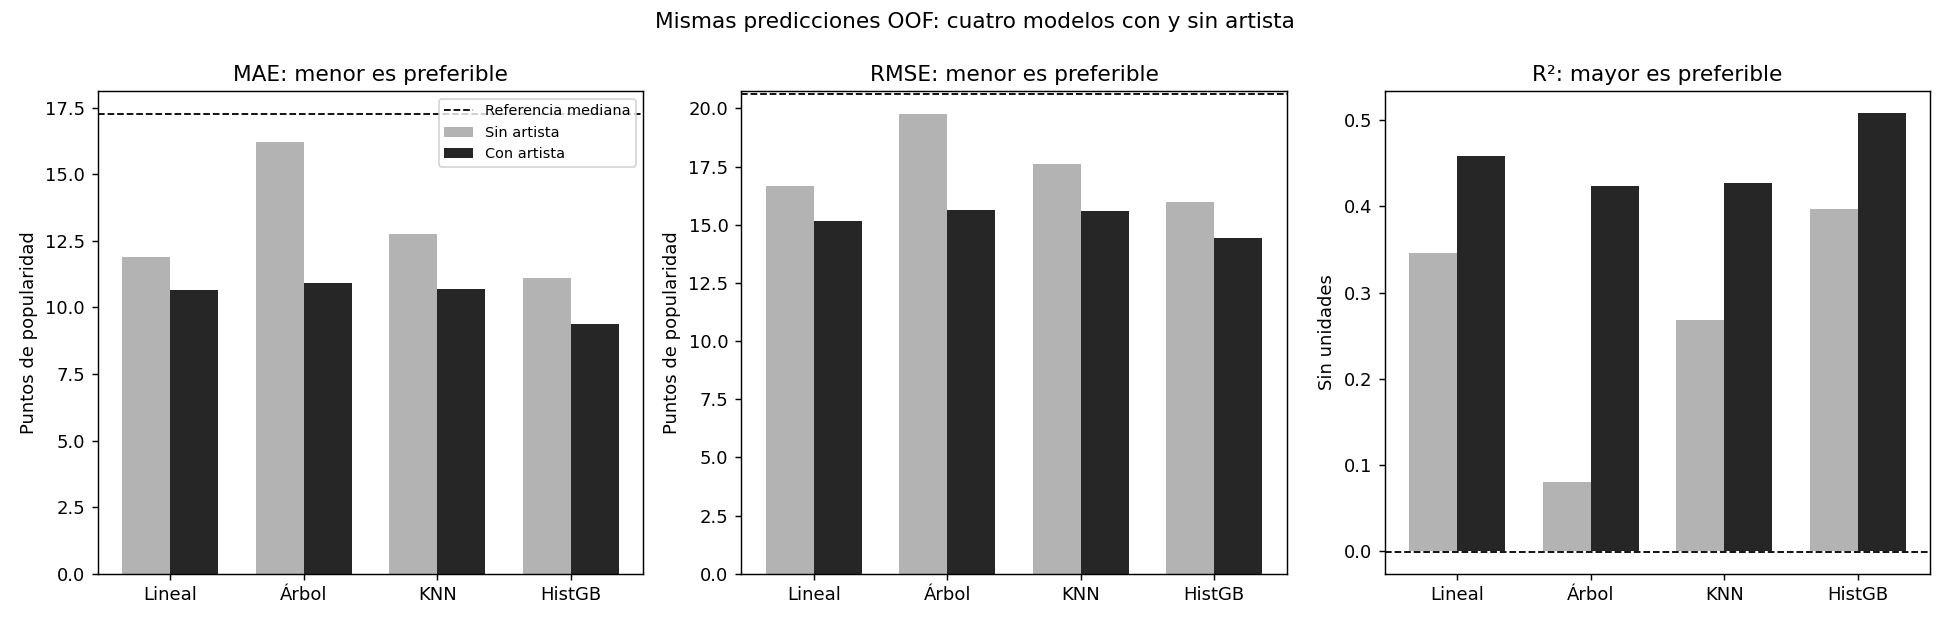

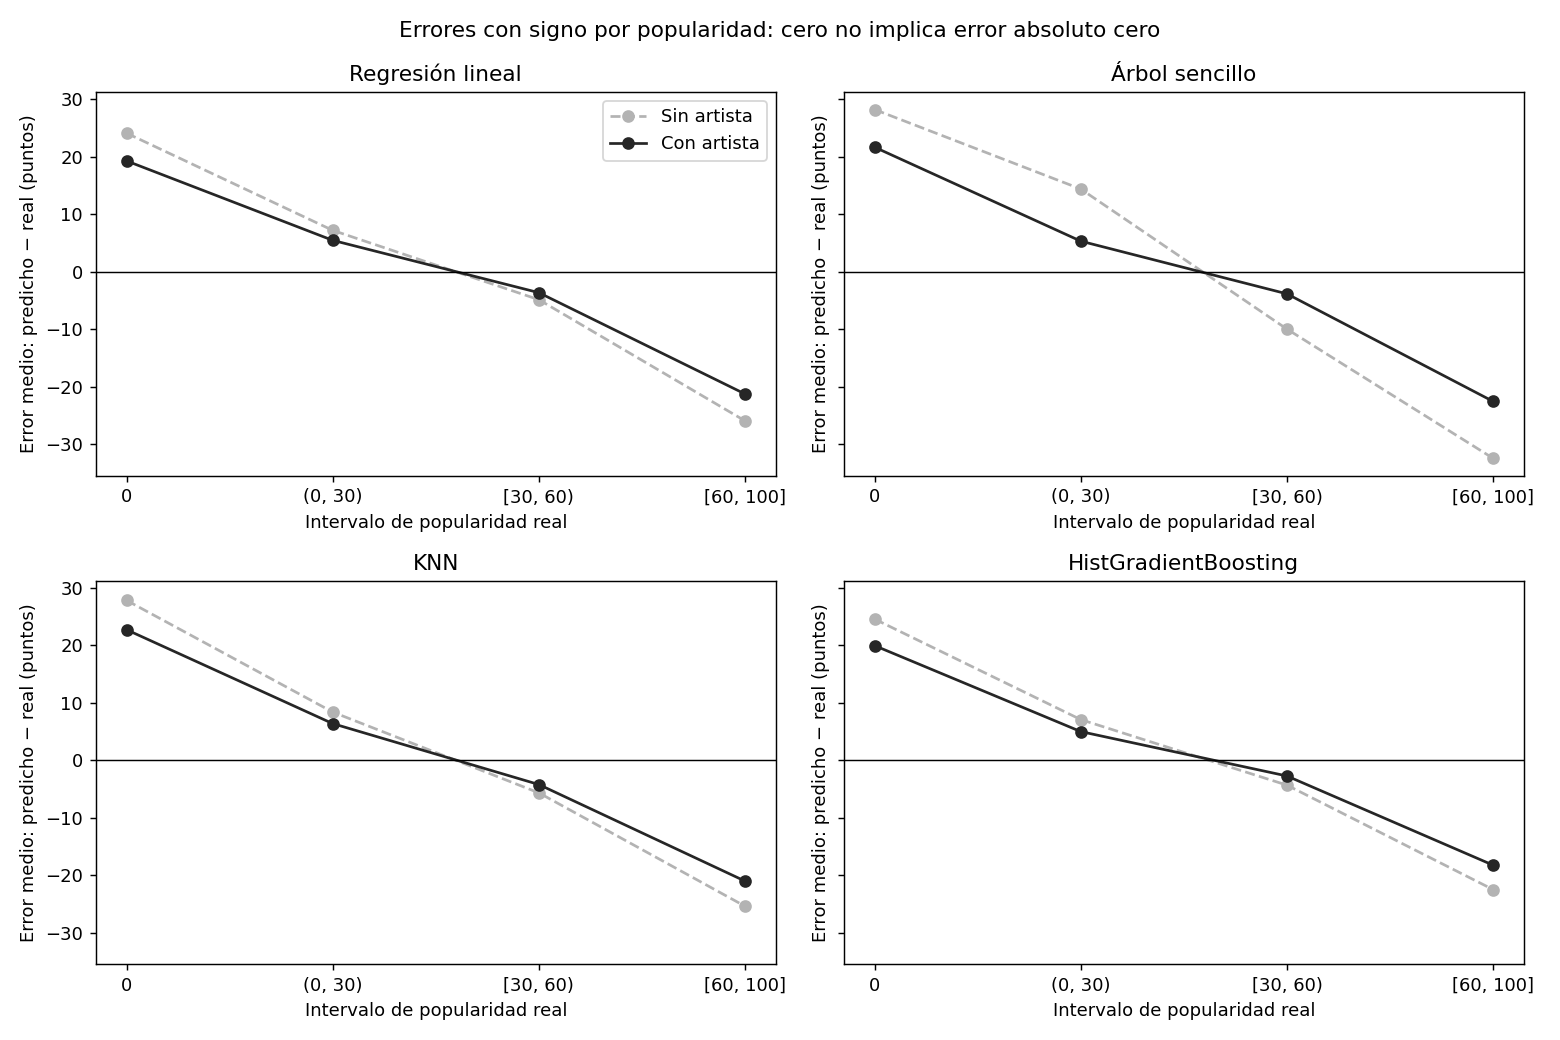

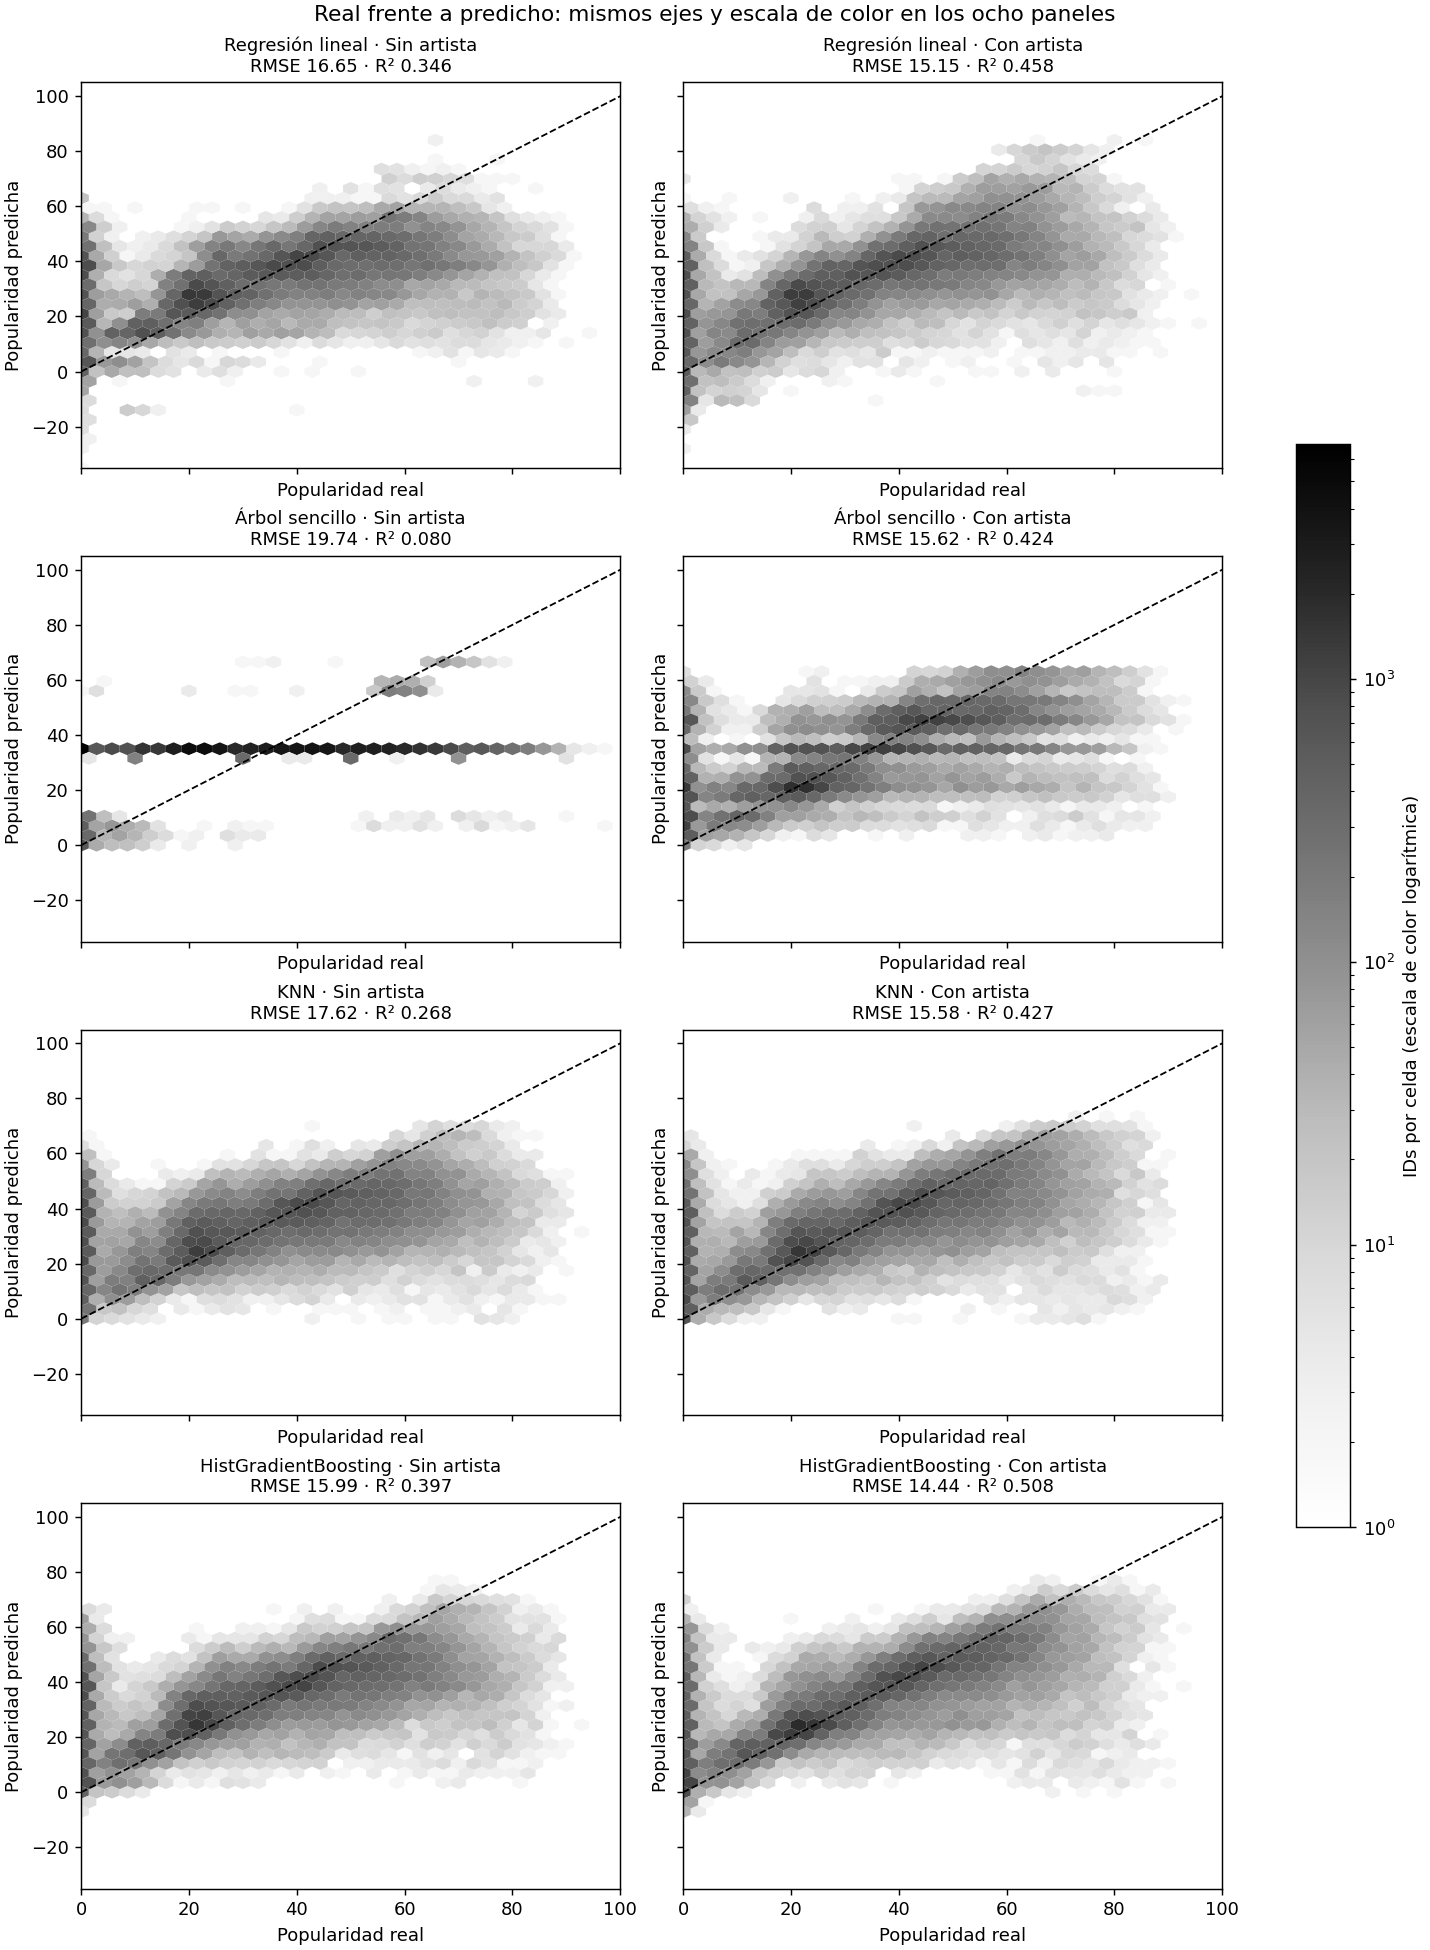

In [21]:
# Figura 1: comparar métricas en unidades separadas
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
orden_modelos = list(predicciones_sin_artista)
colores_escenario = {"Sin artista": "0.70", "Con artista": "0.15"}
fig_metricas, ejes_metricas = plt.subplots(1, 3, figsize=(15, 4.8))
posiciones_modelos = np.arange(len(orden_modelos))
for eje, metrica in zip(ejes_metricas, ["MAE", "RMSE", "R²"]):
    for escenario, desplazamiento in [("Sin artista", -0.18), ("Con artista", 0.18)]:
        valores = [tabla_metricas_oof.loc[(nombre, escenario), metrica] for nombre in orden_modelos]
        eje.bar(posiciones_modelos + desplazamiento, valores, width=0.36, color=colores_escenario[escenario], label=escenario)
    referencia_metrica = tabla_metricas_oof.loc[("Referencia de mediana", "Referencia"), metrica]
    eje.axhline(referencia_metrica, color="black", linestyle="--", linewidth=1, label="Referencia mediana")
    eje.set_xticks(posiciones_modelos, ["Lineal", "Árbol", "KNN", "HistGB"])
    eje.set_ylabel("Puntos de popularidad" if metrica != "R²" else "Sin unidades")
    eje.set_title(metrica + (": menor es preferible" if metrica != "R²" else ": mayor es preferible"))
ejes_metricas[0].legend(fontsize=8)
fig_metricas.suptitle("Mismas predicciones OOF: cuatro modelos con y sin artista")
fig_metricas.tight_layout()
display(fig_metricas)
plt.close(fig_metricas)

# Figura 2: identificar sobreestimación y subestimación por popularidad
fig_sesgo, ejes_sesgo = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for eje, nombre in zip(ejes_sesgo.flat, orden_modelos):
    for escenario in ["Sin artista", "Con artista"]:
        filtro = tabla_errores_grupos["Modelo"].eq(nombre) & tabla_errores_grupos["Escenario"].eq(escenario) & tabla_errores_grupos["Criterio"].eq("Intervalo")
        resumen = tabla_errores_grupos.loc[filtro].set_index("Grupo").reindex(etiquetas_popularidad)
        eje.plot(etiquetas_popularidad, resumen["Error medio con signo"], marker="o", color=colores_escenario[escenario], linestyle="--" if escenario == "Sin artista" else "-", label=escenario)
    eje.axhline(0, color="black", linewidth=0.8)
    eje.set_title(nombre)
    eje.set_xlabel("Intervalo de popularidad real")
    eje.set_ylabel("Error medio: predicho − real (puntos)")
ejes_sesgo[0, 0].legend()
fig_sesgo.suptitle("Errores con signo por popularidad: cero no implica error absoluto cero")
fig_sesgo.tight_layout()
display(fig_sesgo)
plt.close(fig_sesgo)

# Figura 3: todas las canciones, resumidas visualmente en celdas hexagonales
minimo_predicho = min(float(pred.min()) for clave, pred in predicciones_evaluacion.items() if clave[1] != "Referencia")
maximo_predicho = max(float(pred.max()) for clave, pred in predicciones_evaluacion.items() if clave[1] != "Referencia")
limites_prediccion = (min(-5, np.floor(minimo_predicho / 5) * 5), max(105, np.ceil(maximo_predicho / 5) * 5))
fig_real_pred, ejes_real_pred = plt.subplots(4, 2, figsize=(11, 15), sharex=True, sharey=True, constrained_layout=True)
colecciones_hex = []
for fila, nombre in enumerate(orden_modelos):
    for columna, escenario in enumerate(["Sin artista", "Con artista"]):
        eje = ejes_real_pred[fila, columna]
        pred = predicciones_evaluacion[(nombre, escenario)]
        hexagonos = eje.hexbin(y_train.to_numpy(), pred.to_numpy(), gridsize=35, extent=(0, 100, *limites_prediccion), mincnt=1, cmap="Greys", linewidths=0)
        colecciones_hex.append(hexagonos)
        eje.plot([0, 100], [0, 100], color="black", linestyle="--", linewidth=1)
        eje.set_xlim(0, 100)
        eje.set_ylim(*limites_prediccion)
        eje.set_xlabel("Popularidad real")
        eje.set_ylabel("Popularidad predicha")
        metricas_panel = tabla_metricas_oof.loc[(nombre, escenario)]
        eje.set_title(f"{nombre} · {escenario}\nRMSE {metricas_panel['RMSE']:.2f} · R² {metricas_panel['R²']:.3f}", fontsize=10)
maximo_conteo = max(float(coleccion.get_array().max()) for coleccion in colecciones_hex)
normalizacion_conteos = LogNorm(vmin=1, vmax=maximo_conteo)
for coleccion in colecciones_hex:
    coleccion.set_norm(normalizacion_conteos)
fig_real_pred.colorbar(colecciones_hex[0], ax=ejes_real_pred.ravel().tolist(), shrink=0.6, label="IDs por celda (escala de color logarítmica)")
fig_real_pred.suptitle("Real frente a predicho: mismos ejes y escala de color en los ocho paneles")
display(fig_real_pred)
plt.close(fig_real_pred)


### Hallazgos de las métricas y del diagnóstico

- **Sin artista:** el menor MAE corresponde a HistGradientBoosting: MAE 11,0990 puntos, RMSE 15,9904 puntos y R² 0,3967. El menor RMSE corresponde a HistGradientBoosting.
- **Con artista:** el menor MAE corresponde a HistGradientBoosting: MAE 9,3711 puntos, RMSE 14,4388 puntos y R² 0,5081. El menor RMSE corresponde a HistGradientBoosting.
- Para **HistGradientBoosting con artista**, R² 0,5081 equivale a una reducción de aproximadamente 50,81% en suma de errores cuadrados respecto de la constante media de las respuestas evaluadas. No es un porcentaje de canciones acertadas.
- En esa variante, el error medio con signo es 0,6193 puntos; la mediana del error absoluto es 5,3547 y su P90 es 23,8859. El 13,22% de IDs supera 20 puntos de error absoluto. Estos valores describen aspectos diferentes y no son intercambiables.

- Popularidad **0**: 7,499 IDs; MAE 20,1007 y error medio con signo 19,9657 puntos.
- Popularidad **(0, 30)**: 24,805 IDs; MAE 6,5180 y error medio con signo 5,0041 puntos.
- Popularidad **[30, 60)**: 31,563 IDs; MAE 6,7735 y error medio con signo -2,7254 puntos.
- Popularidad **[60, 100]**: 7,861 IDs; MAE 18,5675 y error medio con signo -18,2425 puntos.

Para la misma variante, según disponibilidad del artista:
- **Algunos conocidos**: 7,118 IDs; MAE 10,2110 y RMSE 14,9406 puntos.
- **Ninguno conocido**: 8,348 IDs; MAE 11,3525 y RMSE 15,6640 puntos.
- **Todos conocidos**: 56,262 IDs; MAE 8,9708 y RMSE 14,1825 puntos.

**Cómo leer el alcance:** son resultados internos de desarrollo, calculados con predicciones OOF de las mismas canciones. No se reentrenaron ni cambiaron parámetros para estas métricas. La coincidencia de un ranking en MAE, RMSE o R² se informa como descripción; no demuestra una ventaja estadística ni garantiza el resultado de prueba.

No se eliminan canciones difíciles ni se ajustan umbrales después de inspeccionar errores para presentar mejores números. Las dificultades en los extremos y en artistas sin información se documentan como limitaciones. El error promedio global no sustituye esta revisión por grupos.

**Estado de los KPI:** se conserva la meta inicial de mejora de MAE del 10% frente a mediana y los controles de separación. RMSE, R², P90 y el corte de 20 puntos amplían el diagnóstico; no se presentan como metas aprobadas retrospectivamente. La comprobación en prueba permanece pendiente.


### Elección del procedimiento en desarrollo, antes de evaluar prueba

**Criterio principal conservado:** escoger la variante con menor **MAE OOF**, entre los cuatro modelos con y sin artista y sobre las mismas canciones. RMSE, R², errores por grupos y complejidad aportan contexto; no se cambia el criterio después de ver sus valores. La referencia de mediana no compite como uno de los cuatro modelos, pero permite medir si hay mejora útil respecto de una predicción sencilla.

La elección provisional es **HistGradientBoosting con artista**, con MAE **9,3711 puntos**. Su RMSE es **14,4388** y R² **0,5081**. En estas mismas observaciones, MAE y RMSE menores son preferibles; R² mayor es preferible. La coincidencia de las métricas respalda la elección descriptiva, sin demostrar superioridad estadística.

**Justificación de las decisiones:**

- Se mantienen las mismas particiones agrupadas y una predicción OOF por ID. No elegimos otro reparto de canciones ni una ronda particularmente favorable.
- Se añade artista porque su variante reduce el MAE respecto del mismo modelo sin artista en **1,7280 puntos**. El mapa se calcula con exclusión de la propia clave en ajuste y solo con ajuste para validación. Usar esta información exige disponer de respuestas de otras canciones permitidas; no es evidencia de predicción temporal de lanzamientos.
- Frente a la regresión lineal con artista, el procedimiento elegido reduce MAE en **1,2873 puntos**. Se conserva el modelo lineal como alternativa más sencilla de explicar; no se mide aquí una ventaja de tiempo o de costo operativo.
- Se acepta la mayor complejidad del ensamble a cambio del menor error observado. Los 600 pasos, tasa 0,03 y máximo de 63 hojas permanecen como configuración fija de referencia, sin búsqueda nueva ni selección de etapas por validación.
- Se mantienen canciones difíciles y predicciones fuera de rango sin recortes posteriores. El análisis muestra dificultades en popularidad cero, éxitos y artistas desconocidos; un buen promedio no las resuelve.

**Qué significa «provisional»:** elegimos un procedimiento (preparación + codificación del artista + configuración del modelo), no un archivo ya listo para uso final. Los tres modelos ajustados por ronda sirven para validar; no se escoge el de la ronda con menor error como modelo final. Todavía no se ha ajustado una versión única con todo el entrenamiento ni se ha verificado su desempeño en prueba.

La misma validación se ha utilizado para comparar variantes y guiar el desarrollo; su mejor resultado puede ser optimista. Además, la unidad 1 exploró la fuente completa. El resultado debe describirse como evidencia interna de desarrollo, no como una evaluación externa completamente ciega.

**Lectura del código:**

1. `.reset_index()` convierte modelo y escenario en columnas. `.isin` conserva solo variantes con o sin artista, excluyendo la referencia.
2. `.sort_values("MAE", kind="stable")` ordena por el criterio principal sin alterar métricas. `.iloc[0]` recupera la variante de menor MAE. Si hubiera un empate exacto, habría que explicitar una decisión adicional; aquí no lo hay.
3. La fila de mediana proporciona la referencia ya calculada. Se comprueba que su MAE es positivo antes de dividir.
4. La reducción absoluta resta MAE modelo a MAE referencia; la mejora relativa divide esa reducción por el MAE referencia y multiplica por cien.
5. `mejora_objetivo` conserva el 10% del bloque 4. Multiplicar la referencia por `1 − mejora_objetivo` obtiene el MAE máximo compatible con esa meta en esta validación.
6. `get_params()` recupera la configuración de la plantilla del estimador elegido. No llama a `.fit`, `.predict` ni modifica sus parámetros. `especificacion_provisional` deja identificados modelo, escenario, preparación y alcance.
7. `display` muestra el ranking y la justificación numérica. Los cálculos usan precisión completa; `.round(4)` solo facilita leer las tablas.


In [22]:
# Ordenar las ocho variantes por el criterio principal previamente fijado
candidatos_provisionales = tabla_metricas_oof.reset_index()
candidatos_provisionales = candidatos_provisionales.loc[candidatos_provisionales["Escenario"].isin(["Sin artista", "Con artista"])].copy()
ranking_provisional = candidatos_provisionales.sort_values("MAE", kind="stable").reset_index(drop=True)
assert len(ranking_provisional) == 8
assert ranking_provisional["IDs"].eq(len(y_train)).all()
eleccion_provisional = ranking_provisional.iloc[0].copy()
nombre_elegido = eleccion_provisional["Modelo"]
escenario_elegido = eleccion_provisional["Escenario"]
mae_elegido = float(eleccion_provisional["MAE"])

# Mantener la misma referencia y meta, sin incorporar respuestas de prueba
mae_referencia_cierre = float(tabla_metricas_oof.loc[("Referencia de mediana", "Referencia"), "MAE"])
if mae_referencia_cierre <= 0:
    raise ValueError("La mejora relativa requiere un MAE de referencia positivo.")
reduccion_absoluta_elegido = mae_referencia_cierre - mae_elegido
mejora_relativa_elegido = reduccion_absoluta_elegido / mae_referencia_cierre * 100
mae_limite_cierre = mae_referencia_cierre * (1 - mejora_objetivo)
cumple_meta_validacion = mejora_relativa_elegido >= mejora_objetivo * 100

# Registrar un procedimiento, sin reentrenar ni escoger un modelo de una ronda
parametros_estimador_elegido = plantillas_artista[nombre_elegido].named_steps["regresion"].get_params()
especificacion_provisional = {
    "Modelo": nombre_elegido,
    "Escenario": escenario_elegido,
    "Criterio principal": "Menor MAE OOF de entrenamiento",
    "Particiones externas": numero_pliegues,
    "Preparación": "Pipeline correspondiente al modelo; parámetros aprendidos solo en ajuste",
    "Artista": "Suavizado 10, cinco particiones internas agrupadas y media de colaboradores" if escenario_elegido == "Con artista" else "No utilizado como predictor",
    "Configuración del estimador": parametros_estimador_elegido,
    "Alcance": "Elección provisional; evaluación final pendiente"
}
resumen_eleccion = pd.Series({"MAE referencia OOF": mae_referencia_cierre, "MAE elegido OOF": mae_elegido, "Reducción absoluta (puntos)": reduccion_absoluta_elegido, "Mejora relativa (%)": mejora_relativa_elegido, "Meta inicial (%)": mejora_objetivo * 100, "MAE máximo para cumplir meta": mae_limite_cierre, "Cumple meta en validación": cumple_meta_validacion})
display(ranking_provisional[["Modelo", "Escenario", "IDs", "MAE", "RMSE", "R²"]].round(4))
display(resumen_eleccion)
display(pd.Series(especificacion_provisional))


,Modelo,Escenario,IDs,MAE,RMSE,R²
0,HistGradientBoosting,Con artista,71728,9.3711,14.4388,0.5081
1,Regresión lineal,Con artista,71728,10.6583,15.1516,0.4584
2,KNN,Con artista,71728,10.6813,15.5815,0.4272
3,Árbol sencillo,Con artista,71728,10.9302,15.6250,0.4240
4,HistGradientBoosting,Sin artista,71728,11.0990,15.9904,0.3967
5,Regresión lineal,Sin artista,71728,11.8942,16.6482,0.3461
6,KNN,Sin artista,71728,12.7768,17.6174,0.2677
7,Árbol sencillo,Sin artista,71728,16.2101,19.7428,0.0804


MAE referencia OOF              17.251826
MAE elegido OOF                   9.37105
Reducción absoluta (puntos)      7.880776
Mejora relativa (%)             45.680822
Meta inicial (%)                     10.0
MAE máximo para cumplir meta    15.526644
Cumple meta en validación            True
dtype: object

Modelo                                                      HistGradientBoosting
Escenario                                                            Con artista
Criterio principal                                Menor MAE OOF de entrenamiento
Particiones externas                                                           3
Preparación                    Pipeline correspondiente al modelo; parámetros...
Artista                        Suavizado 10, cinco particiones internas agrup...
Configuración del estimador    {'categorical_features': None, 'early_stopping...
Alcance                         Elección provisional; evaluación final pendiente
dtype: object

### Cierre de KPI de desarrollo: estado anterior a evaluar prueba

Se reúnen **los cuatro indicadores definidos al inicio**. No se añaden metas retrospectivas de RMSE, R² o errores por grupos. Cumplir los controles de separación significa que el reparto satisface esas reglas; no garantiza que todas las posibles fuentes de fuga hayan sido eliminadas.

| Indicador original | Cómo se calcula | Qué significa cumplirlo |
|---|---|---|
| IDs compartidos | Cantidad de IDs presentes simultáneamente en entrenamiento y prueba, calculada al separar | El mismo ID no aparece a ambos lados |
| Claves compartidas | Cantidad de claves artista + título presentes en ambos conjuntos | Las versiones identificadas por esa clave permanecen juntas; no separa artistas completos ni detecta toda reedición posible |
| Cobertura | IDs distintos asignados / IDs de la base preparada × 100, acompañada de controles de unicidad y suma de filas | Todos los IDs se asignaron sin pérdidas, adiciones o duplicaciones entre conjuntos |
| Mejora de MAE | `(MAE mediana OOF − MAE elegido OOF) / MAE mediana OOF × 100` | La variante reduce al menos el 10% del error medio de la referencia **dentro de entrenamiento** |

Los tres primeros indicadores reutilizan **los controles estructurales del reparto ya calculados**, sin consultar respuestas de prueba ni producir predicciones para ese conjunto. El indicador predictivo utiliza únicamente OOF.

**Lectura del código:**

1. `comprobaciones_particion` aporta conteos y cobertura del bloque 3. `int` y `float` permiten presentar tipos numéricos sencillos; no cambian el indicador.
2. `cobertura_correcta` verifica 100% junto con unicidad, igualdad de IDs y suma de filas. Una cobertura de 100% por sí sola no bastaría para descartar duplicaciones.
3. La lista de diccionarios construye una fila por KPI con meta, resultado, unidad, cumplimiento, alcance y evidencia. `pd.DataFrame` la convierte en una tabla.
4. La columna `Cumple en su alcance` contiene verdaderos o falsos, no un promedio de calidad del modelo. No se mezclan los cuatro indicadores para crear una nota o un porcentaje de cumplimiento global.
5. `controles_cierre` comprueba consistencia de validación, cobertura OOF, igualdad de referencia y meta. `raise` detiene el cierre si algo no coincide; un resultado predictivo que no alcanzara el KPI se informaría como tal, no se ocultaría.
6. La Serie final registra **«Pendiente: no evaluada»** para prueba. No copia el MAE OOF como si fuera un resultado de test.

**Resultado del cierre:** la mejora es **45,68%**, equivalente a reducir el MAE en **7,8808 puntos**. La meta del 10% exigía MAE como máximo **15,5266** en esta validación; la variante elegida obtiene **9,3711**. Esto cumple la meta inicial de desarrollo, que sigue siendo una meta académica de trabajo y no una exigencia de rúbrica confirmada.

**Lo pendiente:** cuando corresponda la evaluación final, se fijará el procedimiento, se ajustará una versión con todo el entrenamiento y se evaluará una sola vez en prueba junto a una mediana aprendida con todo ese entrenamiento. Las referencias y métricas de esa etapa se calcularán para dicha etapa; no se reutilizará el 17,2518 OOF como si fuera el MAE de referencia en test. No se ejecuta ninguno de esos pasos ahora.


In [23]:
# Reutilizar controles estructurales existentes, sin volver a consultar prueba
ids_repetidos_cierre = int(comprobaciones_particion["IDs compartidos"])
claves_repetidas_cierre = int(comprobaciones_particion["Claves compartidas"])
cobertura_cierre = float(comprobaciones_particion["Cobertura de IDs (%)"])
cobertura_correcta = bool(np.isclose(cobertura_cierre, 100) and comprobaciones_particion["IDs únicos en cada conjunto"] and comprobaciones_particion["Todos los IDs asignados sin adiciones"] and comprobaciones_particion["Suma de filas coincide con base"])

# Reunir los cuatro KPI originales con sus metas, alcance y evidencia
tabla_cierre_kpi_u2 = pd.DataFrame([
    {"KPI": "IDs compartidos", "Meta": "0", "Resultado": ids_repetidos_cierre, "Unidad": "IDs", "Cumple en su alcance": ids_repetidos_cierre == 0, "Alcance": "Control estructural de partición", "Evidencia": "comprobaciones_particion: intersección de IDs"},
    {"KPI": "Claves compartidas", "Meta": "0", "Resultado": claves_repetidas_cierre, "Unidad": "Claves artista + título", "Cumple en su alcance": claves_repetidas_cierre == 0, "Alcance": "Control estructural de partición", "Evidencia": "comprobaciones_particion: intersección de claves"},
    {"KPI": "Cobertura de IDs preparados", "Meta": "100% y asignación sin duplicaciones", "Resultado": cobertura_cierre, "Unidad": "%", "Cumple en su alcance": cobertura_correcta, "Alcance": "Control estructural de partición", "Evidencia": "Cobertura, unicidad, conjunto de IDs y suma de filas"},
    {"KPI": "Mejora de MAE frente a mediana", "Meta": f">= {mejora_objetivo * 100:.0f}%", "Resultado": mejora_relativa_elegido, "Unidad": "% de reducción de MAE", "Cumple en su alcance": bool(cumple_meta_validacion), "Alcance": "Solo validación OOF dentro de entrenamiento", "Evidencia": "tabla_metricas_oof y resumen_eleccion"}
]).set_index("KPI")

# Verificar consistencia del cierre, sin cambiar metas por el resultado
controles_cierre = pd.Series({
    "Controles de validación agrupada correctos": controles_validacion.all(),
    "Controles de referencia OOF correctos": controles_oof.all(),
    "Todas las variantes evaluaron los mismos IDs": tabla_metricas_oof["IDs"].eq(len(y_train)).all(),
    "Referencia coincide con la ya calculada": np.isclose(mae_referencia_cierre, mae_referencia_oof),
    "Se conserva la meta inicial del 10%": np.isclose(mejora_objetivo, 0.10),
    "Regla porcentual equivale al límite de MAE": bool(cumple_meta_validacion) == bool(mae_elegido <= mae_limite_cierre)
})
if not controles_cierre.all():
    raise ValueError("Revisar la consistencia de la evaluación antes de cerrar los KPI.")
estado_evaluacion_final = pd.Series({"Elección del procedimiento": "Provisional, basada en OOF", "KPI predictivo en validación": "Cumple" if cumple_meta_validacion else "No cumple", "Evaluación final en prueba": "Pendiente: no evaluada", "Modelo único ajustado con todo entrenamiento": "Pendiente"})
display(tabla_cierre_kpi_u2.round({"Resultado": 4}))
display(controles_cierre)
display(estado_evaluacion_final)


,Meta,Resultado,Unidad,Cumple en su alcance,Alcance,Evidencia
KPI,,,,,,
IDs compartidos,0,0.0000,IDs,True,Control estructural de partición,comprobaciones_particion: intersección de IDs
Claves compartidas,0,0.0000,Claves artista + título,True,Control estructural de partición,comprobaciones_particion: intersección de claves
Cobertura de IDs preparados,100% y asignación sin duplicaciones,100.0000,%,True,Control estructural de partición,"Cobertura, unicidad, conjunto de IDs y suma de..."
Mejora de MAE frente a mediana,>= 10%,45.6808,% de reducción de MAE,True,Solo validación OOF dentro de entrenamiento,tabla_metricas_oof y resumen_eleccion


Controles de validación agrupada correctos      True
Controles de referencia OOF correctos           True
Todas las variantes evaluaron los mismos IDs    True
Referencia coincide con la ya calculada         True
Se conserva la meta inicial del 10%             True
Regla porcentual equivale al límite de MAE      True
dtype: bool

Elección del procedimiento                      Provisional, basada en OOF
KPI predictivo en validación                                        Cumple
Evaluación final en prueba                          Pendiente: no evaluada
Modelo único ajustado con todo entrenamiento                     Pendiente
dtype: object

### Síntesis al terminar validación, antes de abrir test

Se elige provisionalmente **HistGradientBoosting con artista** porque obtiene el menor MAE de las ocho variantes comparadas, **9,3711 puntos**. RMSE **14,4388** y R² **0,5081** complementan el resultado. Frente a la mediana OOF, la reducción de MAE es **45,68%**, por encima de la meta inicial de 10%.

Los controles estructurales reportan **0 IDs compartidos, 0 claves compartidas y 100% de cobertura**, con verificaciones de unicidad y asignación. El cumplimiento predictivo corresponde **solo a validación dentro del entrenamiento**. La tabla de KPI muestra evidencia y alcance para no confundir ambas cosas.

La elección tiene límites prácticos: el ensamble es más complejo de interpretar que la regresión lineal; la variable de artista requiere respuestas de otras canciones permitidas; los artistas desconocidos tienen menos información y persisten errores importantes en los extremos de popularidad. Para la variante elegida, el MAE cuando no conoce a ningún artista es **11,3525 puntos**, frente a **8,9708** cuando conoce a todos. Esta diferencia es descriptiva, no un efecto causal ni un resultado de una separación por artistas completos.

No se considera terminado todo el contenido de unidad 2 por cerrar esta etapa de regresión. Clasificación y aprendizaje no supervisado requieren preguntas propias y un alcance acorde con la pauta cuando esté disponible. La conexión con boosting pertenece también al recorrido de ensambles de unidad 3.

**Estado final de esta etapa:** procedimiento elegido provisionalmente y KPI de desarrollo documentados. La prueba permanece reservada, sin predicciones ni métricas de evaluación; el ajuste de una versión única y la verificación final quedan pendientes. No se cambia esa decisión ni se presenta una nota final sin esa evidencia.


El estado anterior documenta el cierre del desarrollo. A continuación se fija ese procedimiento y se realiza la evaluación final en prueba.


### Evaluación final en prueba: fijar el procedimiento y ajustar con todo el entrenamiento

**Momento de abrir test:** la elección ya se realizó mediante validación OOF. Se evalúa solamente **HistGradientBoosting con artista** frente a una mediana de referencia. No se comparan ahora los otros modelos ni se modifican parámetros, variables, reglas de artista o límites de predicción según el resultado de prueba.

**Procedimiento fijado:** tasa 0,03; 600 etapas; máximo de 63 hojas por árbol; mínimo de 20 IDs por hoja; error cuadrático como función de entrenamiento; sin parada temprana; semilla 42. El artista conserva suavizado 10, cinco particiones internas agrupadas y media entre colaboradores. Se mantiene la preparación numérica, categórica y Multi-Hot, con matriz densa. La versión de scikit-learn verificada es 1.6.1.

Ahora se usan **todos los 71.728 IDs de entrenamiento** para ajustar una única versión del modelo. Los modelos de las tres rondas anteriores no se promedian ni se selecciona el de mejor ronda.

**Cómo se evita fuga al preparar el artista:**

1. Para las filas de entrenamiento se construyen codificaciones cruzadas con cinco grupos internos de claves. Cada fila recibe un valor calculado sin sus propias respuestas ni las versiones de su clave.
2. Por separado se aprende un mapa con todo el entrenamiento para transformar test. Las respuestas de test no entran en ese mapa ni en la media de respaldo.
3. Se recuperan los artistas de test desde la parte de artista de la clave. El título solo conserva su función de agrupación y no entra como predictor. Un artista desconocido recibe la media del entrenamiento; las colaboraciones conservan la media de sus artistas.
4. La preparación del pipeline aprende medianas, escalas y categorías con las filas de entrenamiento. Test solo se transforma y se predice. Usar un nombre de artista para consultar un mapa permitido no utiliza su respuesta de test.

**Lectura del código, paso a paso:**

- `assert` comprueba la elección ya fijada y recupera los parámetros de su plantilla. `decision_final_fijada` registra el procedimiento antes de calcular métricas de prueba.
- `codificar_ajuste_cruzado` reutiliza la regla agrupada para el entrenamiento completo; `ajustar_mapa_artistas` crea el mapa permitido y su media. Ninguna función recibe `y_test`.
- `.copy()` conserva las matrices anteriores; añadir `historial_artista` crea la misma característica que se evaluó antes.
- La mediana de referencia se aprende solo con `y_train`. `pd.Series` la repite para cada ID de test; no es la media de test ni el MAE OOF de mediana anterior.
- `clone` crea un pipeline limpio. Se añade la nueva característica a la selección del bloque numérico, igual que en validación, sin cambiar el estimador.
- `.fit(X_entrenamiento_final, y_train)` realiza el ajuste único. `.predict(X_prueba_final)` genera las predicciones finales para los 18.012 IDs, sin recibir respuestas de prueba. No se recortan salidas a 0–100.
- Se comprueban parámetros, las 600 etapas, filas vistas por el escalador, medianas de imputación y media de la característica del artista. Estos controles verifican reglas concretas de preparación, no demuestran ausencia de cualquier fuga imaginable.
- La cobertura de artistas describe qué fracción de test tiene información permitida de todos, algunos o ninguno de sus artistas. No se usa para cambiar el modelo.

La variable se llama «historial» por continuidad, pero faltan fechas para verificar que las otras canciones fueran anteriores. Es información de popularidad disponible en esta partición, no una simulación temporal de lanzamientos futuros.


In [24]:
# Registrar la decisión antes de evaluar las respuestas de prueba
assert nombre_elegido == "HistGradientBoosting" and escenario_elegido == "Con artista"
parametros_finales_fijados = modelo_hgb_base.named_steps["regresion"].get_params().copy()
assert parametros_finales_fijados == parametros_estimador_elegido
assert parametros_finales_fijados["max_iter"] == 600 and parametros_finales_fijados["early_stopping"] is False
assert np.isclose(suavizado_artista, 10.0)
decision_final_fijada = {"Modelo": nombre_elegido, "Escenario": escenario_elegido, "Criterio de elección": "MAE OOF de entrenamiento", "Parámetros": parametros_finales_fijados, "Suavizado artista": suavizado_artista, "Particiones internas del artista": 5, "Colaboraciones": "Media", "Recorte de predicciones": False}

# Preparar el artista sin respuestas de test
codigo_artista_entrenamiento_final = codificar_ajuste_cruzado(artistas_entrenamiento, y_train, claves_artista, suavizado_artista)
mapa_artista_final, media_artista_final = ajustar_mapa_artistas(artistas_entrenamiento, y_train, suavizado_artista)
artistas_prueba_final = recuperar_artistas(datos_prueba["clave_cancion"])
if artistas_prueba_final.map(len).eq(0).any():
    raise ValueError("Revisar artistas faltantes antes de transformar prueba.")
codigo_artista_prueba_final = aplicar_mapa_artistas(artistas_prueba_final, mapa_artista_final, media_artista_final)
X_entrenamiento_final = X_train.copy()
X_prueba_final = X_test.copy()
X_entrenamiento_final["historial_artista"] = codigo_artista_entrenamiento_final
X_prueba_final["historial_artista"] = codigo_artista_prueba_final
assert X_entrenamiento_final.columns.equals(X_prueba_final.columns)
assert X_entrenamiento_final.index.intersection(X_prueba_final.index).empty
assert set(claves_artista).isdisjoint(set(datos_prueba["clave_cancion"]))

# Aprender la mediana de referencia solo con entrenamiento
mediana_entrenamiento_final = float(y_train.median())
predicciones_mediana_test = pd.Series(mediana_entrenamiento_final, index=X_prueba_final.index, name="mediana_test")

# Ajustar un solo modelo final con el mismo procedimiento ya elegido
modelo_final_hgb_artista = clone(modelo_hgb_base)
preparador_final = modelo_final_hgb_artista.named_steps["preparar"]
preparador_final.transformers = [(bloque, transformacion, columnas_numericas_modelo + ["historial_artista"] if bloque == "numericas" else columnas) for bloque, transformacion, columnas in preparador_final.transformers]
modelo_final_hgb_artista.fit(X_entrenamiento_final, y_train)
predicciones_hgb_test = pd.Series(modelo_final_hgb_artista.predict(X_prueba_final), index=X_prueba_final.index, name="histgradientboosting_test")

# Verificar la preparación y cobertura antes de interpretar errores
numericas_finales = modelo_final_hgb_artista.named_steps["preparar"].named_transformers_["numericas"]
assert int(numericas_finales.named_steps["escalar"].n_samples_seen_) == len(y_train)
assert np.allclose(numericas_finales.named_steps["imputar"].statistics_, X_entrenamiento_final[columnas_numericas_modelo + ["historial_artista"]].median())
assert np.isclose(numericas_finales.named_steps["escalar"].mean_[-1], codigo_artista_entrenamiento_final.mean())
assert modelo_final_hgb_artista.named_steps["regresion"].get_params() == parametros_finales_fijados
assert modelo_final_hgb_artista.named_steps["regresion"].n_iter_ == 600
assert predicciones_hgb_test.index.equals(X_prueba_final.index) and np.isfinite(predicciones_hgb_test).all()
cantidad_artistas_conocidos_test = artistas_prueba_final.map(lambda nombres: sum(a in mapa_artista_final for a in nombres))
estado_artista_test = pd.Series(np.select([cantidad_artistas_conocidos_test.eq(0), cantidad_artistas_conocidos_test.eq(artistas_prueba_final.map(len))], ["Ninguno conocido", "Todos conocidos"], default="Algunos conocidos"), index=X_prueba_final.index)
display(pd.Series(decision_final_fijada))
display(pd.Series({"IDs usados para ajuste final": len(y_train), "IDs predichos en prueba": len(predicciones_hgb_test), "Mediana aprendida en entrenamiento": mediana_entrenamiento_final, "Media de respaldo para artista desconocido": media_artista_final, "Etapas del ensamble": modelo_final_hgb_artista.named_steps["regresion"].n_iter_}))
display(estado_artista_test.value_counts().rename("IDs de prueba por información del artista"))


Modelo                                                           HistGradientBoosting
Escenario                                                                 Con artista
Criterio de elección                                         MAE OOF de entrenamiento
Parámetros                          {'categorical_features': None, 'early_stopping...
Suavizado artista                                                                10.0
Particiones internas del artista                                                    5
Colaboraciones                                                                  Media
Recorte de predicciones                                                         False
dtype: object

IDs usados para ajuste final                  71728.000000
IDs predichos en prueba                       18012.000000
Mediana aprendida en entrenamiento               33.000000
Media de respaldo para artista desconocido       33.236045
Etapas del ensamble                             600.000000
dtype: float64

Todos conocidos      15015
Algunos conocidos     1523
Ninguno conocido      1474
Name: IDs de prueba por información del artista, dtype: int64

### Evaluación en test: comparar con la mediana y contextualizar frente a validación

**Solo ahora se comparan las predicciones finales con `y_test`.** No se usa `y_test` en `.fit`, mapas de artista, imputación, escalamiento ni elección de parámetros.

**Lectura del código:**

1. Las métricas se calculan para dos predicciones sobre los mismos IDs: mediana de entrenamiento e HistGradientBoosting con artista. `assert` comprueba alineación y valores finitos. `mean_absolute_error`, `root_mean_squared_error` y `r2_score` conservan las definiciones ya explicadas.
2. La mejora relativa en test se calcula con el **MAE de la mediana en test**: `(MAE mediana test − MAE modelo test) / MAE mediana test × 100`. No se utiliza el 17,2518 de la referencia OOF como denominador.
3. `comparacion_desarrollo_test` muestra ambos escenarios de evaluación. El modelo final se ajustó con más datos que cada modelo de las rondas OOF; no son exactamente el mismo ajuste ni las mismas canciones. La diferencia test menos OOF se informa, sin buscar parámetros que la reduzcan.
4. La tabla de ejemplos conserva los primeros cinco IDs de test, sin elegir aciertos. La convención del error es predicho menos real. La media con signo puede cancelar errores; no reemplaza MAE ni RMSE.
5. Se muestran percentil 90, proporción con más de 20 puntos de error y salidas fuera de escala, sin modificar predicciones. `groupby` describe MAE según artistas conocidos, sin seleccionar otro modelo para cada grupo.

**Interpretación:** MAE y RMSE se expresan en puntos de popularidad, no en porcentajes de error. RMSE da mayor peso a errores grandes. R² compara suma de errores cuadrados con la constante media de las respuestas evaluadas, no con la mediana operativa. Su cálculo utiliza `y_test` para evaluar, no para entrenar una constante disponible de antemano. El R² de la mediana puede ser ligeramente negativo.

Una diferencia pequeña entre desarrollo y prueba es compatible con desempeño similar en este reparto, pero no demuestra que no haya sobreajuste ni fuga. Tampoco vuelve esta muestra una prueba externa ciega: la fuente ya se exploró en unidad 1 y se tomó una configuración de un proyecto previo sobre ella.


In [25]:
# Evaluar una vez las dos predicciones finales en las mismas respuestas de test
registros_test_final = []
for procedimiento, pred in {"Mediana de entrenamiento": predicciones_mediana_test, "HistGradientBoosting con artista": predicciones_hgb_test}.items():
    assert pred.index.equals(y_test.index) and np.isfinite(pred).all()
    registros_test_final.append({"Procedimiento": procedimiento, "IDs test": len(y_test), "MAE": mean_absolute_error(y_test, pred), "RMSE": root_mean_squared_error(y_test, pred), "R²": r2_score(y_test, pred)})
tabla_evaluacion_test = pd.DataFrame(registros_test_final).set_index("Procedimiento")
mae_mediana_test = float(tabla_evaluacion_test.loc["Mediana de entrenamiento", "MAE"])
mae_hgb_test = float(tabla_evaluacion_test.loc["HistGradientBoosting con artista", "MAE"])
if mae_mediana_test <= 0:
    raise ValueError("La mejora relativa requiere un MAE de referencia positivo.")
reduccion_mae_test = mae_mediana_test - mae_hgb_test
mejora_mae_test = reduccion_mae_test / mae_mediana_test * 100
limite_mae_test = mae_mediana_test * (1 - mejora_objetivo)

# Distinguir desempeño de desarrollo y prueba, sin modificar el procedimiento
comparacion_desarrollo_test = pd.DataFrame([
    {"Evaluación": "Validación OOF de entrenamiento", "IDs evaluados": len(y_train), "MAE modelo": float(eleccion_provisional["MAE"]), "RMSE modelo": float(eleccion_provisional["RMSE"]), "R² modelo": float(eleccion_provisional["R²"]), "MAE referencia propia": mae_referencia_cierre, "Mejora vs referencia propia (%)": mejora_relativa_elegido},
    {"Evaluación": "Prueba del modelo final", "IDs evaluados": len(y_test), "MAE modelo": mae_hgb_test, "RMSE modelo": float(tabla_evaluacion_test.loc["HistGradientBoosting con artista", "RMSE"]), "R² modelo": float(tabla_evaluacion_test.loc["HistGradientBoosting con artista", "R²"]), "MAE referencia propia": mae_mediana_test, "Mejora vs referencia propia (%)": mejora_mae_test}
]).set_index("Evaluación")

# Revisar ejemplos y límites sin recortar ni corregir el resultado
revision_test_final = pd.DataFrame({"Real": y_test, "Mediana": predicciones_mediana_test, "HistGradientBoosting": predicciones_hgb_test, "Estado artista": estado_artista_test})
revision_test_final["Error con signo"] = revision_test_final["HistGradientBoosting"] - revision_test_final["Real"]
revision_test_final["Error absoluto"] = revision_test_final["Error con signo"].abs()
diagnostico_test_final = pd.Series({"Error medio con signo (puntos)": revision_test_final["Error con signo"].mean(), "P90 del error absoluto (puntos)": revision_test_final["Error absoluto"].quantile(0.90), "Error absoluto >20 puntos (%)": revision_test_final["Error absoluto"].gt(20).mean() * 100, "Predicciones menores que 0": int(predicciones_hgb_test.lt(0).sum()), "Predicciones mayores que 100": int(predicciones_hgb_test.gt(100).sum()), "MAE test menos MAE OOF (puntos)": mae_hgb_test - float(eleccion_provisional["MAE"])})
error_por_artista_test = revision_test_final.groupby("Estado artista").agg(IDs=("Real", "size"), MAE=("Error absoluto", "mean"), error_medio=("Error con signo", "mean"))
display(tabla_evaluacion_test.round(4))
display(comparacion_desarrollo_test.round(4))
display(revision_test_final.head(5).round(4))
display(diagnostico_test_final.round(4))
display(error_por_artista_test.round(4))


,IDs test,MAE,RMSE,R²
Procedimiento,,,,
Mediana de entrenamiento,18012,17.1629,20.5370,-0.0000
HistGradientBoosting con artista,18012,9.1251,14.1016,0.5285


,IDs evaluados,MAE modelo,RMSE modelo,R² modelo,MAE referencia propia,Mejora vs referencia propia (%)
Evaluación,,,,,,
Validación OOF de entrenamiento,71728,9.3711,14.4388,0.5081,17.2518,45.6808
Prueba del modelo final,18012,9.1251,14.1016,0.5285,17.1629,46.8322


,Real,Mediana,HistGradientBoosting,Estado artista,Error con signo,Error absoluto
track_id,,,,,,
0000vdREvCVMxbQTkS888c,44.0,33.0,37.7224,Ninguno conocido,-6.2776,6.2776
002qpSULhHAw6DGqFxbaO1,17.0,33.0,19.4381,Ninguno conocido,2.4381,2.4381
005NLlv3rClEVqeoSyYTHU,20.0,33.0,23.6639,Todos conocidos,3.6639,3.6639
005U5ZHLoA4OEkWewAa32S,14.0,33.0,15.1233,Todos conocidos,1.1233,1.1233
006Bi4j0yzwOc3y69GOlYV,36.0,33.0,43.0676,Todos conocidos,7.0676,7.0676


Error medio con signo (puntos)      0.7095
P90 del error absoluto (puntos)    23.1098
Error absoluto >20 puntos (%)      12.8748
Predicciones menores que 0         83.0000
Predicciones mayores que 100        0.0000
MAE test menos MAE OOF (puntos)    -0.2459
dtype: float64

,IDs,MAE,error_medio
Estado artista,,,
Algunos conocidos,1523,9.7268,1.2494
Ninguno conocido,1474,11.9450,0.9075
Todos conocidos,15015,8.7873,0.6353


### Cierre final de los KPI de regresión

Se conservan los mismos cuatro KPI. Los tres indicadores de partición no cambian: abrir test para evaluarlo no altera sus IDs ni sus claves. El indicador predictivo se verifica ahora con la referencia y el modelo evaluados **en test**.

**Lectura del código:**

- `.copy(deep=True)` conserva la tabla de desarrollo como evidencia y crea una tabla final independiente.
- La fila de mejora de MAE se actualiza con `mejora_mae_test`, su unidad, alcance y evidencia. Se utiliza la misma meta del 10%; no se agregan retrospectivamente umbrales de RMSE o R².
- Se comprueba que la comparación porcentaje/límite de MAE sea consistente y que ambas predicciones cubran todos los IDs de prueba.
- `.all()` resume el cumplimiento de estos cuatro indicadores, pero no convierte sus resultados en una nota académica ni garantiza calidad suficiente para cualquier uso.
- `estado_evaluacion_final` sustituye el estado pendiente anterior. El cierre informa el resultado real aunque no se cumpla la meta; un fallo de meta no provoca buscar otro modelo en test.

**Resultado:** mediana de entrenamiento **33,0**; MAE de referencia en test **17,1629**; MAE del modelo **9,1251**. La reducción es **8,0377 puntos**, equivalente a **46,83%**, frente a una meta del 10%. Por tanto, el KPI predictivo **cumple** en este conjunto de prueba. El MAE máximo para cumplir esa meta era **15,4466**.


In [26]:
# Mantener evidencia de desarrollo y actualizar el alcance del cierre final
tabla_kpi_final_test = tabla_cierre_kpi_u2.copy(deep=True)
tabla_kpi_final_test.loc["Mejora de MAE frente a mediana", "Resultado"] = mejora_mae_test
tabla_kpi_final_test.loc["Mejora de MAE frente a mediana", "Cumple en su alcance"] = bool(mejora_mae_test >= mejora_objetivo * 100)
tabla_kpi_final_test.loc["Mejora de MAE frente a mediana", "Alcance"] = "Evaluación final en prueba del procedimiento fijado"
tabla_kpi_final_test.loc["Mejora de MAE frente a mediana", "Evidencia"] = "tabla_evaluacion_test: mediana de entrenamiento y modelo final"
assert bool(mejora_mae_test >= mejora_objetivo * 100) == bool(mae_hgb_test <= limite_mae_test)
assert tabla_evaluacion_test["IDs test"].eq(len(y_test)).all()
assert np.isclose(mae_hgb_test, revision_test_final["Error absoluto"].mean())
estado_evaluacion_final = pd.Series({"Procedimiento evaluado": "HistGradientBoosting con artista, configuración fijada en desarrollo", "Modelo único ajustado con todo entrenamiento": "Realizado", "Evaluación en prueba": "Realizada sin seleccionar otros modelos", "KPI predictivo en prueba": "Cumple" if mejora_mae_test >= mejora_objetivo * 100 else "No cumple", "Cuatro KPI en su alcance": "Cumplen" if tabla_kpi_final_test["Cumple en su alcance"].all() else "Revisar indicadores no cumplidos", "Uso de prueba en cambios futuros": "Ya observada; no es evidencia independiente para cambios guiados por ella"})
display(tabla_kpi_final_test.round({"Resultado": 4}))
display(estado_evaluacion_final)


,Meta,Resultado,Unidad,Cumple en su alcance,Alcance,Evidencia
KPI,,,,,,
IDs compartidos,0,0.0000,IDs,True,Control estructural de partición,comprobaciones_particion: intersección de IDs
Claves compartidas,0,0.0000,Claves artista + título,True,Control estructural de partición,comprobaciones_particion: intersección de claves
Cobertura de IDs preparados,100% y asignación sin duplicaciones,100.0000,%,True,Control estructural de partición,"Cobertura, unicidad, conjunto de IDs y suma de..."
Mejora de MAE frente a mediana,>= 10%,46.8322,% de reducción de MAE,True,Evaluación final en prueba del procedimiento f...,tabla_evaluacion_test: mediana de entrenamient...


Procedimiento evaluado                          HistGradientBoosting con artista, configuració...
Modelo único ajustado con todo entrenamiento                                            Realizado
Evaluación en prueba                                      Realizada sin seleccionar otros modelos
KPI predictivo en prueba                                                                   Cumple
Cuatro KPI en su alcance                                                                  Cumplen
Uso de prueba en cambios futuros                Ya observada; no es evidencia independiente pa...
dtype: object

### Conclusión de la evaluación final de regresión

Se evaluó **HistGradientBoosting con artista**, elegido mediante validación OOF, sobre **18.012 IDs de test** después de ajustarlo con los **71.728 IDs de entrenamiento**. Se mantuvieron parámetros, variables, codificación y predicciones sin recortes.

| Procedimiento en test | MAE | RMSE | R² |
|---|---:|---:|---:|
| Mediana de entrenamiento | 17,1629 | 20,5370 | ≈ 0 |
| HistGradientBoosting con artista | 9,1251 | 14,1016 | 0,5285 |

La mejora de MAE es **46,83%** frente a la mediana evaluada en esas mismas canciones. El KPI inicial del 10% **cumple**. Los controles estructurales conservan 0 IDs y 0 claves compartidos y cobertura del 100%, con controles de unicidad. No se establecieron metas nuevas para RMSE o R².

El MAE de test menos el MAE OOF es **-0,2459 puntos**. El resultado describe este reparto y no prueba por sí solo ausencia de sobreajuste, fuga o sesgos. R² **0,5285** equivale a aproximadamente **52,85%** de reducción en suma de errores cuadrados frente a la constante media de las respuestas de test; no es un porcentaje de canciones acertadas ni una medida causal.

Persisten limitaciones: exposición exploratoria de la fuente en unidad 1, configuración de referencia de un proyecto previo, falta de fechas, posibles reediciones no detectadas y menor información para artistas desconocidos. La popularidad no mide calidad musical. Las tablas de diagnóstico ayudan a valorar estos límites sin cambiar el procedimiento tras observar test.

**Esta evaluación cierra la comprobación de la regresión elegida, no todos los contenidos de unidad 2.** Cualquier cambio posterior inspirado en estos errores debe tratar este test como ya observado y requerirá nueva evidencia independiente para una confirmación final. No se reelige el modelo ni se ajustan sus parámetros con este resultado.


<a id="bloque-9"></a>
## 9. Clasificación: modelos sin artista y con artista

### 9.1. Objetivo, clases, KPI y preparación común

**Objetivo:** identificar si el puntaje de popularidad registrado de una canción es **mayor o igual a 60**, utilizando características musicales, categorías y géneros. En este escenario académico, interesa priorizar canciones para revisión; no se afirma que el sistema pueda anticipar éxitos futuros ni medir calidad artística.

La regresión estima un número, por ejemplo 57,4. Esta clasificación responde una pregunta de dos opciones: **¿cumple el corte de 60?** Se construye una respuesta binaria a partir de la popularidad preparada en unidad 1, sin reemplazarla ni modificarla.

| Clase | Regla sobre la popularidad preparada | Interpretación |
|---|---|---|
| `0` — negativa | Menor que 60 | No cumple este corte de popularidad |
| `1` — positiva | Mayor o igual a 60 | Cumple este corte de popularidad |

**Por qué 60:** se adopta un corte de trabajo explícito para esta pregunta académica. No es una definición oficial o universal de «éxito» ni una cifra derivada para maximizar el resultado de un clasificador. La pauta aún no confirma una exigencia de este valor. Se fija antes de entrenar clasificación y se conserva aunque los resultados no sean favorables.

**Qué se pierde al convertir el número en una etiqueta:** una canción con 0 y otra con 59,5 pertenecen a clase 0, aunque sus puntajes sean muy distintos. Una canción con 59,5 y otra con 60 quedan en clases distintas pese a estar muy cerca. Los medios puntos pueden aparecer porque la base resume discrepancias por ID mediante la mediana. Aquí se usa esa misma respuesta preparada, no una popularidad nueva.

**Alcance de datos:** este bloque utiliza exclusivamente **los 71.728 IDs de entrenamiento** y las mismas tres particiones agrupadas por artista + título. No se vuelve a repartir el dataset, no se crean etiquetas de test y no se consultan sus respuestas para definir clases, metas o distribución. Test ya fue observado en regresión; una futura evaluación de clasificación no podría presentarlo como una muestra completamente nueva y ciega.

**Primera preparación prevista:** comenzar con `X_train`, las mismas 127 características sin artista. La popularidad, la nueva etiqueta, el ID y la clave no entran como predictores. No se reutiliza el mapa final de artista de regresión para validar clasificación, porque ese mapa conoce respuestas de todo el entrenamiento, incluidas las futuras validaciones internas. Si se incorpora artista después, deberá aprenderse de nuevo dentro de cada ajuste con exclusión de la propia clave.

### Código para construir las clases y revisar su distribución

1. `corte_popularidad_clasificacion = 60.0` deja visible la regla elegida. Se verifica que `y_train` tenga valores válidos antes de comparar: una ausencia no debe convertirse silenciosamente en clase 0.
2. `.ge(60)` devuelve verdadero para popularidad mayor o igual a 60. `.astype("int8")` convierte verdadero en 1 y falso en 0; es una representación compacta de la etiqueta, no un orden de calidad musical. `.rename` identifica la nueva Serie. No se altera `y_train`.
3. Se comprueba que índices y cantidad de filas coincidan con `X_train`, que solo existan 0 y 1 y que ninguna columna de respuesta o auxiliar aparezca entre las entradas.
4. `.value_counts()` cuenta canciones por clase; `.reindex([0, 1], fill_value=0)` conserva ambas filas y el orden aun si alguna clase faltara. Dividir por el total y multiplicar por 100 obtiene la proporción.
5. `pd.crosstab` cuenta clases por partición de validación; se suma 1 al código de pliegue solo para mostrar rondas 1, 2 y 3. Restar sus conteos del total obtiene cuántas filas de cada clase quedarían en ajuste. No se aprende un modelo.
6. Los controles comprueban ambas clases en cada ajuste y validación, cobertura y agrupación. Un ID aparece como validación una vez, y todas las versiones de su clave permanecen en el mismo pliegue. `raise` detiene el bloque si falla la estructura.
7. `exactitud_regla_siempre_cero` calcula cuántas etiquetas acertaría la regla fija «ninguna canción cumple». Es una descripción en entrenamiento, **no el resultado OOF de un clasificador entrenado**.


In [27]:
# Construir una respuesta binaria sin alterar la popularidad original
corte_popularidad_clasificacion = 60.0
if not (y_train.notna().all() and np.isfinite(y_train).all() and y_train.between(0, 100).all()):
    raise ValueError("Revisar popularidades faltantes o fuera de rango antes de crear clases.")
y_clasificacion_train = y_train.ge(corte_popularidad_clasificacion).astype("int8").rename("clase_popularidad_60")
columnas_prohibidas_clasificacion = ["popularity", "clase_popularidad_60", "track_id", "clave_cancion", "historial_artista"]
assert y_clasificacion_train.index.equals(X_train.index)
assert len(y_clasificacion_train) == len(y_train)
assert y_clasificacion_train.isin([0, 1]).all()
assert all(columna not in X_train.columns for columna in columnas_prohibidas_clasificacion)

# Describir cantidades y proporciones de las dos clases, solo en entrenamiento
conteos_clases_train = y_clasificacion_train.value_counts().reindex([0, 1], fill_value=0)
distribucion_clases_train = pd.DataFrame({"Interpretación": ["Popularidad <60", "Popularidad >=60"], "IDs": conteos_clases_train, "Porcentaje de entrenamiento": conteos_clases_train / len(y_clasificacion_train) * 100})
distribucion_clases_train.index.name = "Clase"

# Revisar la presencia de ambas clases con las mismas particiones agrupadas
conteos_clases_por_ronda = pd.crosstab(pliegue_por_id + 1, y_clasificacion_train).reindex(index=range(1, numero_pliegues + 1), columns=[0, 1], fill_value=0)
resumen_clases_por_ronda = pd.DataFrame({"Ajuste clase 0": int(conteos_clases_train.loc[0]) - conteos_clases_por_ronda[0], "Ajuste clase 1": int(conteos_clases_train.loc[1]) - conteos_clases_por_ronda[1], "Validación clase 0": conteos_clases_por_ronda[0], "Validación clase 1": conteos_clases_por_ronda[1]})
resumen_clases_por_ronda.index.name = "Ronda"
resumen_clases_por_ronda["Clase 1 en validación (%)"] = conteos_clases_por_ronda[1] / conteos_clases_por_ronda.sum(axis=1) * 100
claves_por_pliegue_clasificacion = pd.DataFrame({"Clave": datos_entrenamiento["clave_cancion"], "Pliegue": pliegue_por_id}).groupby("Clave")["Pliegue"].nunique()
controles_inicio_clasificacion = pd.Series({
    "Etiquetas válidas y alineadas": y_clasificacion_train.notna().all() and y_clasificacion_train.isin([0, 1]).all() and y_clasificacion_train.index.equals(X_train.index),
    "Dos clases en entrenamiento": conteos_clases_train.gt(0).all(),
    "Ambas clases en cada ajuste y validación": resumen_clases_por_ronda[["Ajuste clase 0", "Ajuste clase 1", "Validación clase 0", "Validación clase 1"]].gt(0).all().all(),
    "Validaciones cubren entrenamiento": int(conteos_clases_por_ronda.to_numpy().sum()) == len(y_clasificacion_train),
    "Cada clave pertenece a un único pliegue": claves_por_pliegue_clasificacion.eq(1).all(),
    "Se conservan los tres pliegues válidos": pliegue_por_id.notna().all() and pliegue_por_id.isin(range(numero_pliegues)).all()
})
if not controles_inicio_clasificacion.all():
    raise ValueError("Revisar etiquetas y particiones antes de entrenar clasificación.")

# Advertir con números por qué accuracy no basta para esta pregunta
prevalencia_clase_1_train = float(y_clasificacion_train.mean())
exactitud_regla_siempre_cero = float(y_clasificacion_train.eq(0).mean())
display(distribucion_clases_train.round(4))
display(resumen_clases_por_ronda.round(4))
display(controles_inicio_clasificacion)
display(pd.Series({"Accuracy descriptiva de decir siempre clase 0 (%)": exactitud_regla_siempre_cero * 100, "Recall de clase 1 con esa regla (%)": 0.0, "F1 de clase 1 con esa regla": 0.0}))


,Interpretación,IDs,Porcentaje de entrenamiento
Clase,,,
0,Popularidad <60,63867,89.0405
1,Popularidad >=60,7861,10.9595


,Ajuste clase 0,Ajuste clase 1,Validación clase 0,Validación clase 1,Clase 1 en validación (%)
Ronda,,,,,
1,42625,5190,21242,2671,11.1697
2,42378,5246,21489,2615,10.8488
3,42731,5286,21136,2575,10.8599


Etiquetas válidas y alineadas               True
Dos clases en entrenamiento                 True
Ambas clases en cada ajuste y validación    True
Validaciones cubren entrenamiento           True
Cada clave pertenece a un único pliegue     True
Se conservan los tres pliegues válidos      True
dtype: bool

Accuracy descriptiva de decir siempre clase 0 (%)    89.040542
Recall de clase 1 con esa regla (%)                   0.000000
F1 de clase 1 con esa regla                           0.000000
dtype: float64

### Interpretación de la distribución de entrenamiento

Hay **63.867 canciones de clase 0 (89,04%)** y **7.861 de clase 1 (10,96%)**. La clase de interés es minoritaria, por lo que una exactitud global elevada puede ocultar que casi no se detectan canciones que cumplen el corte.

La regla fija «todas son clase 0» acertaría **89,04%** de estas etiquetas de entrenamiento, pero encontraría **cero canciones de clase 1**: recall 0 y F1 positivo 0. Su precisión positiva queda indefinida porque nunca predice positivos; cuando se evalúe una referencia, se explicitará si el reporte la representa como 0 por convención. Este cálculo descriptivo no es una validación ni una prueba de un modelo.

Las tres rondas conservan ambas clases en ajuste y validación. Sus proporciones no tienen que ser exactamente iguales: se mantiene el agrupamiento de canciones, sin forzar una estratificación que reparta versiones de la misma clave entre partes. Se informarán las cantidades y las métricas de cada ronda.

**Decisión inicial:** no aplicar balanceo ni descartar canciones en este bloque. Primero necesitamos una referencia y un clasificador sencillo para entender sus errores. Si más adelante se prueba ponderación o remuestreo, se aplicará solo dentro del ajuste de cada ronda, nunca sobre la validación ni antes de dividir.


### Métricas, KPI y regla de comparación fijados antes de entrenar

La clase positiva siempre será **1: popularidad >=60**. Las métricas positivas no se confunden con un promedio entre clases.

| Resultado | Qué significa en este proyecto |
|---|---|
| Verdadero positivo (TP) | Cumple el corte y el modelo lo identifica |
| Falso negativo (FN) | Cumple el corte, pero el modelo no lo identifica |
| Falso positivo (FP) | No cumple el corte, pero el modelo lo señala como si lo cumpliera |
| Verdadero negativo (TN) | No cumple el corte y el modelo lo identifica como clase 0 |

- **Recall de clase 1 = TP / (TP + FN):** de todas las canciones que realmente cumplen el corte, cuántas encontramos. Se prioriza su revisión porque dejar muchas fuera contradice el objetivo de identificación.
- **Precisión de clase 1 = TP / (TP + FP):** de todas las que señalamos, cuántas realmente cumplen. Evita que una estrategia que marca prácticamente todas como positivas parezca suficiente solo por su recall.
- **F1 de clase 1 = 2 × precisión × recall / (precisión + recall):** combina ambos en un número entre 0 y 1. Será el criterio principal de comparación entre procedimientos que cumplan las dos metas predictivas. Si ninguno las cumple, se informará el incumplimiento; no se bajarán las metas para declarar éxito. No se fija un umbral extra de F1 sin una necesidad justificada.
- **Accuracy:** proporción global de etiquetas correctas. Se reportará como complemento, sin usarla sola para escoger el modelo ni darle una meta basada en el resultado de la regla mayoritaria.

| KPI | Meta inicial | Justificación |
|---|---|---|
| Recall de clase 1 | **>=60%** | Encontrar al menos 6 de cada 10 canciones que realmente cumplen el corte |
| Precisión de clase 1 | **>=30%** | Que al menos 3 de cada 10 señaladas realmente cumplan; pone un límite mínimo a falsas alarmas |
| Etiquetas de entrenamiento válidas y alineadas | **100%** | Cada ID conserva una etiqueta coherente con la regla >=60 |
| Claves compartidas entre ajuste y validación | **0** en cada ronda | Evitar que versiones identificadas de la misma canción crucen esa separación |
| Cobertura de predicciones OOF de clasificación | **100%** | Evaluar una predicción por cada ID de entrenamiento, cuando se entrenen los modelos |

**Origen y alcance de las metas:** 60% de recall y 30% de precisión son metas académicas iniciales, fijadas ahora antes de obtener predicciones de clasificación. No provienen de una rúbrica confirmada ni de costos comerciales medidos. Favorecen encontrar canciones de interés aceptando falsas alarmas, pero no describen un sistema listo para operar. La meta de precisión es superior a la proporción observada de clase 1 (10,96%); aun así, permite que hasta el 70% de las canciones señaladas no cumplan el corte. Si ese costo fuera inaceptable, habría que definir el problema y las metas de otra forma antes de una nueva evaluación.

**Ejemplo ficticio:** TP=6, FN=4, FP=14 y TN=76. Recall=6/10=60%; precisión=6/20=30%; F1=0,40 y accuracy=82%. Cumple ambas metas predictivas iniciales aunque su accuracy sea menor que la de decir siempre clase 0 en una muestra con 90% de negativos. Esto muestra por qué las metas responden al objetivo y no solo al porcentaje global de aciertos. No son resultados de un modelo del proyecto.

**Cómo se calcularán los resultados:** cada ajuste aprenderá preparación y modelo solo con sus datos. Se obtendrá una etiqueta fuera de pliegue por cada ID; la matriz de confusión global se construirá con todas esas predicciones. Recall, precisión y F1 globales se calcularán sobre esa matriz, no como un promedio simple de los tres porcentajes. Los reportes por ronda servirán como contexto.

**Lectura del siguiente código:**

1. Las variables `meta_recall_clasificacion` y `meta_precision_clasificacion` expresan las metas como proporciones: 0,60 y 0,30. Multiplicar por 100 solo cambia su presentación a porcentaje.
2. La cobertura de etiquetas compara los índices con `X_train` y mide valores válidos y alineados. La regla se contrasta explícitamente con `y_train >=60`.
3. `claves_compartidas_clasificacion` calcula intersecciones de claves entre ajuste y validación para cada ronda, usando las máscaras existentes.
4. La tabla registra metas, resultados disponibles y pendientes. `np.nan` representa que aún no hay un resultado predictivo; no equivale a cero ni a incumplimiento.
5. No se calcula recall, precisión o F1 de un clasificador real, porque todavía no hay predicciones de clasificación. La distribución de clases y los controles estructurales sí se pueden comprobar ahora.


In [28]:
# Fijar metas de clasificación antes de entrenar cualquier clasificador
meta_recall_clasificacion = 0.60
meta_precision_clasificacion = 0.30
assert (y_clasificacion_train == y_train.ge(corte_popularidad_clasificacion).astype("int8")).all()
cobertura_etiquetas_clasificacion = float(y_clasificacion_train.notna().mean() * 100) if y_clasificacion_train.index.equals(X_train.index) else 0.0
claves_compartidas_clasificacion = {}
for ronda in range(numero_pliegues):
    mascara_validacion = pliegue_por_id.eq(ronda)
    claves_ajuste_clasificacion = set(datos_entrenamiento.loc[~mascara_validacion, "clave_cancion"])
    claves_validacion_clasificacion = set(datos_entrenamiento.loc[mascara_validacion, "clave_cancion"])
    claves_compartidas_clasificacion[ronda + 1] = len(claves_ajuste_clasificacion & claves_validacion_clasificacion)
maximo_claves_compartidas_clasificacion = max(claves_compartidas_clasificacion.values())

# Documentar resultados metodológicos disponibles y resultados predictivos pendientes
tabla_kpi_inicio_clasificacion = pd.DataFrame([
    {"KPI": "Recall clase 1", "Meta": f">= {meta_recall_clasificacion * 100:.0f}%", "Resultado": np.nan, "Unidad": "%", "Estado": "Pendiente: sin predicciones de clasificación"},
    {"KPI": "Precisión clase 1", "Meta": f">= {meta_precision_clasificacion * 100:.0f}%", "Resultado": np.nan, "Unidad": "%", "Estado": "Pendiente: sin predicciones de clasificación"},
    {"KPI": "Etiquetas válidas y alineadas", "Meta": "100%", "Resultado": cobertura_etiquetas_clasificacion, "Unidad": "%", "Estado": "Cumple" if np.isclose(cobertura_etiquetas_clasificacion, 100) else "Revisar"},
    {"KPI": "Claves compartidas ajuste/validación", "Meta": "0 en cada ronda", "Resultado": maximo_claves_compartidas_clasificacion, "Unidad": "Máximo de claves compartidas por ronda", "Estado": "Cumple" if maximo_claves_compartidas_clasificacion == 0 else "Revisar"},
    {"KPI": "Cobertura de predicciones OOF", "Meta": "100%", "Resultado": np.nan, "Unidad": "%", "Estado": "Pendiente: aún no hay predicciones OOF de clasificación"}
]).set_index("KPI")
criterio_comparacion_clasificacion = "Entre procedimientos que cumplan recall >=60% y precisión >=30%, comparar F1 positivo; si ninguno cumple, informar incumplimiento."
display(tabla_kpi_inicio_clasificacion)
display(pd.Series(claves_compartidas_clasificacion, name="Claves compartidas por ronda"))
display(pd.Series({"Criterio previsto": criterio_comparacion_clasificacion, "Primer modelo previsto": "Regresión logística sin artista, dentro de las tres rondas agrupadas", "Estado actual": "Objetivo, clases y metas definidos; ningún clasificador entrenado en este bloque"}))


,Meta,Resultado,Unidad,Estado
KPI,,,,
Recall clase 1,>= 60%,NaN,%,Pendiente: sin predicciones de clasificación
Precisión clase 1,>= 30%,NaN,%,Pendiente: sin predicciones de clasificación
Etiquetas válidas y alineadas,100%,100.0,%,Cumple
Claves compartidas ajuste/validación,0 en cada ronda,0.0,Máximo de claves compartidas por ronda,Cumple
Cobertura de predicciones OOF,100%,NaN,%,Pendiente: aún no hay predicciones OOF de clas...


1    0
2    0
3    0
Name: Claves compartidas por ronda, dtype: int64

Criterio previsto         Entre procedimientos que cumplan recall >=60% ...
Primer modelo previsto    Regresión logística sin artista, dentro de las...
Estado actual             Objetivo, clases y metas definidos; ningún cla...
dtype: object

### Estado al definir clases y KPI, antes de entrenar

Se definió una pregunta binaria con corte fijo en 60, se construyeron las etiquetas solo en entrenamiento y se verificó que cada ronda contiene ambas clases y mantiene juntas las versiones identificadas de una canción. El desbalance explica por qué accuracy no será suficiente.

**Todavía no hay resultados de clasificadores.** Recall, precisión, F1 y cobertura OOF de predicciones reales están pendientes. Los resultados de regresión, incluidos los de test, no se convierten en resultados de clasificación ni se usan para ajustar sus metas.

**Siguiente paso:** construir una referencia de clasificación y una regresión logística sin artista dentro de estas tres rondas, explicar la matriz de confusión y calcular las métricas OOF. La preparación se ajustará solo con ajuste; no se cambiarán clases o metas en función de test.


La sección anterior documenta el estado inicial; a continuación se realizan la referencia y la regresión logística previstas.


<a id="clasificacion-sin-artista"></a>
### 9.2. Modelos de clasificación sin artista

Se trabaja con logística, árbol, KNN e HistGradientBoosting. El desarrollo usa únicamente entrenamiento y las mismas particiones agrupadas. Los cuatro modelos comparten clase positiva >=60 y KPI de precisión >=30% y recall >=60%.

- [Logística y sus variantes](#clasificacion-logistica-sin-artista)
- [Árbol clasificador](#clasificacion-arbol-sin-artista)
- [KNN clasificador](#clasificacion-knn-sin-artista)
- [HistGradientBoosting clasificador](#clasificacion-hist-sin-artista)
- [Comparación conjunta y KPI](#clasificacion-comparacion-sin-artista)


**Resumen para revisión — evaluación externa de la selección anidada:**

| Modelo sin artista | Precisión | Recall | F1 | Metas globales |
|---|---:|---:|---:|---|
| Logística | 34,68% | 61,11% | 0,4425 | Cumple |
| Árbol | 63,35% | 11,68% | 0,1972 | No cumple recall |
| KNN | 59,06% | 14,22% | 0,2292 | No cumple recall |
| HistGradientBoosting | 38,69% | 65,81% | 0,4873 | Cumple |

HistGradientBoosting es el candidato provisional **del escenario sin artista** por el criterio acordado. Esta tabla se desarrolla y verifica al final del apartado; no son resultados de test. La etapa con artista está separada y evaluada dentro de entrenamiento en 9.3; esta tabla conserva la evidencia sin artista.


<a id="clasificacion-logistica-sin-artista"></a>
### 9.2.1. Regresión logística sin artista y experimentos de ponderación

Se conserva el recorrido completo de la logística: referencia, umbral fijo, umbrales, ponderación y validación anidada. Balanced es una variante, no otra familia de modelo.


#### Referencia de clasificación y primera regresión logística sin artista

**Regla de referencia:** en cada ronda se aprende la clase más frecuente **solo en ajuste** y se repite para toda la validación. Es la **moda de las etiquetas**, no la mediana de popularidad ni la mayoría calculada con validación. `.mode().iloc[0]` elegiría 0 ante un empate exacto; se fija esa regla sin consultar resultados. La referencia no usa características.

**Regresión logística:** combina características mediante coeficientes y transforma esa combinación en una probabilidad estimada de clase 1. Aunque se llame regresión, aquí clasifica si la popularidad registrada cumple >=60. No estima el puntaje de popularidad. La probabilidad estimada no es una garantía de frecuencia real ni de éxito futuro; no se ha estudiado su calibración.

| Decisión fijada antes del ajuste | Significado |
|---|---|
| `penalty="l2"`, `C=1.0` | Regularización para moderar coeficientes. `C` es intensidad inversa: menor C implica más penalización; no es precisión ni probabilidad |
| `solver="lbfgs"` | Método numérico para aprender coeficientes minimizando la pérdida logística con penalización |
| `max_iter=2000`, `tol=1e-6` | Límite y tolerancia de la optimización, no un número de árboles ni una meta de acierto |
| `class_weight=None` | Cada observación conserva su peso; todavía no se compensa el desbalance |
| Umbral de probabilidad `0.50` | Predecir clase 1 si la probabilidad estimada es >=0,50; si es menor, clase 0 |

**Dos cortes diferentes:** popularidad **60** construye la respuesta real; probabilidad **0,50** transforma una salida del modelo en etiqueta. No son la misma escala y ninguno se ajusta para hacer cumplir los KPI en esta etapa. La configuración es inicial, no una elección óptima demostrada. El solucionador utilizado no necesita una semilla para muestrear los datos.

**Preparación:** se clona la del modelo lineal: diez medidas con imputación por mediana y estandarización; tres categorías con etiquetado fijo y One-Hot; 114 géneros Multi-Hot. Se conserva la categoría de referencia omitida en One-Hot y la regla de compás documentada. Todo se aprende de nuevo dentro de ajuste. No se añade artista ni se usan mapas, predicciones o modelos finales de regresión.

**Código, en orden:**

1. Las importaciones aportan `LogisticRegression`, control de advertencias y `ConvergenceWarning`. `Pipeline` une un clon del preprocesador con el clasificador. La plantilla no conoce datos aún.
2. Se reservan Series OOF con valores ausentes para referencia, probabilidades y etiquetas. La Serie de visitas empieza en cero y contará cuántas veces cada ID se valida. El diccionario conservará modelos por ronda para inspección, sin elegir una ronda como modelo final.
3. El bucle recorre los tres pliegues existentes. `.eq` marca validación; `~` marca ajuste. Se verifica que sus claves no se crucen. `.loc` conserva alineación entre X y etiquetas.
4. `.mode().iloc[0]` aprende la mayoría de ajuste; se rellena la referencia de esa validación y se guarda qué clase se eligió.
5. `clone` crea un clasificador limpio. `.fit` aprende preparación y coeficientes con ajuste. `catch_warnings` registra advertencias de convergencia; si existen, se detiene el bloque para revisar la solución antes de interpretar resultados. No se busca otro C por su métrica.
6. `classes_` permite localizar la columna de clase 1 en `.predict_proba`, sin suponer silenciosamente el orden. Las probabilidades se guardan por ID; `.ge(0.50)` crea etiquetas 0/1. Se incrementan las visitas de esos IDs.
7. Se comprueba que las medianas del imputador coincidan con ajuste, que el escalador haya visto sus filas y que el solucionador no haya alcanzado el límite. `n_iter_` describe el cálculo, no la calidad predictiva.
8. Los controles OOF verifican índices, finitud, rango de probabilidades, etiquetas válidas y exactamente una visita por ID. Solo después se convierten las Series de etiquetas a `int8`; convertirlas antes ocultaría huecos o provocaría errores.

El preprocesador reconoce categorías solo de ajuste; los niveles desconocidos se gestionan con la regla ya documentada. La agrupación por artista + título no excluye canciones distintas de un mismo artista, pero el nombre del artista no entra como predictor.

Referencia del estimador: [LogisticRegression en scikit-learn 1.6](https://scikit-learn.org/1.6/modules/generated/sklearn.linear_model.LogisticRegression.html).


In [29]:
# Fijar la primera configuración, sin balanceo ni búsqueda de umbral
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
import warnings
umbral_probabilidad_logistica = 0.50
modelo_logistico_base = Pipeline([
    ("preparar", clone(preprocesador_lineal)),
    ("clasificar", LogisticRegression(penalty="l2", C=1.0, solver="lbfgs", max_iter=2000, tol=1e-6, class_weight=None))
])

# Reservar una salida por cada ID de entrenamiento
predicciones_mayoria_oof = pd.Series(index=y_clasificacion_train.index, dtype="float64", name="referencia_mayoria_oof")
probabilidades_logistica_oof = pd.Series(index=y_clasificacion_train.index, dtype="float64", name="probabilidad_clase_1_oof")
predicciones_logistica_oof = pd.Series(index=y_clasificacion_train.index, dtype="float64", name="logistica_oof")
visitas_clasificacion_oof = pd.Series(0, index=y_clasificacion_train.index, dtype="int8")
modelos_logisticos_por_ronda = {}
registros_ajuste_logistica = []

for ronda in range(numero_pliegues):
    validar_clasificacion = pliegue_por_id.eq(ronda)
    ajustar_clasificacion = ~validar_clasificacion
    assert set(datos_entrenamiento.loc[ajustar_clasificacion, "clave_cancion"]).isdisjoint(set(datos_entrenamiento.loc[validar_clasificacion, "clave_cancion"]))
    X_ajuste_clasificacion = X_train.loc[ajustar_clasificacion]
    X_validacion_clasificacion = X_train.loc[validar_clasificacion]
    y_ajuste_clasificacion = y_clasificacion_train.loc[ajustar_clasificacion]
    y_validacion_clasificacion = y_clasificacion_train.loc[validar_clasificacion]

    # Referencia aprendida exclusivamente con las etiquetas de ajuste
    clase_mayoritaria_ajuste = int(y_ajuste_clasificacion.mode().iloc[0])
    predicciones_mayoria_oof.loc[y_validacion_clasificacion.index] = clase_mayoritaria_ajuste

    # Aprender preparación y clasificador solo con ajuste
    modelo_logistico_ronda = clone(modelo_logistico_base)
    with warnings.catch_warnings(record=True) as advertencias_logistica:
        warnings.simplefilter("always", ConvergenceWarning)
        modelo_logistico_ronda.fit(X_ajuste_clasificacion, y_ajuste_clasificacion)
    if any(issubclass(aviso.category, ConvergenceWarning) for aviso in advertencias_logistica):
        raise ValueError("Revisar convergencia del cálculo antes de interpretar la regresión logística.")
    clasificador_ajustado = modelo_logistico_ronda.named_steps["clasificar"]
    posicion_clase_1 = list(clasificador_ajustado.classes_).index(1)
    probabilidades_ronda = modelo_logistico_ronda.predict_proba(X_validacion_clasificacion)[:, posicion_clase_1]
    probabilidades_logistica_oof.loc[y_validacion_clasificacion.index] = probabilidades_ronda
    predicciones_logistica_oof.loc[y_validacion_clasificacion.index] = (probabilidades_ronda >= umbral_probabilidad_logistica).astype("int8")
    visitas_clasificacion_oof.loc[y_validacion_clasificacion.index] += 1
    modelos_logisticos_por_ronda[ronda] = modelo_logistico_ronda

    # Verificar qué aprendió el preprocesador y registrar tamaños de la ronda
    numericas_logistica = modelo_logistico_ronda.named_steps["preparar"].named_transformers_["numericas"]
    assert np.allclose(numericas_logistica.named_steps["imputar"].statistics_, X_ajuste_clasificacion[columnas_numericas_modelo].median())
    assert int(numericas_logistica.named_steps["escalar"].n_samples_seen_) == len(y_ajuste_clasificacion)
    iteraciones_logistica = int(clasificador_ajustado.n_iter_[0])
    assert iteraciones_logistica < 2000
    registros_ajuste_logistica.append({"Ronda": ronda + 1, "IDs ajuste": len(y_ajuste_clasificacion), "IDs validación": len(y_validacion_clasificacion), "Clase mayoritaria de ajuste": clase_mayoritaria_ajuste, "Iteraciones del cálculo": iteraciones_logistica})

controles_logistica_oof = pd.Series({
    "Una validación por ID": visitas_clasificacion_oof.eq(1).all(),
    "Referencia completa y binaria": predicciones_mayoria_oof.notna().all() and predicciones_mayoria_oof.isin([0, 1]).all(),
    "Logística completa y binaria": predicciones_logistica_oof.notna().all() and predicciones_logistica_oof.isin([0, 1]).all(),
    "Probabilidades finitas entre 0 y 1": np.isfinite(probabilidades_logistica_oof).all() and probabilidades_logistica_oof.between(0, 1).all(),
    "Índices alineados": predicciones_logistica_oof.index.equals(y_clasificacion_train.index) and predicciones_mayoria_oof.index.equals(y_clasificacion_train.index) and probabilidades_logistica_oof.index.equals(y_clasificacion_train.index)
})
if not controles_logistica_oof.all():
    raise ValueError("Revisar cobertura OOF antes de calcular métricas de clasificación.")
predicciones_mayoria_oof = predicciones_mayoria_oof.astype("int8")
predicciones_logistica_oof = predicciones_logistica_oof.astype("int8")
tabla_ajuste_logistica = pd.DataFrame(registros_ajuste_logistica)
display(tabla_ajuste_logistica)
display(controles_logistica_oof)


,Ronda,IDs ajuste,IDs validación,Clase mayoritaria de ajuste,Iteraciones del cálculo
0,1,47815,23913,0,162
1,2,47624,24104,0,179
2,3,48017,23711,0,194


Una validación por ID                 True
Referencia completa y binaria         True
Logística completa y binaria          True
Probabilidades finitas entre 0 y 1    True
Índices alineados                     True
dtype: bool

#### Matriz de confusión y métricas de todas las predicciones OOF

La matriz reúne las **71.728 predicciones de validación**, una por ID. Cada predicción procede de un ajuste que no utilizó la respuesta de esa canción ni las versiones de su clave. No son predicciones del modelo sobre las mismas filas con las que fue entrenado.

Con `labels=[0, 1]`, las **filas son las clases reales** y las **columnas las predichas**:

| | Predice 0: <60 | Predice 1: >=60 |
|---|---|---|
| Real 0: <60 | TN: negativos correctos | FP: falsas alarmas |
| Real 1: >=60 | FN: canciones de interés no detectadas | TP: canciones de interés detectadas |

Por tanto, `.ravel()` devuelve **TN, FP, FN, TP**, en ese orden. Cambiar filas y columnas alteraría la lectura de precisión y recall.

**Cómo leer los denominadores:**

- Recall positivo: `TP / (TP + FN)`; divide por las **7.861 canciones reales de clase 1**.
- Precisión positiva: `TP / (TP + FP)`; divide por las canciones **señaladas como clase 1**.
- F1 positivo: `2 × TP / (2 × TP + FP + FN)`; no es el promedio simple de precisión y recall.
- Accuracy: `(TP + TN) / total`; puede ser alta aunque no se detecte casi ningún positivo.

**Código, en orden:**

1. Se importan las funciones de métricas y matriz. `resumir_clasificacion` devuelve una matriz y un diccionario con conteos y métricas; `pos_label=1` mantiene explícita la clase de interés.
2. `zero_division=0` evita una división indefinida al reportar precisión sin predicciones positivas. Ese cero es una convención de reporte, no evidencia de una precisión definida. Se añade una columna que indica si hubo positivos predichos.
3. Se recorren referencia y logística con las mismas etiquetas. La suma de la matriz debe coincidir con la cantidad de IDs. Se guardan matrices globales y métricas, y después se repite el cálculo por ronda para contextualizar variación.
4. `pd.DataFrame` etiqueta filas y columnas de cada matriz. `set_index` organiza resultados por procedimiento y ronda. `.round(4)` solo cambia presentación; precisión, recall, F1 y accuracy se almacenan como proporciones entre 0 y 1.
5. Se verifican las métricas con las fórmulas manuales. Los valores globales se calculan con las matrices completas; no se promedian porcentajes de rondas con tamaños distintos.
6. El gráfico muestra los conteos y el porcentaje dentro de cada **clase real**. Cada fila suma 100%. El color usa esa proporción entre 0 y 1, con la misma escala en ambas matrices. La esquina inferior derecha colorea el recall, pero el porcentaje de esa celda no es la precisión: esta última usa otro denominador.
7. `imshow` dibuja la matriz, `text` escribe conteo y porcentaje, las etiquetas aclaran orientación y `colorbar` muestra la escala. `display` inserta la figura y `close` libera sus recursos.

Referencia de orientación: [confusion_matrix de scikit-learn](https://scikit-learn.org/1.6/modules/generated/sklearn.metrics.confusion_matrix.html).


,Predice 0: <60,Predice 1: >=60
Referencia: mayoría de ajuste,,
Real 0: <60,63867,0
Real 1: >=60,7861,0


,Predice 0: <60,Predice 1: >=60
"Logística sin artista, umbral 0.50",,
Real 0: <60,63135,732
Real 1: >=60,6890,971


,IDs,TN,FP,FN,TP,Positivos predichos,Precisión positiva definida,Precisión clase 1,Recall clase 1,F1 clase 1,Accuracy
Procedimiento,,,,,,,,,,,
Referencia: mayoría de ajuste,71728,63867,0,7861,0,0,False,0.0000,0.0000,0.0000,0.8904
"Logística sin artista, umbral 0.50",71728,63135,732,6890,971,1703,True,0.5702,0.1235,0.2031,0.8937


IDs     TN  ...  F1 clase 1  Accuracy
Procedimiento                      Ronda                ...                      
Referencia: mayoría de ajuste      1      23913  21242  ...      0.0000    0.8883
                                   2      24104  21489  ...      0.0000    0.8915
                                   3      23711  21136  ...      0.0000    0.8914
Logística sin artista, umbral 0.50 1      23913  20986  ...      0.2076    0.8918
                                   2      24104  21201  ...      0.2086    0.8936
                                   3      23711  20948  ...      0.1923    0.8959

[6 rows x 11 columns]

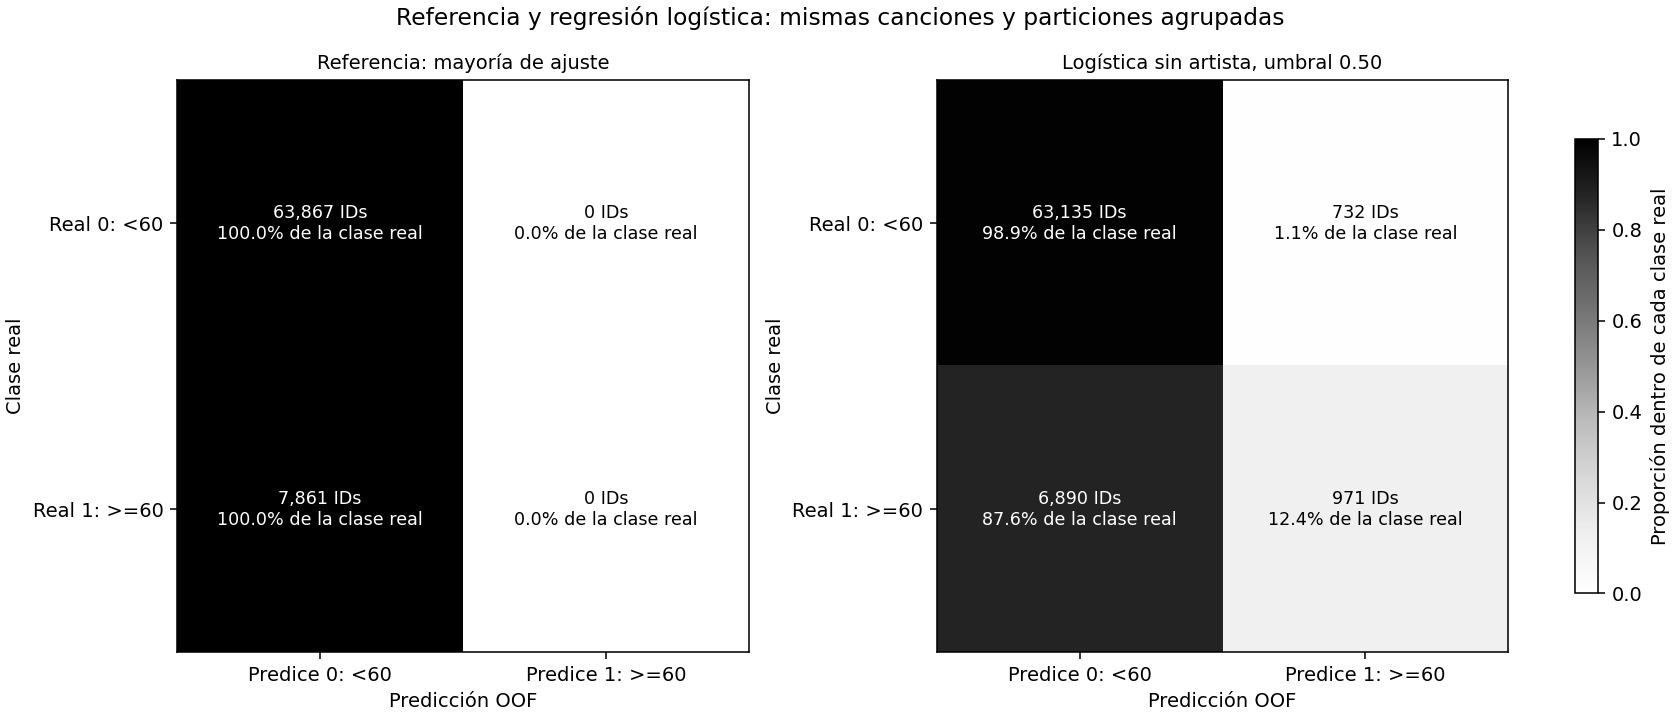

In [30]:
# Calcular métricas de la clase positiva con denominadores explícitos
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score
import matplotlib.pyplot as plt

def resumir_clasificacion(real, pred):
    matriz = confusion_matrix(real, pred, labels=[0, 1])
    tn, fp, fn, tp = (int(valor) for valor in matriz.ravel())
    resumen = {"IDs": len(real), "TN": tn, "FP": fp, "FN": fn, "TP": tp, "Positivos predichos": tp + fp, "Precisión positiva definida": (tp + fp) > 0, "Precisión clase 1": precision_score(real, pred, pos_label=1, zero_division=0), "Recall clase 1": recall_score(real, pred, pos_label=1, zero_division=0), "F1 clase 1": f1_score(real, pred, pos_label=1, zero_division=0), "Accuracy": accuracy_score(real, pred)}
    assert int(matriz.sum()) == len(real)
    assert np.isclose(resumen["Recall clase 1"], tp / (tp + fn) if tp + fn else 0)
    assert np.isclose(resumen["Precisión clase 1"], tp / (tp + fp) if tp + fp else 0)
    assert np.isclose(resumen["F1 clase 1"], 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0)
    assert np.isclose(resumen["Accuracy"], (tn + tp) / len(real))
    return matriz, resumen

predicciones_clasificacion_oof = {"Referencia: mayoría de ajuste": predicciones_mayoria_oof, "Logística sin artista, umbral 0.50": predicciones_logistica_oof}
matrices_clasificacion_oof = {}
metricas_clasificacion_globales = []
metricas_clasificacion_por_ronda = []
for nombre, pred in predicciones_clasificacion_oof.items():
    assert pred.index.equals(y_clasificacion_train.index)
    matriz, resumen = resumir_clasificacion(y_clasificacion_train, pred)
    matrices_clasificacion_oof[nombre] = matriz
    metricas_clasificacion_globales.append({"Procedimiento": nombre, **resumen})
    display(pd.DataFrame(matriz, index=["Real 0: <60", "Real 1: >=60"], columns=["Predice 0: <60", "Predice 1: >=60"]).rename_axis(nombre))
    for ronda in range(numero_pliegues):
        validar_ronda = pliegue_por_id.eq(ronda)
        _, resumen_ronda = resumir_clasificacion(y_clasificacion_train.loc[validar_ronda], pred.loc[validar_ronda])
        metricas_clasificacion_por_ronda.append({"Procedimiento": nombre, "Ronda": ronda + 1, **resumen_ronda})
tabla_metricas_clasificacion_oof = pd.DataFrame(metricas_clasificacion_globales).set_index("Procedimiento")
tabla_metricas_clasificacion_ronda = pd.DataFrame(metricas_clasificacion_por_ronda).set_index(["Procedimiento", "Ronda"])
display(tabla_metricas_clasificacion_oof.round(4))
display(tabla_metricas_clasificacion_ronda.round(4))

# Mostrar cantidades y porcentajes por clase real en las dos matrices
fig_matrices_clasificacion, ejes_matrices_clasificacion = plt.subplots(1, 2, figsize=(12, 5.2), constrained_layout=True)
for eje, (nombre, matriz) in zip(ejes_matrices_clasificacion, matrices_clasificacion_oof.items()):
    proporciones_fila = matriz / matriz.sum(axis=1, keepdims=True)
    imagen_matriz = eje.imshow(proporciones_fila, vmin=0, vmax=1, cmap="Greys")
    for fila in range(2):
        for columna in range(2):
            texto = f"{matriz[fila, columna]:,} IDs\n{proporciones_fila[fila, columna] * 100:.1f}% de la clase real"
            eje.text(columna, fila, texto, ha="center", va="center", color="white" if proporciones_fila[fila, columna] > 0.5 else "black", fontsize=9)
    eje.set_xticks([0, 1], ["Predice 0: <60", "Predice 1: >=60"])
    eje.set_yticks([0, 1], ["Real 0: <60", "Real 1: >=60"])
    eje.set_xlabel("Predicción OOF")
    eje.set_ylabel("Clase real")
    eje.set_title(nombre, fontsize=10)
fig_matrices_clasificacion.colorbar(imagen_matriz, ax=ejes_matrices_clasificacion, shrink=0.7, label="Proporción dentro de cada clase real")
fig_matrices_clasificacion.suptitle("Referencia y regresión logística: mismas canciones y particiones agrupadas")
display(fig_matrices_clasificacion)
plt.close(fig_matrices_clasificacion)


#### Interpretar los resultados y comprobar los KPI iniciales

**Referencia:** en las tres rondas la clase más frecuente de ajuste fue 0. Sus predicciones globales son TN=63.867, FP=0, FN=7.861, TP=0. Tiene accuracy **89,04%**, pero recall positivo **0%** y F1 **0**. La precisión positiva es indefinida al no señalar positivos; la tabla la muestra como 0 mediante la convención declarada. No cumple el objetivo de identificar canciones de clase 1.

**Logística sin artista, umbral fijo 0,50:**

- **TP=971:** canciones de popularidad >=60 correctamente identificadas.
- **FN=6.890:** canciones de popularidad >=60 que no se detectaron.
- **FP=732:** canciones de popularidad <60 que se señalaron como positivas.
- **TN=63.135:** canciones de popularidad <60 correctamente reconocidas como negativas.
- De las **7.861** positivas reales, identifica **971**: recall **12,35%**.
- Señala **1.703** canciones; de ellas **971** cumplen: precisión **57,02%**.
- F1 positivo **0,2031** y accuracy **89,37%** describen aspectos distintos. No se comparan numéricamente con MAE, RMSE o R² de regresión porque son otra tarea y otra escala.

**Código del cierre, en orden:** se seleccionan las métricas de cada procedimiento, se comparan con las metas fijadas antes de entrenar y se calcula cobertura OOF mediante valores presentes y exactamente una visita por ID. Los resultados de recall y precisión se multiplican por 100 para mostrarlos en porcentaje; el F1 se mantiene entre 0 y 1. Se conserva la tabla de metas inicial y se crea una actualización para la logística. Un KPI que falle se marca «No cumple»; no se oculta ni se modifica su meta.

La cobertura de etiquetas y los controles de claves conservan su evidencia anterior. La precisión de referencia sin positivos no se considera definida por haber elegido `zero_division=0` en el reporte. El cuadro comparativo informa cuáles procedimientos cumplen ambos KPI predictivos; solo entre procedimientos que los cumplan se utilizaría F1 como criterio principal.

Los cinco ejemplos del código son las primeras observaciones, sin seleccionar aciertos ni errores llamativos. Muestran probabilidad estimada y etiqueta producida con 0,50; el código no busca otro umbral ni recalibra probabilidades.


In [31]:
# Contrastar cada procedimiento con las metas previamente fijadas
comparacion_kpi_clasificacion = tabla_metricas_clasificacion_oof[["Recall clase 1", "Precisión clase 1", "F1 clase 1", "Accuracy", "Precisión positiva definida"]].copy()
comparacion_kpi_clasificacion["Cumple recall >=60%"] = comparacion_kpi_clasificacion["Recall clase 1"].ge(meta_recall_clasificacion)
comparacion_kpi_clasificacion["Cumple precisión >=30%"] = comparacion_kpi_clasificacion["Precisión clase 1"].ge(meta_precision_clasificacion) & comparacion_kpi_clasificacion["Precisión positiva definida"]
comparacion_kpi_clasificacion["Cumple ambos KPI predictivos"] = comparacion_kpi_clasificacion["Cumple recall >=60%"] & comparacion_kpi_clasificacion["Cumple precisión >=30%"]
resultado_logistica = tabla_metricas_clasificacion_oof.loc["Logística sin artista, umbral 0.50"]
cobertura_oof_logistica = float((predicciones_logistica_oof.notna() & visitas_clasificacion_oof.eq(1)).mean() * 100)
tabla_kpi_logistica_oof = tabla_kpi_inicio_clasificacion.copy(deep=True)
for indicador, valor, cumple in [
    ("Recall clase 1", float(resultado_logistica["Recall clase 1"]) * 100, resultado_logistica["Recall clase 1"] >= meta_recall_clasificacion),
    ("Precisión clase 1", float(resultado_logistica["Precisión clase 1"]) * 100, bool(resultado_logistica["Precisión positiva definida"]) and resultado_logistica["Precisión clase 1"] >= meta_precision_clasificacion),
    ("Cobertura de predicciones OOF", cobertura_oof_logistica, np.isclose(cobertura_oof_logistica, 100))
]:
    tabla_kpi_logistica_oof.loc[indicador, "Resultado"] = valor
    tabla_kpi_logistica_oof.loc[indicador, "Estado"] = "Cumple" if cumple else "No cumple"

ejemplos_logistica_oof = pd.DataFrame({"Clase real": y_clasificacion_train, "Referencia OOF": predicciones_mayoria_oof, "Probabilidad estimada clase 1": probabilidades_logistica_oof, "Etiqueta logística OOF": predicciones_logistica_oof})
display(comparacion_kpi_clasificacion.round(4))
display(tabla_kpi_logistica_oof.round({"Resultado": 4}))
display(ejemplos_logistica_oof.head(5).round(4))


,Recall clase 1,Precisión clase 1,F1 clase 1,Accuracy,Precisión positiva definida,Cumple recall >=60%,Cumple precisión >=30%,Cumple ambos KPI predictivos
Procedimiento,,,,,,,,
Referencia: mayoría de ajuste,0.0000,0.0000,0.0000,0.8904,False,False,False,False
"Logística sin artista, umbral 0.50",0.1235,0.5702,0.2031,0.8937,True,False,True,False


,Meta,Resultado,Unidad,Estado
KPI,,,,
Recall clase 1,>= 60%,12.3521,%,No cumple
Precisión clase 1,>= 30%,57.0170,%,Cumple
Etiquetas válidas y alineadas,100%,100.0000,%,Cumple
Claves compartidas ajuste/validación,0 en cada ronda,0.0000,Máximo de claves compartidas por ronda,Cumple
Cobertura de predicciones OOF,100%,100.0000,%,Cumple


,Clase real,Referencia OOF,Probabilidad estimada clase 1,Etiqueta logística OOF
track_id,,,,
000CC8EParg64OmTxVnZ0p,0,0,0.0090,0
000Iz0K615UepwSJ5z2RE5,0,0,0.0205,0
000RDCYioLteXcutOjeweY,1,0,0.2946,0
000qpdoc97IMTBvF8gwcpy,0,0,0.0163,0
0017XiMkqbTfF2AUOzlhj6,0,0,0.0090,0


#### Resultado inicial de clasificación con umbral fijo 0,50

La regresión logística mejora la identificación de la clase positiva respecto de la referencia, que no identifica ninguna. Con el umbral fijo 0,50, su recall es **12,35%**, precisión **57,02%** y F1 **0,2031**. La meta de recall **no cumple** y la de precisión **cumple**. **No cumple todavía ambas metas predictivas iniciales; se conserva el resultado sin cambiar la configuración.**

Las 71.728 canciones de entrenamiento tienen una predicción OOF, manteniendo las mismas tres particiones y sin compartir claves entre ajuste y validación. Los parámetros, las metas y el umbral no se modificaron en función del resultado. Se comenzó sin ponderar clases, sin remuestreo y sin artista para conservar una primera referencia comprensible.

Las métricas son de desarrollo interno: no demuestran causas, no garantizan identificación de futuros éxitos y no son una evaluación de clasificación en test. La prueba previamente evaluada para regresión no se consulta en este bloque.

**Continuidad:** analizar el efecto de la decisión 0,50 y del desbalance antes de añadir complejidad. Si después se estudian otros umbrales, ponderación o modelos, se hará dentro de entrenamiento con una comparación explícita y sin cambiar las metas para declarar éxito. El resultado inicial se conserva como evidencia.


El resultado anterior se conserva como referencia. A continuación se analiza el efecto de otros umbrales con las mismas probabilidades OOF.


#### Análisis de umbrales con las probabilidades OOF de la logística

**Pregunta:** sin cambiar el modelo, ¿qué ocurre si exigimos otra probabilidad para señalar una canción como clase 1? Se reutilizan exactamente las probabilidades fuera de pliegue de las 71.728 canciones, obtenidas con las mismas tres particiones agrupadas. No hay nuevos ajustes del modelo, balanceo, características ni consulta de test.

**Se mantiene la respuesta real:** clase 1 sigue significando popularidad >=60. Solo se estudia la regla de decisión `probabilidad estimada >= umbral`. El umbral 0,20 significa exigir al menos una probabilidad estimada de 20%; no significa bajar la popularidad real a 20 ni garantizar 20% de precisión.

- Al **bajar** el umbral se señalan más canciones o la misma cantidad; TP y FP no disminuyen y los FN no aumentan. El recall no disminuye.
- Al **subirlo** se señalan menos canciones o la misma cantidad y el recall no aumenta. Puede haber menos falsas alarmas, pero se dejan fuera más canciones positivas.
- La **precisión no está garantizada como monótona** al variar el umbral en una muestra real. Hay que leer los resultados, sin prometer que cada aumento la mejore.
- F1 combina precisión y recall. El umbral de mayor F1 no necesariamente cumple el recall >=60% y precisión >=30% exigidos.

**Comparación fijada para este análisis:** umbrales 0; 0,05; 0,10; 0,15; 0,20; 0,25; 0,30; 0,35; 0,40; 0,45; 0,50; 0,60; 0,70; 0,80; 0,90 y 1. El cero ilustra señalar todas las canciones; el uno señala únicamente probabilidades estimadas iguales a 1, si las hubiera. Es una lista de trabajo, no una búsqueda de todos los valores posibles ni una prueba de optimalidad universal.

**Regla de decisión conservada:** se consideran elegibles solo los umbrales que cumplen **ambos** KPI predictivos globales. Entre ellos se compara F1 positivo. Si hay empate exacto de F1, se prefiere el umbral mayor como regla explícita de desempate; no implica superioridad demostrada. Si no hay elegibles, se informa que ninguno de los umbrales analizados cumple ambos; no se cambian metas ni se elige un incumplimiento como si fuera éxito.

**Alcance de esta selección:** cada probabilidad es OOF, pero el umbral provisional se elige mirando estas mismas etiquetas de entrenamiento. Sus métricas son de **desarrollo del umbral**, no una estimación independiente del procedimiento completo ya afinado. Para una confirmación adicional habría que separar la selección y la evaluación del umbral, por ejemplo con una validación interna adicional agrupada. No se utiliza test para resolverlo; ese conjunto ya fue observado en regresión.

**Código, en orden:**

1. `np.array` escribe la lista de umbrales antes de calcular sus métricas. Se comprueban índice, finitud y rango de las probabilidades OOF disponibles.
2. El bucle transforma las mismas probabilidades con `.ge(umbral).astype("int8")`. No llama a `.fit` ni a `.predict_proba`: el modelo y sus probabilidades no cambian.
3. `resumir_clasificacion` reutiliza la matriz y las fórmulas ya verificadas. Se añaden indicadores de cumplimiento con las metas originales, manteniendo la convención de precisión no definida cuando no se predicen positivos.
4. `pd.DataFrame` reúne una fila por umbral. La tabla mostrada multiplica precisión y recall por 100; F1 conserva su escala 0–1. Las métricas se calculan con precisión completa, sin redondear para decidir el cumplimiento.
5. Los controles de monotonía comprueban que aumentar el umbral no incremente cantidad de positivos ni recall. No se impone monotonía de precisión.
6. Se comprueba que el umbral 0,50 reproduzca exactamente las etiquetas y métricas de la logística anterior. Esto confirma que estamos cambiando solo la regla de decisión.


In [32]:
# Fijar los umbrales de trabajo y conservar las metas anteriores
umbrales_logistica = np.array([0.00, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00])
assert probabilidades_logistica_oof.index.equals(y_clasificacion_train.index)
assert np.isfinite(probabilidades_logistica_oof).all() and probabilidades_logistica_oof.between(0, 1).all()
assert np.isclose(meta_recall_clasificacion, 0.60) and np.isclose(meta_precision_clasificacion, 0.30)
registros_umbrales = []
for umbral in umbrales_logistica:
    etiquetas_umbral = probabilidades_logistica_oof.ge(umbral).astype("int8")
    _, resumen_umbral = resumir_clasificacion(y_clasificacion_train, etiquetas_umbral)
    cumple_recall_umbral = resumen_umbral["Recall clase 1"] >= meta_recall_clasificacion
    cumple_precision_umbral = resumen_umbral["Precisión positiva definida"] and resumen_umbral["Precisión clase 1"] >= meta_precision_clasificacion
    registros_umbrales.append({"Umbral": float(umbral), **resumen_umbral, "Cumple recall": bool(cumple_recall_umbral), "Cumple precisión": bool(cumple_precision_umbral), "Cumple ambos KPI": bool(cumple_recall_umbral and cumple_precision_umbral)})
tabla_umbrales_logistica = pd.DataFrame(registros_umbrales).set_index("Umbral").sort_index()
tabla_umbrales_lectura = tabla_umbrales_logistica[["Positivos predichos", "Precisión clase 1", "Recall clase 1", "F1 clase 1", "Cumple precisión", "Cumple recall", "Cumple ambos KPI"]].copy()
tabla_umbrales_lectura["Precisión clase 1"] *= 100
tabla_umbrales_lectura["Recall clase 1"] *= 100
tabla_umbrales_lectura = tabla_umbrales_lectura.rename(columns={"Precisión clase 1": "Precisión (%)", "Recall clase 1": "Recall (%)"})
assert tabla_umbrales_logistica["Positivos predichos"].diff().dropna().le(0).all()
assert tabla_umbrales_logistica["Recall clase 1"].diff().dropna().le(1e-12).all()
assert probabilidades_logistica_oof.ge(0.50).astype("int8").equals(predicciones_logistica_oof)
for metrica in ["Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy"]:
    assert np.isclose(tabla_umbrales_logistica.loc[0.50, metrica], tabla_metricas_clasificacion_oof.loc["Logística sin artista, umbral 0.50", metrica])
display(tabla_umbrales_lectura.round(4))


,Positivos predichos,Precisión (%),Recall (%),F1 clase 1,Cumple precisión,Cumple recall,Cumple ambos KPI
Umbral,,,,,,,
0.00,71728,10.9595,100.0000,0.1975,False,True,False
0.05,35632,20.8941,94.7081,0.3424,False,True,False
0.10,27599,24.7183,86.7829,0.3848,False,True,False
0.15,19968,29.5072,74.9523,0.4234,False,True,False
0.20,13854,34.6759,61.1118,0.4425,True,True,True
0.25,9759,39.9221,49.5611,0.4422,True,False,False
0.30,6812,44.1867,38.2903,0.4103,True,False,False
0.35,4776,48.5553,29.5001,0.3670,True,False,False
0.40,3395,51.8704,22.4017,0.3129,True,False,False


#### Selección provisional, matriz de confusión y resultados por ronda

**Código, en orden:**

1. Se filtran filas con `Cumple ambos KPI`. `.sort_values` ordena por F1 descendente y, solo ante empate exacto, por umbral descendente. Se guarda `None` si no hay elegibles; no se sustituye por un resultado que falle una meta.
2. También se muestra el umbral de mayor F1 **sin filtrar** para explicar si el mejor balance numérico coincide con los requisitos. Ese resultado no reemplaza la regla de selección.
3. Para 0,50 y el umbral provisional, si existe, se crean etiquetas a partir de las probabilidades OOF. Se imprimen sus matrices con filas reales y columnas predichas. El título distingue ambas reglas.
4. La comparación por ronda reutiliza `pliegue_por_id`: no vuelve a partir ni baraja canciones. Se muestran precisión, recall, F1 y cumplimiento con cada umbral en las mismas rondas. Los KPI se definieron sobre el resultado global; posibles incumplimientos por ronda se informan como variación y no se esconden.
5. La tabla de KPI del umbral provisional copia la evidencia anterior y actualiza únicamente las métricas que cambiaron con la regla. Si no existe elegible, no se declara una selección cumplidora ni se sustituyen los pendientes por un éxito.
6. La cobertura vuelve a verificar una etiqueta por cada ID. No se modifican probabilidades, modelos ni etiquetas reales.

**Importante:** reducir el umbral puede recuperar canciones positivas y añadir simultáneamente falsas alarmas. La explicación debe comparar **TP, FN y FP**, no solo celebrar el aumento de recall. La distribución minoritaria de clase 1 y la separación imperfecta de las probabilidades condicionan esa compensación, pero estas cifras no identifican por sí solas una causa musical o social.


In [33]:
# Aplicar la regla de elección sin cambiar los KPI
elegibles_umbrales = tabla_umbrales_logistica.reset_index().loc[lambda tabla: tabla["Cumple ambos KPI"]].sort_values(["F1 clase 1", "Umbral"], ascending=[False, False])
mejor_f1_sin_restriccion = tabla_umbrales_logistica.reset_index().sort_values(["F1 clase 1", "Umbral"], ascending=[False, False]).iloc[0]
umbral_provisional_logistica = None if elegibles_umbrales.empty else float(elegibles_umbrales.iloc[0]["Umbral"])
display(elegibles_umbrales[["Umbral", "Precisión clase 1", "Recall clase 1", "F1 clase 1"]].round(4))
display(mejor_f1_sin_restriccion[["Umbral", "Precisión clase 1", "Recall clase 1", "F1 clase 1", "Cumple ambos KPI"]])

# Conservar 0,50 como referencia y comparar el provisional, si existe
umbrales_detalle = [0.50]
if umbral_provisional_logistica is not None and not np.isclose(umbral_provisional_logistica, 0.50):
    umbrales_detalle.append(umbral_provisional_logistica)
registros_umbrales_por_ronda = []
for umbral in umbrales_detalle:
    pred_detalle = probabilidades_logistica_oof.ge(umbral).astype("int8")
    matriz_detalle, _ = resumir_clasificacion(y_clasificacion_train, pred_detalle)
    display(pd.DataFrame(matriz_detalle, index=["Real 0: <60", "Real 1: >=60"], columns=["Predice 0: <60", "Predice 1: >=60"]).rename_axis(f"OOF: umbral {umbral:.2f}"))
    for ronda in range(numero_pliegues):
        en_ronda = pliegue_por_id.eq(ronda)
        _, resumen_ronda = resumir_clasificacion(y_clasificacion_train.loc[en_ronda], pred_detalle.loc[en_ronda])
        registros_umbrales_por_ronda.append({"Umbral": umbral, "Ronda": ronda + 1, "IDs": int(en_ronda.sum()), "Precisión (%)": resumen_ronda["Precisión clase 1"] * 100, "Recall (%)": resumen_ronda["Recall clase 1"] * 100, "F1": resumen_ronda["F1 clase 1"], "Cumple ambos KPI": resumen_ronda["Precisión positiva definida"] and resumen_ronda["Precisión clase 1"] >= meta_precision_clasificacion and resumen_ronda["Recall clase 1"] >= meta_recall_clasificacion})
tabla_umbrales_por_ronda = pd.DataFrame(registros_umbrales_por_ronda).set_index(["Umbral", "Ronda"])
display(tabla_umbrales_por_ronda.round(4))

# Actualizar evidencia del umbral elegido, si cumple las dos metas globales
tabla_kpi_umbral_provisional = None
predicciones_umbral_provisional_oof = None
if umbral_provisional_logistica is None:
    display("Ningún umbral de la lista cumple ambas metas. No se elige un umbral cumplidor ni se cambian los KPI.")
else:
    fila_provisional = tabla_umbrales_logistica.loc[umbral_provisional_logistica]
    predicciones_umbral_provisional_oof = probabilidades_logistica_oof.ge(umbral_provisional_logistica).astype("int8")
    assert predicciones_umbral_provisional_oof.index.equals(y_clasificacion_train.index)
    assert len(predicciones_umbral_provisional_oof) == len(y_clasificacion_train) and predicciones_umbral_provisional_oof.isin([0, 1]).all()
    tabla_kpi_umbral_provisional = tabla_kpi_logistica_oof.copy(deep=True)
    tabla_kpi_umbral_provisional.loc["Recall clase 1", "Resultado"] = float(fila_provisional["Recall clase 1"]) * 100
    tabla_kpi_umbral_provisional.loc["Precisión clase 1", "Resultado"] = float(fila_provisional["Precisión clase 1"]) * 100
    tabla_kpi_umbral_provisional.loc["Recall clase 1", "Estado"] = "Cumple" if fila_provisional["Cumple recall"] else "No cumple"
    tabla_kpi_umbral_provisional.loc["Precisión clase 1", "Estado"] = "Cumple" if fila_provisional["Cumple precisión"] else "No cumple"
    tabla_kpi_umbral_provisional.loc["Cobertura de predicciones OOF", "Resultado"] = float(predicciones_umbral_provisional_oof.notna().mean() * 100)
    display(tabla_kpi_umbral_provisional.round({"Resultado": 4}))


,Umbral,Precisión clase 1,Recall clase 1,F1 clase 1
4,0.2,0.3468,0.6111,0.4425


Umbral                    0.2
Precisión clase 1    0.346759
Recall clase 1       0.611118
F1 clase 1           0.442459
Cumple ambos KPI         True
Name: 4, dtype: object

,Predice 0: <60,Predice 1: >=60
OOF: umbral 0.50,,
Real 0: <60,63135,732
Real 1: >=60,6890,971


,Predice 0: <60,Predice 1: >=60
OOF: umbral 0.20,,
Real 0: <60,54817,9050
Real 1: >=60,3057,4804


IDs  Precisión (%)  Recall (%)      F1  Cumple ambos KPI
Umbral Ronda                                                            
0.5    1      23913        56.9748     12.6919  0.2076             False
       2      24104        53.9936     12.9254  0.2086             False
       3      23711        60.9959     11.4175  0.1923             False
0.2    1      23913        35.0122     59.0790  0.4397             False
       2      24104        33.5918     62.9446  0.4381              True
       3      23711        35.5296     61.3592  0.4500              True

,Meta,Resultado,Unidad,Estado
KPI,,,,
Recall clase 1,>= 60%,61.1118,%,Cumple
Precisión clase 1,>= 30%,34.6759,%,Cumple
Etiquetas válidas y alineadas,100%,100.0000,%,Cumple
Claves compartidas ajuste/validación,0 en cada ronda,0.0000,Máximo de claves compartidas por ronda,Cumple
Cobertura de predicciones OOF,100%,100.0000,%,Cumple


#### Visualizar el efecto del umbral

El panel izquierdo compara precisión y recall; las líneas horizontales indican metas diferentes. El derecho muestra F1 y marca los umbrales elegibles. La línea vertical de 0,50 conserva la regla inicial; si existe una selección provisional se identifica aparte.

**Lectura del código:** `plt.subplots` crea dos paneles. `.plot` conecta únicamente los umbrales calculados; las líneas no prueban el resultado de todos los valores intermedios. `axhline` representa las metas y `axvline` los umbrales de referencia. `scatter` destaca los valores que cumplen ambas metas. Los ejes van de 0 a 1 y los títulos recuerdan qué representa cada escala. `legend` identifica líneas y marcadores; `display` inserta el gráfico y `close` libera la figura.

Los umbrales 0 y 1 ayudan a leer los extremos, pero en ausencia de predicciones positivas la precisión no está definida: se muestra como 0 por convención y debe interpretarse con el conteo de positivos. El gráfico no valida calibración de probabilidades ni demuestra qué ocurrirá en canciones nuevas.


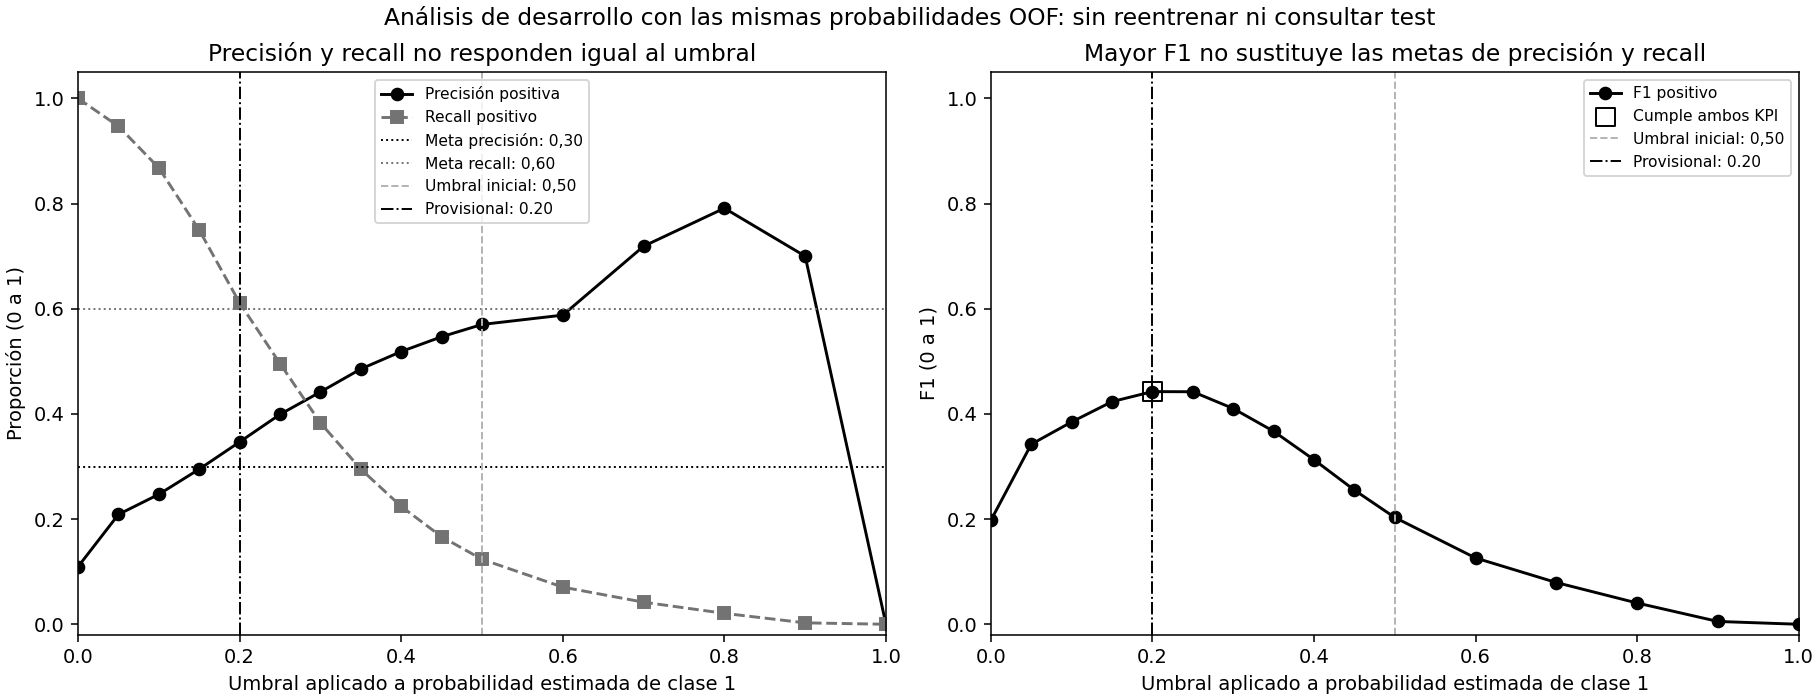

In [34]:
# Dibujar la compensación entre métricas con el modelo y sus probabilidades fijos
import matplotlib.pyplot as plt
fig_umbrales, ejes_umbrales = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
ejes_umbrales[0].plot(tabla_umbrales_logistica.index, tabla_umbrales_logistica["Precisión clase 1"], color="black", marker="o", label="Precisión positiva")
ejes_umbrales[0].plot(tabla_umbrales_logistica.index, tabla_umbrales_logistica["Recall clase 1"], color="0.45", linestyle="--", marker="s", label="Recall positivo")
ejes_umbrales[0].axhline(meta_precision_clasificacion, color="black", linestyle=":", linewidth=1, label="Meta precisión: 0,30")
ejes_umbrales[0].axhline(meta_recall_clasificacion, color="0.45", linestyle=":", linewidth=1, label="Meta recall: 0,60")
ejes_umbrales[0].set_title("Precisión y recall no responden igual al umbral")
ejes_umbrales[0].set_ylabel("Proporción (0 a 1)")
ejes_umbrales[1].plot(tabla_umbrales_logistica.index, tabla_umbrales_logistica["F1 clase 1"], color="black", marker="o", label="F1 positivo")
filas_elegibles = tabla_umbrales_logistica.loc[tabla_umbrales_logistica["Cumple ambos KPI"]]
ejes_umbrales[1].scatter(filas_elegibles.index, filas_elegibles["F1 clase 1"], marker="s", s=90, facecolors="none", edgecolors="black", label="Cumple ambos KPI")
ejes_umbrales[1].set_title("Mayor F1 no sustituye las metas de precisión y recall")
ejes_umbrales[1].set_ylabel("F1 (0 a 1)")
for eje in ejes_umbrales:
    eje.axvline(0.50, color="0.7", linestyle="--", linewidth=1, label="Umbral inicial: 0,50")
    if umbral_provisional_logistica is not None:
        eje.axvline(umbral_provisional_logistica, color="black", linestyle="-.", linewidth=1, label=f"Provisional: {umbral_provisional_logistica:.2f}")
    eje.set_xlim(0, 1)
    eje.set_ylim(-0.02, 1.05)
    eje.set_xlabel("Umbral aplicado a probabilidad estimada de clase 1")
    eje.legend(fontsize=8)
fig_umbrales.suptitle("Análisis de desarrollo con las mismas probabilidades OOF: sin reentrenar ni consultar test")
display(fig_umbrales)
plt.close(fig_umbrales)


#### Resultados, cumplimiento y explicación de los incumplimientos

**Selección provisional entre los umbrales analizados: 0,20.** Precisión **34,68%**, recall **61,11%** y F1 **0,4425**. Cumple las dos metas globales y tiene el mayor F1 entre los elegibles de esta lista. Los umbrales elegibles fueron **0,20**.

- **Umbral 0,50: no cumple ambos KPI.** recall 12,35% <60%: detecta 971 positivas y deja 6.890 sin detectar.
- **Umbral 0,05: no cumple ambos KPI.** precisión 20,89% <30%: hay 28.187 falsas alarmas entre 35.632 canciones señaladas.
- **Umbral 1,00: no cumple ambos KPI.** recall 0,00% <60%: detecta 0 positivas y deja 7.861 sin detectar; precisión no definida al no señalar ninguna positiva; el cero de reporte no representa una precisión estimada.

Al pasar de 0,50 a 0,20, se identifican **4.804** positivas reales en lugar de **971**; los FN pasan de **6.890 a 3.057**. A cambio, los FP pasan de **732 a 9.050**. Se señalan **13.854** canciones en total: mejor recall implica revisar más canciones y aceptar más falsas alarmas en este caso.

**Otros incumplimientos cercanos:** con umbral 0,15, recall=74,95% cumple, pero precisión=29,51% <30% **no cumple**; señalar más canciones incorpora demasiadas falsas alarmas para esa meta. Con umbral 0,25, precisión=39,92% cumple, pero recall=49,56% <60% **no cumple**; la regla deja fuera más de la mitad de las positivas reales.

**Costo de la selección 0,20:** el 65,32% de las canciones señaladas no cumple el corte real de popularidad. Ese porcentaje usa como denominador las canciones señaladas, no todas las negativas reales. Cumplir una meta inicial de precisión del 30% no elimina esta carga de revisión ni garantiza que sea aceptable en un uso real.

**Por qué pasa:** el umbral controla cuántas canciones se aceptan como positivas sobre un orden de probabilidades que no separa perfectamente ambas clases. Una regla exigente como 0,50 deja fuera muchas canciones de clase 1; una regla permisiva puede recuperar más positivas a costa de numerosas falsas alarmas. Los conteos permiten demostrar esta compensación. No se puede concluir solo con ellos que una variable específica o el desbalance sean la causa de cada error.

Con el umbral provisional, **no todas las rondas cumplen ambos KPI**, aunque el conjunto OOF global sí. Fallan las rondas **1**. **En la ronda 1, recall=59,08% <60%: no cumple ese KPI**, aunque precisión=35,01% sí supera 30%. Las rondas 2 y 3 cumplen ambas metas. La variación entre particiones permanece como limitación; no se redondea 59,08% a un cumplimiento.

Se conservaron el corte real de popularidad en 60, las metas de recall >=60% y precisión >=30%, las probabilidades, las características, los modelos por ronda y las particiones. Cambió únicamente el umbral de decisión. El cumplimiento se describe en desarrollo con probabilidades OOF; **el umbral se eligió con estas mismas respuestas y todavía requiere una comprobación independiente de esa elección**. No se presenta como resultado de clasificación en test ni se utiliza la evaluación de regresión para confirmarlo.

Si ningún umbral analizado cumpliera ambas metas, la conclusión sería incumplimiento de esta lista de trabajo, explicando qué métrica limita la decisión; no que sea imposible con cualquier umbral o modelo. No se amplía la lista automáticamente para buscar un éxito ni se reducen metas después de ver los resultados.


#### Validación adicional: separar la elección del umbral de su evaluación

El umbral 0,20 cumplió los KPI globales al compararlo con las mismas etiquetas OOF utilizadas para escogerlo. Ahora se comprueba **el procedimiento de seleccionar un umbral** sin permitir que las respuestas que lo evalúan elijan ese umbral.

Se conservan las **tres particiones externas agrupadas existentes**. Dentro del ajuste de cada ronda se crean otras **tres particiones internas**, también agrupadas por la misma clave artista + título. Esta organización se llama **validación anidada**: un nivel elige y otro evalúa.

**Ejemplo de la ronda externa 1:**

1. Sus 23.913 IDs de validación externa quedan fuera de la elección del umbral.
2. Solo los 47.815 IDs de su ajuste externo se subdividen internamente. En cada ronda interna se aprende imputación, escalamiento, categorías y logística con ajuste interno y se predice validación interna.
3. Se reúnen esas probabilidades OOF internas y se comparan los **mismos 16 umbrales**. Se mantienen recall >=60%, precisión >=30%, mayor F1 entre elegibles y desempate por umbral mayor.
4. El umbral se fija con esos datos internos. Después se aplica a la probabilidad de cada ID de validación externa, que ya procede de una logística entrenada solo con el ajuste externo.
5. Se repite para las otras dos rondas externas. Cada ID de entrenamiento recibe una sola etiqueta externa, con un umbral que no se seleccionó con su respuesta.

**Reutilización correcta de probabilidades externas:** las probabilidades guardadas de la primera logística se obtuvieron exactamente con esos mismos ajustes externos, preparación y parámetros. Se reutilizan para no repetir tres ajustes idénticos; nunca entran junto con sus respuestas en la elección interna. Los nueve ajustes nuevos son los tres internos de cada una de las tres rondas externas. Un umbral puede ser distinto en cada ronda: se evalúa el procedimiento de selección, no un 0,20 universal fijado a posteriori.

**Regla explícita si no hay umbral interno elegible:** se registra que la selección interna no encontró uno que cumpla ambas metas y se conserva **0,50 como regla de respaldo** para poder evaluar todos los IDs. No se presenta ese respaldo como un umbral cumplidor ni se cambia la meta. Esta política se fija antes de obtener los resultados externos; evita ocultar rondas difíciles o calcular métricas solo con los casos favorables.

**Lectura del código:**

- `seleccionar_umbral_interno` recibe únicamente X, etiquetas y claves del ajuste externo, la plantilla y las reglas ya fijadas. No recibe respuestas ni probabilidades de validación externa.
- Se ordenan y barajan las claves internas con semilla 42; repartir posiciones módulo 3 mantiene juntas sus versiones. No se utiliza popularidad para decidir el reparto.
- Cada ajuste interno clona el pipeline completo. `.fit` aprende solo del ajuste interno; `.predict_proba` obtiene probabilidades de su validación interna. Se revisan convergencia, medianas, escalador, ambas clases y separación de claves.
- La Serie de visitas comprueba una validación interna por ID. Después, cada umbral transforma las probabilidades internas; las métricas se calculan con las etiquetas internas. El orden de elegibilidad, F1 y desempate conserva la regla anterior.
- El bucle externo llama a la función con `~validar_externo`, fija el umbral y **solo después** aplica la regla a las probabilidades externas ya guardadas. Las etiquetas externas reales se consultan para evaluar en la celda siguiente.
- Los diccionarios conservan tablas internas y sus probabilidades como evidencia. La tabla de selección muestra umbral usado, si hubo elegibles, motivo y métricas internas. Las métricas internas sirven para elegir, no se presentan como resultado externo.
- Los controles de cobertura verifican exactamente una predicción externa por ID y la validez de las probabilidades externas reutilizadas. No se mezcla ajuste interno con validación externa ni se entrenan nuevos modelos sobre test.

**Alcance:** esta separación controla el uso de etiquetas en la elección del umbral para cada ronda. El dataset y las validaciones externas ya se habían examinado durante el desarrollo; por tanto, esto es una validación interna adicional con un protocolo más estricto, **no una muestra inédita o una prueba externa completamente independiente**. No se ajustan C, balanceo, metas o lista de umbrales al observar estos resultados.

Referencia conceptual: [validación anidada y no anidada, scikit-learn](https://scikit-learn.org/1.6/auto_examples/model_selection/plot_nested_cross_validation_iris.html).


In [35]:
# Elegir el umbral solo con las etiquetas y probabilidades del ajuste externo
numero_pliegues_internos_umbral = 3
umbral_respaldo_anidado = 0.50

def seleccionar_umbral_interno(X_ajuste_externo, y_ajuste_externo, claves_ajuste_externo, plantilla, umbrales, meta_recall, meta_precision):
    assert X_ajuste_externo.index.equals(y_ajuste_externo.index)
    assert claves_ajuste_externo.index.equals(y_ajuste_externo.index)
    claves_internas = claves_ajuste_externo.drop_duplicates().sort_values().sample(frac=1, random_state=42).reset_index(drop=True)
    mapa_interno = pd.Series(np.arange(len(claves_internas)) % 3, index=claves_internas)
    pliegue_interno = claves_ajuste_externo.map(mapa_interno)
    probabilidades_internas = pd.Series(index=y_ajuste_externo.index, dtype="float64")
    visitas_internas = pd.Series(0, index=y_ajuste_externo.index, dtype="int8")
    controles_internos = []
    for ronda_interna in range(3):
        validar_interno = pliegue_interno.eq(ronda_interna)
        ajustar_interno = ~validar_interno
        claves_compartidas = set(claves_ajuste_externo.loc[ajustar_interno]) & set(claves_ajuste_externo.loc[validar_interno])
        assert len(claves_compartidas) == 0
        assert y_ajuste_externo.loc[ajustar_interno].nunique() == 2 and y_ajuste_externo.loc[validar_interno].nunique() == 2
        modelo_interno = clone(plantilla)
        with warnings.catch_warnings(record=True) as avisos_internos:
            warnings.simplefilter("always", ConvergenceWarning)
            modelo_interno.fit(X_ajuste_externo.loc[ajustar_interno], y_ajuste_externo.loc[ajustar_interno])
        if any(issubclass(aviso.category, ConvergenceWarning) for aviso in avisos_internos):
            raise ValueError("Revisar convergencia interna antes de elegir el umbral.")
        clasificador_interno = modelo_interno.named_steps["clasificar"]
        columna_positiva = list(clasificador_interno.classes_).index(1)
        probabilidades_internas.loc[validar_interno] = modelo_interno.predict_proba(X_ajuste_externo.loc[validar_interno])[:, columna_positiva]
        visitas_internas.loc[validar_interno] += 1
        bloque_numerico = modelo_interno.named_steps["preparar"].named_transformers_["numericas"]
        assert np.allclose(bloque_numerico.named_steps["imputar"].statistics_, X_ajuste_externo.loc[ajustar_interno, columnas_numericas_modelo].median())
        assert int(bloque_numerico.named_steps["escalar"].n_samples_seen_) == int(ajustar_interno.sum())
        assert int(clasificador_interno.n_iter_[0]) < 2000
        controles_internos.append({"Ronda interna": ronda_interna + 1, "IDs ajuste interno": int(ajustar_interno.sum()), "IDs validación interna": int(validar_interno.sum()), "Claves compartidas internas": len(claves_compartidas), "Iteraciones": int(clasificador_interno.n_iter_[0])})
    assert visitas_internas.eq(1).all() and probabilidades_internas.notna().all()
    assert np.isfinite(probabilidades_internas).all() and probabilidades_internas.between(0, 1).all()
    filas_umbrales = []
    for umbral in umbrales:
        _, metricas = resumir_clasificacion(y_ajuste_externo, probabilidades_internas.ge(umbral).astype("int8"))
        elegible = metricas["Precisión positiva definida"] and metricas["Precisión clase 1"] >= meta_precision and metricas["Recall clase 1"] >= meta_recall
        filas_umbrales.append({"Umbral": float(umbral), **metricas, "Elegible interno": bool(elegible)})
    tabla_interna = pd.DataFrame(filas_umbrales).set_index("Umbral")
    elegibles = tabla_interna.reset_index().loc[lambda tabla: tabla["Elegible interno"]].sort_values(["F1 clase 1", "Umbral"], ascending=[False, False])
    if elegibles.empty:
        umbral_usado = 0.50
        motivo = "Ningún umbral interno cumple ambos KPI; respaldo fijo 0,50"
    else:
        umbral_usado = float(elegibles.iloc[0]["Umbral"])
        motivo = "Mayor F1 interno entre umbrales que cumplen ambos KPI"
    return umbral_usado, not elegibles.empty, motivo, tabla_interna, pd.DataFrame(controles_internos), probabilidades_internas

# Mantener las mismas tres rondas externas y reutilizar sus probabilidades OOF
assert probabilidades_logistica_oof.index.equals(y_clasificacion_train.index)
assert np.isfinite(probabilidades_logistica_oof).all()
predicciones_umbral_anidado_oof = pd.Series(index=y_clasificacion_train.index, dtype="float64")
umbral_asignado_por_id = pd.Series(index=y_clasificacion_train.index, dtype="float64")
visitas_externas_anidadas = pd.Series(0, index=y_clasificacion_train.index, dtype="int8")
selecciones_anidadas = []
controles_ajustes_internos = []
evidencia_interna_por_ronda = {}

for ronda_externa in range(numero_pliegues):
    validar_externo = pliegue_por_id.eq(ronda_externa)
    ajustar_externo = ~validar_externo
    claves_ajuste_externo = datos_entrenamiento.loc[ajustar_externo, "clave_cancion"]
    assert set(claves_ajuste_externo).isdisjoint(set(datos_entrenamiento.loc[validar_externo, "clave_cancion"]))
    umbral_usado, hubo_elegible, motivo, tabla_interna, controles_internos, prob_internas = seleccionar_umbral_interno(X_train.loc[ajustar_externo], y_clasificacion_train.loc[ajustar_externo], claves_ajuste_externo, modelo_logistico_base, umbrales_logistica, meta_recall_clasificacion, meta_precision_clasificacion)
    evidencia_interna_por_ronda[ronda_externa + 1] = {"Tabla de umbrales internos": tabla_interna, "Probabilidades internas": prob_internas}
    fila_interna = tabla_interna.loc[umbral_usado]
    selecciones_anidadas.append({"Ronda externa": ronda_externa + 1, "IDs ajuste externo": int(ajustar_externo.sum()), "IDs validación externa": int(validar_externo.sum()), "Umbral usado": umbral_usado, "Hubo umbral interno elegible": hubo_elegible, "Precisión interna (%)": fila_interna["Precisión clase 1"] * 100, "Recall interno (%)": fila_interna["Recall clase 1"] * 100, "F1 interno": fila_interna["F1 clase 1"], "Motivo": motivo})
    controles_internos["Ronda externa"] = ronda_externa + 1
    controles_ajustes_internos.append(controles_internos)
    predicciones_umbral_anidado_oof.loc[validar_externo] = probabilidades_logistica_oof.loc[validar_externo].ge(umbral_usado).astype("int8")
    umbral_asignado_por_id.loc[validar_externo] = umbral_usado
    visitas_externas_anidadas.loc[validar_externo] += 1
assert visitas_externas_anidadas.eq(1).all()
assert predicciones_umbral_anidado_oof.notna().all() and predicciones_umbral_anidado_oof.isin([0, 1]).all()
predicciones_umbral_anidado_oof = predicciones_umbral_anidado_oof.astype("int8")
tabla_seleccion_anidada = pd.DataFrame(selecciones_anidadas).set_index("Ronda externa")
tabla_controles_ajustes_internos = pd.concat(controles_ajustes_internos, ignore_index=True).set_index(["Ronda externa", "Ronda interna"])
display(tabla_seleccion_anidada.round(4))
display(tabla_controles_ajustes_internos)


,IDs ajuste externo,IDs validación externa,Umbral usado,Hubo umbral interno elegible,Precisión interna (%),Recall interno (%),F1 interno,Motivo
Ronda externa,,,,,,,,
1,47815,23913,0.2,True,35.0493,60.2119,0.4431,Mayor F1 interno entre umbrales que cumplen am...
2,47624,24104,0.2,True,34.9546,61.6470,0.4461,Mayor F1 interno entre umbrales que cumplen am...
3,48017,23711,0.2,True,34.3919,60.0265,0.4373,Mayor F1 interno entre umbrales que cumplen am...


IDs ajuste interno  ...  Iteraciones
Ronda externa Ronda interna                      ...             
1             1                           31862  ...          152
              2                           31854  ...          160
              3                           31914  ...          159
2             1                           31821  ...          147
              2                           31752  ...          169
              3                           31675  ...          159
3             1                           32108  ...          159
              2                           32047  ...          159
              3                           31879  ...          153

[9 rows x 4 columns]

#### Evaluar únicamente después de fijar el umbral de cada ronda

Ahora sí se comparan las etiquetas externas predichas con las respuestas de su validación externa. Se reúnen las 71.728 observaciones para la matriz global y se muestran las tres rondas por separado.

**Código, en orden:**

1. `resumir_clasificacion` calcula TN, FP, FN, TP y métricas con las predicciones externas del procedimiento anidado. La matriz mantiene filas reales y columnas predichas.
2. El reporte por ronda usa su umbral seleccionado internamente y comprueba las mismas metas. La coincidencia o diferencia entre umbrales no se altera después de mirar estas métricas.
3. La tabla de comparación distingue tres alcances: 0,50 fijo antes de buscar, 0,20 escogido con todas las etiquetas OOF y el procedimiento de selección interna evaluado externamente. No son tres modelos distintos: usan la misma configuración de logística y diferentes protocolos de decisión.
4. La tabla de KPI se copia y se actualiza con las métricas anidadas. Recall y precisión se muestran en porcentaje; F1 conserva escala 0–1. La cobertura exige una predicción externa por ID. Los controles de etiquetas y claves mantienen su evidencia.
5. Si falla una meta, se informa «No cumple». Que el umbral global anterior cumpliera no obliga al protocolo más estricto a cumplir. La tabla interna explica si hubo alguna ronda sin candidato elegible; el respaldo 0,50 permanece visible.

**Qué se está validando:** la capacidad del proceso «aprender logística y elegir umbral con datos internos» para trasladarse a otras canciones de la misma partición de entrenamiento. No se confirma un umbral único para todo uso ni se crea un clasificador final con todo el entrenamiento. El resultado global no es el promedio simple de precisión, recall o F1 de las rondas.


In [36]:
# Calcular la matriz global con predicciones externas del procedimiento anidado
matriz_umbral_anidado, resumen_umbral_anidado = resumir_clasificacion(y_clasificacion_train, predicciones_umbral_anidado_oof)
display(pd.DataFrame(matriz_umbral_anidado, index=["Real 0: <60", "Real 1: >=60"], columns=["Predice 0: <60", "Predice 1: >=60"]).rename_axis("Selección interna de umbral: evaluación externa"))
registros_evaluacion_anidada = []
for ronda_externa in range(numero_pliegues):
    en_externa = pliegue_por_id.eq(ronda_externa)
    _, metricas_externas = resumir_clasificacion(y_clasificacion_train.loc[en_externa], predicciones_umbral_anidado_oof.loc[en_externa])
    registros_evaluacion_anidada.append({"Ronda externa": ronda_externa + 1, "Umbral usado": float(tabla_seleccion_anidada.loc[ronda_externa + 1, "Umbral usado"]), "IDs": int(en_externa.sum()), "TP": metricas_externas["TP"], "FN": metricas_externas["FN"], "FP": metricas_externas["FP"], "Precisión (%)": metricas_externas["Precisión clase 1"] * 100, "Recall (%)": metricas_externas["Recall clase 1"] * 100, "F1": metricas_externas["F1 clase 1"], "Cumple precisión": bool(metricas_externas["Precisión positiva definida"] and metricas_externas["Precisión clase 1"] >= meta_precision_clasificacion), "Cumple recall": bool(metricas_externas["Recall clase 1"] >= meta_recall_clasificacion)})
tabla_evaluacion_anidada = pd.DataFrame(registros_evaluacion_anidada).set_index("Ronda externa")

# Comparar alcances de evaluación, sin elegir otro protocolo por su resultado
fila_inicial = tabla_metricas_clasificacion_oof.loc["Logística sin artista, umbral 0.50"]
fila_global_020 = tabla_umbrales_logistica.loc[0.20]
comparacion_protocolos_umbral = pd.DataFrame([
    {"Protocolo": "0,50 fijado antes del análisis", "Precisión (%)": fila_inicial["Precisión clase 1"] * 100, "Recall (%)": fila_inicial["Recall clase 1"] * 100, "F1": fila_inicial["F1 clase 1"], "Alcance": "Predicciones OOF con umbral inicial fijo"},
    {"Protocolo": "0,20 escogido con etiquetas OOF globales", "Precisión (%)": fila_global_020["Precisión clase 1"] * 100, "Recall (%)": fila_global_020["Recall clase 1"] * 100, "F1": fila_global_020["F1 clase 1"], "Alcance": "Desarrollo del umbral sobre etiquetas utilizadas para escogerlo"},
    {"Protocolo": "Selección interna y evaluación externa agrupadas", "Precisión (%)": resumen_umbral_anidado["Precisión clase 1"] * 100, "Recall (%)": resumen_umbral_anidado["Recall clase 1"] * 100, "F1": resumen_umbral_anidado["F1 clase 1"], "Alcance": "Validación interna adicional con elección y evaluación separadas"}
]).set_index("Protocolo")
tabla_kpi_umbral_anidado = tabla_kpi_logistica_oof.copy(deep=True)
for indicador, valor, cumple in [
    ("Recall clase 1", resumen_umbral_anidado["Recall clase 1"] * 100, resumen_umbral_anidado["Recall clase 1"] >= meta_recall_clasificacion),
    ("Precisión clase 1", resumen_umbral_anidado["Precisión clase 1"] * 100, resumen_umbral_anidado["Precisión positiva definida"] and resumen_umbral_anidado["Precisión clase 1"] >= meta_precision_clasificacion),
    ("Cobertura de predicciones OOF", float(visitas_externas_anidadas.eq(1).mean() * 100), visitas_externas_anidadas.eq(1).all())
]:
    tabla_kpi_umbral_anidado.loc[indicador, "Resultado"] = valor
    tabla_kpi_umbral_anidado.loc[indicador, "Estado"] = "Cumple" if cumple else "No cumple"
assert int(matriz_umbral_anidado.sum()) == len(y_clasificacion_train)
assert np.isclose(resumen_umbral_anidado["Recall clase 1"], tabla_evaluacion_anidada["TP"].sum() / (tabla_evaluacion_anidada["TP"].sum() + tabla_evaluacion_anidada["FN"].sum()))
display(pd.Series(resumen_umbral_anidado))
display(tabla_evaluacion_anidada.round(4))
display(comparacion_protocolos_umbral.round(4))
display(tabla_kpi_umbral_anidado.round({"Resultado": 4}))


,Predice 0: <60,Predice 1: >=60
Selección interna de umbral: evaluación externa,,
Real 0: <60,54817,9050
Real 1: >=60,3057,4804


IDs                               71728
TN                                54817
FP                                 9050
FN                                 3057
TP                                 4804
Positivos predichos               13854
Precisión positiva definida        True
Precisión clase 1              0.346759
Recall clase 1                 0.611118
F1 clase 1                     0.442459
Accuracy                        0.83121
dtype: object

,Umbral usado,IDs,TP,FN,FP,Precisión (%),Recall (%),F1,Cumple precisión,Cumple recall
Ronda externa,,,,,,,,,,
1,0.2,23913,1578,1093,2929,35.0122,59.0790,0.4397,True,False
2,0.2,24104,1646,969,3254,33.5918,62.9446,0.4381,True,True
3,0.2,23711,1580,995,2867,35.5296,61.3592,0.4500,True,True


,Precisión (%),Recall (%),F1,Alcance
Protocolo,,,,
"0,50 fijado antes del análisis",57.0170,12.3521,0.2031,Predicciones OOF con umbral inicial fijo
"0,20 escogido con etiquetas OOF globales",34.6759,61.1118,0.4425,Desarrollo del umbral sobre etiquetas utilizad...
Selección interna y evaluación externa agrupadas,34.6759,61.1118,0.4425,Validación interna adicional con elección y ev...


,Meta,Resultado,Unidad,Estado
KPI,,,,
Recall clase 1,>= 60%,61.1118,%,Cumple
Precisión clase 1,>= 30%,34.6759,%,Cumple
Etiquetas válidas y alineadas,100%,100.0000,%,Cumple
Claves compartidas ajuste/validación,0 en cada ronda,0.0000,Máximo de claves compartidas por ronda,Cumple
Cobertura de predicciones OOF,100%,100.0000,%,Cumple


#### Conclusión de la validación adicional del umbral

El procedimiento anidado obtiene **precisión 34,68%**, **recall 61,11%** y **F1 0,4425** sobre las 71.728 predicciones externas. Matriz global: TN=54.817, FP=9.050, FN=3.057, TP=4.804.

- **Ronda externa 1:** umbral usado 0,20; precisión interna 35,05%, recall interno 60,21%. Hubo un umbral interno elegible y se aplicó la regla de mayor F1.
- **Ronda externa 2:** umbral usado 0,20; precisión interna 34,95%, recall interno 61,65%. Hubo un umbral interno elegible y se aplicó la regla de mayor F1.
- **Ronda externa 3:** umbral usado 0,20; precisión interna 34,39%, recall interno 60,03%. Hubo un umbral interno elegible y se aplicó la regla de mayor F1.

- **Evaluación externa de ronda 1:** no cumple ambos KPI; recall 59,08% <60%: identificó 1.578 positivas y dejó 1.093 sin identificar.
- **Evaluación externa de ronda 2:** cumple ambos: precisión 33,59% y recall 62,94%.
- **Evaluación externa de ronda 3:** cumple ambos: precisión 35,53% y recall 61,36%.

**Recall cumple globalmente:** 61,11% supera o iguala 60%.

**Precisión cumple globalmente:** 34,68% supera o iguala 30%.

Los controles de etiquetas, separación agrupada y cobertura del 100% se mantienen. Cumplir controles metodológicos no compensa un incumplimiento predictivo.

**Por qué coinciden las métricas con el análisis anterior:** las tres rondas externas eligieron internamente 0,20 usando únicamente sus ajustes externos. Al aplicar ese mismo valor a las probabilidades externas guardadas, se obtienen las mismas etiquetas y métricas globales que antes. La evidencia nueva es cómo se eligió el umbral sin usar las respuestas de su evaluación externa; no son dos pruebas independientes sobre muestras diferentes.

**Margen de cumplimiento:** el recall global supera la meta en solo 1,11 puntos porcentuales. En las selecciones internas, la ronda externa 3 obtuvo recall interno de 60,03%, apenas por encima del 60%. Son señales para evitar presentar este cumplimiento como robusto en cualquier reparto o población.

**Interpretación de la estabilidad:** si las subdivisiones internas no encuentran siempre un umbral elegible, el cumplimiento observado al elegir 0,20 con todas las etiquetas OOF no basta para asegurar una decisión estable. Si los umbrales internos coinciden, eso es una coincidencia de estas particiones, no una garantía. No se amplía la lista, se cambia el respaldo ni se bajan metas después de ver este resultado.

Se mantuvieron las mismas particiones externas, el agrupamiento por clave también en las internas, la logística sin artista, C=1, el umbral real de popularidad 60 y las metas de recall 60% y precisión 30%. Solo se añadieron los ajustes internos necesarios para separar elección y evaluación. Test no se consultó para clasificación.

Este bloque valida un procedimiento de selección, no certifica una versión final de clasificación ni convierte la fuente ya explorada en una muestra inédita. La evidencia y cualquier incumplimiento quedan documentados antes de considerar otras estrategias dentro de entrenamiento.


#### Regresión logística con ponderación de clases: comparación controlada a 0,50

**Pregunta:** manteniendo las mismas características, particiones, parámetros y umbral de probabilidad, ¿qué cambia al dar más peso a la clase minoritaria durante el aprendizaje?

Se compara la logística inicial **`class_weight=None`** con una copia que usa **`class_weight="balanced"`**, ambas **sin artista y con umbral 0,50**. No se compara el resultado principal contra el umbral 0,20 para atribuir al balanceo lo que podría deberse a otra regla de decisión. La popularidad real que define clase 1 sigue siendo >=60.

**Qué hace `balanced`:** aprende pesos inversamente proporcionales a la frecuencia de las clases **en el ajuste de cada ronda**:

`peso de una clase = número de filas de ajuste / (2 × número de filas de esa clase)`

El 2 es la cantidad de clases. Cada positiva tiene un peso mayor porque hay menos positivas; cada negativa tiene un peso menor. La suma de pesos de cada clase queda en la mitad del total de filas de ajuste. Esto equilibra su contribución agregada a la pérdida de entrenamiento, no las cantidades de canciones ni las métricas de validación. No obliga a que el modelo prediga mitad de cada clase ni a que mejore una métrica.

**Ejemplo ficticio:** con 90 negativas y 10 positivas, los pesos serían `100/(2×90)=0,556` y `100/(2×10)=5`. Cada positiva tendría nueve veces el peso de cada negativa. Es un ejemplo didáctico; las tablas siguientes muestran los valores reales de cada ajuste.

**Decisiones conservadas:** C=1, penalización L2, `lbfgs`, tolerancia 1e-6, máximo de 2.000 iteraciones, misma preparación y mismas tres particiones externas agrupadas. No hay sobremuestreo, submuestreo, artista ni búsqueda nueva de parámetros o de umbral. Las filas de validación mantienen la distribución original y las métricas se calculan **sin ponderarlas**.

La ponderación solo modifica la pérdida del clasificador; no se ponderan medianas o escalas del preprocesador. El pipeline aprende ambas cosas solo con ajuste. Las probabilidades estimadas pueden cambiar de escala al ponderar y no se ha verificado su calibración: un valor de 0,50 no garantiza una frecuencia real de 50% en la población original.

**Lectura del código:**

1. `clone(modelo_logistico_base)` conserva la plantilla anterior sin modificarla. `.set_params(clasificar__class_weight="balanced")` cambia únicamente el parámetro del clasificador dentro del pipeline.
2. Se comparan los parámetros del estimador y se verifica que, salvo `class_weight`, coincidan. `umbral_probabilidad_balanced=0.50` mantiene fija la decisión para ambas variantes.
3. Las Series reservan probabilidades y etiquetas OOF por ID; la Serie de visitas contará una validación por ID. El diccionario guarda modelos de cada ronda como evidencia.
4. El bucle separa ajuste y validación con las mismas máscaras. Se comprueba que sus claves no se compartan. `value_counts` obtiene las cantidades de clases únicamente en ajuste. Dividir por `2 × conteo` calcula los pesos esperados que aplica internamente `balanced`.
5. Esos pesos se registran, **no se pasan además como `sample_weight`**: hacerlo duplicaría la ponderación. No se calculan pesos con las etiquetas de validación ni con todo el dataset.
6. `.fit` aprende preparación y logística ponderada con ajuste. Se revisa convergencia antes de interpretar. `.predict_proba` entrega probabilidades para validación y `classes_` localiza la columna de clase 1.
7. `.ge(0.50)` produce la etiqueta y se guardan las salidas por ID. Se incrementan visitas, se comprueban medianas y filas vistas por el escalador y se registra el número de iteraciones.
8. Los controles finales verifican cobertura, rango, índices y etiquetas. Solo después se convierten las etiquetas a `int8`. La tabla de pesos explica el aprendizaje; no es una tabla de métricas de éxito.

Referencia del comportamiento de `class_weight`: [LogisticRegression de scikit-learn 1.6](https://scikit-learn.org/1.6/modules/generated/sklearn.linear_model.LogisticRegression.html).


In [37]:
# Cambiar solo la ponderación, manteniendo el umbral en 0,50
umbral_probabilidad_balanced = 0.50
modelo_logistico_balanced_base = clone(modelo_logistico_base).set_params(clasificar__class_weight="balanced")
parametros_sin_ponderar = modelo_logistico_base.named_steps["clasificar"].get_params()
parametros_ponderados = modelo_logistico_balanced_base.named_steps["clasificar"].get_params()
assert parametros_sin_ponderar["class_weight"] is None
assert parametros_ponderados["class_weight"] == "balanced"
assert all(parametros_sin_ponderar[clave] == parametros_ponderados[clave] for clave in parametros_sin_ponderar if clave != "class_weight")
assert np.isclose(umbral_probabilidad_balanced, 0.50)
probabilidades_balanced_oof = pd.Series(index=y_clasificacion_train.index, dtype="float64", name="probabilidad_balanced_oof")
predicciones_balanced_oof = pd.Series(index=y_clasificacion_train.index, dtype="float64", name="etiqueta_balanced_oof")
visitas_balanced_oof = pd.Series(0, index=y_clasificacion_train.index, dtype="int8")
modelos_balanced_por_ronda = {}
registros_pesos_balanced = []

for ronda in range(numero_pliegues):
    validar_balanced = pliegue_por_id.eq(ronda)
    ajustar_balanced = ~validar_balanced
    assert set(datos_entrenamiento.loc[ajustar_balanced, "clave_cancion"]).isdisjoint(set(datos_entrenamiento.loc[validar_balanced, "clave_cancion"]))
    X_ajuste_balanced = X_train.loc[ajustar_balanced]
    X_validacion_balanced = X_train.loc[validar_balanced]
    y_ajuste_balanced = y_clasificacion_train.loc[ajustar_balanced]
    conteos_ajuste_balanced = y_ajuste_balanced.value_counts().reindex([0, 1], fill_value=0)
    assert conteos_ajuste_balanced.gt(0).all()
    pesos_esperados_balanced = len(y_ajuste_balanced) / (2 * conteos_ajuste_balanced)
    assert np.allclose((pesos_esperados_balanced * conteos_ajuste_balanced).to_numpy(), len(y_ajuste_balanced) / 2)
    modelo_balanced_ronda = clone(modelo_logistico_balanced_base)
    with warnings.catch_warnings(record=True) as avisos_balanced:
        warnings.simplefilter("always", ConvergenceWarning)
        modelo_balanced_ronda.fit(X_ajuste_balanced, y_ajuste_balanced)
    if any(issubclass(aviso.category, ConvergenceWarning) for aviso in avisos_balanced):
        raise ValueError("Revisar convergencia de la logística ponderada antes de evaluar.")
    clasificador_balanced = modelo_balanced_ronda.named_steps["clasificar"]
    columna_clase_1_balanced = list(clasificador_balanced.classes_).index(1)
    prob_balanced_ronda = modelo_balanced_ronda.predict_proba(X_validacion_balanced)[:, columna_clase_1_balanced]
    probabilidades_balanced_oof.loc[validar_balanced] = prob_balanced_ronda
    predicciones_balanced_oof.loc[validar_balanced] = (prob_balanced_ronda >= umbral_probabilidad_balanced).astype("int8")
    visitas_balanced_oof.loc[validar_balanced] += 1
    modelos_balanced_por_ronda[ronda] = modelo_balanced_ronda
    numericas_balanced = modelo_balanced_ronda.named_steps["preparar"].named_transformers_["numericas"]
    assert np.allclose(numericas_balanced.named_steps["imputar"].statistics_, X_ajuste_balanced[columnas_numericas_modelo].median())
    assert int(numericas_balanced.named_steps["escalar"].n_samples_seen_) == len(y_ajuste_balanced)
    iteraciones_balanced = int(clasificador_balanced.n_iter_[0])
    assert iteraciones_balanced < 2000
    registros_pesos_balanced.append({"Ronda": ronda + 1, "IDs ajuste": len(y_ajuste_balanced), "IDs validación": int(validar_balanced.sum()), "Clase 0 en ajuste": int(conteos_ajuste_balanced.loc[0]), "Clase 1 en ajuste": int(conteos_ajuste_balanced.loc[1]), "Peso esperado clase 0": float(pesos_esperados_balanced.loc[0]), "Peso esperado clase 1": float(pesos_esperados_balanced.loc[1]), "Iteraciones": iteraciones_balanced})

controles_balanced_oof = pd.Series({
    "Una validación por ID": visitas_balanced_oof.eq(1).all(),
    "Probabilidades completas, finitas y en 0–1": np.isfinite(probabilidades_balanced_oof).all() and probabilidades_balanced_oof.between(0, 1).all(),
    "Etiquetas completas y binarias": predicciones_balanced_oof.notna().all() and predicciones_balanced_oof.isin([0, 1]).all(),
    "Índices alineados": probabilidades_balanced_oof.index.equals(y_clasificacion_train.index) and predicciones_balanced_oof.index.equals(y_clasificacion_train.index),
    "Sin artista en entradas": "historial_artista" not in X_train.columns
})
if not controles_balanced_oof.all():
    raise ValueError("Revisar cobertura y alineación de la logística ponderada.")
predicciones_balanced_oof = predicciones_balanced_oof.astype("int8")
tabla_pesos_balanced = pd.DataFrame(registros_pesos_balanced).set_index("Ronda")
display(tabla_pesos_balanced.round(4))
display(controles_balanced_oof)


,IDs ajuste,IDs validación,Clase 0 en ajuste,Clase 1 en ajuste,Peso esperado clase 0,Peso esperado clase 1,Iteraciones
Ronda,,,,,,,
1,47815,23913,42625,5190,0.5609,4.6065,216
2,47624,24104,42378,5246,0.5619,4.5391,237
3,48017,23711,42731,5286,0.5619,4.5419,237


Una validación por ID                         True
Probabilidades completas, finitas y en 0–1    True
Etiquetas completas y binarias                True
Índices alineados                             True
Sin artista en entradas                       True
dtype: bool

#### Métricas OOF y matrices: sin ponderación frente a balanced

Las dos variantes se comparan con las mismas 71.728 etiquetas, probabilidades obtenidas fuera de ajuste y decisión en 0,50. El resultado anterior sin ponderar se reutiliza porque su configuración y particiones no cambiaron; no se compara contra su umbral 0,20.

**Lectura del código:**

1. El diccionario reúne las etiquetas OOF de ambas variantes. `resumir_clasificacion` calcula conteos y métricas ordinarias, sin aplicar los pesos de entrenamiento al evaluar.
2. La matriz usa filas reales y columnas predichas: `[[TN, FP], [FN, TP]]`. Su suma debe cubrir todos los IDs. Se conserva una matriz por variante.
3. Se calculan además resultados por ronda con las mismas máscaras. `pos_label=1` permanece fijado dentro de la función de métricas.
4. La tabla mostrada convierte precisión, recall y accuracy a porcentajes para leerlos; F1 conserva su escala 0–1. Las tablas internas conservan proporciones para contrastar metas sin redondear.
5. Se verifica que la fila sin ponderar coincida con sus métricas originales. Así se detecta una comparación accidental con otro umbral o conjunto.
6. El gráfico imprime cantidades y porcentajes dentro de cada clase real. Cada fila suma 100%; el color tiene la misma escala en ambas variantes. La celda TP muestra el recall como porcentaje de positivas reales, no la precisión. Esta última divide TP entre TP+FP.

Un recall mayor puede venir acompañado de más FP y menos precisión. Una accuracy menor no basta para descartar la ponderación: el objetivo es identificar clase 1 con las dos metas fijadas. Tampoco basta un recall elevado si falla la precisión. Los porcentajes globales se calculan con todas las predicciones, no promediando porcentajes por ronda.


,Predice 0: <60,Predice 1: >=60
"Sin ponderación, umbral 0.50",,
Real 0: <60,63135,732
Real 1: >=60,6890,971


,Predice 0: <60,Predice 1: >=60
"Balanced, umbral 0.50",,
Real 0: <60,44460,19407
Real 1: >=60,1177,6684


,TP,FN,FP,TN,Positivos predichos,Precisión (%),Recall (%),F1 clase 1,Accuracy (%)
Variante,,,,,,,,,
"Sin ponderación, umbral 0.50",971,6890,732,63135,1703,57.017,12.3521,0.2031,89.3737
"Balanced, umbral 0.50",6684,1177,19407,44460,26091,25.618,85.0274,0.3937,71.3027


TP    FN  ...  F1 clase 1  Accuracy
Variante                     Ronda              ...                      
Sin ponderación, umbral 0.50 1       339  2332  ...      0.2076    0.8918
                             2       338  2277  ...      0.2086    0.8936
                             3       294  2281  ...      0.1923    0.8959
Balanced, umbral 0.50        1      2235   436  ...      0.4023    0.7223
                             2      2248   367  ...      0.3813    0.6974
                             3      2201   374  ...      0.3983    0.7196

[6 rows x 7 columns]

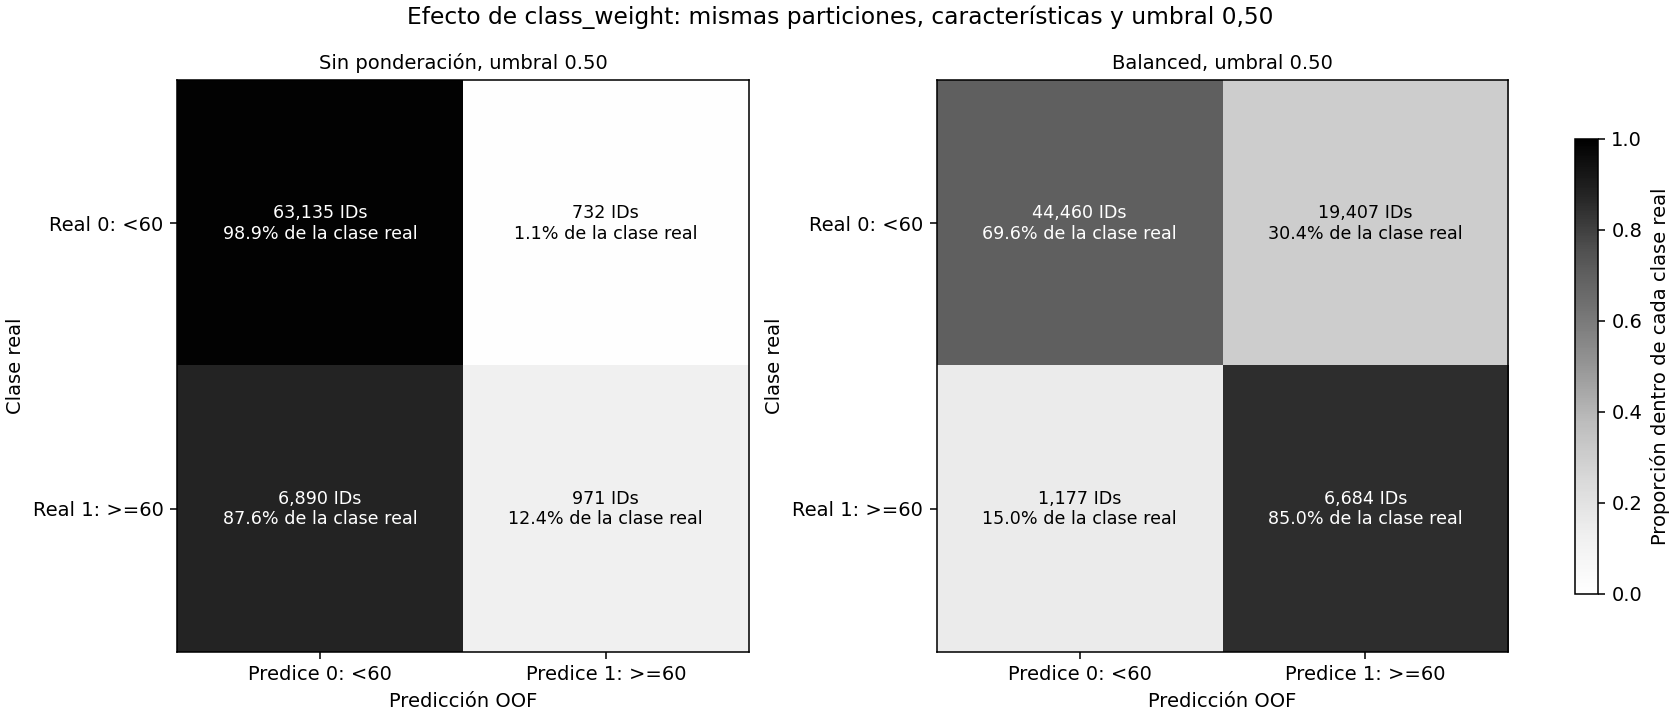

In [38]:
# Comparar ambas variantes al mismo umbral, con métricas sin ponderación
predicciones_comparacion_balanced = {"Sin ponderación, umbral 0.50": predicciones_logistica_oof, "Balanced, umbral 0.50": predicciones_balanced_oof}
matrices_comparacion_balanced = {}
registros_metricas_balanced = []
registros_rondas_balanced = []
for nombre, pred in predicciones_comparacion_balanced.items():
    assert pred.index.equals(y_clasificacion_train.index)
    matriz, resumen = resumir_clasificacion(y_clasificacion_train, pred)
    matrices_comparacion_balanced[nombre] = matriz
    registros_metricas_balanced.append({"Variante": nombre, **resumen})
    display(pd.DataFrame(matriz, index=["Real 0: <60", "Real 1: >=60"], columns=["Predice 0: <60", "Predice 1: >=60"]).rename_axis(nombre))
    for ronda in range(numero_pliegues):
        en_validacion = pliegue_por_id.eq(ronda)
        _, resumen_ronda = resumir_clasificacion(y_clasificacion_train.loc[en_validacion], pred.loc[en_validacion])
        registros_rondas_balanced.append({"Variante": nombre, "Ronda": ronda + 1, **resumen_ronda})
tabla_metricas_balanced_oof = pd.DataFrame(registros_metricas_balanced).set_index("Variante")
tabla_rondas_balanced_oof = pd.DataFrame(registros_rondas_balanced).set_index(["Variante", "Ronda"])
for metrica in ["Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy"]:
    assert np.isclose(tabla_metricas_balanced_oof.loc["Sin ponderación, umbral 0.50", metrica], tabla_metricas_clasificacion_oof.loc["Logística sin artista, umbral 0.50", metrica])
tabla_lectura_balanced = tabla_metricas_balanced_oof[["TP", "FN", "FP", "TN", "Positivos predichos", "Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy"]].copy()
for metrica in ["Precisión clase 1", "Recall clase 1", "Accuracy"]:
    tabla_lectura_balanced[metrica] *= 100
tabla_lectura_balanced = tabla_lectura_balanced.rename(columns={"Precisión clase 1": "Precisión (%)", "Recall clase 1": "Recall (%)", "Accuracy": "Accuracy (%)"})
display(tabla_lectura_balanced.round(4))
display(tabla_rondas_balanced_oof[["TP", "FN", "FP", "Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy"]].round(4))

# Dibujar conteos y porcentajes por clase real con la misma escala
import matplotlib.pyplot as plt
fig_balanced, ejes_balanced = plt.subplots(1, 2, figsize=(12, 5.2), constrained_layout=True)
for eje, (nombre, matriz) in zip(ejes_balanced, matrices_comparacion_balanced.items()):
    proporciones_clase_real = matriz / matriz.sum(axis=1, keepdims=True)
    imagen_balanced = eje.imshow(proporciones_clase_real, vmin=0, vmax=1, cmap="Greys")
    for fila in range(2):
        for columna in range(2):
            texto = f"{matriz[fila, columna]:,} IDs\n{proporciones_clase_real[fila, columna] * 100:.1f}% de la clase real"
            eje.text(columna, fila, texto, ha="center", va="center", fontsize=9, color="white" if proporciones_clase_real[fila, columna] > 0.5 else "black")
    eje.set_xticks([0, 1], ["Predice 0: <60", "Predice 1: >=60"])
    eje.set_yticks([0, 1], ["Real 0: <60", "Real 1: >=60"])
    eje.set_xlabel("Predicción OOF")
    eje.set_ylabel("Clase real")
    eje.set_title(nombre, fontsize=10)
fig_balanced.colorbar(imagen_balanced, ax=ejes_balanced, shrink=0.7, label="Proporción dentro de cada clase real")
fig_balanced.suptitle("Efecto de class_weight: mismas particiones, características y umbral 0,50")
display(fig_balanced)
plt.close(fig_balanced)


#### Cumplimiento de KPI y lectura del efecto del balanceo

**Resultados globales al umbral 0,50:**

| Variante | Precisión | Recall | F1 | Accuracy |
|---|---:|---:|---:|---:|
| Sin ponderación, umbral 0.50 | 57,02% | 12,35% | 0,2031 | 89,37% |
| Balanced, umbral 0.50 | 25,62% | 85,03% | 0,3937 | 71,30% |


**Qué cambió en los errores:** los TP pasan de **971 a 6.684**, los FN de **6.890 a 1.177** y los FP de **732 a 19.407**. La variante ponderada señala **26.091** canciones; **6.684** cumplen realmente el corte y **19.407** son falsas alarmas.

**Recall cumple:** 85,03% >=60%. Identifica 6.684 de las 7.861 positivas.

**Precisión no cumple:** 25,62% <30%. De 26.091 canciones señaladas, 19.407 son falsas alarmas. Se detectan más positivas a costa de señalar demasiadas negativas para la meta fijada. El desbalance real de validación no desaparece al ponderar el aprendizaje.

**Código del cierre:** se comparan precisión y recall de cada variante con las mismas metas 30% y 60%. La precisión debe estar definida para considerarla cumplida. La tabla de KPI de la variante ponderada copia los controles previos y actualiza sus resultados predictivos y cobertura. No cambia el corte de popularidad, la meta ni el umbral para declarar éxito. Se muestran también los estados por ronda para no esconder variación.

La Serie de cambios expresa precisión, recall y accuracy en **puntos porcentuales**, no en porcentaje de mejora relativa. Por ejemplo, pasar de 20% a 30% son +10 puntos porcentuales. El cambio de F1 se expresa en unidades de F1. Los conteos mantienen su unidad de canciones por ID.

**Alcance:** este experimento compara dos objetivos de aprendizaje con una regla de decisión numéricamente igual. No demuestra que balanced sea mejor para cualquier umbral o población, ni que sus probabilidades estén calibradas. El estudio previo de 0,20 corresponde a la logística sin ponderar y no se transfiere automáticamente a la ponderada.


In [39]:
# Evaluar ambas variantes contra las metas originales, sin modificarlas
comparacion_kpi_balanced = tabla_metricas_balanced_oof[["Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy", "Precisión positiva definida"]].copy()
comparacion_kpi_balanced["Cumple precisión >=30%"] = comparacion_kpi_balanced["Precisión positiva definida"] & comparacion_kpi_balanced["Precisión clase 1"].ge(meta_precision_clasificacion)
comparacion_kpi_balanced["Cumple recall >=60%"] = comparacion_kpi_balanced["Recall clase 1"].ge(meta_recall_clasificacion)
comparacion_kpi_balanced["Cumple ambos KPI"] = comparacion_kpi_balanced["Cumple precisión >=30%"] & comparacion_kpi_balanced["Cumple recall >=60%"]
resultado_balanced = tabla_metricas_balanced_oof.loc["Balanced, umbral 0.50"]
resultado_sin_ponderar = tabla_metricas_balanced_oof.loc["Sin ponderación, umbral 0.50"]
tabla_kpi_balanced_oof = tabla_kpi_logistica_oof.copy(deep=True)
for indicador, valor, cumple in [
    ("Recall clase 1", resultado_balanced["Recall clase 1"] * 100, resultado_balanced["Recall clase 1"] >= meta_recall_clasificacion),
    ("Precisión clase 1", resultado_balanced["Precisión clase 1"] * 100, resultado_balanced["Precisión positiva definida"] and resultado_balanced["Precisión clase 1"] >= meta_precision_clasificacion),
    ("Cobertura de predicciones OOF", float(visitas_balanced_oof.eq(1).mean() * 100), visitas_balanced_oof.eq(1).all())
]:
    tabla_kpi_balanced_oof.loc[indicador, "Resultado"] = valor
    tabla_kpi_balanced_oof.loc[indicador, "Estado"] = "Cumple" if cumple else "No cumple"
cambio_metricas_balanced = pd.Series({"Precisión: cambio en puntos porcentuales": (resultado_balanced["Precisión clase 1"] - resultado_sin_ponderar["Precisión clase 1"]) * 100, "Recall: cambio en puntos porcentuales": (resultado_balanced["Recall clase 1"] - resultado_sin_ponderar["Recall clase 1"]) * 100, "F1: cambio en unidades de F1": resultado_balanced["F1 clase 1"] - resultado_sin_ponderar["F1 clase 1"], "Accuracy: cambio en puntos porcentuales": (resultado_balanced["Accuracy"] - resultado_sin_ponderar["Accuracy"]) * 100})
cumplimiento_rondas_balanced = tabla_rondas_balanced_oof[["Precisión clase 1", "Recall clase 1", "F1 clase 1"]].copy()
cumplimiento_rondas_balanced["Cumple precisión"] = cumplimiento_rondas_balanced["Precisión clase 1"].ge(meta_precision_clasificacion)
cumplimiento_rondas_balanced["Cumple recall"] = cumplimiento_rondas_balanced["Recall clase 1"].ge(meta_recall_clasificacion)
display(comparacion_kpi_balanced.round(4))
display(tabla_kpi_balanced_oof.round({"Resultado": 4}))
display(cambio_metricas_balanced.round(4))
display(cumplimiento_rondas_balanced.round(4))


,Precisión clase 1,Recall clase 1,F1 clase 1,Accuracy,Precisión positiva definida,Cumple precisión >=30%,Cumple recall >=60%,Cumple ambos KPI
Variante,,,,,,,,
"Sin ponderación, umbral 0.50",0.5702,0.1235,0.2031,0.8937,True,True,False,False
"Balanced, umbral 0.50",0.2562,0.8503,0.3937,0.7130,True,False,True,False


,Meta,Resultado,Unidad,Estado
KPI,,,,
Recall clase 1,>= 60%,85.0274,%,Cumple
Precisión clase 1,>= 30%,25.6180,%,No cumple
Etiquetas válidas y alineadas,100%,100.0000,%,Cumple
Claves compartidas ajuste/validación,0 en cada ronda,0.0000,Máximo de claves compartidas por ronda,Cumple
Cobertura de predicciones OOF,100%,100.0000,%,Cumple


Precisión: cambio en puntos porcentuales   -31.3990
Recall: cambio en puntos porcentuales       72.6752
F1: cambio en unidades de F1                 0.1907
Accuracy: cambio en puntos porcentuales    -18.0710
dtype: float64

Precisión clase 1  ...  Cumple recall
Variante                     Ronda                     ...               
Sin ponderación, umbral 0.50 1                 0.5697  ...          False
                             2                 0.5399  ...          False
                             3                 0.6100  ...          False
Balanced, umbral 0.50        1                 0.2648  ...           True
                             2                 0.2450  ...           True
                             3                 0.2597  ...           True

[6 rows x 5 columns]

#### Resultado inicial de balanced con umbral fijo 0,50

La logística con `class_weight="balanced"` al umbral 0,50 obtiene **precisión 25,62%**, **recall 85,03%** y **F1 0,3937**. **No cumple ambas metas predictivas iniciales**; se informa el incumplimiento sin cambiar el umbral o la meta. La ponderación aumenta la importancia de las positivas en la pérdida; los cambios observados de TP y FP explican la compensación entre métricas, sin probar causas musicales o sociales.

- **Ronda 1:** no cumple ambos KPI: precisión 26,48% <30%.
- **Ronda 2:** no cumple ambos KPI: precisión 24,50% <30%.
- **Ronda 3:** no cumple ambos KPI: precisión 25,97% <30%.

**Lo que demuestra esta comparación:** la ponderación cambió la forma de aprender y sus probabilidades; no se añadieron canciones, no se balanceó la validación y no se cambió el umbral. Las probabilidades y etiquetas de ambas variantes se conservan como evidencia.

**Lo que no se declara:** no se escoge un ganador operativo basándose únicamente en accuracy, recall o una métrica que mejore. Se conserva la regla de considerar ambas metas predictivas y comparar F1 entre procedimientos que las cumplan. Un incumplimiento se informa como tal.

Se usaron solo los 71.728 IDs de entrenamiento, las mismas tres particiones externas agrupadas y la misma preparación sin artista. No se consultó test para clasificación. Si después se estudia otro umbral para la variante ponderada, su selección deberá ocurrir dentro de ajuste y su evaluación fuera de esa selección, sin reutilizar como confirmación el mejor resultado escogido con las mismas etiquetas.


El resultado anterior no se sustituye: se conserva para medir qué cambia al analizar otros umbrales de esta misma variante ponderada.


#### Umbrales de la regresión logística balanced: precisión, recall y F1

**Objetivo:** estudiar si otra regla de decisión permite a la logística ponderada cumplir precisión >=30% y recall >=60%. Al umbral 0,50 obtuvo recall **85,03%**, pero precisión **25,62%**: detectaba muchas positivas y también demasiadas falsas alarmas para la meta fijada.

Se reutilizan **las probabilidades OOF de la variante balanced**, calculadas con las mismas tres particiones agrupadas. No se vuelven a entrenar los modelos ni se recalculan pesos. Los pesos ya se aprendieron con las frecuencias de ajuste de cada ronda. No se usa test ni se balancea la validación.

**No se transfieren umbrales entre modelos:** el 0,20 estudiado para la logística sin ponderar no se asume adecuado para balanced. La ponderación cambia el aprendizaje y las probabilidades estimadas. Un mismo número de probabilidad no garantiza la misma calibración o frecuencia real en ambas variantes.

Se conserva la lista de **16 umbrales** del análisis anterior: 0; 0,05; 0,10; 0,15; 0,20; 0,25; 0,30; 0,35; 0,40; 0,45; 0,50; 0,60; 0,70; 0,80; 0,90 y 1. También se conserva la regla: entre umbrales que cumplan **ambas metas globales**, comparar F1 positivo y desempatar por umbral mayor. Si ninguno cumple, se informa que ninguno de esta lista es elegible; no se bajan metas ni se presenta otro como cumplidor.

**Cómo esperar que cambien las métricas:** subir el umbral reduce o mantiene los positivos señalados y el recall; bajar el umbral los aumenta o mantiene. La precisión puede mejorar al ser más exigente, pero no está garantizada una mejora monótona en cada paso. F1 depende de la combinación de precisión y recall y puede subir o bajar. La popularidad real que define clase 1 sigue siendo >=60.

**Código, en orden:**

1. Se escribe la misma lista de trabajo y se comprueban índice, finitud y rango de las probabilidades ponderadas. Las metas se contrastan con 0,60 y 0,30 para evitar un cambio accidental.
2. `.ge(umbral).astype("int8")` convierte probabilidades en etiquetas por cada umbral. No cambia el modelo ni la respuesta real.
3. `resumir_clasificacion` calcula matriz y métricas sin pesos de evaluación. Se registra precisión definida, recall, F1 y conteos. El cumplimiento se compara sin redondear.
4. La tabla de lectura expresa precisión y recall en porcentaje, y mantiene F1 entre 0 y 1. Los conteos indican cuántas canciones se tendrían que revisar.
5. Los controles comprueban que al subir el umbral no crezcan positivos predichos ni recall. No se exige monotonía a precisión.
6. Se verifica que 0,50 reproduzca exactamente las etiquetas y métricas originales de **balanced**, no las de la logística sin ponderar.

**Alcance:** se selecciona una regla usando estas mismas etiquetas OOF. Las probabilidades de cada canción se obtuvieron fuera de su ajuste, pero el umbral elegido con todas ellas todavía es una decisión de desarrollo. Su métrica no es una confirmación independiente de esa selección. La validación anidada anterior correspondía a la variante sin ponderar y no confirma automáticamente esta nueva elección.


In [40]:
# Fijar los umbrales de trabajo y conservar las metas anteriores
umbrales_balanced = np.array([0.00, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00])
assert probabilidades_balanced_oof.index.equals(y_clasificacion_train.index)
assert np.isfinite(probabilidades_balanced_oof).all() and probabilidades_balanced_oof.between(0, 1).all()
assert np.isclose(meta_recall_clasificacion, 0.60) and np.isclose(meta_precision_clasificacion, 0.30)
registros_umbrales_balanced = []
for umbral in umbrales_balanced:
    etiquetas_umbral = probabilidades_balanced_oof.ge(umbral).astype("int8")
    _, resumen_umbral = resumir_clasificacion(y_clasificacion_train, etiquetas_umbral)
    cumple_recall_umbral = resumen_umbral["Recall clase 1"] >= meta_recall_clasificacion
    cumple_precision_umbral = resumen_umbral["Precisión positiva definida"] and resumen_umbral["Precisión clase 1"] >= meta_precision_clasificacion
    registros_umbrales_balanced.append({"Umbral": float(umbral), **resumen_umbral, "Cumple recall": bool(cumple_recall_umbral), "Cumple precisión": bool(cumple_precision_umbral), "Cumple ambos KPI": bool(cumple_recall_umbral and cumple_precision_umbral)})
tabla_umbrales_balanced = pd.DataFrame(registros_umbrales_balanced).set_index("Umbral").sort_index()
tabla_umbrales_balanced_lectura = tabla_umbrales_balanced[["Positivos predichos", "Precisión clase 1", "Recall clase 1", "F1 clase 1", "Cumple precisión", "Cumple recall", "Cumple ambos KPI"]].copy()
tabla_umbrales_balanced_lectura["Precisión clase 1"] *= 100
tabla_umbrales_balanced_lectura["Recall clase 1"] *= 100
tabla_umbrales_balanced_lectura = tabla_umbrales_balanced_lectura.rename(columns={"Precisión clase 1": "Precisión (%)", "Recall clase 1": "Recall (%)"})
assert tabla_umbrales_balanced["Positivos predichos"].diff().dropna().le(0).all()
assert tabla_umbrales_balanced["Recall clase 1"].diff().dropna().le(1e-12).all()
assert probabilidades_balanced_oof.ge(0.50).astype("int8").equals(predicciones_balanced_oof)
for metrica in ["Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy"]:
    assert np.isclose(tabla_umbrales_balanced.loc[0.50, metrica], tabla_metricas_balanced_oof.loc["Balanced, umbral 0.50", metrica])
display(tabla_umbrales_balanced_lectura.round(4))


,Positivos predichos,Precisión (%),Recall (%),F1 clase 1,Cumple precisión,Cumple recall,Cumple ambos KPI
Umbral,,,,,,,
0.00,71728,10.9595,100.0000,0.1975,False,True,False
0.05,55964,13.9858,99.5675,0.2453,False,True,False
0.10,47195,16.3979,98.4480,0.2811,False,True,False
0.15,42299,18.1257,97.5321,0.3057,False,True,False
0.20,39086,19.4366,96.6416,0.3236,False,True,False
0.25,36916,20.4193,95.8911,0.3367,False,True,False
0.30,35118,21.2227,94.8098,0.3468,False,True,False
0.35,33411,21.9928,93.4741,0.3561,False,True,False
0.40,31431,22.8564,91.3879,0.3657,False,True,False


#### Elegibilidad, matrices y cumplimiento por ronda

**Lectura del código:** se filtran las filas que cumplen ambas metas; se ordenan por F1 y, ante empate exacto, por umbral. Si la tabla está vacía se guarda `None`, sin declarar una selección exitosa. Se muestra además el mayor F1 sin restricciones para distinguir «mejor F1» de «cumple requisitos».

Para 0,50 y el umbral provisional, si existe, las matrices mantienen **filas reales y columnas predichas**: `[[TN, FP], [FN, TP]]`. Se muestran conteos para explicar qué errores se intercambian al cambiar el umbral.

El bucle por ronda utiliza `pliegue_por_id`, sin volver a dividir canciones. Las métricas globales y por ronda se distinguen: cumplir globalmente no implica cumplir en cada una de las tres rondas. Se conserva cualquier incumplimiento como evidencia de variación.

La tabla de KPI del umbral elegido copia la evidencia metodológica y actualiza precisión, recall y cobertura de sus etiquetas. Las metas siguen siendo las iniciales. No se modifica la tabla del umbral fijo ni la del modelo sin ponderar; los resultados del nuevo análisis tienen nombres propios.


In [41]:
# Aplicar la regla de elección sin cambiar los KPI
elegibles_umbrales_balanced = tabla_umbrales_balanced.reset_index().loc[lambda tabla: tabla["Cumple ambos KPI"]].sort_values(["F1 clase 1", "Umbral"], ascending=[False, False])
mejor_f1_balanced_sin_restriccion = tabla_umbrales_balanced.reset_index().sort_values(["F1 clase 1", "Umbral"], ascending=[False, False]).iloc[0]
umbral_provisional_balanced = None if elegibles_umbrales_balanced.empty else float(elegibles_umbrales_balanced.iloc[0]["Umbral"])
display(elegibles_umbrales_balanced[["Umbral", "Precisión clase 1", "Recall clase 1", "F1 clase 1"]].round(4))
display(mejor_f1_balanced_sin_restriccion[["Umbral", "Precisión clase 1", "Recall clase 1", "F1 clase 1", "Cumple ambos KPI"]])

# Conservar 0,50 como referencia y comparar el provisional, si existe
umbrales_detalle_balanced = [0.50]
if umbral_provisional_balanced is not None and not np.isclose(umbral_provisional_balanced, 0.50):
    umbrales_detalle_balanced.append(umbral_provisional_balanced)
registros_umbrales_balanced_por_ronda = []
for umbral in umbrales_detalle_balanced:
    pred_detalle = probabilidades_balanced_oof.ge(umbral).astype("int8")
    matriz_detalle, _ = resumir_clasificacion(y_clasificacion_train, pred_detalle)
    display(pd.DataFrame(matriz_detalle, index=["Real 0: <60", "Real 1: >=60"], columns=["Predice 0: <60", "Predice 1: >=60"]).rename_axis(f"OOF: umbral {umbral:.2f}"))
    for ronda in range(numero_pliegues):
        en_ronda = pliegue_por_id.eq(ronda)
        _, resumen_ronda = resumir_clasificacion(y_clasificacion_train.loc[en_ronda], pred_detalle.loc[en_ronda])
        registros_umbrales_balanced_por_ronda.append({"Umbral": umbral, "Ronda": ronda + 1, "IDs": int(en_ronda.sum()), "Precisión (%)": resumen_ronda["Precisión clase 1"] * 100, "Recall (%)": resumen_ronda["Recall clase 1"] * 100, "F1": resumen_ronda["F1 clase 1"], "Cumple ambos KPI": resumen_ronda["Precisión positiva definida"] and resumen_ronda["Precisión clase 1"] >= meta_precision_clasificacion and resumen_ronda["Recall clase 1"] >= meta_recall_clasificacion})
tabla_umbrales_balanced_por_ronda = pd.DataFrame(registros_umbrales_balanced_por_ronda).set_index(["Umbral", "Ronda"])
display(tabla_umbrales_balanced_por_ronda.round(4))

# Actualizar evidencia del umbral elegido, si cumple las dos metas globales
tabla_kpi_umbral_balanced = None
predicciones_umbral_balanced_oof = None
if umbral_provisional_balanced is None:
    display("Ningún umbral de la lista cumple ambas metas. No se elige un umbral cumplidor ni se cambian los KPI.")
else:
    fila_provisional = tabla_umbrales_balanced.loc[umbral_provisional_balanced]
    predicciones_umbral_balanced_oof = probabilidades_balanced_oof.ge(umbral_provisional_balanced).astype("int8")
    assert predicciones_umbral_balanced_oof.index.equals(y_clasificacion_train.index)
    assert len(predicciones_umbral_balanced_oof) == len(y_clasificacion_train) and predicciones_umbral_balanced_oof.isin([0, 1]).all()
    tabla_kpi_umbral_balanced = tabla_kpi_balanced_oof.copy(deep=True)
    tabla_kpi_umbral_balanced.loc["Recall clase 1", "Resultado"] = float(fila_provisional["Recall clase 1"]) * 100
    tabla_kpi_umbral_balanced.loc["Precisión clase 1", "Resultado"] = float(fila_provisional["Precisión clase 1"]) * 100
    tabla_kpi_umbral_balanced.loc["Recall clase 1", "Estado"] = "Cumple" if fila_provisional["Cumple recall"] else "No cumple"
    tabla_kpi_umbral_balanced.loc["Precisión clase 1", "Estado"] = "Cumple" if fila_provisional["Cumple precisión"] else "No cumple"
    tabla_kpi_umbral_balanced.loc["Cobertura de predicciones OOF", "Resultado"] = float(predicciones_umbral_balanced_oof.notna().mean() * 100)
    display(tabla_kpi_umbral_balanced.round({"Resultado": 4}))


,Umbral,Precisión clase 1,Recall clase 1,F1 clase 1
11,0.6,0.3037,0.7372,0.4301


Umbral                    0.7
Precisión clase 1    0.367608
Recall clase 1       0.556672
F1 clase 1           0.442803
Cumple ambos KPI        False
Name: 12, dtype: object

,Predice 0: <60,Predice 1: >=60
OOF: umbral 0.50,,
Real 0: <60,44460,19407
Real 1: >=60,1177,6684


,Predice 0: <60,Predice 1: >=60
OOF: umbral 0.60,,
Real 0: <60,50578,13289
Real 1: >=60,2066,5795


IDs  Precisión (%)  Recall (%)      F1  Cumple ambos KPI
Umbral Ronda                                                            
0.5    1      23913        26.4842     83.6765  0.4023             False
       2      24104        24.4987     85.9656  0.3813             False
       3      23711        25.9674     85.4757  0.3983             False
0.6    1      23913        30.6686     71.9581  0.4301              True
       2      24104        29.6548     75.2199  0.4254             False
       3      23711        30.8215     74.0194  0.4352              True

,Meta,Resultado,Unidad,Estado
KPI,,,,
Recall clase 1,>= 60%,73.7184,%,Cumple
Precisión clase 1,>= 30%,30.3658,%,Cumple
Etiquetas válidas y alineadas,100%,100.0000,%,Cumple
Claves compartidas ajuste/validación,0 en cada ronda,0.0000,Máximo de claves compartidas por ronda,Cumple
Cobertura de predicciones OOF,100%,100.0000,%,Cumple


#### Gráfico del efecto de los umbrales en balanced

El panel izquierdo muestra precisión y recall frente al umbral, con sus metas de 0,30 y 0,60. El derecho muestra F1; los cuadrados vacíos destacan los umbrales elegibles. La línea vertical de 0,50 representa la regla inicial y otra línea identifica el provisional cuando existe.

`subplots` crea los paneles; `plot` dibuja las métricas calculadas; `axhline` y `axvline` indican metas y decisiones, y `scatter` marca cumplimiento. `legend` identifica cada elemento; `display` inserta la figura y `close` libera sus recursos. Las líneas conectan umbrales calculados, no certifican todos los valores intermedios.

En los extremos, umbral 0 señala todas las canciones; umbral 1 solo señala probabilidades iguales a 1, si las hubiera. Sin positivos predichos, precisión es indefinida y se representa como cero por la convención documentada. Ese cero no debe confundirse con una precisión estimada a partir de positivos.


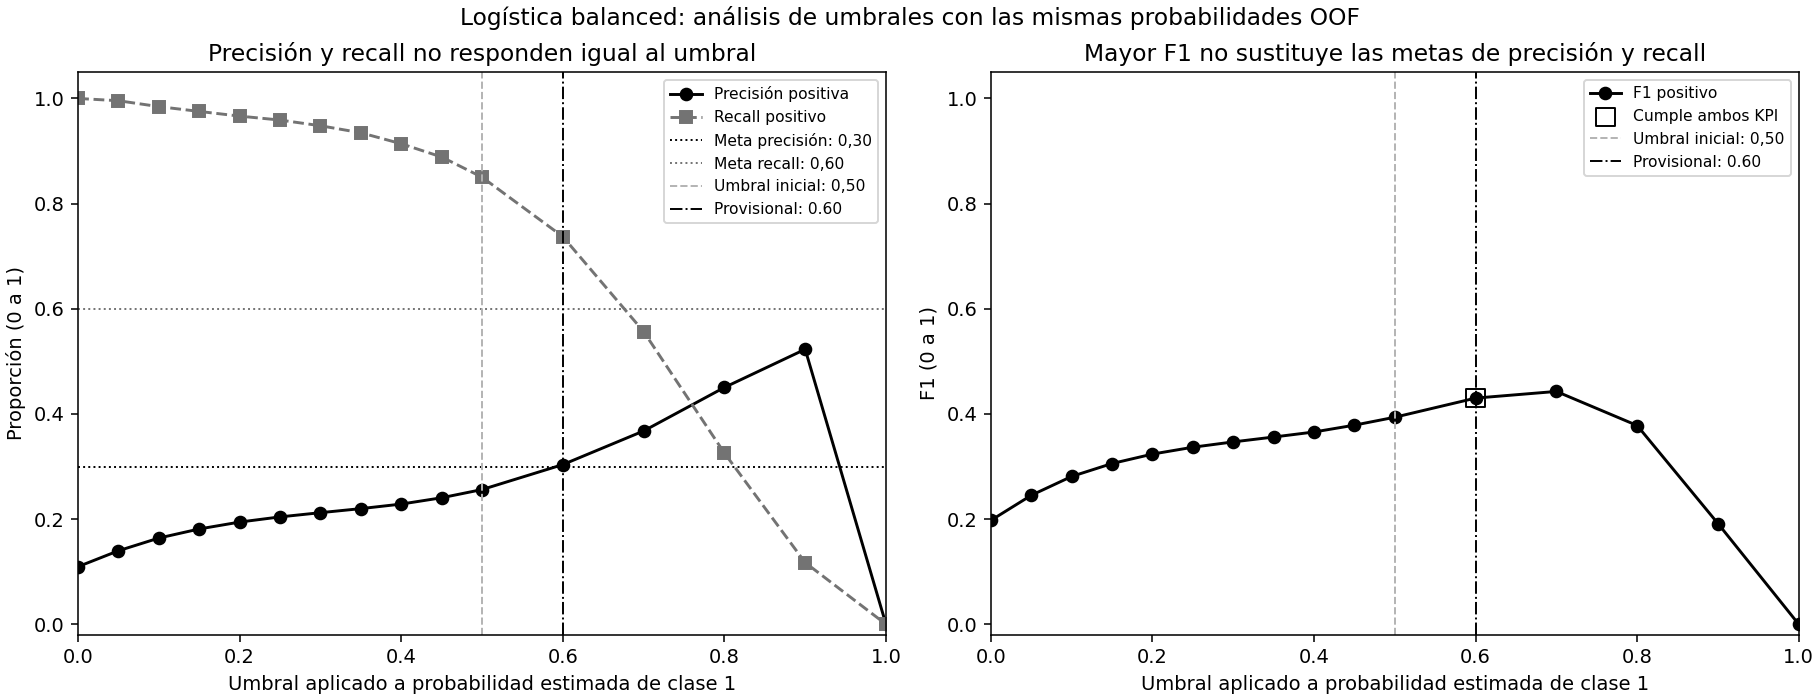

In [42]:
# Dibujar la compensación entre métricas con el modelo y sus probabilidades fijos
import matplotlib.pyplot as plt
fig_umbrales_balanced, ejes_umbrales_balanced = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
ejes_umbrales_balanced[0].plot(tabla_umbrales_balanced.index, tabla_umbrales_balanced["Precisión clase 1"], color="black", marker="o", label="Precisión positiva")
ejes_umbrales_balanced[0].plot(tabla_umbrales_balanced.index, tabla_umbrales_balanced["Recall clase 1"], color="0.45", linestyle="--", marker="s", label="Recall positivo")
ejes_umbrales_balanced[0].axhline(meta_precision_clasificacion, color="black", linestyle=":", linewidth=1, label="Meta precisión: 0,30")
ejes_umbrales_balanced[0].axhline(meta_recall_clasificacion, color="0.45", linestyle=":", linewidth=1, label="Meta recall: 0,60")
ejes_umbrales_balanced[0].set_title("Precisión y recall no responden igual al umbral")
ejes_umbrales_balanced[0].set_ylabel("Proporción (0 a 1)")
ejes_umbrales_balanced[1].plot(tabla_umbrales_balanced.index, tabla_umbrales_balanced["F1 clase 1"], color="black", marker="o", label="F1 positivo")
filas_elegibles_balanced = tabla_umbrales_balanced.loc[tabla_umbrales_balanced["Cumple ambos KPI"]]
ejes_umbrales_balanced[1].scatter(filas_elegibles_balanced.index, filas_elegibles_balanced["F1 clase 1"], marker="s", s=90, facecolors="none", edgecolors="black", label="Cumple ambos KPI")
ejes_umbrales_balanced[1].set_title("Mayor F1 no sustituye las metas de precisión y recall")
ejes_umbrales_balanced[1].set_ylabel("F1 (0 a 1)")
for eje in ejes_umbrales_balanced:
    eje.axvline(0.50, color="0.7", linestyle="--", linewidth=1, label="Umbral inicial: 0,50")
    if umbral_provisional_balanced is not None:
        eje.axvline(umbral_provisional_balanced, color="black", linestyle="-.", linewidth=1, label=f"Provisional: {umbral_provisional_balanced:.2f}")
    eje.set_xlim(0, 1)
    eje.set_ylim(-0.02, 1.05)
    eje.set_xlabel("Umbral aplicado a probabilidad estimada de clase 1")
    eje.legend(fontsize=8)
fig_umbrales_balanced.suptitle("Logística balanced: análisis de umbrales con las mismas probabilidades OOF")
display(fig_umbrales_balanced)
plt.close(fig_umbrales_balanced)


#### Conclusión del análisis de umbrales de balanced

**Umbral provisional de balanced: 0,60.** Precisión **30,37%**, recall **73,72%** y F1 **0,4301**. Cumple precisión >=30% y recall >=60% globalmente. Es el mayor F1 entre los elegibles de esta lista: **0,60**. No se afirma optimalidad sobre todos los valores posibles.

Frente al umbral 0,50, los TP pasan de **6.684 a 5.795**, los FN de **1.177 a 2.066** y los FP de **19.407 a 13.289**. Se señalan **19.084** canciones en vez de **26.091**. El **69,63% de las señaladas no cumple el corte real**, aunque se alcance la meta mínima de precisión.

- **Umbral 0,50: no cumple ambos KPI.** precisión 25,62% <30%: 19.407 falsas alarmas entre 26.091 canciones señaladas.
- **Umbral 0,70: no cumple ambos KPI.** recall 55,67% <60%: se detectan 4.376 de 7.861 positivas y se omiten 3.485.
- **Umbral 0,80: no cumple ambos KPI.** recall 32,57% <60%: se detectan 2.560 de 7.861 positivas y se omiten 5.301.

- **Ronda 1, umbral 0,60:** cumple ambos, con precisión 30,67% y recall 71,96%.
- **Ronda 2, umbral 0,60:** no cumple ambos KPI: precisión 29,65% <30%.
- **Ronda 3, umbral 0,60:** cumple ambos, con precisión 30,82% y recall 74,02%.

Los KPI se definieron sobre el conjunto OOF global; los incumplimientos por ronda se informan como variación, sin redondearlos a cumplimiento.

**Mayor F1 no basta:** 0,70 obtiene F1=0,4428, superior al 0,4301 de 0,60, pero su recall es 55,67% <60%. Por eso no es elegible aunque tenga el mayor F1 de la lista.

**Margen y estabilidad:** en 0,60 la precisión global supera la meta por apenas 0,37 puntos porcentuales. La ronda 2, con 29,65%, no se redondea a cumplimiento. El éxito global de desarrollo no implica que las tres particiones cumplan ni garantiza precisión mínima en datos nuevos.

**Por qué cambia el cumplimiento:** subir la exigencia sobre las probabilidades ponderadas puede reducir falsas alarmas, pero también excluye positivas verdaderas. Los conteos y denominadores explican el efecto observado. Un recall alto no compensa incumplir precisión, ni una precisión alta compensa incumplir recall. F1 sirve para comparar solo después de respetar ambas metas, según la regla fijada.

No se reducen metas ni se amplía la lista automáticamente en función de los resultados. Si no hubiera elegibles, la conclusión sería incumplimiento de los umbrales analizados, no imposibilidad para cualquier regla o modelo.

**Estado de esta elección:** análisis de desarrollo con las mismas probabilidades OOF ponderadas, sin nuevos ajustes, sin cambiar pesos o clases y sin consultar test. Una selección provisional deberá comprobarse separando elección y evaluación del umbral para **esta variante balanced**, usando agrupación también dentro de ajuste. No se presenta la validación anidada de la variante sin ponderar como evidencia de este umbral.


#### Validación anidada del umbral de la logística balanced

**Objetivo:** comprobar el procedimiento de elegir un umbral para la variante ponderada sin usar las respuestas de la validación externa para escogerlo. El 0,60 del análisis anterior cumplió globalmente, pero se escogió con esas mismas etiquetas OOF y su margen de precisión era pequeño. La validación anidada de la logística sin ponderar no confirma por sí sola esta nueva elección.

Se mantiene exactamente el protocolo ya establecido:

1. **Tres rondas externas agrupadas**, con los mismos IDs de entrenamiento y la misma clave artista + título.
2. **Tres rondas internas agrupadas dentro de cada ajuste externo**, con semilla 42 para distribuir claves. No se subdivide ni consulta test.
3. En cada ajuste interno se clona **la plantilla balanced**. El preprocesamiento aprende solo en ajuste interno. `class_weight="balanced"` calcula automáticamente los pesos a partir de **sus propias etiquetas de ajuste interno**, no de toda la base, ni del ajuste externo completo ni de validación. No se reutilizan manualmente pesos anteriores.
4. Se obtienen probabilidades OOF internas y se compara la misma lista de 16 umbrales, manteniendo recall >=60%, precisión >=30%, mayor F1 entre elegibles y desempate por umbral mayor.
5. Se fija el umbral de esa ronda sin sus respuestas externas. Si no hay elegible, se conserva el **respaldo 0,50**, igual que en el protocolo anterior; se declara la ausencia de candidato que cumpla y no se presenta el respaldo como éxito.
6. Se aplica ese umbral a las probabilidades externas de balanced ya guardadas. Proceden del modelo entrenado con todo el ajuste externo de la misma ronda, con sus pesos aprendidos solo allí. Así no se repiten tres ajustes externos idénticos.
7. Se reúnen las etiquetas externas para calcular métricas ordinarias, sin ponderar la validación ni cambiar su prevalencia.

**Son nueve ajustes internos nuevos**, no un cambio del modelo de regresión ni una búsqueda de otro C o de balanceo. Las características siguen siendo las 127 entradas sin artista. La popularidad real que define clase positiva permanece en >=60.

**Código, en orden:**

- Se verifica que la plantilla pasada a la selección tenga `class_weight="balanced"`, C=1, límite de 2.000 iteraciones y la misma tolerancia. Los pesos se recalculan dentro de cada llamada a `.fit` de esa plantilla.
- Se reutiliza `seleccionar_umbral_interno`, la función ya explicada en el apartado anterior: recibe solo X, etiquetas y claves del ajuste externo, la plantilla y las reglas. Al cambiar la plantilla a balanced, sus clones internos también serán balanced; no se duplica la función ni se repite su lógica.
- Las Series reservan una predicción y un umbral por ID. Las listas y diccionarios guardan decisiones y evidencia interna con nombres distintos de los de la variante sin ponderar.
- El bucle conserva la máscara externa existente. `.loc[~validar_externo]` entrega a la selección únicamente el ajuste externo; se verifica que no comparta claves con validación externa.
- La función devuelve umbral, elegibilidad, motivo, métricas internas y controles. Esas métricas sirven para elegir y no se confunden con las de la evaluación externa posterior.
- Solo después de elegir se consulta la **probabilidad externa** correspondiente y se convierte en etiqueta con `.ge(umbral_usado)`. No se utilizan respuestas externas en ese paso.
- Se comprueba una sola visita por ID, cobertura y etiquetas binarias. Las tablas muestran qué se eligió y los tamaños de los nueve ajustes internos, sin ocultar respaldos ni rondas difíciles.

Las respuestas externas se usan para evaluar en la siguiente celda. Este es un protocolo interno que separa elección y evaluación en cada ronda; **no es una muestra inédita**, porque el dataset y sus validaciones se observaron antes durante el desarrollo. No se cambian las reglas según sus nuevos resultados.


In [43]:
# Mantener la configuración de balanced en todos los clones internos
assert modelo_logistico_balanced_base.named_steps["clasificar"].class_weight == "balanced"
assert modelo_logistico_balanced_base.named_steps["clasificar"].C == 1.0
assert modelo_logistico_balanced_base.named_steps["clasificar"].max_iter == 2000
assert np.isclose(modelo_logistico_balanced_base.named_steps["clasificar"].tol, 1e-6)

# Reutilizar la función de selección con la plantilla balanced y sus probabilidades externas
assert probabilidades_balanced_oof.index.equals(y_clasificacion_train.index)
assert np.isfinite(probabilidades_balanced_oof).all()
predicciones_umbral_balanced_anidado_oof = pd.Series(index=y_clasificacion_train.index, dtype="float64")
umbral_balanced_asignado_por_id = pd.Series(index=y_clasificacion_train.index, dtype="float64")
visitas_externas_balanced_anidadas = pd.Series(0, index=y_clasificacion_train.index, dtype="int8")
selecciones_balanced_anidadas = []
controles_ajustes_balanced_internos = []
evidencia_interna_balanced_por_ronda = {}

for ronda_externa in range(numero_pliegues):
    validar_externo = pliegue_por_id.eq(ronda_externa)
    ajustar_externo = ~validar_externo
    claves_ajuste_externo = datos_entrenamiento.loc[ajustar_externo, "clave_cancion"]
    assert set(claves_ajuste_externo).isdisjoint(set(datos_entrenamiento.loc[validar_externo, "clave_cancion"]))
    umbral_usado, hubo_elegible, motivo, tabla_interna, controles_internos, prob_internas = seleccionar_umbral_interno(X_train.loc[ajustar_externo], y_clasificacion_train.loc[ajustar_externo], claves_ajuste_externo, modelo_logistico_balanced_base, umbrales_balanced, meta_recall_clasificacion, meta_precision_clasificacion)
    evidencia_interna_balanced_por_ronda[ronda_externa + 1] = {"Tabla de umbrales internos": tabla_interna, "Probabilidades internas": prob_internas}
    fila_interna = tabla_interna.loc[umbral_usado]
    selecciones_balanced_anidadas.append({"Ronda externa": ronda_externa + 1, "IDs ajuste externo": int(ajustar_externo.sum()), "IDs validación externa": int(validar_externo.sum()), "Umbral usado": umbral_usado, "Hubo umbral interno elegible": hubo_elegible, "Precisión interna (%)": fila_interna["Precisión clase 1"] * 100, "Recall interno (%)": fila_interna["Recall clase 1"] * 100, "F1 interno": fila_interna["F1 clase 1"], "Motivo": motivo})
    controles_internos["Ronda externa"] = ronda_externa + 1
    controles_ajustes_balanced_internos.append(controles_internos)
    predicciones_umbral_balanced_anidado_oof.loc[validar_externo] = probabilidades_balanced_oof.loc[validar_externo].ge(umbral_usado).astype("int8")
    umbral_balanced_asignado_por_id.loc[validar_externo] = umbral_usado
    visitas_externas_balanced_anidadas.loc[validar_externo] += 1
assert visitas_externas_balanced_anidadas.eq(1).all()
assert predicciones_umbral_balanced_anidado_oof.notna().all() and predicciones_umbral_balanced_anidado_oof.isin([0, 1]).all()
predicciones_umbral_balanced_anidado_oof = predicciones_umbral_balanced_anidado_oof.astype("int8")
tabla_seleccion_balanced_anidada = pd.DataFrame(selecciones_balanced_anidadas).set_index("Ronda externa")
tabla_controles_ajustes_balanced_internos = pd.concat(controles_ajustes_balanced_internos, ignore_index=True).set_index(["Ronda externa", "Ronda interna"])
display(tabla_seleccion_balanced_anidada.round(4))
display(tabla_controles_ajustes_balanced_internos)


,IDs ajuste externo,IDs validación externa,Umbral usado,Hubo umbral interno elegible,Precisión interna (%),Recall interno (%),F1 interno,Motivo
Ronda externa,,,,,,,,
1,47815,23913,0.6,True,30.7092,72.8324,0.4320,Mayor F1 interno entre umbrales que cumplen am...
2,47624,24104,0.6,True,30.7809,73.7133,0.4343,Mayor F1 interno entre umbrales que cumplen am...
3,48017,23711,0.6,True,30.0094,72.7582,0.4249,Mayor F1 interno entre umbrales que cumplen am...


IDs ajuste interno  ...  Iteraciones
Ronda externa Ronda interna                      ...             
1             1                           31862  ...          210
              2                           31854  ...          199
              3                           31914  ...          210
2             1                           31821  ...          204
              2                           31752  ...          202
              3                           31675  ...          199
3             1                           32108  ...          195
              2                           32047  ...          210
              3                           31879  ...          215

[9 rows x 4 columns]

#### Evaluar las decisiones externas de balanced y revisar los KPI

**Código, en orden:**

1. La matriz global utiliza una etiqueta externa por ID. Filas reales y columnas predichas mantienen `[[TN, FP], [FN, TP]]`. `resumir_clasificacion` calcula precisión, recall, F1 y accuracy sin pesos de evaluación.
2. La tabla por ronda registra umbral usado, TP, FN, FP y cumplimiento de cada meta. El umbral no se corrige después de conocer este resultado externo.
3. La comparación distingue balanced al 0,50 fijo, el 0,60 escogido con etiquetas OOF globales y la selección interna evaluada externamente. La fila de 0,60 anterior es evidencia de desarrollo, no una evaluación independiente de su elección.
4. La tabla de KPI conserva metas y controles metodológicos y actualiza precisión, recall y cobertura del **procedimiento anidado balanced**. Se mantiene separada de la tabla de la variante sin ponderar.
5. Se verifica que todas las observaciones estén en la matriz y que el recall global coincida con la suma de TP dividida por la suma de TP+FN. No se promedian porcentajes de rondas.

**Cómo interpretar un incumplimiento:** si recall queda por debajo de 60%, se informa cuántas positivas no se identifican; si precisión queda por debajo de 30%, se informa cuántas falsas alarmas hay entre las señaladas. Si una selección interna no encuentra un umbral elegible, también se declara y se mantiene el respaldo fijado, sin reinterpretarlo como selección exitosa.

Que alguna métrica mejore frente al 0,50 no basta para declarar cumplimiento. Se exige simultáneamente recall y precisión con los límites iniciales. Tampoco se reemplaza una ronda que falle por otra más favorable.


In [44]:
# Calcular la matriz global con predicciones externas del procedimiento anidado
matriz_umbral_balanced_anidado, resumen_umbral_balanced_anidado = resumir_clasificacion(y_clasificacion_train, predicciones_umbral_balanced_anidado_oof)
display(pd.DataFrame(matriz_umbral_balanced_anidado, index=["Real 0: <60", "Real 1: >=60"], columns=["Predice 0: <60", "Predice 1: >=60"]).rename_axis("Balanced: selección interna de umbral y evaluación externa"))
registros_evaluacion_balanced_anidada = []
for ronda_externa in range(numero_pliegues):
    en_externa = pliegue_por_id.eq(ronda_externa)
    _, metricas_externas = resumir_clasificacion(y_clasificacion_train.loc[en_externa], predicciones_umbral_balanced_anidado_oof.loc[en_externa])
    registros_evaluacion_balanced_anidada.append({"Ronda externa": ronda_externa + 1, "Umbral usado": float(tabla_seleccion_balanced_anidada.loc[ronda_externa + 1, "Umbral usado"]), "IDs": int(en_externa.sum()), "TP": metricas_externas["TP"], "FN": metricas_externas["FN"], "FP": metricas_externas["FP"], "Precisión (%)": metricas_externas["Precisión clase 1"] * 100, "Recall (%)": metricas_externas["Recall clase 1"] * 100, "F1": metricas_externas["F1 clase 1"], "Cumple precisión": bool(metricas_externas["Precisión positiva definida"] and metricas_externas["Precisión clase 1"] >= meta_precision_clasificacion), "Cumple recall": bool(metricas_externas["Recall clase 1"] >= meta_recall_clasificacion)})
tabla_evaluacion_balanced_anidada = pd.DataFrame(registros_evaluacion_balanced_anidada).set_index("Ronda externa")

# Comparar alcances de evaluación, sin elegir otro protocolo por su resultado
fila_inicial = tabla_metricas_balanced_oof.loc["Balanced, umbral 0.50"]
fila_global_balanced_060 = tabla_umbrales_balanced.loc[0.60]
comparacion_protocolos_umbral_balanced = pd.DataFrame([
    {"Protocolo": "Balanced 0,50 fijado antes del análisis", "Precisión (%)": fila_inicial["Precisión clase 1"] * 100, "Recall (%)": fila_inicial["Recall clase 1"] * 100, "F1": fila_inicial["F1 clase 1"], "Alcance": "Predicciones OOF con umbral inicial fijo"},
    {"Protocolo": "Balanced 0,60 escogido con etiquetas OOF globales", "Precisión (%)": fila_global_balanced_060["Precisión clase 1"] * 100, "Recall (%)": fila_global_balanced_060["Recall clase 1"] * 100, "F1": fila_global_balanced_060["F1 clase 1"], "Alcance": "Desarrollo del umbral sobre etiquetas utilizadas para escogerlo"},
    {"Protocolo": "Balanced: selección interna y evaluación externa agrupadas", "Precisión (%)": resumen_umbral_balanced_anidado["Precisión clase 1"] * 100, "Recall (%)": resumen_umbral_balanced_anidado["Recall clase 1"] * 100, "F1": resumen_umbral_balanced_anidado["F1 clase 1"], "Alcance": "Validación interna adicional con elección y evaluación separadas"}
]).set_index("Protocolo")
tabla_kpi_umbral_balanced_anidado = tabla_kpi_balanced_oof.copy(deep=True)
for indicador, valor, cumple in [
    ("Recall clase 1", resumen_umbral_balanced_anidado["Recall clase 1"] * 100, resumen_umbral_balanced_anidado["Recall clase 1"] >= meta_recall_clasificacion),
    ("Precisión clase 1", resumen_umbral_balanced_anidado["Precisión clase 1"] * 100, resumen_umbral_balanced_anidado["Precisión positiva definida"] and resumen_umbral_balanced_anidado["Precisión clase 1"] >= meta_precision_clasificacion),
    ("Cobertura de predicciones OOF", float(visitas_externas_balanced_anidadas.eq(1).mean() * 100), visitas_externas_balanced_anidadas.eq(1).all())
]:
    tabla_kpi_umbral_balanced_anidado.loc[indicador, "Resultado"] = valor
    tabla_kpi_umbral_balanced_anidado.loc[indicador, "Estado"] = "Cumple" if cumple else "No cumple"
assert int(matriz_umbral_balanced_anidado.sum()) == len(y_clasificacion_train)
assert np.isclose(resumen_umbral_balanced_anidado["Recall clase 1"], tabla_evaluacion_balanced_anidada["TP"].sum() / (tabla_evaluacion_balanced_anidada["TP"].sum() + tabla_evaluacion_balanced_anidada["FN"].sum()))
display(pd.Series(resumen_umbral_balanced_anidado))
display(tabla_evaluacion_balanced_anidada.round(4))
display(comparacion_protocolos_umbral_balanced.round(4))
display(tabla_kpi_umbral_balanced_anidado.round({"Resultado": 4}))


,Predice 0: <60,Predice 1: >=60
Balanced: selección interna de umbral y evaluación externa,,
Real 0: <60,50578,13289
Real 1: >=60,2066,5795


IDs                               71728
TN                                50578
FP                                13289
FN                                 2066
TP                                 5795
Positivos predichos               19084
Precisión positiva definida        True
Precisión clase 1              0.303658
Recall clase 1                 0.737184
F1 clase 1                     0.430135
Accuracy                       0.785927
dtype: object

,Umbral usado,IDs,TP,FN,FP,Precisión (%),Recall (%),F1,Cumple precisión,Cumple recall
Ronda externa,,,,,,,,,,
1,0.6,23913,1922,749,4345,30.6686,71.9581,0.4301,True,True
2,0.6,24104,1967,648,4666,29.6548,75.2199,0.4254,False,True
3,0.6,23711,1906,669,4278,30.8215,74.0194,0.4352,True,True


,Precisión (%),Recall (%),F1,Alcance
Protocolo,,,,
"Balanced 0,50 fijado antes del análisis",25.6180,85.0274,0.3937,Predicciones OOF con umbral inicial fijo
"Balanced 0,60 escogido con etiquetas OOF globales",30.3658,73.7184,0.4301,Desarrollo del umbral sobre etiquetas utilizad...
Balanced: selección interna y evaluación externa agrupadas,30.3658,73.7184,0.4301,Validación interna adicional con elección y ev...


,Meta,Resultado,Unidad,Estado
KPI,,,,
Recall clase 1,>= 60%,73.7184,%,Cumple
Precisión clase 1,>= 30%,30.3658,%,Cumple
Etiquetas válidas y alineadas,100%,100.0000,%,Cumple
Claves compartidas ajuste/validación,0 en cada ronda,0.0000,Máximo de claves compartidas por ronda,Cumple
Cobertura de predicciones OOF,100%,100.0000,%,Cumple


#### Conclusión de la validación anidada de balanced

El procedimiento anidado de balanced obtiene **precisión 30,37%**, **recall 73,72%** y **F1 0,4301** sobre las 71.728 etiquetas externas. TN=50.578, FP=13.289, FN=2.066, TP=5.795.

**Decisiones internas:**

- **Ronda externa 1:** umbral usado 0,60; precisión interna 30,71% y recall interno 72,83%. Se encontró candidato interno que cumple ambas metas y se eligió por F1.
- **Ronda externa 2:** umbral usado 0,60; precisión interna 30,78% y recall interno 73,71%. Se encontró candidato interno que cumple ambas metas y se eligió por F1.
- **Ronda externa 3:** umbral usado 0,60; precisión interna 30,01% y recall interno 72,76%. Se encontró candidato interno que cumple ambas metas y se eligió por F1.

**Evaluación externa por ronda:**

- **Ronda externa 1:** cumple ambos: precisión 30,67% y recall 71,96%.
- **Ronda externa 2:** no cumple ambos KPI; precisión 29,65% <30%: 4.666 falsas alarmas entre 6.633 señaladas.
- **Ronda externa 3:** cumple ambos: precisión 30,82% y recall 74,02%.

**KPI globales:**

- **Precisión cumple:** 30,37% >=30%.
- **Recall cumple:** 73,72% >=60%; detecta 5.795 de las 7.861 positivas.
- Los controles de etiquetas, separación agrupada y cobertura externa del 100% se mantienen. Estos controles no compensan un KPI predictivo incumplido.

Las tres selecciones internas eligieron 0,60. Por eso las etiquetas externas y métricas coinciden con el análisis anterior. La evidencia adicional está en cómo se eligió el umbral; no son dos pruebas independientes con muestras diferentes.

**Margen de cumplimiento:** la precisión global supera el mínimo por solo 0,37 puntos porcentuales. En la selección interna de la ronda externa 3, la precisión fue 30,0094%, apenas por encima del límite. No se redondea el 29,65% de la evaluación externa de ronda 2 a un cumplimiento. Estas diferencias muestran por qué hay que conservar las cifras y reportar la variación.

**Lectura del alcance:** el resultado evalúa la regla completa de aprender balanced, seleccionar un umbral dentro de ajuste y aplicarlo a otras canciones de la misma partición de entrenamiento. Puede usar umbrales distintos por ronda; no certifica un valor único para cualquier población. Si hay respaldos, forman parte del procedimiento evaluado y no se excluyen para calcular mejores métricas.

Los resultados no identifican causas musicales o sociales de los errores. La ausencia de un umbral elegible se refiere a la lista y las subdivisiones internas utilizadas, no prueba que ningún otro procedimiento pueda funcionar. Si alguna meta falla, permanece documentada: no se amplía la lista ni se bajan los KPI después de ver esta evaluación.

Se conservaron la logística sin artista, ponderación balanced, C=1, los mismos 16 umbrales y las mismas metas. Los pesos se calcularon en cada ajuste interno por el propio clasificador. La validación conservó su distribución original y sus métricas ordinarias. **No se consultó test para clasificación.**

Esta comprobación sigue siendo interna sobre una fuente y particiones previamente exploradas. No se declara que el dataset sea una prueba externa independiente ni se cambia el procedimiento por el resultado observado.


#### Comparación de las dos logísticas con selección anidada del umbral

**Pregunta:** con la regla de evaluación más estricta que ya aplicamos, ¿qué procedimiento conviene conservar provisionalmente?

Se comparan **dos procedimientos completos**, ambos sin artista y con la misma logística base: uno aprende sin ponderación y otro con `class_weight="balanced"`. Cada uno elige umbral con validación interna agrupada y se evalúa en las mismas validaciones externas. No se compara el mejor resultado exploratorio de uno con el resultado anidado del otro.

**Regla de elección conservada:** primero exigir recall >=60% y precisión >=30% **globales**; entre los procedimientos que los cumplan, elegir el mayor F1 positivo. Si ninguno cumple, declarar que no hay procedimiento elegible. No se cambia la prioridad a accuracy o solo recall después de ver cuál mejora.

La comparación es posible porque ambas variantes utilizan los mismos 71.728 IDs, las mismas etiquetas reales y los mismos tres pliegues externos. Las diferencias de umbral son parte del procedimiento: no tiene sentido exigirles el mismo valor numérico después de que sus probabilidades cambiaron con la ponderación. Aquí evaluamos **modelo + regla de selección del umbral**, no solo el efecto aislado de `class_weight`; ese efecto ya se estudió con ambas variantes en 0,50.

**Código, en orden:**

1. Los diccionarios reúnen las **etiquetas externas anidadas**, tablas de selección y plantillas. No se entrenan modelos ni se vuelven a calcular probabilidades.
2. Para cada variante se comprueba el mismo índice y etiquetas válidas. `resumir_clasificacion` recalcula matriz y métricas sobre las mismas respuestas, sin pesos de evaluación. Las metas originales generan las columnas de cumplimiento.
3. Los umbrales por ronda y la cantidad de respaldos 0,50 documentan lo que realmente hizo cada procedimiento; un respaldo no se interpreta como candidato interno exitoso.
4. El bucle por ronda vuelve a calcular métricas con la máscara externa existente. Las tablas incluyen conteos y cumplimiento por partición, sin promediar porcentajes para producir el resultado global.
5. `sort_values` ordena elegibles por F1 descendente. La selección es provisional; si hubiera empate exacto habría que documentar una decisión adicional, sin afirmar superioridad por un orden accidental. En estos resultados no hay empate.
6. La copia de lectura multiplica precisión, recall y accuracy por cien y conserva F1 entre 0 y 1. Se mantiene precisión completa para comparar metas. La tabla de conteos separa TP, FN, FP y TN para hacer visible el costo de la elección.
7. Se contrastan las métricas recalculadas con los resúmenes anidados guardados; esto evita mezclar resultados de umbral fijo o exploratorio con la validación anidada.

Aunque exista un orden de F1, solo hay tres particiones y sus ajustes se solapan entre rondas. No se presenta una prueba estadística de superioridad ni se describe esta comparación sobre datos ya explorados como evaluación externa inédita.


In [45]:
# Reunir solo los resultados de ambos procedimientos anidados
predicciones_comparacion_anidada = {"Sin ponderación": predicciones_umbral_anidado_oof, "Balanced": predicciones_umbral_balanced_anidado_oof}
selecciones_comparacion_anidada = {"Sin ponderación": tabla_seleccion_anidada, "Balanced": tabla_seleccion_balanced_anidada}
plantillas_comparacion_clasificacion = {"Sin ponderación": modelo_logistico_base, "Balanced": modelo_logistico_balanced_base}
registros_comparacion_anidada = []
registros_comparacion_rondas = []
for variante, pred in predicciones_comparacion_anidada.items():
    assert pred.index.equals(y_clasificacion_train.index)
    assert pred.notna().all() and pred.isin([0, 1]).all()
    _, resumen = resumir_clasificacion(y_clasificacion_train, pred)
    cumple_precision = resumen["Precisión positiva definida"] and resumen["Precisión clase 1"] >= meta_precision_clasificacion
    cumple_recall = resumen["Recall clase 1"] >= meta_recall_clasificacion
    seleccion = selecciones_comparacion_anidada[variante]
    registros_comparacion_anidada.append({"Variante": variante, **resumen, "Cumple precisión": bool(cumple_precision), "Cumple recall": bool(cumple_recall), "Cumple ambos KPI": bool(cumple_precision and cumple_recall), "Umbrales por ronda": seleccion["Umbral usado"].to_dict(), "Rondas con respaldo": int((~seleccion["Hubo umbral interno elegible"]).sum())})
    for ronda in range(numero_pliegues):
        en_ronda = pliegue_por_id.eq(ronda)
        _, resultado_ronda = resumir_clasificacion(y_clasificacion_train.loc[en_ronda], pred.loc[en_ronda])
        precision_cumple = resultado_ronda["Precisión positiva definida"] and resultado_ronda["Precisión clase 1"] >= meta_precision_clasificacion
        recall_cumple = resultado_ronda["Recall clase 1"] >= meta_recall_clasificacion
        registros_comparacion_rondas.append({"Variante": variante, "Ronda externa": ronda + 1, "Umbral usado": float(seleccion.loc[ronda + 1, "Umbral usado"]), "IDs": resultado_ronda["IDs"], "TP": resultado_ronda["TP"], "FN": resultado_ronda["FN"], "FP": resultado_ronda["FP"], "Precisión (%)": resultado_ronda["Precisión clase 1"] * 100, "Recall (%)": resultado_ronda["Recall clase 1"] * 100, "F1": resultado_ronda["F1 clase 1"], "Cumple precisión": bool(precision_cumple), "Cumple recall": bool(recall_cumple), "Cumple ambos KPI": bool(precision_cumple and recall_cumple)})
comparacion_logisticas_anidadas = pd.DataFrame(registros_comparacion_anidada).set_index("Variante")
comparacion_logisticas_anidadas_rondas = pd.DataFrame(registros_comparacion_rondas).set_index(["Variante", "Ronda externa"])
elegibles_logisticas_anidadas = comparacion_logisticas_anidadas.loc[comparacion_logisticas_anidadas["Cumple ambos KPI"]].sort_values("F1 clase 1", ascending=False, kind="stable")
variante_provisional_clasificacion = None if elegibles_logisticas_anidadas.empty else elegibles_logisticas_anidadas.index[0]
lectura_comparacion_anidada = comparacion_logisticas_anidadas[["Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy", "Cumple precisión", "Cumple recall", "Cumple ambos KPI"]].copy()
for metrica in ["Precisión clase 1", "Recall clase 1", "Accuracy"]:
    lectura_comparacion_anidada[metrica] *= 100
lectura_comparacion_anidada = lectura_comparacion_anidada.rename(columns={"Precisión clase 1": "Precisión (%)", "Recall clase 1": "Recall (%)", "Accuracy": "Accuracy (%)"})
for variante, resumen_previo in {"Sin ponderación": resumen_umbral_anidado, "Balanced": resumen_umbral_balanced_anidado}.items():
    for metrica in ["Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy"]:
        assert np.isclose(comparacion_logisticas_anidadas.loc[variante, metrica], resumen_previo[metrica])
assert comparacion_logisticas_anidadas["IDs"].eq(len(y_clasificacion_train)).all()
display(lectura_comparacion_anidada.round(4))
display(comparacion_logisticas_anidadas[["TP", "FN", "FP", "TN", "Positivos predichos", "Umbrales por ronda", "Rondas con respaldo"]])
display(comparacion_logisticas_anidadas_rondas.round(4))


,Precisión (%),Recall (%),F1 clase 1,Accuracy (%),Cumple precisión,Cumple recall,Cumple ambos KPI
Variante,,,,,,,
Sin ponderación,34.6759,61.1118,0.4425,83.1210,True,True,True
Balanced,30.3658,73.7184,0.4301,78.5927,True,True,True


,TP,FN,FP,TN,Positivos predichos,Umbrales por ronda,Rondas con respaldo
Variante,,,,,,,
Sin ponderación,4804,3057,9050,54817,13854,"{1: 0.2, 2: 0.2, 3: 0.2}",0
Balanced,5795,2066,13289,50578,19084,"{1: 0.6, 2: 0.6, 3: 0.6}",0


Umbral usado  ...  Cumple ambos KPI
Variante        Ronda externa                ...                  
Sin ponderación 1                       0.2  ...             False
                2                       0.2  ...              True
                3                       0.2  ...              True
Balanced        1                       0.6  ...              True
                2                       0.6  ...             False
                3                       0.6  ...              True

[6 rows x 11 columns]

#### Elección provisional y cierre de KPI de esta comparación

**Elección provisional: logística sin ponderación, con selección interna agrupada del umbral.** Ambos procedimientos cumplen globalmente las dos metas. Se elige sin ponderación por su F1 **0,4425**, superior al **0,4301** de balanced. Su precisión es **34,68%** y su recall **61,11%**. La diferencia de F1 es **0,0123**; no se interpreta por sí sola como superioridad estadística.

Balanced tiene mayor recall: **73,72%** frente a **61,11%**, y detecta **991 positivas más en total**. A cambio, acumula **4.239 falsas alarmas más**: 13.289 frente a 9.050. Su precisión es **30,37%**, inferior al **34,68%** de la variante elegida. Estas son diferencias netas de conteos; no se afirma que todas las canciones detectadas por una variante estén incluidas en las de la otra.

- **Sin ponderación, ronda 1: no cumple ambos KPI**; recall 59,08% <60%: omite 1.093 de las positivas de esa ronda.
- **Balanced, ronda 2: no cumple ambos KPI**; precisión 29,65% <30%: 4.666 falsas alarmas entre 6.633 señaladas.
Ambas variantes cumplen las dos metas en **2 de 3 rondas**. Ninguna muestra cumplimiento uniforme por partición. Sin ponderación tiene recall global cercano al mínimo y balanced tiene precisión global cercana al mínimo; no se ocultan esas fragilidades.

**Justificación según el objetivo fijado:** identificar positivas requiere atender recall, pero habíamos acordado no escoger solo por esa métrica. Se mantiene precisión mínima del 30% y se utiliza F1 para equilibrar las dos entre candidatos globalmente elegibles. La decisión es académica y provisional: no contamos con costos de revisión o de omisiones que justifiquen reemplazar ese criterio por otro ahora.

**Código, en orden:**

- Se calcula `balanced − sin ponderación` para mostrar diferencias de precisión, recall, F1 y conteos. Las diferencias de porcentajes se expresan en **puntos porcentuales**; F1 y cantidades conservan sus unidades.
- Si existe una elegible, se toma su fila y se copia la tabla de KPI correspondiente a su **validación anidada**. Se comprueba el cumplimiento sin redondear y se conserva evidencia metodológica.
- `get_params()` registra la configuración de la plantilla elegida sin entrenarla. La especificación identifica ponderación, características, protocolo de umbral y alcance; no guarda un clasificador final ajustado con todo entrenamiento.
- Se mantienen todos los resultados de la otra variante, incluido su mayor recall cuando corresponda. No se borran errores o rondas para sostener la elección.

**Qué significa el umbral observado:** la variante sin ponderar eligió 0,20 en sus tres selecciones internas y balanced eligió 0,60. Estos valores describen lo ocurrido; una evaluación anidada valida el proceso de selección, no demuestra que ese número sea universal. La elección del procedimiento entre dos variantes usando esta misma evidencia es otra decisión de desarrollo y no constituye una comprobación independiente final.

Si no existiera un candidato que cumpla ambos KPI, la conclusión sería «sin elección elegible», sin pasar a declarar ganador al de mayor accuracy o recall. No se cambia ninguna meta para obtener éxito.


In [46]:
# Mostrar la compensación de balanced respecto de la variante sin ponderar
fila_comparacion_sin = comparacion_logisticas_anidadas.loc["Sin ponderación"]
fila_comparacion_balanced = comparacion_logisticas_anidadas.loc["Balanced"]
diferencias_logisticas_anidadas = pd.Series({
    "Precisión: balanced − sin ponderación (puntos porcentuales)": (fila_comparacion_balanced["Precisión clase 1"] - fila_comparacion_sin["Precisión clase 1"]) * 100,
    "Recall: balanced − sin ponderación (puntos porcentuales)": (fila_comparacion_balanced["Recall clase 1"] - fila_comparacion_sin["Recall clase 1"]) * 100,
    "F1: balanced − sin ponderación": fila_comparacion_balanced["F1 clase 1"] - fila_comparacion_sin["F1 clase 1"],
    "TP: balanced − sin ponderación (IDs)": int(fila_comparacion_balanced["TP"] - fila_comparacion_sin["TP"]),
    "FP: balanced − sin ponderación (IDs)": int(fila_comparacion_balanced["FP"] - fila_comparacion_sin["FP"])
})
especificacion_provisional_clasificacion = None
tabla_kpi_eleccion_clasificacion = None
if variante_provisional_clasificacion is None:
    display("Ninguno de los dos procedimientos cumple ambas metas globales: no hay elección provisional elegible.")
else:
    fila_elegida_clasificacion = comparacion_logisticas_anidadas.loc[variante_provisional_clasificacion]
    assert bool(fila_elegida_clasificacion["Cumple ambos KPI"])
    tablas_kpi_candidatas = {"Sin ponderación": tabla_kpi_umbral_anidado, "Balanced": tabla_kpi_umbral_balanced_anidado}
    tabla_kpi_eleccion_clasificacion = tablas_kpi_candidatas[variante_provisional_clasificacion].copy(deep=True)
    assert np.isclose(tabla_kpi_eleccion_clasificacion.loc["Recall clase 1", "Resultado"], fila_elegida_clasificacion["Recall clase 1"] * 100)
    assert np.isclose(tabla_kpi_eleccion_clasificacion.loc["Precisión clase 1", "Resultado"], fila_elegida_clasificacion["Precisión clase 1"] * 100)
    especificacion_provisional_clasificacion = {
        "Variante elegida": variante_provisional_clasificacion,
        "Modelo": "Regresión logística sin artista",
        "Criterio": "Mayor F1 positivo entre quienes cumplen ambas metas globales",
        "Preparación": "Diez medidas, tres categorías y 114 géneros; aprendida dentro de cada ajuste",
        "Parámetros del estimador": plantillas_comparacion_clasificacion[variante_provisional_clasificacion].named_steps["clasificar"].get_params(),
        "Selección de umbral": "Tres particiones internas agrupadas; misma lista de 16; elegibilidad y mayor F1; respaldo 0,50 si no hay elegible",
        "Umbrales observados por ronda externa": fila_elegida_clasificacion["Umbrales por ronda"],
        "Alcance": "Elección provisional de desarrollo; no modelo final ajustado ni evaluación de clasificación en test"
    }
    display(tabla_kpi_eleccion_clasificacion.round({"Resultado": 4}))
    display(pd.Series(especificacion_provisional_clasificacion))
display(diferencias_logisticas_anidadas.round(4))


,Meta,Resultado,Unidad,Estado
KPI,,,,
Recall clase 1,>= 60%,61.1118,%,Cumple
Precisión clase 1,>= 30%,34.6759,%,Cumple
Etiquetas válidas y alineadas,100%,100.0000,%,Cumple
Claves compartidas ajuste/validación,0 en cada ronda,0.0000,Máximo de claves compartidas por ronda,Cumple
Cobertura de predicciones OOF,100%,100.0000,%,Cumple


Variante elegida                                                           Sin ponderación
Modelo                                                     Regresión logística sin artista
Criterio                                 Mayor F1 positivo entre quienes cumplen ambas ...
Preparación                              Diez medidas, tres categorías y 114 géneros; a...
Parámetros del estimador                 {'C': 1.0, 'class_weight': None, 'dual': False...
Selección de umbral                      Tres particiones internas agrupadas; misma lis...
Umbrales observados por ronda externa                             {1: 0.2, 2: 0.2, 3: 0.2}
Alcance                                  Elección provisional de desarrollo; no modelo ...
dtype: object

Precisión: balanced − sin ponderación (puntos porcentuales)      -4.3102
Recall: balanced − sin ponderación (puntos porcentuales)         12.6065
F1: balanced − sin ponderación                                   -0.0123
TP: balanced − sin ponderación (IDs)                            991.0000
FP: balanced − sin ponderación (IDs)                           4239.0000
dtype: float64

#### Conclusión de la comparación provisional de clasificación

Se conserva provisionalmente **sin ponderación** conforme a la regla acordada: ambas metas globales y luego mayor F1. Sus KPI predictivos son **precisión 34,68% >=30%** y **recall 61,11% >=60%**. Se mantienen etiquetas válidas, cero claves compartidas y cobertura de predicciones externas del 100%. En sus tres selecciones internas se observó umbral **0,20**; la especificación registra el proceso de selección y no lo sustituye por una elección basada en test.

La elección no elimina los errores: en la variante seleccionada persisten falsos negativos y falsas alarmas, y el cumplimiento global no se reproduce en todas las rondas. No se declara superioridad estadística ni se cambia a una prioridad distinta después de ver los resultados.

Se conservaron las mismas canciones, tres particiones externas agrupadas, tres internas por ajuste, lista de umbrales, reglas de respaldo y métricas ordinarias. La ponderación y su efecto en la selección interna distinguen ambos procedimientos. No hubo nuevos ajustes ni consultas a test para esta comparación.

**Estado:** procedimiento de clasificación elegido provisionalmente conforme al criterio acordado; evidencia y limitaciones documentadas. La comparación entre variantes forma parte del desarrollo sobre validaciones ya exploradas y no equivale a una confirmación final independiente. No se ajusta aquí una versión única con todo entrenamiento ni se utiliza test de clasificación.


<a id="clasificacion-arbol-sin-artista"></a>
### 9.2.2. Árbol de decisión clasificador sin artista


#### Árbol de decisión clasificador: nueva comparación solo en entrenamiento

**Objetivo:** aprender reglas que identifiquen clase 1, popularidad >=60, con las mismas 127 entradas sin artista. Este es un **clasificador nuevo**, no el árbol de regresión ya utilizado: aquel estimaba un puntaje; este estima la proporción de clase positiva en una hoja y la convierte en etiqueta.

La evaluación final de la logística en test permanece como evidencia de su procedimiento anterior. Este árbol es una ampliación de desarrollo posterior: **no se calcula ni se consulta su desempeño en test** y no se presenta ese conjunto ya observado como una muestra nueva para elegirlo.

| Decisión fijada para el primer árbol | Significado |
|---|---|
| `criterion="gini"` | Elige divisiones que reduzcan la mezcla de clases. Gini es un criterio de aprendizaje, no un porcentaje de acierto |
| `max_depth=4` | Como máximo cuatro divisiones desde la raíz hasta una hoja |
| `min_samples_leaf=50` | Cada hoja debe contener al menos 50 IDs de ajuste |
| `class_weight=None` | Sin ponderación de clases para esta comparación inicial |
| `random_state=42` | Reproduce la aleatoriedad de búsqueda/desempate del árbol |
| Umbral de probabilidad `0.50` | Señala clase 1 cuando la proporción positiva estimada en la hoja es >=0,50; la igualdad exacta se resuelve como clase 1 |

La profundidad 4 y hoja mínima 50 mantienen un árbol sencillo, en continuidad con el ejemplo de regresión. Son una configuración inicial, **no los mejores parámetros demostrados**. No se ajustan después de observar su error. Un árbol puede terminar con menos de 16 hojas, porque no todas las ramas deben dividirse hasta profundidad 4.

**Cómo predice:** las reglas llevan una canción hasta una hoja; sin pesos, la probabilidad positiva de esa hoja es `positivas de ajuste en la hoja / IDs de ajuste de la hoja`. Es una estimación del modelo, no una garantía de frecuencia real. Si ninguna hoja supera o alcanza 0,50, el árbol puede predecir únicamente clase 0. Eso debe informarse, no corregirse silenciosamente.

**Preparación:** se clona la misma del lineal/logística: imputación y escalamiento de medidas, codificación categórica y géneros Multi-Hot. El escalamiento no es necesario para un árbol, pero se conserva para facilitar la comparación con entradas equivalentes; sus parámetros se aprenden solo con ajuste. No se usa popularidad como característica, la etiqueta, artista, clave ni predicciones finales anteriores.

**Código, en orden:**

1. Se importa `DecisionTreeClassifier` y se construye una plantilla `Pipeline` con preparación y clasificador. El nombre `modelo_arbol_clasificador_base` lo distingue del árbol de regresión.
2. Las Series reservan probabilidades y etiquetas por ID; las visitas cuentan cobertura. El diccionario guarda un modelo por ronda y la lista sus controles.
3. El bucle reutiliza `pliegue_por_id`. `.eq` selecciona validación y `~` el ajuste; `.loc` conserva alineación. Se comprueba separación de claves y que ajuste tenga ambas clases.
4. `clone` crea un árbol limpio. `.fit` aprende preparación y reglas solo con ajuste. `.predict_proba` obtiene la columna de clase 1 identificada mediante `classes_`; `.ge(0.50)` aplica la misma regla numérica que la logística inicial.
5. Se verifican medianas y filas vistas por el escalador. `get_depth` y `get_n_leaves` registran estructura; el mínimo de `n_node_samples` en nodos hoja comprueba la restricción de 50.
6. Los controles OOF verifican índices, rango de probabilidades y una predicción por ID; solo después se convierten las etiquetas a `int8`.
7. Para entender las probabilidades se inspecciona el **primer ajuste**, no el de mejor error. `.transform` aplica su preparación ya aprendida y `.apply` devuelve la hoja de cada canción de ajuste. `groupby` cuenta IDs, suma positivas y calcula su proporción por hoja. Se muestran las seis hojas con mayor proporción para explicar el mecanismo, sin usarlas para elegir parámetros o validar el modelo.

Referencia del componente: [DecisionTreeClassifier en scikit-learn 1.6](https://scikit-learn.org/1.6/modules/generated/sklearn.tree.DecisionTreeClassifier.html).


In [50]:
# Definir un clasificador sencillo, sin ponderación y con umbral fijo
from sklearn.tree import DecisionTreeClassifier
umbral_arbol_clasificador = 0.50
modelo_arbol_clasificador_base = Pipeline([
    ("preparar", clone(preprocesador_lineal)),
    ("clasificar", DecisionTreeClassifier(criterion="gini", max_depth=4, min_samples_leaf=50, class_weight=None, random_state=42))
])
probabilidades_arbol_clasificador_oof = pd.Series(index=y_clasificacion_train.index, dtype="float64", name="probabilidad_arbol_clasificador_oof")
predicciones_arbol_clasificador_oof = pd.Series(index=y_clasificacion_train.index, dtype="float64", name="etiqueta_arbol_clasificador_oof")
visitas_arbol_clasificador = pd.Series(0, index=y_clasificacion_train.index, dtype="int8")
modelos_arbol_clasificador_por_ronda = {}
registros_arbol_clasificador = []
assert all(columna not in X_train.columns for columna in columnas_prohibidas_clasificacion)

for ronda in range(numero_pliegues):
    validar_arbol_clasificador = pliegue_por_id.eq(ronda)
    ajustar_arbol_clasificador = ~validar_arbol_clasificador
    assert set(datos_entrenamiento.loc[ajustar_arbol_clasificador, "clave_cancion"]).isdisjoint(set(datos_entrenamiento.loc[validar_arbol_clasificador, "clave_cancion"]))
    X_ajuste_arbol_clasificador = X_train.loc[ajustar_arbol_clasificador]
    y_ajuste_arbol_clasificador = y_clasificacion_train.loc[ajustar_arbol_clasificador]
    assert y_ajuste_arbol_clasificador.nunique() == 2
    modelo_arbol_clasificador = clone(modelo_arbol_clasificador_base)
    modelo_arbol_clasificador.fit(X_ajuste_arbol_clasificador, y_ajuste_arbol_clasificador)
    clasificador_arbol = modelo_arbol_clasificador.named_steps["clasificar"]
    columna_positiva_arbol = list(clasificador_arbol.classes_).index(1)
    probabilidades_ronda_arbol = modelo_arbol_clasificador.predict_proba(X_train.loc[validar_arbol_clasificador])[:, columna_positiva_arbol]
    probabilidades_arbol_clasificador_oof.loc[validar_arbol_clasificador] = probabilidades_ronda_arbol
    predicciones_arbol_clasificador_oof.loc[validar_arbol_clasificador] = (probabilidades_ronda_arbol >= umbral_arbol_clasificador).astype("int8")
    visitas_arbol_clasificador.loc[validar_arbol_clasificador] += 1
    modelos_arbol_clasificador_por_ronda[ronda] = modelo_arbol_clasificador
    preparacion_numerica_arbol = modelo_arbol_clasificador.named_steps["preparar"].named_transformers_["numericas"]
    assert np.allclose(preparacion_numerica_arbol.named_steps["imputar"].statistics_, X_ajuste_arbol_clasificador[columnas_numericas_modelo].median())
    assert int(preparacion_numerica_arbol.named_steps["escalar"].n_samples_seen_) == len(y_ajuste_arbol_clasificador)
    mascara_hojas = clasificador_arbol.tree_.children_left == -1
    minimo_ids_hoja = int(clasificador_arbol.tree_.n_node_samples[mascara_hojas].min())
    assert clasificador_arbol.get_depth() <= 4 and clasificador_arbol.get_n_leaves() <= 16 and minimo_ids_hoja >= 50
    registros_arbol_clasificador.append({"Ronda": ronda + 1, "IDs ajuste": len(y_ajuste_arbol_clasificador), "IDs validación": int(validar_arbol_clasificador.sum()), "Profundidad": clasificador_arbol.get_depth(), "Hojas": clasificador_arbol.get_n_leaves(), "Mínimo IDs por hoja": minimo_ids_hoja, "Mínima probabilidad positiva validación": float(probabilidades_ronda_arbol.min()), "Máxima probabilidad positiva validación": float(probabilidades_ronda_arbol.max())})

controles_arbol_clasificador_oof = pd.Series({
    "Una validación por ID": visitas_arbol_clasificador.eq(1).all(),
    "Probabilidades completas y en 0–1": np.isfinite(probabilidades_arbol_clasificador_oof).all() and probabilidades_arbol_clasificador_oof.between(0, 1).all(),
    "Etiquetas completas y binarias": predicciones_arbol_clasificador_oof.notna().all() and predicciones_arbol_clasificador_oof.isin([0, 1]).all(),
    "Índices alineados": probabilidades_arbol_clasificador_oof.index.equals(y_clasificacion_train.index) and predicciones_arbol_clasificador_oof.index.equals(y_clasificacion_train.index)
})
if not controles_arbol_clasificador_oof.all():
    raise ValueError("Revisar predicciones OOF antes de interpretar el árbol clasificador.")
predicciones_arbol_clasificador_oof = predicciones_arbol_clasificador_oof.astype("int8")
tabla_ajustes_arbol_clasificador = pd.DataFrame(registros_arbol_clasificador).set_index("Ronda")

# Inspeccionar probabilidades de las hojas de la primera ronda, solo con su ajuste
arbol_clasificador_ejemplo = modelos_arbol_clasificador_por_ronda[0]
mascara_ajuste_ejemplo = pliegue_por_id.ne(0)
X_preparada_ejemplo_arbol = arbol_clasificador_ejemplo.named_steps["preparar"].transform(X_train.loc[mascara_ajuste_ejemplo])
hojas_ejemplo_arbol = arbol_clasificador_ejemplo.named_steps["clasificar"].apply(X_preparada_ejemplo_arbol)
detalle_hojas_arbol = pd.DataFrame({"Hoja": hojas_ejemplo_arbol, "Clase real de ajuste": y_clasificacion_train.loc[mascara_ajuste_ejemplo].to_numpy()})
tabla_hojas_arbol = detalle_hojas_arbol.groupby("Hoja")["Clase real de ajuste"].agg(IDs="size", Positivas="sum", Probabilidad_clase_1="mean")
display(tabla_ajustes_arbol_clasificador.round(4))
display(controles_arbol_clasificador_oof)
display(tabla_hojas_arbol.sort_values("Probabilidad_clase_1", ascending=False).head(6).round(4))


,IDs ajuste,IDs validación,Profundidad,Hojas,Mínimo IDs por hoja,Mínima probabilidad positiva validación,Máxima probabilidad positiva validación
Ronda,,,,,,,
1,47815,23913,4,14,55,0.0102,0.9022
2,47624,24104,4,13,50,0.0919,1.0000
3,48017,23711,4,13,50,0.0923,1.0000


Una validación por ID                True
Probabilidades completas y en 0–1    True
Etiquetas completas y binarias       True
Índices alineados                    True
dtype: bool

,IDs,Positivas,Probabilidad_clase_1
Hoja,,,
26,92,83,0.9022
12,267,217,0.8127
25,153,113,0.7386
21,87,56,0.6437
8,423,219,0.5177
19,57,29,0.5088


#### Comparación OOF: referencia, logística y árbol clasificador

**Comparación principal a la misma decisión fija:** referencia mayoritaria, logística sin ponderar con umbral 0,50 y árbol sin ponderar con umbral 0,50. Todos se evalúan sobre los mismos IDs y clases; las probabilidades proceden de ajustes que excluyen la canción y las versiones de su clave.

Se añade como **contexto** el procedimiento logístico con selección anidada de umbral, que eligió 0,20. Esa fila permite comparar con el procedimiento previamente elegido, pero **no aísla el algoritmo**, porque también incluye selección de la regla de decisión. No se afirma que este primer árbol sea inferior en cualquier profundidad, ponderación o umbral; ninguna de esas alternativas se optimiza ahora.

**Código, en orden:**

1. El diccionario reúne las cuatro Series OOF externas ya disponibles, incluida la nueva del árbol. Las etiquetas de test y sus resultados no participan.
2. Para cada fila se comprueban índices y se llama a `resumir_clasificacion`, que conserva clase positiva 1, métricas sin pesos y la convención explícita de precisión indefinida cuando no hay positivos predichos.
3. La matriz del árbol usa filas reales y columnas predichas: `[[TN, FP], [FN, TP]]`. Las cantidades explican recall `TP/(TP+FN)` y precisión `TP/(TP+FP)`; F1 no es un promedio simple ni se compara con MAE.
4. Las métricas por ronda usan las mismas máscaras, sin volver a dividir canciones. Cada porcentaje global se calcula con la matriz completa, no promediando porcentajes de las rondas.
5. La copia de lectura convierte precisión, recall y accuracy a porcentajes, manteniendo F1 en escala 0–1. Las comparaciones de cumplimiento conservan valores sin redondear.
6. El gráfico contrasta logística y árbol al umbral común 0,50. Imprime conteos y porcentaje dentro de cada clase real; el color tiene la misma escala. El porcentaje en la celda TP es recall, no precisión.

La referencia puede tener accuracy alta porque predomina clase 0, aunque no identifique ninguna positiva. Lo mismo podría ocurrir con un árbol demasiado limitado y sin ponderación: se evaluará lo que realmente predice, sin subir complejidad o cambiar umbral para ocultar un resultado desfavorable.


,IDs,Positivos predichos,Precisión positiva definida,Precisión (%),Recall (%),F1 clase 1,Accuracy (%)
Procedimiento,,,,,,,
Referencia mayoritaria OOF,71728,0,False,0.0000,0.0000,0.0000,89.0405
"Logística sin ponderar, 0.50 fijo",71728,1703,True,57.0170,12.3521,0.2031,89.3737
"Árbol sin ponderar, 0.50 fijo",71728,1449,True,63.3540,11.6779,0.1972,89.5801
"Logística, selección anidada de umbral",71728,13854,True,34.6759,61.1118,0.4425,83.1210


,TN,FP,FN,TP
Procedimiento,,,,
Referencia mayoritaria OOF,63867,0,7861,0
"Logística sin ponderar, 0.50 fijo",63135,732,6890,971
"Árbol sin ponderar, 0.50 fijo",63336,531,6943,918
"Logística, selección anidada de umbral",54817,9050,3057,4804


,Predice 0: <60,Predice 1: >=60
Árbol clasificador OOF,,
Real 0: <60,63336,531
Real 1: >=60,6943,918


Positivos predichos  ...  Accuracy
Procedimiento                          Ronda                       ...          
Referencia mayoritaria OOF             1                        0  ...    0.8883
                                       2                        0  ...    0.8915
                                       3                        0  ...    0.8914
Logística sin ponderar, 0.50 fijo      1                      595  ...    0.8918
                                       2                      626  ...    0.8936
                                       3                      482  ...    0.8959
Árbol sin ponderar, 0.50 fijo          1                      501  ...    0.8940
                                       2                      614  ...    0.8948
                                       3                      334  ...    0.8986
Logística, selección anidada de umbral 1                     4507  ...    0.8318
                                       2                     4900  ...    0.8248
                                       3                     4447  ...    0.8371

[12 rows x 5 columns]

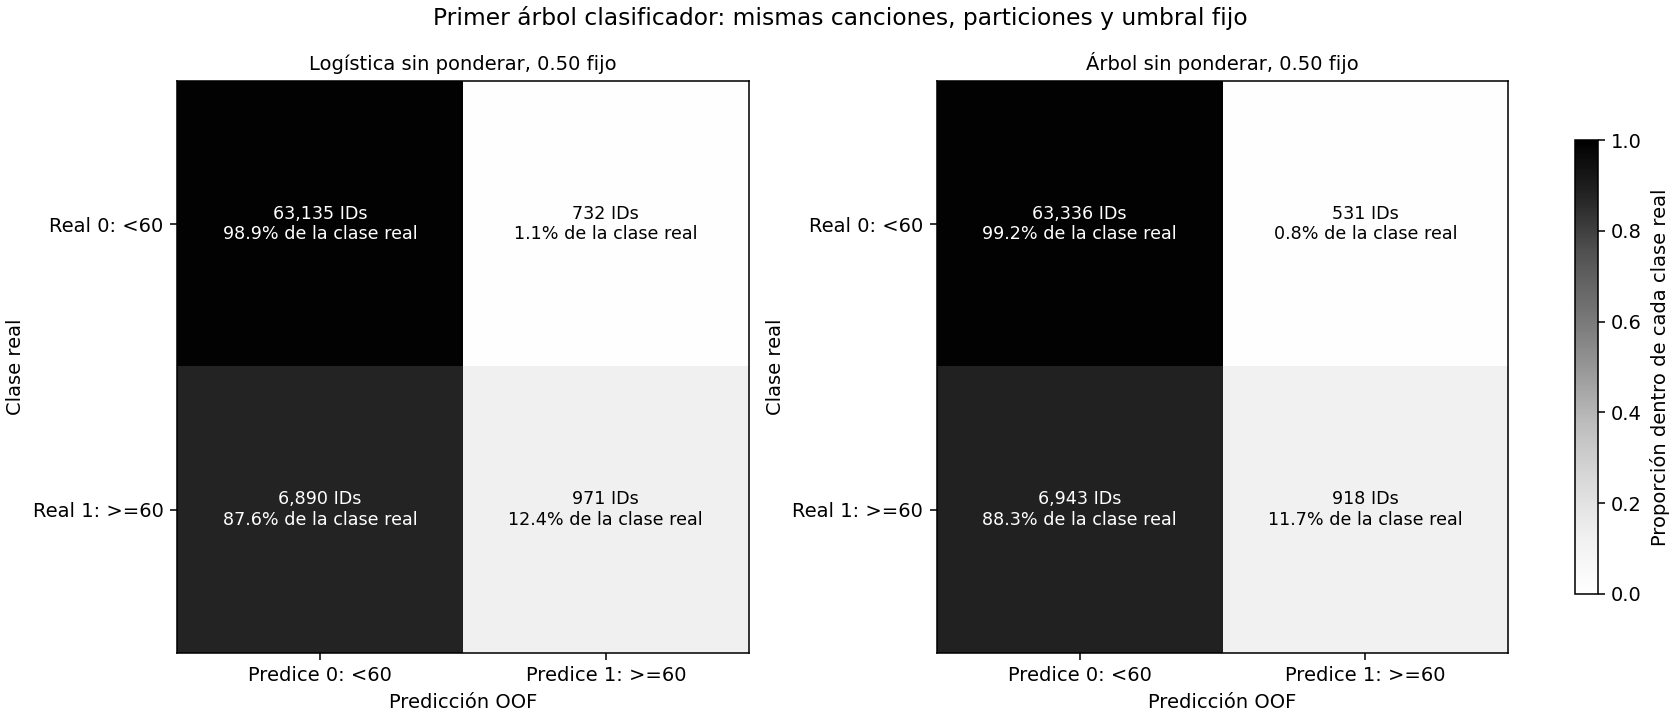

In [51]:
# Reunir resultados de entrenamiento, distinguiendo reglas fijas y selección anidada
predicciones_comparacion_arbol = {
    "Referencia mayoritaria OOF": predicciones_mayoria_oof,
    "Logística sin ponderar, 0.50 fijo": predicciones_logistica_oof,
    "Árbol sin ponderar, 0.50 fijo": predicciones_arbol_clasificador_oof,
    "Logística, selección anidada de umbral": predicciones_umbral_anidado_oof
}
registros_comparacion_arbol = []
registros_rondas_arbol = []
matrices_comparacion_arbol = {}
for nombre, pred in predicciones_comparacion_arbol.items():
    assert pred.index.equals(y_clasificacion_train.index)
    matriz, resumen = resumir_clasificacion(y_clasificacion_train, pred)
    matrices_comparacion_arbol[nombre] = matriz
    registros_comparacion_arbol.append({"Procedimiento": nombre, **resumen})
    for ronda in range(numero_pliegues):
        en_ronda = pliegue_por_id.eq(ronda)
        _, metricas_ronda = resumir_clasificacion(y_clasificacion_train.loc[en_ronda], pred.loc[en_ronda])
        registros_rondas_arbol.append({"Procedimiento": nombre, "Ronda": ronda + 1, **metricas_ronda})
tabla_comparacion_arbol_clasificador = pd.DataFrame(registros_comparacion_arbol).set_index("Procedimiento")
tabla_rondas_arbol_clasificador = pd.DataFrame(registros_rondas_arbol).set_index(["Procedimiento", "Ronda"])
lectura_comparacion_arbol = tabla_comparacion_arbol_clasificador[["IDs", "Positivos predichos", "Precisión positiva definida", "Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy"]].copy()
for metrica in ["Precisión clase 1", "Recall clase 1", "Accuracy"]:
    lectura_comparacion_arbol[metrica] *= 100
lectura_comparacion_arbol = lectura_comparacion_arbol.rename(columns={"Precisión clase 1": "Precisión (%)", "Recall clase 1": "Recall (%)", "Accuracy": "Accuracy (%)"})
display(lectura_comparacion_arbol.round(4))
display(tabla_comparacion_arbol_clasificador[["TN", "FP", "FN", "TP"]])
display(pd.DataFrame(matrices_comparacion_arbol["Árbol sin ponderar, 0.50 fijo"], index=["Real 0: <60", "Real 1: >=60"], columns=["Predice 0: <60", "Predice 1: >=60"]).rename_axis("Árbol clasificador OOF"))
display(tabla_rondas_arbol_clasificador[["Positivos predichos", "Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy"]].round(4))

# Comparar las matrices de los dos algoritmos al mismo umbral de probabilidad
import matplotlib.pyplot as plt
fig_arbol_clasificador, ejes_arbol_clasificador = plt.subplots(1, 2, figsize=(12, 5.2), constrained_layout=True)
for eje, nombre in zip(ejes_arbol_clasificador, ["Logística sin ponderar, 0.50 fijo", "Árbol sin ponderar, 0.50 fijo"]):
    matriz = matrices_comparacion_arbol[nombre]
    proporciones_fila = matriz / matriz.sum(axis=1, keepdims=True)
    imagen_arbol_clasificador = eje.imshow(proporciones_fila, vmin=0, vmax=1, cmap="Greys")
    for fila in range(2):
        for columna in range(2):
            texto = f"{matriz[fila, columna]:,} IDs\n{proporciones_fila[fila, columna] * 100:.1f}% de la clase real"
            eje.text(columna, fila, texto, ha="center", va="center", fontsize=9, color="white" if proporciones_fila[fila, columna] > 0.5 else "black")
    eje.set_xticks([0, 1], ["Predice 0: <60", "Predice 1: >=60"])
    eje.set_yticks([0, 1], ["Real 0: <60", "Real 1: >=60"])
    eje.set_xlabel("Predicción OOF")
    eje.set_ylabel("Clase real")
    eje.set_title(nombre, fontsize=10)
fig_arbol_clasificador.colorbar(imagen_arbol_clasificador, ax=ejes_arbol_clasificador, shrink=0.7, label="Proporción dentro de cada clase real")
fig_arbol_clasificador.suptitle("Primer árbol clasificador: mismas canciones, particiones y umbral fijo")
display(fig_arbol_clasificador)
plt.close(fig_arbol_clasificador)


#### KPI del árbol y explicación de sus resultados

El árbol obtiene **precisión 63,35%**, **recall 11,68%**, **F1 0,1972** y accuracy **89,58%**. Identifica 918 positivas, omite 6.943 y produce 531 falsas alarmas.

**Recall no cumple:** 11,68% <60%; solo identifica 918 de las 7.861 positivas y deja 6.943 sin detectar.

**Precisión cumple:** 63,35% >=30%.

La tabla de ajustes y hojas muestra qué probabilidades produce esta configuración. La profundidad limitada, el mínimo de ejemplos y el aprendizaje sin pesos forman parte de la configuración evaluada; no se afirma con estos datos cuál es la causa única del error ni se cambia el umbral para hacerlo cumplir.

A umbral 0,50, la logística tiene precisión 57,02%, recall 12,35% y F1 0,2031. La referencia no identifica positivas. La fila de logística con selección anidada tiene precisión 34,68%, recall 61,11% y F1 0,4425, pero incorpora una regla de selección que el árbol aún no tiene; no se atribuye toda la diferencia al algoritmo.

**Por qué falla la detección:** el árbol señala solo **1.449 de las 71.728 canciones (2,02%)**. De ellas 918 son positivas, pero quedan 6.943 positivas sin señalar. Con sus reglas actuales, la gran mayoría de canciones llega a hojas cuya probabilidad de clase 1 es menor que 0,50. Es una regla selectiva: pocas falsas alarmas en comparación con la logística a 0,50, a costa de recuperar una fracción aún menor de positivas. Una hoja puede tener probabilidad alta y cubrir pocas canciones; el máximo de probabilidad no representa a todo el conjunto.

**Código del cierre:** para cada procedimiento se comparan recall con 60% y precisión con 30%; precisión debe estar definida para cumplir. La tabla de KPI del árbol conserva las metas y controles iniciales, y actualiza resultados predictivos y cobertura OOF. Se informa el cumplimiento por ronda con los mismos criterios. No se cambia el umbral ni se selecciona otra profundidad después de observar el resultado.

Una precisión indefinida por falta de positivos predichos se representa como 0 por convención en el reporte, no como una precisión estimada. Aunque accuracy coincida con la referencia, eso no significa que el árbol identifique canciones positivas. La tabla de probabilidades de hojas ayuda a entender por qué el umbral fijo puede ser restrictivo en este árbol sencillo, sin demostrar que el problema sea imposible para cualquier árbol.


In [52]:
# Contrastar los procedimientos y mantener los KPI originales
cumplimiento_comparacion_arbol = tabla_comparacion_arbol_clasificador[["Precisión positiva definida", "Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy"]].copy()
cumplimiento_comparacion_arbol["Cumple precisión"] = cumplimiento_comparacion_arbol["Precisión positiva definida"] & cumplimiento_comparacion_arbol["Precisión clase 1"].ge(meta_precision_clasificacion)
cumplimiento_comparacion_arbol["Cumple recall"] = cumplimiento_comparacion_arbol["Recall clase 1"].ge(meta_recall_clasificacion)
cumplimiento_comparacion_arbol["Cumple ambos KPI"] = cumplimiento_comparacion_arbol["Cumple precisión"] & cumplimiento_comparacion_arbol["Cumple recall"]
resultado_arbol_clasificador = tabla_comparacion_arbol_clasificador.loc["Árbol sin ponderar, 0.50 fijo"]
tabla_kpi_arbol_clasificador = tabla_kpi_logistica_oof.copy(deep=True)
for indicador, valor, cumple in [
    ("Recall clase 1", resultado_arbol_clasificador["Recall clase 1"] * 100, resultado_arbol_clasificador["Recall clase 1"] >= meta_recall_clasificacion),
    ("Precisión clase 1", resultado_arbol_clasificador["Precisión clase 1"] * 100, resultado_arbol_clasificador["Precisión positiva definida"] and resultado_arbol_clasificador["Precisión clase 1"] >= meta_precision_clasificacion),
    ("Cobertura de predicciones OOF", float(visitas_arbol_clasificador.eq(1).mean() * 100), visitas_arbol_clasificador.eq(1).all())
]:
    tabla_kpi_arbol_clasificador.loc[indicador, "Resultado"] = valor
    tabla_kpi_arbol_clasificador.loc[indicador, "Estado"] = "Cumple" if cumple else "No cumple"
cumplimiento_rondas_arbol_clasificador = tabla_rondas_arbol_clasificador.loc["Árbol sin ponderar, 0.50 fijo", ["Precisión positiva definida", "Precisión clase 1", "Recall clase 1", "F1 clase 1"]].copy()
cumplimiento_rondas_arbol_clasificador["Cumple precisión"] = cumplimiento_rondas_arbol_clasificador["Precisión positiva definida"] & cumplimiento_rondas_arbol_clasificador["Precisión clase 1"].ge(meta_precision_clasificacion)
cumplimiento_rondas_arbol_clasificador["Cumple recall"] = cumplimiento_rondas_arbol_clasificador["Recall clase 1"].ge(meta_recall_clasificacion)
display(cumplimiento_comparacion_arbol.round(4))
display(tabla_kpi_arbol_clasificador.round({"Resultado": 4}))
display(cumplimiento_rondas_arbol_clasificador.round(4))


,Precisión positiva definida,Precisión clase 1,Recall clase 1,F1 clase 1,Accuracy,Cumple precisión,Cumple recall,Cumple ambos KPI
Procedimiento,,,,,,,,
Referencia mayoritaria OOF,False,0.0000,0.0000,0.0000,0.8904,False,False,False
"Logística sin ponderar, 0.50 fijo",True,0.5702,0.1235,0.2031,0.8937,True,False,False
"Árbol sin ponderar, 0.50 fijo",True,0.6335,0.1168,0.1972,0.8958,True,False,False
"Logística, selección anidada de umbral",True,0.3468,0.6111,0.4425,0.8312,True,True,True


,Meta,Resultado,Unidad,Estado
KPI,,,,
Recall clase 1,>= 60%,11.6779,%,No cumple
Precisión clase 1,>= 30%,63.3540,%,Cumple
Etiquetas válidas y alineadas,100%,100.0000,%,Cumple
Claves compartidas ajuste/validación,0 en cada ronda,0.0000,Máximo de claves compartidas por ronda,Cumple
Cobertura de predicciones OOF,100%,100.0000,%,Cumple


,Precisión positiva definida,Precisión clase 1,Recall clase 1,F1 clase 1,Cumple precisión,Cumple recall
Ronda,,,,,,
1,True,0.6367,0.1194,0.2011,True,False
2,True,0.5651,0.1327,0.2149,True,False
3,True,0.7545,0.0979,0.1733,True,False


#### Conclusión del primer árbol clasificador

**No cumple ambas metas predictivas iniciales** en esta configuración. Se conserva el resultado sin ajustar profundidad, ponderación o umbral después de verlo.

- **Ronda 1:** no cumple ambos KPI: recall 11,94% <60%.
- **Ronda 2:** no cumple ambos KPI: recall 13,27% <60%.
- **Ronda 3:** no cumple ambos KPI: recall 9,79% <60%.

Se evaluaron las 71.728 canciones de entrenamiento con una predicción OOF por ID. Los parámetros se mantuvieron fijos y la preparación se aprendió solo con ajuste. Un incumplimiento predictivo no se oculta aunque separación y cobertura sean correctas.

La comparación principal con logística usa 0,50 en ambos modelos; el procedimiento logístico anidado se presenta como referencia contextual más desarrollada. No se usa su test para elegir este árbol ni se calcula una evaluación de test del árbol.

El resultado describe esta configuración sencilla, sin artista ni ponderación. Estudiar otras reglas o complejidad requeriría un experimento nuevo dentro de entrenamiento, con selección y evaluación separadas si se afinan decisiones. Este bloque no cambia parámetros para conseguir cumplimiento ni reescribe la evaluación final previa de la logística.


<a id="clasificacion-knn-sin-artista"></a>
### 9.2.3. KNN clasificador sin artista

**Idea:** buscar las 15 canciones de ajuste más cercanas y estimar la probabilidad de clase 1 como la proporción de vecinos que cumplen popularidad >=60. Si 9 de 15 son positivos, la estimación es 0,60. Es una votación de clases, no el promedio de sus puntajes de popularidad utilizado en regresión.

Configuración fijada: `n_neighbors=15`, `weights="uniform"`, `metric="euclidean"`, `algorithm="brute"`, `n_jobs=1`. No se buscan varios k para conservar solo el mejor. Con 15 votos uniformes las probabilidades avanzan en pasos de 1/15; que k sea impar evita empate exacto en la votación binaria ordinaria, pero no demuestra que 15 sea óptimo.

Las diez medidas se imputan y estandarizan dentro de ajuste. Las categorías conservan **One-Hot completo** (`drop=None`) para no alterar distancias por la referencia omitida; los géneros mantienen Multi-Hot 0/1. Se usa matriz densa. Las variables de origen son las mismas que en los otros modelos, aunque la representación se adapta a las distancias. No se equilibra automáticamente la importancia de cada bloque de variables.

**Código, paso a paso:** se importa el clasificador, se clona la preparación y se cambia One-Hot y almacenamiento solo para KNN. Se define el pipeline con una configuración fija. Las funciones comunes evitan repetir el mismo bucle de validación para cada modelo:

- `ajustar_clasificador_sin_artista` clona la plantilla y ajusta preparación y clasificador solo con las filas recibidas. Revisa convergencia cuando corresponda y verifica medianas y filas vistas por el escalador.
- `probabilidad_clase_1_sin_artista` localiza clase 1 en `classes_`. Para KNN consulta lotes de 256 canciones, pero cada consulta busca vecinos entre **todo el ajuste**, no una muestra. Para los otros modelos predice el conjunto recibido de una vez. No recibe etiquetas de la consulta.
- `evaluar_clasificador_oof_fijo` conserva las mismas tres particiones agrupadas, excluye claves compartidas, asigna una probabilidad y etiqueta OOF por ID y verifica cobertura. El umbral inicial es 0,50 para todos. `resumir_clasificacion` conserva matrices y métricas ordinarias.
- Las funciones también se reutilizarán en validación interna; reciben un ajuste concreto y no consultan test ni artista.

Cercanía numérica no garantiza similitud musical perfecta ni igual popularidad. No se añade ponderación por clases o distancias en este primer KNN.

Referencia: [KNeighborsClassifier](https://scikit-learn.org/1.6/modules/generated/sklearn.neighbors.KNeighborsClassifier.html).


In [53]:
# Preparar KNN y utilidades comunes de ajuste y predicción
from sklearn.neighbors import KNeighborsClassifier
from sklearn.exceptions import ConvergenceWarning
import warnings
preprocesador_knn_clasificador = clone(preprocesador_lineal).set_params(categoricas__codificar__drop=None, sparse_threshold=0.0)
modelo_knn_clasificador_base = Pipeline([
    ("preparar", preprocesador_knn_clasificador),
    ("clasificar", KNeighborsClassifier(n_neighbors=15, weights="uniform", metric="euclidean", algorithm="brute", n_jobs=1))
])

def ajustar_clasificador_sin_artista(plantilla, X_ajuste, y_ajuste):
    assert X_ajuste.index.equals(y_ajuste.index) and y_ajuste.nunique() == 2
    modelo = clone(plantilla)
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        modelo.fit(X_ajuste, y_ajuste)
    if any(issubclass(aviso.category, ConvergenceWarning) for aviso in avisos):
        raise ValueError("Revisar convergencia antes de comparar clasificadores.")
    numericas = modelo.named_steps["preparar"].named_transformers_["numericas"]
    assert np.allclose(numericas.named_steps["imputar"].statistics_, X_ajuste[columnas_numericas_modelo].median())
    assert int(numericas.named_steps["escalar"].n_samples_seen_) == len(y_ajuste)
    clasificador = modelo.named_steps["clasificar"]
    if isinstance(clasificador, KNeighborsClassifier):
        assert clasificador.n_samples_fit_ == len(y_ajuste)
    if hasattr(clasificador, "class_weight"):
        assert clasificador.class_weight is None
    return modelo

def probabilidad_clase_1_sin_artista(modelo, X_consulta):
    clasificador = modelo.named_steps["clasificar"]
    columna = list(clasificador.classes_).index(1)
    resultado = pd.Series(index=X_consulta.index, dtype="float64")
    lote = 256 if isinstance(clasificador, KNeighborsClassifier) else len(X_consulta)
    for inicio in range(0, len(X_consulta), lote):
        consulta = X_consulta.iloc[inicio:inicio + lote]
        resultado.loc[consulta.index] = modelo.predict_proba(consulta)[:, columna]
    assert resultado.notna().all() and np.isfinite(resultado).all() and resultado.between(0, 1).all()
    return resultado

def evaluar_clasificador_oof_fijo(plantilla, nombre):
    probabilidades = pd.Series(index=y_clasificacion_train.index, dtype="float64")
    visitas = pd.Series(0, index=y_clasificacion_train.index, dtype="int8")
    filas = []
    for ronda in range(numero_pliegues):
        validar = pliegue_por_id.eq(ronda)
        ajustar = ~validar
        assert set(datos_entrenamiento.loc[ajustar, "clave_cancion"]).isdisjoint(set(datos_entrenamiento.loc[validar, "clave_cancion"]))
        modelo = ajustar_clasificador_sin_artista(plantilla, X_train.loc[ajustar], y_clasificacion_train.loc[ajustar])
        probabilidades.loc[validar] = probabilidad_clase_1_sin_artista(modelo, X_train.loc[validar])
        visitas.loc[validar] += 1
        etiquetas_ronda = probabilidades.loc[validar].ge(0.50).astype("int8")
        _, metricas = resumir_clasificacion(y_clasificacion_train.loc[validar], etiquetas_ronda)
        filas.append({"Modelo": nombre, "Ronda": ronda + 1, "IDs ajuste": int(ajustar.sum()), **metricas})
    assert visitas.eq(1).all() and probabilidades.index.equals(y_clasificacion_train.index)
    etiquetas = probabilidades.ge(0.50).astype("int8")
    matriz, metricas = resumir_clasificacion(y_clasificacion_train, etiquetas)
    return {"probabilidades": probabilidades, "predicciones": etiquetas, "matriz": matriz, "metricas": metricas, "rondas": pd.DataFrame(filas)}

resultado_knn_clasificador = evaluar_clasificador_oof_fijo(modelo_knn_clasificador_base, "KNN")
probabilidades_knn_clasificador_oof = resultado_knn_clasificador["probabilidades"]
predicciones_knn_clasificador_oof = resultado_knn_clasificador["predicciones"]
display(pd.Series(resultado_knn_clasificador["metricas"]))
display(resultado_knn_clasificador["rondas"].round(4))


IDs                               71728
TN                                63092
FP                                  775
FN                                 6743
TP                                 1118
Positivos predichos                1893
Precisión positiva definida        True
Precisión clase 1              0.590597
Recall clase 1                 0.142221
F1 clase 1                     0.229239
Accuracy                       0.895187
dtype: object

,Modelo,Ronda,IDs ajuste,IDs,TN,FP,FN,TP,Positivos predichos,Precisión positiva definida,Precisión clase 1,Recall clase 1,F1 clase 1,Accuracy
0,KNN,1,47815,23913,21001,241,2314,357,598,True,0.5970,0.1337,0.2184,0.8932
1,KNN,2,47624,24104,21200,289,2220,395,684,True,0.5775,0.1511,0.2395,0.8959
2,KNN,3,48017,23711,20891,245,2209,366,611,True,0.5990,0.1421,0.2298,0.8965


<a id="clasificacion-hist-sin-artista"></a>
### 9.2.4. HistGradientBoosting clasificador sin artista

**Idea:** construir árboles sucesivos que corrigen el objetivo de clasificación. El resultado estima una probabilidad de clase 1, no el puntaje de popularidad. La variante por histogramas agrupa valores de características para acelerar la búsqueda de divisiones. Es un ensamble, por lo que conecta también con los contenidos de unidad 3.

Configuración inicial fija: `loss="log_loss"`, tasa de aprendizaje 0,03, 600 etapas, máximo de 63 hojas y mínimo de 20 IDs por hoja. `class_weight=None` conserva pesos unitarios. `early_stopping=False` evita una subdivisión aleatoria adicional y mantiene las 600 etapas; `categorical_features=None` indica que las categorías ya fueron codificadas; semilla 42 para reproducir el cálculo.

Son parámetros de referencia, no óptimos demostrados ni una reproducción exacta del clasificador del proyecto original. La pérdida logística de entrenamiento no es F1: F1, precisión y recall se calculan después. No se escoge el número de etapas mirando validación.

**Código:** se importa `HistGradientBoostingClassifier`; se clona la preparación común y se fija almacenamiento denso, requerido por el estimador. El escalamiento no es necesario para árboles, pero se conserva y se aprende solo con ajuste. `Pipeline` enlaza preparación y clasificador. Se llama a la misma evaluación OOF a 0,50 y se verifica que las etiquetas cubran los mismos IDs. Los resultados se conservan para la comparación final y la selección interna del umbral.

Referencia: [HistGradientBoostingClassifier](https://scikit-learn.org/1.6/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html).


In [54]:
# Definir el cuarto clasificador sin artista, sin ponderación ni parada temprana
from sklearn.ensemble import HistGradientBoostingClassifier
modelo_hist_clasificador_base = Pipeline([
    ("preparar", clone(preprocesador_lineal).set_params(sparse_threshold=0.0)),
    ("clasificar", HistGradientBoostingClassifier(loss="log_loss", learning_rate=0.03, max_iter=600, max_leaf_nodes=63, min_samples_leaf=20, class_weight=None, early_stopping=False, categorical_features=None, random_state=42))
])
resultado_hist_clasificador = evaluar_clasificador_oof_fijo(modelo_hist_clasificador_base, "HistGradientBoosting")
probabilidades_hist_clasificador_oof = resultado_hist_clasificador["probabilidades"]
predicciones_hist_clasificador_oof = resultado_hist_clasificador["predicciones"]
display(pd.Series(resultado_hist_clasificador["metricas"]))
display(resultado_hist_clasificador["rondas"].round(4))


IDs                               71728
TN                                62603
FP                                 1264
FN                                 5973
TP                                 1888
Positivos predichos                3152
Precisión positiva definida        True
Precisión clase 1              0.598985
Recall clase 1                 0.240173
F1 clase 1                     0.342868
Accuracy                       0.899105
dtype: object

,Modelo,Ronda,IDs ajuste,IDs,TN,FP,FN,TP,Positivos predichos,Precisión positiva definida,Precisión clase 1,Recall clase 1,F1 clase 1,Accuracy
0,HistGradientBoosting,1,47815,23913,20875,367,2082,589,956,True,0.6161,0.2205,0.3248,0.8976
1,HistGradientBoosting,2,47624,24104,20990,499,1966,649,1148,True,0.5653,0.2482,0.3449,0.8977
2,HistGradientBoosting,3,48017,23711,20738,398,1925,650,1048,True,0.6202,0.2524,0.3588,0.9020


<a id="clasificacion-comparacion-sin-artista"></a>
### 9.2.5. Comparación completa de los cuatro clasificadores sin artista

La comparación principal reúne **logística, árbol, KNN e HistGradientBoosting**, sin artista y sin ponderación, sobre las mismas tres validaciones externas y 71.728 IDs. La logística balanced queda como experimento complementario dentro de su apartado: no cuenta como un quinto modelo ni sustituye una de las cuatro familias.

Primero se comparan todos a **0,50 fijo**. Se añade la referencia que aprende la mayoría en ajuste. Para cada modelo se muestran matriz, métricas globales y por ronda y los mismos KPI: precisión >=30%, recall >=60%, etiquetas válidas, claves no compartidas y cobertura OOF completa.

Después se compara el **procedimiento con selección anidada de umbral para los cuatro**. No sería equivalente usar el umbral ya afinado de la logística y dejar a los otros solo con 0,50. Los parámetros de los estimadores permanecen fijos: no se buscan otras profundidades, vecinos o cantidades de árboles.

**Código de la primera tabla:** los diccionarios reúnen probabilidades y etiquetas OOF; la función ya verificada calcula matrices y métricas sin ponderar la validación. Las columnas `Cumple precisión` y `Cumple recall` comparan sin redondeo. Se informa cualquier incumplimiento aunque accuracy sea alta. La referencia sin positivos predichos tiene precisión indefinida, mostrada como 0 por convención y acompañada de su indicador de definición.


In [55]:
# Comparar los cuatro modelos a 0,50 con la referencia, sin usar test
plantillas_cuatro_sin_artista = {"Logística": modelo_logistico_base, "Árbol": modelo_arbol_clasificador_base, "KNN": modelo_knn_clasificador_base, "HistGradientBoosting": modelo_hist_clasificador_base}
probabilidades_cuatro_sin_artista = {"Logística": probabilidades_logistica_oof, "Árbol": probabilidades_arbol_clasificador_oof, "KNN": probabilidades_knn_clasificador_oof, "HistGradientBoosting": probabilidades_hist_clasificador_oof}
predicciones_fijas_cuatro = {nombre: prob.ge(0.50).astype("int8") for nombre, prob in probabilidades_cuatro_sin_artista.items()}
predicciones_fijas_cuatro["Referencia mayoritaria"] = predicciones_mayoria_oof
filas_comparacion_fija = []
filas_rondas_fijas = []
matrices_cuatro_fijas = {}
for nombre, pred in predicciones_fijas_cuatro.items():
    assert pred.index.equals(y_clasificacion_train.index)
    matriz, metricas = resumir_clasificacion(y_clasificacion_train, pred)
    matrices_cuatro_fijas[nombre] = matriz
    filas_comparacion_fija.append({"Modelo": nombre, **metricas, "Cumple precisión": bool(metricas["Precisión positiva definida"] and metricas["Precisión clase 1"] >= meta_precision_clasificacion), "Cumple recall": bool(metricas["Recall clase 1"] >= meta_recall_clasificacion)})
    for ronda in range(numero_pliegues):
        en_ronda = pliegue_por_id.eq(ronda)
        _, medidas_ronda = resumir_clasificacion(y_clasificacion_train.loc[en_ronda], pred.loc[en_ronda])
        filas_rondas_fijas.append({"Modelo": nombre, "Ronda": ronda + 1, **medidas_ronda})
tabla_cuatro_fija = pd.DataFrame(filas_comparacion_fija).set_index("Modelo")
tabla_cuatro_fija["Cumple ambos KPI"] = tabla_cuatro_fija["Cumple precisión"] & tabla_cuatro_fija["Cumple recall"]
tabla_rondas_cuatro_fijas = pd.DataFrame(filas_rondas_fijas).set_index(["Modelo", "Ronda"])
display(tabla_cuatro_fija[["Precisión positiva definida", "Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy", "Cumple ambos KPI"]].round(4))
display(tabla_cuatro_fija[["TN", "FP", "FN", "TP", "Positivos predichos"]])
display(tabla_rondas_cuatro_fijas[["TP", "FN", "FP", "Precisión clase 1", "Recall clase 1", "F1 clase 1"]].round(4))


,Precisión positiva definida,Precisión clase 1,Recall clase 1,F1 clase 1,Accuracy,Cumple ambos KPI
Modelo,,,,,,
Logística,True,0.5702,0.1235,0.2031,0.8937,False
Árbol,True,0.6335,0.1168,0.1972,0.8958,False
KNN,True,0.5906,0.1422,0.2292,0.8952,False
HistGradientBoosting,True,0.5990,0.2402,0.3429,0.8991,False
Referencia mayoritaria,False,0.0000,0.0000,0.0000,0.8904,False


,TN,FP,FN,TP,Positivos predichos
Modelo,,,,,
Logística,63135,732,6890,971,1703
Árbol,63336,531,6943,918,1449
KNN,63092,775,6743,1118,1893
HistGradientBoosting,62603,1264,5973,1888,3152
Referencia mayoritaria,63867,0,7861,0,0


TP    FN  ...  Recall clase 1  F1 clase 1
Modelo                 Ronda             ...                            
Logística              1      339  2332  ...          0.1269      0.2076
                       2      338  2277  ...          0.1293      0.2086
                       3      294  2281  ...          0.1142      0.1923
Árbol                  1      319  2352  ...          0.1194      0.2011
                       2      347  2268  ...          0.1327      0.2149
                       3      252  2323  ...          0.0979      0.1733
KNN                    1      357  2314  ...          0.1337      0.2184
                       2      395  2220  ...          0.1511      0.2395
                       3      366  2209  ...          0.1421      0.2298
HistGradientBoosting   1      589  2082  ...          0.2205      0.3248
                       2      649  1966  ...          0.2482      0.3449
                       3      650  1925  ...          0.2524      0.3588
Referencia mayoritaria 1        0  2671  ...          0.0000      0.0000
                       2        0  2615  ...          0.0000      0.0000
                       3        0  2575  ...          0.0000      0.0000

[15 rows x 6 columns]

### Selección anidada comparable del umbral para árbol, KNN y boosting

Se mantiene el protocolo de la logística: tres rondas externas y tres internas agrupadas dentro de cada ajuste; mismos 16 umbrales; precisión >=30% y recall >=60%; mayor F1 entre elegibles, desempate por umbral mayor y respaldo 0,50 si ninguno es elegible. Un respaldo se registra como falta de candidato interno cumplidor, no como selección exitosa.

La logística reutiliza su validación anidada ya comprobada, sin repetir nueve ajustes idénticos. Los otros tres modelos necesitan **nueve ajustes internos cada uno**. Las probabilidades externas a las que se aplica el umbral son las OOF que ya obtuvimos para esos mismos ajustes externos; sus respuestas no participan en la selección.

**Lectura de la función:** recibe únicamente ajuste externo, etiquetas, claves, plantilla y reglas. Reparte claves internas con semilla 42 y mantiene juntas sus versiones. Cada ronda clona el pipeline y aprende preparación y modelo solo con ajuste interno. Se reúnen probabilidades internas, se calcula la misma tabla de candidatos y se fija el umbral antes de aplicar la regla a validación externa. Para KNN se mantienen lotes y búsqueda exacta. No se usa test ni popularidad como predictor.

La tabla global evalúa el **proceso de selección**, que puede usar umbrales distintos por ronda. Se muestran respaldos, controles de claves y cobertura; no se excluyen rondas desfavorables. Las tablas internas sirven para elegir, no se presentan como una evaluación externa. El método no crea una muestra inédita: el entrenamiento y sus particiones ya fueron explorados durante el desarrollo.


In [56]:
# Selección interna genérica, con preparación aprendida de nuevo dentro de ajuste
umbrales_cuatro_sin_artista = np.array([0.00, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00])

def seleccionar_umbral_clasificador_sin_artista(X_ajuste, y_ajuste, claves_ajuste, plantilla):
    assert X_ajuste.index.equals(y_ajuste.index) and claves_ajuste.index.equals(y_ajuste.index)
    claves_barajadas = claves_ajuste.drop_duplicates().sort_values().sample(frac=1, random_state=42).reset_index(drop=True)
    mapa_interno = pd.Series(np.arange(len(claves_barajadas)) % 3, index=claves_barajadas)
    internos = claves_ajuste.map(mapa_interno)
    prob_internas = pd.Series(index=y_ajuste.index, dtype="float64")
    visitas = pd.Series(0, index=y_ajuste.index, dtype="int8")
    controles = []
    for interno in range(3):
        validar = internos.eq(interno)
        ajustar = ~validar
        compartidas = set(claves_ajuste.loc[ajustar]) & set(claves_ajuste.loc[validar])
        assert not compartidas
        modelo = ajustar_clasificador_sin_artista(plantilla, X_ajuste.loc[ajustar], y_ajuste.loc[ajustar])
        prob_internas.loc[validar] = probabilidad_clase_1_sin_artista(modelo, X_ajuste.loc[validar])
        visitas.loc[validar] += 1
        controles.append({"Ronda interna": interno + 1, "IDs ajuste": int(ajustar.sum()), "IDs validación": int(validar.sum()), "Claves compartidas": len(compartidas)})
    assert visitas.eq(1).all() and prob_internas.notna().all()
    candidatos = []
    for umbral in umbrales_cuatro_sin_artista:
        _, metricas = resumir_clasificacion(y_ajuste, prob_internas.ge(umbral).astype("int8"))
        elegible = metricas["Precisión positiva definida"] and metricas["Precisión clase 1"] >= meta_precision_clasificacion and metricas["Recall clase 1"] >= meta_recall_clasificacion
        candidatos.append({"Umbral": float(umbral), **metricas, "Elegible": bool(elegible)})
    tabla = pd.DataFrame(candidatos).set_index("Umbral")
    elegibles = tabla.reset_index().loc[lambda datos: datos["Elegible"]].sort_values(["F1 clase 1", "Umbral"], ascending=[False, False])
    umbral = 0.50 if elegibles.empty else float(elegibles.iloc[0]["Umbral"])
    return umbral, not elegibles.empty, tabla, pd.DataFrame(controles), prob_internas

# La logística conserva su evaluación anidada anterior, sin nuevos ajustes
resultados_anidados_cuatro = {"Logística": {"predicciones": predicciones_umbral_anidado_oof.copy(), "selecciones": tabla_seleccion_anidada.copy()}}
for nombre in ["Árbol", "KNN", "HistGradientBoosting"]:
    pred_externas = pd.Series(index=y_clasificacion_train.index, dtype="float64")
    visitas_externas = pd.Series(0, index=y_clasificacion_train.index, dtype="int8")
    decisiones = []
    evidencias = {}
    for externa in range(numero_pliegues):
        validar_externo = pliegue_por_id.eq(externa)
        ajustar_externo = ~validar_externo
        claves_ajuste = datos_entrenamiento.loc[ajustar_externo, "clave_cancion"]
        assert set(claves_ajuste).isdisjoint(set(datos_entrenamiento.loc[validar_externo, "clave_cancion"]))
        umbral, elegible, tabla_interna, controles, prob_internas = seleccionar_umbral_clasificador_sin_artista(X_train.loc[ajustar_externo], y_clasificacion_train.loc[ajustar_externo], claves_ajuste, plantillas_cuatro_sin_artista[nombre])
        decisiones.append({"Ronda externa": externa + 1, "Umbral usado": umbral, "Hubo umbral interno elegible": elegible, "Precisión interna (%)": tabla_interna.loc[umbral, "Precisión clase 1"] * 100, "Recall interno (%)": tabla_interna.loc[umbral, "Recall clase 1"] * 100, "F1 interno": tabla_interna.loc[umbral, "F1 clase 1"]})
        evidencias[externa + 1] = {"Tabla de umbrales": tabla_interna, "Controles": controles, "Probabilidades internas": prob_internas}
        pred_externas.loc[validar_externo] = probabilidades_cuatro_sin_artista[nombre].loc[validar_externo].ge(umbral).astype("int8")
        visitas_externas.loc[validar_externo] += 1
    assert visitas_externas.eq(1).all() and pred_externas.notna().all()
    resultados_anidados_cuatro[nombre] = {"predicciones": pred_externas.astype("int8"), "selecciones": pd.DataFrame(decisiones).set_index("Ronda externa"), "evidencia_interna": evidencias}
    display(resultados_anidados_cuatro[nombre]["selecciones"].round(4))


,Umbral usado,Hubo umbral interno elegible,Precisión interna (%),Recall interno (%),F1 interno
Ronda externa,,,,,
1,0.5,False,58.1527,11.8882,0.1974
2,0.5,False,66.0966,12.5238,0.2106
3,0.5,False,62.5000,9.6481,0.1672


,Umbral usado,Hubo umbral interno elegible,Precisión interna (%),Recall interno (%),F1 interno
Ronda externa,,,,,
1,0.5,False,60.7570,11.7534,0.1970
2,0.5,False,57.5553,11.3992,0.1903
3,0.5,False,58.3779,12.3912,0.2044


,Umbral usado,Hubo umbral interno elegible,Precisión interna (%),Recall interno (%),F1 interno
Ronda externa,,,,,
1,0.2,True,39.1147,62.3121,0.4806
2,0.2,True,38.9930,62.2951,0.4796
3,0.2,True,38.1580,63.4885,0.4767


### Resultados finales de desarrollo sin artista, matrices y KPI

**Código:** se calculan métricas con las predicciones externas de los cuatro procedimientos anidados, sin ponderar la evaluación. Cada matriz suma los mismos 71.728 IDs. Se muestran resultados por ronda y se comprueban metas sin redondear. Los controles de etiquetas válidas, claves no compartidas y cobertura se mantienen separados del cumplimiento predictivo.

La referencia mayoritaria se conserva para contextualizar, sin contar como quinto modelo. La elección provisional se limita a candidatos que cumplan ambos KPI globales y luego compara F1. Si no hay candidato elegible se informa explícitamente. No se cambia una profundidad, un k, un número de etapas, el umbral de respaldo o las metas después de ver estos resultados.

La selección entre cuatro procedimientos usando esta evidencia es una decisión de desarrollo adicional, no una confirmación externa nueva. **No se evalúan los nuevos modelos en test.** El reporte de test de la logística se conserva más adelante como antecedente de aquel procedimiento y no como evaluación del ganador de esta comparación ampliada.


In [57]:
# Evaluar todos los procedimientos anidados y sus KPI, sin test
filas_anidadas_cuatro = []
filas_rondas_anidadas_cuatro = []
matrices_anidadas_cuatro = {}
for nombre, resultado in resultados_anidados_cuatro.items():
    pred = resultado["predicciones"]
    assert pred.index.equals(y_clasificacion_train.index) and pred.notna().all()
    matriz, metricas = resumir_clasificacion(y_clasificacion_train, pred)
    matrices_anidadas_cuatro[nombre] = matriz
    cumple_precision = metricas["Precisión positiva definida"] and metricas["Precisión clase 1"] >= meta_precision_clasificacion
    cumple_recall = metricas["Recall clase 1"] >= meta_recall_clasificacion
    filas_anidadas_cuatro.append({"Modelo": nombre, **metricas, "Cumple precisión": bool(cumple_precision), "Cumple recall": bool(cumple_recall), "Cumple ambos KPI": bool(cumple_precision and cumple_recall), "Respaldos internos": int((~resultado["selecciones"]["Hubo umbral interno elegible"]).sum()), "Cobertura OOF (%)": pred.notna().mean() * 100})
    for externa in range(numero_pliegues):
        en_ronda = pliegue_por_id.eq(externa)
        _, medidas = resumir_clasificacion(y_clasificacion_train.loc[en_ronda], pred.loc[en_ronda])
        filas_rondas_anidadas_cuatro.append({"Modelo": nombre, "Ronda": externa + 1, "Umbral usado": float(resultado["selecciones"].loc[externa + 1, "Umbral usado"]), **medidas, "Cumple precisión": bool(medidas["Precisión positiva definida"] and medidas["Precisión clase 1"] >= meta_precision_clasificacion), "Cumple recall": bool(medidas["Recall clase 1"] >= meta_recall_clasificacion)})
tabla_cuatro_anidada = pd.DataFrame(filas_anidadas_cuatro).set_index("Modelo")
tabla_rondas_cuatro_anidadas = pd.DataFrame(filas_rondas_anidadas_cuatro).set_index(["Modelo", "Ronda"])
elegibles_cuatro_sin_artista = tabla_cuatro_anidada.loc[tabla_cuatro_anidada["Cumple ambos KPI"]].sort_values("F1 clase 1", ascending=False, kind="stable")
eleccion_provisional_cuatro_sin_artista = None if elegibles_cuatro_sin_artista.empty else elegibles_cuatro_sin_artista.index[0]
# Esta elección no cambia la variable de la logística cuyo test ya se documentó.
lectura_cuatro_anidada = tabla_cuatro_anidada[["Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy", "Cumple precisión", "Cumple recall", "Cumple ambos KPI", "Respaldos internos", "Cobertura OOF (%)"]].copy()
for metrica in ["Precisión clase 1", "Recall clase 1", "Accuracy"]:
    lectura_cuatro_anidada[metrica] *= 100
lectura_cuatro_anidada = lectura_cuatro_anidada.rename(columns={"Precisión clase 1": "Precisión (%)", "Recall clase 1": "Recall (%)", "Accuracy": "Accuracy (%)"})
display(lectura_cuatro_anidada.round(4))
display(tabla_cuatro_anidada[["TN", "FP", "FN", "TP", "Positivos predichos"]])
display(tabla_rondas_cuatro_anidadas[["Umbral usado", "Precisión clase 1", "Recall clase 1", "F1 clase 1", "Cumple precisión", "Cumple recall"]].round(4))
for nombre, matriz in matrices_anidadas_cuatro.items():
    display(pd.DataFrame(matriz, index=["Real 0: <60", "Real 1: >=60"], columns=["Predice 0: <60", "Predice 1: >=60"]).rename_axis(f"{nombre}: evaluación externa anidada"))
display(pd.Series({"Elección provisional entre cuatro": eleccion_provisional_cuatro_sin_artista if eleccion_provisional_cuatro_sin_artista is not None else "Ningún candidato cumple ambas metas", "Etapa con artista": "Desarrollada y comparada en el apartado 9.3", "Nuevas evaluaciones de test": "Ninguna"}))


,Precisión (%),Recall (%),F1 clase 1,Accuracy (%),Cumple precisión,Cumple recall,Cumple ambos KPI,Respaldos internos,Cobertura OOF (%)
Modelo,,,,,,,,,
Logística,34.6759,61.1118,0.4425,83.1210,True,True,True,0,100.0
Árbol,63.3540,11.6779,0.1972,89.5801,True,False,False,3,100.0
KNN,59.0597,14.2221,0.2292,89.5187,True,False,False,3,100.0
HistGradientBoosting,38.6911,65.8059,0.4873,84.8246,True,True,True,0,100.0


,TN,FP,FN,TP,Positivos predichos
Modelo,,,,,
Logística,54817,9050,3057,4804,13854
Árbol,63336,531,6943,918,1449
KNN,63092,775,6743,1118,1893
HistGradientBoosting,55670,8197,2688,5173,13370


Umbral usado  ...  Cumple recall
Modelo               Ronda                ...               
Logística            1               0.2  ...          False
                     2               0.2  ...           True
                     3               0.2  ...           True
Árbol                1               0.5  ...          False
                     2               0.5  ...          False
                     3               0.5  ...          False
KNN                  1               0.5  ...          False
                     2               0.5  ...          False
                     3               0.5  ...          False
HistGradientBoosting 1               0.2  ...           True
                     2               0.2  ...           True
                     3               0.2  ...           True

[12 rows x 6 columns]

,Predice 0: <60,Predice 1: >=60
Logística: evaluación externa anidada,,
Real 0: <60,54817,9050
Real 1: >=60,3057,4804


,Predice 0: <60,Predice 1: >=60
Árbol: evaluación externa anidada,,
Real 0: <60,63336,531
Real 1: >=60,6943,918


,Predice 0: <60,Predice 1: >=60
KNN: evaluación externa anidada,,
Real 0: <60,63092,775
Real 1: >=60,6743,1118


,Predice 0: <60,Predice 1: >=60
HistGradientBoosting: evaluación externa anidada,,
Real 0: <60,55670,8197
Real 1: >=60,2688,5173


Elección provisional entre cuatro                   HistGradientBoosting
Etapa con artista                    Desarrollada y comparada en el apartado 9.3
Nuevas evaluaciones de test                                      Ninguna
dtype: object

### Cierre de los cuatro modelos sin artista

| Modelo | Precisión anidada | Recall anidado | F1 | Cumple ambos globalmente |
|---|---:|---:|---:|---|
| Logística | 34,68% | 61,11% | 0,4425 | Sí |
| Árbol | 63,35% | 11,68% | 0,1972 | No |
| KNN | 59,06% | 14,22% | 0,2292 | No |
| HistGradientBoosting | 38,69% | 65,81% | 0,4873 | Sí |

**Elección provisional entre los cuatro:** HistGradientBoosting, por mayor F1 entre quienes cumplen ambas metas globales.

- **Logística: cumple ambas metas globales**, con 4.804 positivas identificadas, 3.057 omitidas y 9.050 falsas alarmas.
- **Árbol: no cumple ambos KPI.** recall 11,68% <60%: detecta 918 de 7.861 positivas y omite 6.943.
- **KNN: no cumple ambos KPI.** recall 14,22% <60%: detecta 1.118 de 7.861 positivas y omite 6.743.
- **HistGradientBoosting: cumple ambas metas globales**, con 5.173 positivas identificadas, 2.688 omitidas y 8.197 falsas alarmas.

- **Logística:** ronda 1: recall 59,08% <60%. Respaldos internos 0,50: 0.
- **Árbol:** ronda 1: recall 11,94% <60%; ronda 2: recall 13,27% <60%; ronda 3: recall 9,79% <60%. Respaldos internos 0,50: 3.
- **KNN:** ronda 1: recall 13,37% <60%; ronda 2: recall 15,11% <60%; ronda 3: recall 14,21% <60%. Respaldos internos 0,50: 3.
- **HistGradientBoosting:** cumple ambos en las tres rondas. Respaldos internos 0,50: 0.

**Cómo interpretar la comparación:** precisión y recall responden a costos distintos; el criterio acordado compara F1 solo entre quienes cumplen ambas metas. Accuracy es complementaria. Un respaldo de 0,50 documenta falta de candidato interno elegible, no un éxito oculto de selección. Las probabilidades OOF, las etiquetas y los pesos de los experimentos previos no se reemplazan.

Los parámetros se fijaron como configuraciones de trabajo. No se afirma que sean los mejores de cada familia ni que pequeñas diferencias de F1 prueben superioridad estadística. Las variantes adaptan su representación a cada algoritmo, mantienen la información de origen y separan preparación, selección interna y validación externa.

**Estado para revisión:** están implementados y evaluados dentro de entrenamiento los cuatro clasificadores **sin artista**, con umbral común, selección anidada, matrices, métricas y KPI. Este cierre conserva la evidencia sin artista. La incorporación del artista se desarrolla después en 9.3, con mapas aprendidos dentro de cada ajuste. La prueba previa de la logística se conserva como antecedente y no se reabre para escoger entre estos cuatro modelos.


**Árbol y KNN:** en cada una de sus tres selecciones internas, ninguno de los 16 umbrales cumplió simultáneamente ambas metas. Por eso se aplicó el respaldo fijo 0,50 en las tres rondas. Sus resultados anidados son los del procedimiento con ese respaldo, no los de un umbral óptimo confirmado. Completar su evaluación no significa que cumplan los KPI ni demuestra imposibilidad con otros parámetros o umbrales.

**HistGradientBoosting:** las tres selecciones internas eligieron 0,20 y sus tres evaluaciones externas cumplen precisión y recall. Eso respalda su elección provisional en este desarrollo, sin constituir una prueba estadística ni una garantía para datos nuevos. No se ha calculado su resultado de clasificación en test.


### 9.2.6. Antecedente: evaluación previa de la logística en test

Esta evaluación se realizó antes de ampliar la comparación a cuatro familias. Se conserva sin cambiar modelo, umbral o resultados. No es un test de KNN, árbol o boosting ni confirma al candidato de la nueva comparación. Los modelos nuevos no se evalúan en test en esta ampliación. Los resultados siguientes pertenecen exclusivamente a la logística previamente fijada.


#### Evaluación final de clasificación en test: fijar el procedimiento y entrenar

La comparación anidada eligió provisionalmente **logística sin ponderación y sin artista** conforme al mayor F1 entre procedimientos que cumplen precisión >=30% y recall >=60% globalmente. Ahora se mantiene esa decisión y se evalúa solo ese procedimiento frente a la referencia mayoritaria, sin probar balanced ni otros umbrales con test.

**Qué queda fijado antes de abrir las respuestas de clasificación en test:** clase 1 significa popularidad >=60; logística con C=1, L2, `lbfgs`, `class_weight=None`, máximo de 2.000 iteraciones y tolerancia 1e-6; misma preparación de 127 entradas; misma lista de 16 umbrales; elegibilidad por precisión y recall, mayor F1 y desempate por umbral mayor. Si no hubiera elegible con entrenamiento, se conservaría el respaldo 0,50 y se declararía esa situación.

**Cómo se obtiene un umbral único sin usar test:** para ajustar el procedimiento con todo el entrenamiento, se necesitan probabilidades de validación agrupada de esos 71.728 IDs. Ya disponemos exactamente de ellas de la logística sin ponderar y de su tabla de umbrales. Reutilizar esa evidencia equivale a aplicar la selección con las tres particiones agrupadas de todo el entrenamiento, sin repetir ajustes idénticos. No se promedian los umbrales de las rondas anidadas ni se elige el más favorable en test. La regla sobre entrenamiento elige **0,20**; después queda fija.

**Código, paso a paso:**

1. Se comprueba la variante elegida y que sus parámetros coincidan con la plantilla. No se cambia ningún parámetro para la evaluación final.
2. Se filtran los umbrales de entrenamiento que cumplen ambas metas y se ordenan por F1 y desempate. Si no existen, se registra el respaldo fijado. `decision_final_clasificacion` documenta elección y configuración antes de calcular métricas de prueba.
3. `.mode().iloc[0]` obtiene la clase más frecuente de **todo el entrenamiento**. Se repite para los IDs de test; es una referencia sin características. No se aprende la mayoría con las respuestas de test.
4. `clone` crea una logística limpia con su pipeline. `.fit(X_train, y_clasificacion_train)` aprende medianas, escalas, categorías y coeficientes solo con entrenamiento. El estimador conserva pesos unitarios, sin artista ni remuestreo.
5. Se controla convergencia y qué datos vio la preparación. `.predict_proba(X_test)` transforma y predice test una vez; no recibe `y_test`. La columna de clase 1 se localiza mediante `classes_` y `.ge(umbral_final)` produce etiquetas.
6. Se comprueban índices, valores finitos y rango, columnas iguales, separación de IDs y claves y ausencia de objetivo o auxiliares en X. No se añade el historial de artista usado para la regresión final.

**Alcance de esta prueba:** estos mismos IDs de test ya se evaluaron para regresión y la fuente se exploró en unidad 1. Hasta este punto no se habían utilizado sus etiquetas o métricas de clasificación. Es una evaluación interna posterior a fijar el procedimiento, no una muestra externa completamente nueva y ciega. Una vez observada, no se usará para retocar el umbral y presentarlo como si siguiera sin observarse.


In [47]:
# Mantener la elección, los parámetros y las reglas antes de evaluar clasificación en test
assert variante_provisional_clasificacion == "Sin ponderación"
parametros_finales_logistica = modelo_logistico_base.named_steps["clasificar"].get_params().copy()
assert parametros_finales_logistica == especificacion_provisional_clasificacion["Parámetros del estimador"]
assert parametros_finales_logistica["class_weight"] is None and parametros_finales_logistica["C"] == 1.0
assert np.isclose(corte_popularidad_clasificacion, 60.0)
assert np.isclose(meta_recall_clasificacion, 0.60) and np.isclose(meta_precision_clasificacion, 0.30)

# Seleccionar un único umbral con las probabilidades OOF de todo el entrenamiento
elegibles_umbral_final_clasificacion = tabla_umbrales_logistica.reset_index().loc[lambda tabla: tabla["Cumple ambos KPI"]].sort_values(["F1 clase 1", "Umbral"], ascending=[False, False])
if elegibles_umbral_final_clasificacion.empty:
    umbral_final_clasificacion = 0.50
    motivo_umbral_final_clasificacion = "Sin candidato elegible en entrenamiento: respaldo fijo 0,50"
else:
    umbral_final_clasificacion = float(elegibles_umbral_final_clasificacion.iloc[0]["Umbral"])
    motivo_umbral_final_clasificacion = "Mayor F1 entre umbrales elegibles según OOF de entrenamiento"
decision_final_clasificacion = {"Variante": "Sin ponderación y sin artista", "Popularidad que define clase 1": corte_popularidad_clasificacion, "Umbral de probabilidad fijado": umbral_final_clasificacion, "Origen del umbral": motivo_umbral_final_clasificacion, "Parámetros del estimador": parametros_finales_logistica, "Metas": {"Recall clase 1": meta_recall_clasificacion, "Precisión clase 1": meta_precision_clasificacion}}

# Aprender la referencia y entrenar una versión única del clasificador
clase_mayoritaria_final = int(y_clasificacion_train.mode().iloc[0])
predicciones_mayoria_clasificacion_test = pd.Series(clase_mayoritaria_final, index=X_test.index, dtype="int8", name="mayoria_clasificacion_test")
assert X_train.columns.equals(X_test.columns) and X_train.shape[1] == 127
assert all(columna not in X_train.columns for columna in columnas_prohibidas_clasificacion)
assert X_train.index.intersection(X_test.index).empty
assert set(datos_entrenamiento["clave_cancion"]).isdisjoint(set(datos_prueba["clave_cancion"]))
modelo_logistico_final = clone(modelo_logistico_base)
with warnings.catch_warnings(record=True) as avisos_logistica_final:
    warnings.simplefilter("always", ConvergenceWarning)
    modelo_logistico_final.fit(X_train, y_clasificacion_train)
if any(issubclass(aviso.category, ConvergenceWarning) for aviso in avisos_logistica_final):
    raise ValueError("Revisar convergencia antes de interpretar la evaluación final de clasificación.")
clasificador_final_logistica = modelo_logistico_final.named_steps["clasificar"]
assert clasificador_final_logistica.get_params() == parametros_finales_logistica
assert int(clasificador_final_logistica.n_iter_[0]) < 2000
numericas_finales_logistica = modelo_logistico_final.named_steps["preparar"].named_transformers_["numericas"]
assert int(numericas_finales_logistica.named_steps["escalar"].n_samples_seen_) == len(y_clasificacion_train)
assert np.allclose(numericas_finales_logistica.named_steps["imputar"].statistics_, X_train[columnas_numericas_modelo].median())
columna_positiva_final = list(clasificador_final_logistica.classes_).index(1)
probabilidades_logistica_test = pd.Series(modelo_logistico_final.predict_proba(X_test)[:, columna_positiva_final], index=X_test.index, name="probabilidad_clase_1_test")
predicciones_logistica_test = probabilidades_logistica_test.ge(umbral_final_clasificacion).astype("int8").rename("clase_predicha_test")
assert probabilidades_logistica_test.index.equals(X_test.index) and np.isfinite(probabilidades_logistica_test).all()
assert probabilidades_logistica_test.between(0, 1).all() and predicciones_logistica_test.isin([0, 1]).all()
display(pd.Series(decision_final_clasificacion))
display(pd.Series({"IDs para ajuste final": len(y_clasificacion_train), "IDs predichos en test": len(predicciones_logistica_test), "Clase mayoritaria aprendida en entrenamiento": clase_mayoritaria_final, "Umbral fijado sin test": umbral_final_clasificacion, "Iteraciones del ajuste final": int(clasificador_final_logistica.n_iter_[0])}))


Variante                                              Sin ponderación y sin artista
Popularidad que define clase 1                                                 60.0
Umbral de probabilidad fijado                                                   0.2
Origen del umbral                 Mayor F1 entre umbrales elegibles según OOF de...
Parámetros del estimador          {'C': 1.0, 'class_weight': None, 'dual': False...
Metas                             {'Recall clase 1': 0.6, 'Precisión clase 1': 0.3}
dtype: object

IDs para ajuste final                           71728.0
IDs predichos en test                           18012.0
Clase mayoritaria aprendida en entrenamiento        0.0
Umbral fijado sin test                              0.2
Iteraciones del ajuste final                      191.0
dtype: float64

#### Matriz de confusión y métricas finales de clasificación

**Solo ahora se crean las etiquetas de test**, con la misma regla >=60, y se comparan con las predicciones ya fijadas. No se construye una nueva definición de clase según la distribución de test.

**Código, en orden:**

1. Se verifica que `y_test` tenga popularidad válida y se aplica `.ge(60).astype("int8")`. Se mantiene separado el puntaje original de regresión y su etiqueta de clasificación.
2. La distribución de clases de test se muestra para interpretar los denominadores. Se describe después de fijar modelo y umbral y no se utiliza para seleccionarlos.
3. `resumir_clasificacion` evalúa referencia y logística sobre las mismas etiquetas, sin pesos. La matriz mantiene **filas reales y columnas predichas**: `[[TN, FP], [FN, TP]]`.
4. Recall es `TP/(TP+FN)` y precisión es `TP/(TP+FP)`; F1 combina ambas, y accuracy utiliza los aciertos de las dos clases. La precisión de una referencia sin positivos predichos queda indefinida; el reporte la muestra como cero por la convención ya explicada y la columna de definición lo indica.
5. Las métricas se guardan como proporciones y la tabla de lectura convierte precisión, recall y accuracy a porcentajes. No se comparan F1 o accuracy con MAE o R² de regresión.
6. La tabla desarrollo/test distingue la validación anidada que guió la elección de este ajuste final con todo entrenamiento. Son distintas canciones y distintos ajustes; una diferencia no se corrige buscando otro umbral en test.
7. El gráfico imprime cantidades y porcentajes dentro de cada clase real. Cada fila suma 100%; el porcentaje de TP en su fila es recall, no precisión. Los primeros cinco ejemplos se muestran sin seleccionar aciertos.

**Interpretación de errores:** FN son canciones con popularidad >=60 que no identificamos; FP son canciones por debajo de 60 que señalamos como positivas. Una accuracy alta de la referencia no demuestra que identifique la clase de interés. Para el objetivo fijado, importa contrastar simultáneamente recall y precisión con sus metas, sin ignorar falsas alarmas.


,Predice 0: <60,Predice 1: >=60
Test: Referencia mayoritaria,,
Real 0: <60,16076,0
Real 1: >=60,1936,0


,Predice 0: <60,Predice 1: >=60
Test: Logística sin ponderación,,
Real 0: <60,13849,2227
Real 1: >=60,703,1233


,IDs,Porcentaje de test
clase_popularidad_60_test,,
0,16076,89.2516
1,1936,10.7484


,IDs,TN,FP,FN,TP,Positivos predichos,Precisión positiva definida,Precisión (%),Recall (%),F1 clase 1,Accuracy (%)
Procedimiento,,,,,,,,,,,
Referencia mayoritaria,18012,16076,0,1936,0,0,False,0.0000,0.000,0.000,89.2516
Logística sin ponderación,18012,13849,2227,703,1233,3460,True,35.6358,63.688,0.457,83.7331


,IDs,Precisión (%),Recall (%),F1,Accuracy (%)
Evaluación,,,,,
Validación anidada de entrenamiento,71728,34.6759,61.1118,0.4425,83.1210
Test del procedimiento final,18012,35.6358,63.6880,0.4570,83.7331


,Clase real,Referencia,Probabilidad estimada clase 1,Predicción logística
track_id,,,,
0000vdREvCVMxbQTkS888c,0,0,0.2262,1
002qpSULhHAw6DGqFxbaO1,0,0,0.0073,0
005NLlv3rClEVqeoSyYTHU,0,0,0.0276,0
005U5ZHLoA4OEkWewAa32S,0,0,0.0032,0
006Bi4j0yzwOc3y69GOlYV,0,0,0.3621,1


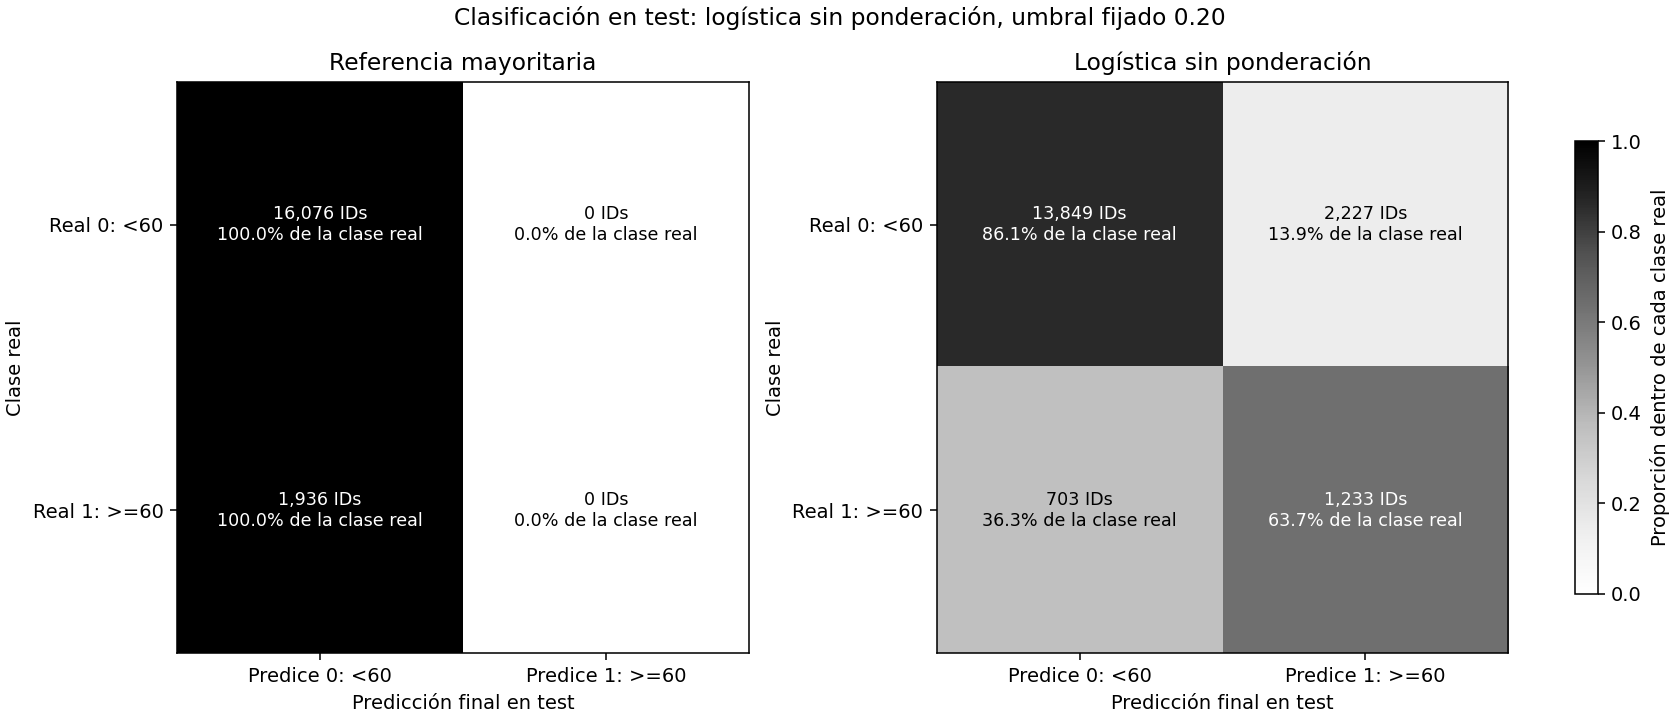

In [48]:
# Construir etiquetas de test únicamente para esta evaluación final ya fijada
if not (y_test.notna().all() and np.isfinite(y_test).all() and y_test.between(0, 100).all()):
    raise ValueError("Revisar popularidad de test antes de construir las etiquetas de evaluación.")
y_clasificacion_test = y_test.ge(corte_popularidad_clasificacion).astype("int8").rename("clase_popularidad_60_test")
assert y_clasificacion_test.index.equals(predicciones_logistica_test.index)
distribucion_clasificacion_test = y_clasificacion_test.value_counts().reindex([0, 1], fill_value=0).to_frame("IDs")
distribucion_clasificacion_test["Porcentaje de test"] = distribucion_clasificacion_test["IDs"] / len(y_clasificacion_test) * 100
registros_clasificacion_test = []
matrices_clasificacion_test = {}
for nombre, pred in {"Referencia mayoritaria": predicciones_mayoria_clasificacion_test, "Logística sin ponderación": predicciones_logistica_test}.items():
    assert pred.index.equals(y_clasificacion_test.index)
    matriz, resumen = resumir_clasificacion(y_clasificacion_test, pred)
    registros_clasificacion_test.append({"Procedimiento": nombre, **resumen})
    matrices_clasificacion_test[nombre] = matriz
    display(pd.DataFrame(matriz, index=["Real 0: <60", "Real 1: >=60"], columns=["Predice 0: <60", "Predice 1: >=60"]).rename_axis(f"Test: {nombre}"))
tabla_metricas_clasificacion_test = pd.DataFrame(registros_clasificacion_test).set_index("Procedimiento")
lectura_metricas_clasificacion_test = tabla_metricas_clasificacion_test[["IDs", "TN", "FP", "FN", "TP", "Positivos predichos", "Precisión positiva definida", "Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy"]].copy()
for metrica in ["Precisión clase 1", "Recall clase 1", "Accuracy"]:
    lectura_metricas_clasificacion_test[metrica] *= 100
lectura_metricas_clasificacion_test = lectura_metricas_clasificacion_test.rename(columns={"Precisión clase 1": "Precisión (%)", "Recall clase 1": "Recall (%)", "Accuracy": "Accuracy (%)"})
resultado_logistica_test = tabla_metricas_clasificacion_test.loc["Logística sin ponderación"]
comparacion_clasificacion_desarrollo_test = pd.DataFrame([
    {"Evaluación": "Validación anidada de entrenamiento", "IDs": int(fila_elegida_clasificacion["IDs"]), "Precisión (%)": float(fila_elegida_clasificacion["Precisión clase 1"]) * 100, "Recall (%)": float(fila_elegida_clasificacion["Recall clase 1"]) * 100, "F1": float(fila_elegida_clasificacion["F1 clase 1"]), "Accuracy (%)": float(fila_elegida_clasificacion["Accuracy"]) * 100},
    {"Evaluación": "Test del procedimiento final", "IDs": len(y_clasificacion_test), "Precisión (%)": resultado_logistica_test["Precisión clase 1"] * 100, "Recall (%)": resultado_logistica_test["Recall clase 1"] * 100, "F1": resultado_logistica_test["F1 clase 1"], "Accuracy (%)": resultado_logistica_test["Accuracy"] * 100}
]).set_index("Evaluación")
ejemplos_clasificacion_test = pd.DataFrame({"Clase real": y_clasificacion_test, "Referencia": predicciones_mayoria_clasificacion_test, "Probabilidad estimada clase 1": probabilidades_logistica_test, "Predicción logística": predicciones_logistica_test})
display(distribucion_clasificacion_test.round(4))
display(lectura_metricas_clasificacion_test.round(4))
display(comparacion_clasificacion_desarrollo_test.round(4))
display(ejemplos_clasificacion_test.head(5).round(4))

# Visualizar conteos y proporciones dentro de cada clase real
import matplotlib.pyplot as plt
fig_clasificacion_test, ejes_clasificacion_test = plt.subplots(1, 2, figsize=(12, 5.2), constrained_layout=True)
for eje, (nombre, matriz) in zip(ejes_clasificacion_test, matrices_clasificacion_test.items()):
    proporciones = matriz / matriz.sum(axis=1, keepdims=True)
    imagen_test = eje.imshow(proporciones, vmin=0, vmax=1, cmap="Greys")
    for fila in range(2):
        for columna in range(2):
            texto = f"{matriz[fila, columna]:,} IDs\n{proporciones[fila, columna] * 100:.1f}% de la clase real"
            eje.text(columna, fila, texto, ha="center", va="center", fontsize=9, color="white" if proporciones[fila, columna] > 0.5 else "black")
    eje.set_xticks([0, 1], ["Predice 0: <60", "Predice 1: >=60"])
    eje.set_yticks([0, 1], ["Real 0: <60", "Real 1: >=60"])
    eje.set_xlabel("Predicción final en test")
    eje.set_ylabel("Clase real")
    eje.set_title(nombre)
fig_clasificacion_test.colorbar(imagen_test, ax=ejes_clasificacion_test, shrink=0.7, label="Proporción dentro de cada clase real")
fig_clasificacion_test.suptitle(f"Clasificación en test: logística sin ponderación, umbral fijado {umbral_final_clasificacion:.2f}")
display(fig_clasificacion_test)
plt.close(fig_clasificacion_test)


#### Cierre de KPI de clasificación y estado final

Las metas predictivas siguen siendo **recall >=60% y precisión >=30%**. Se comprueban ahora sobre el test del procedimiento fijado, sin sustituirlas por metas más fáciles si alguna falla.

**Código, en orden:**

- La tabla final copia los KPI de desarrollo para conservar evidencia y añade alcance. Recall y precisión se actualizan con los resultados de test y estado «Cumple» o «No cumple».
- Los indicadores de etiquetas de entrenamiento, claves de ajuste/validación y cobertura OOF conservan su resultado y alcance de **desarrollo en entrenamiento**; no se presentan como si fueran nuevas mediciones de test.
- Se añaden controles finales separados: IDs y claves no compartidos, cobertura de predicciones en test, etiquetas de test alineadas y parámetros fijados. La cobertura OOF anterior no se confunde con esta cobertura final.
- El cumplimiento se decide con precisión completa; el redondeo solo facilita lectura. Que los controles metodológicos sean correctos no compensa incumplir una meta predictiva.
- El estado final registra que la prueba de clasificación ya fue evaluada. No se ajusta el umbral ni se reemplaza por balanced en función del resultado.

**Recall cumple:** 63,69% >=60%; se identifican 1.233 de las 1.936 positivas reales.

**Precisión cumple:** 35,64% >=30%. De 3.460 canciones señaladas, 1.233 cumplen realmente y 2.227 son falsas alarmas.

El resultado de referencia se conserva como contraste: si predice siempre clase 0 puede tener accuracy alta, pero no identifica positivas y no cumple las metas de identificación. La logística debe justificarse con su matriz y ambas métricas, no solo con el porcentaje global de aciertos.


In [49]:
# Conservar controles de desarrollo y actualizar los KPI predictivos con test
tabla_kpi_clasificacion_test = tabla_kpi_eleccion_clasificacion.copy(deep=True)
tabla_kpi_clasificacion_test["Alcance"] = "Desarrollo: etiquetas y validación agrupada de entrenamiento"
for indicador, valor, cumple in [
    ("Recall clase 1", resultado_logistica_test["Recall clase 1"] * 100, resultado_logistica_test["Recall clase 1"] >= meta_recall_clasificacion),
    ("Precisión clase 1", resultado_logistica_test["Precisión clase 1"] * 100, resultado_logistica_test["Precisión positiva definida"] and resultado_logistica_test["Precisión clase 1"] >= meta_precision_clasificacion)
]:
    tabla_kpi_clasificacion_test.loc[indicador, "Resultado"] = valor
    tabla_kpi_clasificacion_test.loc[indicador, "Estado"] = "Cumple" if cumple else "No cumple"
    tabla_kpi_clasificacion_test.loc[indicador, "Alcance"] = "Evaluación final de clasificación en test"
controles_clasificacion_final_test = pd.Series({
    "Cero IDs compartidos entrenamiento/test": X_train.index.intersection(X_test.index).empty,
    "Cero claves compartidas entrenamiento/test": set(datos_entrenamiento["clave_cancion"]).isdisjoint(set(datos_prueba["clave_cancion"])),
    "Cobertura de predicciones de test del 100%": predicciones_logistica_test.index.equals(X_test.index) and predicciones_logistica_test.notna().all(),
    "Etiquetas reales de test válidas y alineadas": y_clasificacion_test.isin([0, 1]).all() and y_clasificacion_test.index.equals(predicciones_logistica_test.index),
    "Parámetros del estimador sin cambios": modelo_logistico_final.named_steps["clasificar"].get_params() == parametros_finales_logistica,
    "Umbral fijado solo con entrenamiento": umbral_final_clasificacion == decision_final_clasificacion["Umbral de probabilidad fijado"]
})
if not controles_clasificacion_final_test.all():
    raise ValueError("Revisar controles finales antes de cerrar la evaluación de clasificación.")
cumple_kpi_predictivos_clasificacion_test = bool(resultado_logistica_test["Precisión positiva definida"] and resultado_logistica_test["Precisión clase 1"] >= meta_precision_clasificacion and resultado_logistica_test["Recall clase 1"] >= meta_recall_clasificacion)
estado_final_clasificacion = pd.Series({"Procedimiento": "Logística sin ponderación y sin artista", "Umbral fijado": umbral_final_clasificacion, "Ajuste único con todo entrenamiento": "Realizado", "Evaluación de clasificación en test": "Realizada", "Ambas metas predictivas en test": "Cumple" if cumple_kpi_predictivos_clasificacion_test else "No cumple", "Uso posterior de test": "Ya observado; no usar para cambiar el procedimiento y afirmar una confirmación independiente"})
display(tabla_kpi_clasificacion_test.round({"Resultado": 4}))
display(controles_clasificacion_final_test)
display(estado_final_clasificacion)


,Meta,Resultado,Unidad,Estado,Alcance
KPI,,,,,
Recall clase 1,>= 60%,63.6880,%,Cumple,Evaluación final de clasificación en test
Precisión clase 1,>= 30%,35.6358,%,Cumple,Evaluación final de clasificación en test
Etiquetas válidas y alineadas,100%,100.0000,%,Cumple,Desarrollo: etiquetas y validación agrupada de...
Claves compartidas ajuste/validación,0 en cada ronda,0.0000,Máximo de claves compartidas por ronda,Cumple,Desarrollo: etiquetas y validación agrupada de...
Cobertura de predicciones OOF,100%,100.0000,%,Cumple,Desarrollo: etiquetas y validación agrupada de...


Cero IDs compartidos entrenamiento/test         True
Cero claves compartidas entrenamiento/test      True
Cobertura de predicciones de test del 100%      True
Etiquetas reales de test válidas y alineadas    True
Parámetros del estimador sin cambios            True
Umbral fijado solo con entrenamiento            True
dtype: bool

Procedimiento                                    Logística sin ponderación y sin artista
Umbral fijado                                                                        0.2
Ajuste único con todo entrenamiento                                            Realizado
Evaluación de clasificación en test                                            Realizada
Ambas metas predictivas en test                                                   Cumple
Uso posterior de test                  Ya observado; no usar para cambiar el procedim...
dtype: object

#### Conclusión de la evaluación final de clasificación

Se ajustó una única logística **sin ponderación y sin artista** con los 71.728 IDs de entrenamiento y se evaluó sobre los **18.012 IDs de test**, con umbral **0,20** elegido solo con entrenamiento. No se consultaron métricas de test para escogerlo o corregirlo.

| Procedimiento en test | Precisión clase 1 | Recall clase 1 | F1 clase 1 | Accuracy |
|---|---:|---:|---:|---:|
| Referencia mayoritaria | No definida; reporte 0 | 0,00% | 0,0000 | 89,25% |
| Logística sin ponderación | 35,64% | 63,69% | 0,4570 | 83,73% |

La logística identifica **1.233** positivas reales, omite **703** y produce **2.227** falsas alarmas; reconoce correctamente **13.849** negativas. En total señala **3.460** canciones, de las que **1.233** cumplen el corte.

**Cumple ambas metas predictivas iniciales en este test interno.** Este cumplimiento no equivale a ausencia de errores ni garantiza desempeño futuro.

**Por qué no se elige por accuracy:** la referencia alcanza 89,25% de accuracy frente a 83,73% de la logística, pero no detecta ninguna de las 1.936 positivas: recall=0 y F1=0. La logística sí cumple las dos metas que responden al objetivo de identificación. Aun así, 2.227 de sus 3.460 canciones señaladas son falsas alarmas: el cumplimiento de la meta académica de precisión no elimina esa carga de revisión.

**Comparación con desarrollo:** en la validación anidada, precisión=34,68%, recall=61,11% y F1=0,4425. El test corresponde a otras canciones y a un modelo ajustado con más datos. La coincidencia o diferencia de métricas no demuestra ausencia de sobreajuste o fuga ni garantiza comportamiento futuro. La fuente ya fue explorada y test se había observado para regresión.

Los controles de separación y cobertura final se verificaron. No se eliminaron canciones difíciles, no se ajustó el umbral después de observar test y no se sustituyó el modelo por balanced. La referencia ilustra por qué accuracy sola no responde al objetivo de identificar positivas.

**Estado de esta tarea:** evaluación final interna de clasificación realizada, con cumplimiento e incumplimientos documentados según corresponda. No termina automáticamente los contenidos pendientes de unidad 2. Cualquier cambio posterior guiado por estos resultados requerirá nueva evidencia independiente para confirmarse; este test ya está observado para ambas tareas supervisadas.


<a id="clasificacion-con-artista"></a>
### 9.3. Cuatro modelos de clasificación con artista

Se incorporan **logística, árbol, KNN e HistGradientBoosting con artista** y se comparan con sus versiones sin artista. Permanecen las mismas 71.728 canciones de entrenamiento, tres particiones externas agrupadas, configuraciones de los estimadores, clase 1=popularidad >=60 y metas de precisión >=30% y recall >=60%. Ninguno de los cuatro recibe ponderación de clases en esta comparación principal; la logística balanced anterior sigue siendo un experimento complementario.

La diferencia de entrada es **una característica de artista**, añadida a las 127 anteriores. Las categorías y géneros mantienen su representación propia de cada algoritmo. No se cambia a la vez la profundidad, k, cantidad de etapas ni parámetros para favorecer la variante con artista.

#### 9.3.1. Cómo representar al artista sin usar la propia respuesta

El texto del artista se recupera de la clave normalizada ya preparada; colaboraciones se separan por `;` y se eliminan nombres repetidos dentro de una canción. Se conserva la limitación de nombres no verificados y posibles reediciones no reconocidas por esa clave.

**Aquí se codifica la etiqueta binaria de clasificación**, no el puntaje continuo de popularidad de regresión. Para cada artista:

`valor = (cantidad de positivas permitidas + 10 × proporción global de positivas permitidas) / (cantidad de canciones permitidas + 10)`

El 10 es un suavizado fijado antes de evaluar. Acerca estimaciones con pocos ejemplos a la proporción global del ajuste. En colaboraciones se promedian valores de sus artistas; un artista desconocido recibe esa proporción global. El valor está entre 0 y 1, pero no es por sí solo una probabilidad calibrada de éxito ni una medida de calidad musical.

**Tres niveles de separación cuando se elige umbral:**

1. La validación externa no participa en el entrenamiento, mapas ni elección del umbral.
2. Dentro de su ajuste externo se hacen tres rondas internas para elegir el umbral. Cada mapa de una validación interna se aprende solo con su ajuste interno.
3. Incluso las canciones que se usan para ajustar el modelo reciben una codificación **cruzada de cinco grupos de claves**, excluyendo su propia respuesta y las versiones de su clave. No se calcula primero el artista con todo entrenamiento para luego dividir.

Para predecir una validación se aprende por separado un mapa con todo su ajuste permitido y se aplica sin respuestas de la consulta. Las escalas del pipeline se aprenden con las codificaciones cruzadas del ajuste. **No se reutilizan mapas finales de regresión o clasificación ni un mapa global fuera de los pliegues.**

**Lectura del código:** `mapa_artista_clasificacion` alinea índices, calcula la proporción permitida y usa `explode` para asignar la respuesta a cada colaborador. `groupby` cuenta positivas y canciones; la fórmula aplica suavizado. `aplicar_artista_clasificacion` consulta el mapa y usa respaldo para desconocidos, sin recibir etiquetas. `artista_cruzado_clasificacion` reparte claves en cinco grupos y construye cada valor con los otros cuatro. `preparar_artista_clasificacion` crea copias de X, añade `artista_clase_1` y devuelve un control de cobertura de artistas. La prueba ficticia cambia todas las respuestas de una clave y comprueba que su propio valor no cambie.

El mapa completo de ajuste y el mapa cruzado pueden tener distintas cantidades de canciones por artista; esa diferencia puede afectar artistas raros. Se trata de información del catálogo de esta partición, no de un historial cronológico verificado, porque faltan fechas.


In [58]:
# Crear funciones de artista específicas para la etiqueta binaria de clasificación
artistas_clasificacion_train = recuperar_artistas(datos_entrenamiento["clave_cancion"])
suavizado_artista_clasificacion = 10.0
assert artistas_clasificacion_train.index.equals(y_clasificacion_train.index)
assert artistas_clasificacion_train.map(len).gt(0).all()

def mapa_artista_clasificacion(artistas, etiquetas, suavizado=10.0):
    assert artistas.index.equals(etiquetas.index) and etiquetas.isin([0, 1]).all()
    proporcion = float(etiquetas.mean())
    detalle = pd.DataFrame({"Artista": artistas, "Positiva": etiquetas}).explode("Artista")
    conteos = detalle.groupby("Artista")["Positiva"].agg(["sum", "count"])
    valores = (conteos["sum"] + suavizado * proporcion) / (conteos["count"] + suavizado)
    return valores.to_dict(), proporcion

def aplicar_artista_clasificacion(artistas, mapa, respaldo):
    return artistas.map(lambda nombres: float(np.mean([mapa.get(nombre, respaldo) for nombre in nombres])) if nombres else respaldo)

def artista_cruzado_clasificacion(artistas, etiquetas, claves):
    assert artistas.index.equals(etiquetas.index) and claves.index.equals(etiquetas.index)
    unicas = claves.drop_duplicates().sort_values().sample(frac=1, random_state=42).reset_index(drop=True)
    assert len(unicas) >= 5
    grupos = claves.map(pd.Series(np.arange(len(unicas)) % 5, index=unicas))
    valores = pd.Series(index=etiquetas.index, dtype="float64")
    visitas = pd.Series(0, index=etiquetas.index, dtype="int8")
    for grupo in range(5):
        consulta = grupos.eq(grupo)
        fuente = ~consulta
        assert set(claves.loc[consulta]).isdisjoint(set(claves.loc[fuente]))
        mapa, respaldo = mapa_artista_clasificacion(artistas.loc[fuente], etiquetas.loc[fuente], suavizado_artista_clasificacion)
        valores.loc[consulta] = aplicar_artista_clasificacion(artistas.loc[consulta], mapa, respaldo)
        visitas.loc[consulta] += 1
    assert visitas.eq(1).all() and valores.notna().all() and valores.between(0, 1).all()
    return valores

def preparar_artista_clasificacion(X_ajuste, y_ajuste, claves_ajuste, artistas_ajuste, X_consulta, artistas_consulta):
    assert X_ajuste.index.equals(y_ajuste.index) and artistas_consulta.index.equals(X_consulta.index)
    codigo_ajuste = artista_cruzado_clasificacion(artistas_ajuste, y_ajuste, claves_ajuste)
    mapa, respaldo = mapa_artista_clasificacion(artistas_ajuste, y_ajuste, suavizado_artista_clasificacion)
    codigo_consulta = aplicar_artista_clasificacion(artistas_consulta, mapa, respaldo)
    ajuste = X_ajuste.copy()
    consulta = X_consulta.copy()
    ajuste["artista_clase_1"] = codigo_ajuste
    consulta["artista_clase_1"] = codigo_consulta
    assert codigo_consulta.notna().all() and codigo_consulta.between(0, 1).all()
    sin_conocidos = artistas_consulta.map(lambda nombres: all(nombre not in mapa for nombre in nombres))
    control = {"IDs ajuste": len(ajuste), "IDs consulta": len(consulta), "Consulta sin ningún artista conocido (%)": float(sin_conocidos.mean() * 100), "Proporción positiva de respaldo": respaldo}
    return ajuste, consulta, control

# Control ficticio: cambiar toda una clave no altera su propia codificación
claves_prueba_artista = pd.Series(["a", "a", "b", "c", "d", "e", "f", "g", "h", "i", "j", "k"])
nombres_prueba_artista = pd.Series([["artista común"] for _ in claves_prueba_artista])
etiquetas_prueba_artista = pd.Series([0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0], dtype="int8")
valores_prueba_1 = artista_cruzado_clasificacion(nombres_prueba_artista, etiquetas_prueba_artista, claves_prueba_artista)
etiquetas_prueba_cambiadas = etiquetas_prueba_artista.copy()
etiquetas_prueba_cambiadas.loc[claves_prueba_artista.eq("a")] = 1
valores_prueba_2 = artista_cruzado_clasificacion(nombres_prueba_artista, etiquetas_prueba_cambiadas, claves_prueba_artista)
assert np.allclose(valores_prueba_1.loc[claves_prueba_artista.eq("a")], valores_prueba_2.loc[claves_prueba_artista.eq("a")])
display(pd.Series({"Exclusión ficticia de la propia clave comprobada": True, "IDs de entrenamiento con nombres recuperados": len(artistas_clasificacion_train), "Suavizado fijado": suavizado_artista_clasificacion}))


Exclusión ficticia de la propia clave comprobada     True
IDs de entrenamiento con nombres recuperados        71728
Suavizado fijado                                     10.0
dtype: object

#### 9.3.2. Los cuatro modelos con artista: mismas configuraciones y evaluación OOF a 0,50

Se clonan las cuatro plantillas sin artista. La selección de columnas del bloque numérico se amplía a once para incorporar `artista_clase_1`; el resto del pipeline y todos los parámetros de los estimadores se conservan. Logística sigue con C=1 y sin pesos; árbol con profundidad 4 y hoja mínima 50; KNN con 15 vecinos uniformes; HistGradientBoosting con 600 etapas, tasa 0,03, máximo 63 hojas y sin parada temprana.

**Código, en orden:** `clone` crea plantillas limpias y la lista de transformadores añade la columna solo al bloque numérico. La función de ajuste verifica alineación, convergencia, medianas y cantidad de filas vistas por el escalador; para KNN también comprueba que conserve solo el ajuste. La función de probabilidad localiza clase 1 y utiliza lotes de 256 para KNN, manteniendo búsqueda entre todo el ajuste.

En cada ronda externa, `preparar_artista_clasificacion` construye una vez las dos matrices permitidas y se reutilizan para los cuatro algoritmos. No depende del modelo ni de respuestas externas. Cada algoritmo aprende su preparación con las filas de ajuste. Se guardan probabilidades y etiquetas a 0,50 por ID, y una Serie de visitas verifica una validación externa por observación. El mapa no se aprende con artistas de toda la base antes de dividir.

Los resultados se calculan con `resumir_clasificacion`, sin ponderar la evaluación. Las matrices mantienen `[[TN, FP], [FN, TP]]`. Precisión y recall están en escala 0–1 en las tablas de cálculo; se mostrarán como porcentajes en la comparación final. Este primer resultado a 0,50 mide el aporte del artista sin cambiar al mismo tiempo la regla de decisión.


In [59]:
# Clonar los cuatro modelos sin cambiar sus configuraciones y añadir una entrada numérica
plantillas_cuatro_con_artista = {nombre: clone(plantilla) for nombre, plantilla in plantillas_cuatro_sin_artista.items()}
columnas_numericas_con_artista = columnas_numericas_modelo + ["artista_clase_1"]
for nombre, plantilla in plantillas_cuatro_con_artista.items():
    preparador = plantilla.named_steps["preparar"]
    preparador.transformers = [(bloque, transformacion, columnas_numericas_con_artista if bloque == "numericas" else columnas) for bloque, transformacion, columnas in preparador.transformers]
    assert plantilla.named_steps["clasificar"].get_params() == plantillas_cuatro_sin_artista[nombre].named_steps["clasificar"].get_params()

def ajustar_clasificador_con_artista(plantilla, X_ajuste, y_ajuste):
    assert X_ajuste.index.equals(y_ajuste.index) and y_ajuste.nunique() == 2
    modelo = clone(plantilla)
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        modelo.fit(X_ajuste, y_ajuste)
    if any(issubclass(aviso.category, ConvergenceWarning) for aviso in avisos):
        raise ValueError("Revisar convergencia del clasificador con artista.")
    numericas = modelo.named_steps["preparar"].named_transformers_["numericas"]
    assert np.allclose(numericas.named_steps["imputar"].statistics_, X_ajuste[columnas_numericas_con_artista].median())
    assert int(numericas.named_steps["escalar"].n_samples_seen_) == len(y_ajuste)
    assert np.isclose(numericas.named_steps["escalar"].mean_[-1], X_ajuste["artista_clase_1"].mean())
    clasificador = modelo.named_steps["clasificar"]
    if hasattr(clasificador, "class_weight"):
        assert clasificador.class_weight is None
    if isinstance(clasificador, KNeighborsClassifier):
        assert clasificador.n_samples_fit_ == len(y_ajuste)
    return modelo

def probabilidades_clase_1_con_artista(modelo, X_consulta):
    clasificador = modelo.named_steps["clasificar"]
    columna = list(clasificador.classes_).index(1)
    probabilidades = pd.Series(index=X_consulta.index, dtype="float64")
    lote = 256 if isinstance(clasificador, KNeighborsClassifier) else len(X_consulta)
    for inicio in range(0, len(X_consulta), lote):
        consulta = X_consulta.iloc[inicio:inicio + lote]
        probabilidades.loc[consulta.index] = modelo.predict_proba(consulta)[:, columna]
    assert np.isfinite(probabilidades).all() and probabilidades.between(0, 1).all()
    return probabilidades

probabilidades_cuatro_con_artista = {nombre: pd.Series(index=y_clasificacion_train.index, dtype="float64") for nombre in plantillas_cuatro_con_artista}
visitas_con_artista = pd.Series(0, index=y_clasificacion_train.index, dtype="int8")
controles_artista_externos = []
for externa in range(numero_pliegues):
    print(f"OOF con artista: ronda externa {externa + 1} de 3")
    validar = pliegue_por_id.eq(externa)
    ajustar = ~validar
    claves_ajuste = datos_entrenamiento.loc[ajustar, "clave_cancion"]
    assert set(claves_ajuste).isdisjoint(set(datos_entrenamiento.loc[validar, "clave_cancion"]))
    X_ajuste_artista, X_validacion_artista, control_artista = preparar_artista_clasificacion(X_train.loc[ajustar], y_clasificacion_train.loc[ajustar], claves_ajuste, artistas_clasificacion_train.loc[ajustar], X_train.loc[validar], artistas_clasificacion_train.loc[validar])
    controles_artista_externos.append({"Ronda externa": externa + 1, **control_artista})
    for nombre, plantilla in plantillas_cuatro_con_artista.items():
        modelo = ajustar_clasificador_con_artista(plantilla, X_ajuste_artista, y_clasificacion_train.loc[ajustar])
        probabilidades_cuatro_con_artista[nombre].loc[validar] = probabilidades_clase_1_con_artista(modelo, X_validacion_artista)
    visitas_con_artista.loc[validar] += 1
assert visitas_con_artista.eq(1).all()
predicciones_fijas_con_artista = {nombre: prob.ge(0.50).astype("int8") for nombre, prob in probabilidades_cuatro_con_artista.items()}
filas_fijas_con_artista = []
matrices_fijas_con_artista = {}
for nombre, pred in predicciones_fijas_con_artista.items():
    assert pred.index.equals(y_clasificacion_train.index) and pred.notna().all()
    matriz, metricas = resumir_clasificacion(y_clasificacion_train, pred)
    matrices_fijas_con_artista[nombre] = matriz
    filas_fijas_con_artista.append({"Modelo": nombre, **metricas, "Cumple precisión": bool(metricas["Precisión positiva definida"] and metricas["Precisión clase 1"] >= meta_precision_clasificacion), "Cumple recall": bool(metricas["Recall clase 1"] >= meta_recall_clasificacion)})
tabla_cuatro_fija_con_artista = pd.DataFrame(filas_fijas_con_artista).set_index("Modelo")
tabla_cuatro_fija_con_artista["Cumple ambos KPI"] = tabla_cuatro_fija_con_artista["Cumple precisión"] & tabla_cuatro_fija_con_artista["Cumple recall"]
display(tabla_cuatro_fija_con_artista.round(4))
display(pd.DataFrame(controles_artista_externos).set_index("Ronda externa").round(4))


OOF con artista: ronda externa 1 de 3
OOF con artista: ronda externa 2 de 3
OOF con artista: ronda externa 3 de 3


,IDs,TN,FP,FN,TP,Positivos predichos,Precisión positiva definida,Precisión clase 1,Recall clase 1,F1 clase 1,Accuracy,Cumple precisión,Cumple recall,Cumple ambos KPI
Modelo,,,,,,,,,,,,,,
Logística,71728,62342,1525,5226,2635,4160,True,0.6334,0.3352,0.4384,0.9059,True,False,False
Árbol,71728,62571,1296,5617,2244,3540,True,0.6339,0.2855,0.3936,0.9036,True,False,False
KNN,71728,62307,1560,5320,2541,4101,True,0.6196,0.3232,0.4248,0.9041,True,False,False
HistGradientBoosting,71728,61916,1951,4526,3335,5286,True,0.6309,0.4242,0.5073,0.9097,True,False,False


,IDs ajuste,IDs consulta,Consulta sin ningún artista conocido (%),Proporción positiva de respaldo
Ronda externa,,,,
1,47815,23913,11.3537,0.1085
2,47624,24104,11.8901,0.1102
3,48017,23711,11.6697,0.1101


#### 9.3.3. Validación anidada del umbral con artista

Se conserva la misma lista de 16 umbrales, las tres rondas externas y tres internas agrupadas por ajuste, elegibilidad por ambas metas, mayor F1 entre elegibles, desempate por umbral mayor y respaldo 0,50 si no hay candidato. El protocolo es igual al utilizado sin artista.

**La diferencia importante está en preparar la entrada:** en cada ronda interna se vuelve a construir el artista solo con ajuste interno. Sus propias filas reciben valores cruzados de cinco grupos; la validación interna recibe el mapa completo de ese ajuste interno. No se reutiliza la característica ya preparada para el ajuste externo, porque incluiría respuestas de su validación interna.

**Código, en orden:** para cada ajuste externo se ordenan y reparten sus claves internas con semilla 42. Se reservan probabilidades internas por modelo. Dentro de cada ronda interna se verifica separación de claves, se crean las matrices de artista permitidas y se ajustan los cuatro pipelines. Se comprueba que cada ID del ajuste externo tenga una validación interna.

Después se calcula la tabla de umbrales para cada modelo con sus probabilidades internas. Se fija uno por la regla anterior, antes de usar las probabilidades externas ya guardadas. Si falta candidato se registra el respaldo sin declararlo exitoso. El umbral se aplica a la probabilidad externa correspondiente y se registra una visita por ID. Las respuestas externas se utilizarán solo para evaluar después.

Son **36 ajustes internos nuevos** y 12 externos para los cuatro modelos. La codificación de artista añade una separación adicional dentro de cada ajuste; sus cinco grupos son de codificación, no cinco modelos extra. No se ajustan hiperparámetros ni se amplía la lista en función de la evaluación externa. Se conservan todas las rondas, incluso las difíciles.


In [60]:
# Separar la selección interna del umbral de su evaluación externa, también al codificar artista
predicciones_anidadas_con_artista = {nombre: pd.Series(index=y_clasificacion_train.index, dtype="float64") for nombre in plantillas_cuatro_con_artista}
selecciones_con_artista = {nombre: [] for nombre in plantillas_cuatro_con_artista}
evidencia_anidada_con_artista = {}
visitas_anidadas_con_artista = pd.Series(0, index=y_clasificacion_train.index, dtype="int8")
for externa in range(numero_pliegues):
    validar_externo = pliegue_por_id.eq(externa)
    ajustar_externo = ~validar_externo
    claves_externas_ajuste = datos_entrenamiento.loc[ajustar_externo, "clave_cancion"]
    assert set(claves_externas_ajuste).isdisjoint(set(datos_entrenamiento.loc[validar_externo, "clave_cancion"]))
    claves_internas = claves_externas_ajuste.drop_duplicates().sort_values().sample(frac=1, random_state=42).reset_index(drop=True)
    grupos_internos = claves_externas_ajuste.map(pd.Series(np.arange(len(claves_internas)) % 3, index=claves_internas))
    prob_internas_por_modelo = {nombre: pd.Series(index=claves_externas_ajuste.index, dtype="float64") for nombre in plantillas_cuatro_con_artista}
    visitas_internas = pd.Series(0, index=claves_externas_ajuste.index, dtype="int8")
    controles_internos_artista = []
    for interna in range(3):
        print(f"Con artista: selección interna, externa {externa + 1}/3 e interna {interna + 1}/3")
        ids_validar = grupos_internos.index[grupos_internos.eq(interna)]
        ids_ajustar = grupos_internos.index[grupos_internos.ne(interna)]
        claves_ajuste_interno = datos_entrenamiento.loc[ids_ajustar, "clave_cancion"]
        claves_validacion_interna = datos_entrenamiento.loc[ids_validar, "clave_cancion"]
        assert set(claves_ajuste_interno).isdisjoint(set(claves_validacion_interna))
        assert set(ids_validar).isdisjoint(set(y_clasificacion_train.index[validar_externo]))
        X_ajuste_interno_artista, X_validacion_interna_artista, control = preparar_artista_clasificacion(X_train.loc[ids_ajustar], y_clasificacion_train.loc[ids_ajustar], claves_ajuste_interno, artistas_clasificacion_train.loc[ids_ajustar], X_train.loc[ids_validar], artistas_clasificacion_train.loc[ids_validar])
        controles_internos_artista.append({"Ronda interna": interna + 1, "Claves compartidas": 0, **control})
        for nombre, plantilla in plantillas_cuatro_con_artista.items():
            modelo = ajustar_clasificador_con_artista(plantilla, X_ajuste_interno_artista, y_clasificacion_train.loc[ids_ajustar])
            prob_internas_por_modelo[nombre].loc[ids_validar] = probabilidades_clase_1_con_artista(modelo, X_validacion_interna_artista)
        visitas_internas.loc[ids_validar] += 1
    assert visitas_internas.eq(1).all()
    evidencia_modelos = {}
    for nombre in plantillas_cuatro_con_artista:
        prob_internas = prob_internas_por_modelo[nombre]
        assert prob_internas.notna().all() and prob_internas.index.equals(claves_externas_ajuste.index)
        filas_umbrales = []
        for umbral in umbrales_cuatro_sin_artista:
            _, metricas = resumir_clasificacion(y_clasificacion_train.loc[prob_internas.index], prob_internas.ge(umbral).astype("int8"))
            elegible = metricas["Precisión positiva definida"] and metricas["Precisión clase 1"] >= meta_precision_clasificacion and metricas["Recall clase 1"] >= meta_recall_clasificacion
            filas_umbrales.append({"Umbral": float(umbral), **metricas, "Elegible": bool(elegible)})
        tabla_interna = pd.DataFrame(filas_umbrales).set_index("Umbral")
        elegibles = tabla_interna.reset_index().loc[lambda tabla: tabla["Elegible"]].sort_values(["F1 clase 1", "Umbral"], ascending=[False, False])
        umbral_usado = 0.50 if elegibles.empty else float(elegibles.iloc[0]["Umbral"])
        fila_interna = tabla_interna.loc[umbral_usado]
        selecciones_con_artista[nombre].append({"Ronda externa": externa + 1, "Umbral usado": umbral_usado, "Hubo candidato interno elegible": not elegibles.empty, "Precisión interna (%)": fila_interna["Precisión clase 1"] * 100, "Recall interno (%)": fila_interna["Recall clase 1"] * 100, "F1 interno": fila_interna["F1 clase 1"]})
        predicciones_anidadas_con_artista[nombre].loc[validar_externo] = probabilidades_cuatro_con_artista[nombre].loc[validar_externo].ge(umbral_usado).astype("int8")
        evidencia_modelos[nombre] = {"Tabla de umbrales": tabla_interna, "Probabilidades internas": prob_internas}
    evidencia_anidada_con_artista[externa + 1] = {"Modelos": evidencia_modelos, "Controles": pd.DataFrame(controles_internos_artista)}
    visitas_anidadas_con_artista.loc[validar_externo] += 1
assert visitas_anidadas_con_artista.eq(1).all()
for nombre in predicciones_anidadas_con_artista:
    assert predicciones_anidadas_con_artista[nombre].notna().all()
    predicciones_anidadas_con_artista[nombre] = predicciones_anidadas_con_artista[nombre].astype("int8")
    selecciones_con_artista[nombre] = pd.DataFrame(selecciones_con_artista[nombre]).set_index("Ronda externa")
    display(selecciones_con_artista[nombre].round(4))


Con artista: selección interna, externa 1/3 e interna 1/3
Con artista: selección interna, externa 1/3 e interna 2/3
Con artista: selección interna, externa 1/3 e interna 3/3
Con artista: selección interna, externa 2/3 e interna 1/3
Con artista: selección interna, externa 2/3 e interna 2/3
Con artista: selección interna, externa 2/3 e interna 3/3
Con artista: selección interna, externa 3/3 e interna 1/3
Con artista: selección interna, externa 3/3 e interna 2/3
Con artista: selección interna, externa 3/3 e interna 3/3


,Umbral usado,Hubo candidato interno elegible,Precisión interna (%),Recall interno (%),F1 interno
Ronda externa,,,,,
1,0.2,True,43.2126,64.5857,0.5178
2,0.2,True,44.2274,66.4506,0.5311
3,0.2,True,43.9535,65.1154,0.5248


,Umbral usado,Hubo candidato interno elegible,Precisión interna (%),Recall interno (%),F1 interno
Ronda externa,,,,,
1,0.15,True,39.5050,63.3526,0.4866
2,0.25,True,42.9674,64.7541,0.5166
3,0.50,False,57.5333,31.0632,0.4034


,Umbral usado,Hubo candidato interno elegible,Precisión interna (%),Recall interno (%),F1 interno
Ronda externa,,,,,
1,0.20,True,37.4232,68.0539,0.4829
2,0.25,True,44.4460,60.2554,0.5116
3,0.20,True,38.2207,68.3504,0.4903


,Umbral usado,Hubo candidato interno elegible,Precisión interna (%),Recall interno (%),F1 interno
Ronda externa,,,,,
1,0.25,True,46.1910,64.4894,0.5383
2,0.30,True,51.3027,61.9329,0.5612
3,0.25,True,46.8317,65.8532,0.5474


#### 9.3.4. Comparar con y sin artista: matrices, métricas y KPI

Se muestran dos comparaciones separadas: a 0,50 fijo y con selección anidada comparable. La primera mantiene la misma regla numérica; la segunda evalúa preparación, modelo y selección interna de umbral. Cada comparación usa los mismos IDs y respuestas externas; el aumento o caída de F1 se atribuye al **procedimiento con esta representación del artista**, no a una causa de popularidad.

**Código, en orden:** se evalúan predicciones externas anidadas de los cuatro modelos con artista, se guardan matrices y resultados por ronda y se comparan con las metas sin redondear. Se reúnen las tablas previas sin artista y las nuevas, preservando la evidencia original. Las diferencias son `con artista − sin artista`: para precisión y recall se presentan en puntos porcentuales; F1 conserva su unidad.

La tabla de KPI del apartado mantiene etiquetas válidas, cero claves compartidas y cobertura OOF. Precisión y recall se comprueban por modelo y se informan las rondas que fallen. No se interpreta cobertura correcta como compensación de un KPI predictivo incumplido. La referencia mayoritaria no cambia con la incorporación del artista.

Se elige provisionalmente por mayor F1 solo entre quienes cumplen ambas metas globales. Se informa el mejor con artista y la comparación de ocho procedimientos. Esto es otra decisión de desarrollo sobre validaciones ya exploradas; no una prueba final externa independiente. **Esta comparación de desarrollo no evalúa ningún modelo con artista en test; la evaluación posterior del procedimiento fijado se documenta en 9.3.6–9.3.9.**

El gráfico compara las métricas anidadas por familia, con y sin artista. MAE, RMSE y R² de regresión no entran en esta tabla de clasificación. En los paneles de precisión y recall se dibujan las metas; F1 no recibe un umbral nuevo retrospectivo.


Precisión clase 1  ...  Cumple recall
Escenario   Modelo                                   ...               
Sin artista Logística                        0.5702  ...          False
            Árbol                            0.6335  ...          False
            KNN                              0.5906  ...          False
            HistGradientBoosting             0.5990  ...          False
Con artista Logística                        0.6334  ...          False
            Árbol                            0.6339  ...          False
            KNN                              0.6196  ...          False
            HistGradientBoosting             0.6309  ...          False

[8 rows x 5 columns]

Precisión (%)  ...  Cobertura OOF (%)
Escenario   Modelo                               ...                   
Sin artista Logística                   34.6759  ...              100.0
            Árbol                       63.3540  ...              100.0
            KNN                         59.0597  ...              100.0
            HistGradientBoosting        38.6911  ...              100.0
Con artista Logística                   45.5722  ...              100.0
            Árbol                       46.9602  ...              100.0
            KNN                         40.9230  ...              100.0
            HistGradientBoosting        48.1536  ...              100.0

[8 rows x 9 columns]

,Cambio precisión (puntos porcentuales),Cambio recall (puntos porcentuales),Cambio F1
Modelo,,,
Logística,10.8963,5.2029,0.0977
Árbol,-16.3938,40.6946,0.2980
KNN,-18.1367,53.7972,0.2818
HistGradientBoosting,9.4625,1.3739,0.0737


Umbral usado  ...  Cumple recall
Modelo               Ronda                ...               
Logística            1              0.20  ...           True
                     2              0.20  ...           True
                     3              0.20  ...           True
Árbol                1              0.15  ...           True
                     2              0.25  ...           True
                     3              0.50  ...          False
KNN                  1              0.20  ...           True
                     2              0.25  ...           True
                     3              0.20  ...           True
HistGradientBoosting 1              0.25  ...           True
                     2              0.30  ...           True
                     3              0.25  ...           True

[12 rows x 6 columns]

,Etiquetas válidas (%),Máximo claves compartidas internas,Cobertura OOF (%),Cumple precisión,Cumple recall
Modelo,,,,,
Logística,100.0,0,100.0,True,True
Árbol,100.0,0,100.0,True,False
KNN,100.0,0,100.0,True,True
HistGradientBoosting,100.0,0,100.0,True,True


,Predice 0: <60,Predice 1: >=60
Logística con artista: evaluación externa anidada,,
Real 0: <60,57641,6226
Real 1: >=60,2648,5213


,Predice 0: <60,Predice 1: >=60
Árbol con artista: evaluación externa anidada,,
Real 0: <60,59217,4650
Real 1: >=60,3744,4117


,Predice 0: <60,Predice 1: >=60
KNN con artista: evaluación externa anidada,,
Real 0: <60,56148,7719
Real 1: >=60,2514,5347


,Predice 0: <60,Predice 1: >=60
HistGradientBoosting con artista: evaluación externa anidada,,
Real 0: <60,58181,5686
Real 1: >=60,2580,5281


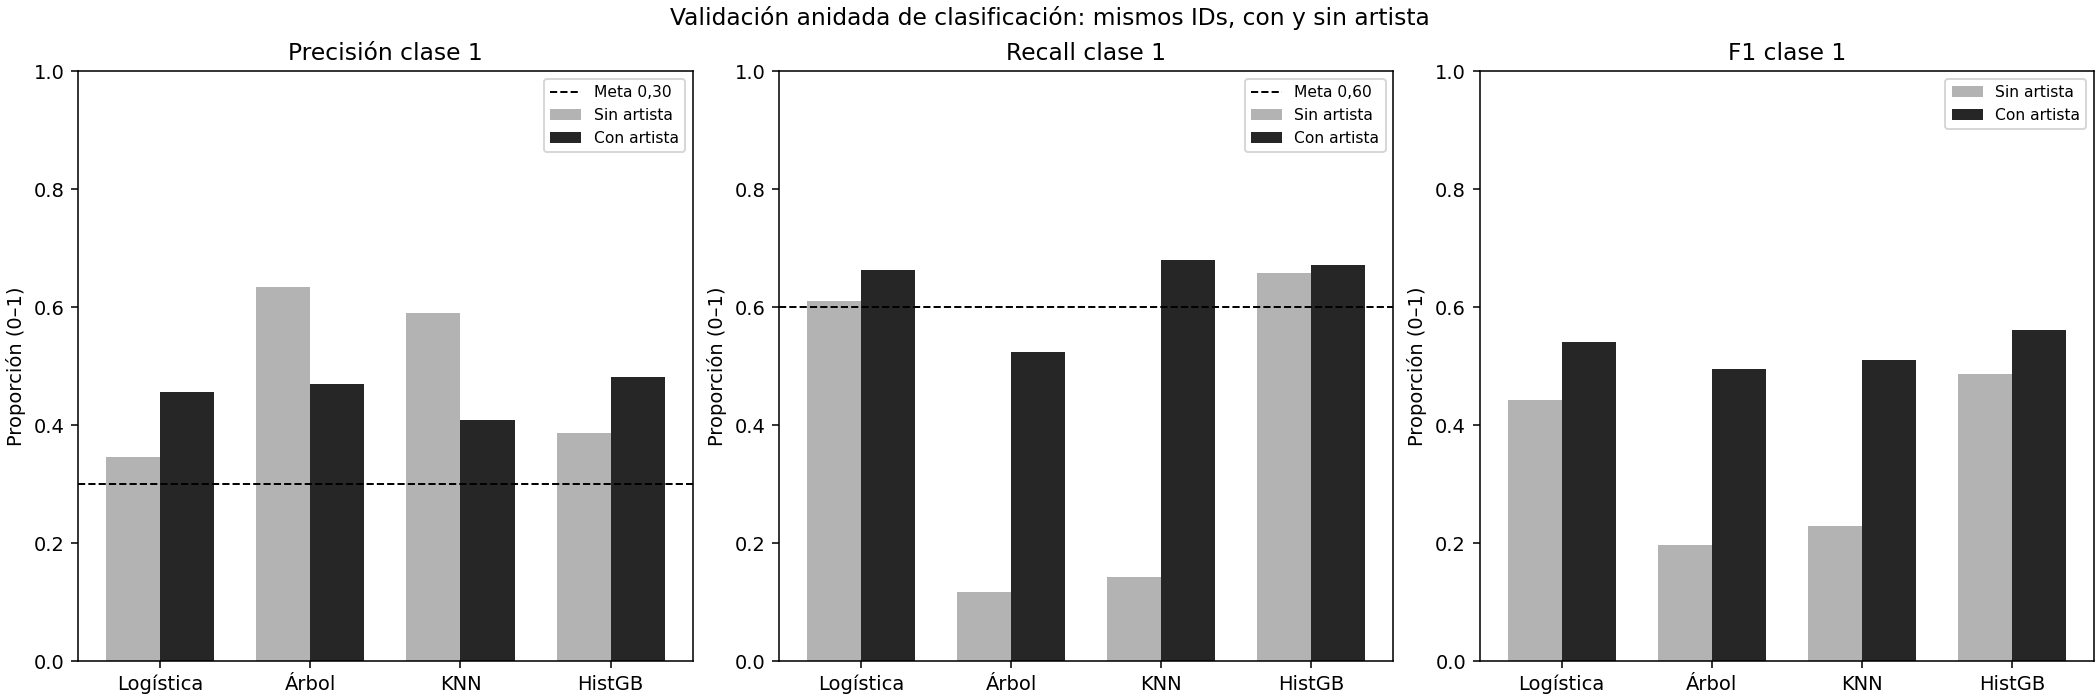

In [61]:
# Evaluar los cuatro procedimientos anidados con artista y comprobar las mismas metas
filas_anidadas_con_artista = []
filas_rondas_con_artista = []
matrices_anidadas_con_artista = {}
for nombre, pred in predicciones_anidadas_con_artista.items():
    assert pred.index.equals(y_clasificacion_train.index)
    matriz, metricas = resumir_clasificacion(y_clasificacion_train, pred)
    matrices_anidadas_con_artista[nombre] = matriz
    cumple_precision = metricas["Precisión positiva definida"] and metricas["Precisión clase 1"] >= meta_precision_clasificacion
    cumple_recall = metricas["Recall clase 1"] >= meta_recall_clasificacion
    filas_anidadas_con_artista.append({"Modelo": nombre, **metricas, "Cumple precisión": bool(cumple_precision), "Cumple recall": bool(cumple_recall), "Cumple ambos KPI": bool(cumple_precision and cumple_recall), "Respaldos internos": int((~selecciones_con_artista[nombre]["Hubo candidato interno elegible"]).sum()), "Cobertura OOF (%)": pred.notna().mean() * 100, "Etiquetas válidas (%)": y_clasificacion_train.isin([0, 1]).mean() * 100, "Máximo claves compartidas internas": 0})
    for externa in range(numero_pliegues):
        en_ronda = pliegue_por_id.eq(externa)
        _, medidas = resumir_clasificacion(y_clasificacion_train.loc[en_ronda], pred.loc[en_ronda])
        filas_rondas_con_artista.append({"Modelo": nombre, "Ronda": externa + 1, "Umbral usado": float(selecciones_con_artista[nombre].loc[externa + 1, "Umbral usado"]), **medidas, "Cumple precisión": bool(medidas["Precisión positiva definida"] and medidas["Precisión clase 1"] >= meta_precision_clasificacion), "Cumple recall": bool(medidas["Recall clase 1"] >= meta_recall_clasificacion)})
tabla_cuatro_anidada_con_artista = pd.DataFrame(filas_anidadas_con_artista).set_index("Modelo")
tabla_rondas_con_artista = pd.DataFrame(filas_rondas_con_artista).set_index(["Modelo", "Ronda"])
comparacion_fija_artista = pd.concat({"Sin artista": tabla_cuatro_fija.loc[list(plantillas_cuatro_con_artista)], "Con artista": tabla_cuatro_fija_con_artista}, names=["Escenario", "Modelo"])
comparacion_anidada_artista = pd.concat({"Sin artista": tabla_cuatro_anidada, "Con artista": tabla_cuatro_anidada_con_artista}, names=["Escenario", "Modelo"])
diferencias_clasificacion_artista = tabla_cuatro_anidada_con_artista[["Precisión clase 1", "Recall clase 1", "F1 clase 1"]] - tabla_cuatro_anidada[["Precisión clase 1", "Recall clase 1", "F1 clase 1"]]
diferencias_clasificacion_artista["Precisión clase 1"] *= 100
diferencias_clasificacion_artista["Recall clase 1"] *= 100
diferencias_clasificacion_artista = diferencias_clasificacion_artista.rename(columns={"Precisión clase 1": "Cambio precisión (puntos porcentuales)", "Recall clase 1": "Cambio recall (puntos porcentuales)", "F1 clase 1": "Cambio F1"})
elegibles_con_artista = tabla_cuatro_anidada_con_artista.loc[tabla_cuatro_anidada_con_artista["Cumple ambos KPI"]].sort_values("F1 clase 1", ascending=False, kind="stable")
mejor_modelo_con_artista = None if elegibles_con_artista.empty else elegibles_con_artista.index[0]
elegibles_ocho = comparacion_anidada_artista.loc[comparacion_anidada_artista["Cumple ambos KPI"]].sort_values("F1 clase 1", ascending=False, kind="stable")
mejor_procedimiento_ocho = None if elegibles_ocho.empty else elegibles_ocho.index[0]
lectura_comparacion_anidada_artista = comparacion_anidada_artista[["Precisión clase 1", "Recall clase 1", "F1 clase 1", "Accuracy", "Cumple precisión", "Cumple recall", "Cumple ambos KPI", "Respaldos internos", "Cobertura OOF (%)"]].copy()
for metrica in ["Precisión clase 1", "Recall clase 1", "Accuracy"]:
    lectura_comparacion_anidada_artista[metrica] *= 100
lectura_comparacion_anidada_artista = lectura_comparacion_anidada_artista.rename(columns={"Precisión clase 1": "Precisión (%)", "Recall clase 1": "Recall (%)", "Accuracy": "Accuracy (%)"})
display(comparacion_fija_artista[["Precisión clase 1", "Recall clase 1", "F1 clase 1", "Cumple precisión", "Cumple recall"]].round(4))
display(lectura_comparacion_anidada_artista.round(4))
display(diferencias_clasificacion_artista.round(4))
display(tabla_rondas_con_artista[["Umbral usado", "Precisión clase 1", "Recall clase 1", "F1 clase 1", "Cumple precisión", "Cumple recall"]].round(4))
display(tabla_cuatro_anidada_con_artista[["Etiquetas válidas (%)", "Máximo claves compartidas internas", "Cobertura OOF (%)", "Cumple precisión", "Cumple recall"]])
for nombre, matriz in matrices_anidadas_con_artista.items():
    display(pd.DataFrame(matriz, index=["Real 0: <60", "Real 1: >=60"], columns=["Predice 0: <60", "Predice 1: >=60"]).rename_axis(f"{nombre} con artista: evaluación externa anidada"))

# Mostrar las métricas anidadas por familia y escenario, sin mezclar unidades
import matplotlib.pyplot as plt
orden_modelos_artista = list(plantillas_cuatro_con_artista)
fig_comparacion_artista, ejes_comparacion_artista = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
posiciones = np.arange(4)
for eje, metrica in zip(ejes_comparacion_artista, ["Precisión clase 1", "Recall clase 1", "F1 clase 1"]):
    for escenario, tabla, desplazamiento, color in [("Sin artista", tabla_cuatro_anidada, -0.18, "0.70"), ("Con artista", tabla_cuatro_anidada_con_artista, 0.18, "0.15")]:
        valores = tabla.loc[orden_modelos_artista, metrica].to_numpy()
        eje.bar(posiciones + desplazamiento, valores, width=0.36, color=color, label=escenario)
    if metrica == "Precisión clase 1":
        eje.axhline(meta_precision_clasificacion, color="black", linestyle="--", linewidth=1, label="Meta 0,30")
    elif metrica == "Recall clase 1":
        eje.axhline(meta_recall_clasificacion, color="black", linestyle="--", linewidth=1, label="Meta 0,60")
    eje.set_xticks(posiciones, ["Logística", "Árbol", "KNN", "HistGB"])
    eje.set_ylim(0, 1)
    eje.set_ylabel("Proporción (0–1)")
    eje.set_title(metrica)
    eje.legend(fontsize=8)
fig_comparacion_artista.suptitle("Validación anidada de clasificación: mismos IDs, con y sin artista")
display(fig_comparacion_artista)
plt.close(fig_comparacion_artista)


#### 9.3.5. Conclusiones del desarrollo con artista, antes de test

| Modelo con artista | Precisión anidada | Recall anidado | F1 | Cumple ambas metas globales |
|---|---:|---:|---:|---|
| Logística | 45,57% | 66,31% | 0,5402 | Sí |
| Árbol | 46,96% | 52,37% | 0,4952 | No |
| KNN | 40,92% | 68,02% | 0,5110 | Sí |
| HistGradientBoosting | 48,15% | 67,18% | 0,5610 | Sí |

**Mejor con artista según el criterio acordado:** HistGradientBoosting.

**Mejor procedimiento provisional entre los ocho escenarios:** HistGradientBoosting con artista.

- **Logística:** al añadir artista, cambio de precisión 10,90 puntos porcentuales; recall 5,20 puntos porcentuales; F1 0,0977.
- **Árbol:** al añadir artista, cambio de precisión -16,39 puntos porcentuales; recall 40,69 puntos porcentuales; F1 0,2980.
- **KNN:** al añadir artista, cambio de precisión -18,14 puntos porcentuales; recall 53,80 puntos porcentuales; F1 0,2818.
- **HistGradientBoosting:** al añadir artista, cambio de precisión 9,46 puntos porcentuales; recall 1,37 puntos porcentuales; F1 0,0737.

- **Logística:** cumple ambos globalmente; TP=5.213, FN=2.648, FP=6.226. Respaldos internos: 0.
- **Árbol:** no cumple ambos KPI; recall 52,37% <60%: detecta 4.117 de 7.861 positivas y omite 3.744. Respaldos internos: 1.
- **KNN:** cumple ambos globalmente; TP=5.347, FN=2.514, FP=7.719. Respaldos internos: 0.
- **HistGradientBoosting:** cumple ambos globalmente; TP=5.281, FN=2.580, FP=5.686. Respaldos internos: 0.

- **Logística:** cumple ambas metas en las tres rondas externas.
- **Árbol:** ronda 3: recall 25,36% <60%.
- **KNN:** cumple ambas metas en las tres rondas externas.
- **HistGradientBoosting:** cumple ambas metas en las tres rondas externas.

**Límites de interpretación:** el artista se representa mediante clases observadas en otras canciones permitidas. Puede favorecer artistas con catálogo conocido y reproducir diferencias de exposición. Para desconocidos se usa un valor general, con menos información específica. No demuestra que el artista cause popularidad ni anticipa temporalmente lanzamientos futuros. La preparación cruzada y el mapa completo de ajuste usan tamaños distintos de información por artista, una limitación especialmente relevante para nombres raros.

Todos los modelos conservan hiperparámetros y escenarios sin artista como evidencia. El mejor procedimiento se elige por mayor F1 entre quienes cumplen ambas metas globales; no por accuracy sola. Un respaldo de 0,50 no se declara selección interna exitosa. El cumplimiento global no oculta rondas que fallen y no se cambian metas, pesos o lista de umbrales después de verlas.

**Estado:** los cuatro modelos con artista están implementados y comparados con los cuatro sin artista usando solo entrenamiento, con codificación cruzada, validación anidada, matrices, métricas y KPI. Hasta este cierre de desarrollo no se habían evaluado en test las variantes con artista. La evaluación posterior de HistGradientBoosting se documenta a continuación, sin modificar el test histórico de la logística. La selección entre ocho escenarios sigue siendo desarrollo interno sobre una fuente ya explorada, no una confirmación externa nueva.


**Por qué el árbol no cumple recall global:** en las dos primeras selecciones internas encontró umbrales elegibles (0,15 y 0,25). En la tercera no hubo candidato que cumpliera ambas metas en la lista, por lo que aplicó el respaldo 0,50. Su recall externo en esa ronda fue 25,36%; no se corrigió el umbral tras verlo. En conjunto identifica 4.117 de 7.861 positivas y omite 3.744: recall=52,37%, inferior al 60%. La mejora respecto del árbol sin artista no basta para declarar cumplimiento.

**Qué sí se observa:** logística, KNN e HistGradientBoosting con artista cumplen precisión y recall en las tres rondas externas. Los cuatro modelos aumentan F1 respecto de sus versiones sin artista, pero en árbol y KNN también cambia la compensación entre precisión y recall; no mejoran necesariamente todas las métricas a la vez.


#### 9.3.6. Evaluación final interna de HistGradientBoosting clasificador con artista

Se mantiene el procedimiento elegido mediante entrenamiento: **HistGradientBoosting clasificador con artista**, sin ponderación, tasa 0,03, 600 etapas, máximo 63 hojas, mínimo 20 IDs por hoja, sin parada temprana y semilla 42. Clase 1 sigue siendo popularidad >=60 y las metas son precisión >=30% y recall >=60%.

**Cómo se fija un umbral único sin utilizar test:** las selecciones anidadas sirvieron para evaluar el proceso, con umbrales de 0,25; 0,30 y 0,25 por ronda. No se promedian esos números ni se escoge uno por su resultado en prueba. Se aplica la misma regla a las probabilidades OOF de **todo el entrenamiento**, ya calculadas con los mismos tres pliegues agrupados y codificación de artista sin la propia clave. Se reutilizan esas probabilidades para no repetir ajustes idénticos, se estudian los mismos 16 umbrales y se escoge mayor F1 entre quienes cumplen ambas metas. Si no hubiera candidato se conservaría el respaldo 0,50 y se informaría. El valor elegido con entrenamiento es **0,30** y queda fijo antes de evaluar test.

**Preparación final del artista:** las 71.728 filas de entrenamiento reciben codificación cruzada de cinco grupos de claves sobre la etiqueta binaria. Se aprende además un mapa con **todo el entrenamiento** para transformar las consultas de test. Los artistas desconocidos reciben la proporción positiva del entrenamiento y las colaboraciones conservan la media. Las respuestas de test no entran en mapas, proporciones, imputación, escalamiento, selección o entrenamiento.

**Código, paso a paso:**

1. Se comprueba el candidato elegido y la plantilla; `get_params` registra los parámetros antes de evaluar. Se conservan suavizado 10 y la regla real >=60.
2. El bucle de umbrales transforma las probabilidades OOF de entrenamiento en etiquetas y calcula las métricas permitidas. Se filtran elegibles y ordenan por F1 y desempate. `decision_hist_artista_test` deja constancia del procedimiento, umbral y metas antes de usar las respuestas de prueba.
3. Se recuperan nombres de artista de test sin sus etiquetas. `artista_cruzado_clasificacion` genera la entrada de entrenamiento sin propia clave; `mapa_artista_clasificacion` aprende el mapa completo permitido y `aplicar_artista_clasificacion` transforma consultas sin recibir respuestas.
4. Se crean copias de las matrices y se añade `artista_clase_1`. La plantilla ya selecciona las once columnas numéricas y conserva las otras categorías y géneros. No se añade el artista continuo de regresión.
5. La clase mayoritaria se aprende solo con `y_clasificacion_train` y se repite para cada ID de test.
6. `ajustar_clasificador_con_artista` clona y ajusta un único pipeline con todo entrenamiento y revisa medianas, filas y convergencia. No se promedian los modelos de validación.
7. `.predict_proba` transforma y predice test una vez; `classes_` identifica clase 1 y `.ge(umbral_final)` produce las etiquetas finales. No se buscan otros umbrales con test.
8. Los controles comprueban configuración, 600 etapas, índices, rango y separación de IDs y claves. Se conserva el mapa final para identificar de dónde procede la característica; no se incorporan artistas de test al mapa de ajuste.

**Alcance:** es una evaluación adicional en el test interno **ya observado para regresión y para la logística**. No se presenta como una muestra externa inédita o completamente ciega. La elección entre los ocho escenarios se hizo dentro del entrenamiento; este resultado no se utilizará para cambiar el procedimiento y luego afirmar una confirmación independiente.


In [62]:
# Conservar el candidato y sus parámetros antes de evaluar respuestas de test
assert mejor_modelo_con_artista == "HistGradientBoosting"
assert mejor_procedimiento_ocho == ("Con artista", "HistGradientBoosting")
plantilla_hist_artista_final = plantillas_cuatro_con_artista["HistGradientBoosting"]
parametros_hist_artista_finales = plantilla_hist_artista_final.named_steps["clasificar"].get_params().copy()
assert parametros_hist_artista_finales["class_weight"] is None
assert parametros_hist_artista_finales["max_iter"] == 600 and parametros_hist_artista_finales["early_stopping"] is False
assert np.isclose(suavizado_artista_clasificacion, 10.0)
assert np.isclose(corte_popularidad_clasificacion, 60.0)

# Elegir el umbral único usando solo probabilidades OOF y etiquetas de entrenamiento
prob_hist_artista_entrenamiento = probabilidades_cuatro_con_artista["HistGradientBoosting"]
assert prob_hist_artista_entrenamiento.index.equals(y_clasificacion_train.index)
filas_umbral_final_hist_artista = []
for umbral in umbrales_cuatro_sin_artista:
    _, medidas = resumir_clasificacion(y_clasificacion_train, prob_hist_artista_entrenamiento.ge(umbral).astype("int8"))
    elegible = medidas["Precisión positiva definida"] and medidas["Precisión clase 1"] >= meta_precision_clasificacion and medidas["Recall clase 1"] >= meta_recall_clasificacion
    filas_umbral_final_hist_artista.append({"Umbral": float(umbral), **medidas, "Elegible": bool(elegible)})
tabla_umbral_final_hist_artista = pd.DataFrame(filas_umbral_final_hist_artista).set_index("Umbral")
elegibles_final_hist_artista = tabla_umbral_final_hist_artista.reset_index().loc[lambda tabla: tabla["Elegible"]].sort_values(["F1 clase 1", "Umbral"], ascending=[False, False])
umbral_final_hist_artista = 0.50 if elegibles_final_hist_artista.empty else float(elegibles_final_hist_artista.iloc[0]["Umbral"])
decision_hist_artista_test = {"Modelo": "HistGradientBoosting clasificador con artista", "Parámetros": parametros_hist_artista_finales, "Popularidad para clase 1": corte_popularidad_clasificacion, "Umbral fijado": umbral_final_hist_artista, "Origen del umbral": "Tres pliegues OOF de entrenamiento; mayor F1 entre elegibles; respaldo 0,50 si no hay", "Suavizado artista": suavizado_artista_clasificacion, "Colaboraciones": "Media", "Codificación del ajuste": "Cinco grupos de claves, excluyendo propia clave", "Metas": {"Precisión": meta_precision_clasificacion, "Recall": meta_recall_clasificacion}}

# Preparar el artista sin respuestas de prueba y mantener mapas independientes de test
codigo_ajuste_hist_artista_final = artista_cruzado_clasificacion(artistas_clasificacion_train, y_clasificacion_train, datos_entrenamiento["clave_cancion"])
mapa_hist_artista_final, respaldo_hist_artista_final = mapa_artista_clasificacion(artistas_clasificacion_train, y_clasificacion_train, suavizado_artista_clasificacion)
artistas_consulta_hist_final = recuperar_artistas(datos_prueba["clave_cancion"])
assert artistas_consulta_hist_final.map(len).gt(0).all()
codigo_consulta_hist_artista_final = aplicar_artista_clasificacion(artistas_consulta_hist_final, mapa_hist_artista_final, respaldo_hist_artista_final)
X_ajuste_hist_clasificacion_final = X_train.copy()
X_consulta_hist_clasificacion_final = X_test.copy()
X_ajuste_hist_clasificacion_final["artista_clase_1"] = codigo_ajuste_hist_artista_final
X_consulta_hist_clasificacion_final["artista_clase_1"] = codigo_consulta_hist_artista_final
assert X_ajuste_hist_clasificacion_final.columns.equals(X_consulta_hist_clasificacion_final.columns)
assert X_train.index.intersection(X_test.index).empty
assert set(datos_entrenamiento["clave_cancion"]).isdisjoint(set(datos_prueba["clave_cancion"]))

# Aprender la referencia y ajustar una versión única del procedimiento elegido
clase_referencia_hist_artista = int(y_clasificacion_train.mode().iloc[0])
predicciones_referencia_hist_artista_test = pd.Series(clase_referencia_hist_artista, index=X_test.index, dtype="int8", name="referencia_hist_artista_test")
modelo_final_hist_clasificacion_artista = ajustar_clasificador_con_artista(plantilla_hist_artista_final, X_ajuste_hist_clasificacion_final, y_clasificacion_train)
clasificador_hist_artista_final = modelo_final_hist_clasificacion_artista.named_steps["clasificar"]
assert clasificador_hist_artista_final.get_params() == parametros_hist_artista_finales
assert clasificador_hist_artista_final.n_iter_ == 600
columna_positiva_hist_final = list(clasificador_hist_artista_final.classes_).index(1)
probabilidades_hist_artista_test = pd.Series(modelo_final_hist_clasificacion_artista.predict_proba(X_consulta_hist_clasificacion_final)[:, columna_positiva_hist_final], index=X_test.index, name="prob_hist_artista_test")
predicciones_hist_artista_test = probabilidades_hist_artista_test.ge(umbral_final_hist_artista).astype("int8").rename("etiqueta_hist_artista_test")
assert np.isfinite(probabilidades_hist_artista_test).all() and probabilidades_hist_artista_test.between(0, 1).all()
assert predicciones_hist_artista_test.index.equals(X_test.index)
display(pd.Series(decision_hist_artista_test))
display(elegibles_final_hist_artista[["Umbral", "Precisión clase 1", "Recall clase 1", "F1 clase 1"]].round(4))
display(pd.Series({"IDs de ajuste final": len(y_clasificacion_train), "IDs predichos de test": len(predicciones_hist_artista_test), "Clase mayoritaria de entrenamiento": clase_referencia_hist_artista, "Proporción de respaldo del artista": respaldo_hist_artista_final, "Etapas del clasificador": clasificador_hist_artista_final.n_iter_}))


Modelo                          HistGradientBoosting clasificador con artista
Parámetros                  {'categorical_features': None, 'class_weight':...
Popularidad para clase 1                                                 60.0
Umbral fijado                                                             0.3
Origen del umbral           Tres pliegues OOF de entrenamiento; mayor F1 e...
Suavizado artista                                                        10.0
Colaboraciones                                                          Media
Codificación del ajuste       Cinco grupos de claves, excluyendo propia clave
Metas                                       {'Precisión': 0.3, 'Recall': 0.6}
dtype: object

,Umbral,Precisión clase 1,Recall clase 1,F1 clase 1
6,0.30,0.5032,0.6363,0.5620
5,0.25,0.4706,0.6895,0.5594
4,0.20,0.4407,0.7485,0.5548
3,0.15,0.4069,0.8013,0.5397
2,0.10,0.3659,0.8569,0.5128
1,0.05,0.3009,0.9160,0.4530


IDs de ajuste final                   71728.000000
IDs predichos de test                 18012.000000
Clase mayoritaria de entrenamiento        0.000000
Proporción de respaldo del artista        0.109595
Etapas del clasificador                 600.000000
dtype: float64

#### 9.3.7. Matriz de confusión y métricas finales frente a la referencia

Se utilizan las mismas etiquetas de test definidas por popularidad >=60, sin modificar el corte según su distribución. Ese conjunto ya se había observado en la evaluación anterior de la logística. Para esta evaluación, modelo, mapas y umbral se fijaron antes de comparar sus predicciones con las respuestas.

**Código, en orden:** se verifica popularidad válida y se crea una Serie binaria separada, sin alterar `y_test`. Se comprueba alineación con las predicciones. La función `resumir_clasificacion` evalúa referencia e HistGradientBoosting sobre los mismos IDs y sin pesos.

Las matrices conservan **filas reales y columnas predichas**: `[[TN, FP], [FN, TP]]`. TN identifica negativas correctamente; FP son falsas alarmas; FN son canciones >=60 que no se detectan; TP son canciones >=60 identificadas. Recall divide TP entre todas las positivas reales, mientras que precisión divide TP entre todas las señaladas. F1 combina ambas; accuracy cuenta aciertos de las dos clases.

La referencia aprende la mayoría con entrenamiento. Si no predice ninguna positiva, su precisión es indefinida, representada como 0 por convención y señalada como no definida. Accuracy alta de esa referencia no equivale a identificar canciones de interés.

La tabla de lectura convierte precisión, recall y accuracy en porcentajes; F1 sigue en 0–1. La comparación con desarrollo muestra la validación anidada previa y el test de un modelo ajustado con más datos. No se ajustan parámetros para reducir la diferencia. Los cinco ejemplos se muestran en el orden original, sin seleccionar aciertos.

El gráfico representa cantidades y porcentajes dentro de cada clase real con la misma escala de color. Cada fila suma 100%; el porcentaje de TP en su fila es recall, no precisión. Las matrices y tablas se guardan como evidencia sin descartar canciones difíciles ni modificar etiquetas después.


,Predice 0: <60,Predice 1: >=60
Test: Referencia mayoritaria,,
Real 0: <60,16076,0
Real 1: >=60,1936,0


,Predice 0: <60,Predice 1: >=60
Test: HistGradientBoosting con artista,,
Real 0: <60,14775,1301
Real 1: >=60,624,1312


,IDs,TN,FP,FN,TP,Positivos predichos,Precisión positiva definida,Precisión (%),Recall (%),F1 clase 1,Accuracy (%)
Procedimiento,,,,,,,,,,,
Referencia mayoritaria,18012,16076,0,1936,0,0,False,0.0000,0.0000,0.0000,89.2516
HistGradientBoosting con artista,18012,14775,1301,624,1312,2613,True,50.2105,67.7686,0.5768,89.3127


,IDs,Precisión (%),Recall (%),F1,Accuracy (%)
Evaluación,,,,,
Validación anidada de entrenamiento,71728,48.1536,67.1797,0.5610,88.4759
Test interno del procedimiento fijado,18012,50.2105,67.7686,0.5768,89.3127


,Clase real,Referencia,Probabilidad estimada clase 1,Predicción final
track_id,,,,
0000vdREvCVMxbQTkS888c,0,0,0.0850,0
002qpSULhHAw6DGqFxbaO1,0,0,0.0062,0
005NLlv3rClEVqeoSyYTHU,0,0,0.0141,0
005U5ZHLoA4OEkWewAa32S,0,0,0.0004,0
006Bi4j0yzwOc3y69GOlYV,0,0,0.0425,0


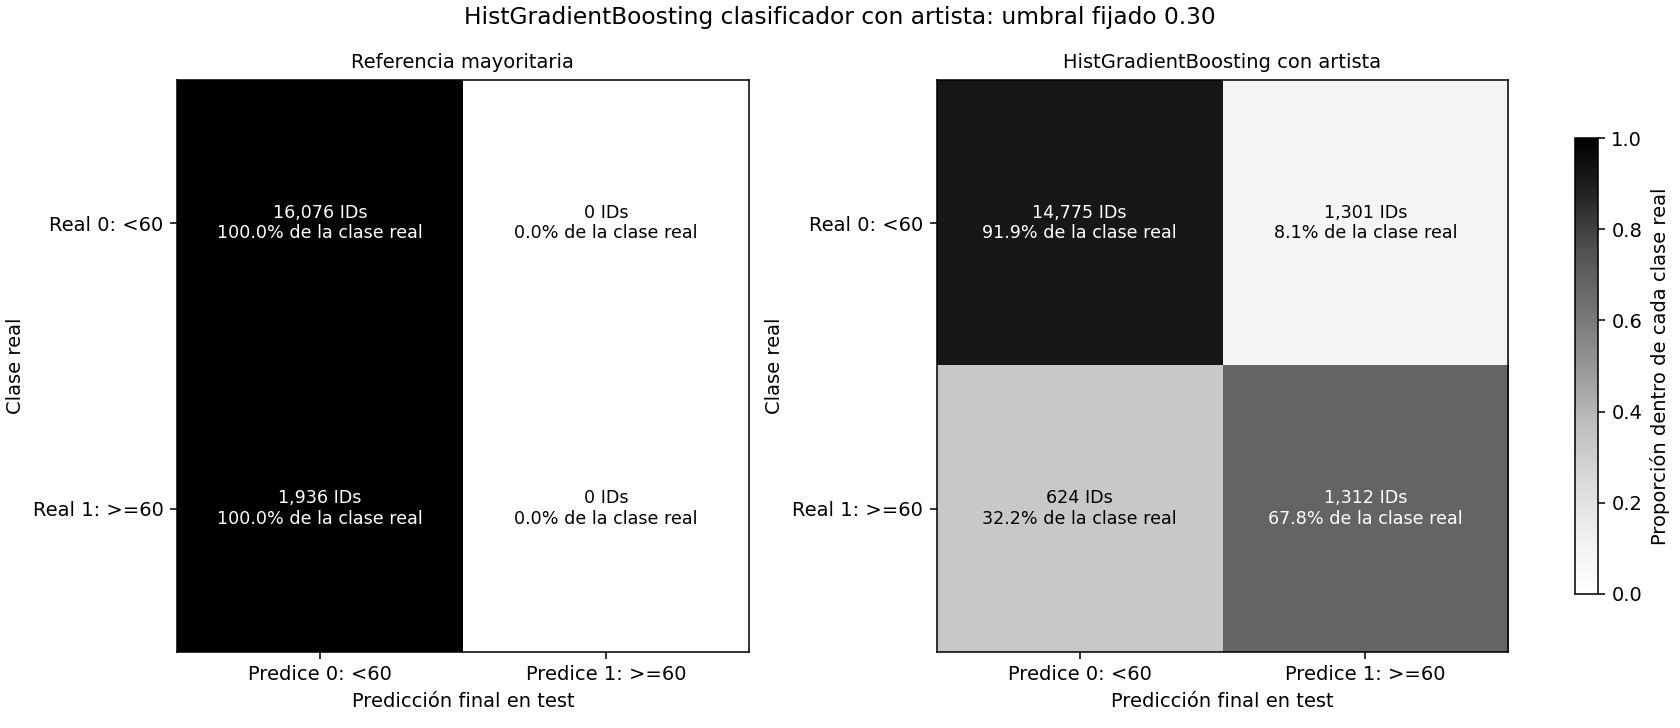

In [63]:
# Evaluar las predicciones ya fijadas sobre las mismas etiquetas de prueba
if not (y_test.notna().all() and np.isfinite(y_test).all() and y_test.between(0, 100).all()):
    raise ValueError("Revisar popularidades de test antes de evaluar clasificación.")
y_test_hist_clasificacion = y_test.ge(corte_popularidad_clasificacion).astype("int8").rename("clase_real_hist_test")
assert y_test_hist_clasificacion.index.equals(predicciones_hist_artista_test.index)
registros_test_hist_artista = []
matrices_test_hist_artista = {}
for nombre, pred in {"Referencia mayoritaria": predicciones_referencia_hist_artista_test, "HistGradientBoosting con artista": predicciones_hist_artista_test}.items():
    assert pred.index.equals(y_test_hist_clasificacion.index)
    matriz, medidas = resumir_clasificacion(y_test_hist_clasificacion, pred)
    matrices_test_hist_artista[nombre] = matriz
    registros_test_hist_artista.append({"Procedimiento": nombre, **medidas})
    display(pd.DataFrame(matriz, index=["Real 0: <60", "Real 1: >=60"], columns=["Predice 0: <60", "Predice 1: >=60"]).rename_axis(f"Test: {nombre}"))
tabla_metricas_test_hist_artista = pd.DataFrame(registros_test_hist_artista).set_index("Procedimiento")
lectura_test_hist_artista = tabla_metricas_test_hist_artista.copy()
for metrica in ["Precisión clase 1", "Recall clase 1", "Accuracy"]:
    lectura_test_hist_artista[metrica] *= 100
lectura_test_hist_artista = lectura_test_hist_artista.rename(columns={"Precisión clase 1": "Precisión (%)", "Recall clase 1": "Recall (%)", "Accuracy": "Accuracy (%)"})
resultado_test_hist_artista = tabla_metricas_test_hist_artista.loc["HistGradientBoosting con artista"]
resultado_desarrollo_hist_artista = tabla_cuatro_anidada_con_artista.loc["HistGradientBoosting"]
comparacion_desarrollo_test_hist_artista = pd.DataFrame([
    {"Evaluación": "Validación anidada de entrenamiento", "IDs": int(resultado_desarrollo_hist_artista["IDs"]), "Precisión (%)": resultado_desarrollo_hist_artista["Precisión clase 1"] * 100, "Recall (%)": resultado_desarrollo_hist_artista["Recall clase 1"] * 100, "F1": resultado_desarrollo_hist_artista["F1 clase 1"], "Accuracy (%)": resultado_desarrollo_hist_artista["Accuracy"] * 100},
    {"Evaluación": "Test interno del procedimiento fijado", "IDs": len(y_test_hist_clasificacion), "Precisión (%)": resultado_test_hist_artista["Precisión clase 1"] * 100, "Recall (%)": resultado_test_hist_artista["Recall clase 1"] * 100, "F1": resultado_test_hist_artista["F1 clase 1"], "Accuracy (%)": resultado_test_hist_artista["Accuracy"] * 100}
]).set_index("Evaluación")
ejemplos_test_hist_artista = pd.DataFrame({"Clase real": y_test_hist_clasificacion, "Referencia": predicciones_referencia_hist_artista_test, "Probabilidad estimada clase 1": probabilidades_hist_artista_test, "Predicción final": predicciones_hist_artista_test})
display(lectura_test_hist_artista.round(4))
display(comparacion_desarrollo_test_hist_artista.round(4))
display(ejemplos_test_hist_artista.head(5).round(4))

# Mostrar cantidades y porcentajes por clase real, sin cambiar la evaluación
import matplotlib.pyplot as plt
fig_test_hist_artista, ejes_test_hist_artista = plt.subplots(1, 2, figsize=(12, 5.2), constrained_layout=True)
for eje, (nombre, matriz) in zip(ejes_test_hist_artista, matrices_test_hist_artista.items()):
    proporciones = matriz / matriz.sum(axis=1, keepdims=True)
    imagen = eje.imshow(proporciones, vmin=0, vmax=1, cmap="Greys")
    for fila in range(2):
        for columna in range(2):
            texto = f"{matriz[fila, columna]:,} IDs\n{proporciones[fila, columna] * 100:.1f}% de la clase real"
            eje.text(columna, fila, texto, ha="center", va="center", fontsize=9, color="white" if proporciones[fila, columna] > 0.5 else "black")
    eje.set_xticks([0, 1], ["Predice 0: <60", "Predice 1: >=60"])
    eje.set_yticks([0, 1], ["Real 0: <60", "Real 1: >=60"])
    eje.set_xlabel("Predicción final en test")
    eje.set_ylabel("Clase real")
    eje.set_title(nombre, fontsize=10)
fig_test_hist_artista.colorbar(imagen, ax=ejes_test_hist_artista, shrink=0.7, label="Proporción dentro de cada clase real")
fig_test_hist_artista.suptitle(f"HistGradientBoosting clasificador con artista: umbral fijado {umbral_final_hist_artista:.2f}")
display(fig_test_hist_artista)
plt.close(fig_test_hist_artista)


#### 9.3.8. KPI finales del clasificador con artista

Las metas predictivas se mantienen en precisión >=30% y recall >=60%. Los resultados de test no se sustituyen por las métricas de desarrollo si alguna meta falla.

**Código:** se construyen las cinco filas de KPI con su alcance. Precisión y recall corresponden al test del procedimiento fijado. Etiquetas válidas de entrenamiento, claves compartidas entre ajuste y validación y cobertura OOF conservan el alcance de desarrollo. Se calcula el máximo de claves compartidas a partir de los controles de la validación anidada con artista; no se confunde con cobertura de test.

Los controles finales comprueban por separado separación entre entrenamiento y test, etiquetas válidas y alineadas, cobertura de las predicciones, parámetros, umbral y filas vistas por el escalador. Las métricas no se ponderan. Cumplir estos controles metodológicos no compensa un incumplimiento predictivo.

**Precisión cumple:** 50,21% >=30%. De 2.613 canciones señaladas, 1.312 cumplen y 1.301 son falsas alarmas.

**Recall cumple:** 67,77% >=60%; identifica 1.312 de 1.936 positivas reales.

Se registra el estado de esta evaluación y el hecho de que test ya fue observado. No se compara después con otros umbrales o modelos en test para seleccionar el más favorable. La referencia mayoritaria se conserva como contraste aunque su accuracy sea alta, porque no identifica clase 1.


In [64]:
# Conservar las metas y distinguir indicadores predictivos y metodológicos
maximo_claves_artista_desarrollo = max(int(evidencia["Controles"]["Claves compartidas"].max()) for evidencia in evidencia_anidada_con_artista.values())
porcentaje_etiquetas_validas_hist = float(y_clasificacion_train.isin([0, 1]).mean() * 100)
cobertura_oof_hist_artista = float(tabla_cuatro_anidada_con_artista.loc["HistGradientBoosting", "Cobertura OOF (%)"])
cumple_precision_test_hist = bool(resultado_test_hist_artista["Precisión positiva definida"] and resultado_test_hist_artista["Precisión clase 1"] >= meta_precision_clasificacion)
cumple_recall_test_hist = bool(resultado_test_hist_artista["Recall clase 1"] >= meta_recall_clasificacion)
tabla_kpi_test_hist_artista = pd.DataFrame([
    {"KPI": "Precisión clase 1", "Meta": ">=30%", "Resultado": resultado_test_hist_artista["Precisión clase 1"] * 100, "Unidad": "%", "Estado": "Cumple" if cumple_precision_test_hist else "No cumple", "Alcance": "Test interno del clasificador fijado"},
    {"KPI": "Recall clase 1", "Meta": ">=60%", "Resultado": resultado_test_hist_artista["Recall clase 1"] * 100, "Unidad": "%", "Estado": "Cumple" if cumple_recall_test_hist else "No cumple", "Alcance": "Test interno del clasificador fijado"},
    {"KPI": "Etiquetas válidas y alineadas", "Meta": "100%", "Resultado": porcentaje_etiquetas_validas_hist, "Unidad": "%", "Estado": "Cumple" if np.isclose(porcentaje_etiquetas_validas_hist, 100) and y_clasificacion_train.index.equals(X_train.index) else "Revisar", "Alcance": "Entrenamiento"},
    {"KPI": "Claves compartidas ajuste/validación", "Meta": "0 por ronda", "Resultado": maximo_claves_artista_desarrollo, "Unidad": "Claves", "Estado": "Cumple" if maximo_claves_artista_desarrollo == 0 else "Revisar", "Alcance": "Validación anidada agrupada con artista"},
    {"KPI": "Cobertura de predicciones OOF", "Meta": "100%", "Resultado": cobertura_oof_hist_artista, "Unidad": "%", "Estado": "Cumple" if np.isclose(cobertura_oof_hist_artista, 100) else "Revisar", "Alcance": "Validación externa anidada de entrenamiento"}
]).set_index("KPI")
controles_finales_hist_artista_test = pd.Series({
    "Cero IDs compartidos entre entrenamiento y test": X_train.index.intersection(X_test.index).empty,
    "Cero claves compartidas entre entrenamiento y test": set(datos_entrenamiento["clave_cancion"]).isdisjoint(set(datos_prueba["clave_cancion"])),
    "Cobertura de predicciones de test del 100%": predicciones_hist_artista_test.index.equals(y_test_hist_clasificacion.index) and predicciones_hist_artista_test.notna().all(),
    "Etiquetas reales válidas": y_test_hist_clasificacion.isin([0, 1]).all(),
    "Escalador vio solo entrenamiento": int(modelo_final_hist_clasificacion_artista.named_steps["preparar"].named_transformers_["numericas"].named_steps["escalar"].n_samples_seen_) == len(y_clasificacion_train),
    "Parámetros conservados": modelo_final_hist_clasificacion_artista.named_steps["clasificar"].get_params() == parametros_hist_artista_finales,
    "Umbral fijado antes de métricas de test": umbral_final_hist_artista == decision_hist_artista_test["Umbral fijado"]
})
if not controles_finales_hist_artista_test.all():
    raise ValueError("Revisar controles finales antes de cerrar la evaluación del clasificador con artista.")
estado_final_hist_artista_clasificador = pd.Series({"Procedimiento": "HistGradientBoosting clasificador con artista", "Umbral fijado con entrenamiento": umbral_final_hist_artista, "Ajuste final con todo entrenamiento": "Realizado", "Evaluación en test interno": "Realizada; conjunto previamente observado", "Ambas metas predictivas": "Cumple" if cumple_precision_test_hist and cumple_recall_test_hist else "No cumple", "Cambios posteriores guiados por test": "Requieren nueva evidencia independiente para confirmar"})
display(tabla_kpi_test_hist_artista.round({"Resultado": 4}))
display(controles_finales_hist_artista_test)
display(estado_final_hist_artista_clasificador)


,Meta,Resultado,Unidad,Estado,Alcance
KPI,,,,,
Precisión clase 1,>=30%,50.2105,%,Cumple,Test interno del clasificador fijado
Recall clase 1,>=60%,67.7686,%,Cumple,Test interno del clasificador fijado
Etiquetas válidas y alineadas,100%,100.0000,%,Cumple,Entrenamiento
Claves compartidas ajuste/validación,0 por ronda,0.0000,Claves,Cumple,Validación anidada agrupada con artista
Cobertura de predicciones OOF,100%,100.0000,%,Cumple,Validación externa anidada de entrenamiento


Cero IDs compartidos entre entrenamiento y test       True
Cero claves compartidas entre entrenamiento y test    True
Cobertura de predicciones de test del 100%            True
Etiquetas reales válidas                              True
Escalador vio solo entrenamiento                      True
Parámetros conservados                                True
Umbral fijado antes de métricas de test               True
dtype: bool

Procedimiento                               HistGradientBoosting clasificador con artista
Umbral fijado con entrenamiento                                                       0.3
Ajuste final con todo entrenamiento                                             Realizado
Evaluación en test interno                      Realizada; conjunto previamente observado
Ambas metas predictivas                                                            Cumple
Cambios posteriores guiados por test    Requieren nueva evidencia independiente para c...
dtype: object

#### 9.3.9. Conclusión de la evaluación final interna con artista

Se ajustó un único **HistGradientBoosting clasificador con artista** con los 71.728 IDs de entrenamiento y se evaluaron los **18.012 IDs de test**. El umbral **0,30**, los parámetros, los mapas y sus reglas se fijaron sin utilizar respuestas de test.

| Procedimiento en test | Precisión clase 1 | Recall clase 1 | F1 clase 1 | Accuracy |
|---|---:|---:|---:|---:|
| Referencia mayoritaria | No definida; reporte 0 | 0,00% | 0,0000 | 89,25% |
| HistGradientBoosting con artista | 50,21% | 67,77% | 0,5768 | 89,31% |

Matriz del modelo: **TN=14.775, FP=1.301, FN=624, TP=1.312**. Identifica 1.312 de las 1.936 positivas reales y deja 624 sin detectar. Señala 2.613 canciones; de ellas 1.301 son falsas alarmas. Estos conteos explican los denominadores y la carga de revisión, aunque se cumplan metas.

**Cumple ambas metas predictivas en este test interno**, con los parámetros y el umbral fijados en entrenamiento. Esto no elimina falsos negativos o falsas alarmas ni garantiza desempeño futuro.

**Por qué importa mirar más que accuracy:** la referencia alcanza 89,25% y el modelo 89,31%, cifras casi iguales. Sin embargo, la referencia no identifica ninguna positiva, mientras que el modelo identifica 1.312. Aun así, conserva 1.301 falsas alarmas y 624 omisiones; cumplir las metas no elimina esos errores.

En desarrollo anidado con artista se observaron precisión 48,15%, recall 67,18% y F1=0,5610. El test corresponde a otras canciones y a un ajuste con más datos; la comparación no demuestra ausencia de sobreajuste, fuga o sesgos. La información del artista puede favorecer catálogos conocidos y para desconocidos se utiliza una proporción general. Faltan fechas para interpretar el mapa como historial temporal previo al lanzamiento; popularidad no equivale a calidad musical.

**Alcance final:** evaluación adicional interna realizada sobre un conjunto que ya se observó en tareas anteriores. No es una muestra externa nueva ni una confirmación completamente ciega. No se cambió el umbral después de ver el resultado, no se eligió otro modelo por test y no se alteró la evaluación histórica de la logística. Cualquier cambio posterior guiado por estos errores necesitará nueva evidencia independiente para confirmarse.


<a id="clasificacion-roc-auc"></a>
## 9.4. Curvas ROC y ROC-AUC: cuatro clasificadores con y sin artista

**Objetivo:** complementar la comparación de logística, árbol de decisión, KNN e HistGradientBoosting con su capacidad para ordenar canciones positivas por encima de negativas. La clase positiva sigue siendo popularidad **60 o más**. Usamos exclusivamente sus **probabilidades OOF de entrenamiento**, ya calculadas con las mismas tres particiones agrupadas. No ajustamos modelos ni consultamos test.

**OOF significa fuera del pliegue de ajuste:** cada canción tiene una probabilidad obtenida por un modelo que no la utilizó para aprender. Las versiones identificadas por la misma clave permanecen juntas. En los modelos con artista se conserva la codificación binaria preparada dentro de cada ajuste; no usamos el mapa final ni la codificación de popularidad de regresión. No mezclamos probabilidades de test o de predicción sobre el propio ajuste.

Este apartado se añade después de los análisis anteriores: no convierte sus decisiones en elecciones previamente basadas en AUC ni vuelve ciego el test ya observado. Es evidencia descriptiva adicional de entrenamiento y no cambia automáticamente el procedimiento seleccionado, sus umbrales o sus KPI.

### Qué representan ROC y AUC

Para cada umbral de probabilidad, la curva ROC muestra:

- **Eje vertical: TPR o recall**, `TP / (TP + FN)`: qué proporción de las canciones positivas detectamos.
- **Eje horizontal: FPR**, `FP / (FP + TN)`: qué proporción de las canciones negativas señalamos por error.

Al bajar el umbral se suelen detectar más positivas y también señalar más negativas. La esquina superior izquierda combina recall alto y pocas falsas alarmas. La diagonal representa una ordenación sin discriminación como referencia; no es una referencia mayoritaria entrenada. FPR **no es** `1 − precisión`: tienen denominadores diferentes.

**ROC-AUC** resume el área bajo la curva, en escala 0–1. Puede interpretarse como la probabilidad de que una positiva tomada al azar reciba mayor puntuación que una negativa, contando los empates como media coincidencia. AUC 0,5 corresponde a falta de discriminación en esa comparación; 1, separación perfecta; menos de 0,5 indica ordenación peor que la referencia aleatoria. No establece una proporción de aciertos ni calibración de probabilidades.

Calculamos AUC con probabilidades continuas, **no con etiquetas ya cortadas a 0,50 ni con predicciones de la validación de umbrales**. Cambiar un umbral sobre las mismas probabilidades cambia precisión y recall, pero no su ROC-AUC. El valor no evalúa regresión o clustering en este proyecto.


In [93]:
from sklearn.metrics import roc_curve, roc_auc_score

nombres_modelos_roc = ["Logística", "Árbol", "KNN", "HistGradientBoosting"]
probabilidades_escenarios_roc = {
    "Sin artista": probabilidades_cuatro_sin_artista,
    "Con artista": probabilidades_cuatro_con_artista,
}
assert y_clasificacion_train.index.is_unique
assert set(y_clasificacion_train.unique()) == {0, 1}
assert pliegue_por_id.index.equals(y_clasificacion_train.index)
assert pliegue_por_id.notna().all()
claves_control_roc = datos_entrenamiento.loc[y_clasificacion_train.index, "clave_cancion"]
assert pliegue_por_id.groupby(claves_control_roc).nunique().eq(1).all()

filas_auc_roc = []
filas_auc_por_ronda = []
curvas_roc_oof = {}
for escenario, modelos in probabilidades_escenarios_roc.items():
    assert set(modelos) == set(nombres_modelos_roc)
    for nombre in nombres_modelos_roc:
        probabilidades = modelos[nombre]
        assert probabilidades.index.is_unique
        assert probabilidades.index.equals(y_clasificacion_train.index)
        assert np.isfinite(probabilidades.to_numpy()).all()
        assert probabilidades.between(0, 1).all()
        fpr, tpr, umbrales_roc = roc_curve(
            y_clasificacion_train, probabilidades, pos_label=1, drop_intermediate=False
        )
        auc_oof = float(roc_auc_score(y_clasificacion_train, probabilidades))
        curvas_roc_oof[(escenario, nombre)] = {"FPR": fpr, "TPR": tpr, "Umbrales": umbrales_roc}
        auc_rondas = []
        for ronda in sorted(pliegue_por_id.unique()):
            en_ronda = pliegue_por_id.eq(ronda)
            real_ronda = y_clasificacion_train.loc[en_ronda]
            assert real_ronda.nunique() == 2
            auc_ronda = float(roc_auc_score(real_ronda, probabilidades.loc[en_ronda]))
            auc_rondas.append(auc_ronda)
            filas_auc_por_ronda.append({
                "Escenario": escenario, "Modelo": nombre, "Ronda": int(ronda) + 1,
                "IDs": len(real_ronda), "Positivas": int(real_ronda.sum()), "ROC-AUC": auc_ronda,
            })
        filas_auc_roc.append({
            "Escenario": escenario, "Modelo": nombre, "ROC-AUC OOF conjunto": auc_oof,
            "AUC medio de las tres rondas": float(np.mean(auc_rondas)),
            "AUC mínimo de una ronda": float(np.min(auc_rondas)),
            "AUC máximo de una ronda": float(np.max(auc_rondas)),
            "IDs OOF": len(probabilidades),
        })
tabla_auc_oof = pd.DataFrame(filas_auc_roc).set_index(["Escenario", "Modelo"])
tabla_auc_rondas = pd.DataFrame(filas_auc_por_ronda).set_index(["Escenario", "Modelo", "Ronda"])
comparacion_auc_artista = tabla_auc_oof["ROC-AUC OOF conjunto"].unstack("Escenario").reindex(nombres_modelos_roc)
comparacion_auc_artista["Cambio con artista (unidades AUC)"] = comparacion_auc_artista["Con artista"] - comparacion_auc_artista["Sin artista"]
print("Comparación principal con las mismas canciones y particiones:")
display(comparacion_auc_artista.round(4))
print("Resumen por escenario y variación entre rondas:")
display(tabla_auc_oof.round(4))
print("Detalle de AUC por ronda:")
display(tabla_auc_rondas.round(4))


Comparación principal con las mismas canciones y particiones:
Resumen por escenario y variación entre rondas:
Detalle de AUC por ronda:


Escenario,Con artista,Sin artista,Cambio con artista (unidades AUC)
Modelo,,,
Logística,0.8958,0.8521,0.0437
Árbol,0.8608,0.5837,0.2770
KNN,0.8605,0.8040,0.0565
HistGradientBoosting,0.9097,0.8762,0.0335


ROC-AUC OOF conjunto  ...  IDs OOF
Escenario   Modelo                                      ...         
Sin artista Logística                           0.8521  ...    71728
            Árbol                               0.5837  ...    71728
            KNN                                 0.8040  ...    71728
            HistGradientBoosting                0.8762  ...    71728
Con artista Logística                           0.8958  ...    71728
            Árbol                               0.8608  ...    71728
            KNN                                 0.8605  ...    71728
            HistGradientBoosting                0.9097  ...    71728

[8 rows x 5 columns]

IDs  Positivas  ROC-AUC
Escenario   Modelo               Ronda                           
Sin artista Logística            1      23913       2671   0.8516
                                 2      24104       2615   0.8486
                                 3      23711       2575   0.8569
            Árbol                1      23913       2671   0.5851
                                 2      24104       2615   0.5866
                                 3      23711       2575   0.5942
            KNN                  1      23913       2671   0.8039
                                 2      24104       2615   0.8036
                                 3      23711       2575   0.8047
            HistGradientBoosting 1      23913       2671   0.8742
                                 2      24104       2615   0.8746
                                 3      23711       2575   0.8803
Con artista Logística            1      23913       2671   0.8997
                                 2      24104       2615   0.8908
                                 3      23711       2575   0.8970
            Árbol                1      23913       2671   0.8572
                                 2      24104       2615   0.8500
                                 3      23711       2575   0.8645
            KNN                  1      23913       2671   0.8652
                                 2      24104       2615   0.8574
                                 3      23711       2575   0.8591
            HistGradientBoosting 1      23913       2671   0.9124
                                 2      24104       2615   0.9064
                                 3      23711       2575   0.9105

### Lectura del cálculo paso a paso

1. Las importaciones incorporan la curva ROC y el cálculo de su área. La lista declara las cuatro familias; el diccionario reúne sus probabilidades previas con y sin artista. La logística usada aquí es la versión **sin ponderación**, y los otros tres modelos también conservan sus configuraciones sin ponderación. La logística `balanced` fue un experimento adicional y no se añade como una quinta familia.
2. Los controles exigen IDs únicos, clases 0 y 1 y particiones alineadas. Agrupar los números de pliegue por clave y exigir un solo valor comprueba que cada clave pertenece a un único pliegue. Esto complementa los controles de exclusión al generar las OOF; revisar índices por sí solo no demostraría ausencia de fuga.
3. Los bucles recorren dos escenarios y cuatro modelos. Se exige el mismo conjunto de familias y la misma secuencia de IDs, con probabilidades finitas entre 0 y 1. No reordenamos etiquetas para forzar una coincidencia.
4. `roc_curve` calcula FPR, TPR y los umbrales que producen cada punto. `pos_label=1` identifica la clase positiva. `drop_intermediate=False` conserva todos los puntos de puntuación disponibles; no busca un umbral nuevo. El primer umbral es infinito en esta versión de scikit-learn y representa predecir todo negativo: no es una probabilidad inválida del modelo.
5. `roc_auc_score` recibe respuestas reales y probabilidades OOF. Guardamos el score y las coordenadas de cada curva en un diccionario. No usamos las etiquetas de 0/1 predichas tras elegir un umbral.
6. Dentro de cada ronda, filtramos respuestas y probabilidades por los mismos IDs y exigimos las dos clases. Calculamos 24 áreas por ronda en total: ocho procedimientos por tres rondas.
7. La tabla resume el área sobre todas las OOF juntas, la media simple de tres áreas y su mínimo y máximo. **El AUC conjunto no tiene por qué coincidir con el promedio por ronda:** el conjunto también compara pares positiva–negativa de rondas distintas, cuyas probabilidades proceden de ajustes diferentes. Reportar ambos evita ocultar esa diferencia. El rango entre tres rondas no es un intervalo de confianza.
8. `unstack` coloca escenarios en columnas y `reindex` conserva el orden de modelos. La resta cuantifica el cambio en **unidades AUC**; una diferencia de 0,05 no equivale a 5% más de canciones acertadas. `round(4)` solo redondea presentación.

Las OOF permiten evaluar puntuaciones sin que cada fila participe en su propio ajuste, pero estos candidatos ya fueron estudiados en el mismo entrenamiento. La comparación no es evidencia externa nueva y puede verse afectada por las decisiones exploratorias anteriores. El artista representa información disponible en este catálogo y no un historial temporal garantizado; su aporte no prueba causalidad sobre popularidad.


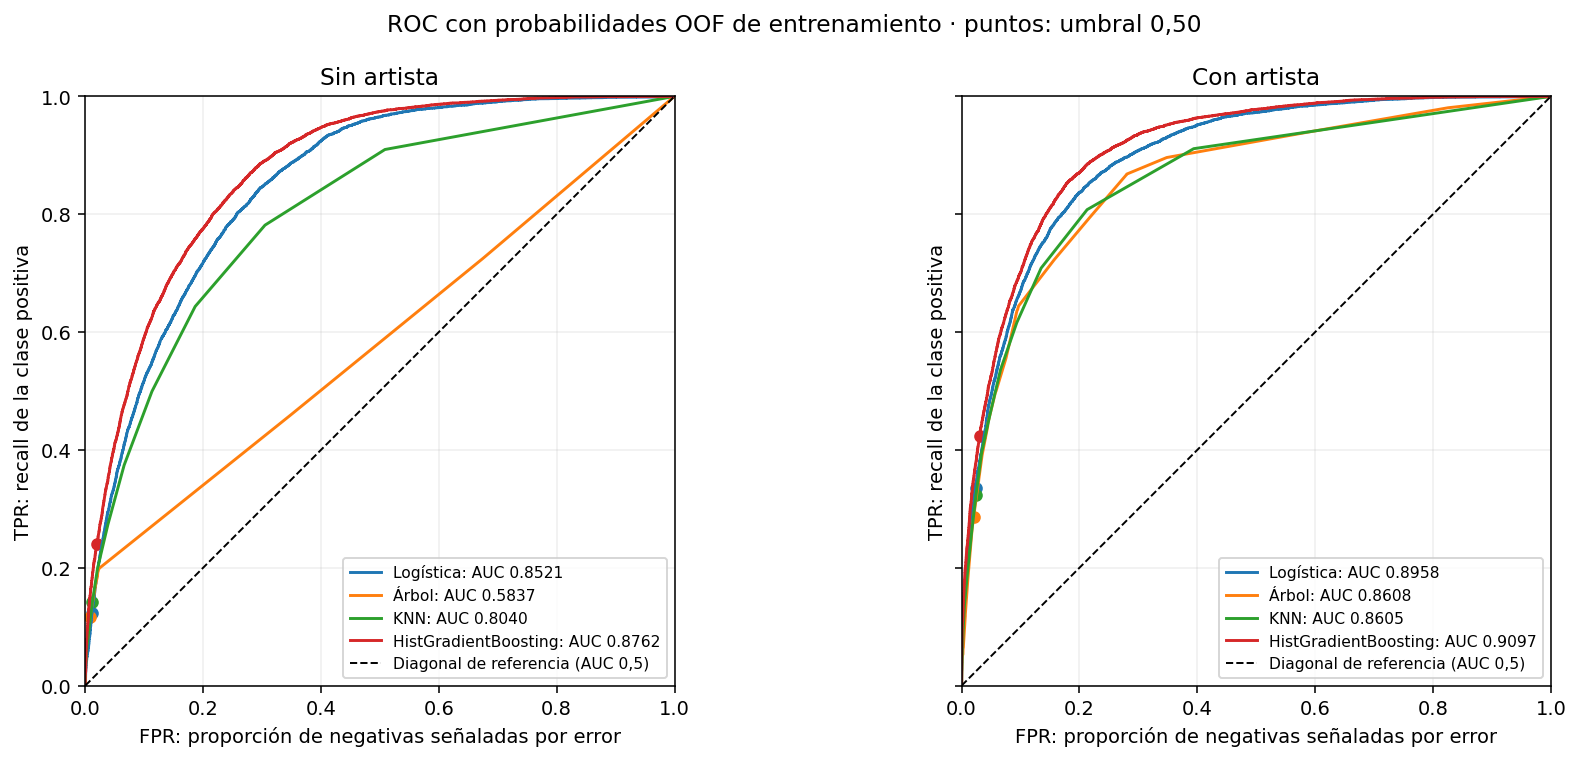

FPR a 0,50 (%)  Recall a 0,50 (%)
Escenario   Modelo                                                 
Sin artista Logística                     1.1461            12.3521
            Árbol                         0.8314            11.6779
            KNN                           1.2135            14.2221
            HistGradientBoosting          1.9791            24.0173
Con artista Logística                     2.3878            33.5199
            Árbol                         2.0292            28.5460
            KNN                           2.4426            32.3241
            HistGradientBoosting          3.0548            42.4246

In [94]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
colores_roc = dict(zip(nombres_modelos_roc, ["tab:blue", "tab:orange", "tab:green", "tab:red"]))
filas_punto_050_roc = []
for eje, escenario in zip(ejes, probabilidades_escenarios_roc):
    for nombre in nombres_modelos_roc:
        curva = curvas_roc_oof[(escenario, nombre)]
        auc_modelo = tabla_auc_oof.loc[(escenario, nombre), "ROC-AUC OOF conjunto"]
        eje.plot(curva["FPR"], curva["TPR"], color=colores_roc[nombre], label=f"{nombre}: AUC {auc_modelo:.4f}")
        pred_050 = probabilidades_escenarios_roc[escenario][nombre].ge(0.50)
        positivas = y_clasificacion_train.eq(1)
        negativas = ~positivas
        recall_050 = float((pred_050 & positivas).sum() / positivas.sum())
        fpr_050 = float((pred_050 & negativas).sum() / negativas.sum())
        eje.scatter(fpr_050, recall_050, color=colores_roc[nombre], marker="o", s=30)
        filas_punto_050_roc.append({"Escenario": escenario, "Modelo": nombre,
                                   "FPR a 0,50 (%)": 100 * fpr_050, "Recall a 0,50 (%)": 100 * recall_050})
    eje.plot([0, 1], [0, 1], color="black", linestyle="--", linewidth=1, label="Diagonal de referencia (AUC 0,5)")
    eje.set(title=escenario, xlabel="FPR: proporción de negativas señaladas por error", ylabel="TPR: recall de la clase positiva", xlim=(0, 1), ylim=(0, 1))
    eje.set_aspect("equal", adjustable="box")
    eje.grid(alpha=0.2)
    eje.legend(loc="lower right", fontsize=8)
fig.suptitle("ROC con probabilidades OOF de entrenamiento · puntos: umbral 0,50")
fig.tight_layout()
plt.show()

tabla_puntos_050_roc = pd.DataFrame(filas_punto_050_roc).set_index(["Escenario", "Modelo"])
display(tabla_puntos_050_roc.round(4))


### Cómo interpretar los gráficos y el punto de umbral 0,50

`subplots` crea un panel por escenario, con ejes de 0 a 1 y escala común. El diccionario fija un color por familia, igual en ambos paneles. Cada `plot` utiliza las coordenadas ROC y etiqueta su AUC; no dibuja un nuevo modelo. Las curvas de árboles o KNN pueden mostrar escalones por tener más empates o menos puntuaciones distintas: no es un fallo del gráfico.

Para situar un ejemplo de operación usamos `probabilidad >= 0,50`. Las máscaras de positivas y negativas permiten contar recall y FPR con sus denominadores correctos. `scatter` marca ese único punto por curva; la tabla lo expresa en porcentajes. **0,50 se muestra como referencia didáctica, no sustituye los umbrales fijados anteriormente ni vuelve a elegirlos.** Una curva que discrimina bien puede tener recall bajo a ese corte.

La línea discontinua indica la referencia diagonal. Mayor cercanía a la esquina superior izquierda es deseable, pero dos curvas pueden cruzarse: un AUC global mayor no garantiza mejor recall en cada nivel concreto de falsas alarmas. El área promedia comportamiento de umbrales que quizá no sean útiles para el proyecto.

### Relación con los KPI y el desbalance

Nuestros KPI siguen siendo **recall de al menos 60% y precisión de al menos 30%** en un procedimiento de umbral evaluado apropiadamente. No habíamos fijado una meta de AUC: aquí no inventamos una para declarar cumplimiento. ROC-AUC complementa la discriminación; los análisis previos de precisión, recall, F1 y umbrales evalúan otras preguntas.

Con aproximadamente 10,96% de positivas, una FPR aparentemente pequeña puede representar bastantes falsas alarmas porque hay muchas negativas. ROC-AUC no indica directamente qué proporción de las canciones sugeridas como populares realmente lo son: eso es precisión. Tampoco garantiza que una probabilidad 0,70 corresponda a 70% de positivas reales, cuestión de calibración no evaluada aquí.

La diagonal no sustituye el resultado de nuestra referencia mayoritaria a un umbral. Un predictor que asigna la misma puntuación a todas las canciones tendría AUC 0,5, aunque acertara muchas negativas por el desbalance. No necesitamos volver a entrenarlo para explicar esa propiedad.


### Resultados reales de ROC-AUC con probabilidades OOF

Los ocho procedimientos utilizan las mismas **71.728 canciones de entrenamiento**, con **7.861 positivas** y **63.867 negativas**, y las mismas tres particiones agrupadas.

| Clasificador | ROC-AUC sin artista | ROC-AUC con artista | Cambio en unidades AUC |
|---|---:|---:|---:|
| Logística sin ponderación | 0,8521 | 0,8958 | +0,0437 |
| Árbol de decisión sencillo | 0,5837 | 0,8608 | +0,2770 |
| KNN | 0,8040 | 0,8605 | +0,0565 |
| HistGradientBoosting | **0,8762** | **0,9097** | +0,0335 |

**Logística:** discrimina positivas y negativas considerablemente mejor que la referencia AUC 0,5; añadir artista mejora la ordenación OOF. Eso no implica que su umbral de 0,50 tenga recall suficiente, ni que sus probabilidades estén calibradas.

**Árbol sencillo:** sin artista presenta la discriminación más limitada de las cuatro familias, aunque supera la referencia 0,5. Es el árbol restringido que ya evaluamos, no una conclusión sobre todos los árboles. Su estructura de hojas produce puntuaciones discretas y una curva con tramos grandes. Con artista mejora notablemente a 0,8608: puede aprovechar esa información para ordenar canciones en este catálogo, sin que ello demuestre que el artista cause popularidad. La profundidad y restricciones originales se mantuvieron.

**KNN:** mejora de 0,8040 a 0,8605 con artista. Las puntuaciones basadas en proporción de vecinos generan empates y escalones; por eso AUC cuenta los empates con contribución media. El árbol con artista tiene AUC ligeramente superior a KNN, pero la diferencia es aproximadamente **0,0003**: no afirmamos superioridad robusta o significativa a partir de una diferencia tan pequeña sin estudiar incertidumbre.

**HistGradientBoosting:** obtiene el mayor ROC-AUC en ambos escenarios. Con artista alcanza 0,9097, compatible con ordenar una positiva por encima de una negativa en aproximadamente **90,97% de las comparaciones positiva–negativa OOF**, contando empates a la mitad. **No significa 90,97% de canciones acertadas**, ni una probabilidad de éxito de una playlist. Con estos resultados sigue siendo el procedimiento mejor respaldado entre los candidatos estudiados, en conjunto con los análisis previos de KPI, errores y umbrales.

**Aporte del artista:** el aumento es positivo en las cuatro familias, especialmente en el árbol. Se mide en unidades AUC, sin convertirlo en porcentaje de mejora de accuracy. El artista fue codificado dentro de los ajustes permitidos; no se reutilizó la codificación final o información de test. Las particiones mantienen versiones identificadas juntas, pero no exigen artistas completamente distintos entre ajuste y validación ni representan una evaluación temporal. El beneficio observado no garantiza el mismo aporte para artistas desconocidos o lanzamientos futuros.

### Por qué un AUC alto no basta para cumplir los KPI

En HistGradientBoosting con artista, el punto de umbral **0,50** tiene recall **42,42%** y FPR **3,05%**. El recall queda bajo nuestra meta de 60%, pese a AUC 0,9097. Esto no es una contradicción: AUC resume muchos umbrales y el punto describe una sola decisión de corte. Para ese ejemplo didáctico, **no se cumple la meta de recall** porque ese umbral deja demasiadas positivas sin detectar. Bajar el umbral puede recuperar positivas, pero también aumenta falsas alarmas y cambia precisión; de ahí la validación de umbrales realizada antes.

Los ocho procedimientos tienen recall inferior a 60% al corte 0,50 mostrado en este apartado. Eso **no invalida los resultados anteriores con otros umbrales** ni reemplaza sus evaluaciones anidadas. No se declarará que un modelo cumple ambos KPI solo por tener AUC alto. FPR de 3,05% se calcula entre negativas; no significa precisión de 96,95%.

No fijamos un umbral nuevo en el gráfico y no cambiamos las metas de precisión mínima 30% y recall mínimo 60%. El área no incorpora directamente el costo de las falsas alarmas ni permite elegir por sí sola qué punto utilizar. La precisión sigue siendo especialmente relevante por el desbalance de clases.

### Qué muestran las rondas y qué conclusión podemos defender

En HistGradientBoosting con artista, los AUC por ronda van de **0,9064 a 0,9124**, con promedio **0,9098**. Sin artista van de **0,8742 a 0,8803**, con promedio **0,8764**. Las tres rondas presentan resultados cercanos dentro de cada escenario, pero tres valores no constituyen un intervalo de confianza ni garantizan desempeño futuro.

En el árbol sin artista, el AUC OOF conjunto (**0,5837**) queda incluso por debajo del mínimo de sus tres áreas por ronda (**0,5851**). No es necesariamente un error: el área conjunta incluye comparaciones entre probabilidades producidas por ajustes distintos, mientras cada área por ronda compara canciones puntuadas por un mismo ajuste. Por eso se documentan ambas lecturas y no se sustituye una por otra silenciosamente.

**Conclusión:** ROC y ROC-AUC complementan la evaluación y respaldan la buena discriminación relativa de HistGradientBoosting con artista en este entrenamiento. No cambian automáticamente el ganador, los umbrales, los KPI o los resultados ya reportados. Las diferencias de AUC no fueron sometidas a una prueba de significación y el mismo entrenamiento ya intervino en decisiones exploratorias. No se consultó test, no se reentrenaron modelos y no se calculó AUC de regresión o clustering.


<a id="clasificacion-roc-test"></a>
## 9.5. ROC y ROC-AUC en test: HistGradientBoosting con artista

**Objetivo:** completar la evaluación del clasificador final con su ROC-AUC en test y compararlo con sus probabilidades OOF. Usamos las **probabilidades ya obtenidas en la evaluación final**; no volvemos a ajustar, predecir, codificar artistas o escalar datos. El modelo, parámetros y umbral **0,30** permanecen fijados.

La clase positiva sigue siendo popularidad de 60 o más. El test contiene **18.012 canciones**, distintas de las 71.728 de entrenamiento. Esta es una evaluación adicional sobre el **test interno ya observado** en apartados anteriores, no una nueva prueba externa completamente ciega. La comparación no se utilizará para escoger otro umbral o modelo.

**Qué se compara:** en OOF, cada canción de entrenamiento fue puntuada fuera de su propio pliegue con uno de tres ajustes. En test, todas las canciones fueron puntuadas por un único modelo final aprendido con todo entrenamiento. Son formas de evaluación relacionadas, pero no idénticas; diferencias pequeñas no demuestran automáticamente sobreajuste ni su ausencia.

ROC y AUC utilizan todas las puntuaciones, sin depender de un corte. En la curva marcaremos también el punto **0,30** para conectarlo con precisión y recall reportados. Dibujar otros umbrales como parte de ROC no significa adoptarlos o ajustarlos con test.


In [95]:
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

umbral_conservado_roc_hist = float(umbral_final_hist_artista)
assert np.isclose(umbral_conservado_roc_hist, 0.30)
assert umbral_conservado_roc_hist == decision_hist_artista_test["Umbral fijado"]
assert y_clasificacion_train.index.intersection(y_test_hist_clasificacion.index).empty

evaluaciones_roc_hist_final = {
    "OOF entrenamiento": (
        y_clasificacion_train,
        probabilidades_cuatro_con_artista["HistGradientBoosting"],
    ),
    "Test interno": (y_test_hist_clasificacion, probabilidades_hist_artista_test),
}
curvas_roc_hist_final = {}
filas_auc_hist_final = []
filas_punto_hist_final = []
matrices_punto_roc_hist = {}
for evaluacion, (reales, probabilidades) in evaluaciones_roc_hist_final.items():
    assert reales.index.is_unique and probabilidades.index.is_unique
    assert reales.index.equals(probabilidades.index)
    assert set(reales.unique()) == {0, 1}
    assert np.isfinite(probabilidades.to_numpy()).all()
    assert probabilidades.between(0, 1).all()
    fpr, tpr, cortes = roc_curve(reales, probabilidades, pos_label=1, drop_intermediate=False)
    area = float(roc_auc_score(reales, probabilidades))
    curvas_roc_hist_final[evaluacion] = {"FPR": fpr, "TPR": tpr, "Umbrales": cortes}
    pred_al_corte = probabilidades.ge(umbral_conservado_roc_hist).astype("int8")
    matriz = confusion_matrix(reales, pred_al_corte, labels=[0, 1])
    tn, fp, fn, tp = (int(valor) for valor in matriz.ravel())
    assert tn + fp + fn + tp == len(reales)
    matrices_punto_roc_hist[evaluacion] = matriz
    filas_auc_hist_final.append({
        "Evaluación": evaluacion, "IDs": len(reales), "Positivas": tp + fn,
        "Negativas": tn + fp, "ROC-AUC": area,
    })
    filas_punto_hist_final.append({
        "Evaluación": evaluacion, "Umbral conservado": umbral_conservado_roc_hist,
        "FPR (%)": 100 * fp / (fp + tn), "Recall (%)": 100 * tp / (tp + fn),
        "Precisión (%)": 100 * tp / (tp + fp) if tp + fp else np.nan,
        "F1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    })
    if evaluacion == "Test interno":
        assert pred_al_corte.equals(predicciones_hist_artista_test.astype("int8"))
comparacion_auc_hist_final = pd.DataFrame(filas_auc_hist_final).set_index("Evaluación")
comparacion_punto_hist_final = pd.DataFrame(filas_punto_hist_final).set_index("Evaluación")
cambio_auc_test_hist = float(
    comparacion_auc_hist_final.loc["Test interno", "ROC-AUC"]
    - comparacion_auc_hist_final.loc["OOF entrenamiento", "ROC-AUC"]
)
np.testing.assert_allclose(
    comparacion_auc_hist_final.loc["OOF entrenamiento", "ROC-AUC"],
    tabla_auc_oof.loc[("Con artista", "HistGradientBoosting"), "ROC-AUC OOF conjunto"],
)
print("ROC-AUC del mismo procedimiento, con distinto origen de evaluación:")
display(comparacion_auc_hist_final.round(4))
print(f"Cambio AUC test menos OOF: {cambio_auc_test_hist:+.6f} unidades AUC.")
print("Punto de operación con el umbral conservado, sin nueva selección:")
display(comparacion_punto_hist_final.round(4))


ROC-AUC del mismo procedimiento, con distinto origen de evaluación:
Cambio AUC test menos OOF: +0.008289 unidades AUC.
Punto de operación con el umbral conservado, sin nueva selección:


,IDs,Positivas,Negativas,ROC-AUC
Evaluación,,,,
OOF entrenamiento,71728,7861,63867,0.9097
Test interno,18012,1936,16076,0.9180


,Umbral conservado,FPR (%),Recall (%),Precisión (%),F1,TN,FP,FN,TP
Evaluación,,,,,,,,,
OOF entrenamiento,0.3,7.7317,63.6306,50.3219,0.5620,58929,4938,2859,5002
Test interno,0.3,8.0928,67.7686,50.2105,0.5768,14775,1301,624,1312


### Lectura del cálculo, paso a paso

1. Importamos curva, área y matriz de confusión. Copiamos el valor del umbral ya elegido a una variable descriptiva y comprobamos que sigue siendo 0,30 y coincide con la decisión anterior. No realizamos búsqueda de cortes ni modificamos el modelo.
2. La intersección comprueba que las canciones de OOF y test no comparten IDs. Los controles de separación por clave y de preparación ya quedaron documentados en la evaluación final.
3. El diccionario reúne dos parejas: respuestas y probabilidades OOF, y respuestas y probabilidades finales de test. El `for` evita aplicar fórmulas diferentes a cada evaluación. Los `assert` comprueban IDs únicos y alineados, dos clases y probabilidades finitas entre 0 y 1.
4. `roc_curve` obtiene todos los puntos disponibles de la curva; `roc_auc_score` calcula el área directamente desde probabilidades. No utilizamos etiquetas cortadas para calcular AUC ni elegimos un punto mirando test.
5. Solo para localizar el corte ya elegido hacemos `probabilidades >= 0,30`. `confusion_matrix(..., labels=[0,1])` y `ravel` recuperan TN, FP, FN y TP. Los conteos deben sumar las filas reales. Calculamos FPR entre negativas, recall entre positivas y precisión entre señaladas.
6. En test, `equals` comprueba que las etiquetas obtenidas al conservar el corte son exactamente las que ya guardamos antes. No generamos predicciones nuevas con el estimador; reaplicamos la misma regla a las probabilidades guardadas para comprobar consistencia.
7. Las tablas separan discriminación (AUC) de operación (umbral y errores). La resta es `AUC test − AUC OOF`, en unidades AUC; no es cambio en accuracy. El último control exige que el AUC OOF coincide con el del apartado 9.4.

**Importante al comparar puntos:** aquí usamos el mismo corte fijo 0,30 para OOF y test. La tabla anterior de validación anidada usó umbrales internos elegidos por ronda, que podían diferir (0,25, 0,30 y 0,25). Sus métricas no tienen por qué coincidir con el nuevo resumen OOF de corte fijo. Además, 0,30 se eligió usando entrenamiento: su resultado OOF al corte seleccionado no sustituye la validación anidada del procedimiento de elección. ROC-AUC no depende de ese corte.


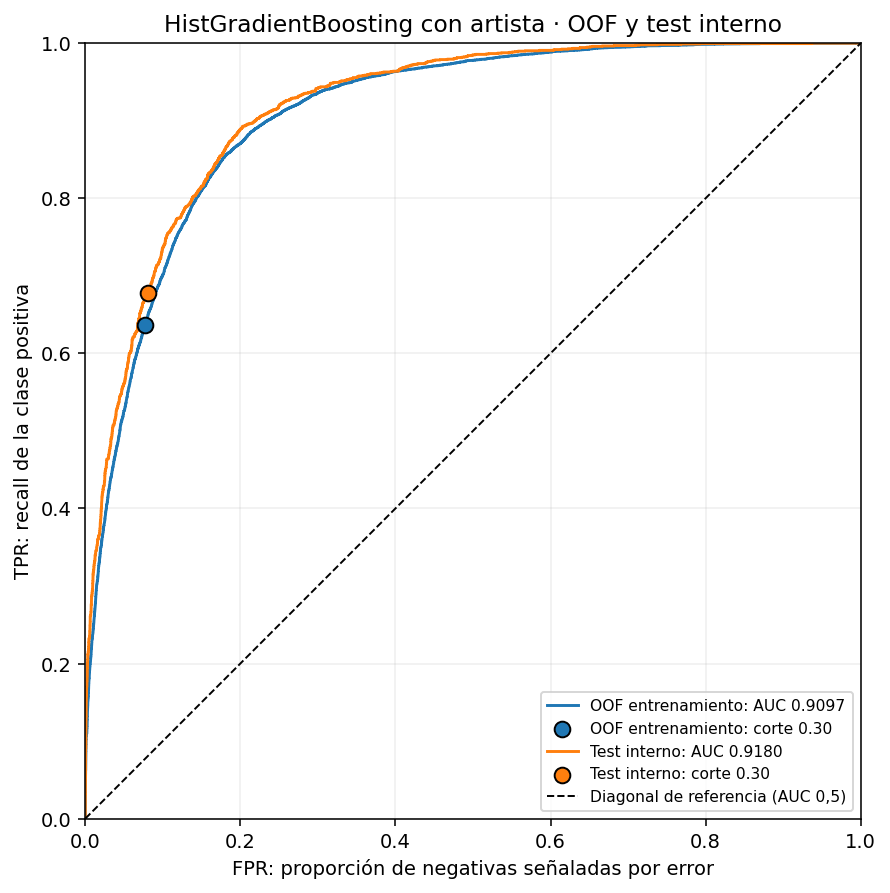

In [96]:
import matplotlib.pyplot as plt

fig, eje = plt.subplots(figsize=(7.5, 6.5))
colores_roc_hist_final = {"OOF entrenamiento": "tab:blue", "Test interno": "tab:orange"}
for evaluacion, curva in curvas_roc_hist_final.items():
    area = comparacion_auc_hist_final.loc[evaluacion, "ROC-AUC"]
    eje.plot(curva["FPR"], curva["TPR"], color=colores_roc_hist_final[evaluacion],
             label=f"{evaluacion}: AUC {area:.4f}")
    punto = comparacion_punto_hist_final.loc[evaluacion]
    eje.scatter(punto["FPR (%)"] / 100, punto["Recall (%)"] / 100,
                color=colores_roc_hist_final[evaluacion], s=65, marker="o", edgecolor="black", zorder=3,
                label=f"{evaluacion}: corte {umbral_conservado_roc_hist:.2f}")
eje.plot([0, 1], [0, 1], linestyle="--", color="black", linewidth=1, label="Diagonal de referencia (AUC 0,5)")
eje.set(title="HistGradientBoosting con artista · OOF y test interno",
        xlabel="FPR: proporción de negativas señaladas por error",
        ylabel="TPR: recall de la clase positiva", xlim=(0, 1), ylim=(0, 1))
eje.set_aspect("equal", adjustable="box")
eje.grid(alpha=0.2)
eje.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()


### Cómo leer el gráfico

`subplots` crea un único plano común. El `for` dibuja las dos curvas con colores distintos y escribe sus áreas. `scatter` coloca el punto del corte **conservado** dividiendo por 100 los porcentajes de la tabla para volver a la escala 0–1. La diagonal ilustra falta de discriminación, no es un clasificador entrenado nuevo. Los ejes y su escala común evitan comparar gráficos con zooms distintos.

Cada curva resume una evaluación diferente del mismo procedimiento. Cerca de la esquina superior izquierda hay mayor recall y menor proporción de falsas alarmas; si las curvas se cruzan, un área total mayor no garantiza superioridad en cada FPR. Los puntos resaltados indican la operación con 0,30, no el máximo de una métrica buscado en test.

Una curva por encima de la diagonal indica capacidad de ordenar positivas sobre negativas en esa muestra; no demuestra probabilidades calibradas, cumplimiento de KPI o ausencia de sesgos. El área integra todos los umbrales, incluso los que no utilizaríamos. La precisión debe leerse en su tabla: no se obtiene como `1 − FPR`.


### Resultados reales de ROC-AUC en test y comparación con OOF

| Evaluación | Canciones | Positivas | Negativas | ROC-AUC |
|---|---:|---:|---:|---:|
| OOF de entrenamiento | 71.728 | 7.861 | 63.867 | 0,9097 |
| Test interno del modelo final | 18.012 | 1.936 | 16.076 | **0,9180** |

**Interpretación del área:** el modelo final discrimina positivas de negativas en este test considerablemente mejor que la referencia AUC 0,5. El valor 0,9180 es compatible con ordenar una positiva por encima de una negativa en aproximadamente **91,80% de las comparaciones positiva–negativa de test**, contando empates a la mitad. No significa 91,80% de canciones acertadas ni 91,80% de probabilidades bien calibradas.

La diferencia `test − OOF` es aproximadamente **+0,0083 unidades AUC**. Test es ligeramente mayor, pero no concluimos que el modelo haya mejorado universalmente. Son canciones diferentes; los modelos OOF se aprendieron con parte del entrenamiento y el final con todo entrenamiento. Esa diferencia de soporte de ajuste y la variación de las muestras pueden contribuir, sin que hayamos aislado sus efectos. Las áreas no son mediciones idénticas repetidas ni una comparación pareada de las mismas canciones.

Las curvas son próximas y la de test está algo por encima en buena parte del gráfico, pero no interpretamos cada pequeño cruce como una ventaja estable. No se calcularon intervalos de confianza o una prueba de significación para la diferencia. Un test algo mayor que OOF **no demuestra ausencia de sobreajuste, fuga o sesgos** y no compensa el hecho de que el test ya fue observado anteriormente.

### El punto de operación sigue siendo 0,30

| Evaluación con el mismo corte | FPR | Recall | Precisión | F1 |
|---|---:|---:|---:|---:|
| OOF con umbral fijo 0,30 | 7,73% | 63,63% | 50,32% | 0,5620 |
| Test con umbral fijo 0,30 | 8,09% | 67,77% | 50,21% | 0,5768 |

**Qué significa el punto de test:** de las **1.936 positivas**, detecta **1.312** y omite **624**: `1.312 / 1.936 = 67,77%` de recall. De las **16.076 negativas**, señala por error **1.301**: `1.301 / 16.076 = 8,09%` de FPR. Entre todas las **2.613 canciones señaladas**, **1.312** son positivas: `1.312 / 2.613 = 50,21%` de precisión. Las **14.775** negativas restantes son verdaderos negativos. Estos conteos son exactamente los ya evaluados; no se modificó la matriz de confusión.

Test muestra mayor recall y también algo más de FPR que el resumen OOF al mismo corte, con precisión muy parecida. No afirmamos que todas las métricas mejoraron. Tampoco confundimos el FPR 8,09% con la proporción de falsas alarmas entre las señaladas: esta última sería `1.301 / 2.613`, aproximadamente 49,79%, por tener otro denominador.

En OOF, el corte 0,30 se eligió con información de entrenamiento. Por eso su resumen al corte fijo no sustituye la evaluación anidada del proceso de selección. Los valores anteriores de validación anidada con cortes por ronda (0,25, 0,30 y 0,25) siguen siendo la evidencia de ese procedimiento; el nuevo cuadro solo compara la operación del mismo corte entre OOF y test.

### KPI y conclusión

Los KPI de test **continúan cumplidos**: precisión 50,21% frente a meta mínima 30%, y recall 67,77% frente a 60%. Se cumplen por esos resultados al umbral fijado, **no porque ROC-AUC supere un número determinado**. No habíamos establecido una meta de AUC y no inventamos una después de ver el resultado.

El área complementa la evaluación de discriminación y es coherente con mantener el clasificador final seleccionado. No cambiamos el umbral de 0,30, el modelo, la codificación del artista, la preparación de entradas o los parámetros. No utilizamos la curva de test para buscar el mejor punto. Persisten falsos positivos, omisiones, límites del catálogo y falta de validación temporal o externa.

**Alcance:** evaluación adicional del procedimiento fijado sobre probabilidades ya guardadas de un test interno previamente observado. Si se cambian decisiones guiándose por este resultado, se necesitará nueva evidencia independiente para confirmarlas. Este apartado no altera las recomendaciones de clustering ni añade ROC-AUC a tareas de regresión o agrupamiento.


<a id="bloque-10"></a>
## 10. Agrupamiento con K-Means · Diseño usando solo entrenamiento

### 10.1. Objetivo y alcance

**Objetivo:** organizar las canciones de entrenamiento en varios perfiles de audio para apoyar la creación de playlists y sugerencias de canciones similares. Usamos nueve características de audio; necesitamos más de dos perfiles para este uso exploratorio. Por ejemplo, podrían aparecer perfiles más acústicos o más energéticos; son posibilidades que debemos comprobar, no resultados obtenidos.

En regresión estimamos popularidad; en clasificación identificamos popularidad de 60 o más. Aquí no proporcionamos una respuesta correcta: **K-Means es aprendizaje no supervisado**. Busca K grupos y representa cada grupo con un centro o **centroide**, el promedio de sus características en el espacio utilizado. Asigna cada canción al centro más cercano y trata de reducir la suma de distancias al cuadrado.

**K** es la cantidad de grupos que pedimos explorar. No significa cantidad de géneros y los números de los grupos no establecen un orden de calidad. Un grupo puede reunir varios géneros y un género puede aparecer en varios grupos.

Conservamos únicamente los **71.728 IDs de entrenamiento** ya separados. No abrimos otra partición ni consultamos test. Esta primera sección define las entradas y el procedimiento: **todavía no ajusta K-Means, no escala datos y no presenta grupos ni métricas de agrupamiento**.

**Criterio vigente de utilidad:** K=2 se conserva como comparación de referencia, pero se excluye de la selección para playlists por ofrecer una segmentación demasiado general para el objetivo solicitado. El apartado 10.9 documenta cuándo y por qué se incorporó esta restricción; la elección anterior se conserva como antecedente.


### 10.2. Variables y decisiones

| Entrada | Qué representa | Motivo para incluirla |
|---|---|---|
| `danceability` | Índice de bailabilidad | Comparar el carácter bailable |
| `energy` | Índice de energía percibida | Distinguir intensidad musical |
| `loudness` | Sonoridad en decibelios | Comparar nivel sonoro |
| `speechiness` | Índice de presencia de voz hablada | Distinguir contenido hablado de otros perfiles |
| `acousticness` | Índice de carácter acústico | Comparar rasgos acústicos |
| `instrumentalness` | Índice de carácter instrumental | Distinguir perfiles instrumentales |
| `liveness` | Índice de indicios de interpretación en vivo | Incorporar este rasgo de grabación |
| `valence` | Índice de carácter musical positivo | Comparar este rasgo expresivo, sin medir emociones reales del oyente |
| `tempo` | Tempo estimado en BPM | Comparar velocidad rítmica |

Los índices del proveedor describen rasgos estimados; no son mediciones directas de calidad musical. La duración se deja fuera de esta primera propuesta para centrar la distancia en el perfil sonoro y rítmico; es una decisión de alcance y podría revisarse con una justificación posterior.

**Exclusiones deliberadas:** popularidad y su clase no formarán grupos ni decidirán K. Tampoco usaremos artista ni sus codificaciones, que en los modelos anteriores contienen información de popularidad. Los géneros Multi-Hot quedan fuera para descubrir perfiles de audio sin imponer etiquetas de género. IDs, títulos y claves son identificadores; `key`, `mode`, `time_signature` y `explicit` tampoco entran en esta primera distancia continua: un código numérico de categoría no establece por sí solo una distancia musical válida.

**Preparación prevista:** reemplazar ausencias por la mediana aprendida solo en entrenamiento y aplicar `StandardScaler` en esas mismas filas. Esto evita que los BPM o decibelios pesen principalmente por sus unidades frente a índices de 0 a 1. Estandarizar resta la media y divide por la desviación estándar: no convierte todo a 0–1 ni elimina valores extremos. No reutilizaremos el escalamiento demostrativo de la unidad 1. Las correlaciones entre energía y sonoridad, por ejemplo, pueden dar más peso a rasgos relacionados; el escalamiento no elimina esa redundancia.

Después de fijar el procedimiento podremos describir popularidad y géneros por grupo, usando entrenamiento. Eso será interpretación posterior, no evidencia de que el audio cause popularidad. Una fila representa un ID; distintas versiones con otros IDs aún pueden influir en los perfiles.


In [65]:
import numpy as np

variables_clustering = [
    "danceability", "energy", "loudness", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence", "tempo",
]
X_clustering_train = X_train.loc[:, variables_clustering].copy()

assert X_clustering_train.index.is_unique, "Hay IDs repetidos."
assert X_clustering_train.index.equals(X_train.index), "Cambió el conjunto de entrenamiento."
assert X_clustering_train.select_dtypes(include="number").shape[1] == len(variables_clustering)
assert not np.isinf(X_clustering_train.to_numpy(dtype=float)).any(), "Hay valores infinitos."

revision_clustering = pd.DataFrame({
    "Tipo": X_clustering_train.dtypes.astype(str),
    "Ausencias": X_clustering_train.isna().sum(),
    "Valores distintos presentes": X_clustering_train.nunique(),
})
assert revision_clustering["Valores distintos presentes"].gt(1).all(), "Hay una entrada constante o vacía."
print(f"Entradas de agrupamiento: {len(X_clustering_train):,} canciones y {len(variables_clustering)} variables.")
display(revision_clustering)


Entradas de agrupamiento: 71,728 canciones y 9 variables.


,Tipo,Ausencias,Valores distintos presentes
danceability,float64,0,1138
energy,float64,0,2002
loudness,float64,0,18129
speechiness,float64,0,1457
acousticness,float64,0,4935
instrumentalness,float64,0,5286
liveness,float64,0,1705
valence,float64,0,1769
tempo,float64,136,39322


**Lectura del código, en orden:**

1. `import numpy as np` incorpora herramientas numéricas para detectar infinitos.
2. `variables_clustering` declara explícitamente las nueve entradas. No seleccionamos automáticamente todas las columnas numéricas porque podríamos introducir popularidad u otras variables ajenas al objetivo.
3. `.loc[:, variables_clustering]` conserva todas las filas de entrenamiento y solo esas columnas. `.copy()` crea una tabla independiente para no modificar `X_train` ni el CSV.
4. El primer `assert` exige un ID por fila. El segundo comprueba que se conservan los mismos IDs y su orden. `assert` detiene la ejecución si la condición es falsa.
5. `select_dtypes(include="number")` cuenta entradas numéricas y comprueba que son las nueve. `np.isinf(...).any()` busca infinitos; no confunde las ausencias con infinitos.
6. `pd.DataFrame` reúne la auditoría. `dtypes` muestra tipos; `isna().sum()` cuenta ausencias por columna; `nunique()` cuenta valores distintos presentes, sin contar ausencias.
7. `.gt(1).all()` exige más de un valor presente por variable: una entrada vacía no tiene mediana y una constante no aporta distancias.
8. `print` muestra el tamaño; `display` muestra la tabla. **Tener nueve variables no significa tener nueve grupos.** Una ausencia detectada queda pendiente de imputación; no borramos la canción ni afirmamos que el dato original era cero.

**Resultado de esta auditoría:** se conservaron 71.728 canciones y nueve entradas numéricas. Las primeras ocho no tienen ausencias; `tempo` tiene **136** (aproximadamente **0,19%** del entrenamiento). Estas 136 canciones se conservarán y su tempo se imputará en el siguiente paso. Ninguna entrada está vacía o es constante y no se detectaron infinitos. Estos controles validan la selección inicial, no demuestran todavía calidad de los futuros grupos.


### 10.3. Cómo evaluaremos las propuestas

Compararemos **K de 2 a 10** como exploración inicial, no como cantidad de grupos conocida de antemano. Usaremos las mismas entradas, el mismo escalamiento y las mismas canciones para que la comparación sea coherente.

| Criterio | Significado | Cómo se interpreta |
|---|---|---|
| Inercia | Suma de distancias al cuadrado de las canciones a su centro asignado | Menor indica grupos más compactos en este espacio. Al aumentar K suele bajar: elegir solo la menor favorece más grupos |
| Método del codo | Gráfico de inercia frente a K | Buscar dónde añadir grupos aporta reducciones menores. Puede no existir un codo claro |
| Silhouette promedio | Compara cercanía al propio grupo con cercanía a otros grupos | Va de −1 a 1: cercano a 1 indica separación; cercano a 0, solapamiento; negativo sugiere asignación poco adecuada según estas distancias |
| Tamaño de los grupos | Cantidad y porcentaje de canciones por grupo | Detecta grupos diminutos o muy dominantes; no exige tamaños iguales |
| Interpretación y estabilidad | Perfiles comprensibles y semejanza al repetir el ajuste | Evita presentar una separación numérica como un hallazgo musical confirmado |

**Silhouette paso a paso:** para una canción, `a` es su distancia promedio a las otras canciones de su grupo. Para cada otro grupo calculamos la distancia promedio a sus canciones y tomamos la menor: eso es `b`. No es la distancia al segundo centro más cercano. El índice es `(b − a) / max(a, b)`. Ejemplo ficticio: con `a=2` y `b=4`, resulta `0,5`; **no significa 50% de aciertos**. Un grupo de un solo elemento recibe silhouette 0 en scikit-learn. El promedio puede ocultar grupos con malos valores.

Calcular todas las distancias entre 71.728 canciones es costoso. Fijaremos ahora una muestra aleatoria de hasta **5.000 IDs de entrenamiento**, con semilla 42, y mantendremos esos mismos IDs para todos los K. K-Means se ajustará con **todo entrenamiento**; solo silhouette se aproximará sobre la muestra, usando sus distancias y asignaciones. Por tanto, será una estimación dependiente de esa muestra. Se comprobará que haya entre 2 y `n−1` grupos representados y se informará si algún grupo queda sin representación.

**Regla provisional:** entre propuestas evaluables, ordenar por mayor silhouette promedio de la muestra; en empate exacto, preferir menor K. Revisar también codo, tamaños, perfiles y estabilidad antes de recomendar una partición. Si la separación es débil o inestable, lo diremos aunque una opción encabece la tabla. No existe aquí una meta universal de silhouette ni una rúbrica que permita afirmar «aprobado» por superar un valor inventado.

**Reproducibilidad prevista:** `init="k-means++"` propone centros iniciales separados; `n_init=10` prueba diez inicializaciones y conserva la de menor inercia, no crea diez grupos. `max_iter=300` limita iteraciones por intento, y `random_state=42` permite repetir el procedimiento. Para candidatos finalistas revisaremos sensibilidad con semillas 7, 42 y 2026. Las etiquetas numéricas pueden cambiar entre ajustes sin que cambien los perfiles. PCA podrá utilizarse después para visualizar; dos ejes no representarán toda la información usada al agrupar.


In [66]:
valores_k_clustering = list(range(2, 11))
configuracion_kmeans = {
    "init": "k-means++", "n_init": 10, "max_iter": 300,
    "random_state": 42, "algorithm": "lloyd",
}
semillas_revision_clustering = [7, 42, 2026]
ids_silhouette_train = X_clustering_train.sample(
    n=min(5000, len(X_clustering_train)), random_state=42
).index.copy()
assert ids_silhouette_train.is_unique
assert ids_silhouette_train.isin(X_clustering_train.index).all()

criterios_clustering = pd.DataFrame([
    ["Filas y entradas", "Mismos IDs de entrenamiento; 9 entradas numéricas", "Comprobado"],
    ["Ausencias e infinitos al ajustar", "0 después de la preparación", "Pendiente: imputar y comprobar"],
    ["Cobertura de asignación", "100% del entrenamiento con un grupo", "Pendiente: ajustar"],
    ["Inercia y codo", "Comparar K de 2 a 10 en el mismo espacio", "Pendiente: ajustar"],
    ["Silhouette", "Mayor promedio evaluable; sin umbral universal", "Pendiente: calcular"],
    ["Tamaños y perfiles", "Describir todos los grupos y sus límites", "Pendiente: interpretar"],
    ["Estabilidad", "Revisar candidatos con tres semillas", "Pendiente: repetir ajustes"],
], columns=["Control o criterio", "Meta o regla de lectura", "Estado"])
print("Valores de K previstos:", valores_k_clustering)
print("Configuración prevista:", configuracion_kmeans)
print(f"Muestra fija para silhouette: {len(ids_silhouette_train):,} IDs de entrenamiento.")
display(criterios_clustering)


Valores de K previstos: [2, 3, 4, 5, 6, 7, 8, 9, 10]
Configuración prevista: {'init': 'k-means++', 'n_init': 10, 'max_iter': 300, 'random_state': 42, 'algorithm': 'lloyd'}
Muestra fija para silhouette: 5,000 IDs de entrenamiento.


,Control o criterio,Meta o regla de lectura,Estado
0,Filas y entradas,Mismos IDs de entrenamiento; 9 entradas numéricas,Comprobado
1,Ausencias e infinitos al ajustar,0 después de la preparación,Pendiente: imputar y comprobar
2,Cobertura de asignación,100% del entrenamiento con un grupo,Pendiente: ajustar
3,Inercia y codo,Comparar K de 2 a 10 en el mismo espacio,Pendiente: ajustar
4,Silhouette,Mayor promedio evaluable; sin umbral universal,Pendiente: calcular
5,Tamaños y perfiles,Describir todos los grupos y sus límites,Pendiente: interpretar
6,Estabilidad,Revisar candidatos con tres semillas,Pendiente: repetir ajustes


**Lectura de la configuración:** `range(2, 11)` genera 2 a 10 porque el extremo 11 no se incluye. El diccionario guarda parámetros para el ajuste posterior; todavía no crea ni entrena un estimador. `algorithm="lloyd"` fija el procedimiento habitual de asignar canciones y actualizar centros. La lista de semillas deja preparada la revisión posterior.

`.sample(n=..., random_state=42)` selecciona filas al azar sin repetición; `min` permite usar todas si hubiera menos de 5.000. `.index.copy()` guarda solo sus identificadores. Los dos `assert` comprueban que son distintos y pertenecen al entrenamiento. No se eligen por popularidad, género ni resultados de un agrupamiento.

La tabla separa **controles de preparación** de **criterios de calidad del agrupamiento**. El primer control ya se comprueba con las entradas; los resultados de los grupos siguen pendientes. «Pendiente» no equivale a cero, a incumplimiento ni a cumplimiento. Los KPI predictivos de MAE, precisión o recall de los bloques anteriores no evalúan esta tarea: aquí no hay una clase correcta contra la cual contar aciertos.

**Siguiente paso:** preparar la mediana y el escalamiento únicamente con estas filas, comprobar sus resultados y después ajustar los candidatos K-Means. Solo entonces podremos mostrar inercia, silhouette, tamaños y perfiles reales. Este bloque no modifica datos preparados, modelos previos ni CSV.

Referencias técnicas: [K-Means de scikit-learn 1.6](https://scikit-learn.org/1.6/modules/generated/sklearn.cluster.KMeans.html) y [silhouette](https://scikit-learn.org/1.6/modules/generated/sklearn.metrics.silhouette_score.html). El método del codo y silhouette corresponden al apartado de K-Means de la fuente de unidad 2.


### 10.4. Imputación: completar ausencias sin eliminar canciones

Trabajamos sobre `X_clustering_train`: 71.728 filas y las nueve variables de audio del apartado 10.2. La auditoría encontró 136 ausencias en `tempo`. **No son 136 canciones sin audio ni tempos iguales a cero:** son valores que no tenemos disponibles en esta base preparada.

Elegimos la **mediana de cada variable en entrenamiento**. Es el valor central al ordenar sus observaciones presentes y resulta menos sensible a extremos que la media. Es una regla sencilla; no recupera el tempo real ni elimina el posible sesgo de las ausencias. Todas las ausencias de tempo recibirán el mismo valor, por lo que se reduce su variabilidad y pueden cambiar sus distancias. No añadimos un indicador de ausencia en esta propuesta: mantenemos las nueve entradas previstas y declaramos esta limitación.

Aprender la mediana es ajustar un **preparador**, no ajustar grupos. No utilizamos las medianas ni escalas demostrativas de la unidad 1 y no consultamos test.


In [67]:
from sklearn.impute import SimpleImputer

mascara_ausencias_clustering = X_clustering_train.isna()
imputador_clustering = SimpleImputer(strategy="median")
valores_imputados_clustering = imputador_clustering.fit_transform(X_clustering_train)
X_clustering_train_imputado = pd.DataFrame(
    valores_imputados_clustering,
    index=X_clustering_train.index,
    columns=variables_clustering,
)
medianas_clustering = pd.Series(
    imputador_clustering.statistics_, index=variables_clustering, name="Mediana aprendida"
)
resumen_imputacion_clustering = pd.DataFrame({
    "Ausencias antes": mascara_ausencias_clustering.sum(),
    "Mediana aprendida": medianas_clustering,
    "Valores reemplazados": mascara_ausencias_clustering.sum(),
    "Ausencias después": X_clustering_train_imputado.isna().sum(),
})
display(resumen_imputacion_clustering)


,Ausencias antes,Mediana aprendida,Valores reemplazados,Ausencias después
danceability,0,0.57600,0,0
energy,0,0.67700,0,0
loudness,0,-7.17100,0,0
speechiness,0,0.04910,0,0
acousticness,0,0.18400,0,0
instrumentalness,0,0.00006,0,0
liveness,0,0.13200,0,0
valence,0,0.45600,0,0
tempo,136,122.02100,136,0


**Cada instrucción y su resultado:**

1. `from sklearn.impute import SimpleImputer` incorpora el preparador que completa ausencias.
2. `.isna()` guarda una máscara: `True` significa que faltaba ese valor. Nos permitirá distinguir reemplazos de datos observados.
3. `SimpleImputer(strategy="median")` define la regla; esta línea todavía no calcula medianas.
4. `.fit_transform(X_clustering_train)` aprende medianas únicamente con entrenamiento y reemplaza sus ausencias. `fit` aprende parámetros y `transform` aplica la regla; aquí se ejecutan juntos porque ambas operaciones usan las mismas filas de entrenamiento.
5. `pd.DataFrame(...)` convierte la matriz resultante en tabla y recupera los mismos IDs y nombres de variables, para evitar perder la correspondencia entre canción y valores.
6. `statistics_` contiene las medianas aprendidas en el orden de entrada. `pd.Series` les asigna nombres; no son métricas de precisión ni centros de grupos.
7. La segunda tabla reúne ausencias iniciales, mediana utilizada, cantidad de reemplazos y ausencias finales. `sum()` suma los `True` de cada columna.
8. `display` muestra los resultados. Una variable sin ausencias también tiene una mediana aprendida, pero **no se reemplaza ningún valor suyo**.


In [68]:
from sklearn.preprocessing import StandardScaler

escalador_clustering = StandardScaler()
valores_escalados_clustering = escalador_clustering.fit_transform(
    X_clustering_train_imputado
)
X_clustering_train_escalado = pd.DataFrame(
    valores_escalados_clustering,
    index=X_clustering_train_imputado.index,
    columns=variables_clustering,
)
resumen_escalamiento_clustering = pd.DataFrame({
    "Media antes": X_clustering_train_imputado.mean(),
    "Desviación antes (ddof=0)": X_clustering_train_imputado.std(ddof=0),
    "Media después": X_clustering_train_escalado.mean(),
    "Desviación después (ddof=0)": X_clustering_train_escalado.std(ddof=0),
    "Mínimo después": X_clustering_train_escalado.min(),
    "Máximo después": X_clustering_train_escalado.max(),
})
display(resumen_escalamiento_clustering)


,Media antes,Desviación antes (ddof=0),Media después,Desviación después (ddof=0),Mínimo después,Máximo después
danceability,0.562235,0.176822,5.447349e-16,1.0,-3.179669,2.390905
energy,0.635066,0.256615,-3.324478e-16,1.0,-2.474782,1.422109
loudness,-8.495483,5.244282,-4.943130e-17,1.0,-7.824812,2.484131
speechiness,0.087644,0.113413,7.518709e-17,1.0,-0.772792,7.735953
acousticness,0.326809,0.337681,-7.924858e-19,1.0,-0.967806,1.981726
instrumentalness,0.174006,0.324200,-4.953036e-17,1.0,-0.536723,2.547791
liveness,0.217218,0.195063,-1.030231e-17,1.0,-1.113579,4.012974
valence,0.468839,0.263128,7.612816e-17,1.0,-1.781791,1.999641
tempo,122.291349,29.655854,-4.402258e-16,1.0,-3.105335,4.082858


### 10.5. Escalamiento: dar una escala comparable a las nueve entradas

**Lectura del código:** la importación incorpora `StandardScaler`; `StandardScaler()` crea un preparador nuevo. `fit_transform` aprende la media y la desviación de cada columna **después de imputar** y aplica `z = (valor − media) / desviación`. El nuevo `DataFrame` conserva IDs y columnas. No sobrescribimos la tabla imputada ni los datos de entrada.

En la tabla, `.mean()` calcula promedios, `.std(ddof=0)` calcula la desviación con divisor N, el mismo convenio de `StandardScaler`; `.min()` y `.max()` muestran extremos. Pandas utiliza normalmente `ddof=1`, por eso lo explicitamos para comparar con el preparador. Si una columna fuera constante no podría alcanzar desviación 1; la auditoría anterior ya exige variación.

**Cómo interpretar los números:**

- Media después aproximadamente **0**: cada variable queda centrada. Valores como `−3e−16` son diferencias diminutas de cálculo, no errores relevantes ni popularidades negativas.
- Desviación después aproximadamente **1**: usamos una unidad comparable de variabilidad. No significa que todas las canciones tengan valor 1.
- Un valor estandarizado **−1** está una desviación bajo la media de su variable; **2**, dos sobre ella. Son posiciones relativas, no categorías «mala» o «buena».
- Mínimos negativos y máximos superiores a 1 son esperables: este método **no limita a [0,1]**, no convierte las distribuciones en normales y no elimina extremos.
- El tempo conserva su orden en BPM, pero pasa a expresarse en desviaciones de su propia distribución. Así evitamos que sus unidades dominen la distancia frente a índices de 0 a 1.

La imputación precede al escalamiento para calcular las escalas sobre la matriz completa que luego recibirá K-Means. Dar desviación 1 no implica igual importancia musical: las correlaciones entre entradas pueden seguir dando más peso a ciertos rasgos. La distancia euclidiana y los extremos conservan limitaciones.


In [69]:
assert X_clustering_train_imputado.index.equals(X_clustering_train.index)
assert X_clustering_train_escalado.index.equals(X_clustering_train.index)
assert X_clustering_train_escalado.columns.tolist() == variables_clustering
assert X_clustering_train_escalado.shape == X_clustering_train.shape
assert np.isfinite(X_clustering_train_imputado.to_numpy()).all()
assert np.isfinite(X_clustering_train_escalado.to_numpy()).all()

observados_clustering = ~mascara_ausencias_clustering.to_numpy()
np.testing.assert_allclose(
    X_clustering_train_imputado.to_numpy()[observados_clustering],
    X_clustering_train.to_numpy()[observados_clustering], rtol=0, atol=0,
)
for variable in variables_clustering:
    faltaba = mascara_ausencias_clustering[variable]
    assert X_clustering_train_imputado.loc[faltaba, variable].eq(
        medianas_clustering[variable]
    ).all()

np.testing.assert_allclose(X_clustering_train_escalado.mean(), 0, atol=1e-10)
np.testing.assert_allclose(X_clustering_train_escalado.std(ddof=0), 1, atol=1e-10)
assert int(escalador_clustering.n_samples_seen_) == len(X_clustering_train)
np.testing.assert_allclose(
    escalador_clustering.inverse_transform(X_clustering_train_escalado),
    X_clustering_train_imputado.to_numpy(), rtol=1e-10, atol=1e-10,
)

controles_preparacion_clustering = pd.DataFrame([
    ["Filas conservadas", len(X_clustering_train_escalado), len(X_clustering_train), True],
    ["Variables conservadas", X_clustering_train_escalado.shape[1], 9, True],
    ["Ausencias después", int(X_clustering_train_escalado.isna().sum().sum()), 0, True],
    ["Datos observados alterados al imputar", 0, 0, True],
    ["Filas usadas por el escalador", int(escalador_clustering.n_samples_seen_), len(X_clustering_train), True],
], columns=["Control", "Resultado", "Esperado", "Cumple"])
criterios_clustering.loc[
    criterios_clustering["Control o criterio"].eq("Ausencias e infinitos al ajustar"),
    "Estado",
] = "Comprobado: preparación de entrenamiento sin ausencias ni infinitos"
print("Preparación comprobada; todavía no se ajustaron grupos.")
display(controles_preparacion_clustering)
display(criterios_clustering)


Preparación comprobada; todavía no se ajustaron grupos.


,Control,Resultado,Esperado,Cumple
0,Filas conservadas,71728,71728,True
1,Variables conservadas,9,9,True
2,Ausencias después,0,0,True
3,Datos observados alterados al imputar,0,0,True
4,Filas usadas por el escalador,71728,71728,True


,Control o criterio,Meta o regla de lectura,Estado
0,Filas y entradas,Mismos IDs de entrenamiento; 9 entradas numéricas,Comprobado
1,Ausencias e infinitos al ajustar,0 después de la preparación,Comprobado: preparación de entrenamiento sin ausencias ni infinitos
2,Cobertura de asignación,100% del entrenamiento con un grupo,Pendiente: ajustar
3,Inercia y codo,Comparar K de 2 a 10 en el mismo espacio,Pendiente: ajustar
4,Silhouette,Mayor promedio evaluable; sin umbral universal,Pendiente: calcular
5,Tamaños y perfiles,Describir todos los grupos y sus límites,Pendiente: interpretar
6,Estabilidad,Revisar candidatos con tres semillas,Pendiente: repetir ajustes


### 10.6. Comprobaciones y límites de lo que acabamos de hacer

**Lectura de las comprobaciones:**

1. Los primeros `assert` verifican que no cambiaron IDs, orden, columnas ni tamaño. `np.isfinite(...).all()` exige que todos los valores sean números finitos: rechaza tanto ausencias como infinitos.
2. `~` invierte la máscara: selecciona valores que sí estaban presentes. `to_numpy()` permite compararlos posición por posición. `assert_allclose` con tolerancias cero comprueba que la imputación dejó esos valores exactamente iguales.
3. El `for` recorre las nueve entradas. `.loc[faltaba, variable]` selecciona solo las posiciones originalmente ausentes y `.eq(...).all()` comprueba que todas recibieron la mediana de su variable. Si una columna no tenía ausencias no exige reemplazos.
4. Las siguientes comparaciones exigen media cercana a 0 y desviación cercana a 1. `atol=1e-10` admite diferencias muy pequeñas de aritmética; no es un KPI musical.
5. `n_samples_seen_` comprueba cuántas filas vio el escalador. Su entrada en el código fue exclusivamente la tabla imputada de entrenamiento; el conteo confirma su tamaño, pero por sí solo no demostraría ausencia de fuga.
6. `inverse_transform` deshace el escalamiento y se compara con la tabla **imputada**. Recuperar esa tabla verifica la transformación; no permite reconstruir los tempos reales que faltaban.
7. La tabla de controles se construye después de superar esas comprobaciones: si alguna falla, la celda se detiene antes de declarar cumplimiento. Se actualiza solo el criterio de preparación. Asignación de grupos, inercia, silhouette, perfiles y estabilidad **continúan pendientes**.

**Resultado disponible para el siguiente paso:** `X_clustering_train_escalado`. El imputador y el escalador quedan guardados como objetos del cuaderno para aplicar la misma preparación si fuese necesario; no se exporta ni modifica el CSV. No se reutilizan codificaciones de artista ni se consulta test. No se han calculado centroides, etiquetas de grupo, inercia ni silhouette.

**Lectura de los resultados reales:** se conservaron **71,728 filas y 9 variables**. Se reemplazaron únicamente los **136 tempos ausentes** por la mediana **122.021 BPM** aprendida en entrenamiento. Las otras ocho variables tuvieron cero reemplazos. Después quedaron **0 ausencias y 0 infinitos**; las nueve medias son aproximadamente 0 y sus desviaciones aproximadamente 1. Los valores observados quedaron intactos durante la imputación y la inversión del escalamiento recuperó la tabla imputada dentro de la tolerancia. Estos controles se cumplieron; todavía no hay resultados de calidad de agrupamiento.

**Ejemplos para interpretar la tabla:** el tempo tiene media imputada **122,291 BPM** y desviación **29,656 BPM**. Una canción a esa media queda cerca de 0; la mediana usada para imputar, 122,021 BPM, queda cerca de **−0,009**, por lo que imputar la mediana no significa asignar necesariamente cero después de escalar. El mínimo estandarizado de sonoridad es aproximadamente **−7,825** y el máximo de voz hablada **7,736**: son extremos relativos a sus respectivas distribuciones, no datos inválidos por superar una unidad. Podrían influir mucho en distancias al cuadrado; los conservamos y declaramos esta sensibilidad, sin recortarlos automáticamente.


### 10.7. Comparación de K de 2 a 10: codo y silhouette

Ahora sí ajustamos K-Means. Cada candidato usa las **71.728 canciones de entrenamiento**, las mismas nueve variables imputadas y estandarizadas y los parámetros fijados en 10.3. No cambiamos la preparación entre K, no incluimos popularidad ni artista y no consultamos test.

La **inercia** se calcula sobre todo entrenamiento en el espacio estandarizado. El **silhouette** se estima sobre los mismos 5.000 IDs elegidos antes de formar grupos: no volvemos a muestrear para favorecer un candidato. Es una estimación sobre esa muestra, no el silhouette exacto de las 71.728 canciones ni una medida de precisión predictiva.

Para ahorrar cálculos, obtenemos una sola matriz de distancias euclidianas entre las 5.000 canciones de la muestra y la reutilizamos para todos los K. Contiene 25 millones de distancias y ocupa aproximadamente **200 MB** con números de 64 bits, además de otros objetos temporales. Evita recalcular nueve veces las mismas distancias; no modifica las entradas ni cambia el criterio de evaluación. Al terminar liberamos esa matriz.


In [70]:
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances, silhouette_samples
from threadpoolctl import threadpool_limits

X_muestra_silhouette = X_clustering_train_escalado.loc[ids_silhouette_train]
assert X_muestra_silhouette.index.equals(ids_silhouette_train)
with threadpool_limits(limits=1):
    distancias_muestra_clustering = pairwise_distances(
        X_muestra_silhouette, metric="euclidean", n_jobs=1
    )
np.fill_diagonal(distancias_muestra_clustering, 0.0)

modelos_kmeans_train = {}
etiquetas_kmeans_train = {}
silhouette_por_cancion_muestra = {}
filas_comparacion_k = []
for k in valores_k_clustering:
    modelo_k = KMeans(n_clusters=k, **configuracion_kmeans)
    with threadpool_limits(limits=1):
        etiquetas_k = modelo_k.fit_predict(X_clustering_train_escalado)
    grupos_k = pd.Series(
        etiquetas_k, index=X_clustering_train_escalado.index, name="grupo"
    )
    tamanos_k = grupos_k.value_counts().sort_index()
    grupos_muestra_k = grupos_k.loc[ids_silhouette_train]
    cantidad_grupos_muestra = grupos_muestra_k.nunique()
    grupos_no_representados = sorted(set(grupos_k.unique()) - set(grupos_muestra_k.unique()))
    assert tamanos_k.size == k, "El ajuste produjo menos grupos distintos que los solicitados."
    assert int(tamanos_k.sum()) == len(X_clustering_train_escalado)
    silhouette_k = np.nan
    if 2 <= cantidad_grupos_muestra < len(grupos_muestra_k):
        valores_silhouette_k = silhouette_samples(
            distancias_muestra_clustering, grupos_muestra_k, metric="precomputed"
        )
        silhouette_por_cancion_muestra[k] = pd.Series(
            valores_silhouette_k, index=ids_silhouette_train, name="silhouette"
        )
        silhouette_k = float(valores_silhouette_k.mean())
    modelos_kmeans_train[k] = modelo_k
    etiquetas_kmeans_train[k] = grupos_k
    filas_comparacion_k.append({
        "K": k,
        "Inercia entrenamiento": float(modelo_k.inertia_),
        "Silhouette muestra": silhouette_k,
        "Grupos en muestra": int(cantidad_grupos_muestra),
        "Grupos sin representación": ", ".join(map(str, grupos_no_representados)) or "Ninguno",
        "Grupo menor (canciones)": int(tamanos_k.min()),
        "Grupo mayor (%)": float(100 * tamanos_k.max() / len(grupos_k)),
        "Iteraciones del mejor intento": int(modelo_k.n_iter_),
        "Alcanza límite de iteraciones": bool(modelo_k.n_iter_ >= configuracion_kmeans["max_iter"]),
    })
    print(f"K={k}: ajuste y evaluación de entrenamiento completados.")

tabla_comparacion_k = pd.DataFrame(filas_comparacion_k).set_index("K")
tabla_comparacion_k["Reducción de inercia vs K anterior (%)"] = (
    -100 * tabla_comparacion_k["Inercia entrenamiento"].pct_change()
)
del distancias_muestra_clustering
display(tabla_comparacion_k)


K=2: ajuste y evaluación de entrenamiento completados.
K=3: ajuste y evaluación de entrenamiento completados.
K=4: ajuste y evaluación de entrenamiento completados.
K=5: ajuste y evaluación de entrenamiento completados.
K=6: ajuste y evaluación de entrenamiento completados.
K=7: ajuste y evaluación de entrenamiento completados.
K=8: ajuste y evaluación de entrenamiento completados.
K=9: ajuste y evaluación de entrenamiento completados.
K=10: ajuste y evaluación de entrenamiento completados.


,Inercia entrenamiento,Silhouette muestra,Grupos en muestra,Grupos sin representación,Grupo menor (canciones),Grupo mayor (%),Iteraciones del mejor intento,Alcanza límite de iteraciones,Reducción de inercia vs K anterior (%)
K,,,,,,,,,
2,506600.518474,0.246264,2,Ninguno,17941,74.987453,11,False,NaN
3,449339.640019,0.156931,3,Ninguno,15518,44.310451,11,False,11.302965
4,404576.562587,0.162789,4,Ninguno,5677,40.933805,22,False,9.961969
5,365064.589107,0.173865,5,Ninguno,874,37.565525,10,False,9.766254
6,331833.159710,0.186515,6,Ninguno,839,34.690776,26,False,9.102890
7,301937.538827,0.195949,7,Ninguno,834,30.536192,31,False,9.009233
8,284971.799719,0.183439,8,Ninguno,824,25.257919,16,False,5.618957
9,270297.871225,0.187959,9,Ninguno,734,22.147557,25,False,5.149256
10,259383.682016,0.171194,10,Ninguno,732,18.465592,74,False,4.037838


**Lectura del código, en orden:**

1. Las importaciones incorporan K-Means, distancias y silhouette por canción. `threadpool_limits` limita los hilos de cálculo para evitar competencia entre bibliotecas; `n_jobs=1` hace lo mismo para la matriz de distancias. No son parámetros musicales.
2. `.loc[ids_silhouette_train]` recupera las filas de la muestra fija ya preparada. El `assert` verifica su orden: las etiquetas y distancias deben referirse a las mismas canciones.
3. `pairwise_distances(..., metric="euclidean")` calcula distancias **sin elevar al cuadrado** entre canciones estandarizadas. Las distancias al cuadrado corresponden a la inercia; silhouette usa aquí la distancia euclidiana normal. `fill_diagonal(..., 0.0)` fija distancia cero de cada canción a sí misma y evita pequeños residuos numéricos.
4. Los diccionarios vacíos guardarán modelos, etiquetas y silhouettes por canción. La lista reunirá una fila de resultados por K. Estas variables quedan disponibles en memoria al ejecutar el cuaderno; no modifican el CSV.
5. `for k in valores_k_clustering` recorre 2 a 10. `KMeans(n_clusters=k, **configuracion_kmeans)` combina K con los parámetros ya fijados. `**` entrega el contenido del diccionario como argumentos.
6. `fit_predict` aprende los centros y asigna **todo entrenamiento** a grupos. Solo aquí se ajusta un modelo de agrupamiento; no se usa la muestra como sustituto del entrenamiento completo.
7. `pd.Series` vincula cada etiqueta con su ID. `value_counts()` cuenta canciones por grupo y `sort_index()` ordena sus etiquetas. Las etiquetas 0, 1, etc. son nombres internos, no niveles de popularidad.
8. Seleccionamos las etiquetas de la muestra. `nunique()` cuenta grupos representados; la diferencia de conjuntos detecta grupos del entrenamiento que la muestra no alcanzó a incluir. Los dos `assert` exigen K grupos efectivos y cobertura de todas las filas.
9. `np.nan` deja pendiente el score si no fuera calculable. El `if` exige entre 2 y `n−1` grupos en la muestra, condición necesaria para silhouette. `metric="precomputed"` significa que entregamos distancias ya calculadas, no características nuevas. El promedio de `silhouette_samples` equivale al silhouette promedio de esa misma muestra. Si faltara algún grupo, el score no describiría todos los grupos y no lo usaríamos como candidato elegible.
10. `inertia_` informa la suma de distancias cuadradas a centros, sobre entrenamiento completo; `n_iter_`, las iteraciones del intento que se conservó. Alcanzar el límite exige revisión; no alcanzar el límite no prueba que se encontró la mejor solución global.
11. La fila también informa tamaño mínimo y porcentaje del grupo mayor. Un grupo pequeño no es automáticamente un error y no esperamos grupos iguales.
12. `set_index("K")` organiza la tabla. `pct_change()` calcula el cambio relativo frente a la fila anterior; `−100` lo expresa como reducción porcentual. Para K=2 aparece `NaN` porque no probamos K=1: **no es un error ni significa cero mejora**.
13. `del` libera la referencia a la matriz de distancias cuando ya guardamos los resultados necesarios. `display` muestra la comparación.

Una reducción del 10% significa que la inercia bajó un 10% respecto al K anterior; no significa 10% más de aciertos. La inercia depende del tamaño de entrenamiento, las variables y su escalamiento: no tiene una nota universal «buena» o «mala». Las soluciones numéricas pueden ser locales; diez inicializaciones reducen esa sensibilidad sin eliminarla.


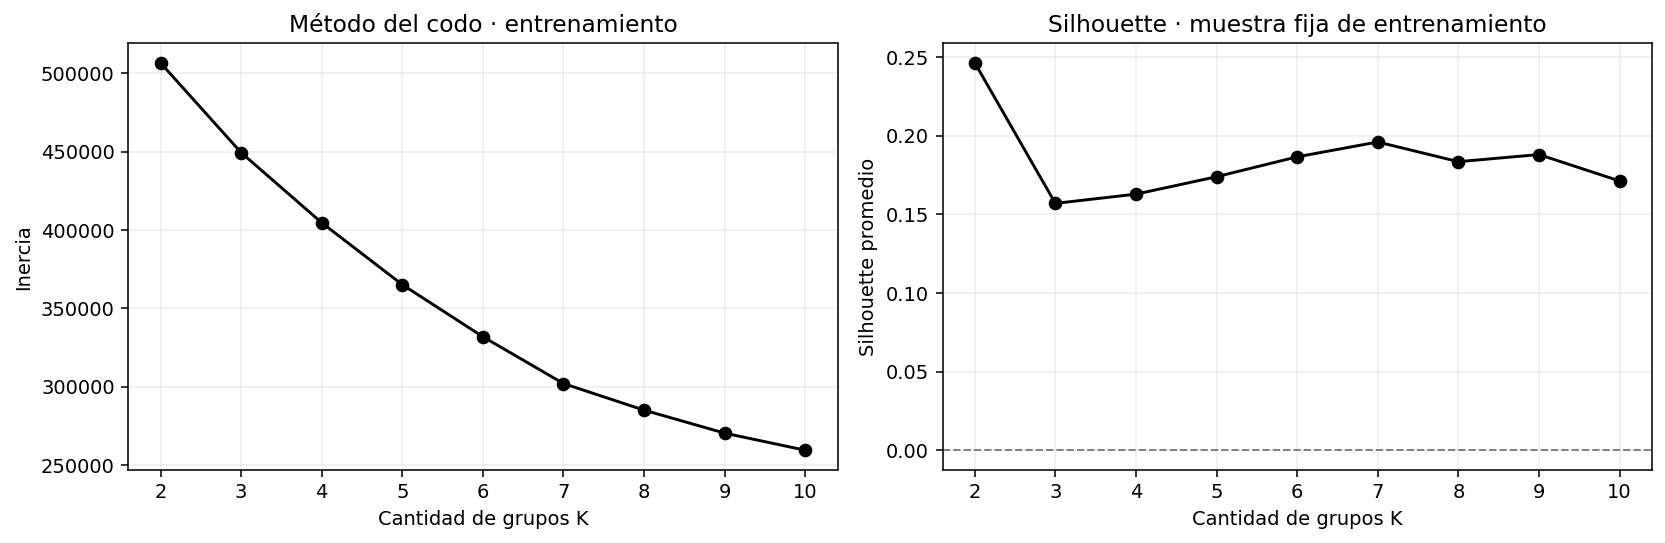

In [71]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(
    tabla_comparacion_k.index, tabla_comparacion_k["Inercia entrenamiento"],
    marker="o", color="black",
)
ejes[0].set(title="Método del codo · entrenamiento", xlabel="Cantidad de grupos K", ylabel="Inercia")
ejes[1].plot(
    tabla_comparacion_k.index, tabla_comparacion_k["Silhouette muestra"],
    marker="o", color="black",
)
ejes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
ejes[1].set(title="Silhouette · muestra fija de entrenamiento", xlabel="Cantidad de grupos K", ylabel="Silhouette promedio")
for eje in ejes:
    eje.set_xticks(valores_k_clustering)
    eje.grid(alpha=0.2)
fig.tight_layout()
plt.show()


**Lectura de los gráficos y su código:** `subplots(1, 2)` crea una fila con dos gráficos; `figsize` controla su tamaño. Cada `plot` coloca K en el eje horizontal y una métrica en el vertical. `marker="o"` señala los valores efectivamente calculados; las líneas solo los conectan. `set` añade título y nombres de ejes. `axhline(0)` dibuja la referencia cero en silhouette, sin convertirla en una meta de aprobación. El `for` fija marcas enteras y cuadrícula; `tight_layout` ajusta espacios y `show` muestra la figura.

**Codo:** observar dónde la pendiente de la inercia pasa de una caída marcada a reducciones más modestas. Puede haber varios cambios graduales o ninguno convincente. No elegimos K=10 simplemente porque su inercia sea la menor. Tampoco imponemos un valor mediante una fórmula que no hayamos justificado.

**Silhouette:** mayor promedio indica mayor separación relativa según esta muestra y esta distancia. Cerca de cero hay solapamiento; valores negativos por canción pueden sugerir que su asignación no es adecuada en ese espacio. Un promedio positivo puede coexistir con canciones negativas o grupos débiles. No mide similitud con géneros reales, exactitud predictiva ni causalidad sobre popularidad.


In [72]:
candidatos_k_evaluables = tabla_comparacion_k.loc[
    tabla_comparacion_k["Silhouette muestra"].notna()
    & tabla_comparacion_k["Grupos sin representación"].eq("Ninguno")
    & ~tabla_comparacion_k["Alcanza límite de iteraciones"]
].reset_index()
assert not candidatos_k_evaluables.empty, "No hay candidatos evaluables sin alertas; revisar antes de elegir."
orden_k_silhouette = candidatos_k_evaluables.sort_values(
    ["Silhouette muestra", "K"], ascending=[False, True]
)
k_candidato_silhouette = int(orden_k_silhouette.iloc[0]["K"])
etiquetas_k_candidato = etiquetas_kmeans_train[k_candidato_silhouette]

assert all(serie.index.equals(X_clustering_train_escalado.index) for serie in etiquetas_kmeans_train.values())
assert all(serie.notna().all() for serie in etiquetas_kmeans_train.values())
criterios_clustering.loc[
    criterios_clustering["Control o criterio"].eq("Cobertura de asignación"), "Estado"
] = "Comprobado: 100% en cada K de 2 a 10"
criterios_clustering.loc[
    criterios_clustering["Control o criterio"].eq("Inercia y codo"), "Estado"
] = "Calculado y graficado: requiere lectura conjunta"
criterios_clustering.loc[
    criterios_clustering["Control o criterio"].eq("Silhouette"), "Estado"
] = "Calculado en muestra fija: candidato provisional, sin umbral de aprobación"
print(f"Candidato por mayor silhouette de la muestra: K={k_candidato_silhouette}.")
print("No es una elección final: faltan perfiles, tamaños detallados y estabilidad.")
display(orden_k_silhouette[["K", "Silhouette muestra", "Inercia entrenamiento"]])
display(criterios_clustering)


Candidato por mayor silhouette de la muestra: K=2.
No es una elección final: faltan perfiles, tamaños detallados y estabilidad.


,K,Silhouette muestra,Inercia entrenamiento
0,2,0.246264,506600.518474
5,7,0.195949,301937.538827
7,9,0.187959,270297.871225
4,6,0.186515,331833.159710
6,8,0.183439,284971.799719
3,5,0.173865,365064.589107
8,10,0.171194,259383.682016
2,4,0.162789,404576.562587
1,3,0.156931,449339.640019


,Control o criterio,Meta o regla de lectura,Estado
0,Filas y entradas,Mismos IDs de entrenamiento; 9 entradas numéricas,Comprobado
1,Ausencias e infinitos al ajustar,0 después de la preparación,Comprobado: preparación de entrenamiento sin ausencias ni infinitos
2,Cobertura de asignación,100% del entrenamiento con un grupo,Comprobado: 100% en cada K de 2 a 10
3,Inercia y codo,Comparar K de 2 a 10 en el mismo espacio,Calculado y graficado: requiere lectura conjunta
4,Silhouette,Mayor promedio evaluable; sin umbral universal,"Calculado en muestra fija: candidato provisional, sin umbral de aprobación"
5,Tamaños y perfiles,Describir todos los grupos y sus límites,Pendiente: interpretar
6,Estabilidad,Revisar candidatos con tres semillas,Pendiente: repetir ajustes


**Alcance de esta lectura inicial:** la elección de K=2 corresponde a la regla original sin restricción de detalle. La decisión vigente para playlists se encuentra en 10.9 y sustituye esa elección provisional.

**Lectura de la selección provisional:** el filtro conserva resultados calculables, con todos los grupos representados en la muestra y sin alcanzar el límite de iteraciones. `~` invierte esa última condición. Estos son controles de evaluación, no garantías de calidad musical. `reset_index()` vuelve a poner K como columna. Si no hay candidatos, el `assert` detiene la selección.

`sort_values` ordena primero por silhouette de mayor a menor y, solo ante empate exacto, por K de menor a mayor. `iloc[0]` toma la primera propuesta según la regla fijada antes de calcular resultados. `int` guarda K como entero. Guardamos sus etiquetas para inspeccionarlas después, sin declararlas definitivas.

Los últimos `assert` comprueban que todas las propuestas mantienen exactamente los IDs de entrenamiento y una etiqueta presente por canción. La tabla actualiza solo criterios ya verificados. Los tamaños generales se calcularon como diagnóstico inicial; todavía faltan tamaños detallados por grupo, perfiles interpretables y revisión con otras semillas. **Un candidato encabeza esta comparación, pero eso no significa que el agrupamiento esté validado o que cumpla una meta predictiva.**


**Alcance de esta lectura inicial:** la elección de K=2 corresponde a la regla original sin restricción de detalle. La decisión vigente para playlists se encuentra en 10.9 y sustituye esa elección provisional.

### 10.8. Qué muestran los resultados reales de entrenamiento

| K | Inercia de entrenamiento | Silhouette en la muestra fija |
|---:|---:|---:|
| 2 | 506600.52 | 0.2463 |
| 3 | 449339.64 | 0.1569 |
| 4 | 404576.56 | 0.1628 |
| 5 | 365064.59 | 0.1739 |
| 6 | 331833.16 | 0.1865 |
| 7 | 301937.54 | 0.1959 |
| 8 | 284971.80 | 0.1834 |
| 9 | 270297.87 | 0.1880 |
| 10 | 259383.68 | 0.1712 |

**Inercia:** baja desde aproximadamente 506.601 para K=2 hasta 259.384 para K=10. Esto indica mayor compacidad al permitir más centros, pero no demuestra que diez grupos sean más útiles. Por ejemplo, pasar de K=2 a K=3 reduce la inercia **11,30%**; pasar de K=7 a K=8, **5,62%**; y de K=9 a K=10, **4,04%**.

**Lectura del codo:** la curva se aplana progresivamente. Alrededor de K=7 se observa una disminución en las ganancias al añadir grupos: las reducciones relativas de aproximadamente 9% de los pasos anteriores pasan a alrededor de 5–6% y luego 4%. Es una señal visual para inspeccionar K=7 como alternativa más detallada; **no hay una ruptura tan marcada que obligue a elegirlo como único codo**. No se calcula un «K óptimo del codo» automático ni se reemplaza la regla provisional después de mirar los resultados.

**Silhouette:** el mayor promedio es **0,2463 para K=2**. El siguiente es aproximadamente **0,1959 para K=7**. Por la regla previamente fijada, **K=2 es el candidato provisional**. El valor 0,2463 indica separación relativa positiva, pero está lejos del extremo 1 y no respalda describir grupos perfectamente separados. No equivale a 24,63% de aciertos ni al porcentaje de canciones correctamente agrupadas. Tampoco permite afirmar que cada canción tenga un silhouette positivo: eso requerirá revisar sus valores individuales y por grupo.

**Tamaños:** con K=2 hay **53.787 y 17.941 canciones**, aproximadamente **74,99% y 25,01%**. El desequilibrio no invalida por sí solo la propuesta ni justifica balancear canciones para forzar igualdad. A partir de K=5 aparecen grupos menores a 1.000 canciones; por ejemplo, en K=7 el menor tiene **834** (aproximadamente 1,16% del entrenamiento). Antes de interpretarlos como estilos particulares debemos revisar sus perfiles y si están dominados por extremos.

**Controles completados:** cada candidato asignó una etiqueta a las 71.728 canciones, produjo exactamente K grupos y tuvo todos sus grupos representados en la muestra de silhouette. Ninguno alcanzó el límite de 300 iteraciones; el mejor intento utilizó entre **10 y 74 iteraciones**, según K. Las iteraciones no son una métrica de calidad: usar menos no convierte un agrupamiento en mejor.

**Conclusión de esta etapa:** codo y silhouette aportan perspectivas distintas. El codo sugiere revisar el beneficio decreciente de una segmentación más detallada; silhouette favorece aquí la partición más amplia de dos grupos. Conservamos **K=2 como candidato según el criterio acordado**, sin declararlo elección definitiva ni inventar una meta cumplida de calidad musical. La selección usa la muestra fija y la semilla definidas, por lo que puede cambiar con otras muestras o inicializaciones.

**Siguiente paso:** examinar tamaños y perfiles de los grupos de K=2, revisar silhouette por grupo y estabilidad con las semillas previstas. K=7 puede conservarse como alternativa de mayor detalle para contrastar, explicando que proviene de esta lectura exploratoria. Popularidad y géneros podrán describirse después, sin usarlos para formar grupos ni para elegir el K que dé la diferencia de popularidad más atractiva. No se utilizó test, no se alteraron los análisis anteriores y no se modificó el CSV.


### 10.9. Objetivo de playlists: excluir dos grupos por falta de detalle

**Objetivo aplicado:** obtener varios perfiles de canciones similares en audio para apoyar playlists y sugerencias. Una separación de solo dos perfiles resulta demasiado general para este uso. Por eso **K=2 no es elegible**, aunque obtuvo el mayor silhouette de la comparación inicial. Conservamos su resultado como referencia; no afirmamos que sea un ajuste incorrecto.

**Regla vigente:** comparar K=3 a K=10 entre los candidatos ya calculados y evaluables; priorizar mayor silhouette en la misma muestra fija, con menor K solo ante empate exacto. El codo sigue como apoyo visual, junto con perfiles, tamaños y estabilidad. No imponemos que los grupos sean iguales ni descartamos automáticamente grupos grandes: no se ha definido un requisito de capacidad por playlist.

Esta restricción se incorporó **después de observar los resultados**, al precisar el uso del proyecto. Es una revisión explícita del objetivo, no una regla supuestamente fijada antes ni evidencia independiente de que siete grupos sean la respuesta correcta. No volvemos a ajustar modelos, no cambiamos escalamiento, muestra o semilla y no consultamos test.

No existe aquí una justificación para exigir exactamente siete o nueve perfiles de antemano. El mínimo de tres excluye únicamente la segmentación que no cumple el nivel de detalle solicitado. La utilidad musical deberá revisarse después.


In [73]:
k_minimo_playlists = 3
candidatos_k_playlists = tabla_comparacion_k.loc[
    (tabla_comparacion_k.index >= k_minimo_playlists)
    & tabla_comparacion_k["Silhouette muestra"].notna()
    & tabla_comparacion_k["Grupos sin representación"].eq("Ninguno")
    & ~tabla_comparacion_k["Alcanza límite de iteraciones"]
].reset_index()
assert not candidatos_k_playlists.empty, "No hay candidatos válidos para este objetivo."
orden_k_playlists = candidatos_k_playlists.sort_values(
    ["Silhouette muestra", "K"], ascending=[False, True]
)
k_candidato_playlists = int(orden_k_playlists.iloc[0]["K"])
etiquetas_k_playlists = etiquetas_kmeans_train[k_candidato_playlists].copy()
modelo_kmeans_playlists = modelos_kmeans_train[k_candidato_playlists]
assert k_candidato_playlists >= k_minimo_playlists
assert etiquetas_k_playlists.index.is_unique
assert etiquetas_k_playlists.notna().all()

estado_seleccion_playlists = pd.DataFrame([
    ["Objetivo", "Perfiles de audio para apoyar playlists y sugerencias"],
    ["K=2", "Excluido de la selección por falta de detalle; conservado como referencia"],
    ["Rango elegible", "K de 3 a 10"],
    ["Candidato provisional", f"K={k_candidato_playlists}"],
    ["Pendiente", "Perfiles musicales, silhouette por grupo, tamaños y estabilidad"],
], columns=["Decisión", "Estado"])
print(f"Candidato provisional para playlists: K={k_candidato_playlists}.")
display(orden_k_playlists[["K", "Silhouette muestra", "Inercia entrenamiento", "Grupo menor (canciones)", "Grupo mayor (%)"]])
display(estado_seleccion_playlists)


Candidato provisional para playlists: K=7.


,K,Silhouette muestra,Inercia entrenamiento,Grupo menor (canciones),Grupo mayor (%)
4,7,0.195949,301937.538827,834,30.536192
6,9,0.187959,270297.871225,734,22.147557
3,6,0.186515,331833.159710,839,34.690776
5,8,0.183439,284971.799719,824,25.257919
2,5,0.173865,365064.589107,874,37.565525
7,10,0.171194,259383.682016,732,18.465592
1,4,0.162789,404576.562587,5677,40.933805
0,3,0.156931,449339.640019,15518,44.310451


,Decisión,Estado
0,Objetivo,Perfiles de audio para apoyar playlists y sugerencias
1,K=2,Excluido de la selección por falta de detalle; conservado como referencia
2,Rango elegible,K de 3 a 10
3,Candidato provisional,K=7
4,Pendiente,"Perfiles musicales, silhouette por grupo, tamaños y estabilidad"


**Lectura del código:** `k_minimo_playlists=3` declara el nivel mínimo de detalle. El filtro conserva K de al menos tres y los controles anteriores de evaluación; `&` exige todas las condiciones y `~` excluye ajustes que alcanzaron el límite de iteraciones. `reset_index()` pone K como columna. El primer `assert` impide seleccionar si no queda ninguna opción.

`sort_values` mantiene la misma regla de silhouette descendente y K ascendente para empates. `iloc[0]` obtiene el candidato y `int` guarda su cantidad de grupos. Recuperamos sus etiquetas y el modelo **ya ajustado**: no ejecutamos otro entrenamiento. `.copy()` permite trabajar con una copia de las etiquetas. Las comprobaciones exigen K suficiente, IDs únicos y etiquetas presentes. La tabla final deja visible la decisión aplicada y lo pendiente.

**Resultado real:** entre K=3 a K=10, **K=7 obtiene el mayor silhouette de la muestra: 0,1959**. Su inercia es aproximadamente **301.937,54**, el grupo menor contiene **834 canciones** y el mayor reúne **30,54%** del entrenamiento. El aplanamiento de la curva alrededor de siete grupos aporta una señal complementaria, sin demostrar un codo único. No convertimos 0,1959 en porcentaje de aciertos ni en garantía de calidad de las playlists.

**Qué aportarían estos grupos:** podrían servir como conjuntos iniciales desde los cuales sugerir canciones con audio parecido. Antes de proponer nombres como «relajación» o «energía», debemos inspeccionar las características reales de cada grupo. Tener siete grupos no significa que ya tengamos siete playlists terminadas, siete géneros o recomendaciones personalizadas.

Para pasar de agrupamiento a sugerencias, una etapa posterior podría tomar una canción de referencia y ordenar otras canciones por cercanía en el mismo espacio de audio, considerando su grupo y revisando también alternativas próximas de otros grupos. Las fronteras no deben tratarse como barreras musicales absolutas. La personalización exigiría preferencias o interacciones del usuario; este dataset no las aporta. La utilidad final requerirá revisión musical o evaluación con usuarios, además de las métricas internas.

**Siguiente paso vigente:** describir los siete perfiles, tamaños y silhouettes por grupo y comprobar estabilidad con las semillas previstas. Si estos perfiles no son útiles o estables, lo reportaremos y revisaremos la propuesta dentro del entrenamiento. La popularidad no determinará qué canciones son musicalmente similares.


### 10.10. K=7 frente a K=9: perfiles y utilidad para playlists

**Pregunta:** ¿los dos grupos adicionales de K=9 aportan perfiles de audio distintos y reproducibles que compensen la pequeña pérdida de silhouette? Conservamos ambas propuestas y sus etiquetas originales. No elegimos por popularidad, géneros ni respuestas de test.

Evaluaremos tres aspectos: **perfiles musicales** (medias, medianas y variación interna), **tamaños y solapamiento** (cuántas canciones hay y cómo se redistribuyen), y **estabilidad ante inicialización** (si cambian las asignaciones al usar las semillas 7, 42 y 2026 con diez inicializaciones por ajuste). La semilla 42 corresponde al modelo ya ajustado y no se repite. Mantenemos la imputación y el escalamiento aprendidos en entrenamiento para aislar el efecto de la inicialización.

Esta revisión no es un experimento con oyentes ni una evaluación de recomendaciones personalizadas. Los perfiles son candidatos para apoyar playlists. Un nombre como «más acústico» describe el promedio del grupo, no cada canción ni una emoción garantizada. Los índices del proveedor son rasgos estimados.


In [74]:
ks_perfiles_playlists = [7, 9]
perfiles_z_playlists = {}
perfiles_originales_playlists = {}
medianas_originales_playlists = {}
dispersion_z_playlists = {}
resumen_grupos_playlists = {}
for k in ks_perfiles_playlists:
    grupos = etiquetas_kmeans_train[k]
    assert grupos.index.equals(X_clustering_train_escalado.index)
    perfiles_z_playlists[k] = X_clustering_train_escalado.groupby(grupos).mean()
    perfiles_originales_playlists[k] = X_clustering_train_imputado.groupby(grupos).mean()
    medianas_originales_playlists[k] = X_clustering_train_imputado.groupby(grupos).median()
    dispersion_z_playlists[k] = X_clustering_train_escalado.groupby(grupos).std(ddof=0)
    tamanos = grupos.value_counts().sort_index()
    resumen = pd.DataFrame({"Canciones": tamanos, "% entrenamiento": 100 * tamanos / len(grupos)})
    sil = silhouette_por_cancion_muestra[k]
    resumen["Canciones en muestra silhouette"] = grupos.loc[sil.index].value_counts()
    resumen["Silhouette medio muestra"] = sil.groupby(grupos.loc[sil.index]).mean()
    resumen["Silhouette mediano muestra"] = sil.groupby(grupos.loc[sil.index]).median()
    resumen["Silhouette negativo muestra (%)"] = 100 * sil.lt(0).groupby(grupos.loc[sil.index]).mean()
    resumen["Dispersión media de las 9 entradas (DE)"] = dispersion_z_playlists[k].mean(axis=1)
    resumen_grupos_playlists[k] = resumen
    print(f"K={k}: tamaños, silhouette por grupo y perfiles en unidades originales.")
    display(resumen.round(4))
    display(perfiles_originales_playlists[k].round(4))
    display(medianas_originales_playlists[k].round(4))


K=7: tamaños, silhouette por grupo y perfiles en unidades originales.
K=9: tamaños, silhouette por grupo y perfiles en unidades originales.


,Canciones,% entrenamiento,Canciones en muestra silhouette,Silhouette medio muestra,Silhouette mediano muestra,Silhouette negativo muestra (%),Dispersión media de las 9 entradas (DE)
grupo,,,,,,,
0,5016,6.9931,361,0.1786,0.1862,11.6343,0.7965
1,5233,7.2956,340,0.2492,0.2738,6.1765,0.8010
2,21903,30.5362,1477,0.1821,0.1792,1.4218,0.6068
3,16179,22.5560,1154,0.1829,0.1832,0.2600,0.5989
4,834,1.1627,68,0.5495,0.6352,4.4118,0.8406
5,8121,11.3219,557,0.1733,0.1730,5.9246,0.7150
6,14442,20.1344,1043,0.2077,0.2200,3.2598,0.6400


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
grupo,,,,,,,,,
0,0.5208,0.7514,-7.0940,0.0890,0.2892,0.0781,0.7433,0.5022,123.5230
1,0.3399,0.1658,-21.4464,0.0512,0.8607,0.7792,0.1627,0.1789,105.2427
2,0.7055,0.7163,-6.5522,0.0962,0.2205,0.0203,0.1639,0.6987,117.5836
3,0.4733,0.8174,-5.3326,0.0862,0.0759,0.0375,0.1952,0.3736,140.5162
4,0.5725,0.6800,-11.2021,0.8478,0.7443,0.0075,0.6639,0.4369,100.4926
5,0.5828,0.7392,-8.4996,0.0718,0.1155,0.7968,0.1707,0.3430,126.8689
6,0.5273,0.3762,-10.6214,0.0541,0.6835,0.0334,0.1602,0.3930,113.4489


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
grupo,,,,,,,,,
0,0.5320,0.7825,-6.5205,0.0572,0.1905,0.000,0.726,0.512,124.0635
1,0.3230,0.1260,-20.5130,0.0422,0.9510,0.893,0.111,0.118,99.9980
2,0.7060,0.7260,-6.1620,0.0544,0.1470,0.000,0.123,0.719,117.9810
3,0.4850,0.8570,-5.1110,0.0582,0.0134,0.000,0.151,0.355,140.1420
4,0.5705,0.7150,-10.6345,0.9170,0.8035,0.000,0.729,0.436,92.5810
5,0.6190,0.7760,-8.2430,0.0532,0.0095,0.840,0.117,0.293,125.0080
6,0.5320,0.3800,-10.2040,0.0364,0.7330,0.000,0.119,0.362,112.4540


,Canciones,% entrenamiento,Canciones en muestra silhouette,Silhouette medio muestra,Silhouette mediano muestra,Silhouette negativo muestra (%),Dispersión media de las 9 entradas (DE)
grupo,,,,,,,
0,4028,5.6157,269,0.1117,0.1190,19.7026,0.7085
1,15886,22.1476,1066,0.2046,0.2029,0.8443,0.5346
2,7836,10.9246,540,0.1495,0.1568,8.5185,0.7009
3,12492,17.4158,889,0.2053,0.2169,7.4241,0.6096
4,4696,6.5470,337,0.1716,0.1877,16.6172,0.7846
5,734,1.0233,60,0.5908,0.6286,0.0000,0.7416
6,9578,13.3532,674,0.1565,0.1442,6.2315,0.5863
7,5118,7.1353,331,0.2427,0.2641,7.8550,0.7972
8,11360,15.8376,834,0.1790,0.1742,0.0000,0.5211


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
grupo,,,,,,,,,
0,0.7213,0.6549,-7.3313,0.3183,0.2657,0.0254,0.1786,0.5676,119.2886
1,0.7074,0.7231,-6.5954,0.0626,0.2434,0.0248,0.1653,0.7609,119.4431
2,0.5839,0.7397,-8.5302,0.0698,0.1155,0.8037,0.1707,0.3400,126.6623
3,0.5214,0.3536,-10.9562,0.0480,0.7311,0.0375,0.1620,0.3919,114.4225
4,0.5177,0.7530,-7.1254,0.0840,0.2920,0.0823,0.7583,0.5000,123.6941
5,0.5609,0.7021,-11.2349,0.8847,0.7790,0.0052,0.7189,0.4242,99.5676
6,0.4555,0.8217,-5.2432,0.0884,0.1030,0.0457,0.2011,0.4511,162.4324
7,0.3374,0.1654,-21.5498,0.0508,0.8594,0.7897,0.1626,0.1770,105.1793
8,0.5425,0.7434,-6.0857,0.0627,0.1002,0.0308,0.1784,0.3353,107.7305


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
grupo,,,,,,,,,
0,0.730,0.6590,-6.9655,0.3040,0.1970,0.000,0.1270,0.577,117.9225
1,0.709,0.7380,-6.1770,0.0483,0.1650,0.000,0.1250,0.774,120.0310
2,0.621,0.7765,-8.2665,0.0531,0.0095,0.844,0.1160,0.290,125.0105
3,0.525,0.3550,-10.5670,0.0361,0.7660,0.000,0.1200,0.363,114.3170
4,0.530,0.7880,-6.5300,0.0563,0.1975,0.000,0.7450,0.510,124.9315
5,0.563,0.7380,-10.7640,0.9250,0.8140,0.000,0.7585,0.426,91.6090
6,0.464,0.8690,-4.9620,0.0638,0.0182,0.000,0.1580,0.447,161.8520
7,0.321,0.1260,-20.6310,0.0422,0.9520,0.895,0.1110,0.115,99.9840
8,0.547,0.7490,-5.8110,0.0464,0.0329,0.000,0.1330,0.335,107.1045


**Lectura del código:**

1. La lista declara las dos propuestas; los diccionarios guardan resultados separados por K. El `for` evita escribir dos veces el mismo procedimiento.
2. Recuperamos las etiquetas de los modelos ya ajustados y comprobamos su correspondencia con los IDs. `groupby(grupos)` reúne filas con la misma etiqueta; `.mean()` calcula cada promedio y `.median()` el valor central. Las unidades originales facilitan leer BPM, decibelios e índices. Los valores de tempo imputados permanecen incluidos y no representan mediciones nuevas.
3. El perfil estandarizado describe cuánto se aparta el promedio de cada grupo de la media global de entrenamiento. No es una lista de canciones ni un género. Calculamos medias de las canciones asignadas, que pueden diferir mínimamente de los centros almacenados si el algoritmo se detuvo por tolerancia.
4. `.std(ddof=0)` mide variación **dentro de cada grupo** en unidades de desviación global. Promediarla entre las nueve columnas ofrece un resumen de dispersión; no es silhouette ni error predictivo. No tiene un umbral universal de aprobación y puede ocultar variables dispersas.
5. `value_counts().sort_index()` cuenta canciones por etiqueta. Dividir por el total y multiplicar por 100 produce porcentaje del entrenamiento: no porcentaje de aciertos.
6. Recuperamos el silhouette individual guardado en la muestra fija. Las etiquetas se alinean por ID antes de agrupar; `mean`, `median` y `lt(0).mean()*100` resumen su promedio, valor central y porcentaje negativo. El número de canciones muestreadas por grupo permite evaluar cuánta evidencia sostiene esos resúmenes. Los porcentajes negativos describen **solo la muestra**, no todas las canciones del grupo.
7. `.round(4)` cambia la presentación a cuatro decimales, sin alterar las tablas guardadas. Mostramos medias y medianas para detectar si los promedios pueden estar influidos por distribuciones asimétricas; no basta con el promedio para afirmar homogeneidad.


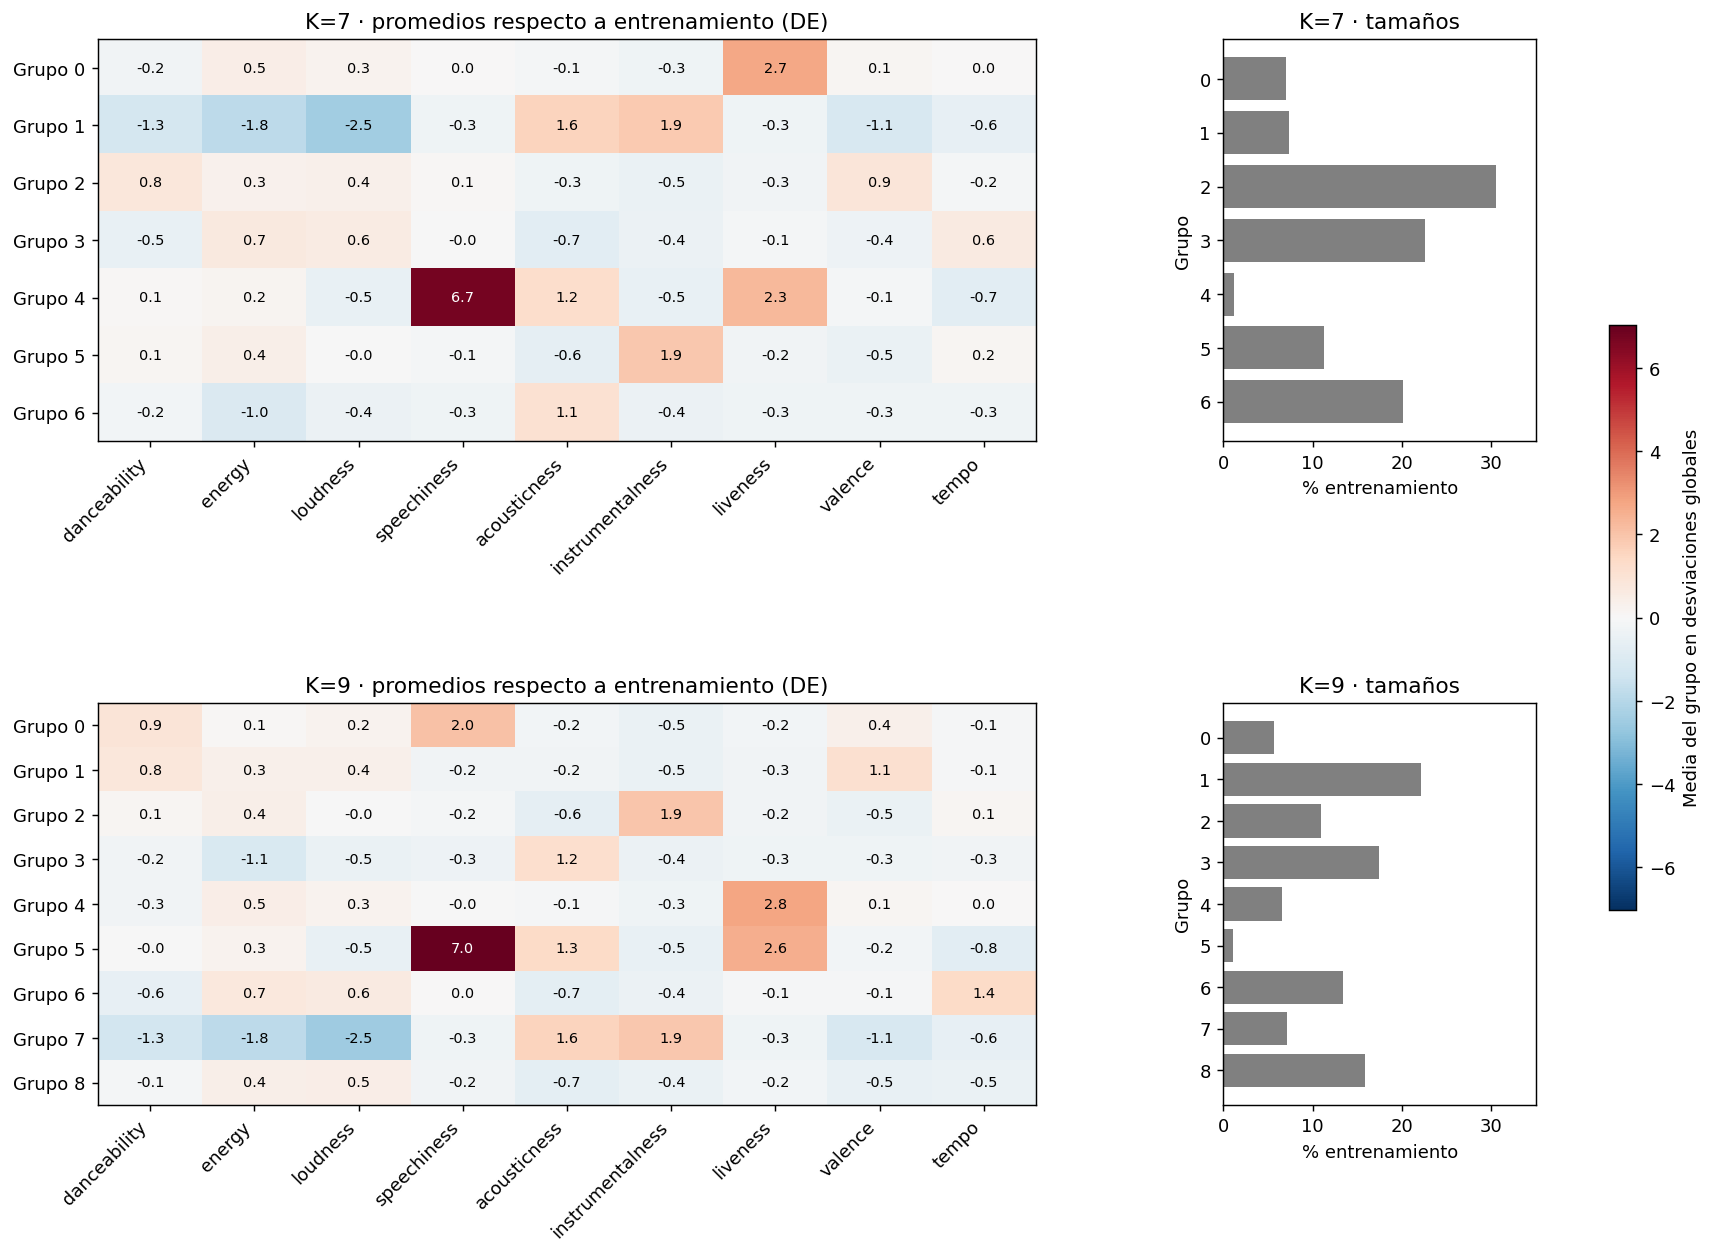

In [75]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(2, 2, figsize=(14, 10), gridspec_kw={"width_ratios": [3, 1]})
limite_color_perfiles = max(float(p.abs().to_numpy().max()) for p in perfiles_z_playlists.values())
for fila, k in enumerate(ks_perfiles_playlists):
    perfiles = perfiles_z_playlists[k]
    imagen = ejes[fila, 0].imshow(
        perfiles, aspect="auto", cmap="RdBu_r",
        vmin=-limite_color_perfiles, vmax=limite_color_perfiles,
    )
    ejes[fila, 0].set_xticks(range(len(variables_clustering)), variables_clustering, rotation=45, ha="right")
    ejes[fila, 0].set_yticks(range(k), [f"Grupo {g}" for g in perfiles.index])
    ejes[fila, 0].set_title(f"K={k} · promedios respecto a entrenamiento (DE)")
    for fila_grupo in range(k):
        for columna in range(len(variables_clustering)):
            valor = float(perfiles.iloc[fila_grupo, columna])
            ejes[fila, 0].text(columna, fila_grupo, f"{valor:.1f}", ha="center", va="center", fontsize=8,
                               color="white" if abs(valor) > 0.6 * limite_color_perfiles else "black")
    porcentajes = resumen_grupos_playlists[k]["% entrenamiento"]
    ejes[fila, 1].barh(range(k), porcentajes, color="gray")
    ejes[fila, 1].set_yticks(range(k), porcentajes.index)
    ejes[fila, 1].invert_yaxis()
    ejes[fila, 1].set_xlim(0, 35)
    ejes[fila, 1].set(title=f"K={k} · tamaños", xlabel="% entrenamiento", ylabel="Grupo")
fig.subplots_adjust(left=0.08, right=0.87, bottom=0.13, top=0.95, hspace=0.65, wspace=0.3)
barra_color = fig.add_axes([0.91, 0.28, 0.015, 0.45])
fig.colorbar(imagen, cax=barra_color, label="Media del grupo en desviaciones globales")
plt.show()


**Lectura del gráfico:** `subplots(2, 2)` reserva una fila para cada K y dos columnas: perfiles y tamaños. `width_ratios` da más espacio a las nueve entradas. El máximo absoluto fija **la misma escala de color** en ambos mapas, para comparar sin exagerar diferencias. `imshow` representa las medias estandarizadas; azul indica menor valor que la media global, rojo mayor y blanco valores cercanos a ella. También imprimimos el número en cada casilla para no depender solo del color.

Los ejes y títulos identifican entradas y grupos; el segundo `for` escribe cada valor. `barh` muestra proporciones; `invert_yaxis` mantiene el orden de arriba hacia abajo y `set_xlim` fija una escala común de tamaños. `subplots_adjust` reserva espacio para etiquetas; `add_axes` crea un espacio lateral para `colorbar`, que explica la escala compartida. No usamos PCA: el mapa muestra las nueve entradas reales mediante sus medias, sin reducir la distancia utilizada al agrupar.

**Ejemplo de lectura:** un promedio de energía `+1` significa una desviación global por encima de la media de entrenamiento. No significa «100% de energía». Un valor acústico negativo indica menor índice acústico relativo, no acústica físicamente negativa. La tabla de medianas y la dispersión deben acompañar esta lectura.


In [76]:
cruce_k7_k9 = pd.crosstab(
    etiquetas_kmeans_train[7].rename("Grupo K=7"),
    etiquetas_kmeans_train[9].rename("Grupo K=9"),
)
cruce_k7_k9_por_fila = 100 * cruce_k7_k9.div(cruce_k7_k9.sum(axis=1), axis=0)
cruce_k7_k9_por_columna = 100 * cruce_k7_k9.div(cruce_k7_k9.sum(axis=0), axis=1)
assert int(cruce_k7_k9.to_numpy().sum()) == len(X_clustering_train_escalado)
print("Conteos de canciones compartidas entre las dos propuestas:")
display(cruce_k7_k9)
print("Porcentaje dentro de cada grupo de K=7 (cada fila suma 100%):")
display(cruce_k7_k9_por_fila.round(2))
print("Porcentaje de origen de cada grupo de K=9 (cada columna suma 100%):")
display(cruce_k7_k9_por_columna.round(2))


Conteos de canciones compartidas entre las dos propuestas:
Porcentaje dentro de cada grupo de K=7 (cada fila suma 100%):
Porcentaje de origen de cada grupo de K=9 (cada columna suma 100%):


Grupo K=9,0,1,2,3,4,5,6,7,8
Grupo K=7,,,,,,,,,
0,96,31,3,12,4659,0,78,0,137
1,5,0,4,107,1,0,0,5115,1
2,2986,15391,8,2,0,0,513,0,3003
3,456,134,66,24,27,0,8717,0,6755
4,99,0,0,0,0,734,0,1,0
5,60,30,7747,8,4,0,113,0,159
6,326,300,8,12339,5,0,157,2,1305


Grupo K=9,0,1,2,3,4,5,6,7,8
Grupo K=7,,,,,,,,,
0,1.91,0.62,0.06,0.24,92.88,0.00,1.56,0.00,2.73
1,0.10,0.00,0.08,2.04,0.02,0.00,0.00,97.75,0.02
2,13.63,70.27,0.04,0.01,0.00,0.00,2.34,0.00,13.71
3,2.82,0.83,0.41,0.15,0.17,0.00,53.88,0.00,41.75
4,11.87,0.00,0.00,0.00,0.00,88.01,0.00,0.12,0.00
5,0.74,0.37,95.39,0.10,0.05,0.00,1.39,0.00,1.96
6,2.26,2.08,0.06,85.44,0.03,0.00,1.09,0.01,9.04


Grupo K=9,0,1,2,3,4,5,6,7,8
Grupo K=7,,,,,,,,,
0,2.38,0.20,0.04,0.10,99.21,0.0,0.81,0.00,1.21
1,0.12,0.00,0.05,0.86,0.02,0.0,0.00,99.94,0.01
2,74.13,96.88,0.10,0.02,0.00,0.0,5.36,0.00,26.43
3,11.32,0.84,0.84,0.19,0.57,0.0,91.01,0.00,59.46
4,2.46,0.00,0.00,0.00,0.00,100.0,0.00,0.02,0.00
5,1.49,0.19,98.86,0.06,0.09,0.0,1.18,0.00,1.40
6,8.09,1.89,0.10,98.78,0.11,0.0,1.64,0.04,11.49


**Lectura del cruce:** `pd.crosstab` cuenta cuántos IDs reciben cada combinación de etiquetas. `rename` identifica el origen de filas y columnas. `div(..., axis=0)` divide por el total de cada fila y `axis=1` por el total de cada columna. Las dos normalizaciones responden preguntas diferentes: a dónde van las canciones de un grupo de K=7 y de dónde vienen las de uno de K=9. El `assert` comprueba cobertura del entrenamiento.

No comparamos «grupo 0» con «grupo 0» por su número: las etiquetas no corresponden entre ajustes. Tampoco suponemos que K=9 divide exactamente dos grupos de K=7. K-Means vuelve a optimizar todos sus centros y puede reorganizar varias fronteras.


In [77]:
from sklearn.cluster import KMeans
from scipy.optimize import linear_sum_assignment
from threadpoolctl import threadpool_limits

filas_estabilidad_playlists = []
filas_estabilidad_grupos = []
etiquetas_semillas_playlists = {}
for k in ks_perfiles_playlists:
    referencia = etiquetas_kmeans_train[k]
    for semilla in semillas_revision_clustering:
        if semilla == configuracion_kmeans["random_state"]:
            modelo_repetido = modelos_kmeans_train[k]
            repetida = referencia.copy()
        else:
            parametros_repeticion = dict(configuracion_kmeans)
            parametros_repeticion["random_state"] = semilla
            modelo_repetido = KMeans(n_clusters=k, **parametros_repeticion)
            with threadpool_limits(limits=1):
                valores_repetidos = modelo_repetido.fit_predict(X_clustering_train_escalado)
            repetida = pd.Series(valores_repetidos, index=referencia.index)
        assert repetida.index.equals(referencia.index)
        assert repetida.nunique() == k
        etiquetas_semillas_playlists[(k, semilla)] = repetida
        cruce = pd.crosstab(referencia, repetida).reindex(index=range(k), columns=range(k), fill_value=0)
        filas, columnas = linear_sum_assignment(-cruce.to_numpy())
        mapa_etiquetas = dict(zip(columnas, filas))
        alineada = repetida.map(mapa_etiquetas)
        acuerdo = float(100 * alineada.eq(referencia).mean())
        jaccards = []
        for grupo in range(k):
            antes = referencia.eq(grupo)
            despues = alineada.eq(grupo)
            interseccion = int((antes & despues).sum())
            union = int((antes | despues).sum())
            jaccard = interseccion / union
            jaccards.append(jaccard)
            filas_estabilidad_grupos.append({
                "K": k, "Semilla": semilla, "Grupo referencia": grupo,
                "Jaccard": jaccard, "Canciones referencia": int(antes.sum()),
                "Canciones repetición alineada": int(despues.sum()),
            })
        filas_estabilidad_playlists.append({
            "K": k, "Semilla": semilla, "Acuerdo alineado (%)": acuerdo,
            "Jaccard medio entre grupos": float(np.mean(jaccards)),
            "Jaccard mínimo de un grupo": float(np.min(jaccards)),
            "Inercia repetición": float(modelo_repetido.inertia_),
            "Alcanza límite": bool(modelo_repetido.n_iter_ >= configuracion_kmeans["max_iter"]),
        })

tabla_estabilidad_playlists = pd.DataFrame(filas_estabilidad_playlists)
tabla_estabilidad_por_grupo = pd.DataFrame(filas_estabilidad_grupos)
estabilidad_nueva_playlists = tabla_estabilidad_playlists.loc[
    tabla_estabilidad_playlists["Semilla"].ne(configuracion_kmeans["random_state"])
]
print("Estabilidad ante inicialización; semilla 42 es la referencia, no evidencia adicional:")
display(tabla_estabilidad_playlists.round(4))
print("Estabilidad de cada grupo en los dos reajustes nuevos:")
display(tabla_estabilidad_por_grupo.loc[tabla_estabilidad_por_grupo["Semilla"].ne(42)].round(4))


Estabilidad ante inicialización; semilla 42 es la referencia, no evidencia adicional:
Estabilidad de cada grupo en los dos reajustes nuevos:


,K,Semilla,Acuerdo alineado (%),Jaccard medio entre grupos,Jaccard mínimo de un grupo,Inercia repetición,Alcanza límite
0,7,7,99.9150,0.9988,0.9973,301937.2952,False
1,7,42,100.0000,1.0000,1.0000,301937.5388,False
2,7,2026,99.9805,0.9996,0.9992,301937.5450,False
3,9,7,80.7133,0.7510,0.0650,273509.1525,False
4,9,42,100.0000,1.0000,1.0000,270297.8712,False
5,9,2026,99.7741,0.9965,0.9881,270295.7219,False


,K,Semilla,Grupo referencia,Jaccard,Canciones referencia,Canciones repetición alineada
0,7,7,0,0.9986,5016,5019
1,7,7,1,0.9994,5233,5230
2,7,7,2,0.9976,21903,21881
3,7,7,3,0.9973,16179,16202
4,7,7,4,1.0000,834,834
5,7,7,5,0.9994,8121,8116
6,7,7,6,0.9992,14442,14446
14,7,2026,0,0.9992,5016,5014
15,7,2026,1,0.9996,5233,5233
16,7,2026,2,0.9997,21903,21899


### 10.11. Cómo leer la estabilidad sin confundir etiquetas

**Código, paso a paso:**

1. `linear_sum_assignment` permite emparejar etiquetas entre dos ajustes; es una herramienta de comparación, no otro modelo de clustering. Sin emparejarlas, grupos equivalentes con números intercambiados parecerían distintos.
2. El primer `for` recorre K=7 y K=9; el segundo las semillas 7, 42 y 2026. En 42 reutilizamos el ajuste original. En las otras dos copiamos la configuración y cambiamos **solo la semilla**: cuatro reajustes nuevos en total, cada uno con diez inicializaciones y todo entrenamiento. No se recalculan medianas o escalas.
3. `fit_predict` vuelve a obtener etiquetas y los `assert` comprueban IDs y número de grupos. Guardamos las etiquetas de cada repetición.
4. La tabla de cruces cuenta coincidencias; `reindex` hace explícitas las K etiquetas en ambos ejes. `linear_sum_assignment` recibe los conteos negativos para encontrar una correspondencia uno a uno que **maximice las canciones compartidas**. `dict(zip(...))` construye esa correspondencia y `map` renombra etiquetas.
5. `eq(...).mean()*100` calcula el porcentaje de asignaciones iguales después de renombrar. Es **acuerdo entre ajustes en entrenamiento**, no precisión frente a una respuesta correcta. La correspondencia se optimiza para este acuerdo; un grupo dominante podría ocultar cambios en grupos pequeños, por eso también revisamos cada grupo.
6. Para cada grupo, `antes` y `despues` son máscaras. `&` cuenta canciones que permanecen en ambos grupos; `|` cuenta las que pertenecen a por lo menos uno. Su cociente es **Jaccard**, una comparación sencilla de conjuntos: 1 significa las mismas canciones y 0 ninguna compartida. Por ejemplo, 80 canciones compartidas sobre una unión de 100 dan 0,8; no es 80% de aciertos. Esta medida se incorpora para explicar estabilidad, sin atribuirle una meta de la rúbrica.
7. Mostramos el promedio sin ponderar de los K Jaccards (cada grupo pesa igual) y el mínimo (el más variable). La correspondencia maximiza el acuerdo total, no el Jaccard de cada grupo: ambos resúmenes se interpretan juntos.
8. La tabla incluye inercia y alertas de iteración para ver si las repeticiones convergen a soluciones parecidas. La semilla 42 da acuerdo y Jaccard 1 por construcción; la excluimos de los resúmenes de evidencia nueva.

**Alcance:** solo probamos sensibilidad a inicialización con dos semillas nuevas y el mismo catálogo. No comprobamos estabilidad ante cambios de muestra, fechas, canciones nuevas ni preferencias de oyentes. Un valor alto respalda reproducibilidad bajo estas condiciones, no utilidad musical por sí solo. No calculamos silhouette nuevo para escoger una semilla que favorezca retrospectivamente una propuesta.


In [78]:
filas_decision_perfiles = []
for k in ks_perfiles_playlists:
    estabilidad_k = estabilidad_nueva_playlists.loc[estabilidad_nueva_playlists["K"].eq(k)]
    grupos_k = resumen_grupos_playlists[k]
    filas_decision_perfiles.append({
        "K": k,
        "Silhouette muestra original": tabla_comparacion_k.loc[k, "Silhouette muestra"],
        "Grupo menor (canciones)": int(grupos_k["Canciones"].min()),
        "Grupo mayor (%)": float(grupos_k["% entrenamiento"].max()),
        "Acuerdo medio nuevas semillas (%)": float(estabilidad_k["Acuerdo alineado (%)"].mean()),
        "Peor Jaccard de grupo (nuevas semillas)": float(estabilidad_k["Jaccard mínimo de un grupo"].min()),
        "Grupos con silhouette medio negativo": int(grupos_k["Silhouette medio muestra"].lt(0).sum()),
    })
tabla_decision_perfiles_playlists = pd.DataFrame(filas_decision_perfiles).set_index("K")
assert all(int(resumen_grupos_playlists[k]["Canciones"].sum()) == len(X_clustering_train_escalado) for k in ks_perfiles_playlists)
assert not tabla_estabilidad_playlists["Alcanza límite"].any()
display(tabla_decision_perfiles_playlists.round(4))
criterios_clustering.loc[
    criterios_clustering["Control o criterio"].eq("Tamaños y perfiles"), "Estado"
] = "Revisados para K=7 y K=9; utilidad musical pendiente de validación con oyentes"
criterios_clustering.loc[
    criterios_clustering["Control o criterio"].eq("Estabilidad"), "Estado"
] = "Revisada ante inicialización (7, 42, 2026) para K=7 y K=9; no ante cambios de muestra"
display(criterios_clustering)


,Silhouette muestra original,Grupo menor (canciones),Grupo mayor (%),Acuerdo medio nuevas semillas (%),Peor Jaccard de grupo (nuevas semillas),Grupos con silhouette medio negativo
K,,,,,,
7,0.1959,834,30.5362,99.9477,0.9973,0
9,0.1880,734,22.1476,90.2437,0.0650,0


,Control o criterio,Meta o regla de lectura,Estado
0,Filas y entradas,Mismos IDs de entrenamiento; 9 entradas numéricas,Comprobado
1,Ausencias e infinitos al ajustar,0 después de la preparación,Comprobado: preparación de entrenamiento sin ausencias ni infinitos
2,Cobertura de asignación,100% del entrenamiento con un grupo,Comprobado: 100% en cada K de 2 a 10
3,Inercia y codo,Comparar K de 2 a 10 en el mismo espacio,Calculado y graficado: requiere lectura conjunta
4,Silhouette,Mayor promedio evaluable; sin umbral universal,"Calculado en muestra fija: candidato provisional, sin umbral de aprobación"
5,Tamaños y perfiles,Describir todos los grupos y sus límites,Revisados para K=7 y K=9; utilidad musical pendiente de validación con oyentes
6,Estabilidad,Revisar candidatos con tres semillas,"Revisada ante inicialización (7, 42, 2026) para K=7 y K=9; no ante cambios de muestra"


**Lectura de la tabla de decisión:** una fila por K reúne los mismos criterios para ambas propuestas. Filtramos solo semillas nuevas, promediamos sus acuerdos y conservamos el peor Jaccard encontrado entre grupos y repeticiones. Contamos también grupos con silhouette medio negativo en la muestra. Los `assert` verifican cobertura completa y ausencia de alertas de límite. Actualizamos el estado de revisión, sin inventar un KPI universal de separación o de satisfacción con playlists.

No sumamos silhouette, tamaños y Jaccard como si compartieran escala ni calculamos una puntuación arbitraria. La decisión se argumentará con los perfiles y la evidencia, distinguiendo ventajas y límites. No se utiliza popularidad, artista, género ni test para elegir entre estas propuestas.


### 10.12. Resultados reales: qué perfiles aporta cada propuesta

Estos nombres son **descripciones exploratorias del audio**, no géneros comprobados ni nombres definitivos de playlists. Los números identifican grupos del ajuste de referencia, semilla 42.

**K=7:**

| Grupo | Canciones | % entrenamiento | Descripción del promedio y evidencia |
|---:|---:|---:|---|
| 0 | 5.016 | 6,99% | Más indicios de interpretación en vivo: `liveness` 0,743; no confirma una grabación en concierto |
| 1 | 5.233 | 7,30% | Acústico e instrumental, de baja energía y sonoridad: energía 0,166, acústica 0,861, instrumentalidad 0,779 y sonoridad −21,45 dB |
| 2 | 21.903 | 30,54% | Mayor bailabilidad y valencia: bailabilidad 0,706, valencia 0,699 y energía 0,716 |
| 3 | 16.179 | 22,56% | Energético, poco acústico y de tempo más rápido: energía 0,817, acústica 0,076 y 140,52 BPM |
| 4 | 834 | 1,16% | Voz hablada muy marcada: `speechiness` 0,848; requiere revisión antes de incluirlo en playlists musicales |
| 5 | 8.121 | 11,32% | Instrumental y energético, con menor carácter acústico: instrumentalidad 0,797, energía 0,739 y acústica 0,115 |
| 6 | 14.442 | 20,13% | Más acústico y de energía menor, con baja instrumentalidad: acústica 0,684, energía 0,376 e instrumentalidad 0,033 |

Por ejemplo, los grupos 1 y 5 son ambos instrumentales, pero difieren mucho en energía y acústica: esa distinción podría ayudar a construir colecciones con ritmos y texturas diferentes. El grupo 2 podría ser punto de partida para una selección bailable; no demuestra que todas sus canciones encajen entre sí. No denominamos automáticamente al grupo 6 «vocal»: un índice instrumental bajo no informa idioma, estilo de voz o gusto del oyente.

**K=9:**

| Grupo | Canciones | % entrenamiento | Descripción del promedio y evidencia |
|---:|---:|---:|---|
| 0 | 4.028 | 5,62% | Bailable con mayor voz hablada: bailabilidad 0,721 y `speechiness` 0,318 |
| 1 | 15.886 | 22,15% | Bailable y de valencia mayor, con menos voz hablada: valencia 0,761 y `speechiness` 0,063 |
| 2 | 7.836 | 10,92% | Instrumental energético: instrumentalidad 0,804 y energía 0,740 |
| 3 | 12.492 | 17,42% | Más acústico y de energía menor: acústica 0,731 y energía 0,354 |
| 4 | 4.696 | 6,55% | Más indicios de interpretación en vivo: `liveness` 0,758 |
| 5 | 734 | 1,02% | Voz hablada muy marcada: `speechiness` 0,885 |
| 6 | 9.578 | 13,35% | Energético de tempo rápido: energía 0,822 y 162,43 BPM |
| 7 | 5.118 | 7,14% | Acústico e instrumental de baja energía: acústica 0,859, instrumentalidad 0,790 y energía 0,165 |
| 8 | 11.360 | 15,84% | Energético de tempo menor que el grupo 6: energía 0,743 y 107,73 BPM |

**Qué añade realmente K=9:** permite distinguir canciones bailables con más voz hablada y diferenciar perfiles energéticos por tempo. Eso es útil como hipótesis para playlists con ritmo semejante. El tempo es estimado y puede tener ambigüedades de mitad/doble tiempo; una diferencia de BPM no garantiza compatibilidad musical.

**El cruce confirma una reorganización, no una división exacta:** el 53,88% del grupo 3 de K=7 pasa al grupo 6 de K=9 y el 41,75% al grupo 8; el 70,27% del grupo 2 de K=7 pasa al grupo 1 de K=9 y el 13,63% al grupo 0. Los porcentajes restantes van a otros grupos. Por tanto, los dos centros adicionales afectan varias fronteras; no son dos playlists nuevas simplemente añadidas a siete anteriores.

### 10.13. Separación y estabilidad: ventajas y límites

**Silhouette:** K=7 mantiene promedio 0,1959 y K=9 0,1880 en la misma muestra. Todos los grupos tienen promedio positivo, pero algunos contienen canciones con valores negativos. En el grupo 0 de K=9, el promedio es **0,1117** y el **19,70%** de sus 269 canciones muestreadas tiene silhouette negativo: el perfil de mayor voz hablada bailable merece especial cautela por sus fronteras difusas. En K=7, el grupo 0 tiene 11,63% negativo entre sus 361 canciones muestreadas. Estos porcentajes no deben extrapolarse como tasas exactas de todo entrenamiento.

Los grupos de voz muy hablada tienen silhouettes altos (0,5495 en K=7 y 0,5908 en K=9), pero eso no los convierte en buenas playlists de canciones musicales: pueden separarse por un rasgo extremo. Su contenido debe revisarse antes de sugerirlo al usuario. No eliminamos esas filas ni forzamos un género a partir de ese índice.

**Estabilidad con dos semillas nuevas, tras alinear etiquetas:**

| K | Acuerdo con semilla 7 | Acuerdo con semilla 2026 | Peor Jaccard de un grupo entre los dos reajustes |
|---:|---:|---:|---:|
| 7 | 99,91% | 99,98% | 0,9973 |
| 9 | 80,71% | 99,77% | 0,0650 |

K=7 conserva prácticamente las mismas asignaciones en ambos reajustes. K=9 reproduce muy bien la solución con semilla 2026, pero con semilla 7 reorganiza alrededor de **19,29%** de las canciones aun después de renombrar los grupos. El grupo de referencia 0 de K=9 tiene Jaccard **0,0650** con el grupo emparejado en esa repetición: no mantiene una identidad parecida. La correspondencia maximiza el acuerdo total y no garantiza el mejor Jaccard para cada grupo; por eso se leen ambas medidas juntas.

Con semilla 7, la inercia de K=9 es aproximadamente **273.509,15**, frente a **270.297,87** de referencia. Sugiere que el reajuste quedó en una solución local diferente y de mayor inercia bajo esta configuración, pese a diez inicializaciones. No demuestra que K=9 sea siempre inestable. Con solo dos semillas nuevas, no estimamos una probabilidad de falla ni estabilidad ante otras muestras. No cambiamos parámetros para intentar que un candidato gane.

### 10.14. Decisión para esta etapa del proyecto

**Recomendamos K=7 como base actual de perfiles para explorar playlists.** Ofrece varios perfiles distinguibles en audio, mejor silhouette de la muestra y mucha mayor consistencia entre las semillas probadas. K=9 aporta detalle musical potencialmente aprovechable y grupos de tamaño más repartido, pero uno de sus perfiles adicionales muestra separación débil y fuerte variación en un reajuste. Preferimos no tratar ese detalle como un beneficio confirmado.

Esto no significa que siete sea el número universal de estilos ni que nueve sea incorrecto. No fijamos retrospectivamente un umbral de Jaccard o silhouette para aprobar: razonamos con la comparación observada. La conclusión sigue siendo exploratoria sobre entrenamiento, sin test, sin datos temporales nuevos y sin evaluación de usuarios.

**Uso propuesto:** los siete grupos pueden actuar como colecciones iniciales para recuperar canciones parecidas, no como siete playlists terminadas. Después se puede seleccionar una canción de referencia y ordenar sugerencias por distancia en las nueve entradas, revisar variedad de artistas y escuchar ejemplos. Aún no implementamos ese recomendador ni afirmamos satisfacción de oyentes. Los grupos con voz hablada requieren revisión específica; las fronteras entre perfiles no deben bloquear canciones cercanas de otros grupos.


In [79]:
# Decisión argumentada en 10.14; no proviene de una puntuación automática nueva.
k_elegido_playlists = 7
modelo_kmeans_playlists = modelos_kmeans_train[k_elegido_playlists]
etiquetas_k_playlists = etiquetas_kmeans_train[k_elegido_playlists].copy()
assert etiquetas_k_playlists.nunique() == k_elegido_playlists
assert etiquetas_k_playlists.notna().all()
assert etiquetas_k_playlists.index.equals(X_clustering_train_escalado.index)

decision_actual_playlists = pd.DataFrame([
    ["Elección actual", "K=7; base exploratoria para perfiles de playlists"],
    ["Motivo", "Perfiles distinguibles, mayor silhouette y consistencia entre semillas"],
    ["K=9", "Alternativa de mayor detalle; sensibilidad observada a inicialización"],
    ["Alcance", "Solo entrenamiento; no es validación de satisfacción ni test externo"],
    ["Pendiente", "Revisión musical, ejemplos y evaluación del uso en sugerencias"],
], columns=["Decisión", "Explicación"])
display(decision_actual_playlists)


,Decisión,Explicación
0,Elección actual,K=7; base exploratoria para perfiles de playlists
1,Motivo,"Perfiles distinguibles, mayor silhouette y consistencia entre semillas"
2,K=9,Alternativa de mayor detalle; sensibilidad observada a inicialización
3,Alcance,Solo entrenamiento; no es validación de satisfacción ni test externo
4,Pendiente,"Revisión musical, ejemplos y evaluación del uso en sugerencias"


**Lectura del cierre:** guardamos explícitamente `k_elegido_playlists=7` por los motivos anteriores, recuperamos el modelo ya ajustado y copiamos sus etiquetas. No hay otro ajuste. Los `assert` verifican siete grupos, una etiqueta por fila y correspondencia de IDs de entrenamiento. La tabla deja visible qué se recomienda y qué sigue sin comprobarse. El CSV original y los modelos de regresión y clasificación permanecen intactos.


### 10.15. Por qué elegimos siete grupos: explicación de la decisión

**Elegimos K=7 como base actual de perfiles para explorar playlists.** La evidencia de entrenamiento respalda esa elección por su consistencia entre las inicializaciones probadas y su silhouette ligeramente mayor. Todavía no hemos demostrado que produzca playlists preferidas por los oyentes.

**Qué significa K:** con K=7 pedimos siete perfiles de audio más amplios; con K=9 permitimos nueve y, por tanto, diferencias más específicas. Un grupo reúne canciones cercanas según las nueve entradas seleccionadas, no canciones idénticas ni necesariamente del mismo género. El número del grupo es una etiqueta, no una clasificación de calidad.

**Siete grupos no limitan el proyecto a siete playlists.** Podemos tomar una canción de referencia y seleccionar otras cercanas dentro de un perfil para construir distintas listas. También conviene revisar canciones próximas de otros grupos: una frontera del algoritmo no es una frontera musical absoluta. El agrupamiento puede organizar el catálogo como punto de partida; aún no hemos implementado ese sistema de sugerencias.

#### Qué diferencias musicales observamos

Con K=7, el grupo 3 es energético y tiene tempo promedio de **140,52 BPM**. Con K=9 aparecen dos perfiles energéticos con tempos medios de **162,43 BPM** (grupo 6) y **107,73 BPM** (grupo 8). También se distingue un perfil bailable con mayor voz hablada de otro con menos voz hablada y mayor valencia.

Estas distinciones podrían ayudar a diseñar listas con velocidad y textura más parecidas. Sin embargo, K-Means vuelve a optimizar todos los centros: K=9 no conserva exactamente siete grupos y agrega dos. El cruce de 10.10 muestra redistribuciones entre varios perfiles. Los promedios de BPM tampoco garantizan compatibilidad: hay variación interna y posibles ambigüedades de mitad/doble tiempo en el tempo estimado.


### 10.16. Diferencias con la elección de K=9 del proyecto original

La comparación se refiere a la **versión del cuaderno original consultada**, cuyo procedimiento elegía K=9. No afirmamos que esa elección fuera incorrecta ni que nuestro análisis sea una reproducción exacta de sus resultados.

| Aspecto | Proyecto original consultado | Procedimiento actual |
|---|---|---|
| Uso del agrupamiento | Estudiar perfiles sonoros y su relación con géneros | Obtener perfiles de audio para apoyar playlists y sugerencias |
| Rango explorado | K de 2 a 15 | K de 2 a 10; K=2 se conserva como referencia, pero no es elegible para el detalle solicitado |
| Restricción de tamaño | El grupo mayor no podía superar el 50% para que la propuesta se considerara válida | Describimos tamaños; no exigimos grupos iguales ni fijamos un máximo automático |
| Papel de silhouette | Entre propuestas válidas, conservaba las que alcanzaban al menos el 90% del mejor silhouette válido | Mayor silhouette entre candidatos elegibles como elección provisional; revisión posterior de perfiles y estabilidad |
| Papel de los géneros | V de Cramér intervenía en la selección final entre candidatos | Géneros fuera de las entradas y de la elección de K |
| Decisión | K=9 bajo sus reglas | K=7 bajo nuestro objetivo y evidencia de entrenamiento |

**Cómo eligió el original:** probó cantidades de grupos, aplicó sus filtros, conservó opciones con silhouette cercano al mejor válido y, entre ellas, eligió la de mayor asociación con géneros mediante V de Cramér. Por eso no eligió simplemente el mayor silhouette de toda la tabla. V de Cramér cuantifica asociación entre categorías: no demuestra calidad de playlists ni causalidad.

**Por qué ahora puede cambiar K:** precisamos un uso diferente y estamos aplicando otros criterios. Además, las bases preparadas y la evaluación no son idénticas: por ejemplo, nuestra muestra fija de silhouette tiene 5.000 canciones y la del original consultado tenía 10.000. No interpretamos diferencias numéricas entre proyectos como una competencia directa ni atribuimos todo el cambio únicamente a K.

K=2 se excluyó de nuestra selección después de precisar que dos perfiles eran demasiado generales para playlists; esa decisión posterior está documentada en 10.9. No presentamos esa restricción como si hubiera sido fijada antes de ver los resultados. Para comparar K=7 y K=9 sí mantuvimos las mismas filas de entrenamiento, preparación y muestra dentro del procedimiento actual.

Fuente del procedimiento original: [EP2_Spotify_CRISP_DM_Modelado.ipynb, sección de agrupamiento](https://github.com/ritnight/machine-learning-spotify/blob/main/notebooks/EP2_Spotify_CRISP_DM_Modelado.ipynb). La descripción corresponde a la versión revisada; el repositorio puede cambiar posteriormente.


### 10.17. Beneficios y consecuencias de K=7 frente a K=9

| Evidencia de nuestro entrenamiento | K=7 | K=9 | Qué implica |
|---|---:|---:|---|
| Silhouette de la misma muestra | 0,1959 | 0,1880 | Ventaja pequeña de separación promedio para K=7 |
| Mayor grupo | 30,54% | 22,15% | K=9 reparte el catálogo en perfiles más pequeños; esto no garantiza mejor coherencia musical |
| Acuerdo con reajuste de semilla 7 | 99,91% | 80,71% | K=9 reorganiza una parte importante de las asignaciones en esta repetición |
| Acuerdo con reajuste de semilla 2026 | 99,98% | 99,77% | Ambos reproducen muy bien la referencia en esta otra repetición |
| Peor Jaccard de grupo entre los reajustes nuevos | 0,9973 | 0,0650 | En K=9 hay un perfil de referencia que no conserva una identidad parecida en una repetición |

**Qué significa la ventaja de silhouette:** la diferencia es aproximadamente 0,008. Es pequeña y por sí sola no basta para afirmar que K=7 producirá mejores playlists. Ambos promedios están lejos de una separación perfecta y pueden ocultar canciones o grupos con fronteras difusas. No son porcentajes de aciertos.

**Qué significa la estabilidad:** después de emparejar etiquetas entre ajustes, K=7 conserva prácticamente las mismas canciones en sus perfiles con ambas semillas nuevas. K=9 reproduce la referencia con semilla 2026, pero con semilla 7 cambia alrededor de **19,29%** de las asignaciones. En esa repetición también obtiene mayor inercia, compatible con una solución local diferente bajo la configuración utilizada. Esto no prueba que K=9 siempre sea inestable ni que aumentar inicializaciones no pudiera ayudar; no hicimos ese experimento y no cambiamos parámetros para favorecerlo.

**Consecuencia práctica:** si guardamos el modelo elegido, las asignaciones no cambian cada vez que alguien consulta una playlist. La sensibilidad importa al volver a entrenarlo y al valorar la reproducibilidad de sus perfiles. Dos semillas adicionales no bastan para medir estabilidad ante cambios de catálogo, fechas o muestras.

**Beneficios de K=7:**

- Mantiene perfiles amplios pero distinguibles, por ejemplo instrumentales de baja energía frente a instrumentales más energéticos.
- Presenta asignaciones más consistentes en las repeticiones realizadas.
- Ofrece una estructura más sencilla de explicar y revisar, con menor cantidad de perfiles.
- Proporciona una base para recuperar canciones similares sin tratar las subdivisiones adicionales de K=9 como beneficios ya comprobados.

**Lo que podemos perder con K=7:** menor detalle. Un perfil amplio puede mezclar tempos y texturas diferentes; tomar canciones al azar de ese grupo podría dar una lista poco coherente. Antes de generar sugerencias hay que revisar cercanía a la canción de referencia, dispersión interna y ejemplos musicales. El grupo no sustituye ese paso.

**Qué podría aportar K=9:** distinguir velocidades y presencia de voz hablada de forma más específica. No descartamos ese potencial. Sin embargo, su grupo 0 tiene silhouette medio **0,1117**, con **19,70%** de valores negativos entre las 269 canciones muestreadas de ese grupo; además, muestra cambios importantes en una repetición. Es evidencia para revisar ese detalle con cautela, no para afirmar que todas sus canciones estén mal agrupadas.

**Límite compartido:** un grupo muy separado puede estar caracterizado por voz muy hablada o extremos. En ambas propuestas hay un perfil de voz hablada muy marcada. No lo convertimos automáticamente en una playlist musical ni eliminamos sus canciones: requiere revisión de contenido. Una buena métrica interna no garantiza una buena experiencia de escucha.


### 10.18. Justificación final y alcance de la elección

**Se selecciona K=7 como base exploratoria para perfiles de playlists**, porque combina diferencias de audio interpretables, un silhouette ligeramente mayor y asignaciones considerablemente más consistentes entre las semillas probadas. K=9 añade detalle de tempo y voz hablada potencialmente útil, pero la evidencia actual no demuestra que ese detalle compense su sensibilidad observada a inicialización.

La elección no equivale a afirmar que existan exactamente siete estilos musicales, que K=9 sea incorrecto o que los oyentes prefieran nuestras sugerencias. Es la opción mejor respaldada **entre estas dos propuestas y bajo las condiciones evaluadas**. No inventamos un umbral de silhouette o Jaccard para aprobarla y no utilizamos popularidad, géneros o test para decidir.

Para comprobar utilidad real de K=7 frente a K=9, el siguiente trabajo puede comparar sugerencias generadas desde las mismas canciones de referencia y con las mismas reglas de selección. Conviene revisar coherencia musical, variedad y el contenido de los grupos de voz hablada, y recoger valoraciones de oyentes. Hasta realizar esa revisión no afirmaremos una mejora en satisfacción, personalización o calidad de playlists.

La comparación y esta justificación se apoyan únicamente en entrenamiento. Incorporar esta explicación no cambia los ajustes, las métricas calculadas ni el CSV; deja documentados los motivos, las ventajas y las limitaciones de la decisión guardada en `k_elegido_playlists = 7`.


### 10.19. Canciones representativas de los siete perfiles

**Objetivo:** obtener tres ejemplos cercanos al centro de cada grupo para comprender sus características y apoyar la revisión musical previa a crear playlists. «Representativa» significa aquí **cercana al centro según las nueve entradas estandarizadas**; no la más popular, la mejor canción ni la favorita de un oyente.

El centro es un promedio de características y puede no corresponder a ninguna canción real. Para cada canción calculamos su distancia euclidiana al centro del grupo que recibió; después ordenamos de menor a mayor y conservamos tres ejemplos por grupo. No ajustamos otro modelo ni cambiamos la preparación.

Usamos los nombres de artista y título contenidos en `clave_cancion` de entrenamiento. Esa clave fue normalizada a minúsculas y espacios simplificados: los nombres mostrados no preservan necesariamente el formato original. Solo identifican ejemplos; **no intervienen en las distancias**. No necesitamos volver a cargar el CSV original ni consultar Spotify para seleccionarlos.

Para no llenar la selección con versiones del mismo tema, conservamos un solo ID por clave artista+título entre los candidatos: el de menor distancia a su centro. Si versiones con la misma clave quedaron en distintos grupos, solo una será elegible para esta selección; la asignación de grupos original no cambia. También conservamos un solo ejemplo cuando las nueve entradas imputadas son exactamente iguales, aunque el título difiera. Esto evita ejemplos sonoros redundantes, sin afirmar que sean la misma grabación: dos temas distintos pueden compartir esos valores. Es solo una regla para ilustrar perfiles, no una nueva limpieza. No eliminamos canciones del entrenamiento. No imponemos diversidad de artistas: una lista final necesitará esa revisión adicional.


In [80]:
assert k_elegido_playlists == 7
assert etiquetas_k_playlists.index.equals(X_clustering_train_escalado.index)
assert datos_entrenamiento.index.equals(X_clustering_train_escalado.index)

centros_asignados_representativas = modelo_kmeans_playlists.cluster_centers_[
    etiquetas_k_playlists.to_numpy(dtype=int)
]
distancia_centro_representativas = pd.Series(
    np.sqrt(((X_clustering_train_escalado.to_numpy() - centros_asignados_representativas) ** 2).sum(axis=1)),
    index=X_clustering_train_escalado.index, name="Distancia al centro",
)
assert np.isfinite(distancia_centro_representativas).all()

candidatas_representativas = datos_entrenamiento[["clave_cancion"]].copy().join(
    X_clustering_train_imputado[variables_clustering]
)
candidatas_representativas["Grupo"] = etiquetas_k_playlists
candidatas_representativas["Distancia al centro"] = distancia_centro_representativas
candidatas_representativas["Percentil distancia dentro del grupo (%)"] = (
    candidatas_representativas.groupby("Grupo")["Distancia al centro"].rank(method="max", pct=True) * 100
)
candidatas_representativas["ID Spotify"] = candidatas_representativas.index.astype(str)

n_ejemplos_por_grupo = 3
representativas_k7 = (
    candidatas_representativas
    .sort_values(["Distancia al centro", "ID Spotify"], kind="stable")
    .drop_duplicates(subset="clave_cancion", keep="first")
    .drop_duplicates(subset=variables_clustering, keep="first")
    .sort_values(["Grupo", "Distancia al centro", "ID Spotify"], kind="stable")
    .groupby("Grupo", sort=True).head(n_ejemplos_por_grupo)
    .copy()
)
partes_nombre_representativas = representativas_k7["clave_cancion"].str.partition(" || ")
assert partes_nombre_representativas[1].eq(" || ").all()
representativas_k7["Artista (normalizado)"] = partes_nombre_representativas[0]
representativas_k7["Título (normalizado)"] = partes_nombre_representativas[2]
representativas_k7["Tempo imputado"] = X_clustering_train.loc[representativas_k7.index, "tempo"].isna()
representativas_k7["Posición en selección"] = representativas_k7.groupby("Grupo").cumcount() + 1

display(representativas_k7[[
    "Grupo", "Posición en selección", "Artista (normalizado)", "Título (normalizado)",
    "Distancia al centro", "Percentil distancia dentro del grupo (%)", "Tempo imputado",
]].round(4))


,Grupo,Posición en selección,Artista (normalizado),Título (normalizado),Distancia al centro,Percentil distancia dentro del grupo (%),Tempo imputado
track_id,,,,,,,
5lrA2NzUxmBjKr2tCZfMtl,0,1,pritam;arijit singh,"ik vaari aa (from ""raabta"")",0.6921,0.0399,False
1wmwhVbst9h3MgCP3ijMN7,0,2,natiruts,leve com você - ao vivo,0.7411,0.0598,False
7arb2BWHl0sFWDKSTlW8SL,0,3,jorge & mateus,fogueira - jorge & mateus elétrico,0.7988,0.0797,False
14DLzsFYQOK3195eshJ3Aw,1,1,philharmonia orchestra;charles dutoit,"danse macabre, op. 40",0.5536,0.0191,False
1chTrqszWQEOP4RsNuOZf7,1,2,gioachino rossini;academy of st. martin in the fields;sir neville marriner,il barbiere di siviglia: overture (sinfonia),0.6754,0.0382,False
5JaEvKVQbXVxqq2S6a1CVj,1,3,fazıl say;jamal aliyev,"hayat ağacı süiti, op. 100: iii. ece",0.6951,0.0573,False
4CrvuZnTyzReLCcXRMETLK,2,1,manuel carrasco,yo quiero vivir,0.2949,0.0046,False
4Tyh4Hjzmfuk8FrO8HNlWI,2,2,jess glynne;jax jones,one touch,0.5002,0.0091,False
3hCw0hLVKIfPaOb1FEWWwa,2,3,autograf;tiina,high on that new love,0.5254,0.0137,False


**Lectura del código, en orden:**

1. Los tres `assert` exigen la elección de siete grupos y la correspondencia de IDs de las tablas de entrenamiento y sus etiquetas. Evitan seleccionar con índices desalineados.
2. `cluster_centers_` contiene los siete centros ya aprendidos. El índice de etiquetas recupera para cada fila **su propio centro**. No buscamos el centro más cercano otra vez ni cambiamos la etiqueta.
3. Restamos a cada canción su centro en las nueve entradas, elevamos las diferencias al cuadrado, sumamos por fila (`axis=1`) y obtenemos la raíz con `sqrt`. Esta es distancia euclidiana, no inercia: la inercia suma esas distancias **al cuadrado** de todo entrenamiento.
4. `pd.Series` conserva los IDs. `isfinite` comprueba que no haya ausencias o infinitos. Una distancia menor indica mayor cercanía al perfil promedio en este espacio; no existe un valor universal que signifique una buena playlist.
5. La tabla de candidatas copia la clave auxiliar y une las nueve entradas imputadas por ID mediante `join`; después agrega grupos y distancias. No incorpora popularidad ni géneros. `rank(method="max", pct=True)*100` calcula una posición relativa dentro de cada grupo; los empates reciben la posición superior. Un percentil 0,5 significa que aproximadamente 0,5% de las canciones de ese grupo están a una distancia igual o menor; **no significa 99,5% de similitud o acierto**.
6. Guardamos el ID como texto para resolver empates de forma reproducible. Ordenamos por distancia y luego ID, conservamos una clave artista+título, evitamos repetir exactamente las nueve entradas de audio y volvemos a ordenar por grupo. El ID solo desempata; no expresa preferencia musical.
7. `groupby("Grupo").head(3)` conserva los tres primeros candidatos de cada grupo. `.copy()` mantiene una selección independiente. La deduplicación afecta solo estos ejemplos; no reentrena ni borra datos.
8. `str.partition(" || ")` separa la clave por la primera aparición del separador. Comprobamos que existe y recuperamos artista y título normalizados. Las colaboraciones se conservan en el texto del artista.
9. `.loc[...].isna()` consulta el tempo **antes de imputar** de cada ejemplo. Así distinguimos una estimación completada de un valor disponible. `cumcount()+1` numera la selección de cada grupo desde uno. `display` muestra la tabla redondeada solo para facilitar lectura.

Las distancias se comparan principalmente **dentro del mismo grupo**. Un ejemplo de un grupo amplio puede tener mayor distancia que otro de un grupo compacto sin ser por ello una peor canción. El percentil ayuda a situarlo respecto de su propio perfil, aunque no sustituye escuchar el contenido.


In [81]:
nombres_perfiles_k7 = {
    0: "Más indicios de interpretación en vivo",
    1: "Acústico e instrumental de baja energía",
    2: "Mayor bailabilidad y valencia",
    3: "Energético y de tempo más rápido",
    4: "Voz hablada muy marcada: revisar contenido",
    5: "Instrumental y energético",
    6: "Más acústico y de energía menor",
}
comparaciones_audio_representativas = {}
for grupo in range(k_elegido_playlists):
    seleccion_grupo = representativas_k7.loc[representativas_k7["Grupo"].eq(grupo)]
    audio_ejemplos = X_clustering_train_imputado.loc[seleccion_grupo.index, variables_clustering].copy()
    audio_ejemplos.index = [f"Ejemplo {pos}" for pos in seleccion_grupo["Posición en selección"]]
    promedio_grupo = X_clustering_train_imputado.loc[etiquetas_k_playlists.eq(grupo)].mean()
    lectura_grupo = pd.concat([promedio_grupo.to_frame().T.rename(index={0: "Promedio del grupo"}), audio_ejemplos])
    comparaciones_audio_representativas[grupo] = lectura_grupo
    print(f"Grupo {grupo}: {nombres_perfiles_k7[grupo]}")
    display(seleccion_grupo[["Posición en selección", "Artista (normalizado)", "Título (normalizado)", "ID Spotify"]])
    display(lectura_grupo.round(4))


Grupo 0: Más indicios de interpretación en vivo
Grupo 1: Acústico e instrumental de baja energía
Grupo 2: Mayor bailabilidad y valencia
Grupo 3: Energético y de tempo más rápido
Grupo 4: Voz hablada muy marcada: revisar contenido
Grupo 5: Instrumental y energético
Grupo 6: Más acústico y de energía menor


,Posición en selección,Artista (normalizado),Título (normalizado),ID Spotify
track_id,,,,
5lrA2NzUxmBjKr2tCZfMtl,1,pritam;arijit singh,"ik vaari aa (from ""raabta"")",5lrA2NzUxmBjKr2tCZfMtl
1wmwhVbst9h3MgCP3ijMN7,2,natiruts,leve com você - ao vivo,1wmwhVbst9h3MgCP3ijMN7
7arb2BWHl0sFWDKSTlW8SL,3,jorge & mateus,fogueira - jorge & mateus elétrico,7arb2BWHl0sFWDKSTlW8SL


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Promedio del grupo,0.5208,0.7514,-7.094,0.0890,0.2892,0.0781,0.7433,0.5022,123.523
Ejemplo 1,0.5120,0.7520,-4.857,0.0534,0.3050,0.0000,0.7080,0.4280,127.965
Ejemplo 2,0.5100,0.7760,-6.645,0.0440,0.4620,0.0000,0.7500,0.5080,116.920
Ejemplo 3,0.5510,0.6870,-7.821,0.0425,0.2780,0.0000,0.7830,0.5770,135.999


,Posición en selección,Artista (normalizado),Título (normalizado),ID Spotify
track_id,,,,
14DLzsFYQOK3195eshJ3Aw,1,philharmonia orchestra;charles dutoit,"danse macabre, op. 40",14DLzsFYQOK3195eshJ3Aw
1chTrqszWQEOP4RsNuOZf7,2,gioachino rossini;academy of st. martin in the fields;sir neville marriner,il barbiere di siviglia: overture (sinfonia),1chTrqszWQEOP4RsNuOZf7
5JaEvKVQbXVxqq2S6a1CVj,3,fazıl say;jamal aliyev,"hayat ağacı süiti, op. 100: iii. ece",5JaEvKVQbXVxqq2S6a1CVj


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Promedio del grupo,0.3399,0.1658,-21.4464,0.0512,0.8607,0.7792,0.1627,0.1789,105.2427
Ejemplo 1,0.3340,0.1870,-20.9060,0.0415,0.8840,0.7970,0.1050,0.0836,112.1350
Ejemplo 2,0.3220,0.1400,-20.7470,0.0489,0.9060,0.7590,0.1250,0.2850,92.1220
Ejemplo 3,0.2910,0.1090,-20.7750,0.0430,0.9860,0.8840,0.1200,0.2290,108.1540


...

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Promedio del grupo,0.5725,0.680,-11.2021,0.8478,0.7443,0.0075,0.6639,0.4369,100.4926
Ejemplo 1,0.5900,0.771,-9.2950,0.9140,0.7840,0.0000,0.6600,0.4330,100.9520
Ejemplo 2,0.5230,0.693,-14.3020,0.8430,0.8460,0.0000,0.6620,0.4170,90.8960
Ejemplo 3,0.5720,0.800,-12.0020,0.9140,0.8220,0.0000,0.6510,0.4070,92.5910


,Posición en selección,Artista (normalizado),Título (normalizado),ID Spotify
track_id,,,,
58AGHUAqFCIxw2mAjDC2AQ,1,therion,temple of new jerusalem,58AGHUAqFCIxw2mAjDC2AQ
1HTKQGlzVB7XfyVoT80spT,2,drexciya,hydro cubes,1HTKQGlzVB7XfyVoT80spT
33svdBwJDTXYEURP7GHFMm,3,mike dunn,natural high - mike dunn extended black glitter mixx,33svdBwJDTXYEURP7GHFMm


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Promedio del grupo,0.5828,0.7392,-8.4996,0.0718,0.1155,0.7968,0.1707,0.343,126.8689
Ejemplo 1,0.5580,0.7560,-8.0800,0.0325,0.0002,0.8180,0.1180,0.355,124.9980
Ejemplo 2,0.6000,0.6980,-9.3350,0.0983,0.0002,0.8610,0.1810,0.339,136.6240
Ejemplo 3,0.5900,0.7970,-6.9780,0.0598,0.0000,0.8120,0.1040,0.350,123.8050


,Posición en selección,Artista (normalizado),Título (normalizado),ID Spotify
track_id,,,,
6REc8idTpdDdMlMIcnER2F,1,george jones,that heart belongs to me,6REc8idTpdDdMlMIcnER2F
5mqllFf4URxCJzGjmgeFZM,2,dr. blesson memana,yeshuvin koodulla yathra,5mqllFf4URxCJzGjmgeFZM
2cTcIpDu8R1tez6yyvjWMb,3,william so,讓懂你的人愛你,2cTcIpDu8R1tez6yyvjWMb


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Promedio del grupo,0.5273,0.3762,-10.6214,0.0541,0.6835,0.0334,0.1602,0.393,113.4489
Ejemplo 1,0.5540,0.3440,-9.3040,0.0319,0.6020,0.0000,0.1660,0.407,115.2120
Ejemplo 2,0.5600,0.3460,-11.4990,0.0304,0.7440,0.0001,0.1430,0.373,119.8800
Ejemplo 3,0.5560,0.3720,-10.0350,0.0382,0.7570,0.0000,0.1050,0.345,113.6360


### 10.20. Cómo interpretar los ejemplos para playlists

**Código:** el diccionario asigna las descripciones de perfiles ya justificadas. El `for` recorre las siete etiquetas y `.eq(grupo)` selecciona sus ejemplos. `.loc` recupera las nueve entradas en unidades originales desde la tabla imputada, sin alterar el CSV. Cambiamos los rótulos a «Ejemplo 1», «Ejemplo 2» y «Ejemplo 3» para relacionarlos con los títulos de la tabla anterior.

Calculamos el promedio de todas las canciones del grupo; `to_frame().T` lo convierte en una fila. `pd.concat` coloca esa fila sobre los tres ejemplos y guardamos la comparación. El promedio se utiliza para describir el grupo; las distancias se calcularon con el centro aprendido y los datos estandarizados. Si hay diferencias mínimas entre centro y promedio por la tolerancia del ajuste, no son errores de selección.

**Cómo leer cada comparación:**

- `danceability`, `energy`, `acousticness` y los demás índices conservan su escala original. `tempo` está en BPM y `loudness` en dB: una sonoridad menos negativa es mayor. No se deben sumar estas columnas directamente para decidir similitud; la distancia ya usa la escala estandarizada.
- Comparar cada ejemplo con la fila «Promedio del grupo» muestra parecidos y diferencias concretos. Ser cercano en conjunto no exige coincidir en las nueve columnas; una distancia baja tampoco garantiza una transición agradable entre dos canciones.
- Un índice alto de `liveness` no confirma un concierto. Baja instrumentalidad no identifica idioma o estilo vocal. Alta `valence` no garantiza que el oyente perciba alegría. No inferimos géneros o emociones reales a partir del nombre del perfil.
- En los perfiles instrumentales conviene observar instrumentalidad **junto con energía y acústica**: dos canciones instrumentales pueden servir a contextos distintos.
- En el perfil de voz muy hablada revisaremos el contenido antes de utilizarlo como música. Su separación numérica no garantiza que encaje en una playlist musical.
- Los ejemplos más centrales tienden a mostrar el perfil típico; no describen toda su diversidad ni sus extremos. Tres canciones por grupo son una muestra ilustrativa deliberada, no una muestra aleatoria representativa de todo el catálogo.

**Aplicación propuesta:** escuchar estos ejemplos puede ayudar a decidir si el nombre del perfil es adecuado y qué criterios adicionales requiere una playlist. Para construir sugerencias desde una canción concreta, el criterio posterior sería cercanía a **esa canción**, no solo al centro. También habría que revisar repetición de artistas, duración, variedad y transiciones. No hemos escuchado los ejemplos ni evaluado su disponibilidad o satisfacción de usuarios.


In [82]:
conteo_representativas = representativas_k7.groupby("Grupo").size().reindex(range(k_elegido_playlists), fill_value=0)
assert conteo_representativas.eq(n_ejemplos_por_grupo).all()
assert representativas_k7.index.is_unique
assert representativas_k7["clave_cancion"].is_unique
assert not representativas_k7.duplicated(subset=variables_clustering).any()
assert representativas_k7.index.isin(X_clustering_train_escalado.index).all()
assert representativas_k7.index.isin(datos_entrenamiento.index).all()
assert representativas_k7["Distancia al centro"].ge(0).all()

controles_representativas_k7 = pd.DataFrame({
    "Perfil": pd.Series(nombres_perfiles_k7),
    "Ejemplos seleccionados": conteo_representativas,
    "Tempos imputados en ejemplos": representativas_k7.groupby("Grupo")["Tempo imputado"].sum(),
})
print(f"Selección comprobada: {len(representativas_k7)} ejemplos, tres por grupo, solo entrenamiento.")
print("Claves artista+título repetidas en la selección:", int(representativas_k7["clave_cancion"].duplicated().sum()))
display(controles_representativas_k7)


Selección comprobada: 21 ejemplos, tres por grupo, solo entrenamiento.
Claves artista+título repetidas en la selección: 0


,Perfil,Ejemplos seleccionados,Tempos imputados en ejemplos
0,Más indicios de interpretación en vivo,3,0
1,Acústico e instrumental de baja energía,3,0
2,Mayor bailabilidad y valencia,3,0
3,Energético y de tempo más rápido,3,0
4,Voz hablada muy marcada: revisar contenido,3,0
5,Instrumental y energético,3,0
6,Más acústico y de energía menor,3,0


**Lectura de los controles:** `groupby().size()` cuenta ejemplos y `reindex` incluye las siete etiquetas aunque alguna no tuviera selección. Los `assert` exigen tres por grupo, IDs distintos, claves distintas, ausencia de vectores de audio idénticos, pertenencia a entrenamiento y distancias no negativas. Si alguna condición falla, no se declara éxito. La tabla muestra además cuántos ejemplos usan tempo imputado: ese valor sería una sustitución por mediana, no una medición comprobada.

Estos controles verifican el procedimiento de selección; **no validan la calidad de una playlist**. La decisión K=7, las asignaciones y sus métricas permanecen iguales. Solo añadimos ejemplos para interpretación, sin usar test ni elegir canciones por popularidad.


### 10.21. Lectura de los ejemplos reales seleccionados

Se obtuvieron **21 ejemplos: tres por cada uno de los siete grupos**, todos de entrenamiento, sin claves artista+título ni vectores de audio idénticos repetidos en esta selección. **Ninguno tiene tempo imputado.** Esto verifica la selección y la disponibilidad de ese dato, no que todos sean compatibles para una playlist.

La siguiente tabla comenta el primer ejemplo de cada grupo. Los valores provienen de la base preparada y no de una escucha o consulta externa.

| Grupo | Primer ejemplo y artista normalizados | Rasgos del ejemplo | Interpretación para revisar |
|---:|---|---|---|
| 0 | **ik vaari aa (from "raabta")** — pritam;arijit singh | `liveness` 0,708; energía 0,752; tempo 127,965 BPM | Encaja en el perfil con mayor índice de indicios de interpretación en vivo, sin confirmar que sea un concierto |
| 1 | **danse macabre, op. 40** — philharmonia orchestra;charles dutoit | Acústica 0,884; instrumentalidad 0,797; energía 0,187 | Ejemplifica la combinación acústica e instrumental de baja energía según estas entradas |
| 2 | **yo quiero vivir** — manuel carrasco | Bailabilidad 0,690; energía 0,733; valencia 0,704 | Sirve para revisar el perfil bailable y de mayor valencia, sin garantizar la reacción emocional del oyente |
| 3 | **iii - the end complete** — coheed and cambria | Energía 0,845; tempo 144,536 BPM | Ejemplifica energía y tempo mayores; no demuestra compatibilidad con todas las canciones del grupo |
| 4 | **rock, paper, scissors, jesus** — chad daniels | Voz hablada 0,914; `liveness` 0,660 | Refuerza la necesidad de revisar contenido hablado antes de incluir este perfil en playlists musicales |
| 5 | **temple of new jerusalem** — therion | Instrumentalidad 0,818; energía 0,756; tempo 124,998 BPM | Comparar con el grupo 1 muestra que alta instrumentalidad puede coexistir con energías distintas; el índice no garantiza ausencia de voz |
| 6 | **that heart belongs to me** — george jones | Acústica 0,602; energía 0,344; tempo 115,212 BPM | Ejemplifica el perfil más acústico y de energía menor, sin inferir género por el artista |

**Ejemplo numérico de cercanía:** «yo quiero vivir» tiene distancia aproximada **0,295** a su centro, calculada con las nueve entradas estandarizadas. No significa 29,5% de diferencia, 70,5% de similitud o probabilidad de gustar. Indica cercanía en el espacio elegido y se usa para ordenar ejemplos de su propio grupo.

**Qué demuestra y qué falta:** los ejemplos permiten conectar perfiles numéricos con títulos identificables y preparar una revisión musical. La selección central no asegura variedad de artistas, coherencia de letras o idiomas, transiciones agradables o satisfacción del usuario. El grupo de voz hablada no se elimina automáticamente; se revisará si es adecuado para el uso concreto. Los rasgos de audio no se deben interpretar como verdades absolutas sobre una canción por su nombre o artista.

No se escucharon ni verificaron en línea los temas, no se generaron playlists externas y no se consultó test. Las 21 filas son ilustraciones del entrenamiento, no una nueva evaluación independiente de K=7.


### 10.22. Ejemplo de sugerencias desde una canción de referencia

**Objetivo:** proponer diez canciones cercanas en audio a una canción de referencia de entrenamiento, como selección inicial para revisar una playlist. Usamos las nueve entradas ya imputadas y escaladas, sin popularidad, artista o géneros para calcular similitud. No entrenamos otro modelo ni consultamos test.

Tomaremos el primer ejemplo representativo del grupo 2, descrito por mayor bailabilidad y valencia: **«yo quiero vivir» de manuel carrasco**. Se elige para ilustrar un perfil musical, no porque hayamos probado muchas referencias y escogido la de mejores sugerencias. El código permite sustituir su ID por otro ID de entrenamiento.

**Dos preguntas distintas:** antes seleccionamos canciones cercanas al **centro** para explicar un perfil; ahora ordenamos por cercanía a **una canción concreta**. Para el primer ejemplo limitamos candidatos a su grupo de K=7, de modo que el agrupamiento organice la búsqueda. Luego repetimos la búsqueda entre todo entrenamiento para comprobar el efecto de esa restricción: una frontera de grupo puede dejar fuera una canción próxima.

Descartamos el ID de referencia, su clave artista+título y entradas de audio exactamente iguales a las de referencia. Entre sugerencias evitamos repetir claves o los nueve valores de audio. Esto reduce redundancias numéricas y versiones identificadas, pero no garantiza identificar todas las versiones. No eliminamos filas del dataset ni forzamos variedad de artistas; una playlist final requerirá esa revisión.


In [83]:
id_referencia_playlist = representativas_k7.loc[
    representativas_k7["Grupo"].eq(2)
].index[0]
assert id_referencia_playlist in X_clustering_train_escalado.index

nombres_playlist_train = datos_entrenamiento[["clave_cancion"]].copy()
partes_nombres_playlist = nombres_playlist_train["clave_cancion"].str.partition(" || ")
assert partes_nombres_playlist[1].eq(" || ").all()
nombres_playlist_train["Artista"] = partes_nombres_playlist[0]
nombres_playlist_train["Título"] = partes_nombres_playlist[2]
nombres_playlist_train["Grupo"] = etiquetas_k_playlists
nombres_playlist_train["ID Spotify"] = nombres_playlist_train.index.astype(str)

print("Referencia:")
display(nombres_playlist_train.loc[[id_referencia_playlist], ["Artista", "Título", "Grupo", "ID Spotify"]])
display(X_clustering_train_imputado.loc[[id_referencia_playlist], variables_clustering].round(4))


Referencia:


,Artista,Título,Grupo,ID Spotify
track_id,,,,
4CrvuZnTyzReLCcXRMETLK,manuel carrasco,yo quiero vivir,2,4CrvuZnTyzReLCcXRMETLK


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
track_id,,,,,,,,,
4CrvuZnTyzReLCcXRMETLK,0.69,0.733,-6.194,0.105,0.143,0.0,0.147,0.704,117.969


**Lectura del código:** `.loc[...eq(2)]` selecciona los ejemplos del grupo 2 y `.index[0]` obtiene el ID del primero. El `assert` exige que pertenezca al entrenamiento preparado. Copiamos las claves de entrenamiento y `str.partition` recupera los nombres normalizados, comprobando que existe el separador. Artista y título sirven para mostrar e identificar canciones; no se incorporan a la distancia.

Añadimos las etiquetas de los siete grupos y el ID como texto. Las tablas muestran quién es la referencia y sus nueve valores en unidades originales. Los nombres mantienen la normalización de la clave; no estamos comprobando títulos ni disponibilidad en Spotify. El ID permite identificar el registro exacto aunque haya títulos similares.


In [84]:
def sugerir_canciones_entrenamiento(id_referencia, n=10, solo_mismo_grupo=True):
    if id_referencia not in X_clustering_train_escalado.index:
        raise ValueError("La referencia debe pertenecer al entrenamiento.")
    if not isinstance(n, int) or isinstance(n, bool) or n < 1:
        raise ValueError("La cantidad de sugerencias debe ser un entero positivo.")
    vector_referencia = X_clustering_train_escalado.loc[id_referencia]
    distancias = np.sqrt(
        ((X_clustering_train_escalado - vector_referencia) ** 2).sum(axis=1)
    )
    candidatos = nombres_playlist_train.join(X_clustering_train_imputado[variables_clustering])
    candidatos["Distancia a referencia"] = distancias
    grupo_referencia = int(etiquetas_k_playlists.loc[id_referencia])
    clave_referencia = nombres_playlist_train.loc[id_referencia, "clave_cancion"]
    audio_igual_referencia = X_clustering_train_imputado.eq(
        X_clustering_train_imputado.loc[id_referencia]
    ).all(axis=1)
    elegibles = (
        candidatos.index.to_series().ne(id_referencia)
        & candidatos["clave_cancion"].ne(clave_referencia)
        & ~audio_igual_referencia
    )
    if solo_mismo_grupo:
        elegibles = elegibles & candidatos["Grupo"].eq(grupo_referencia)
    sugerencias = (
        candidatos.loc[elegibles]
        .sort_values(["Distancia a referencia", "ID Spotify"], kind="stable")
        .drop_duplicates(subset="clave_cancion", keep="first")
        .drop_duplicates(subset=variables_clustering, keep="first")
        .head(n).copy()
    )
    sugerencias.insert(0, "Orden de cercanía", range(1, len(sugerencias) + 1))
    return sugerencias

sugerencias_mismo_grupo = sugerir_canciones_entrenamiento(id_referencia_playlist, n=10)
sugerencias_todo_train = sugerir_canciones_entrenamiento(
    id_referencia_playlist, n=10, solo_mismo_grupo=False
)
columnas_lectura_playlist = ["Orden de cercanía", "Artista", "Título", "Grupo", "Distancia a referencia"]
print("Diez sugerencias dentro del mismo grupo:")
display(sugerencias_mismo_grupo[columnas_lectura_playlist].round(4))
print("Diez sugerencias entre todos los grupos de entrenamiento:")
display(sugerencias_todo_train[columnas_lectura_playlist].round(4))


Diez sugerencias dentro del mismo grupo:
Diez sugerencias entre todos los grupos de entrenamiento:


,Orden de cercanía,Artista,Título,Grupo,Distancia a referencia
track_id,,,,,
3hCw0hLVKIfPaOb1FEWWwa,1,autograf;tiina,high on that new love,2,0.4406
35056uy2b4M1qJ3Z1ed3sf,2,spinall;fireboy dml,sere,2,0.4758
70sKIAQgaVN2zWEEyOpyMZ,3,bts;juice wrld,all night (bts world original soundtrack) [pt. 3],2,0.4784
0HNDr5c2IOIvfe8DPwjVO9,4,purple disco machine;sophie and the giants,hypnotized,2,0.5563
0c0l69JCctCQVdVi6IeZtH,5,tritonal;riley clemmons,out my mind,2,0.5713
6zcKml6Wm7YlcgxZnrMx5y,6,star feminine band,le mariage forcé,2,0.5764
7f8VsGiQ83YdPFoRr74KUn,7,maurice west,gasoline,2,0.5809
4CHDcWhqTsz53Ur9zmvHs8,8,saint punk,empty bed,2,0.5969
6nJi2wdbnVaMKCWoeHbMni,9,ruth sahanaya,bawa daku pergi,2,0.6048


,Orden de cercanía,Artista,Título,Grupo,Distancia a referencia
track_id,,,,,
3hCw0hLVKIfPaOb1FEWWwa,1,autograf;tiina,high on that new love,2,0.4406
35056uy2b4M1qJ3Z1ed3sf,2,spinall;fireboy dml,sere,2,0.4758
70sKIAQgaVN2zWEEyOpyMZ,3,bts;juice wrld,all night (bts world original soundtrack) [pt. 3],2,0.4784
0HNDr5c2IOIvfe8DPwjVO9,4,purple disco machine;sophie and the giants,hypnotized,2,0.5563
0c0l69JCctCQVdVi6IeZtH,5,tritonal;riley clemmons,out my mind,2,0.5713
6zcKml6Wm7YlcgxZnrMx5y,6,star feminine band,le mariage forcé,2,0.5764
7f8VsGiQ83YdPFoRr74KUn,7,maurice west,gasoline,2,0.5809
4CHDcWhqTsz53Ur9zmvHs8,8,saint punk,empty bed,2,0.5969
6nJi2wdbnVaMKCWoeHbMni,9,ruth sahanaya,bawa daku pergi,2,0.6048


**Función de sugerencias, paso a paso:**

1. `def` define un procedimiento reutilizable. Recibe un ID, una cantidad `n` y la decisión de restringir o no al grupo. Los dos `if` rechazan referencias ajenas al entrenamiento o cantidades inválidas; no incorporan canciones nuevas silenciosamente.
2. `.loc` obtiene las nueve entradas estandarizadas de referencia. Pandas resta ese vector por nombre de columna a cada fila; elevamos al cuadrado, sumamos por canción y sacamos raíz. La distancia es cero para la propia referencia; menor significa más cercanía en el espacio elegido. No se transforma en probabilidad de gustar ni porcentaje de similitud.
3. `join` reúne nombres, grupo y características imputadas por ID y agregamos las distancias calculadas. Recuperamos grupo y clave de referencia. `eq(...).all(axis=1)` detecta filas con los nueve valores originales imputados exactamente iguales a la referencia. La igualdad numérica no demuestra que sean la misma grabación; la exclusión evita redundancias en este ejemplo.
4. `elegibles` combina con `&` tres condiciones: otro ID, otra clave y audio numéricamente distinto. `~` invierte la máscara de igualdad. Si se solicita, el siguiente `if` exige también el mismo grupo.
5. Ordenamos por distancia y luego ID para resolver empates reproduciblemente. `drop_duplicates` conserva el primer candidato de cada clave y de cada vector de audio. `head(n)` toma hasta n filas: si hubiera menos candidatas válidas, devuelve menos. `.copy()` crea una selección independiente.
6. `insert` agrega la posición desde uno; `return` devuelve la tabla sin exportarla ni modificar datos. Es un orden de cercanía, **no un orden final de reproducción**.
7. Llamamos dos veces la misma función: dentro del grupo y en todo entrenamiento. Cambia únicamente la restricción de grupo, no las entradas, el escalamiento o la referencia. Esta búsqueda por distancia no ajusta un KNN ni otro modelo predictivo.

**Límite de la comparación:** si los diez resultados coinciden, la restricción no afecta este ejemplo concreto. No demuestra que las fronteras nunca importen. Si aparecen canciones de otros grupos en la búsqueda global, quedarían fuera de una regla estricta de mismo grupo aunque estén próximas en audio.


In [85]:
rasgos_playlist_ejemplo = sugerencias_mismo_grupo[
    ["Orden de cercanía", "Título"] + variables_clustering
].copy()
comparacion_referencia_playlist = pd.concat([
    X_clustering_train_imputado.loc[[id_referencia_playlist]].rename(index={id_referencia_playlist: "Referencia"}),
    sugerencias_mismo_grupo[variables_clustering].mean().to_frame().T.rename(index={0: "Promedio sugerencias"}),
])[variables_clustering]
print("Características de las sugerencias del mismo grupo:")
display(rasgos_playlist_ejemplo.round(4))
print("Referencia y promedio de las diez sugerencias, en unidades originales:")
display(comparacion_referencia_playlist.round(4))

for seleccion in [sugerencias_mismo_grupo, sugerencias_todo_train]:
    assert seleccion.index.is_unique
    assert seleccion.index.isin(X_clustering_train_escalado.index).all()
    assert id_referencia_playlist not in seleccion.index
    assert seleccion["clave_cancion"].ne(nombres_playlist_train.loc[id_referencia_playlist, "clave_cancion"]).all()
    assert seleccion["clave_cancion"].is_unique
    assert not seleccion.duplicated(subset=variables_clustering).any()
    assert np.isfinite(seleccion["Distancia a referencia"]).all()
    assert seleccion["Distancia a referencia"].is_monotonic_increasing
assert sugerencias_mismo_grupo["Grupo"].eq(etiquetas_k_playlists.loc[id_referencia_playlist]).all()

comparacion_busquedas_playlist = pd.DataFrame({
    "Cantidad": [len(sugerencias_mismo_grupo), len(sugerencias_todo_train)],
    "Grupos presentes": [sugerencias_mismo_grupo["Grupo"].nunique(), sugerencias_todo_train["Grupo"].nunique()],
    "Distancia media a referencia": [sugerencias_mismo_grupo["Distancia a referencia"].mean(), sugerencias_todo_train["Distancia a referencia"].mean()],
    "Tempos imputados": [X_clustering_train.loc[sugerencias_mismo_grupo.index, "tempo"].isna().sum(), X_clustering_train.loc[sugerencias_todo_train.index, "tempo"].isna().sum()],
}, index=["Mismo grupo", "Todo entrenamiento"])
print("Controles superados; comparación de las dos búsquedas:")
display(comparacion_busquedas_playlist.round(4))
print("IDs comunes en las dos selecciones:", len(sugerencias_mismo_grupo.index.intersection(sugerencias_todo_train.index)))


Características de las sugerencias del mismo grupo:
Referencia y promedio de las diez sugerencias, en unidades originales:
Controles superados; comparación de las dos búsquedas:
IDs comunes en las dos selecciones: 10


,Orden de cercanía,Título,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
track_id,,,,,,,,,,,
3hCw0hLVKIfPaOb1FEWWwa,1,high on that new love,0.721,0.740,-4.657,0.0901,0.1280,0.0000,0.171,0.691,123.893
35056uy2b4M1qJ3Z1ed3sf,2,sere,0.711,0.679,-6.261,0.1080,0.0770,0.0000,0.142,0.642,109.971
70sKIAQgaVN2zWEEyOpyMZ,3,all night (bts world original soundtrack) [pt. 3],0.725,0.706,-4.766,0.1210,0.1930,0.0000,0.109,0.667,120.042
0HNDr5c2IOIvfe8DPwjVO9,4,hypnotized,0.689,0.812,-5.084,0.0995,0.0977,0.0003,0.109,0.706,108.064
0c0l69JCctCQVdVi6IeZtH,5,out my mind,0.725,0.831,-4.750,0.0942,0.1390,0.0000,0.131,0.679,111.998
6zcKml6Wm7YlcgxZnrMx5y,6,le mariage forcé,0.716,0.752,-6.036,0.0781,0.0569,0.0000,0.211,0.776,118.591
7f8VsGiQ83YdPFoRr74KUn,7,gasoline,0.682,0.766,-6.646,0.0585,0.1890,0.0001,0.142,0.623,123.046
4CHDcWhqTsz53Ur9zmvHs8,8,empty bed,0.714,0.690,-5.356,0.0875,0.0137,0.0000,0.130,0.631,123.037
6nJi2wdbnVaMKCWoeHbMni,9,bawa daku pergi,0.708,0.786,-6.729,0.0513,0.1860,0.0022,0.118,0.675,113.034


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Referencia,0.6900,0.7330,-6.1940,0.1050,0.143,0.0000,0.1470,0.7040,117.9690
Promedio sugerencias,0.7147,0.7561,-5.6013,0.0856,0.117,0.0003,0.1392,0.6799,117.3716


,Cantidad,Grupos presentes,Distancia media a referencia,Tempos imputados
Mismo grupo,10,1,0.5491,0
Todo entrenamiento,10,1,0.5491,0


### 10.23. Cómo leer las características y los controles

La primera tabla muestra las nueve entradas de cada sugerencia; la segunda compara la referencia con el promedio de las sugerencias. `mean()` resume cada columna; `to_frame().T` la convierte en fila y `concat` reúne ambas lecturas. Promedios parecidos no garantizan que cada pareja de canciones sea cercana; por eso también mostramos filas individuales y distancias.

Los `assert` verifican IDs de entrenamiento, exclusión de la propia referencia y su clave, ausencia de redundancias entre sugerencias, distancias finitas y ordenadas. La selección restringida debe conservar el grupo de referencia. Estos controles validan la ejecución del ejemplo; no son métricas de calidad de recomendación ni una prueba con oyentes.

La tabla final compara cantidad, grupos representados, distancia media y tempos imputados de ambas búsquedas. Un tempo imputado tendría que interpretarse como sustitución por mediana, no como medición real. La intersección cuenta IDs comunes, sin confundir coincidencias entre dos reglas con aciertos frente a preferencias de usuarios.

**Para crear una playlist:** revisar coherencia musical de los ejemplos, variedad de artistas, contenido, idiomas, transiciones y duración. Ordenar por cercanía a una referencia no optimiza las transiciones entre sugerencias. La similitud de audio tampoco recoge letras, gustos personales o contexto de escucha. La base contiene un catálogo limitado y no garantiza disponibilidad actual de los temas. No se ha escuchado, publicado ni creado una playlist en una plataforma externa.


### 10.24. Resultados reales del ejemplo de sugerencias

**Referencia:** «yo quiero vivir» de manuel carrasco, del grupo 2. La selección produjo diez sugerencias distintas de la referencia, sin repetir claves artista+título ni los nueve valores de audio dentro de las sugerencias. Todas pertenecen a entrenamiento y ninguna de las diez necesita tempo imputado.

Las primeras posiciones fueron:

| Orden de cercanía | Sugerencia | Artista normalizado | Distancia a la referencia |
|---:|---|---|---:|
| 1 | high on that new love | autograf;tiina | 0,4406 |
| 2 | sere | spinall;fireboy dml | 0,4758 |
| 3 | all night (bts world original soundtrack) [pt. 3] | bts;juice wrld | 0,4784 |
| 4 | hypnotized | purple disco machine;sophie and the giants | 0,5563 |
| 5 | out my mind | tritonal;riley clemmons | 0,5713 |

La tabla ejecutada anterior muestra las diez. La primera se propone antes que la segunda porque tiene menor distancia a la referencia bajo las nueve entradas; no porque tenga mayor popularidad, mejor calidad o más probabilidad comprobada de gustar. La diferencia entre las distancias segunda y tercera es pequeña y no respalda una preferencia de oyentes.

**Interpretación de las características:** la referencia tiene bailabilidad **0,690**, energía **0,733**, valencia **0,704** y tempo **117,969 BPM**. Las diez sugerencias tienen promedios de bailabilidad **0,7147**, energía **0,7561**, valencia **0,6799** y tempo **117,3716 BPM**. Estos promedios son compatibles con la búsqueda de un perfil bailable de energía relativamente alta en este espacio. No prueban que cada canción comparta género, idioma, temática o estilo de producción. Las tablas individuales permiten revisar diferencias que el promedio oculta.

**Efecto de la restricción de grupo:** en este ejemplo, las dos búsquedas devuelven los mismos diez IDs, todos del grupo 2, con distancia media **0,5491**. Esto indica que el filtro de mismo grupo no excluyó ninguna de las diez sugerencias que hubiera devuelto la búsqueda global bajo las mismas reglas de deduplicación. No demuestra que el filtro sea siempre inocuo: la referencia elegida era central y las canciones próximas a fronteras pueden comportarse de otra manera. Tampoco demuestra que K=7 sea mejor que K=9 para recomendaciones; esa comparación no se realizó aquí.

**Cómo usar el ejemplo:** tomar la referencia y estas sugerencias como una lista candidata para escuchar y revisar. Si alguna no encaja por contenido, idioma o transición, esa limitación no contradice la cercanía de audio: esas dimensiones no fueron modeladas. Antes de una playlist final pueden añadirse reglas de variedad de artistas, duración y orden de reproducción, dejando explícito que cambiarían el criterio de selección.

**Para probar otra canción:** sustituir la asignación inicial de `id_referencia_playlist` por un ID de entrenamiento y ejecutar de nuevo las celdas del ejemplo. La función rechazará un ID ajeno a entrenamiento. No se adaptan escalas, centroides o variables para conseguir sugerencias más atractivas. Este es un demostrador de similitud de contenido; todavía no evalúa gustos personales ni satisfacción y no publica una playlist externa.


### 10.25. DBSCAN: buscar zonas densas sin fijar siete grupos

**Objetivo:** comprobar si las mismas canciones de entrenamiento presentan zonas de audio densas y separadas que puedan apoyar perfiles para playlists, y comparar esa organización con K-Means de siete grupos. Usamos exactamente las mismas **71.728 filas y nueve entradas imputadas y escaladas**. No añadimos popularidad, artista ni géneros. No utilizamos test ni reajustamos los preparadores.

K-Means pide una cantidad K y asigna todas las canciones a un centro. **DBSCAN** busca densidad: conecta zonas con suficientes canciones próximas y puede dejar observaciones sin grupo, marcadas como **ruido (`−1`)**. No le pedimos siete grupos ni elegimos parámetros para obligarlo a obtener siete.

- **Punto núcleo:** tiene suficientes vecinos dentro del radio establecido, contando el propio punto.
- **Punto de borde:** no tiene densidad suficiente para ser núcleo, pero está en la vecindad de un núcleo.
- **Ruido:** no queda incorporado a un grupo por estas reglas. No significa canción mala, dato incorrecto ni necesariamente un error de limpieza. No lo eliminamos del dataset.

La conexión puede extenderse por cadenas de núcleos: el radio no es el diámetro máximo del grupo. Un gran grupo conectado puede reunir canciones bastante diferentes en sus extremos. DBSCAN puede descubrir formas distintas a los grupos alrededor de centros, pero un radio único puede funcionar mal cuando las densidades varían o existe un continuo sin huecos claros.


### 10.26. Parámetros: radio y densidad mínima

**`eps`** es la distancia máxima para considerar dos canciones vecinas, en el espacio estandarizado de nueve entradas. No está en BPM ni es un porcentaje. Un radio pequeño puede fragmentar perfiles y dejar muchas canciones como ruido; uno grande puede conectar casi todo el catálogo en un solo grupo.

**`min_samples`** es la cantidad mínima de puntos de la vecindad para ser núcleo, **incluyendo la propia canción**. Con 10 se necesitan al menos nueve vecinos adicionales. A radio fijo, aumentar este requisito exige mayor densidad y puede reducir núcleos o aumentar ruido. No es el número de grupos ni una garantía general del tamaño final de cada grupo de borde.

**Exploración prevista antes de comparar resultados:** `min_samples` de **10, 20 y 40** y tres radios por cada valor, derivados de los percentiles **50, 75 y 90** de la distancia al vecino que completa ese requisito. Probamos nueve configuraciones; son decisiones exploratorias para comparar densidades, no parámetros universalmente óptimos. La regla de percentiles hace reproducible el rango y se apoya en las distancias de entrenamiento, sin consultar preferencias ni test.

Usamos la curva de distancias al vecino correspondiente, ordenadas de menor a mayor. Un cambio de pendiente puede sugerir un radio, pero no siempre hay un codo inequívoco. Los percentiles permiten probar valores identificables aunque la curva sea gradual; no demuestran que cada radio sea el «codo correcto». Más adelante se podría refinar la exploración y habría que documentarlo.

**Costo:** DBSCAN guarda vecindades y puede consumir mucha memoria con radios grandes. Antes de cada ajuste contamos exactamente las relaciones de vecindad con un árbol de búsqueda. Fijamos un límite operativo de **10 millones** de relaciones para este cuaderno. Si se supera, se informa «omitido por costo» y no se interpreta como un mal resultado musical. El límite acota ese componente, no garantiza una cantidad máxima de memoria del proceso completo.


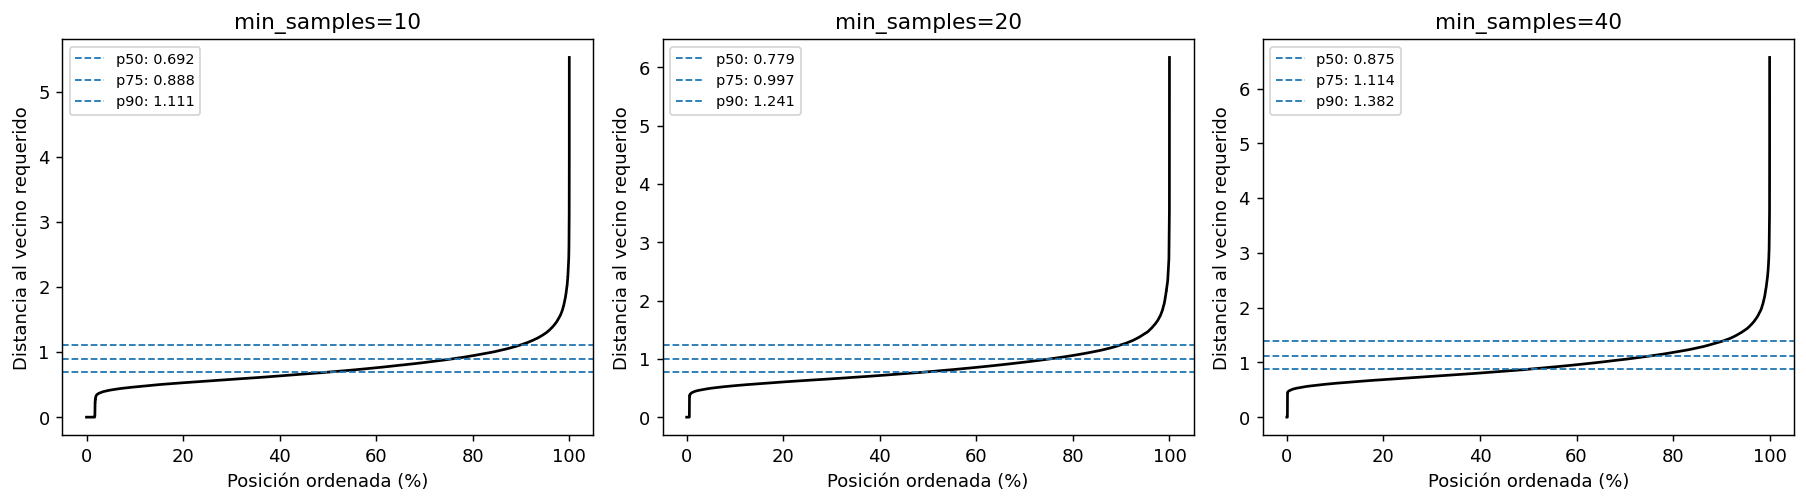

,min_samples,Percentil,eps
Configuración,,,
m=10;p=50,10,50,0.691691
m=10;p=75,10,75,0.887520
m=10;p=90,10,90,1.111311
m=20;p=50,20,50,0.778578
m=20;p=75,20,75,0.996561
m=20;p=90,20,90,1.241383
m=40;p=50,40,50,0.874625
m=40;p=75,40,75,1.113930
m=40;p=90,40,90,1.381904


In [86]:
from sklearn.neighbors import NearestNeighbors, BallTree
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt

min_samples_dbscan = [10, 20, 40]
percentiles_eps_dbscan = [50, 75, 90]
limite_relaciones_dbscan = 10_000_000
assert X_clustering_train_escalado.index.equals(etiquetas_k_playlists.index)
assert np.isfinite(X_clustering_train_escalado.to_numpy()).all()

vecinos_dbscan = NearestNeighbors(
    n_neighbors=max(min_samples_dbscan), metric="euclidean", algorithm="ball_tree", n_jobs=1
)
with threadpool_limits(limits=1):
    vecinos_dbscan.fit(X_clustering_train_escalado)
    distancias_vecinos_dbscan, _ = vecinos_dbscan.kneighbors(X_clustering_train_escalado)
arbol_dbscan = BallTree(X_clustering_train_escalado.to_numpy(), metric="euclidean")
filas_parametros_dbscan = []
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for eje, minimo in zip(ejes, min_samples_dbscan):
    distancia_requisito = distancias_vecinos_dbscan[:, minimo - 1]
    ordenadas = np.sort(distancia_requisito)
    eje.plot(np.linspace(0, 100, len(ordenadas)), ordenadas, color="black")
    for percentil in percentiles_eps_dbscan:
        radio = float(np.percentile(distancia_requisito, percentil))
        assert radio > 0, "El radio es cero: revisar duplicaciones antes de continuar."
        filas_parametros_dbscan.append({
            "Configuración": f"m={minimo};p={percentil}",
            "min_samples": minimo, "Percentil": percentil, "eps": radio,
        })
        eje.axhline(radio, linestyle="--", linewidth=1, label=f"p{percentil}: {radio:.3f}")
    eje.set(title=f"min_samples={minimo}", xlabel="Posición ordenada (%)", ylabel="Distancia al vecino requerido")
    eje.legend(fontsize=8)
fig.tight_layout()
plt.show()
parametros_dbscan_train = pd.DataFrame(filas_parametros_dbscan).set_index("Configuración")
display(parametros_dbscan_train)


**Código, paso a paso:** las importaciones incorporan búsqueda de vecinos, árbol de distancias, control de hilos y gráficos. Las listas declaran los requisitos y percentiles antes de obtener resultados de agrupamiento. Los `assert` verifican alineación y números finitos.

`NearestNeighbors` prepara una consulta de hasta 40 vecinos. `fit` guarda la estructura de búsqueda en entrenamiento: no ajusta otro predictor ni modifica los siete grupos. `kneighbors(X)` consulta las mismas filas explícitamente, contando un punto a distancia cero para la propia canción; si hay valores idénticos, también ocupan posiciones de distancia cero. No quitamos duplicados ni cambiamos pesos de entrenamiento para favorecer DBSCAN.

Para requisito m, la columna `m−1` contiene la distancia al m-ésimo punto de la lista, **incluyendo uno mismo**; por ejemplo, m=10 usa posición 9. `_` recibe los índices de vecinos que aquí no necesitamos. `BallTree` permitirá contar vecindades sin almacenar una matriz de distancias de todo entrenamiento.

`subplots` crea tres curvas. `zip` recorre simultáneamente ejes y requisitos. `sort` ordena distancias y `linspace` expresa posiciones entre 0 y 100; ese eje no muestra precisión. `percentile` obtiene cada radio y el `assert` impide usar radio cero. Guardamos sus valores completos, sin redondear el ajuste. `axhline` señala los radios y `legend` sus valores redondeados para lectura. La tabla deja visibles las nueve configuraciones.


In [87]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import pairwise_distances, silhouette_samples

muestra_dbscan_train = X_clustering_train_escalado.loc[ids_silhouette_train]
with threadpool_limits(limits=1):
    distancias_muestra_dbscan = pairwise_distances(muestra_dbscan_train, metric="euclidean", n_jobs=1)
np.fill_diagonal(distancias_muestra_dbscan, 0.0)
modelos_dbscan_train = {}
etiquetas_dbscan_train = {}
filas_resultados_dbscan = []
for configuracion, parametros in parametros_dbscan_train.iterrows():
    radio = float(parametros["eps"])
    minimo = int(parametros["min_samples"])
    relaciones = int(arbol_dbscan.query_radius(
        X_clustering_train_escalado.to_numpy(), r=radio, count_only=True
    ).sum())
    fila = {"Configuración": configuracion, "eps": radio, "min_samples": minimo,
            "Relaciones de vecindad": relaciones}
    if relaciones > limite_relaciones_dbscan:
        fila["Estado"] = "Omitido por costo; sin ajuste"
        filas_resultados_dbscan.append(fila)
        print(configuracion, fila["Estado"])
        continue
    modelo_db = DBSCAN(eps=radio, min_samples=minimo, metric="euclidean", algorithm="ball_tree", n_jobs=1)
    with threadpool_limits(limits=1):
        valores_db = modelo_db.fit_predict(X_clustering_train_escalado)
    etiquetas_db = pd.Series(valores_db, index=X_clustering_train_escalado.index, name="grupo_dbscan")
    asignadas = etiquetas_db.ne(-1)
    tamanos = etiquetas_db.loc[asignadas].value_counts()
    grupos_muestra = etiquetas_db.loc[ids_silhouette_train]
    mascara_muestra = grupos_muestra.ne(-1).to_numpy()
    muestra_asignada = grupos_muestra.loc[grupos_muestra.ne(-1)]
    grupos_ausentes = set(tamanos.index) - set(muestra_asignada.unique())
    sil_db = np.nan
    sil_k7_mismas = np.nan
    if 2 <= muestra_asignada.nunique() < len(muestra_asignada):
        matriz_asignadas = distancias_muestra_dbscan[np.ix_(mascara_muestra, mascara_muestra)]
        sil_db = float(silhouette_samples(matriz_asignadas, muestra_asignada, metric="precomputed").mean())
        k7_mismas = etiquetas_k_playlists.loc[muestra_asignada.index]
        if 2 <= k7_mismas.nunique() < len(k7_mismas):
            sil_k7_mismas = float(silhouette_samples(matriz_asignadas, k7_mismas, metric="precomputed").mean())
        del matriz_asignadas
    assert etiquetas_db.index.equals(X_clustering_train_escalado.index)
    assert etiquetas_db.notna().all()
    assert int(tamanos.sum()) + int((~asignadas).sum()) == len(etiquetas_db)
    fila.update({
        "Estado": "Ajustado", "Grupos sin ruido": len(tamanos),
        "Cobertura (%)": float(100 * asignadas.mean()), "Ruido (%)": float(100 * (~asignadas).mean()),
        "Núcleos (%)": float(100 * len(modelo_db.core_sample_indices_) / len(etiquetas_db)),
        "Grupo mayor (% asignadas)": float(100 * tamanos.max() / asignadas.sum()) if len(tamanos) else np.nan,
        "Grupo menor (canciones)": int(tamanos.min()) if len(tamanos) else 0,
        "N muestra asignada": len(muestra_asignada), "Grupos ausentes en muestra": len(grupos_ausentes),
        "Silhouette DBSCAN (asignadas muestra)": sil_db,
        "Silhouette K=7 (mismas filas de muestra)": sil_k7_mismas,
    })
    modelos_dbscan_train[configuracion] = modelo_db
    etiquetas_dbscan_train[configuracion] = etiquetas_db
    filas_resultados_dbscan.append(fila)
    print(f"{configuracion}: {len(tamanos)} grupos y {fila['Ruido (%)']:.2f}% de ruido.")
tabla_dbscan_train = pd.DataFrame(filas_resultados_dbscan).set_index("Configuración")
del distancias_muestra_dbscan
print("Resultados principales (silhouette solo sobre asignadas de la muestra):")
display(tabla_dbscan_train[[
    "eps", "min_samples", "Estado", "Grupos sin ruido", "Cobertura (%)", "Ruido (%)",
    "Grupo mayor (% asignadas)", "Silhouette DBSCAN (asignadas muestra)",
]].round(4))
print("Diagnósticos y comparación de K=7 sobre las mismas filas asignadas:")
display(tabla_dbscan_train[[
    "Relaciones de vecindad", "Núcleos (%)", "Grupo menor (canciones)",
    "N muestra asignada", "Grupos ausentes en muestra", "Silhouette K=7 (mismas filas de muestra)",
]].round(4))


m=10;p=50: 41 grupos y 34.62% de ruido.
m=10;p=75: 17 grupos y 13.28% de ruido.
m=10;p=90 Omitido por costo; sin ajuste
m=20;p=50: 8 grupos y 31.32% de ruido.
m=20;p=75 Omitido por costo; sin ajuste
m=20;p=90 Omitido por costo; sin ajuste
m=40;p=50: 7 grupos y 28.18% de ruido.
m=40;p=75 Omitido por costo; sin ajuste
m=40;p=90 Omitido por costo; sin ajuste


Resultados principales (silhouette solo sobre asignadas de la muestra):


,eps,min_samples,Estado,Grupos sin ruido,Cobertura (%),Ruido (%),Grupo mayor (% asignadas),Silhouette DBSCAN (asignadas muestra)
Configuración,,,,,,,,
m=10;p=50,0.6917,10,Ajustado,41.0,65.3775,34.6225,93.4960,-0.2375
m=10;p=75,0.8875,10,Ajustado,17.0,86.7207,13.2793,99.2203,-0.1396
m=10;p=90,1.1113,10,Omitido por costo; sin ajuste,NaN,NaN,NaN,NaN,NaN
m=20;p=50,0.7786,20,Ajustado,8.0,68.6775,31.3225,94.4540,0.0511
m=20;p=75,0.9966,20,Omitido por costo; sin ajuste,NaN,NaN,NaN,NaN,NaN
m=20;p=90,1.2414,20,Omitido por costo; sin ajuste,NaN,NaN,NaN,NaN,NaN
m=40;p=50,0.8746,40,Ajustado,7.0,71.8199,28.1801,94.2425,0.0847
m=40;p=75,1.1139,40,Omitido por costo; sin ajuste,NaN,NaN,NaN,NaN,NaN
m=40;p=90,1.3819,40,Omitido por costo; sin ajuste,NaN,NaN,NaN,NaN,NaN


Diagnósticos y comparación de K=7 sobre las mismas filas asignadas:


,Relaciones de vecindad,Núcleos (%),Grupo menor (canciones),N muestra asignada,Grupos ausentes en muestra,Silhouette K=7 (mismas filas de muestra)
Configuración,,,,,,
m=10;p=50,1894224,50.0014,4.0,3279.0,15.0,0.2390
m=10;p=75,7346160,75.0000,3.0,4302.0,5.0,0.2200
m=10;p=90,23794068,NaN,NaN,NaN,NaN,NaN
m=20;p=50,3614776,50.0000,16.0,3434.0,1.0,0.2355
m=20;p=75,13562232,NaN,NaN,NaN,NaN,NaN
m=20;p=90,41362174,NaN,NaN,NaN,NaN,NaN
m=40;p=50,6791588,50.0000,33.0,3574.0,0.0,0.2316
m=40;p=75,24081438,NaN,NaN,NaN,NaN,NaN
m=40;p=90,69405410,NaN,NaN,NaN,NaN,NaN


### 10.27. Cómo leer el ajuste y comparar sin ocultar ruido

1. Importamos DBSCAN y herramientas de silhouette. Usamos los mismos 5.000 IDs fijados para K-Means, no una muestra nueva elegida por resultado. Su matriz euclidiana ocupa aproximadamente 200 MB; al filtrar asignadas se crea otra matriz temporal. No calculamos distancias entre todas las parejas de las 71.728 canciones.
2. Cada vuelta toma radio y requisito desde la tabla. `query_radius(..., count_only=True)` cuenta vecinos, incluyendo uno mismo; la suma cuenta relaciones dirigidas, no parejas únicas. Si supera el límite operativo se registra la omisión y `continue` pasa al siguiente caso sin inventar métricas.
3. `DBSCAN(...).fit_predict` ajusta con todo entrenamiento. No hay parámetro K ni `random_state` de inicialización como en K-Means. Bajo el mismo orden y datos el ajuste es determinista; algunos bordes pueden depender del orden cuando son alcanzables desde varios grupos. Eso no equivale a estabilidad ante nuevos datos.
4. `ne(-1)` separa asignadas y ruido. No tratamos el ruido como un grupo adicional. `value_counts` calcula tamaños solo de grupos efectivos y la etiqueta `−1` se conserva en las tablas completas.
5. Seleccionamos la parte **asignada de la muestra fija**. La diferencia de conjuntos registra grupos del entrenamiento sin representación en esa muestra. Si faltan grupos, el score será descriptivo e incompleto; no se oculta ese aviso.
6. Silhouette solo es calculable si hay entre 2 y n−1 grupos presentes. `np.nan` indica no calculable, no cero. `np.ix_` recorta filas y columnas de la matriz a las mismas canciones y `metric="precomputed"` usa esas distancias. Excluimos ruido: DBSCAN no le asignó un grupo musical.
7. Calculamos también silhouette de K=7 **sobre esas mismas canciones muestreadas** con sus etiquetas originales. Es una comparación complementaria más pareja en filas, pero sigue condicionada por qué canciones retuvo DBSCAN; no sustituye cobertura ni equivale a refitar K-Means sin ruido.
8. Los `assert` comprueban IDs, etiquetas presentes y que asignadas más ruido cubren todo entrenamiento. `core_sample_indices_` identifica núcleos; asignadas restantes son bordes. La tabla informa núcleos, cobertura, ruido, tamaños y silhouette. `del` libera matrices grandes ya utilizadas.

**Denominadores:** cobertura y ruido se calculan sobre todo entrenamiento y suman 100%. El porcentaje del grupo mayor se calcula entre **asignadas**, para saber si casi todas las canciones que sí se agrupan caen en un solo grupo. No confundir esos dos porcentajes.

**Silhouette y cobertura juntos:** K-Means asigna el 100%; DBSCAN puede mejorar su promedio dejando fuera canciones difíciles. No compararemos su silhouette de asignadas con el de todo K-Means como si evaluaran las mismas canciones. Mostramos ambos alcances y el complemento en filas comunes. No inventamos inercia de DBSCAN: no optimiza distancias a centros ni dispone del mismo criterio que K-Means.


In [88]:
evaluables_dbscan = tabla_dbscan_train.loc[
    tabla_dbscan_train["Estado"].eq("Ajustado")
    & tabla_dbscan_train["Silhouette DBSCAN (asignadas muestra)"].notna()
].copy()
assert not evaluables_dbscan.empty, "Sin silhouette evaluable: revisar resultados, no elegir un ganador."
config_ilustrativa_dbscan = evaluables_dbscan.sort_values(
    ["Silhouette DBSCAN (asignadas muestra)", "Cobertura (%)"], ascending=[False, False], kind="stable"
).index[0]
etiquetas_db_ilustrativas = etiquetas_dbscan_train[config_ilustrativa_dbscan]
tamanos_db_ilustrativos = etiquetas_db_ilustrativas.loc[etiquetas_db_ilustrativas.ne(-1)].value_counts()
resumen_tamanos_db_ilustrativo = pd.DataFrame({
    "Canciones": tamanos_db_ilustrativos,
    "% entrenamiento": 100 * tamanos_db_ilustrativos / len(etiquetas_db_ilustrativas),
    "% asignadas": 100 * tamanos_db_ilustrativos / tamanos_db_ilustrativos.sum(),
})
print("Configuración ilustrativa de mayor silhouette evaluable:", config_ilustrativa_dbscan)
print("No se declara ganadora: revisar cobertura, tamaño dominante y muestra representada.")
print("Tamaños de los diez grupos mayores (el resto sigue en la tabla guardada):")
display(resumen_tamanos_db_ilustrativo.head(10).round(4))
print("Grupos adicionales no mostrados:", max(0, len(resumen_tamanos_db_ilustrativo) - 10))
print("Canciones de ruido:", int(etiquetas_db_ilustrativas.eq(-1).sum()))

mayores_db = tamanos_db_ilustrativos.head(5).index
perfiles_db_ilustrativos = X_clustering_train_imputado.loc[
    etiquetas_db_ilustrativas.isin(mayores_db)
].groupby(etiquetas_db_ilustrativas).mean().reindex(mayores_db)
print("Características medias de los cinco grupos mayores o de todos si hay menos:")
display(perfiles_db_ilustrativos.round(4))

comparacion_algoritmos_train = pd.DataFrame({
    "Grupos efectivos": [7, len(tamanos_db_ilustrativos)],
    "Cobertura (%)": [100.0, tabla_dbscan_train.loc[config_ilustrativa_dbscan, "Cobertura (%)"]],
    "Ruido (%)": [0.0, tabla_dbscan_train.loc[config_ilustrativa_dbscan, "Ruido (%)"]],
    "Grupo mayor (% asignadas)": [100 * etiquetas_k_playlists.value_counts().max() / len(etiquetas_k_playlists), tabla_dbscan_train.loc[config_ilustrativa_dbscan, "Grupo mayor (% asignadas)"]],
    "Silhouette muestra: todo K=7 / asignadas DBSCAN": [tabla_comparacion_k.loc[7, "Silhouette muestra"], tabla_dbscan_train.loc[config_ilustrativa_dbscan, "Silhouette DBSCAN (asignadas muestra)"]],
    "Silhouette en las mismas filas asignadas de muestra": [tabla_dbscan_train.loc[config_ilustrativa_dbscan, "Silhouette K=7 (mismas filas de muestra)"], tabla_dbscan_train.loc[config_ilustrativa_dbscan, "Silhouette DBSCAN (asignadas muestra)"]],
}, index=["K-Means K=7", f"DBSCAN {config_ilustrativa_dbscan}"])
display(comparacion_algoritmos_train.round(4))


Configuración ilustrativa de mayor silhouette evaluable: m=40;p=50
No se declara ganadora: revisar cobertura, tamaño dominante y muestra representada.
Tamaños de los diez grupos mayores (el resto sigue en la tabla guardada):
Grupos adicionales no mostrados: 0
Canciones de ruido: 20213
Características medias de los cinco grupos mayores o de todos si hay menos:


,Canciones,% entrenamiento,% asignadas
grupo_dbscan,,,
0,48549,67.6849,94.2425
1,2613,3.6429,5.0723
2,121,0.1687,0.2349
3,106,0.1478,0.2058
4,53,0.0739,0.1029
6,40,0.0558,0.0776
5,33,0.0460,0.0641


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
grupo_dbscan,,,,,,,,,
0,0.5872,0.6739,-7.1371,0.0613,0.2696,0.0795,0.1663,0.4967,122.6702
1,0.3340,0.1177,-22.4181,0.0440,0.9410,0.8916,0.1112,0.1448,98.9291
2,0.5932,0.7532,-7.1866,0.0465,0.2430,0.0002,0.8031,0.6362,127.1190
3,0.5143,0.9139,-5.4107,0.0678,0.0468,0.0124,0.9248,0.4303,133.3866
4,0.5442,0.7147,-6.7761,0.0464,0.6619,0.0006,0.9454,0.6388,146.5646


,Grupos efectivos,Cobertura (%),Ruido (%),Grupo mayor (% asignadas),Silhouette muestra: todo K=7 / asignadas DBSCAN,Silhouette en las mismas filas asignadas de muestra
K-Means K=7,7,100.0000,0.0000,30.5362,0.1959,0.2316
DBSCAN m=40;p=50,7,71.8199,28.1801,94.2425,0.0847,0.0847


### 10.28. Interpretación de la comparación

**Código:** filtramos configuraciones ajustadas y con silhouette calculable. Si ninguna sirve para ese cálculo, detenemos la elección ilustrativa y revisamos la tabla; no asignamos un score falso. Ordenamos por mayor silhouette de asignadas y, ante empate, mayor cobertura. Elegimos así un **caso ilustrativo**, no un ganador automático: esta regla no considera toda la utilidad para playlists.

`value_counts` ordena grupos de mayor a menor tamaño; calculamos sus porcentajes sobre entrenamiento completo y sobre asignadas. Mostramos diez grupos mayores y el número adicional para evitar tablas inmanejables, conservando el resumen completo en memoria. La máscara `isin` selecciona hasta cinco grupos mayores para describir sus promedios originales. El ruido queda contabilizado, sin nombrarlo como si fuera otro estilo.

La tabla final enfrenta K=7 con ese caso e informa dos lecturas de silhouette: sus alcances originales (diferentes) y la evaluación sobre las mismas filas muestreadas asignadas por DBSCAN. Una propuesta con muchísimos grupos diminutos, mucho ruido o un grupo dominante puede ser poco útil para organizar playlists, aunque encuentre alguna zona densa. No exigimos que DBSCAN produzca siete grupos para considerarlo válido.

**Limitaciones:** no exploramos todos los radios ni densidades posibles, y no comprobamos estabilidad de DBSCAN ante remuestreo o cambios de orden. Repetirlo con la misma entrada no aporta la evidencia de estabilidad que sí exploramos con inicializaciones de K-Means. Las reediciones con IDs distintos siguen contando como observaciones; múltiples canciones con audio idéntico pueden aumentar densidades. No se deduplicó entrenamiento para este experimento, para mantener comparable la base; sería una sensibilidad futura que debe documentarse, no una limpieza retrospectiva automática.

No usamos el ruido para borrar canciones ni lo interpretamos como fraude o mala calidad. Una muestra puede no representar todos los grupos; ese conteo acompaña al silhouette. Para playlists necesitamos perfiles musicales revisables y cobertura adecuada al uso, además de métricas internas. No se afirma utilidad con oyentes ni disponibilidad actual del catálogo.

Fuentes: [DBSCAN, scikit-learn 1.6](https://scikit-learn.org/1.6/modules/generated/sklearn.cluster.DBSCAN.html) y [silhouette](https://scikit-learn.org/1.6/modules/generated/sklearn.metrics.silhouette_samples.html). La regla de radios, el rango y el límite de costo son decisiones explícitas de este cuaderno, no exigencias atribuidas al profesor.


### 10.29. Resultados reales de DBSCAN en entrenamiento

**Se definieron nueve configuraciones y se ajustaron cuatro.** Cinco se omitieron por superar diez millones de relaciones de vecindad. Sus métricas aparecen como `NaN` porque **no fueron calculadas**: no significa cero grupos ni incumplimiento de calidad. Por tanto, las conclusiones se limitan a los cuatro ajustes realizados.

| min_samples | eps aproximado | Grupos efectivos | Ruido | Mayor grupo entre asignadas | Silhouette de asignadas muestreadas |
|---:|---:|---:|---:|---:|---:|
| 10 | 0,6917 | 41 | 34,62% | 93,50% | −0,2375 |
| 10 | 0,8875 | 17 | 13,28% | 99,22% | −0,1396 |
| 20 | 0,7786 | 8 | 31,32% | 94,45% | 0,0511 |
| 40 | 0,8746 | 7 | 28,18% | 94,24% | 0,0847 |

Los radios de la tabla están redondeados para leerlos; los ajustes utilizaron los valores completos. Cada radio procede del percentil correspondiente a su requisito, por lo que al comparar filas pueden cambiar **los dos parámetros**. No atribuimos diferencias exclusivamente a `min_samples`.

**Primera lección:** más grupos efectivos no implica más perfiles útiles. Con 41 grupos, casi todas las canciones asignadas están en uno y los restantes contienen pocas observaciones; el silhouette promedio negativo sugiere separación poco adecuada en la muestra y distancia utilizadas. En ese caso, 15 grupos del entrenamiento no aparecieron en la muestra de asignadas; en la configuración de 17 grupos faltaron cinco, y en la de ocho faltó uno. Los scores de esos casos no describen todos sus grupos.

**Segunda lección:** aumentar el radio puede incorporar canciones, pero también unir zonas mediante cadenas de vecinos. Con requisito 10, pasar de radio 0,6917 a 0,8875 reduce el ruido de 34,62% a 13,28%, mientras el mayor grupo pasa de 93,50% a 99,22% de las asignadas. Se cubre más catálogo a costa de concentrarlo casi todo en una sola colección.

**Tercera lección:** no declaramos canciones «incorrectas». Ruido significa falta de pertenencia a grupos densos bajo ese ajuste. Puede incluir canciones válidas de perfiles poco frecuentes; no se usa como regla automática de limpieza o de exclusión de futuras sugerencias.

### 10.30. Caso ilustrativo: eps≈0,8746 y min_samples=40

Es el mayor silhouette calculable entre los ajustes realizados (**0,0847**) y sus siete grupos estuvieron representados en la muestra. Lo usamos para explicar el resultado con claridad, **sin declararlo la configuración óptima de DBSCAN**.

- **Asignadas:** 51.515 canciones, **71,82%** del entrenamiento.
- **Ruido:** 20.213 canciones, **28,18%**.
- **Mayor grupo:** 48.549 canciones: **94,24% de las asignadas** y **67,68% de todo entrenamiento**. Los denominadores explican la diferencia entre esos porcentajes.
- **Segundo grupo:** 2.613 canciones; su promedio es muy acústico e instrumental, con baja energía: acústica 0,941, instrumentalidad 0,892 y energía 0,118.
- **Otros cinco grupos:** 121, 106, 53, 40 y 33 canciones. En conjunto son 353, aproximadamente 0,49% del entrenamiento.

El mayor grupo tiene energía media 0,674 y tempo 122,67 BPM, pero reúne casi 49.000 canciones; ese promedio no demuestra que constituyan una playlist homogénea. El segundo encuentra una zona más específica. Algunos pequeños grupos tienen índice `liveness` alto: eso es una descripción del audio, no prueba de conciertos ni un género nuevo.

**Por qué siete grupos aquí no equivalen a K-Means de siete grupos:** DBSCAN no fue obligado a producir siete; surgieron de sus parámetros. En este resultado hay un gran grupo dominante, otro menor y cinco muy pequeños, además de ruido. La igualdad del número de etiquetas no implica igualdad de perfiles, fronteras o utilidad para playlists. `min_samples` define núcleos y no debe leerse como un tamaño mínimo garantizado de cada grupo final cuando hay asignaciones de borde compartidas.

### 10.31. Comparación con K-Means y decisión para playlists

| Aspecto | K-Means K=7 | DBSCAN del caso ilustrativo |
|---|---:|---:|
| Grupos efectivos | 7 | 7 |
| Cobertura del entrenamiento | 100% | 71,82% |
| Canciones consideradas ruido | 0 | 20.213 |
| Mayor grupo entre asignadas | 30,54% | 94,24% |
| Silhouette en las mismas 3.574 canciones de la muestra retenidas por DBSCAN | 0,2316 | 0,0847 |

El silhouette previo de K-Means sobre las 5.000 canciones era **0,1959**. El **0,2316** corresponde a una selección diferente: solo las 3.574 de esa muestra que DBSCAN asignó. No significa que se haya mejorado o reentrenado K-Means. Mostramos esta lectura en filas comunes junto con cobertura para no ocultar que DBSCAN evalúa un subconjunto.

**Mantenemos K-Means K=7 como base actual para explorar playlists.** En los ajustes realizados ofrece más cobertura, perfiles de tamaños menos concentrados y mejor silhouette en las mismas filas muestreadas del caso ilustrativo. Además, sus perfiles y sensibilidad a inicialización ya se revisaron en apartados anteriores. No afirmamos que su estabilidad sea superior a la de DBSCAN: no realizamos una prueba comparable de estabilidad para este último.

DBSCAN sí aporta información: muestra una zona acústica e instrumental densa y señala canciones que no encajan en sus vecindades. Sin embargo, los ajustes probados no ofrecen una organización del catálogo tan útil para nuestro objetivo de varios perfiles revisables. No descartamos DBSCAN universalmente ni concluimos que no existan agrupaciones densas: faltan configuraciones omitidas por costo, otros radios y revisión de sensibilidad.

El comportamiento es compatible con densidades desiguales y conexiones entre zonas de audio. No demuestra por sí solo que toda la música forme un continuo o que el algoritmo nunca sirva para canciones. Las entradas, correlaciones, extremos y versiones repetidas también influyen en estas distancias y densidades.

**Límites y futuro:** si se ampliara la exploración, habría que documentar nuevos parámetros y recursos, sin escoger retrospectivamente los que más se parezcan a siete grupos. Para recomendaciones, el ruido podría necesitar una búsqueda por similitud alternativa, pero no se ha implementado aquí. DBSCAN no ofrece un método `predict` nativo como K-Means; una regla para nuevas canciones sería un diseño adicional que requeriría explicación y evaluación. Seguimos usando solo entrenamiento, sin nuevas recomendaciones externas, cambios de CSV ni evaluación de satisfacción de oyentes.


In [89]:
# Decisión argumentada con cobertura, perfiles y separación; no se cambia K-Means.
algoritmo_actual_playlists = "K-Means"
decision_dbscan_playlists = pd.DataFrame([
    ["Configuraciones previstas", len(parametros_dbscan_train)],
    ["Configuraciones ajustadas", int(tabla_dbscan_train["Estado"].eq("Ajustado").sum())],
    ["Omitidas por costo", int(tabla_dbscan_train["Estado"].ne("Ajustado").sum())],
    ["Base actual para playlists", "K-Means, siete grupos"],
    ["Alcance", "Solo entrenamiento; exploración limitada de DBSCAN"],
], columns=["Control o decisión", "Resultado"])
assert etiquetas_k_playlists.nunique() == 7
assert all(serie.index.equals(etiquetas_k_playlists.index) for serie in etiquetas_dbscan_train.values())
display(decision_dbscan_playlists)


,Control o decisión,Resultado
0,Configuraciones previstas,9
1,Configuraciones ajustadas,4
2,Omitidas por costo,5
3,Base actual para playlists,"K-Means, siete grupos"
4,Alcance,Solo entrenamiento; exploración limitada de DBSCAN


**Lectura del cierre:** contamos estados realmente registrados, declaramos la decisión y comprobamos que K-Means conserva sus siete etiquetas y que los resultados DBSCAN corresponden a los mismos IDs. No se reentrena ni se sustituyen las sugerencias anteriores; la tabla documenta el alcance sin convertir una omisión por costo en un resultado negativo de calidad.


### 10.32. PCA: un mapa común para visualizar los agrupamientos

**Objetivo:** representar las canciones en dos ejes para observar las asignaciones ya obtenidas por K-Means K=7 y por DBSCAN del caso ilustrativo. Ambos gráficos usarán **el mismo PCA**, aprendido con las mismas 71.728 canciones de entrenamiento y sus nueve entradas imputadas y estandarizadas. No consultamos test ni popularidad, artista o géneros.

**PCA (análisis de componentes principales)** construye ejes que son combinaciones lineales de las características. El primer componente recoge la mayor variación posible en una dirección; el segundo recoge la mayor variación restante en una dirección perpendicular al primero. Es una proyección para resumir diferencias de audio, no un clasificador ni otro algoritmo de agrupamiento.

**No reagrupamos en dos dimensiones.** Las etiquetas, distancias, métricas y sugerencias anteriores siguen basadas en las nueve entradas. PCA se ajusta después para visualizar. Una aparente mezcla en el plano puede esconder diferencias en los otros componentes; una separación visible tampoco demuestra utilidad para playlists.

Ajustaremos los nueve componentes para medir cómo se distribuye la variación, pero dibujaremos únicamente los dos primeros. Para que el gráfico sea legible, mostraremos los mismos **5.000 IDs de entrenamiento** fijados previamente; PCA se aprende con todo entrenamiento, no solo con esa muestra. El ruido de DBSCAN se conserva en el ajuste y en el mapa.


In [90]:
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits

assert X_clustering_train_escalado.index.equals(etiquetas_k_playlists.index)
assert X_clustering_train_escalado.index.equals(etiquetas_db_ilustrativas.index)
assert np.isfinite(X_clustering_train_escalado.to_numpy()).all()
pca_visualizacion_train = PCA(n_components=len(variables_clustering), svd_solver="full")
with threadpool_limits(limits=1):
    coordenadas_pca_completas = pca_visualizacion_train.fit_transform(X_clustering_train_escalado)
coordenadas_pca_train = pd.DataFrame(
    coordenadas_pca_completas,
    index=X_clustering_train_escalado.index,
    columns=[f"PC{i + 1}" for i in range(len(variables_clustering))],
)
varianza_pca_train = pd.DataFrame({
    "Varianza del componente": pca_visualizacion_train.explained_variance_,
    "Varianza explicada (%)": 100 * pca_visualizacion_train.explained_variance_ratio_,
}, index=coordenadas_pca_train.columns)
varianza_pca_train["Varianza acumulada (%)"] = varianza_pca_train["Varianza explicada (%)"].cumsum()
porcentaje_plano_pca = float(varianza_pca_train.loc[["PC1", "PC2"], "Varianza explicada (%)"].sum())
componentes_80_pca = int(np.searchsorted(varianza_pca_train["Varianza acumulada (%)"].to_numpy(), 80) + 1)
componentes_90_pca = int(np.searchsorted(varianza_pca_train["Varianza acumulada (%)"].to_numpy(), 90) + 1)
assert coordenadas_pca_train.index.equals(X_clustering_train_escalado.index)
assert int(pca_visualizacion_train.n_samples_) == len(X_clustering_train_escalado)
assert np.isfinite(coordenadas_pca_train.to_numpy()).all()
np.testing.assert_allclose(varianza_pca_train["Varianza explicada (%)"].sum(), 100, atol=1e-8)
print(f"Dos ejes conservan {porcentaje_plano_pca:.2f}% de la varianza de estas nueve entradas.")
print(f"Para alcanzar al menos 80%: {componentes_80_pca}; al menos 90%: {componentes_90_pca} componentes.")
display(varianza_pca_train.round(4))


Dos ejes conservan 47.98% de la varianza de estas nueve entradas.
Para alcanzar al menos 80%: 5; al menos 90%: 7 componentes.


,Varianza del componente,Varianza explicada (%),Varianza acumulada (%)
PC1,2.8724,31.9147,31.9147
PC2,1.4457,16.0636,47.9783
PC3,1.2481,13.8678,61.8461
PC4,0.9083,10.0920,71.9380
PC5,0.8645,9.6055,81.5435
PC6,0.7355,8.1726,89.7161
PC7,0.4555,5.0609,94.7771
PC8,0.3294,3.6601,98.4371
PC9,0.1407,1.5629,100.0000


**Lectura del código:**

1. Importamos PCA y el control de hilos. Los `assert` exigen alineación con ambos agrupamientos y ausencia de valores no finitos.
2. `PCA(n_components=9, svd_solver="full")` obtiene los nueve ejes con una descomposición completa. No elegimos nueve grupos ni pedimos al algoritmo que use las etiquetas. El número se toma de la lista de entradas. Bajo esta configuración no necesitamos una semilla de inicialización.
3. `fit_transform` aprende los ejes y proyecta **solo entrenamiento**. PCA centra sus entradas; no sustituye el escalamiento previo ni recibe las columnas originales sin preparar. No aprende a separar los colores de los grupos.
4. `pd.DataFrame` recupera IDs y nombra PC1 a PC9. `explained_variance_` mide la variación de las coordenadas sobre cada eje, con el convenio de varianza de muestra; no es una precisión. `explained_variance_ratio_` divide por la variación total de las nueve entradas y multiplicamos por 100 para mostrar porcentajes.
5. `cumsum()` suma los porcentajes en orden: «acumulada» de PC2 significa PC1 más PC2. `porcentaje_plano_pca` cuantifica cuánto recoge el mapa, no cuánto explica causalmente de popularidad.
6. `searchsorted` encuentra el primer punto que alcanza 80% o 90%; sumamos uno porque las posiciones empiezan en cero. Son referencias descriptivas de compresión, no KPI fijados por el profesor ni requisitos para aprobar este mapa. No cambiamos la dimensión de los modelos anteriores.
7. Las comprobaciones verifican IDs, filas usadas, coordenadas finitas y suma de porcentajes cercana a 100 al conservar todos los componentes. No verifican calidad de playlists. `round` redondea únicamente la presentación.

**Qué significa varianza explicada:** es la proporción de variación de estas características estandarizadas recogida por los ejes. No es porcentaje de canciones bien agrupadas, de satisfacción, de precisión ni de importancia de cada género. La parte no dibujada permanece en los otros componentes; podría contener diferencias musicales útiles. Correlaciones como energía y sonoridad pueden resumirse en direcciones comunes, sin demostrar causalidad.


Pesos que combinan las nueve entradas estandarizadas en los dos ejes:


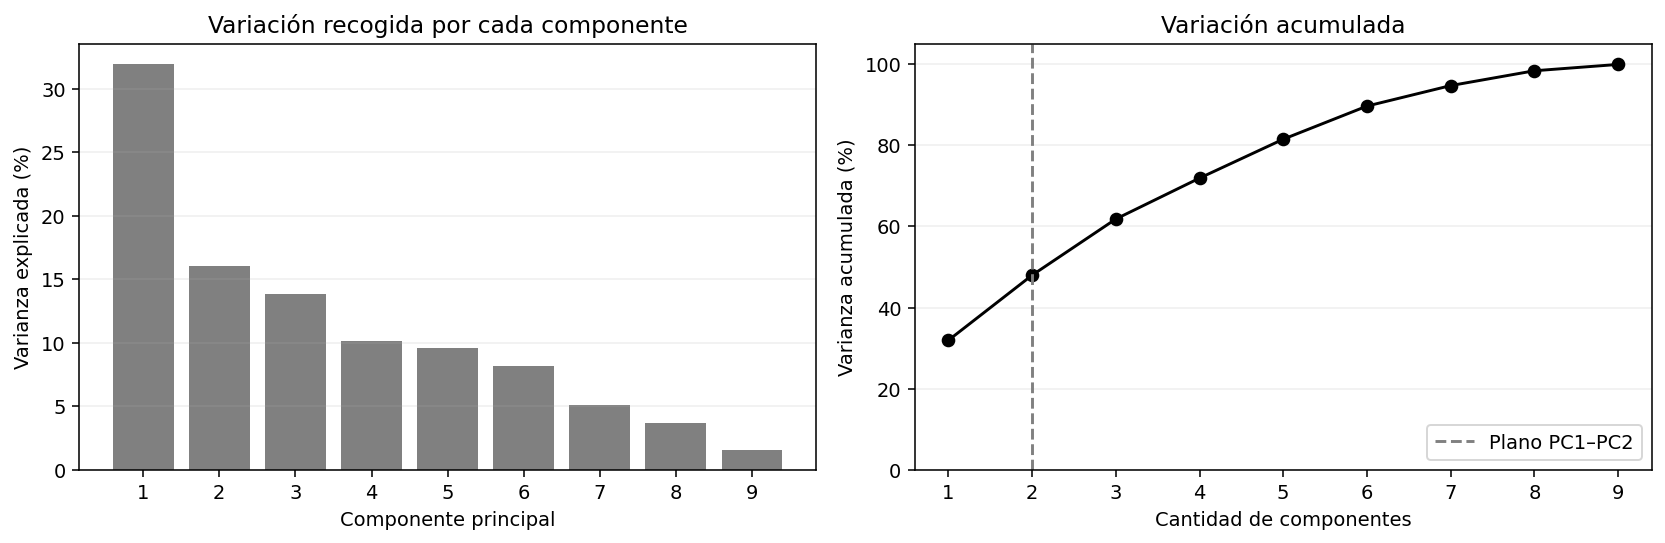

,Peso PC1,Peso PC2
danceability,0.2573,0.5596
energy,0.5071,-0.2816
loudness,0.5162,-0.0768
speechiness,0.0986,0.0361
acousticness,-0.4340,0.3130
instrumentalness,-0.2839,-0.3122
liveness,0.0860,-0.2246
valence,0.2986,0.5205
tempo,0.1868,-0.2890


In [91]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
posiciones_pca = np.arange(1, len(varianza_pca_train) + 1)
ejes[0].bar(posiciones_pca, varianza_pca_train["Varianza explicada (%)"], color="gray")
ejes[0].set(title="Variación recogida por cada componente", xlabel="Componente principal", ylabel="Varianza explicada (%)")
ejes[1].plot(posiciones_pca, varianza_pca_train["Varianza acumulada (%)"], marker="o", color="black")
ejes[1].axvline(2, color="gray", linestyle="--", label="Plano PC1–PC2")
ejes[1].set(title="Variación acumulada", xlabel="Cantidad de componentes", ylabel="Varianza acumulada (%)", ylim=(0, 105))
ejes[1].legend()
for eje in ejes:
    eje.set_xticks(posiciones_pca)
    eje.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

pesos_pca_train = pd.DataFrame(
    pca_visualizacion_train.components_[:2].T,
    index=variables_clustering, columns=["Peso PC1", "Peso PC2"],
)
print("Pesos que combinan las nueve entradas estandarizadas en los dos ejes:")
display(pesos_pca_train.round(4))


### 10.33. Cómo leer la varianza y los pesos

`subplots` crea dos gráficos. `arange` genera posiciones 1 a 9; `bar` muestra cuánto aporta cada componente **por separado** y `plot` cuánto se acumula. La línea vertical señala dos componentes, los que se usarán para el mapa. Títulos, marcas y cuadrícula facilitan la lectura; `tight_layout` ajusta espacios y `show` muestra el resultado. Una caída gradual de aportes no significa que exista un único número obligatorio de componentes.

`components_[:2]` recupera los dos primeros ejes; `.T` coloca una fila por entrada. Los **pesos** describen cómo se combinan las entradas estandarizadas: cada coordenada es una suma ponderada de esas entradas centradas. Un peso absoluto mayor significa mayor participación en esa dirección; no es importancia predictiva ni un porcentaje. El peso depende también de correlaciones entre variables.

El signo indica dirección dentro del eje: entradas con el mismo signo contribuyen en el mismo sentido y con signos opuestos en sentidos contrarios. El signo completo de un componente puede invertirse sin cambiar el mapa ni sus distancias; positivo no equivale a música mejor. PC1 y PC2 no se deben nombrar «popularidad» o «calidad». Sus nombres descriptivos se justifican con los pesos observados y sus límites.


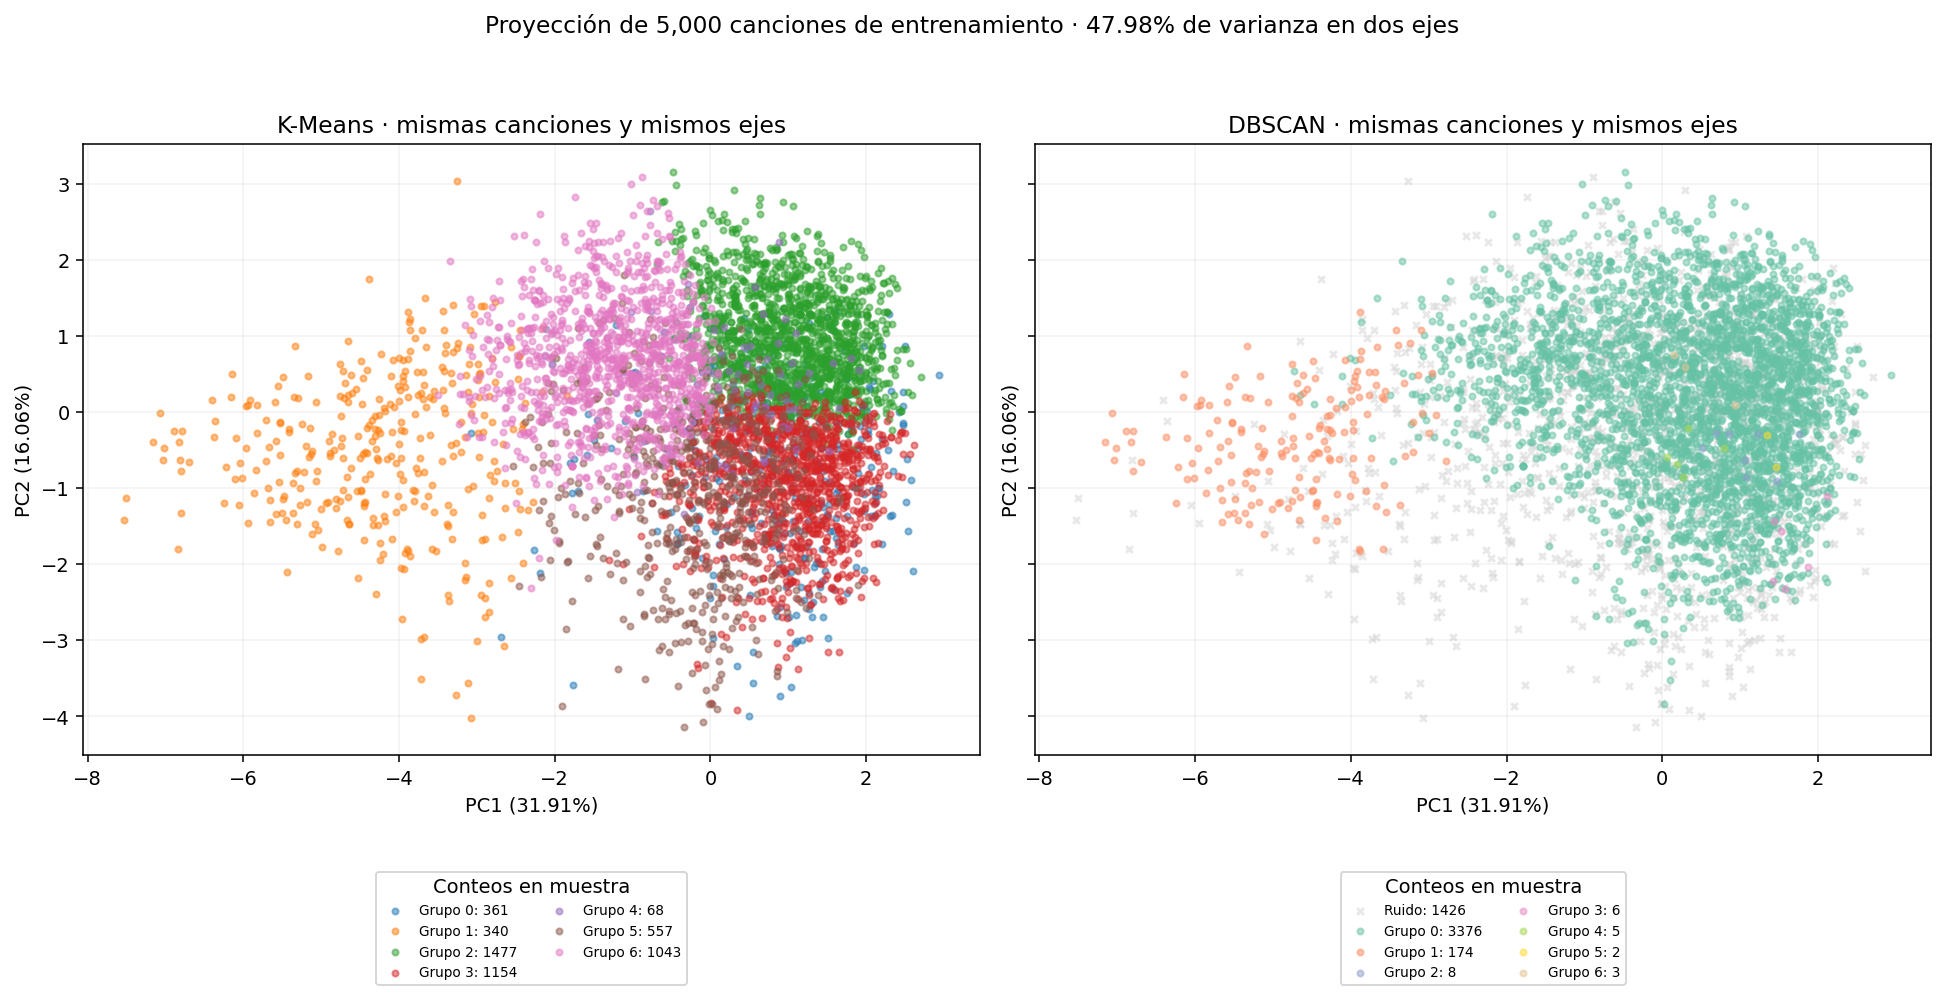

,Canciones dibujadas,Grupos representados sin ruido,Ruido en muestra
K-Means K=7,5000,7,0
DBSCAN m=40;p=50,5000,7,1426


In [92]:
mapa_pca_muestra = coordenadas_pca_train.loc[ids_silhouette_train, ["PC1", "PC2"]].copy()
mapa_pca_muestra["K-Means"] = etiquetas_k_playlists.loc[ids_silhouette_train]
mapa_pca_muestra["DBSCAN"] = etiquetas_db_ilustrativas.loc[ids_silhouette_train]
assert mapa_pca_muestra.index.isin(X_clustering_train_escalado.index).all()
assert len(mapa_pca_muestra) == len(ids_silhouette_train)
assert mapa_pca_muestra.notna().all().all()

fig, ejes = plt.subplots(1, 2, figsize=(14, 7.5), sharex=True, sharey=True)
paletas_pca = [plt.get_cmap("tab10"), plt.get_cmap("Set2")]
for eje, columna, paleta in zip(ejes, ["K-Means", "DBSCAN"], paletas_pca):
    ruido = mapa_pca_muestra[columna].eq(-1)
    if ruido.any():
        eje.scatter(mapa_pca_muestra.loc[ruido, "PC1"], mapa_pca_muestra.loc[ruido, "PC2"],
                    color="lightgray", marker="x", s=12, alpha=0.5, label=f"Ruido: {int(ruido.sum())}")
    grupos = sorted(mapa_pca_muestra.loc[~ruido, columna].unique())
    for posicion, grupo in enumerate(grupos):
        pertenece = mapa_pca_muestra[columna].eq(grupo)
        eje.scatter(mapa_pca_muestra.loc[pertenece, "PC1"], mapa_pca_muestra.loc[pertenece, "PC2"],
                    color=paleta(posicion % paleta.N), s=10, alpha=0.5,
                    label=f"Grupo {int(grupo)}: {int(pertenece.sum())}")
    eje.set_title(f"{columna} · mismas canciones y mismos ejes")
    eje.set_xlabel(f"PC1 ({varianza_pca_train.loc['PC1', 'Varianza explicada (%)']:.2f}%)")
    eje.set_ylabel(f"PC2 ({varianza_pca_train.loc['PC2', 'Varianza explicada (%)']:.2f}%)")
    eje.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, title="Conteos en muestra")
    eje.grid(alpha=0.15)
fig.suptitle(f"Proyección de {len(mapa_pca_muestra):,} canciones de entrenamiento · {porcentaje_plano_pca:.2f}% de varianza en dos ejes")
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

resumen_mapa_pca = pd.DataFrame({
    "Canciones dibujadas": [len(mapa_pca_muestra), len(mapa_pca_muestra)],
    "Grupos representados sin ruido": [mapa_pca_muestra["K-Means"].nunique(), mapa_pca_muestra.loc[mapa_pca_muestra["DBSCAN"].ne(-1), "DBSCAN"].nunique()],
    "Ruido en muestra": [0, int(mapa_pca_muestra["DBSCAN"].eq(-1).sum())],
}, index=["K-Means K=7", f"DBSCAN {config_ilustrativa_dbscan}"])
display(resumen_mapa_pca)


### 10.34. Cómo interpretar los mapas sin confundir proyección y agrupamiento

**Código:** seleccionamos exactamente los mismos IDs y PC1–PC2 para ambos mapas y agregamos las etiquetas ya calculadas. Las comprobaciones exigen pertenencia a entrenamiento, cantidad esperada y ausencia de datos faltantes. `sharex` y `sharey` usan escalas comunes para que la comparación no dependa de zooms distintos.

Las paletas son distintas para recordar que **el grupo 0 de K-Means no equivale al grupo 0 de DBSCAN**. Primero dibujamos el ruido en gris con cruces y luego los grupos; la transparencia reduce saturación, pero algunos puntos quedan ocultos por superposición. Las leyendas cuentan canciones **de la muestra**, no del entrenamiento completo. `scatter` coloca una canción por punto; títulos y ejes informan el porcentaje de varianza recogida.

**Lectura:**

- La posición es una combinación de rasgos de audio, no un ranking. Estar a la derecha o arriba no significa más popularidad o mejor canción.
- Los colores son asignaciones obtenidas en nueve dimensiones, no nuevos grupos detectados en el dibujo. No se debe cambiar el K o los radios para que los colores se vean más separados en este plano.
- Canciones alejadas en este plano también tienen diferencias en el espacio original estandarizado; canciones superpuestas podrían diferir en componentes no dibujados. La proyección reduce distancias y puede ocultar separación. Tampoco demuestra por sí sola compatibilidad para playlists.
- Ruido de DBSCAN puede caer cerca de puntos asignados en el dibujo: su densidad se evaluó en nueve dimensiones, no en la imagen. Los puntos grises permanecen en el dataset y no son necesariamente errores o canciones malas.
- No se identifican géneros o emociones por formas visuales. Un mapa que parezca formar islas no prueba géneros reales, y uno mezclado no invalida automáticamente el agrupamiento.

**Uso correcto:** complementar perfiles, tamaños, cobertura y silhouette ya calculados. No reemplazar sus métricas por distancias de dos componentes ni afirmar éxito con oyentes a partir de los colores. PCA no aporta una evaluación independiente: utiliza el mismo entrenamiento ya explorado.


### 10.35. Resultados reales y lectura del mapa

| Componente o conjunto | Varianza explicada |
|---|---:|
| PC1 | 31,91% |
| PC2, aporte adicional | 16,06% |
| PC1 + PC2: plano dibujado | **47,98%** |
| Primeros cinco componentes | 81,54% |
| Primeros siete componentes | 94,78% |

**Cómo interpretar esos porcentajes:** el plano PC1–PC2 recoge 47,98% de la variación de las nueve entradas estandarizadas; el **52,02% restante no se dibuja**. No significa que 47,98% de las canciones estén bien agrupadas ni que hayamos eliminado 52,02% de las canciones. Las 71.728 filas se mantienen en PCA y 5.000 se muestran por legibilidad. La pérdida es de representación de variación en el plano, no una nueva limpieza del catálogo.

Para alcanzar al menos 80% se necesitan **cinco** componentes. Con seis se alcanza **89,72%**, todavía por debajo de 90%; hacen falta **siete** para superar ese nivel, con 94,78%. Estos valores describen la compresión; no justifican cambiar los agrupamientos originales a cinco o siete dimensiones sin otro experimento. Elegir dos ejes responde aquí a la posibilidad de dibujar un mapa sencillo, no a que sean suficientes para representar toda la estructura.

#### Qué significan los ejes según sus pesos

**PC1:** sus pesos más destacados son sonoridad **+0,5162**, energía **+0,5071** y acústica **−0,4340**, con otras aportaciones. En la orientación mostrada, desplazarse hacia valores mayores suele asociarse a la combinación de mayor energía y sonoridad y menor carácter acústico. No es un medidor puro de energía: depende de las nueve entradas y sus relaciones. Un peso positivo de sonoridad significa mayor sonoridad relativa, no convertir decibelios en positivos.

**PC2:** destacan bailabilidad **+0,5596** y valencia **+0,5205**; también participan acústica **+0,3130**, instrumentalidad **−0,3122**, tempo **−0,2890** y energía **−0,2816**. Por eso no lo nombramos simplemente «alegría» o «bailabilidad». Resume una combinación y no demuestra emociones de oyentes. Si se invirtiera el signo de todo un eje, los colores se reflejarían sin cambiar las relaciones del mapa.

#### Qué observamos en K-Means K=7

Se dibujan los siete grupos y sus colores se solapan parcialmente. El grupo 1, previamente descrito como acústico e instrumental de baja energía y sonoridad, ocupa en gran parte posiciones negativas de PC1, coherentes con sus características. El grupo 2 aparece en buena parte hacia valores mayores de PC2, compatible con su mayor bailabilidad y valencia.

No todos los perfiles forman islas separadas en este mapa. Los colores se asignaron usando nueve dimensiones y solo vemos dos; además, ya observamos separación promedio limitada mediante silhouette. No atribuimos todo el solapamiento exclusivamente a PCA ni declaramos que el dibujo invalide los siete perfiles. Se interpreta junto con las características y métricas anteriores.

#### Qué observamos en DBSCAN

La misma muestra contiene **3.574 canciones asignadas y 1.426 de ruido**. Su grupo 0 reúne **3.376 de las dibujadas**, el grupo 1 tiene **174** y los otros cinco aparecen con 8, 6, 5, 2 y 3 puntos, respectivamente. Son conteos de la muestra; los tamaños completos siguen en la tabla de DBSCAN.

El color del grupo dominante ocupa una parte amplia del plano y el segundo grupo se concentra principalmente hacia PC1 negativo. Los grupos pequeños son difíciles de distinguir por la cantidad de puntos y la superposición. Las cruces grises de ruido pueden estar junto a puntos asignados: faltan dimensiones para juzgar sus vecindades y DBSCAN decidió densidad en el espacio original, no según el color visible.

Los **1.426/5.000 = 28,52%** de ruido del mapa corresponden a la muestra. El **28,18%** informado antes corresponde a todo entrenamiento; la diferencia de denominadores y muestreo explica que no sean exactamente iguales. No se cambiaron parámetros o etiquetas entre las tablas y el gráfico.

#### Qué aporta PCA a la decisión y a las playlists

PCA ayuda a comunicar cómo se distribuyen las canciones y por qué ambos algoritmos organizan el mismo catálogo de forma diferente. El mapa complementa la evidencia que favorece mantener K-Means K=7; **no es una nueva prueba independiente ni un criterio que por sí solo elija el ganador**. No recalculamos silhouette, distancias de sugerencias o densidad en PC1–PC2.

Para playlists, canciones cercanas en el mapa son candidatas a revisar, no sugerencias confirmadas: pueden diferir en el 52,02% de variación no mostrado, en contenido o en preferencias del oyente. Las sugerencias del ejemplo anterior conservan las nueve entradas para medir cercanía. Tampoco convertimos grupos, posiciones o colores en géneros o niveles de popularidad.

**Cierre de esta etapa:** PCA fue aprendido exclusivamente con entrenamiento, se aplicó el mismo mapa y la misma muestra a ambos algoritmos y se conservó el ruido. No se reentrenaron los agrupamientos ni se modificaron sus métricas, el CSV o las sugerencias. No se utilizó test.


### 10.36. Evaluación final interna de K-Means K=7 en test

**Objetivo:** comprobar cómo el procedimiento ya elegido organiza las canciones de test y comparar su separación, proporciones y perfiles con entrenamiento. Usamos las mismas nueve entradas, el imputador, el escalador y los siete centros **ya aprendidos con entrenamiento**. No aprendemos medianas, medias, escalas o centros con test, ni cambiamos K según el resultado.

`predict` asigna cada canción de test al centro aprendido más cercano. No busca siete grupos nuevos dentro de test ni requiere etiquetas musicales correctas. Las etiquetas 0 a 6 conservan su significado respecto a los centros originales, por lo que aquí sí se puede comparar el grupo 2 de entrenamiento con el grupo 2 de test. Es distinto de comparar dos ajustes independientes, donde los números podrían intercambiarse.

Comparamos **silhouette**, **tamaños relativos** y **características de los grupos**. Silhouette es una evaluación interna de las distancias y asignaciones, no accuracy ni porcentaje de géneros acertados. Test contiene 18.012 IDs y entrenamiento 71.728: se comparan porcentajes, además de conteos, para no interpretar el menor tamaño de test como pérdida de cobertura.

Este test ya se observó en evaluaciones de regresión y clasificación. Por tanto, esta es una comprobación adicional sobre una partición interna conocida, no una muestra externa nueva o temporalmente posterior. No se usará para rediseñar los siete perfiles en este apartado.


In [97]:
assert k_elegido_playlists == 7
assert modelo_kmeans_playlists.n_clusters == 7
assert modelo_kmeans_playlists.n_features_in_ == len(variables_clustering)
assert X_clustering_train_escalado.index.intersection(X_test.index).empty
assert set(datos_entrenamiento["clave_cancion"]).isdisjoint(set(datos_prueba["clave_cancion"]))

estado_antes_kmeans_test = {
    "Medianas": imputador_clustering.statistics_.copy(),
    "Medias": escalador_clustering.mean_.copy(),
    "Escalas": escalador_clustering.scale_.copy(),
    "Filas escalador": int(escalador_clustering.n_samples_seen_),
    "Centros": modelo_kmeans_playlists.cluster_centers_.copy(),
    "Parámetros": modelo_kmeans_playlists.get_params().copy(),
    "Etiquetas entrenamiento": etiquetas_k_playlists.copy(),
}
X_clustering_test = X_test.loc[:, variables_clustering].copy()
assert X_clustering_test.index.equals(datos_prueba.index)
assert X_clustering_test.index.is_unique
assert X_clustering_test.columns.equals(X_clustering_train_escalado.columns)
assert not np.isinf(X_clustering_test.to_numpy(dtype=float)).any()

X_clustering_test_imputado = pd.DataFrame(
    imputador_clustering.transform(X_clustering_test),
    index=X_clustering_test.index, columns=variables_clustering,
)
X_clustering_test_escalado = pd.DataFrame(
    escalador_clustering.transform(X_clustering_test_imputado),
    index=X_clustering_test.index, columns=variables_clustering,
)
assert np.isfinite(X_clustering_test_escalado.to_numpy()).all()
etiquetas_kmeans_test = pd.Series(
    modelo_kmeans_playlists.predict(X_clustering_test_escalado),
    index=X_clustering_test_escalado.index, name="grupo_kmeans_test",
)
assert etiquetas_kmeans_test.between(0, 6).all()
assert etiquetas_kmeans_test.index.equals(X_clustering_test.index)
assert etiquetas_kmeans_test.notna().all()

revision_preparacion_kmeans_test = pd.DataFrame({
    "Ausencias antes en test": X_clustering_test.isna().sum(),
    "Mediana aprendida en entrenamiento": estado_antes_kmeans_test["Medianas"],
    "Ausencias después en test": X_clustering_test_imputado.isna().sum(),
    "Media escalada en test": X_clustering_test_escalado.mean(),
    "Desviación escalada en test (ddof=0)": X_clustering_test_escalado.std(ddof=0),
})
print(f"Test preparado y asignado: {len(etiquetas_kmeans_test):,} canciones, sin reajustar preparación ni centros.")
display(revision_preparacion_kmeans_test.round(4))


Test preparado y asignado: 18,012 canciones, sin reajustar preparación ni centros.


,Ausencias antes en test,Mediana aprendida en entrenamiento,Ausencias después en test,Media escalada en test,Desviación escalada en test (ddof=0)
danceability,0,0.5760,0,-0.0019,0.9963
energy,0,0.6770,0,-0.0118,0.9998
loudness,0,-7.1710,0,-0.0033,0.9781
speechiness,0,0.0491,0,-0.0089,0.9940
acousticness,0,0.1840,0,0.0218,1.0092
instrumentalness,0,0.0001,0,-0.0091,0.9945
liveness,0,0.1320,0,-0.0063,0.9954
valence,0,0.4560,0,0.0120,0.9949
tempo,21,122.0210,0,-0.0033,1.0042


**Código, paso a paso:**

1. Los primeros `assert` exigen el procedimiento elegido, nueve entradas y separación de IDs y claves artista+título entre entrenamiento y test. No comprobamos separación por artista: ese no fue el criterio de partición.
2. Guardamos copias de medianas, medias, escalas, cantidad de filas aprendidas, centros, parámetros y etiquetas de entrenamiento para comprobar al final que permanecen iguales. `.copy()` evita que el registro de control cambie junto con un objeto original.
3. `.loc[:, variables_clustering]` selecciona exclusivamente las nueve entradas y `.copy()` crea una tabla independiente. Verificamos orden, IDs, columnas e inexistencia de infinitos. Las ausencias válidas siguen pendientes de imputación.
4. **`transform`, no `fit_transform`**, aplica a test las medianas de entrenamiento. Recuperamos los mismos nombres e IDs con `DataFrame`. El segundo `transform` aplica las medias y escalas ya aprendidas. No calculamos una mediana propia de test.
5. Verificamos números finitos y `predict` asigna al centro conocido más cercano. No es `fit_predict`: los centros permanecen fijos. Comprobamos que cada fila tenga una etiqueta entre 0 y 6. Podría ocurrir que un grupo no recibiera canciones de test; lo informaríamos, sin forzar siete grupos presentes.
6. La tabla informa ausencias, medianas utilizadas y estadísticas escaladas. **Las medias de test no tienen que ser exactamente 0 ni sus desviaciones exactamente 1**, porque el escalador se aprendió con entrenamiento. No lo reajustamos para conseguir esos números: hacerlo cambiaría el espacio de distancias y rompería esta evaluación.

La imputación conserva canciones con ausencia, pero no recupera su valor real. Un tempo imputado puede influir en la asignación. El CSV preparado y sus entradas originales no se sobrescriben.


In [98]:
from sklearn.metrics import silhouette_samples
from sklearn import config_context
from threadpoolctl import threadpool_limits

ids_silhouette_test = X_clustering_test_escalado.sample(
    n=min(5000, len(X_clustering_test_escalado)), random_state=42
).index.copy()
grupos_muestra_test = etiquetas_kmeans_test.loc[ids_silhouette_test]
assert ids_silhouette_test.isin(X_clustering_test.index).all()
assert ids_silhouette_test.intersection(ids_silhouette_train).empty
silhouette_test_por_id = pd.Series(np.nan, index=ids_silhouette_test, name="silhouette_test")
if 2 <= grupos_muestra_test.nunique() < len(grupos_muestra_test):
    with config_context(working_memory=128), threadpool_limits(limits=1):
        silhouette_test_por_id.loc[:] = silhouette_samples(
            X_clustering_test_escalado.loc[ids_silhouette_test],
            grupos_muestra_test, metric="euclidean",
        )
silhouette_train_k7 = silhouette_por_cancion_muestra[7]

comparacion_silhouette_kmeans_test = pd.DataFrame({
    "IDs del conjunto": [len(etiquetas_k_playlists), len(etiquetas_kmeans_test)],
    "IDs de muestra": [len(silhouette_train_k7), len(silhouette_test_por_id)],
    "Grupos en el conjunto": [etiquetas_k_playlists.nunique(), etiquetas_kmeans_test.nunique()],
    "Grupos en muestra": [etiquetas_k_playlists.loc[silhouette_train_k7.index].nunique(), grupos_muestra_test.nunique()],
    "Silhouette medio de muestra": [silhouette_train_k7.mean(), silhouette_test_por_id.mean()],
    "Silhouette negativo en muestra (%)": [100 * silhouette_train_k7.lt(0).mean(), 100 * silhouette_test_por_id.dropna().lt(0).mean()],
}, index=["Entrenamiento", "Test interno"])

tamanos_kmeans_train = etiquetas_k_playlists.value_counts().reindex(range(7), fill_value=0)
tamanos_kmeans_test = etiquetas_kmeans_test.value_counts().reindex(range(7), fill_value=0)
comparacion_grupos_kmeans_test = pd.DataFrame({
    "Canciones train": tamanos_kmeans_train,
    "Canciones test": tamanos_kmeans_test,
    "% train": 100 * tamanos_kmeans_train / len(etiquetas_k_playlists),
    "% test": 100 * tamanos_kmeans_test / len(etiquetas_kmeans_test),
})
comparacion_grupos_kmeans_test["Cambio proporción (puntos porcentuales)"] = comparacion_grupos_kmeans_test["% test"] - comparacion_grupos_kmeans_test["% train"]
for nombre, sil, grupos in [
    ("train", silhouette_train_k7, etiquetas_k_playlists.loc[silhouette_train_k7.index]),
    ("test", silhouette_test_por_id, grupos_muestra_test),
]:
    comparacion_grupos_kmeans_test[f"N muestra {nombre}"] = grupos.value_counts().reindex(range(7), fill_value=0)
    comparacion_grupos_kmeans_test[f"Silhouette medio {nombre}"] = sil.groupby(grupos).mean().reindex(range(7))
    comparacion_grupos_kmeans_test[f"Silhouette negativo muestra {nombre} (%)"] = (
        100 * sil.dropna().lt(0).groupby(grupos.loc[sil.dropna().index]).mean().reindex(range(7))
    )
assert int(tamanos_kmeans_test.sum()) == len(X_clustering_test_escalado)
display(comparacion_silhouette_kmeans_test.round(4))
print("Tamaños y proporciones sobre cada conjunto completo:")
display(comparacion_grupos_kmeans_test[["Canciones train", "Canciones test", "% train", "% test", "Cambio proporción (puntos porcentuales)"]].round(4))
print("Silhouette por grupo: únicamente sobre las muestras:")
display(comparacion_grupos_kmeans_test[["N muestra train", "N muestra test", "Silhouette medio train", "Silhouette medio test", "Silhouette negativo muestra train (%)", "Silhouette negativo muestra test (%)"]].round(4))


Tamaños y proporciones sobre cada conjunto completo:
Silhouette por grupo: únicamente sobre las muestras:


,IDs del conjunto,IDs de muestra,Grupos en el conjunto,Grupos en muestra,Silhouette medio de muestra,Silhouette negativo en muestra (%)
Entrenamiento,71728,5000,7,7,0.1959,3.14
Test interno,18012,5000,7,7,0.1985,3.58


,Canciones train,Canciones test,% train,% test,Cambio proporción (puntos porcentuales)
0,5016,1217,6.9931,6.7566,-0.2365
1,5233,1320,7.2956,7.3284,0.0328
2,21903,5543,30.5362,30.7739,0.2377
3,16179,3994,22.5560,22.1741,-0.3819
4,834,208,1.1627,1.1548,-0.0079
5,8121,1985,11.3219,11.0204,-0.3015
6,14442,3745,20.1344,20.7917,0.6573


,N muestra train,N muestra test,Silhouette medio train,Silhouette medio test,Silhouette negativo muestra train (%),Silhouette negativo muestra test (%)
0,361,314,0.1786,0.1622,11.6343,16.2420
1,340,393,0.2492,0.2521,6.1765,7.8880
2,1477,1559,0.1821,0.1816,1.4218,0.8980
3,1154,1104,0.1829,0.1940,0.2600,0.1812
4,68,56,0.5495,0.5144,4.4118,0.0000
5,557,549,0.1733,0.1732,5.9246,6.9217
6,1043,1025,0.2077,0.2160,3.2598,4.1951


### 10.37. Silhouette y tamaños: qué comparación estamos haciendo

**Código:** importamos silhouette individual y una configuración de memoria de trabajo. Elegimos hasta **5.000 IDs de test** al azar con semilla 42, sin consultar grupos o resultados para seleccionar canciones favorables. Es una muestra diferente a la de entrenamiento; usar la misma semilla no genera los mismos IDs. Los `assert` comprueban su origen y separación.

Silhouette compara cercanía a otras canciones del propio grupo frente al otro grupo más próximo en promedio. En test esas distancias se calculan **entre canciones de la muestra de test**, con asignaciones de los centros fijos. No es distancia al centro ni se calcula mezclando entrenamiento con test. Conservamos el silhouette de entrenamiento previamente calculado en su muestra de 5.000 IDs; no lo sustituimos por otro muestreo.

Solo se calcula si hay entre 2 y n−1 grupos presentes. Si no fuera posible, `NaN` significaría no calculable, no cero. `config_context(working_memory=128)` limita el tamaño orientativo de los bloques temporales de distancias en MB, no la memoria total del proceso. No cambia el valor que buscamos calcular. No construimos una matriz de distancias entre todas las 18.012 canciones.

La primera tabla compara muestras del mismo tamaño, pero de conjuntos diferentes; ambos valores son estimaciones dependientes del muestreo. El porcentaje negativo se refiere únicamente a las muestras y puede ocultarse detrás de un promedio positivo. El número de grupos representados permite detectar ausencia de perfiles en cada muestra.

`value_counts().reindex(range(7), fill_value=0)` cuenta todas las etiquetas previstas, incluso si alguna está vacía. Las proporciones se calculan sobre el total de **cada conjunto**. `test% − train%` se expresa en **puntos porcentuales**, no en crecimiento relativo de canciones. `groupby` resume silhouette por etiqueta usando sus IDs. Los grupos pequeños tienen menos puntos muestreados: sus promedios pueden variar más.

No habíamos fijado una meta mínima de silhouette en test. Por eso informaremos separación y diferencias sin inventar una regla posterior para declarar aprobación. Una diferencia pequeña no prueba estabilidad ante todas las muestras ni ausencia de sesgos.


Medias de audio en unidades originales: entrenamiento:
Medias de audio en unidades originales: test:
Cambio test menos entrenamiento en escala común:


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
grupo,,,,,,,,,
0,0.5208,0.7514,-7.0940,0.0890,0.2892,0.0781,0.7433,0.5022,123.5230
1,0.3399,0.1658,-21.4464,0.0512,0.8607,0.7792,0.1627,0.1789,105.2427
2,0.7055,0.7163,-6.5522,0.0962,0.2205,0.0203,0.1639,0.6987,117.5836
3,0.4733,0.8174,-5.3326,0.0862,0.0759,0.0375,0.1952,0.3736,140.5162
4,0.5725,0.6800,-11.2021,0.8478,0.7443,0.0075,0.6639,0.4369,100.4926
5,0.5828,0.7392,-8.4996,0.0718,0.1155,0.7968,0.1707,0.3430,126.8689
6,0.5273,0.3762,-10.6214,0.0541,0.6835,0.0334,0.1602,0.3930,113.4489


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
grupo_kmeans_test,,,,,,,,,
0,0.5145,0.7521,-7.1739,0.0855,0.2941,0.0758,0.7460,0.5074,122.6009
1,0.3413,0.1740,-21.0092,0.0509,0.8715,0.7935,0.1617,0.1793,104.3154
2,0.7047,0.7167,-6.5453,0.0949,0.2198,0.0211,0.1651,0.6974,118.2292
3,0.4719,0.8149,-5.3852,0.0862,0.0785,0.0335,0.1952,0.3795,141.2591
4,0.5704,0.6570,-11.3520,0.8402,0.7586,0.0058,0.6884,0.4607,102.2548
5,0.5848,0.7440,-8.4286,0.0721,0.1146,0.7925,0.1666,0.3488,126.5828
6,0.5271,0.3734,-10.6787,0.0536,0.6924,0.0311,0.1603,0.3946,112.6754


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
grupo_kmeans_test,,,,,,,,,
0,-0.0354,0.0027,-0.0152,-0.0306,0.0145,-0.0072,0.0140,0.0196,-0.0311
1,0.0083,0.0318,0.0834,-0.0024,0.0321,0.0442,-0.0052,0.0015,-0.0313
2,-0.0048,0.0017,0.0013,-0.0116,-0.0019,0.0023,0.0064,-0.0046,0.0218
3,-0.0080,-0.0098,-0.0100,0.0005,0.0077,-0.0123,-0.0000,0.0223,0.0251
4,-0.0120,-0.0898,-0.0286,-0.0673,0.0424,-0.0052,0.1255,0.0907,0.0594
5,0.0108,0.0189,0.0135,0.0028,-0.0029,-0.0131,-0.0209,0.0219,-0.0096
6,-0.0015,-0.0106,-0.0109,-0.0036,0.0265,-0.0072,0.0005,0.0061,-0.0261


,Mayor diferencia absoluta (DE de entrenamiento),Entrada con mayor cambio absoluto
grupo_kmeans_test,,
0,0.0354,danceability
1,0.0834,loudness
2,0.0218,tempo
3,0.0251,tempo
4,0.1255,liveness
5,0.0219,valence
6,0.0265,acousticness


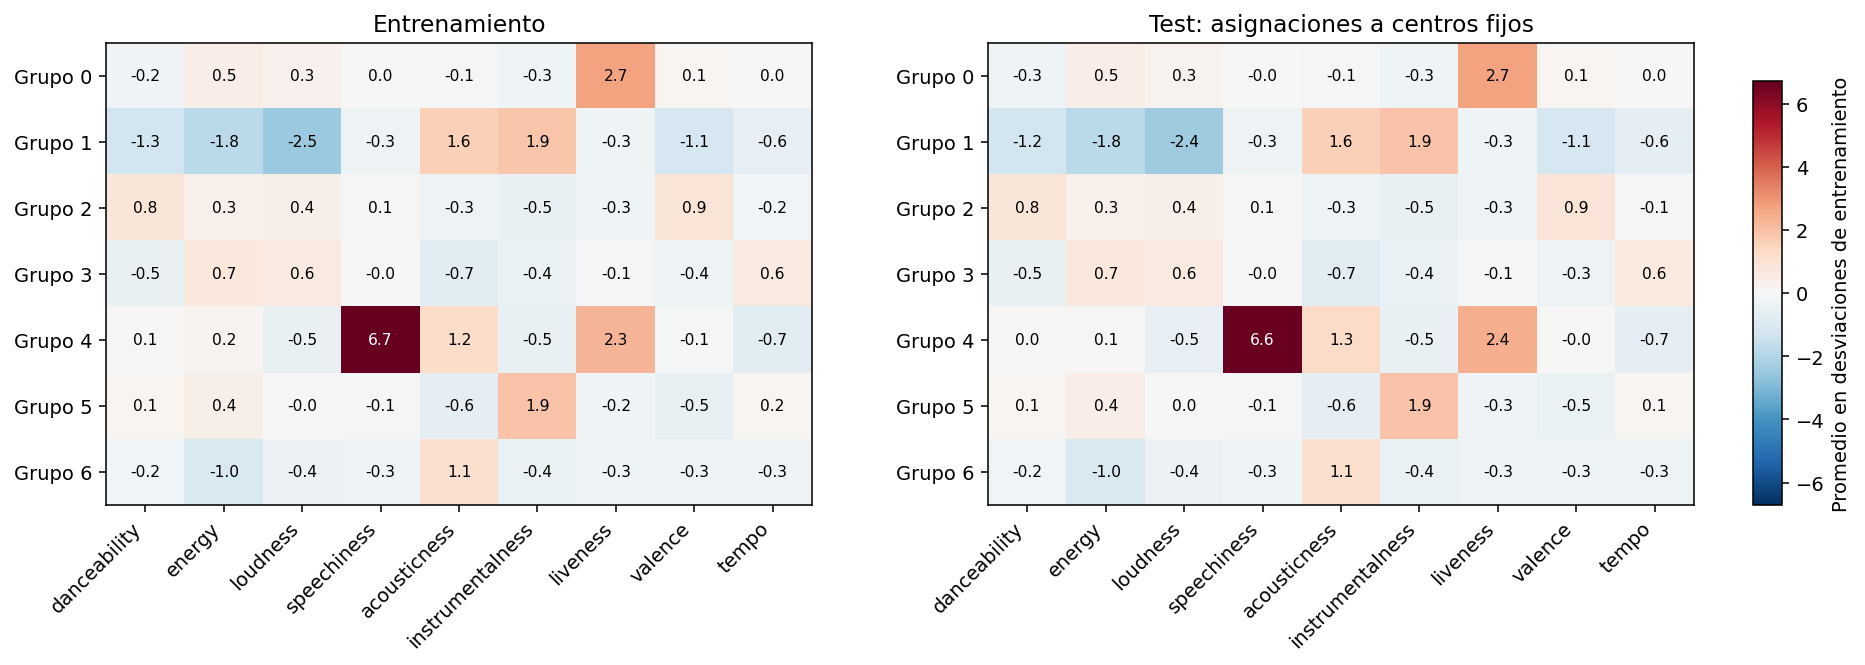

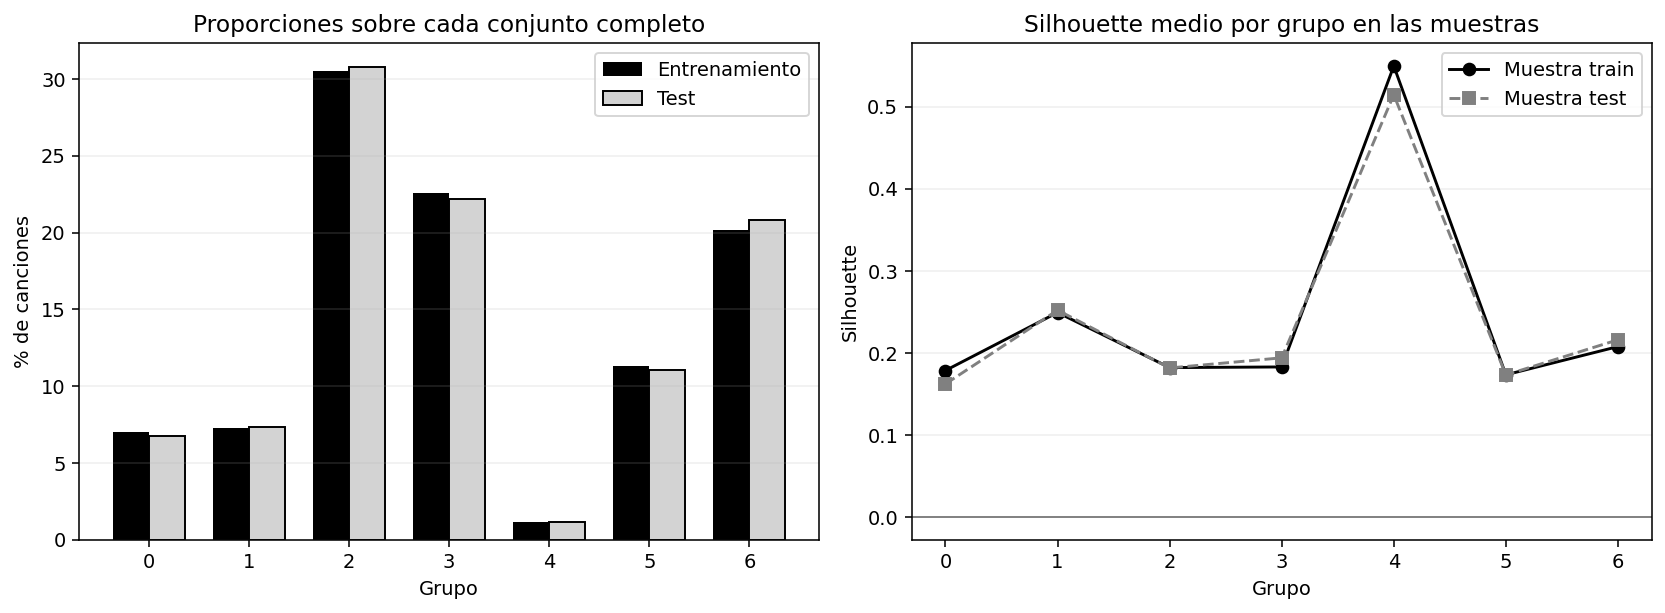

In [99]:
perfiles_train_z_testcomparacion = X_clustering_train_escalado.groupby(etiquetas_k_playlists).mean().reindex(range(7))
perfiles_test_z = X_clustering_test_escalado.groupby(etiquetas_kmeans_test).mean().reindex(range(7))
perfiles_train_originales_testcomparacion = X_clustering_train_imputado.groupby(etiquetas_k_playlists).mean().reindex(range(7))
perfiles_test_originales = X_clustering_test_imputado.groupby(etiquetas_kmeans_test).mean().reindex(range(7))
diferencias_perfiles_test_z = perfiles_test_z - perfiles_train_z_testcomparacion
resumen_cambios_perfiles_test = pd.DataFrame({
    "Mayor diferencia absoluta (DE de entrenamiento)": diferencias_perfiles_test_z.abs().max(axis=1),
    "Entrada con mayor cambio absoluto": diferencias_perfiles_test_z.abs().idxmax(axis=1),
})
print("Medias de audio en unidades originales: entrenamiento:")
display(perfiles_train_originales_testcomparacion.round(4))
print("Medias de audio en unidades originales: test:")
display(perfiles_test_originales.round(4))
print("Cambio test menos entrenamiento en escala común:")
display(diferencias_perfiles_test_z.round(4))
display(resumen_cambios_perfiles_test.round(4))

import matplotlib.pyplot as plt
fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))
limite_perfiles_test = max(
    np.nanmax(np.abs(perfiles_train_z_testcomparacion.to_numpy())),
    np.nanmax(np.abs(perfiles_test_z.to_numpy())),
)
for eje, perfiles, titulo in zip(ejes, [perfiles_train_z_testcomparacion, perfiles_test_z], ["Entrenamiento", "Test: asignaciones a centros fijos"]):
    imagen = eje.imshow(perfiles, aspect="auto", cmap="RdBu_r", vmin=-limite_perfiles_test, vmax=limite_perfiles_test)
    eje.set_xticks(range(len(variables_clustering)), variables_clustering, rotation=45, ha="right")
    eje.set_yticks(range(7), [f"Grupo {g}" for g in range(7)])
    eje.set_title(titulo)
    for g in range(7):
        for j in range(len(variables_clustering)):
            valor = perfiles.iloc[g, j]
            eje.text(j, g, f"{valor:.1f}" if pd.notna(valor) else "NA", ha="center", va="center", fontsize=8,
                     color="white" if abs(valor) > 0.6 * limite_perfiles_test else "black")
fig.subplots_adjust(left=0.07, right=0.88, bottom=0.3, top=0.9, wspace=0.25)
barra = fig.add_axes([0.91, 0.3, 0.015, 0.55])
fig.colorbar(imagen, cax=barra, label="Promedio en desviaciones de entrenamiento")
plt.show()

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
x_grupos = np.arange(7)
ejes[0].bar(x_grupos - 0.18, comparacion_grupos_kmeans_test["% train"], width=0.36, color="black", label="Entrenamiento")
ejes[0].bar(x_grupos + 0.18, comparacion_grupos_kmeans_test["% test"], width=0.36, color="lightgray", edgecolor="black", label="Test")
ejes[0].set(title="Proporciones sobre cada conjunto completo", xlabel="Grupo", ylabel="% de canciones")
ejes[1].plot(x_grupos, comparacion_grupos_kmeans_test["Silhouette medio train"], marker="o", color="black", label="Muestra train")
ejes[1].plot(x_grupos, comparacion_grupos_kmeans_test["Silhouette medio test"], marker="s", linestyle="--", color="gray", label="Muestra test")
ejes[1].axhline(0, color="gray", linewidth=1)
ejes[1].set(title="Silhouette medio por grupo en las muestras", xlabel="Grupo", ylabel="Silhouette")
for eje in ejes:
    eje.set_xticks(x_grupos)
    eje.legend()
    eje.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()


### 10.38. Cómo interpretar los perfiles y gráficos

**Código:** `groupby(...).mean()` calcula las medias de las canciones asignadas en cada conjunto, en escala original y estandarizada. Las medias de test son **descripciones posteriores a la asignación**, no nuevos centros para predecir. `reindex` conserva las siete etiquetas y mostraría ausencias si no hubiera canciones en un perfil.

Restamos `test − train` en la escala aprendida con entrenamiento, para comparar entradas con unidades distintas. `abs().max(axis=1)` encuentra la mayor diferencia por grupo y `idxmax` identifica su entrada. Una diferencia de 0,1 significa una décima de la desviación global de entrenamiento de esa característica, no 10% de similitud ni un umbral automático de aprobación. Mirar el máximo es un diagnóstico simple, no una prueba estadística de igualdad de distribuciones.

Los mapas de color usan el mismo límite en ambos paneles. Los números impresos evitan depender solo del color: positivo significa por encima de la media **de entrenamiento**, no música mejor. El colorbar explica unidades. No se normaliza cada grupo o cada conjunto por separado. Por eso es razonable comparar patrones entre paneles.

Las barras muestran porcentajes, con el mismo eje para ambos tamaños de conjunto. Los puntos de silhouette muestran promedios de las muestras, no intervalos de confianza. El promedio puede ocultar canciones negativas y cada grupo tiene distinto número de ejemplos muestreados. Las líneas solo conectan etiquetas para facilitar comparación: los números de grupos no representan una secuencia musical.

Una distribución de tamaños similar y perfiles parecidos respaldan continuidad descriptiva en esta partición, pero no validan géneros, calidad musical ni preferencias. Diferencias pueden deberse al muestreo, variación del catálogo y asignación a centros fijos. No interpretamos cualquier cambio como deterioro ni reajustamos los centros para que los mapas coincidan.


In [100]:
np.testing.assert_array_equal(imputador_clustering.statistics_, estado_antes_kmeans_test["Medianas"])
np.testing.assert_array_equal(escalador_clustering.mean_, estado_antes_kmeans_test["Medias"])
np.testing.assert_array_equal(escalador_clustering.scale_, estado_antes_kmeans_test["Escalas"])
np.testing.assert_array_equal(modelo_kmeans_playlists.cluster_centers_, estado_antes_kmeans_test["Centros"])
assert int(escalador_clustering.n_samples_seen_) == estado_antes_kmeans_test["Filas escalador"] == len(X_clustering_train_escalado)
assert modelo_kmeans_playlists.get_params() == estado_antes_kmeans_test["Parámetros"]
assert etiquetas_k_playlists.equals(estado_antes_kmeans_test["Etiquetas entrenamiento"])

controles_finales_kmeans_test = pd.DataFrame([
    ["IDs compartidos entre entrenamiento y test", 0],
    ["Cobertura de asignación en test (%)", 100 * etiquetas_kmeans_test.notna().mean()],
    ["Filas usadas por el escalador", int(escalador_clustering.n_samples_seen_)],
    ["Centros, escalas y medianas", "Sin cambios: igualdad exacta comprobada"],
    ["Regla de asignación", "Centro aprendido más cercano, K=7"],
    ["Silhouette", "Descriptivo; sin meta mínima inventada"],
], columns=["Control o criterio", "Resultado"])
display(controles_finales_kmeans_test)


,Control o criterio,Resultado
0,IDs compartidos entre entrenamiento y test,0
1,Cobertura de asignación en test (%),100.0
2,Filas usadas por el escalador,71728
3,"Centros, escalas y medianas",Sin cambios: igualdad exacta comprobada
4,Regla de asignación,"Centro aprendido más cercano, K=7"
5,Silhouette,Descriptivo; sin meta mínima inventada


### 10.39. Comprobaciones finales y límites

Las comparaciones de arrays exigen igualdad exacta de medianas, medias, escalas y centros con sus copias anteriores. Los `assert` comprueban que el escalador sigue registrando solo las filas de entrenamiento, los parámetros no cambiaron y las etiquetas de entrenamiento permanecen intactas. La tabla se muestra después de superar todos los controles. Estos controles respaldan que no hubo reajuste; no equivalen a éxito de playlists.

K-Means asigna toda canción válida a algún centro aunque sea poco parecida a los perfiles habituales. Una cobertura del 100% es una propiedad de esta regla, no prueba de que cada asignación sea musicalmente adecuada. No buscamos otro K, no eliminamos ejemplos difíciles, no escogemos la semilla de muestra por su score y no incorporamos popularidad, artista o géneros a las distancias.

El test interno es conocido y no temporal. Para confirmar generalización a un catálogo nuevo o a lanzamientos futuros harían falta datos independientes. Para confirmar utilidad en playlists haría falta revisar ejemplos y la experiencia de oyentes. Los resultados siguientes describen esta evaluación interna del procedimiento fijado.


### 10.40. Resultados reales de K-Means K=7 en test

#### Preparación y asignación

Se conservaron las **18.012 canciones de test** y las nueve entradas. Había **21 tempos ausentes**; se completaron con **122,021 BPM**, la mediana aprendida exclusivamente en entrenamiento. Las otras ocho entradas no necesitaron reemplazos. Después de preparar, no quedan ausencias o infinitos y cada canción tiene una etiqueta de uno de los siete centros conocidos.

Las medias estandarizadas de test son cercanas a 0 y las desviaciones cercanas a 1, pero no exactamente iguales. Por ejemplo, acústica tiene media **0,0218** y desviación **1,0092**. Eso describe una pequeña diferencia respecto a la escala de entrenamiento, no un error que debamos corregir reajustando el escalador. Se comprobó igualdad exacta de medianas, medias, escalas y centros antes y después de la evaluación.

#### Silhouette: separación parecida en las muestras

| Evaluación | IDs del conjunto | IDs muestreados | Grupos presentes en muestra | Silhouette medio | Valores negativos en muestra |
|---|---:|---:|---:|---:|---:|
| Entrenamiento | 71.728 | 5.000 | 7 | 0,1959 | 3,14% |
| Test interno | 18.012 | 5.000 | 7 | **0,1985** | 3,58% |

La diferencia de promedios es aproximadamente **+0,0026** a favor de test: muy pequeña en esta lectura descriptiva. Los resultados son compatibles con una separación promedio semejante en esta partición. No demostramos que el método haya mejorado ni que esa diferencia sea significativa: se usan muestras distintas y no calculamos intervalos de confianza.

Los dos promedios son positivos pero están lejos de 1; persisten fronteras difusas. Además, el porcentaje negativo sube de 3,14% a 3,58%, por lo que **no afirmamos que todo mejore en test**. Son porcentajes de cada muestra, no tasas exactas sobre los conjuntos completos.

Por grupo, los silhouettes medios de test van de aproximadamente **0,1622** a **0,5144**, todos positivos. El grupo 0 pasa de **0,1786** a **0,1622** y su proporción negativa de **11,63%** a **16,24%** de las canciones muestreadas (314 en test). Conviene revisar sus ejemplos de frontera antes de sugerirlos como una colección homogénea; mayor `liveness` no basta para una playlist coherente.

El grupo 4, de voz muy hablada, mantiene el promedio más alto: **0,5144** en test frente a **0,5495** en entrenamiento. En sus 56 canciones de la muestra de test no hay silhouettes negativos. No significa que sus 208 canciones completas tengan valores positivos ni que ese perfil sea apropiado como música: un rasgo muy marcado puede facilitar separación numérica sin garantizar utilidad para playlists musicales.

#### Tamaños: comparar proporciones, no esperar los mismos conteos

| Grupo | Descripción exploratoria | Canciones train | Canciones test | % train | % test |
|---:|---|---:|---:|---:|---:|
| 0 | Más indicios de interpretación en vivo | 5.016 | 1.217 | 6,99% | 6,76% |
| 1 | Acústico e instrumental de baja energía | 5.233 | 1.320 | 7,30% | 7,33% |
| 2 | Mayor bailabilidad y valencia | 21.903 | 5.543 | 30,54% | 30,77% |
| 3 | Energético y de tempo más rápido | 16.179 | 3.994 | 22,56% | 22,17% |
| 4 | Voz hablada muy marcada | 834 | 208 | 1,16% | 1,15% |
| 5 | Instrumental y energético | 8.121 | 1.985 | 11,32% | 11,02% |
| 6 | Más acústico y de energía menor | 14.442 | 3.745 | 20,13% | 20,79% |

Los siete perfiles reciben canciones de test. El mayor sigue siendo el grupo 2 y el menor el grupo 4. El cambio absoluto más grande de proporción aparece en el grupo 6: aproximadamente **+0,66 puntos porcentuales**, de 20,13% a 20,79%. No es 0,66% más de canciones ni una medida de precisión. Estas proporciones próximas respaldan continuidad descriptiva en esta partición, sin probar igualdad de distribuciones ni estabilidad temporal.

#### Perfiles musicales: qué se conserva y qué cambia

- **Grupo 1:** en test mantiene acústica **0,8715**, instrumentalidad **0,7935** y energía **0,1740**. Es coherente con el perfil acústico e instrumental de energía baja de entrenamiento (0,8607, 0,7792 y 0,1658, respectivamente).
- **Grupo 2:** bailabilidad **0,7047** y valencia **0,6974** en test, muy próximas a **0,7055** y **0,6987** en entrenamiento. Su tempo medio pasa de **117,58** a **118,23 BPM**. Esto respalda la descripción, sin garantizar alegría real o compatibilidad de todas las canciones.
- **Grupo 3:** sigue siendo energético y de tempo más rápido: energía **0,8149** y **141,26 BPM**, frente a 0,8174 y 140,52 BPM de entrenamiento.
- **Grupo 5:** conserva instrumentalidad **0,7925** y energía **0,7440** en test; sigue diferenciándose del grupo 1, también instrumental pero menos energético.
- **Grupos 0, 4 y 6:** mantienen, respectivamente, mayor índice de indicios de interpretación en vivo, voz muy hablada y mayor carácter acústico con energía menor. No convertimos esos índices en confirmación de conciertos, contenido musical o géneros.

La mayor diferencia absoluta de medias estandarizadas por grupo oscila aproximadamente entre **0,0218 y 0,1255 desviaciones globales de entrenamiento**. El máximo corresponde a `liveness` del grupo 4, con 208 canciones de test. Es una diferencia observada acotada en esa escala, no un criterio universal de equivalencia ni una prueba estadística de perfiles idénticos. La tabla completa y los mapas permiten revisar cada característica, no solo el cambio máximo.

#### Conclusión de esta evaluación interna

**Mantenemos K-Means de siete grupos como base exploratoria para perfiles de playlists.** Al aplicar los centros fijados, test conserva proporciones y rasgos medios parecidos y un silhouette promedio próximo al entrenamiento. Es evidencia descriptiva compatible con el procedimiento elegido, pero no prueba satisfacción de oyentes, validez de géneros o generalización a lanzamientos futuros.

La asignación completa del catálogo no demuestra que todas las canciones encajen bien: K-Means siempre elige alguno de los centros conocidos. El grupo 0 necesita atención por sus fronteras y el grupo de voz hablada requiere revisión de contenido. Los perfiles amplios aún necesitan selección y escucha de ejemplos antes de transformarse en playlists.

**Qué quedó fijado:** K=7, las nueve entradas, las medianas, el escalador y los centros. No se reajustaron usando test; sus valores se comprobaron antes y después. No se recalcularon sugerencias o métricas de entrenamiento para hacerlas coincidir con test. No se definió retrospectivamente una meta mínima de silhouette ni se cambió K tras observarlo.

**Alcance final:** evaluación sobre un test interno previamente observado y no temporal. Una decisión posterior guiada por sus resultados requeriría nueva evidencia independiente para confirmarse. La validación de utilidad musical y preferencias sigue pendiente; el CSV original permanece intacto.


### 10.41. Cierre de KPI y criterios del agrupamiento

**Objetivo del bloque:** organizar canciones mediante perfiles de audio para apoyar la revisión y creación de playlists y sugerencias. Elegimos **K-Means K=7** y evaluamos sus asignaciones a centros fijos en test. Este cierre reúne resultados existentes: **no ajusta modelos, no cambia K y no vuelve a seleccionar parámetros con test**.

Conviene distinguir tres tipos de evidencia:

1. **Controles metodológicos con metas explícitas:** ausencia de valores faltantes después de preparar, separación entre entrenamiento y test, cobertura de asignación y conservación de la preparación y los centros. Se puede indicar si cumplen su meta.
2. **Criterios descriptivos:** silhouette, tamaños, perfiles, codo, estabilidad y comparación con DBSCAN. Como no fijamos límites universales de calidad, informamos resultados y alcance; completar el análisis no equivale a aprobar calidad musical.
3. **Utilidad para playlists:** coherencia de escucha, satisfacción, variedad y transiciones. Los ejemplos ilustran cómo utilizar los perfiles, pero no aportan una evaluación con oyentes. Lo no medido se informa **pendiente**, no como cero ni como cumplimiento.

No aplicamos MAE, ROC-AUC, precisión o recall al clustering: aquí no estimamos popularidad ni comparamos con una clase musical correcta. Tampoco añadimos una meta mínima de silhouette después de ver sus resultados.


In [101]:
ids_compartidos_cierre_clustering = len(etiquetas_k_playlists.index.intersection(etiquetas_kmeans_test.index))
claves_compartidas_cierre_clustering = len(
    set(datos_entrenamiento["clave_cancion"]) & set(datos_prueba["clave_cancion"])
)
cobertura_train_cierre_clustering = 100 * etiquetas_k_playlists.notna().sum() / len(X_clustering_train_escalado)
cobertura_test_cierre_clustering = 100 * etiquetas_kmeans_test.notna().sum() / len(X_test)
assert etiquetas_k_playlists.index.equals(X_clustering_train_escalado.index)
assert etiquetas_kmeans_test.index.equals(X_test.index)
ausencias_train_cierre_clustering = int(X_clustering_train_imputado.isna().sum().sum())
ausencias_test_cierre_clustering = int(revision_preparacion_kmeans_test["Ausencias después en test"].sum())
filas_escalador_cierre_clustering = int(escalador_clustering.n_samples_seen_)
evidencia_centros_fijos_cierre = controles_finales_kmeans_test.loc[
    controles_finales_kmeans_test["Control o criterio"].eq("Centros, escalas y medianas"), "Resultado"
].iloc[0]

filas_kpi_clustering = [
    ["IDs compartidos train/test", "0", str(ids_compartidos_cierre_clustering), "Control conjunto", ids_compartidos_cierre_clustering == 0, "Intersección de índices"],
    ["Claves artista+título compartidas", "0", str(claves_compartidas_cierre_clustering), "Control conjunto", claves_compartidas_cierre_clustering == 0, "Intersección de claves"],
    ["Ausencias después de preparar", "0 en cada conjunto", str(ausencias_train_cierre_clustering), str(ausencias_test_cierre_clustering), ausencias_train_cierre_clustering == 0 and ausencias_test_cierre_clustering == 0, "Tablas de preparación"],
    ["Cobertura de asignación", "100% en cada conjunto", f"{cobertura_train_cierre_clustering:.2f}%", f"{cobertura_test_cierre_clustering:.2f}%", np.isclose(cobertura_train_cierre_clustering, 100) and np.isclose(cobertura_test_cierre_clustering, 100), "Una etiqueta por ID, índices alineados"],
    ["Aprendizaje del escalador", "Solo entrenamiento", f"{filas_escalador_cierre_clustering:,} filas", "Se aplicó transform", filas_escalador_cierre_clustering == len(X_clustering_train_escalado), "n_samples_seen_ y código de 10.36"],
    ["Preparación y centros fijos en test", "Sin reajuste", "Parámetros aprendidos", evidencia_centros_fijos_cierre, evidencia_centros_fijos_cierre == "Sin cambios: igualdad exacta comprobada", "Comparaciones exactas ejecutadas en 10.39"],
]
tabla_final_kpi_clustering = pd.DataFrame(filas_kpi_clustering, columns=[
    "Control", "Meta", "Entrenamiento o control conjunto", "Test", "Cumple", "Evidencia"
])
tabla_final_kpi_clustering["Cumple"] = tabla_final_kpi_clustering["Cumple"].map({True: "Cumple", False: "Revisar"})
display(tabla_final_kpi_clustering)

sil_train_cierre = float(comparacion_silhouette_kmeans_test.loc["Entrenamiento", "Silhouette medio de muestra"])
sil_test_cierre = float(comparacion_silhouette_kmeans_test.loc["Test interno", "Silhouette medio de muestra"])
max_cambio_proporcion_cierre = float(comparacion_grupos_kmeans_test["Cambio proporción (puntos porcentuales)"].abs().max())
max_cambio_perfil_cierre = float(resumen_cambios_perfiles_test["Mayor diferencia absoluta (DE de entrenamiento)"].max())
estabilidad_k7_cierre = tabla_estabilidad_playlists.loc[
    tabla_estabilidad_playlists["K"].eq(7) & tabla_estabilidad_playlists["Semilla"].ne(42)
]
filas_criterios_finales = [
    ["Silhouette de muestras de 5.000 IDs", f"{sil_train_cierre:.4f}", f"{sil_test_cierre:.4f}", "Evaluado; sin meta mínima", "Comparación interna, no precisión ni satisfacción"],
    ["Silhouette negativo en muestra", f"{comparacion_silhouette_kmeans_test.loc['Entrenamiento', 'Silhouette negativo en muestra (%)']:.2f}%", f"{comparacion_silhouette_kmeans_test.loc['Test interno', 'Silhouette negativo en muestra (%)']:.2f}%", "Evaluado; persisten fronteras", "Porcentajes de muestra, no del conjunto completo"],
    ["Mayor grupo (% del conjunto)", f"{comparacion_grupos_kmeans_test['% train'].max():.2f}%", f"{comparacion_grupos_kmeans_test['% test'].max():.2f}%", "Evaluado; sin exigir igualdad", f"Mayor cambio de proporción: {max_cambio_proporcion_cierre:.4f} puntos porcentuales"],
    ["Perfiles de nueve entradas", "Siete perfiles descritos", "Mismos siete centros", "Comparados", f"Máximo cambio de medias: {max_cambio_perfil_cierre:.4f} DE de entrenamiento"],
    ["Estabilidad de K=7 ante inicialización", "; ".join(f"semilla {int(f['Semilla'])}: {f['Acuerdo alineado (%)']:.2f}%" for _, f in estabilidad_k7_cierre.iterrows()), "Sin reajustes: no se repitió este experimento", "Revisada en entrenamiento", "Dos semillas nuevas; no prueba cambios de catálogo o tiempo"],
    ["Codo y comparación de K", f"{len(tabla_comparacion_k)} valores: 2 a 10; revisión de K=7 y K=9", "No se seleccionó K por test", "Documentado", "K=2 excluido por detalle; K=7 elegido antes de esta evaluación"],
    ["Alternativa DBSCAN", "Cuatro ajustes; cinco omitidos por costo", "No evaluado en test", "Exploración limitada", "No sustituye una comparación final de algoritmos en test"],
    ["Ejemplos y sugerencias", f"{len(representativas_k7)} representativas; {len(sugerencias_mismo_grupo)} sugerencias del ejemplo", "No se generaron nuevas sugerencias", "Demostración realizada", "No es una evaluación con oyentes"],
]
tabla_final_criterios_clustering = pd.DataFrame(filas_criterios_finales, columns=[
    "Criterio", "Entrenamiento", "Test", "Estado", "Interpretación o evidencia"
])
display(tabla_final_criterios_clustering)

tabla_utilidad_playlists_pendiente = pd.DataFrame([
    ["Coherencia musical y transiciones", "Pendiente", "Escucha y revisión de selecciones comparables"],
    ["Preferencia o satisfacción de oyentes", "Pendiente", "Evaluación con usuarios y metas definidas antes de medir"],
    ["Variedad de artistas y contenidos", "Pendiente", "Revisar repetición y requisitos del uso concreto"],
    ["Generalización temporal y estabilidad de catálogo", "Pendiente", "Datos independientes, posteriores o remuestreo documentado"],
], columns=["Utilidad a comprobar", "Estado", "Evidencia necesaria"])
display(tabla_utilidad_playlists_pendiente)


,Control,Meta,Entrenamiento o control conjunto,Test,Cumple,Evidencia
0,IDs compartidos train/test,0,0,Control conjunto,Cumple,Intersección de índices
1,Claves artista+título compartidas,0,0,Control conjunto,Cumple,Intersección de claves
2,Ausencias después de preparar,0 en cada conjunto,0,0,Cumple,Tablas de preparación
3,Cobertura de asignación,100% en cada conjunto,100.00%,100.00%,Cumple,"Una etiqueta por ID, índices alineados"
4,Aprendizaje del escalador,Solo entrenamiento,"71,728 filas",Se aplicó transform,Cumple,n_samples_seen_ y código de 10.36
5,Preparación y centros fijos en test,Sin reajuste,Parámetros aprendidos,Sin cambios: igualdad exacta comprobada,Cumple,Comparaciones exactas ejecutadas en 10.39


,Criterio,Entrenamiento,Test,Estado,Interpretación o evidencia
0,Silhouette de muestras de 5.000 IDs,0.1959,0.1985,Evaluado; sin meta mínima,"Comparación interna, no precisión ni satisfacción"
1,Silhouette negativo en muestra,3.14%,3.58%,Evaluado; persisten fronteras,"Porcentajes de muestra, no del conjunto completo"
2,Mayor grupo (% del conjunto),30.54%,30.77%,Evaluado; sin exigir igualdad,Mayor cambio de proporción: 0.6573 puntos porcentuales
3,Perfiles de nueve entradas,Siete perfiles descritos,Mismos siete centros,Comparados,Máximo cambio de medias: 0.1255 DE de entrenamiento
4,Estabilidad de K=7 ante inicialización,semilla 7: 99.91%; semilla 2026: 99.98%,Sin reajustes: no se repitió este experimento,Revisada en entrenamiento,Dos semillas nuevas; no prueba cambios de catálogo o tiempo
5,Codo y comparación de K,9 valores: 2 a 10; revisión de K=7 y K=9,No se seleccionó K por test,Documentado,K=2 excluido por detalle; K=7 elegido antes de esta evaluación
6,Alternativa DBSCAN,Cuatro ajustes; cinco omitidos por costo,No evaluado en test,Exploración limitada,No sustituye una comparación final de algoritmos en test
7,Ejemplos y sugerencias,21 representativas; 10 sugerencias del ejemplo,No se generaron nuevas sugerencias,Demostración realizada,No es una evaluación con oyentes


,Utilidad a comprobar,Estado,Evidencia necesaria
0,Coherencia musical y transiciones,Pendiente,Escucha y revisión de selecciones comparables
1,Preferencia o satisfacción de oyentes,Pendiente,Evaluación con usuarios y metas definidas antes de medir
2,Variedad de artistas y contenidos,Pendiente,Revisar repetición y requisitos del uso concreto
3,Generalización temporal y estabilidad de catálogo,Pendiente,"Datos independientes, posteriores o remuestreo documentado"


### 10.42. Cómo se calcula y se interpreta el cierre

**Lectura del código:**

1. La intersección de índices cuenta IDs presentes en ambos conjuntos. La intersección de conjuntos de claves cuenta canciones identificadas por artista+título que cruzarían la separación. El resultado esperado de ambos es cero; eso no exige artistas distintos entre conjuntos.
2. Para cobertura, dividimos etiquetas presentes por filas de cada conjunto y multiplicamos por 100. Los `assert` verifican primero que se evalúan exactamente los mismos IDs y orden. **100% significa una etiqueta para cada canción**, no 100% de calidad, precisión o recomendaciones correctas. K-Means asigna incluso canciones lejanas a alguno de los centros.
3. Sumamos ausencias después de preparar: en entrenamiento desde la tabla imputada y en test desde su auditoría ya calculada. Los controles de números finitos se ejecutaron en la preparación; no estamos identificando nuevas ausencias ni modificando datos.
4. `n_samples_seen_` indica cuántas filas vio el escalador. El valor esperado es 71.728. Ese conteo se combina con el código de aplicación de `transform` y con las comprobaciones exactas anteriores; **el conteo aislado no probaría ausencia de fuga**.
5. Recuperamos del cierre anterior la evidencia de que medianas, escalas y centros fueron idénticos antes y después de test. Esta tabla **consolida esa comprobación ya ejecutada**, no compara solo textos para demostrar por primera vez que los objetos no cambiaron.
6. Creamos la tabla de controles, con meta, resultado y evidencia. `map` convierte las condiciones a «Cumple» o «Revisar». Un control metodológico cumplido no convierte automáticamente los perfiles en playlists validadas.
7. Recuperamos silhouette, proporciones y diferencias de medias sin recalcular los agrupamientos. `abs().max()` informa el mayor cambio de proporción en puntos porcentuales y el máximo cambio de perfiles en desviaciones de entrenamiento. No son probabilidades ni pruebas estadísticas.
8. Filtramos K=7 en estabilidad y excluimos la semilla 42, porque coincide con la referencia por construcción. Las semillas 7 y 2026 aportan la evidencia nueva de inicialización. El test se asignó a centros fijos, por lo que no existe un experimento comparable de reajuste de semillas allí.
9. Las otras tablas documentan criterios ya estudiados y utilidad pendiente. `len` cuenta ejemplos o valores K realmente calculados; no cuenta playlists publicadas. **«Evaluado» significa que existe un análisis**, sin inventar una meta de silhouette. «Pendiente» significa que no tenemos la evidencia necesaria, no que el resultado sea cero o que se cumpla.

El cierre no llama a `fit`, `predict` ni a selección de parámetros, y no modifica decisiones a partir de test. Las metas de precisión o recall de clasificación pertenecen a otra tarea y no se trasladan aquí.


### 10.43. Conclusiones del agrupamiento: respuesta al objetivo

**Se obtuvo una organización exploratoria de canciones en siete perfiles de audio y se ilustró cómo usarla para buscar canciones próximas.** No se obtuvo todavía un sistema de recomendaciones personalizado ni se validó la calidad de playlists con oyentes.

La preparación seleccionó nueve entradas de audio, imputó ausencias mediante medianas de entrenamiento y estandarizó con ese mismo conjunto. Quedaron fuera de la distancia popularidad, artista y géneros. Elegir esa representación permite buscar semejanza de rasgos sonoros sin imponer que dos canciones compartan artista, popularidad o etiqueta de género; tampoco garantiza similitud en letras, idioma, contenido o contexto.

**Por qué K=7:** se exploraron K de 2 a 10 y se revisaron especialmente siete y nueve perfiles. Dos grupos se excluyeron por ser demasiado generales para el uso solicitado, decisión incorporada después de precisar el objetivo y documentada como tal. Entre los candidatos elegibles, siete obtuvo mayor silhouette que nueve y mantuvo mucho mejor las asignaciones en las dos inicializaciones nuevas. Nueve ofrecía detalle adicional de tempo y voz hablada, pero una repetición reorganizó una parte importante de sus canciones. Por eso se conservó K=7 antes de evaluarlo en test, sin afirmar que siete sea el número universal de estilos.

**Qué aporta test:** el procedimiento fijado asignó los 18.012 IDs con los centros y preparadores de entrenamiento. El silhouette en muestras de 5.000 canciones fue **0,1959 en entrenamiento y 0,1985 en test**. La diferencia de aproximadamente **+0,0026** es pequeña y descriptiva; no se probó significación. Las proporciones y características medias permanecen parecidas: el mayor cambio de proporción fue **0,66 puntos porcentuales** y el máximo cambio de una media de perfil aproximadamente **0,1255 desviaciones globales de entrenamiento**.

Esta continuidad es compatible con aplicar los perfiles a la partición interna sin que aparezcan cambios descriptivos grandes en estos resúmenes. **No demuestra igualdad de distribuciones, ausencia de sobreajuste o utilidad musical.** El porcentaje de silhouettes negativos de las muestras pasó de **3,14% a 3,58%**; por tanto, no todos los indicadores mejoraron.

**Qué mostró DBSCAN:** los cuatro ajustes realizados tendieron a concentrar casi todas las canciones asignadas en un grupo y dejar otras como ruido. El caso ilustrativo dejó 28,18% de ruido y un grupo con 94,24% de las asignadas; K-Means resultó más adecuado para la organización de varios perfiles buscada en esta exploración. Cinco configuraciones DBSCAN no se ajustaron por costo, por lo que no se descarta el algoritmo universalmente. No hicimos una comparación final de ambos en test y no usamos test para cambiar la selección.

**Qué mostró PCA:** el plano de dos componentes conserva **47,98% de la varianza** de las nueve entradas. Sirve para visualizar el mismo catálogo y sus etiquetas, pero deja fuera más de la mitad de la variación. Sus solapamientos no sustituyen las métricas y los grupos y sugerencias siguen calculados con las nueve entradas originales preparadas.


### 10.44. Beneficios y limitaciones de K-Means para playlists

| Beneficio observado o uso posible | Evidencia y límite |
|---|---|
| Organizar el catálogo en perfiles interpretables | Se distinguen combinaciones acústicas, instrumentales, bailables, energéticas y de voz hablada; no son géneros confirmados |
| Reproducir asignaciones con centros fijos | Medianas, escalamiento y centros se conservaron exactamente en test; eso no verifica estabilidad temporal |
| Facilitar ejemplos y búsquedas iniciales | Se mostraron 21 representativas y diez sugerencias desde una referencia, sin usar popularidad para ordenarlas; son demostraciones |
| Mantener varios perfiles en la partición interna | Los siete recibieron canciones de test con proporciones próximas; una etiqueta presente no garantiza compatibilidad de todas sus canciones |
| Dar una base sencilla para revisar playlists | Los grupos pueden acotar candidatos y las distancias ordenar cercanía a una referencia; una playlist todavía requiere criterios adicionales y escucha |

**Límites que afectan el uso:**

- **Separación moderada y fronteras difusas.** Los silhouettes no están cerca de 1. El grupo 0 de mayores indicios de interpretación en vivo presenta más valores negativos en la muestra de test; sus ejemplos de frontera merecen revisión.
- **Los promedios ocultan diversidad.** Un grupo energético puede contener tempos o texturas diferentes. La cercanía al centro describe el perfil típico, mientras la cercanía a una canción concreta puede dar otro orden de sugerencias.
- **Asignación forzada.** K-Means ofrece un grupo para todas las entradas válidas, incluso si una canción es atípica. Cobertura completa no significa encaje musical completo.
- **La representación decide qué es parecido.** Escalamiento, correlaciones, extremos y medianas imputadas influyen en las distancias. Dos entradas relacionadas pueden dar peso redundante a un rasgo. No se probaron todas las representaciones posibles.
- **Un grupo separado puede no ser musical.** El perfil de voz muy hablada requiere revisar contenido; su silhouette más alto no lo convierte en una mejor playlist de música.
- **Siete grupos no equivalen a siete playlists terminadas.** Pueden servir como colecciones iniciales para muchas listas. Un filtro estricto por grupo podría excluir canciones cercanas del otro lado de una frontera; en nuestro ejemplo las búsquedas restringida y global coincidieron, sin demostrar que siempre sucederá.
- **No hay personalización validada.** No contamos con historial de escucha, gustos, preferencias de idioma o valoración de usuarios. La similitud de audio no equivale a una recomendación que guste.
- **El orden de cercanía no optimiza reproducción.** No se evaluaron transiciones, duración total, repetición de artistas, diversidad o disponibilidad actual en la plataforma. No se publicaron playlists ni se escucharon los ejemplos durante este análisis.
- **Alcance del test.** La partición ya se observó en otras tareas y no es temporal o externa. Artistas pueden aparecer en ambos lados y versiones con distintas claves aún podrían influir en perfiles. No se demuestra generalización a otro catálogo o a lanzamientos futuros.

**Decisión final del bloque:** se mantiene **K-Means K=7 como propuesta exploratoria** para apoyar la creación de playlists. Los controles metodológicos quedan cumplidos y los criterios descriptivos quedan documentados; **la utilidad con oyentes permanece pendiente**. No se declara un KPI global de «playlist exitosa» que no haya sido definido y medido.

El siguiente paso de validación musical sería revisar selecciones bajo reglas comunes, comprobar contenido y transiciones y definir de antemano cómo recoger valoraciones de usuarios. Si se rediseñan K, entradas o reglas a partir de lo visto en test, su confirmación requerirá evidencia independiente. Este cierre conserva el CSV, los parámetros, las asignaciones y las evaluaciones anteriores.


<a id="bloque-11"></a>
## 11. Conclusiones generales de la unidad 2

### 11.1. Qué preguntas respondimos y cómo se conectan

La unidad 2 utilizó los datos preparados en la unidad 1 para abordar **tres preguntas diferentes**:

| Tarea | Pregunta | Procedimiento elegido | Qué entrega |
|---|---|---|---|
| Regresión | ¿Qué puntaje de popularidad registrado podemos estimar? | HistGradientBoosting de regresión con artista | Un número en la escala de popularidad |
| Clasificación | ¿La canción tiene popularidad de 60 o más? | HistGradientBoosting clasificador con artista y corte 0,30 | Una puntuación de clase y una decisión positiva/negativa |
| Agrupamiento | ¿Qué canciones presentan perfiles de audio parecidos? | K-Means de siete grupos | Una asignación a perfil y una base para explorar similitud |

Las tareas se complementan, pero sus métricas no se comparan como si fueran una misma nota. Un AUC de 0,9180 no se puede enfrentar con un silhouette de 0,1985 para decidir qué tarea «es mejor». Tampoco una canción del perfil más energético es necesariamente más popular o más recomendable para una persona.

**Regresión y clasificación usan dos modelos distintos**, aunque ambos se llamen HistGradientBoosting. Aprenden objetivos diferentes: puntaje continuo y clase binaria, respectivamente. No convertimos las predicciones del regresor en el clasificador final. El agrupamiento no aprendió ninguna de esas respuestas.

Se conservaron **71.728 canciones de entrenamiento y 18.012 de test**, con una fila por ID y separación agrupada por clave artista+título. Las comparaciones de candidatos utilizaron predicciones OOF de tres particiones agrupadas; la preparación y las codificaciones de artista se aprendieron dentro de los ajustes permitidos. Los procedimientos finales se aplicaron al test con las reglas documentadas. Las evaluaciones históricas, incluida la de logística, se conservan; el test ya se observó durante el proceso y no es una prueba externa nueva.


In [102]:
reg_oof_resumen_u2 = comparacion_desarrollo_test.iloc[0]
reg_test_resumen_u2 = tabla_evaluacion_test.loc["HistGradientBoosting con artista"]
clase_oof_resumen_u2 = comparacion_punto_hist_final.loc["OOF entrenamiento"]
clase_test_resumen_u2 = comparacion_punto_hist_final.loc["Test interno"]

tabla_resultados_generales_u2 = pd.DataFrame([
    ["Regresión", "MAE", reg_oof_resumen_u2["MAE modelo"], reg_test_resumen_u2["MAE"], "Puntos de popularidad; menor es mejor"],
    ["Regresión", "RMSE", reg_oof_resumen_u2["RMSE modelo"], reg_test_resumen_u2["RMSE"], "Puntos; da más peso a errores grandes"],
    ["Regresión", "R²", reg_oof_resumen_u2["R² modelo"], reg_test_resumen_u2["R²"], "Comparación con constante media; no accuracy"],
    ["Clasificación", "Precisión al corte fijo 0,30 (%)", clase_oof_resumen_u2["Precisión (%)"], clase_test_resumen_u2["Precisión (%)"], "Positivas reales entre las señaladas"],
    ["Clasificación", "Recall al corte fijo 0,30 (%)", clase_oof_resumen_u2["Recall (%)"], clase_test_resumen_u2["Recall (%)"], "Positivas detectadas entre todas las positivas"],
    ["Clasificación", "ROC-AUC", comparacion_auc_hist_final.loc["OOF entrenamiento", "ROC-AUC"], comparacion_auc_hist_final.loc["Test interno", "ROC-AUC"], "Discriminación usando probabilidades"],
    ["Agrupamiento", "Silhouette en muestras de 5.000 IDs", comparacion_silhouette_kmeans_test.loc["Entrenamiento", "Silhouette medio de muestra"], comparacion_silhouette_kmeans_test.loc["Test interno", "Silhouette medio de muestra"], "Separación relativa; no porcentaje de aciertos"],
], columns=["Tarea", "Indicador", "Entrenamiento evaluado", "Test interno", "Cómo leerlo"])
display(tabla_resultados_generales_u2.round(4))

tabla_kpi_generales_u2 = pd.DataFrame([
    ["Regresión", "Reducción relativa de MAE frente a mediana", f">={mejora_objetivo * 100:.0f}%", f"{mejora_mae_test:.2f}%", "Cumple" if mejora_mae_test >= mejora_objetivo * 100 else "No cumple", "Mediana y modelo sobre las mismas canciones de test"],
    ["Clasificación", "Precisión de clase positiva", f">={meta_precision_clasificacion * 100:.0f}%", f"{clase_test_resumen_u2['Precisión (%)']:.2f}%", "Cumple" if clase_test_resumen_u2["Precisión (%)"] >= meta_precision_clasificacion * 100 else "No cumple", "Corte conservado 0,30"],
    ["Clasificación", "Recall de clase positiva", f">={meta_recall_clasificacion * 100:.0f}%", f"{clase_test_resumen_u2['Recall (%)']:.2f}%", "Cumple" if clase_test_resumen_u2["Recall (%)"] >= meta_recall_clasificacion * 100 else "No cumple", "Corte conservado 0,30"],
    ["Agrupamiento", "Silhouette de test", "Sin meta mínima fijada", f"{comparacion_silhouette_kmeans_test.loc['Test interno', 'Silhouette medio de muestra']:.4f}", "Evaluado; no equivale a aprobar un KPI", "5.000 IDs muestreados; siete centros fijos"],
    ["Playlists", "Utilidad para oyentes", "Pendiente de definir y medir", "No evaluada con usuarios", "Pendiente", "Ejemplos y sugerencias no sustituyen evaluación musical"],
], columns=["Tarea", "KPI o criterio", "Meta", "Resultado final", "Estado", "Evidencia o alcance"])
display(tabla_kpi_generales_u2)


,Tarea,Indicador,Entrenamiento evaluado,Test interno,Cómo leerlo
0,Regresión,MAE,9.3711,9.1251,Puntos de popularidad; menor es mejor
1,Regresión,RMSE,14.4388,14.1016,Puntos; da más peso a errores grandes
2,Regresión,R²,0.5081,0.5285,Comparación con constante media; no accuracy
3,Clasificación,"Precisión al corte fijo 0,30 (%)",50.3219,50.2105,Positivas reales entre las señaladas
4,Clasificación,"Recall al corte fijo 0,30 (%)",63.6306,67.7686,Positivas detectadas entre todas las positivas
5,Clasificación,ROC-AUC,0.9097,0.9180,Discriminación usando probabilidades
6,Agrupamiento,Silhouette en muestras de 5.000 IDs,0.1959,0.1985,Separación relativa; no porcentaje de aciertos


,Tarea,KPI o criterio,Meta,Resultado final,Estado,Evidencia o alcance
0,Regresión,Reducción relativa de MAE frente a mediana,>=10%,46.83%,Cumple,Mediana y modelo sobre las mismas canciones de test
1,Clasificación,Precisión de clase positiva,>=30%,50.21%,Cumple,"Corte conservado 0,30"
2,Clasificación,Recall de clase positiva,>=60%,67.77%,Cumple,"Corte conservado 0,30"
3,Agrupamiento,Silhouette de test,Sin meta mínima fijada,0.1985,Evaluado; no equivale a aprobar un KPI,5.000 IDs muestreados; siete centros fijos
4,Playlists,Utilidad para oyentes,Pendiente de definir y medir,No evaluada con usuarios,Pendiente,Ejemplos y sugerencias no sustituyen evaluación musical


**Cómo se construyó el resumen:** recuperamos filas de las tablas de evaluación ya calculadas y las reunimos con `DataFrame`. `iloc[0]` selecciona la fila de desarrollo de regresión y `.loc` identifica resultados por su nombre. No ajustamos, predecimos ni calculamos una nueva partición. `round(4)` afecta únicamente a la presentación.

En clasificación mostramos el **mismo corte fijo 0,30** para OOF y test. Ese resumen OOF no reemplaza la validación anidada anterior, que elegía cortes dentro de cada ronda. La selección de 0,30 utilizó entrenamiento; sus métricas OOF al corte seleccionado no constituyen una evaluación independiente del proceso de elección. ROC-AUC utiliza las probabilidades y no depende de ese corte.

Las condiciones de la segunda tabla comparan los resultados de test con las metas predictivas ya establecidas. Si no se cumplieran, se mostraría «No cumple»; no se cambiaría la meta. Para silhouette y utilidad de playlists no había un límite de aprobación definido, por lo que se reportan «Evaluado» y «Pendiente». Los controles de separación, preparación y cobertura quedan documentados en los cierres de cada tarea; no se convierten en una puntuación de calidad musical.


### 11.2. Regresión: qué logramos al estimar popularidad

Comparamos una referencia que siempre predice la **mediana de entrenamiento** con cuatro modelos: regresión lineal, árbol sencillo, KNN e HistGradientBoosting. Se examinó cada familia con y sin artista. La referencia permite saber si la complejidad del modelo aporta una mejora real frente a una regla sencilla.

El procedimiento final fue **HistGradientBoosting de regresión con artista**. En test obtuvo:

- **MAE 9,1251 puntos:** el error absoluto promedio es aproximadamente 9,13 puntos de popularidad. No significa que todas las canciones estén a menos de 9,13 puntos: algunas tienen errores mayores.
- **RMSE 14,1016 puntos:** da más peso a errores grandes. Que sea mayor que el MAE indica que hay errores de mayor magnitud que conviene revisar; no es otro porcentaje de aciertos.
- **R² 0,5285:** reduce la suma de errores cuadrados aproximadamente 52,85% frente a predecir la media de las respuestas de test. No significa acertar 52,85% de canciones ni explicar causalmente su éxito.

La referencia mediana tuvo MAE **17,1629**. La reducción fue **8,0377 puntos de error promedio**, equivalente a **46,83%** del MAE de referencia: `(17,1629 − 9,1251) / 17,1629 × 100`, con valores completos en el cálculo. **Cumple la meta inicial de al menos 10% de reducción relativa.** No fijamos metas adicionales retrospectivas para RMSE o R².

En OOF, el modelo elegido tuvo MAE aproximadamente **9,3711**; test es ligeramente menor. Esa diferencia describe esta partición, sin demostrar ausencia de sobreajuste. La mediana de referencia se aprendió con entrenamiento y fue **33,0**, no se calculó con las respuestas de test.

**Conclusión de regresión:** el modelo aporta una mejora considerable frente a la referencia en este test interno, pero conserva errores relevantes y no anticipa éxito futuro con evidencia temporal. La popularidad registrada tampoco equivale a calidad musical. Se conservaron predicciones sin recortarlas a la escala 0–100; hubo **83 por debajo de 0**, limitación ya registrada, sin corregir resultados después de ver test.


### 11.3. Clasificación: qué significa identificar popularidad alta

Definimos la clase positiva como popularidad **60 o más**. Ese valor es una decisión operativa del proyecto, no una definición universal de éxito o un límite oficial de Spotify. Comparamos referencia mayoritaria, logística, árbol, KNN e HistGradientBoosting, con y sin artista. La logística `balanced` fue una variante adicional de ponderación; no una quinta familia de modelos principales.

**No confundir dos cortes:** **60** define la clase real; **0,30** es el umbral de puntuación del clasificador final para decidir si la señala como positiva. El modelo no predice que una canción tendrá popularidad 0,30 ni que exactamente 30% de las señaladas serán populares. No verificamos calibración de probabilidades.

El procedimiento final fue **HistGradientBoosting clasificador con artista**, conservando corte 0,30. En test:

| Resultado | Cantidad | Qué significa |
|---|---:|---|
| Verdaderos positivos | 1.312 | Canciones de popularidad ≥60 detectadas |
| Falsos negativos | 624 | Canciones de popularidad ≥60 omitidas |
| Falsos positivos | 1.301 | Canciones señaladas que tenían popularidad <60 |
| Verdaderos negativos | 14.775 | Canciones de popularidad <60 correctamente descartadas |

**Precisión 50,21%:** entre 2.613 canciones señaladas, 1.312 son positivas reales. Cumple la meta mínima de 30%, pero aproximadamente la mitad de las señaladas siguen siendo falsas alarmas.

**Recall 67,77%:** detecta 1.312 de las 1.936 positivas. Cumple la meta mínima de 60%, aunque deja 624 sin detectar. El **F1 0,5768** resume el equilibrio entre precisión y recall al corte conservado; no lo interpretamos como porcentaje de aciertos ni fijamos una meta nueva para él.

**ROC-AUC 0,9180 en test**, frente a **0,9097 OOF**, respalda capacidad de ordenar positivas sobre negativas en estas evaluaciones. AUC no depende del umbral 0,30 y no equivale a accuracy o probabilidad calibrada. Un AUC alto no demuestra por sí solo cumplir los KPI: a corte 0,50, incluso este modelo tenía recall insuficiente en OOF.

La accuracy del clasificador final es aproximadamente **89,31%**, muy parecida al **89,25%** de predecir siempre la clase mayoritaria. Pero esa referencia no detecta ninguna positiva. Esto muestra por qué accuracy sola es engañosa para este objetivo con alrededor de 11% de positivas y por qué priorizamos precisión, recall, F1 y la revisión de puntuaciones.

**Conclusión de clasificación:** se cumplen ambas metas predictivas del proyecto en este test interno con la regla fijada, pero persisten omisiones y falsas alarmas. El cumplimiento no constituye una garantía comercial ni una nota de la asignatura. La información del artista mejoró AUC OOF en las cuatro familias, aunque su utilidad futura exige considerar artistas nuevos y disponibilidad temporal de la información.


### 11.4. Agrupamiento: qué aporta a la creación de playlists

El agrupamiento respondió una pregunta distinta: semejanza en **nueve características de audio**, excluyendo popularidad, artista y géneros de sus distancias. Se imputaron ausencias y se escaló con entrenamiento. Elegir esa representación define lo que el algoritmo considera parecido y no recoge todas las dimensiones musicales.

Se exploraron K de 2 a 10. Dos perfiles fueron demasiado generales para el objetivo de playlists, decisión de alcance incorporada y documentada después de precisar ese objetivo. La comparación de **K=7 y K=9** favoreció siete por silhouette algo mayor y mayor consistencia entre las semillas nuevas: aproximadamente **99,91% y 99,98% de acuerdo** en K=7, frente a 80,71% y 99,77% en K=9. No se eligió siete después de mirar su test ni se afirmó que nueve fuera universalmente incorrecto.

**K-Means K=7** produjo perfiles distinguibles de audio: combinaciones acústicas e instrumentales de baja energía, bailables, energéticas, instrumentales más intensas y de voz hablada, entre otras. No son géneros confirmados ni siete playlists terminadas. Se mostraron **21 canciones representativas** y **diez sugerencias desde una referencia** como demostración, sin evidencia de satisfacción de usuarios.

Con los centros y escalamiento fijos, test mantuvo proporciones y medias de audio parecidas. Silhouette fue **0,1959 en la muestra de entrenamiento y 0,1985 en la de test**, con 5.000 canciones en cada una. Ambos valores indican separación promedio limitada y no son porcentajes de aciertos. La proporción de valores negativos muestreados pasó de 3,14% a 3,58%, por lo que no todos los indicadores mejoraron. El grupo de voz hablada requiere revisión de contenido aunque su separación sea mayor.

**DBSCAN** ofreció una alternativa por densidad: cuatro configuraciones se ajustaron y cinco se omitieron por costo. El caso ilustrativo dejó **28,18% de ruido** y concentró **94,24% de las asignadas en un grupo**. Fue menos útil para organizar varios perfiles en esa exploración de entrenamiento; no se descarta el algoritmo universalmente y no se evaluó DBSCAN en test.

**PCA** permitió dibujar los agrupamientos de entrenamiento en dos ejes comunes, que recogen **47,98% de la varianza**. Ayuda a explicar la organización, pero oculta más de la mitad de la variación; el dibujo no sustituye las distancias y métricas de nueve entradas. No reagrupamos ni generamos sugerencias en dos dimensiones.

**Conclusión de agrupamiento:** K-Means K=7 es una base exploratoria útil para organizar candidatos y revisar canciones cercanas. Sus controles metodológicos se cumplen, pero **no existe todavía un KPI de utilidad de playlists medido con oyentes**. La cobertura del 100% es asignación completa a centros conocidos, no prueba de encaje musical de todas las canciones. Faltan escucha, revisión de transiciones, variedad y evaluación con usuarios.


### 11.5. Decisiones comunes y limitaciones que afectan las conclusiones

| Decisión o límite | Consecuencia práctica |
|---|---|
| Una fila por ID y partición por clave artista+título | Reduce repetición identificada entre lados; no garantiza detectar todas las reediciones ni separar artistas |
| Preparación aprendida dentro de los ajustes permitidos | Evita usar respuestas de validación para aprender imputación o artista; los controles de código respaldan el procedimiento, sin demostrar ausencia absoluta de cualquier sesgo |
| Artista codificado con resúmenes del objetivo de entrenamiento | Ayuda a los supervisados; no es necesariamente historial previo al lanzamiento. Regresión y clasificación utilizaron mapas distintos para sus objetivos |
| Artistas desconocidos | Reciben un respaldo general; el desempeño para catálogos conocidos no garantiza resultados equivalentes para artistas nuevos |
| Fuente completa ya explorada y test observado en varias etapas | El test es interno y conocido. Añadir métricas no lo convierte en evidencia nueva independiente para futuros cambios |
| Ausencia de evaluación temporal y de exposición musical | No afirmamos anticipar éxito, medir efectos de marketing o identificar causas de popularidad |
| Limpieza, agregación, ausencias y extremos | Las medianas y decisiones de preparación pueden reducir variabilidad; los extremos y rasgos correlacionados influyen en errores y distancias |
| Desbalance de clases | Una accuracy alta puede ocultar muchas positivas omitidas; siguen importando precisión y recall al umbral elegido |
| Audio sin preferencias o contexto de oyentes | Cercanía numérica no garantiza gusto, coherencia de letras, idiomas, transiciones o satisfacción |
| Rúbrica de entrega no confirmada en este proceso | Las metas son decisiones del proyecto; cumplirlas no demuestra cumplir todos los requisitos de una evaluación académica |

Los controles registran **0 IDs y 0 claves identificadas compartidos entre entrenamiento y test**, y cobertura completa de predicciones o asignaciones en sus alcances. Eso respalda la organización del experimento, no 100% de exactitud o de calidad musical. Las etiquetas de agrupamiento y las probabilidades de clasificación tampoco son explicaciones causales.

### 11.6. Respuesta final al objetivo y continuidad del proceso

La unidad 2 permitió pasar de describir el dataset a **estimar, distinguir y organizar** canciones mediante modelos. En regresión se redujo el MAE de la referencia; en clasificación se alcanzaron las metas de precisión y recall del procedimiento fijado; y en agrupamiento se construyeron siete perfiles con continuidad descriptiva entre entrenamiento y test. Cada logro tiene un alcance distinto y conserva errores y límites.

**Se mantienen los procedimientos elegidos y sus resultados**, sin cambiar modelos, umbrales, preparadores o grupos en este cierre. Las conclusiones integran evidencia previa; no constituyen un nuevo experimento. No se concluye que el audio o el artista causen popularidad ni que las playlists ya estén validadas.

Si se continúa con optimización o nuevos procedimientos en la siguiente unidad, las decisiones deben desarrollarse con validación dentro de entrenamiento y metas definidas antes de medir. Como el test actual ya fue observado, una confirmación independiente de cambios guiados por sus resultados requerirá otra muestra o un diseño temporal adecuado. Para playlists, además, hace falta definir y medir utilidad musical con oyentes. El contenido desarrollado no sustituye revisar la pauta cuando esté disponible.
